# ORVANTA Genome: prototype analysis notebook

**UMDAC Datathon 2026 · Swift case · Team Nai Long**

This notebook is the readable prototype behind the ORVANTA dashboard. It treats the 10-million-row synthetic payment file as the output of an unknown generator and recovers that generator **rule by rule**. For each rule it:

1. **states the rule** and its formula,
2. **tests it** with an effect size or exact-match share (at n = 10M every p-value is ≈ 0, so p-values decide nothing),
3. **draws the evidence**, and
4. **prints the notebook's number next to the dashboard's**. The dashboard was computed on all 10M rows.

**Scope and honesty rules**
- The data is synthetic. Rates and country effects are generator settings, not real Swift traffic.
- The rules are reconstructions consistent with the data, not recovered source code.
- Dependencies are generation dependencies, not causal claims.
- By default the notebook runs on a **~5% deterministic sample** plus **every labelled anomaly row**, so it fits in free Colab. Sample estimates differ from the full-data dashboard by sampling error. Exact rules (R6, R7, C2, P2) must still match exactly.

**The notebook has two parts:**
- **Part A (sections 1–11): a readable prototype.** The core of every analysis is written out in plain cells. It runs on a sample and needs a few minutes.
- **Part B (sections 12–14): the complete production pipeline.** Every source file of the project is written to disk by `%%writefile` cells, so the full code sits inside this notebook. The pipeline then runs end to end on all 10M rows:
  - ingestion and the derived country tables;
  - the discovery scan, network graph, statistics and forensics;
  - all 34 validators on 5 splits, evidence, register, dependency atlas and lineage;
  - 48 charts, the website data and the evidence ledger;
  - the 15-page dashboard PDF, the 20-slide presentation PDF, the 41-page research report and the static website.

**Runtime on free Colab (2 CPUs, ~12 GB RAM):** Part A ≈ 5 min after loading. Part B ≈ 1.5–3 h. Set `RUN_FULL_PIPELINE = False` in section 0 to write the code without running it.

## 0 · Setup

**Getting the data in:** the raw file `swift_umdac_datathon_2026_fictitious_payment_data.csv` (~5 GB) is not stored in this notebook. Use either option:
- **Google Drive (recommended):** put the CSV in your Drive, run the next cell, and set `DATA_PATH` to its path, e.g. `/content/drive/MyDrive/swift_umdac_datathon_2026_fictitious_payment_data.csv`.
- **Parquet copy:** if a teammate shares `payments.parquet` (1.3 GB), point `DATA_PATH` at it. It reads about 10× faster.

The raw CSV is read **once**. Section 1 converts it to a Parquet file in the working folder (about 10–20 min on Colab, because the address fields contain line breaks inside quotes and must be parsed sequentially). Part A and Part B both read that Parquet file.

**Runtime type:** the default CPU runtime is enough. Keep the browser tab open while Part B runs.

In [1]:
import sys, os, math, re, json, time, shutil, subprocess, warnings
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # The exact library versions the project was built and tested with. pip's log goes to a file: Colab's own
    # 'google-colab' package pins an older pandas, so pip prints a harmless "dependency conflict" notice on success.
    print("1/3 Installing the tested library versions (about 1 minute)…", flush=True)
    !pip -q install duckdb==1.5.2 pandas==3.1.0 scipy==1.17.1 scikit-learn==1.8.0 matplotlib==3.10.9 pyarrow==24.0.0 pypdf==6.19.0 > /tmp/pip.log 2>&1 || (tail -n 25 /tmp/pip.log; echo "pip install FAILED - see the log above")
    # headless Chrome renders the PDF deliverables in Part B (the pipeline uses Edge/Chrome's print-to-PDF)
    print("2/3 Installing headless Chrome for the PDF steps (about 1 minute)…", flush=True)
    !wget -q -O /tmp/chrome.deb https://dl.google.com/linux/direct/google-chrome-stable_current_amd64.deb && apt-get -qq install -y /tmp/chrome.deb > /dev/null 2>&1 || echo "Chrome install failed: the PDF steps will be skipped, everything else still runs"
    print("3/3 Connecting Google Drive (approve the pop-up)…", flush=True)
    from google.colab import drive
    drive.mount("/content/drive")
    import importlib.metadata as md
    print("ready:", ", ".join(f"{p} {md.version(p)}" for p in ("duckdb", "pandas", "scipy", "scikit-learn", "matplotlib")))
warnings.filterwarnings("ignore")

In [2]:
# ---- settings you may change -------------------------------------------------------------
DATA_PATH  = ("/content/drive/MyDrive/swift_umdac_datathon_2026_fictitious_payment_data.csv" if IN_COLAB
              else os.environ.get("ORVANTA_DATA", "../data/processed/payments.parquet"))   # raw CSV or payments.parquet
WORK       = Path("/content/orvanta" if IN_COLAB else os.environ.get("ORVANTA_WORK", "orvanta")).resolve()   # project folder Part B builds
SAMPLE_PCT = 5        # Part A: deterministic hash sample of normal rows (5% ≈ 500k rows)
RUN_FULL_PIPELINE = True if IN_COLAB else os.environ.get("ORVANTA_RUN_FULL", "1") == "1"   # Part B: run the complete pipeline on all 10M rows (≈ 1.5–3 h on free Colab)
THREADS, MEMORY = (2, "6GB") if IN_COLAB else (int(os.environ.get("ORVANTA_THREADS", 2)), os.environ.get("ORVANTA_MEMORY", "6GB"))
SEED_NOTE  = "sample = hash(EPOCH_SECONDS, BIC8_PATH, USD_AMOUNT) — the same rows on every run"
# --------------------------------------------------------------------------------------------
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
BLUE, INK, RED, YELLOW, GREY = "#2479D8", "#111827", "#EF5147", "#F4D52E", "#8a8a8a"
CSV_NAME = "swift_umdac_datathon_2026_fictitious_payment_data.csv"
if IN_COLAB and not os.path.exists(DATA_PATH):
    # not at the default place: look for the CSV (or a shared payments.parquet) in Drive (3 folder levels) and in /content
    roots = [Path("/content/drive/MyDrive"), Path("/content")]
    pats = [p + n for n in (CSV_NAME, "payments.parquet") for p in ("", "*/", "*/*/", "*/*/*/")]
    hits = [h for r in roots if r.exists() for pat in pats for h in r.glob(pat) if "orvanta" not in h.parts]
    if hits:
        DATA_PATH = str(hits[0]); print("found the dataset at", DATA_PATH)
if not os.path.exists(DATA_PATH):
    print(f'''
DATASET NOT FOUND — nothing is wrong with the code; the notebook just needs the data file.
  1. Open https://drive.google.com in a new tab (same Google account as this Colab).
  2. Drag the file  {CSV_NAME}  (about 5 GB) into "My Drive" and wait until the upload finishes.
  3. Come back here and click  Runtime → Run all  again.
(If a teammate shared payments.parquet instead, put it in My Drive — the notebook finds either file.)''')
    raise SystemExit("Stopped: dataset not found (see the instructions above).")
print("duckdb", duckdb.__version__, "| pandas", pd.__version__, "| data file:", Path(DATA_PATH).name, "| found: True")

duckdb 1.5.2 | pandas 3.1.0 | data file: payments.parquet | found: True


In [3]:
# Dashboard reference values (full 10M rows), copied from outputs/evidence/validation.json when this notebook was built.
REF = {
 "R6 share exact": 1.0,
 "R7 share exact": 1.0,
 "R1 continuation q": 0.3677174885865103,
 "R1 share direct (K=0)": 0.632328,
 "R4 per-link hidden p": 0.04991,
 "R2 pooled covered share": 0.11313398899018691,
 "R5 first-bank mismatch": 0.0498399,
 "R5 last-bank mismatch": 0.0499265,
 "R5 independence ratio": 0.9923515957157641,
 "C1 home-currency share": 0.9341575,
 "C2 FX rule exact share": 0.9999998,
 "C2 alternative (distinct ccys - 1)": 0.9168316,
 "C3 currency in route": 0.9872483333333333,
 "T1 night share, local clock": 0.04594193722342745,
 "T1 night share, UTC": 0.12369413005912373,
 "A1 intercept": 6.0623551008389285,
 "A1 sender-business effect": 1.9318101049313237,
 "A1 receiver-business effect": 1.9648820732967067,
 "A1 interaction": 0.038869131592845996,
 "A3 residual skew": -0.023951931630857536,
 "A3 residual excess kurtosis": 0.006826938001923022,
 "P2 IBAN prefix = BIC country": 1.0,
 "P4 ordering address = bank country": 1.0,
 "P4 beneficiary address = bank country": 0.009795725090947673,
 "P1b P(B|B) - P(B|C)": 0.0010928087740883496,
 "F1 USD amounts ending .00": 0.38636247465539864,
 "F1 other amounts ending .00": 0.009884989123689611,
 "X1 romance series": 500,
 "X1 median ln step": 0.40012710559635634,
 "X2 duplicate groups": 185,
 "X3 share inflated (x100)": 0.772680412371134,
 "X6 Cramer's V label x routing": 0.0031957585044039686
}
TOL = {"R6 share exact": 0, "R7 share exact": 0, "C2 FX rule exact share": 0.0001, "P2 IBAN prefix = BIC country": 0, "P4 ordering address = bank country": 0.001, "X1 romance series": 0, "X2 duplicate groups": 0, "A1 intercept": 0.03, "A1 sender-business effect": 0.03, "A1 receiver-business effect": 0.03, "A1 interaction": 0.05, "A3 residual skew": 0.02, "A3 residual excess kurtosis": 0.03, "X1 median ln step": 0.01, "X3 share inflated (x100)": 0.02, "R5 independence ratio": 0.1, "X6 Cramer's V label x routing": 0.01, "P1b P(B|B) - P(B|C)": 0.006}
DEFAULT_TOL = 0.005
RESULTS = {}   # filled as we go; compared with REF in the last section
def record(name, value):
    RESULTS[name] = float(value)
    ref = REF.get(name)
    print(f"{name:<40} notebook {value:>12.6g}   dashboard {ref if ref is not None else '—':>12}")

## 1 · Load: CSV → Parquet once, then a deterministic sample and all labelled anomalies

- **Parsing:** DuckDB reads the CSV as RFC-4180 (`quote='"'`, `escape='"'`), so the multi-line address fields stay inside one row. Counting newlines would overstate the row count. The row count is asserted to be exactly 10,000,000.
- **Column handling:** every column is read as text, so identifiers (leading zeros, IBANs) are kept exactly. The `DISCLAIMER` column holds the legal notice on one row only, so the column is dropped and the row is kept. This is the same step as `src/ingestion.py` in Part B, which reuses the Parquet file.
- **What Part A keeps:**
  - `in_sample` rows: a hash sample used for every rate and distribution;
  - every row with an `ANOMALY_TYPE`, needed for the anomaly rules (bursts and duplicate groups must be complete).

In [4]:
PQ = WORK / "data" / "processed" / "payments.parquet"; PQ.parent.mkdir(parents=True, exist_ok=True)
con = duckdb.connect(); con.execute(f"SET threads={THREADS}; SET memory_limit='{MEMORY}'; SET preserve_insertion_order=false")
if not PQ.exists():
    t0 = time.time()
    if DATA_PATH.endswith(".parquet"):
        try: os.link(DATA_PATH, PQ)              # same disk: a hard link costs no space
        except OSError: shutil.copy(DATA_PATH, PQ)
    else:
        csv = f"read_csv('{DATA_PATH}', header=true, quote='\"', escape='\"', all_varchar=true, max_line_size=10000000, parallel=false)"
        con.execute(f"COPY (SELECT * EXCLUDE (DISCLAIMER) FROM {csv}) TO '{PQ.as_posix()}' (FORMAT parquet, COMPRESSION zstd, ROW_GROUP_SIZE 500000)")
    print(f"payments.parquet written in {time.time() - t0:.0f} s")
n_rows = con.execute(f"SELECT count(*) FROM read_parquet('{PQ.as_posix()}')").fetchone()[0]
assert n_rows == 10_000_000, n_rows
print(f"rows: {n_rows:,} (expected 10,000,000)")
src = f"read_parquet('{PQ.as_posix()}')"
con.execute(f'''
CREATE OR REPLACE TABLE base AS
SELECT
  EPOCH_SECONDS::BIGINT                                     AS epoch,
  CURRENCY_CODE                                             AS cur,
  USD_AMOUNT::DOUBLE                                        AS amt,
  TOTAL_DURATION::INT                                       AS dur,
  CURRENCY_CONVERSION_COUNT::INT                            AS fx,
  PARTICIPANT_COUNT::INT                                    AS pc,
  ORDERING_BIC8 AS obic, BENEFICIARY_BIC8 AS bbic, BIC8_PATH AS path,
  CONTINUITY_QFLAG AS cont, TRANSACTION_TYPE_CODE AS ttype,
  ORDERING_ACCOUNT AS oacc, BENEFICIARY_ACCOUNT AS bacc,
  ORDERING_TYPE AS otype, BENEFICIARY_TYPE AS btype,
  coalesce(ANOMALY_TYPE, '')                                AS anom,
  regexp_extract(ORDERING_TOKENS,    '.*<country_code:([A-Z]{{2}})>', 1) AS o_cust_cc,
  regexp_extract(BENEFICIARY_TOKENS, '.*<country_code:([A-Z]{{2}})>', 1) AS b_cust_cc,
  ORDERING_TOKENS LIKE '%<iban:%'                           AS o_iban,
  (hash(EPOCH_SECONDS, BIC8_PATH, USD_AMOUNT) % 10000) < {int(SAMPLE_PCT * 100)} AS in_sample
FROM {src}
WHERE (hash(EPOCH_SECONDS, BIC8_PATH, USD_AMOUNT) % 10000) < {int(SAMPLE_PCT * 100)} OR coalesce(ANOMALY_TYPE, '') <> ''
''')
df = con.execute("SELECT * FROM base").df()
df["ts"] = pd.to_datetime(df.epoch, unit="s", utc=True)
df["kb"] = df.path.str.split(";").apply(lambda p: [b for b in p if b != "..."])   # known BICs in route order
df["path_n"] = df.path.str.count(";") + 1
df["gaps"] = df.path_n - df.kb.str.len()                                          # '...' placeholders = hidden hops
df["cc1"] = df.kb.str[0].str[4:6]                                                 # country of the first (instructing) bank
df["o_bank_cc"], df["b_bank_cc"] = df.obic.str[4:6], df.bbic.str[4:6]
s = df[df.in_sample].copy()                    # the sample: all rates and distributions
a = df[df.anom != ""].copy()                   # every labelled anomaly row (complete groups)
print(f"sample rows: {len(s):,}   labelled anomaly rows: {len(a):,}   ({SEED_NOTE})")
s[["ts", "cur", "amt", "dur", "fx", "pc", "ttype", "cont", "otype", "btype", "anom"]].head()

payments.parquet written in 0 s
rows: 10,000,000 (expected 10,000,000)


sample rows: 499,594   labelled anomaly rows: 7,006   (sample = hash(EPOCH_SECONDS, BIC8_PATH, USD_AMOUNT) — the same rows on every run)


,ts,cur,amt,dur,fx,pc,ttype,cont,otype,btype,anom
0,2023-07-11 07:30:03+00:00,HKD,395.85,1698,1,2,Direct,Y,B,C,
1,2023-06-20 15:54:01+00:00,EUR,1498.38,23,2,3,Indirect,Y,B,C,
2,2023-07-20 06:49:16+00:00,CHF,307.12,21,1,2,Direct,Y,B,C,
3,2023-06-24 00:16:23+00:00,USD,65.91,41,1,3,Indirect,N,B,C,
4,2023-07-11 23:58:06+00:00,USD,509030.52,464,1,2,Direct,Y,B,C,


## 2 · Discovery: which fields depend on which?

Before writing any rule, we scan every pair of discretised fields with **Cramér's V**. V is an effect size from 0 (independent) to 1 (one field determines the other). A pair counts as *strong* at V ≥ 0.05. Every strong pair must end up explained by a rule, or by rules combined.

In the full pipeline the scan runs on a development half and is re-scored on an independent half. Here we scan the sample once.

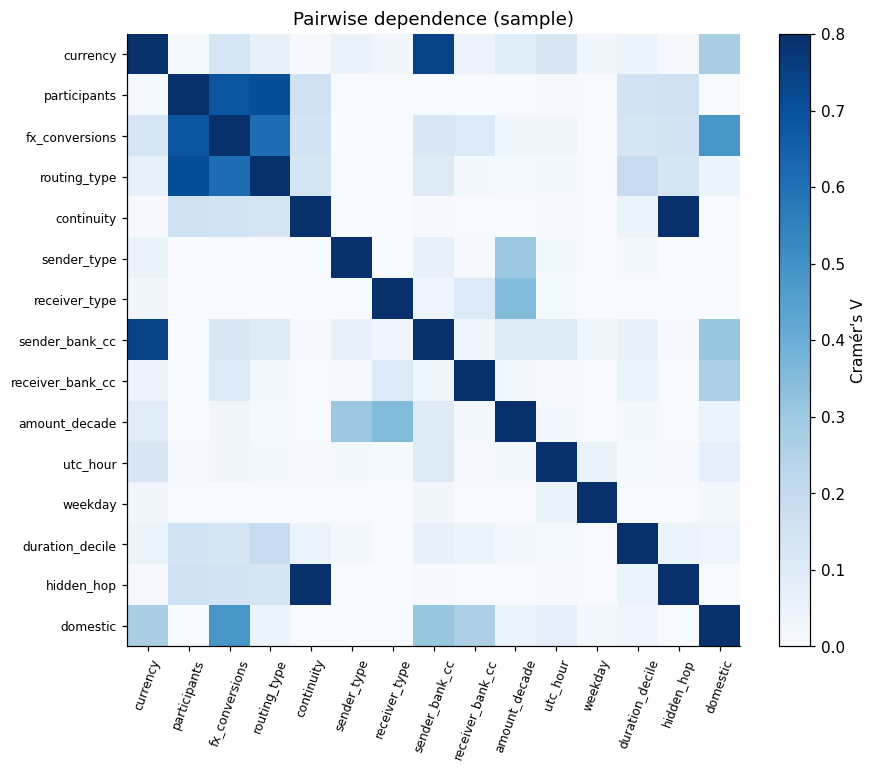

105 pairs, 35 strong (V ≥ 0.05). Strongest:


,field A,field B,Cramér's V
0,continuity,hidden_hop,1.000
1,currency,sender_bank_cc,0.741
2,participants,routing_type,0.707
3,participants,fx_conversions,0.687
4,fx_conversions,routing_type,0.610
5,fx_conversions,domestic,0.482
6,receiver_type,amount_decade,0.352
7,sender_bank_cc,domestic,0.314
8,sender_type,amount_decade,0.305
9,currency,domestic,0.270


In [5]:
def top(x, k):                                   # keep the k most frequent categories, pool the rest
    keep = x.value_counts().index[:k]; return x.where(x.isin(keep), "other")
F = pd.DataFrame({
    "currency": top(s.cur, 12), "participants": s.pc.clip(upper=6), "fx_conversions": s.fx.clip(upper=4),
    "routing_type": s.ttype, "continuity": s.cont, "sender_type": s.otype, "receiver_type": s.btype,
    "sender_bank_cc": top(s.o_bank_cc, 15), "receiver_bank_cc": top(s.b_bank_cc, 15),
    "amount_decade": np.floor(np.log10(s.amt.clip(lower=1))).clip(upper=7), "utc_hour": s.ts.dt.hour,
    "weekday": s.ts.dt.dayofweek, "duration_decile": pd.qcut(s.dur.rank(method="first"), 10, labels=False),
    "hidden_hop": (s.gaps > 0), "domestic": (s.o_bank_cc == s.b_bank_cc)})
def cramers_v(x, y):
    t = pd.crosstab(x, y).values; chi2 = stats.chi2_contingency(t, correction=False)[0]
    return math.sqrt(chi2 / t.sum() / max(1, min(t.shape) - 1))
cols = list(F); M = pd.DataFrame(np.eye(len(cols)), cols, cols)
for i, c1 in enumerate(cols):
    for c2 in cols[i + 1:]:
        M.loc[c1, c2] = M.loc[c2, c1] = cramers_v(F[c1], F[c2])
fig, ax = plt.subplots(figsize=(8.5, 7)); im = ax.imshow(M.values, cmap="Blues", vmin=0, vmax=.8)
ax.set_xticks(range(len(cols)), cols, rotation=70, fontsize=8); ax.set_yticks(range(len(cols)), cols, fontsize=8)
plt.colorbar(im, label="Cramér's V"); ax.set_title("Pairwise dependence (sample)"); ax.grid(False); plt.tight_layout(); plt.show()
pairs = [(c1, c2, M.loc[c1, c2]) for i, c1 in enumerate(cols) for c2 in cols[i + 1:]]
strong = sorted([p for p in pairs if p[2] >= .05], key=lambda p: -p[2])
print(f"{len(pairs)} pairs, {len(strong)} strong (V ≥ 0.05). Strongest:")
pd.DataFrame(strong[:12], columns=["field A", "field B", "Cramér's V"]).round(3)

**Reading:** the strongest dependencies all sit in routing and currency (participants × FX, routing type × participants, currency × bank country). These are the families the next sections explain with exact or near-exact rules.

## 3 · Routing structure (rules R6, R7, R1, R4, R2)

| Rule | Statement | Type |
|---|---|---|
| **R6** | `PARTICIPANT_COUNT` = number of known BICs in `BIC8_PATH` | exact |
| **R7** | `CONTINUITY_QFLAG = 'N'` ⇔ the path contains a `...` placeholder | exact |
| **R1** | intermediaries K = ⌊Exp(1)⌋, so P(K = k) = (1 − 1/e)·e^(−k), a geometric chain with continuation q = 1/e | stochastic |
| **R4** | each link is hidden independently with p = 0.05: P(≥ 1 hidden ∣ pc) = 1 − 0.95^(pc − 1) | stochastic |
| **R2** | Covered vs Indirect is a per-sending-bank habit, flat across route length | stochastic |

R6 share exact                           notebook            1   dashboard          1.0
R7 share exact                           notebook            1   dashboard          1.0
R1 continuation q                        notebook     0.367795   dashboard 0.3677174885865103
R1 share direct (K=0)                    notebook      0.63248   dashboard     0.632328
Cohen's w vs exact 1/e geometric: 0.0028  (< 0.01 = negligible)
R4 per-link hidden p                     notebook     0.050492   dashboard      0.04991
R2 pooled covered share                  notebook     0.113931   dashboard 0.11313398899018691


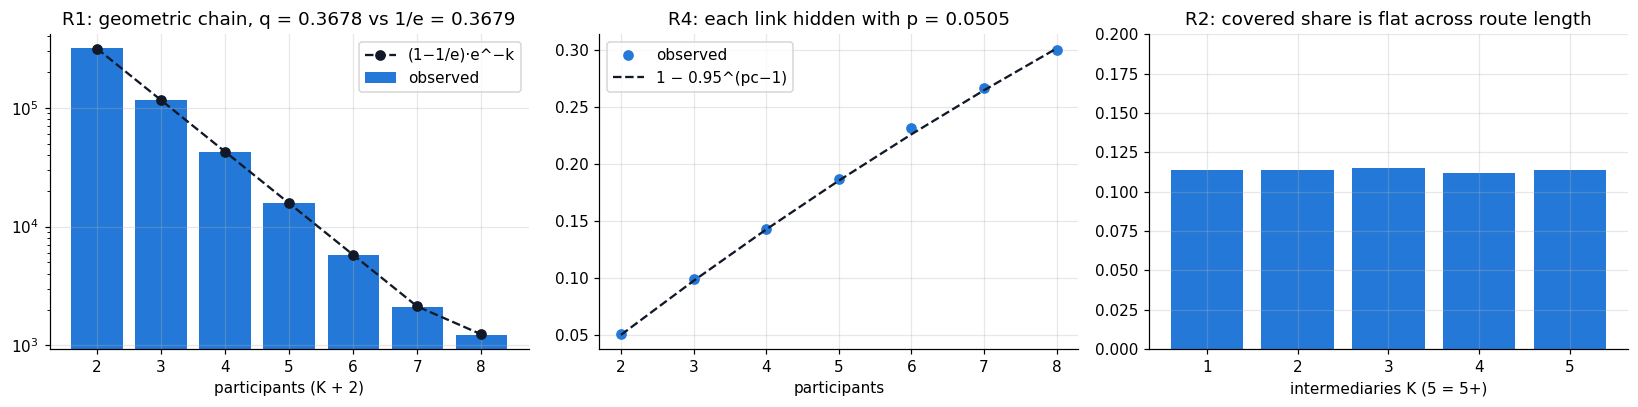

In [6]:
record("R6 share exact", (s.pc == s.kb.str.len()).mean())
record("R7 share exact", ((s.cont == "N") == (s.gaps > 0)).mean())

k = s.pc - 2; kbar = k.mean(); q = kbar / (1 + kbar)            # geometric MLE of the continuation probability
record("R1 continuation q", q); record("R1 share direct (K=0)", (k == 0).mean())
obs = k.clip(upper=6).value_counts().sort_index()
exp_ = pd.Series([(1 - math.exp(-1)) * math.exp(-i) for i in range(6)] + [math.exp(-6)], index=range(7)) * len(k)
w = math.sqrt((((obs - exp_) ** 2) / exp_).sum() / len(k)); print(f"Cohen's w vs exact 1/e geometric: {w:.4f}  (< 0.01 = negligible)")

g = s.groupby("pc").agg(n=("gaps", "size"), hidden=("gaps", lambda x: (x > 0).mean())); g = g[g.n >= 500]
g["model"] = 1 - .95 ** (g.index - 1)
p_link = np.average(1 - (1 - g.hidden) ** (1 / (g.index - 1)), weights=g.n)
record("R4 per-link hidden p", p_link)
nd = s[s.ttype != "Direct"]; record("R2 pooled covered share", (nd.ttype == "Covered").mean())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].bar(obs.index + 2, obs.values, color=BLUE, label="observed"); ax[0].plot(exp_.index + 2, exp_.values, "o--", color=INK, label="(1−1/e)·e^−k")
ax[0].set_yscale("log"); ax[0].set_xlabel("participants (K + 2)"); ax[0].set_title(f"R1: geometric chain, q = {q:.4f} vs 1/e = 0.3679"); ax[0].legend()
ax[1].plot(g.index, g.hidden, "o", color=BLUE, label="observed"); ax[1].plot(g.index, g.model, "--", color=INK, label="1 − 0.95^(pc−1)")
ax[1].set_xlabel("participants"); ax[1].set_title(f"R4: each link hidden with p = {p_link:.4f}"); ax[1].legend()
cov = nd.assign(K=(nd.pc - 2).clip(upper=5)).groupby("K").ttype.apply(lambda x: (x == "Covered").mean())
ax[2].bar(cov.index, cov.values, color=BLUE); ax[2].set_ylim(0, .2); ax[2].set_xlabel("intermediaries K (5 = 5+)")
ax[2].set_title("R2: covered share is flat across route length"); plt.tight_layout(); plt.show()

**Reading:** each extra hop is 1/e as likely as the one before. The hidden-hop share follows 1 − 0.95^(pc−1) at every length, and the covered share does not depend on route length. In the full pipeline R2 is also tested out of sample by bank: banks classed as cover-prone on one half send 61% Covered on the other half, versus 7% for other banks.

*Limitation:* which bank is chosen as correspondent is random in the generator. Real networks depend on bilateral relationships.

## 4 · Currency & FX (rules C1, C2, C3)

We first **infer each country's home currency from the data**: the most common payment currency among payments whose first bank is in that country. That gives:

| Rule | Statement |
|---|---|
| **C1** | the payment currency is usually the instructing (first) bank's home currency |
| **C2** | `CURRENCY_CONVERSION_COUNT` = number of *adjacent* known banks on the route whose home currencies differ (a border rule) |
| **C3** | the currency is drawn from the currencies on the route; outside-route currencies are rare (mostly EUR/USD as vehicles) |

The obvious alternative to C2, "conversions = distinct currencies on the route − 1", is tested and rejected.

In [7]:
home = s.groupby("cc1").cur.agg(lambda x: x.value_counts().index[0])          # inferred home currency per country
HOME = home.to_dict(); print(f"home currency inferred for {len(HOME)} countries, e.g.", {k: HOME[k] for k in list(HOME)[:8]})
def route_ccys(kb): return [HOME.get(b[4:6]) for b in kb]
rc = s.kb.apply(route_ccys)
known = rc.apply(lambda l: None not in l)                                         # every route country has an inferred currency
pred_border = rc.apply(lambda l: sum(x != y for x, y in zip(l, l[1:])))
pred_distinct = rc.apply(lambda l: len(set(l)) - 1)
N1 = s.cc1.value_counts()                                                        # sampled payments per first-bank country
thin = rc.index[s.kb.apply(lambda kb: any(N1.get(b[4:6], 0) < 30 for b in kb))]  # route touches a country seen < 30 times
ok_rows = known & ~s.index.isin(thin)
record("C1 home-currency share", (s.cur == s.cc1.map(HOME)).mean())
record("C2 FX rule exact share", (pred_border[ok_rows] == s.fx[ok_rows]).mean())
print(f"   (on all sampled rows: {(pred_border[known] == s.fx[known]).mean():.6f}; rows touching a country with < 30 sampled "
      f"payments, whose home currency the sample cannot pin down, are set aside: {len(thin):,} rows)")
record("C2 alternative (distinct ccys - 1)", (pred_distinct[known] == s.fx[known]).mean())
record("C3 currency in route", pd.Series([c in set(l) for c, l in zip(s.cur, rc)]).mean())
print(f"rows with every route country mapped: {known.mean():.4%}")
mism = s[known & (pred_border != s.fx)]
thin_cc = sorted({b[4:6] for kb in mism.kb for b in kb if N1.get(b[4:6], 0) < 30})
print(f"C2 mismatches on all sampled rows: {len(mism)}; {mism.index.isin(thin).sum()} of them touch thinly sampled countries {thin_cc} "
      f"(sampled payments: {[int(N1.get(c, 0)) for c in thin_cc]}). Full data: 2 exceptions in 10M, both receivers whose home currency is never observed.")

home currency inferred for 224 countries, e.g. {'AD': 'EUR', 'AE': 'AED', 'AF': 'AFN', 'AG': 'XCD', 'AI': 'XCD', 'AL': 'ALL', 'AM': 'AMD', 'AO': 'AOA'}


C1 home-currency share                   notebook     0.934359   dashboard    0.9341575
C2 FX rule exact share                   notebook            1   dashboard    0.9999998
   (on all sampled rows: 0.999984; rows touching a country with < 30 sampled payments, whose home currency the sample cannot pin down, are set aside: 808 rows)
C2 alternative (distinct ccys - 1)       notebook     0.916726   dashboard    0.9168316


C3 currency in route                     notebook     0.987432   dashboard 0.9872483333333333
rows with every route country mapped: 100.0000%
C2 mismatches on all sampled rows: 8; 8 of them touch thinly sampled countries ['MH'] (sampled payments: [2]). Full data: 2 exceptions in 10M, both receivers whose home currency is never observed.


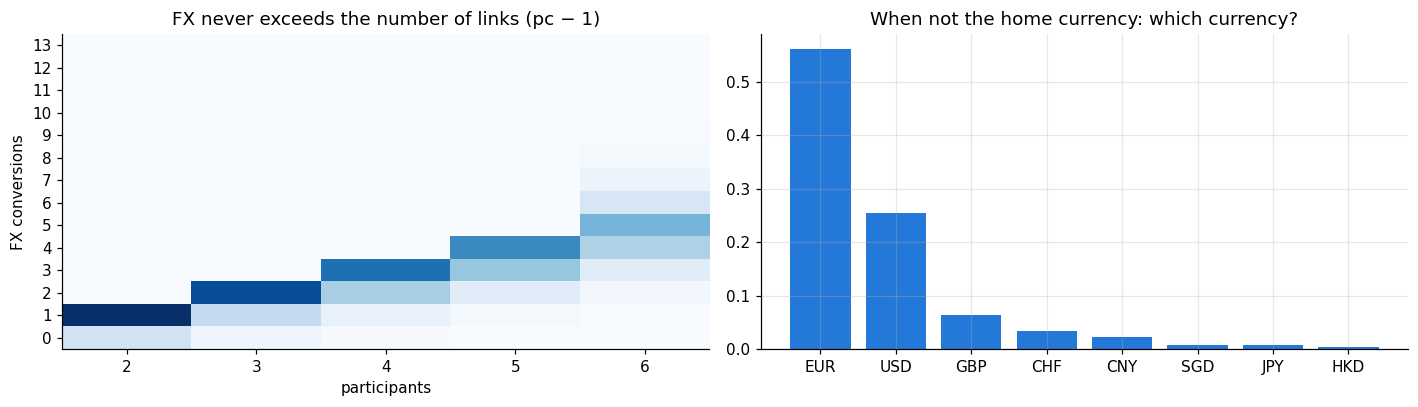

In [8]:
t = pd.crosstab(s.fx, s.pc.clip(upper=6), normalize="columns")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
im = ax[0].imshow(t.values, origin="lower", cmap="Blues", aspect="auto"); ax[0].grid(False)
ax[0].set_xticks(range(t.shape[1]), t.columns); ax[0].set_yticks(range(t.shape[0]), t.index)
ax[0].set_xlabel("participants"); ax[0].set_ylabel("FX conversions"); ax[0].set_title("FX never exceeds the number of links (pc − 1)")
veh = s[s.cur != s.cc1.map(HOME)].cur.value_counts(normalize=True).head(8)
ax[1].bar(veh.index, veh.values, color=BLUE); ax[1].set_title("When not the home currency: which currency?"); plt.tight_layout(); plt.show()

**Reading:** conversions happen only at borders between adjacent banks. The rule matches on every sampled row, while "distinct currencies − 1" matches only about 92%. When the currency is not the sender's home currency, it is mostly a route currency, or EUR/USD as a vehicle.

*Limitation:* home currencies are inferred from the data (modal currency), not given. How the vehicle currency is chosen is not fully identified.

## 5 · Institutions (R5) and parties (P2, P4, P1b)

- **R5:** the route's first bank differs from `ORDERING_BIC8` with p ≈ 0.05, and its last bank differs from `BENEFICIARY_BIC8` with p ≈ 0.05, independently. These mismatches are a role distinction, not errors.
- **P2:** an IBAN-format account always starts with its bank's country code.
- **P4:** the ordering party lives in its bank's country, while the beneficiary's address country is drawn separately (it almost never matches).
- **P1b:** the receiver's customer type does not depend on the sender's.

In [9]:
p_first = (s.kb.str[0] != s.obic).mean(); p_last = (s.kb.str[-1] != s.bbic).mean()
p_both = ((s.kb.str[0] != s.obic) & (s.kb.str[-1] != s.bbic)).mean()
record("R5 first-bank mismatch", p_first); record("R5 last-bank mismatch", p_last); record("R5 independence ratio", p_both / (p_first * p_last))
ib = s[s.o_iban]; record("P2 IBAN prefix = BIC country", (ib.oacc.str[6:8] == ib.obic.str[4:6]).mean())
oc = s[s.o_cust_cc != ""]; bc = s[s.b_cust_cc != ""]
record("P4 ordering address = bank country", (oc.o_cust_cc == oc.o_bank_cc).mean())
record("P4 beneficiary address = bank country", (bc.b_cust_cc == bc.b_bank_cc).mean())
record("P1b P(B|B) - P(B|C)", (s[s.otype == "B"].btype == "B").mean() - (s[s.otype == "C"].btype == "B").mean())
print(f"customer mix: sender business {(s.otype == 'B').mean():.1%}, receiver business {(s.btype == 'B').mean():.1%}")

R5 first-bank mismatch                   notebook    0.0496223   dashboard    0.0498399
R5 last-bank mismatch                    notebook    0.0502588   dashboard    0.0499265
R5 independence ratio                    notebook     0.980765   dashboard 0.9923515957157641
P2 IBAN prefix = BIC country             notebook            1   dashboard          1.0


P4 ordering address = bank country       notebook            1   dashboard          1.0
P4 beneficiary address = bank country    notebook   0.00971482   dashboard 0.009795725090947673
P1b P(B|B) - P(B|C)                      notebook   -0.0015872   dashboard 0.0010928087740883496
customer mix: sender business 78.8%, receiver business 28.7%


**Reading:** the two endpoint swaps are independent (joint ≈ product). Where IBANs are used, the prefix always equals the bank country. The ordering party's address always matches its bank's country, while the beneficiary's matches only about 1% of the time.

*Limitation:* about 39% of details fields carry no country token. Tokens are engineered summaries supplied with the data, not original text.

## 6 · Time (rules T1, T3, T4b)

**T1** says the timestamp follows the *instructing bank's local office clock*: activity starts at 07:00 local time. We **estimate each country's UTC offset from the data**: the hour with the steepest rise in volume is 07:00 local. Then we compare the night share (01–05 h) on the local clock with UTC.

estimated UTC offsets: {'CA': -5, 'PA': -5, 'US': -5, 'GB': 0, 'IM': 0, 'IE': 0, 'DE': 1, 'AT': 1, 'ES': 1, 'FR': 1, 'DK': 1, 'LU': 1, 'IT': 1, 'NL': 1, 'CH': 1, 'BE': 1, 'FI': 2, 'UA': 2, 'QA': 3, 'RU': 3, 'SA': 3, 'AE': 4, 'CN': 8, 'HK': 8, 'SG': 8, 'JP': 9, 'KR': 9, 'AU': 11}


T1 night share, local clock              notebook    0.0460501   dashboard 0.04594193722342745
T1 night share, UTC                      notebook     0.121796   dashboard 0.12369413005912373
weekday shape (Mon..Sun, %): [19.1, 16.9, 17.0, 18.0, 19.1, 3.5, 6.5] | max country deviation 1.4%


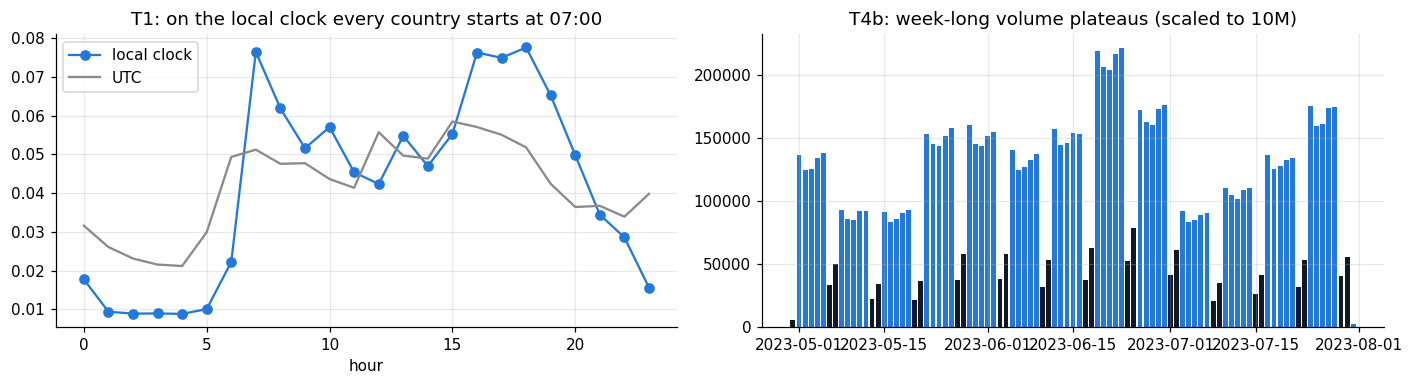

In [10]:
s["utc_hour"] = s.ts.dt.hour
big = s.cc1.value_counts(); big = big[big >= 3000].index
prof = s[s.cc1.isin(big)].groupby(["cc1", "utc_hour"]).size().unstack(fill_value=0)
prof = prof.div(prof.sum(axis=1), axis=0)
rise = prof.values - np.roll(prof.values, 1, axis=1)                       # circular: hour h minus hour h−1
start_utc = pd.Series(rise.argmax(axis=1), index=prof.index)
OFFSET = ((7 - start_utc + 12) % 24 - 12).astype(int)                      # local = UTC + offset, in −12..+11
print("estimated UTC offsets:", OFFSET.sort_values().to_dict())
for f_ in (WORK / "data/metadata/country_offsets.csv", Path("../data/metadata/country_offsets.csv")):   # pipeline table, if already built
    if f_.exists():
        ref_off = pd.read_csv(f_, index_col=0)["offset"]; both = OFFSET.index.intersection(ref_off.index)
        print(f"agreement with the pipeline's offset table (src/metadata.py): {(OFFSET[both] == ref_off[both]).mean():.0%} of {len(both)} countries")
        break
m = s[s.cc1.isin(OFFSET.index)].copy(); m["local_hour"] = (m.utc_hour + m.cc1.map(OFFSET)) % 24
record("T1 night share, local clock", m.local_hour.between(1, 5).mean()); record("T1 night share, UTC", m.utc_hour.between(1, 5).mean())
m["local_dow"] = (m.ts + pd.to_timedelta(m.cc1.map(OFFSET), unit="h")).dt.dayofweek
wk = m.groupby("cc1").local_dow.value_counts(normalize=True).unstack()
print("weekday shape (Mon..Sun, %):", (m.local_dow.value_counts(normalize=True).sort_index() * 100).round(1).tolist(),
      f"| max country deviation {(wk - wk.mean()).abs().max().max():.1%}")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(m.local_hour.value_counts(normalize=True).sort_index(), "-o", color=BLUE, label="local clock")
ax[0].plot(m.utc_hour.value_counts(normalize=True).sort_index(), "-", color=GREY, label="UTC"); ax[0].legend()
ax[0].set_xlabel("hour"); ax[0].set_title("T1: on the local clock every country starts at 07:00")
daily = s.groupby(s.ts.dt.date).size() * 100 / SAMPLE_PCT
ax[1].bar(daily.index, daily.values, color=[INK if d.weekday() >= 5 else BLUE for d in daily.index])
ax[1].set_title("T4b: week-long volume plateaus (scaled to 10M)"); plt.tight_layout(); plt.show()

**Reading:** converted to each sending country's clock, activity starts at 07:00 everywhere and the night share drops sharply. One weekday shape fits all countries (Mon–Fri ≈ 17–19%, weekend low). Weekly volume moves in steps that change on Mondays.

*Limitation:* offsets are whole hours and ignore DST (January values). What sets the weekly levels (T4) is still open, so T4 is rated **inconclusive**.

## 7 · Processing time (D1, D3)

`TOTAL_DURATION` looks like a **sum of per-bank steps**: straight-through (STP) banks take seconds, and manual banks take about 20+ minutes. On two-bank payments the histogram has two humps. Manual steps fit a **Gamma(shape ≈ 2)** distribution (two exponential stages) better than a lognormal.

two-bank payments: median fast part 25 s, median slow part 1469 s, slow share 36.3%
slow part: Gamma shape 1.99, scale 882 s | KS gamma 0.063 vs lognormal 0.065 (illustrative — the dashboard fits only rows with exactly one slow bank, classed on an independent half: shape 2.04, KS 0.023 vs 0.066)


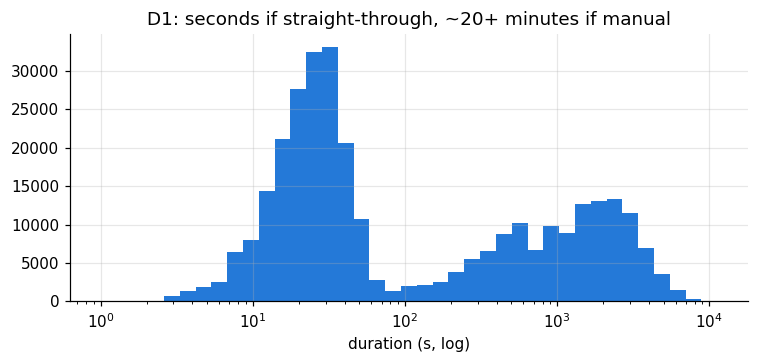

In [11]:
two = s[(s.pc == 2) & (s.anom == "")]
bins = np.logspace(0, np.log10(two.dur.max() + 1), 40)
slow = two.dur[two.dur > 300]
shape, loc_, scale = stats.gamma.fit(slow, floc=0)
ks_g = stats.kstest(slow, "gamma", args=(shape, 0, scale)).statistic
ks_l = stats.kstest(np.log(slow), "norm", args=(np.log(slow).mean(), np.log(slow).std())).statistic
print(f"two-bank payments: median fast part {two.dur[two.dur <= 300].median():.0f} s, median slow part {slow.median():.0f} s, slow share {len(slow) / len(two):.1%}")
print(f"slow part: Gamma shape {shape:.2f}, scale {scale:.0f} s | KS gamma {ks_g:.3f} vs lognormal {ks_l:.3f} (illustrative — the dashboard "
      "fits only rows with exactly one slow bank, classed on an independent half: shape 2.04, KS 0.023 vs 0.066)")
fig, ax = plt.subplots(figsize=(7, 3.4)); ax.hist(two.dur, bins=bins, color=BLUE); ax.set_xscale("log")
ax.set_xlabel("duration (s, log)"); ax.set_title("D1: seconds if straight-through, ~20+ minutes if manual"); plt.tight_layout(); plt.show()

**Reading:** two humps, at seconds and at tens of minutes. In the full pipeline, banks are classed fast or slow on one half and tested on the other: payments where both banks are slow take ≈ 1.89× as long as payments with one slow bank (sum of steps). The hour-of-day effect disappears once bank composition is held fixed (Simpson's paradox).

*Limitation:* exact step distributions are not identified. Durations describe the generator's processing model, not real bank performance.

## 8 · Payment value (A1, A3)

**A1:** ln(amount) = 6 + 2·[sender is business] + 2·[receiver is business] + sending-country level + noise (σ ≈ 2.3). So each business party multiplies the typical amount by e² ≈ 7.4.
**A3:** the residual within a country is **Normal**, which means amounts are lognormal with no power-law tail.

A1 intercept                             notebook      6.07229   dashboard 6.0623551008389285
A1 sender-business effect                notebook       1.9175   dashboard 1.9318101049313237
A1 receiver-business effect              notebook      1.95493   dashboard 1.9648820732967067
A1 interaction                           notebook    0.0558502   dashboard 0.038869131592845996
A3 residual skew                         notebook   -0.0100381   dashboard -0.023951931630857536
A3 residual excess kurtosis              notebook    0.0199289   dashboard 0.006826938001923022


KS distance of the standardised residual vs Normal: 0.0039


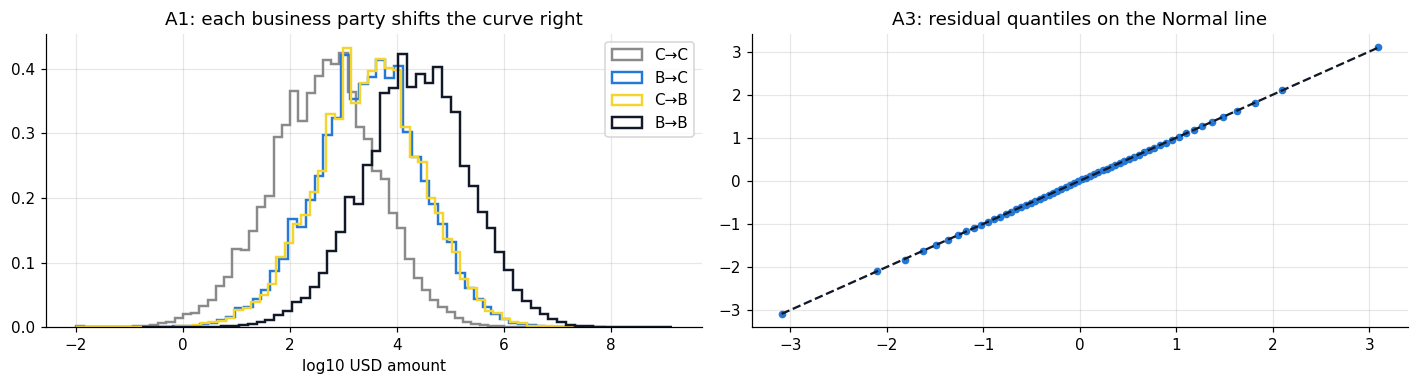

In [12]:
n = s[s.anom == ""]; y = np.log(n.amt); oB = (n.otype == "B").astype(float); bB = (n.btype == "B").astype(float)
X = np.column_stack([np.ones(len(n)), oB, bB, oB * bB]); beta = np.linalg.lstsq(X, y, rcond=None)[0]
for name, b in zip(["A1 intercept", "A1 sender-business effect", "A1 receiver-business effect", "A1 interaction"], beta): record(name, b)
resid = y - y.groupby([n.o_bank_cc, n.otype, n.btype]).transform("mean")          # remove party types and sending country
z = (resid - resid.mean()) / resid.std()
record("A3 residual skew", stats.skew(resid)); record("A3 residual excess kurtosis", stats.kurtosis(resid))
print(f"KS distance of the standardised residual vs Normal: {stats.kstest(z, 'norm').statistic:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for (o, b), c in zip([("C", "C"), ("B", "C"), ("C", "B"), ("B", "B")], [GREY, BLUE, YELLOW, INK]):
    ax[0].hist(np.log10(n.amt[(n.otype == o) & (n.btype == b)]), bins=60, histtype="step", lw=1.6, color=c, density=True, label=f"{o}→{b}")
ax[0].legend(); ax[0].set_xlabel("log10 USD amount"); ax[0].set_title("A1: each business party shifts the curve right")
qq = np.quantile(z, np.linspace(.001, .999, 60)); th = stats.norm.ppf(np.linspace(.001, .999, 60))
ax[1].plot(th, qq, "o", color=BLUE, ms=4); ax[1].plot(th, th, "--", color=INK); ax[1].set_title("A3: residual quantiles on the Normal line")
plt.tight_layout(); plt.show()

**Reading:** the four sender → receiver curves are the same lognormal shifted by about +2 in ln units for each business party, with almost no interaction. The residual lies on the Normal line, so a lognormal model predicts even the largest amounts.

*Limitation:* country and bank effects are generator parameters, not national statistics. Fat-finger rows are excluded from the fit.

## 9 · Statistical forensics (F1 and uniformity fingerprints)

How the generator was built leaves marks in the digits:
- **F1:** USD-denominated amounts are often whole (.00), while amounts originally in other currencies have uniform cents. So the generator draws a round amount in the original currency and converts it to USD.
- Timestamps (second of minute) are uniform, which points to continuous time draws.
- Leading digits are close to **Benford's law**, as wide lognormal amounts should be.

F1 USD amounts ending .00                notebook     0.384885   dashboard 0.38636247465539864
F1 other amounts ending .00              notebook    0.0100816   dashboard 0.009884989123689611
second-of-minute Cohen's w 0.0122 — sampling noise alone gives ≈ 0.0109 at this n, so: uniform
Benford MAD 0.0061 (dashboard 0.0060 on 10M; Nigrini: < 0.006 close, 0.006–0.012 acceptable conformity)


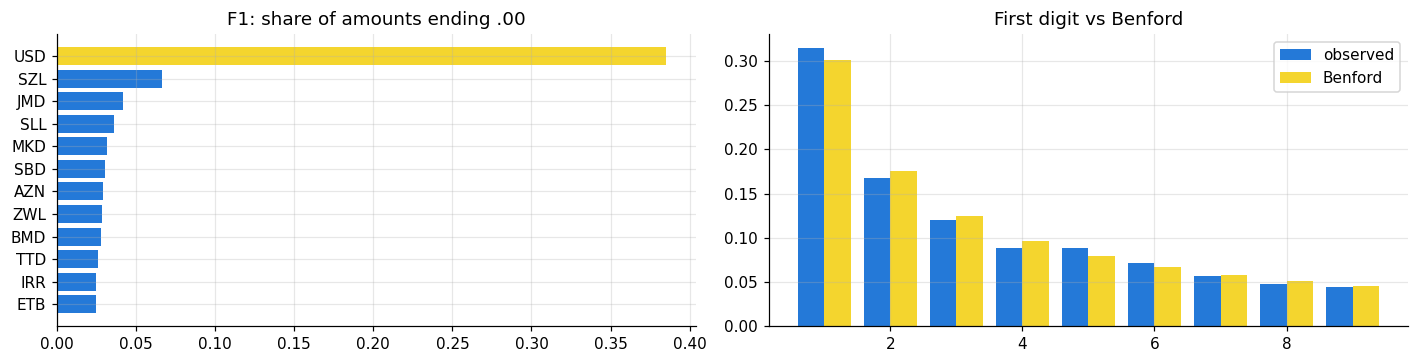

In [13]:
whole = (np.round(s.amt * 100) % 100 == 0)
record("F1 USD amounts ending .00", whole[s.cur == "USD"].mean()); record("F1 other amounts ending .00", whole[s.cur != "USD"].mean())
sec = s.epoch % 60; c = np.bincount(sec, minlength=60); w_sec = math.sqrt(((c - c.mean()) ** 2 / c.mean()).sum() / c.sum())
fd = (s.amt / 10 ** np.floor(np.log10(s.amt.clip(lower=1e-9)))).astype(int).clip(1, 9)
obs_fd = fd.value_counts(normalize=True).sort_index(); ben = np.log10(1 + 1 / np.arange(1, 10))
print(f"second-of-minute Cohen's w {w_sec:.4f} — sampling noise alone gives ≈ {math.sqrt(59 / c.sum()):.4f} at this n, so: uniform")
print(f"Benford MAD {np.abs(obs_fd.values - ben).mean():.4f} (dashboard 0.0060 on 10M; Nigrini: < 0.006 close, 0.006–0.012 acceptable conformity)")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
cw = s.assign(w=whole).groupby("cur").w.mean().sort_values(ascending=False).head(12)
ax[0].barh(cw.index[::-1], cw.values[::-1], color=[YELLOW if x == "USD" else BLUE for x in cw.index[::-1]]); ax[0].set_title("F1: share of amounts ending .00")
ax[1].bar(np.arange(1, 10) - .2, obs_fd.values, .4, color=BLUE, label="observed"); ax[1].bar(np.arange(1, 10) + .2, ben, .4, color=YELLOW, label="Benford")
ax[1].legend(); ax[1].set_title("First digit vs Benford"); plt.tight_layout(); plt.show()

**Negative result kept:** in the full pipeline we searched for one fixed FX rate per currency that would make converted amounts round. None does (about 2% near-integer at best, against a 1.2% baseline), so no fixed conversion table is claimed.

## 10 · Anomalies (X1, X2, X3, X6), using every labelled row

| Label | What we find |
|---|---|
| **ROMANCE_SCAM (X1)** | bursts of 2–8 payments from a consumer to the same payee; each payment is ×1.5 the previous one (ln step +0.40) |
| **DUPLICATE_PAYMENT (X2)** | groups of 2–5 identical copies (same amount, path, duration) within 2 h, every copy labelled |
| **FAT_FINGER_MISTAKE (X3)** | the amount is ×100 or ÷100 of what the party types and country predict; about 77% are inflated |
| **X6** | labels are injected *after* routing: the label is independent of routing type |
| **CUSTOMER_RECALL (X5)** | no observable signature, a documented **negative** result (rated inconclusive) |

anom
ROMANCE_SCAM                2476
FAT_FINGER_MISTAKE          1940
CEO_SCAM                     945
DUPLICATE_PAYMENT            679
ACCOUNT_REPLACEMENT_SCAM     649
CUSTOMER_RECALL              317
X1 romance series                        notebook          500   dashboard          500
X1 median ln step                        notebook     0.405465   dashboard 0.40012710559635634
X2 duplicate groups                      notebook          185   dashboard          185
duplicate group sizes 2–5, max span 7,043 s
X3 share inflated (x100)                 notebook     0.773711   dashboard 0.772680412371134


X6 Cramer's V label x routing            notebook   0.00320881   dashboard 0.0031957585044039686


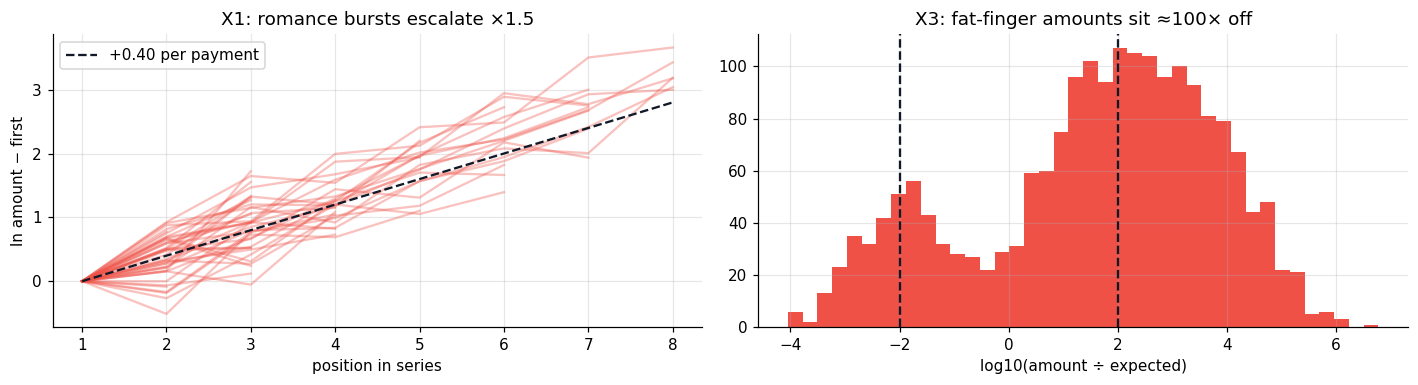

In [14]:
print(a.anom.value_counts().to_string())
r = a[a.anom == "ROMANCE_SCAM"].sort_values("epoch"); r["series"] = r.groupby(["oacc", "bacc"]).ngroup()
steps = r.groupby("series").amt.apply(lambda x: np.diff(np.log(x.values))).explode().astype(float)
record("X1 romance series", r.series.nunique()); record("X1 median ln step", steps.median())
d = a[a.anom == "DUPLICATE_PAYMENT"]; grp = d.groupby(["amt", "path", "dur"]).epoch.agg(["size", lambda x: x.max() - x.min()])
grp.columns = ["copies", "span_s"]; record("X2 duplicate groups", len(grp))
print(f"duplicate group sizes {grp.copies.min()}–{grp.copies.max()}, max span {grp.span_s.max():,} s")
mu = np.log(n.amt).groupby([n.o_bank_cc, n.otype, n.btype]).mean()           # expected ln amount from the A1/A2 model
ff = a[a.anom == "FAT_FINGER_MISTAKE"].copy()
ff["exp_ln"] = [mu.get((c, o, b), np.nan) for c, o, b in zip(ff.o_bank_cc, ff.otype, ff.btype)]
ff["log10_ratio"] = (np.log(ff.amt) - ff.exp_ln) / np.log(10); ff = ff.dropna(subset=["log10_ratio"])
record("X3 share inflated (x100)", (ff.log10_ratio > 0).mean())
# normal rows are a SAMPLE_PCT sample but anomalies are complete: scale normal counts back to full size before computing V
ct = pd.concat([pd.crosstab(a.anom, a.ttype), (s[s.anom == ""].ttype.value_counts() * 100 / SAMPLE_PCT).rename("NORMAL").to_frame().T]).fillna(0)
chi2_ = stats.chi2_contingency(ct.values, correction=False)[0]
record("X6 Cramer's V label x routing", math.sqrt(chi2_ / ct.values.sum() / (min(ct.shape) - 1)))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for i, (_, g_) in enumerate(r.groupby("series")):
    if i < 40: ax[0].plot(range(1, len(g_) + 1), np.log(g_.amt.values) - np.log(g_.amt.values[0]), color=RED, alpha=.35)
ax[0].plot([1, 8], [0, 7 * .4], "--", color=INK, label="+0.40 per payment"); ax[0].legend(); ax[0].set_title("X1: romance bursts escalate ×1.5")
ax[0].set_xlabel("position in series"); ax[0].set_ylabel("ln amount − first")
ax[1].hist(ff.log10_ratio, bins=40, color=RED); ax[1].axvline(2, color=INK, ls="--"); ax[1].axvline(-2, color=INK, ls="--")
ax[1].set_xlabel("log10(amount ÷ expected)"); ax[1].set_title("X3: fat-finger amounts sit ≈100× off"); plt.tight_layout(); plt.show()

**Reading:** each fraud label leaves its own signature: escalating bursts, identical copies, and ×100 decimal slips. The labels are independent of routing (V ≈ 0.003), which is consistent with injection after the route was built. In the full data, CEO and account-replacement scams pay into accounts that receive nothing but flagged payments (mule accounts). Testing that needs every row, so it is not repeated here.

*Limitation:* labels are synthetic; they are not confirmed real-world fraud, and their prevalence is not real prevalence.

## 11 · Notebook vs dashboard

Each number above is compared with the dashboard's full-data value.
- **Exact rules** must match exactly.
- **Rates** must agree within sampling error (about ±0.005 at 5%).
- **Anomaly counts** use every labelled row, so they must match exactly.

In [15]:
rows = []
for k_, ref in REF.items():
    if k_ in RESULTS:
        tol = TOL.get(k_, DEFAULT_TOL); v = RESULTS[k_]
        rows.append((k_, v, ref, v - ref, tol, "match" if abs(v - ref) <= tol + 1e-12 else "CHECK"))
cmp_ = pd.DataFrame(rows, columns=["metric", "notebook (sample)", "dashboard (10M)", "difference", "tolerance", "status"])
print(f"{(cmp_.status == 'match').sum()} of {len(cmp_)} metrics agree with the dashboard within tolerance")
cmp_.style.format({"notebook (sample)": "{:.4f}", "dashboard (10M)": "{:.4f}", "difference": "{:+.4f}", "tolerance": "{:.3f}"}) \
    .apply(lambda r_: ["background:#fde2e1" if r_.status == "CHECK" else "" for _ in r_], axis=1)

32 of 32 metrics agree with the dashboard within tolerance


,metric,notebook (sample),dashboard (10M),difference,tolerance,status
0,R6 share exact,1.0000,1.0000,+0.0000,0.000,match
1,R7 share exact,1.0000,1.0000,+0.0000,0.000,match
2,R1 continuation q,0.3678,0.3677,+0.0001,0.005,match
3,R1 share direct (K=0),0.6325,0.6323,+0.0002,0.005,match
4,R4 per-link hidden p,0.0505,0.0499,+0.0006,0.005,match
5,R2 pooled covered share,0.1139,0.1131,+0.0008,0.005,match
6,R5 first-bank mismatch,0.0496,0.0498,-0.0002,0.005,match
7,R5 last-bank mismatch,0.0503,0.0499,+0.0003,0.005,match
8,R5 independence ratio,0.9808,0.9924,-0.0116,0.100,match
9,C1 home-currency share,0.9344,0.9342,+0.0002,0.005,match


# Part B: the complete production pipeline

Part B contains **every source file** of the ORVANTA project. Each `%%writefile` cell below writes one file into the working folder `WORK`. Section 13 then runs the whole pipeline on all 10M rows, the same way `python run_all.py` does in the repository.

| Stage | Modules | Output |
|---|---|---|
| 1–2 Ingestion | `ingestion`, `metadata` | `payments.parquet`, `slim.parquet`, country tables |
| 3 Discovery | `discovery`, `graph`, `stats`, `forensics`, `h38` | dependency scan, network, statistics, fingerprints |
| 4 Validation | `rules`, `rulelib`, `formulations`, `validation` | 34 rules × 5 splits → `validation.json` |
| 5 Evidence | `evidence`, `cube`, `register`, `atlas`, `lineage` | evidence, register, atlas, lineage |
| 6 Charts and data | `charts`, `webdata`, `replay`, `ledger` | 48 charts, web data, replay, evidence ledger |
| 7 Deliverables | `dashboard_v2`, `reporting`, `research_report`, `web` | dashboard PDF, presentation PDF, research report, website |

In [16]:
for d in ["src", "findings", "docs", "web/app", "data/processed", "data/metadata", "outputs/evidence", "submission"]:
    (WORK / d).mkdir(parents=True, exist_ok=True)
for f in sorted({str(Path(x).parent) for x in ["docs/source_register.md", "findings/economic_interpretation.md", "findings/hypotheses.md", "findings/limitations.md", "requirements.txt", "run_all.py", "src/__init__.py", "src/atlas.py", "src/charts.py", "src/config.py", "src/cube.py", "src/dashboard_v2.py", "src/discovery.py", "src/evidence.py", "src/forensics.py", "src/formulations.py", "src/graph.py", "src/h38.py", "src/ingestion.py", "src/ledger.py", "src/levels.py", "src/lineage.py", "src/metadata.py", "src/register.py", "src/replay.py", "src/reporting.py", "src/research_report.py", "src/rulelib.py", "src/rules.py", "src/stats.py", "src/validation.py", "src/web.py", "src/webdata.py", "web/app/app.css", "web/app/index.html", "web/app/js/core.js", "web/app/js/cube.js", "web/app/js/main.js", "web/app/js/pages/anomalies.js", "web/app/js/pages/atlas.js", "web/app/js/pages/command.js", "web/app/js/pages/data.js", "web/app/js/pages/deliverables.js", "web/app/js/pages/explorer.js", "web/app/js/pages/features.js", "web/app/js/pages/forensics.js", "web/app/js/pages/foundry.js", "web/app/js/pages/genome.js", "web/app/js/pages/library.js", "web/app/js/pages/method.js", "web/app/js/pages/overview.js", "web/app/js/pages/playground.js", "web/app/js/pages/replay.js", "web/app/js/pages/routes.js", "web/app/js/pages/rules.js", "web/app/js/pages/sensitivity.js", "web/app/js/pages/simulator.js", "web/app/js/pages/tour.js", "web/app/js/pages/validation.js", "web/app/js/rulelib.js", "web/app/js/sim.js"]}):
    (WORK / f).mkdir(parents=True, exist_ok=True)
print("working folder ready:", WORK.name, "| files to write:", len(["docs/source_register.md", "findings/economic_interpretation.md", "findings/hypotheses.md", "findings/limitations.md", "requirements.txt", "run_all.py", "src/__init__.py", "src/atlas.py", "src/charts.py", "src/config.py", "src/cube.py", "src/dashboard_v2.py", "src/discovery.py", "src/evidence.py", "src/forensics.py", "src/formulations.py", "src/graph.py", "src/h38.py", "src/ingestion.py", "src/ledger.py", "src/levels.py", "src/lineage.py", "src/metadata.py", "src/register.py", "src/replay.py", "src/reporting.py", "src/research_report.py", "src/rulelib.py", "src/rules.py", "src/stats.py", "src/validation.py", "src/web.py", "src/webdata.py", "web/app/app.css", "web/app/index.html", "web/app/js/core.js", "web/app/js/cube.js", "web/app/js/main.js", "web/app/js/pages/anomalies.js", "web/app/js/pages/atlas.js", "web/app/js/pages/command.js", "web/app/js/pages/data.js", "web/app/js/pages/deliverables.js", "web/app/js/pages/explorer.js", "web/app/js/pages/features.js", "web/app/js/pages/forensics.js", "web/app/js/pages/foundry.js", "web/app/js/pages/genome.js", "web/app/js/pages/library.js", "web/app/js/pages/method.js", "web/app/js/pages/overview.js", "web/app/js/pages/playground.js", "web/app/js/pages/replay.js", "web/app/js/pages/routes.js", "web/app/js/pages/rules.js", "web/app/js/pages/sensitivity.js", "web/app/js/pages/simulator.js", "web/app/js/pages/tour.js", "web/app/js/pages/validation.js", "web/app/js/rulelib.js", "web/app/js/sim.js"]))

working folder ready: orvanta | files to write: 61


## 12.1 · Configuration, confidence scale and the one-command runner

Paths, DuckDB connection with the split keys (`h` = random half, `per` = before/after 15 Jun 2023), resource limits (set from section 0) and the fixed confidence scale.

In [ ]:
%%writefile {WORK.as_posix()}/src/__init__.py



In [ ]:
%%writefile {WORK.as_posix()}/src/config.py
"""Central configuration: paths, DuckDB connection, split definitions.

The raw CSV is never modified. Every derived artefact lives under data/processed or outputs/.
"""
from __future__ import annotations
import os
from pathlib import Path
import duckdb

ROOT = Path(__file__).resolve().parents[1]
RAW_CSV = Path(os.environ.get("SWIFT_RAW_CSV", ROOT / "swift_umdac_datathon_2026_fictitious_payment_data.csv"))
PROCESSED = ROOT / "data" / "processed"
METADATA = ROOT / "data" / "metadata"
FULL_PQ = PROCESSED / "payments.parquet"      # all 20 analytic columns, text included (DISCLAIMER dropped)
SLIM_PQ = PROCESSED / "slim.parquet"          # typed + derived columns, no free text
OUT = ROOT / "outputs"
EVIDENCE = OUT / "evidence"
TABLES = OUT / "tables"
CHARTS = OUT / "charts"
FINDINGS = ROOT / "findings"
EXPECTED_ROWS = 10_000_000
SPLIT_DATE = "2023-06-15"   # temporal holdout boundary (roughly half of the 93-day window)

for p in (PROCESSED, METADATA, EVIDENCE, TABLES, CHARTS, FINDINGS):
    p.mkdir(parents=True, exist_ok=True)


def _p(path: Path) -> str:
    return str(path).replace("\\", "/")


# Resource limits: defaults suit the 10-thread development PC; override on smaller machines (Colab: ORVANTA_THREADS=2, ORVANTA_MEMORY=6GB)
THREADS = int(os.environ.get("ORVANTA_THREADS", 10))
MEMORY = os.environ.get("ORVANTA_MEMORY", "9GB")
TEMP_DIR = os.environ.get("ORVANTA_TEMP", "")          # DuckDB spill directory (empty = DuckDB default)


def duck(memory: str | None = None, preserve_order: bool = False) -> duckdb.DuckDBPyConnection:
    """Plain DuckDB connection with the configured limits (used by the ingestion stage)."""
    con = duckdb.connect()
    con.execute(f"SET threads={THREADS}; SET memory_limit='{memory or MEMORY}'; SET preserve_insertion_order={str(preserve_order).lower()}; SET enable_progress_bar=false")
    if TEMP_DIR:
        con.execute(f"SET temp_directory='{TEMP_DIR}'")
    return con


def find_browser() -> tuple[str, list[str]] | None:
    """Headless Chromium-family browser for HTML -> PDF: Edge/Chrome on Windows, google-chrome/chromium on Linux (e.g. Colab)."""
    import shutil, sys
    cands = [r"C:\Program Files (x86)\Microsoft\Edge\Application\msedge.exe", r"C:\Program Files\Google\Chrome\Application\chrome.exe"]
    cands += [shutil.which(n) or "" for n in ("msedge", "chrome", "google-chrome", "google-chrome-stable", "chromium", "chromium-browser")]
    exe = next((p for p in cands if p and Path(p).exists()), None)
    if not exe:
        return None
    extra = []
    if sys.platform != "win32":
        extra.append("--disable-dev-shm-usage")          # containers (Colab) have a tiny /dev/shm; Chrome crashes without this
        if hasattr(os, "geteuid") and os.geteuid() == 0:
            extra.append("--no-sandbox")                 # Colab runs as root
    return exe, extra


def connect(threads: int | None = None, memory: str | None = None, slim: Path | None = None) -> duckdb.DuckDBPyConnection:
    """DuckDB connection with view `t` (slim table) and `tt` (t + split keys).

    Split keys
      h   : pseudo-random half, hash(rid) % 2  -> independent-subset validation
      per : 'P1' before SPLIT_DATE, 'P2' after -> temporal validation
    """
    con = duckdb.connect()
    con.execute(f"SET threads={threads or THREADS}; SET memory_limit='{memory or MEMORY}'; SET preserve_insertion_order=false; SET enable_progress_bar=false")
    if TEMP_DIR:
        con.execute(f"SET temp_directory='{TEMP_DIR}'")
    src = _p(slim or SLIM_PQ)
    con.execute(f"CREATE OR REPLACE VIEW t AS SELECT * FROM read_parquet('{src}')")
    con.execute(f"""CREATE OR REPLACE VIEW tt AS SELECT *, (hash(rid) % 2)::INT AS h,
                    CASE WHEN d < DATE '{SPLIT_DATE}' THEN 'P1' ELSE 'P2' END AS per FROM t""")
    if (METADATA / "cc_currency_map.csv").exists():
        con.execute(f"CREATE OR REPLACE TABLE ccy AS SELECT cc, cur AS hcur FROM read_csv('{_p(METADATA / 'cc_currency_map.csv')}')")
    if (METADATA / "country_offsets.csv").exists():
        con.execute(f"CREATE OR REPLACE TABLE off AS SELECT column0 AS cc, \"offset\" AS o FROM read_csv('{_p(METADATA / 'country_offsets.csv')}')")
    return con


# GROUPING SETS clause producing one row per split: full, h=0, h=1, P1, P2
SPLITS = "GROUPING SETS ((), (h), (per))"
SPLIT_LABEL = "CASE WHEN h IS NOT NULL THEN 'half_' || h WHEN per IS NOT NULL THEN per ELSE 'full' END"


In [ ]:
%%writefile {WORK.as_posix()}/src/levels.py
"""Six-level confidence scale shared by the PDFs (src.reporting) and the web platform (src.webdata).

Criteria are fixed in advance; a rule moves up only by passing a stronger test. The register's older High/Medium/Low label
is the input for rules that are neither in VALIDATED nor INCONCLUSIVE.
"""
from __future__ import annotations

ORDER = ["VALIDATED", "STRONGLY SUPPORTED", "SUPPORTED", "CANDIDATE", "INCONCLUSIVE", "REJECTED"]
CRITERIA = {
    "VALIDATED": "Deterministic rule reproducing its field exactly (≥ 99.999% of rows) on every split, or a parameter whose 95% CI contains the theoretical value and which passes on all 5 splits with an independent second implementation / out-of-sample test.",
    "STRONGLY SUPPORTED": "Validator passes on all 5 splits with a wide margin; mechanism specified explicitly; best alternative tested and rejected.",
    "SUPPORTED": "Validator passes, but part of the mechanism is inferred, thresholds are analyst-chosen, or the rule rests on one evidence line.",
    "CANDIDATE": "Pattern detected and replicated, mechanism not yet formulated as a testable rule.",
    "INCONCLUSIVE": "Dependence or effect established but the generating mechanism is not identified, or the result is a documented negative (no signature found).",
    "REJECTED": "Hypothesis tested and contradicted by the data (kept for transparency).",
}
VALIDATED = {"R6", "R7", "C2", "P2", "X2", "R1", "R4", "G3"}
INCONCLUSIVE = {"G1", "X5", "T4"}


def level(rule_id: str, confidence: str) -> str:
    if rule_id in VALIDATED:
        return "VALIDATED"
    if rule_id in INCONCLUSIVE:
        return "INCONCLUSIVE"
    return "STRONGLY SUPPORTED" if confidence == "High" else "SUPPORTED"


In [ ]:
%%writefile {WORK.as_posix()}/run_all.py
"""One-command pipeline. Usage: python run_all.py [--skip-ingest]"""
import os, subprocess, sys, time

os.environ.setdefault("PYTHONIOENCODING", "utf-8")
steps = ([] if "--skip-ingest" in sys.argv else ["src.ingestion", "src.metadata"]) + ["src.graph", "src.stats", "src.discovery", "src.forensics", "src.h38", "src.validation", "src.evidence", "src.cube", "src.register", "src.atlas", "src.lineage", "src.charts", "src.webdata", "src.replay", "src.ledger", "src.reporting", "src.research_report", "src.web"]  # reporting reads ledger + replay, so it runs after them
for s in steps:
    t = time.time(); print(f"==> {s}", flush=True)
    subprocess.run([sys.executable, "-m", s], check=True)
    print(f"    done in {time.time()-t:.0f}s", flush=True)
subprocess.run([sys.executable, "-m", "pytest", "-q", "tests"], check=True)


In [ ]:
%%writefile {WORK.as_posix()}/requirements.txt
duckdb==1.5.2
pandas==3.1.0
numpy
scipy==1.17.1
scikit-learn==1.8.0
matplotlib==3.10.9
streamlit==1.57.0
altair==6.1.0
pyarrow==24.0.0
pypdf==6.19.0
pytest==9.1.1
pillow
playwright>=1.55   # optional: browser end-to-end tests (uses the system Microsoft Edge)


## 12.2 · Stage 1–2: ingestion and derived country tables

Raw CSV → `payments.parquet` (all text kept) → `slim.parquet` (typed and derived columns). `metadata.py` derives the home currency per country, the UTC offsets (rule T1) and the country amount effects (rule A2) from the data.

In [ ]:
%%writefile {WORK.as_posix()}/src/ingestion.py
"""Stage 1-2: raw CSV -> payments.parquet -> slim.parquet (typed + derived features).

Run:  python -m src.ingestion [--skip-full]
Design choices
  * DuckDB read_csv with quote/escape '"' parses the multi-line quoted address fields (RFC 4180);
    a naive newline count would overstate rows. Row count is asserted after every stage.
  * all_varchar=True keeps identifiers (leading zeros, IBANs) exactly as received.
  * DISCLAIMER is non-empty on exactly one row (the legal notice) and is dropped from analytic tables.
"""
from __future__ import annotations
import sys, time
from .config import RAW_CSV, FULL_PQ, SLIM_PQ, EXPECTED_ROWS, connect, duck, _p
import duckdb


def csv_to_parquet() -> int:
    con = duck(preserve_order=True)   # keep CSV row order: rid = CSV row number
    n_disc = con.execute(f"""SELECT count(*) FILTER (WHERE DISCLAIMER IS NOT NULL AND DISCLAIMER<>''), count(*)
        FROM read_csv('{_p(RAW_CSV)}', header=true, quote='"', escape='"', all_varchar=true, max_line_size=10000000, parallel=false)""").fetchone()
    assert n_disc[1] == EXPECTED_ROWS, f"raw row count {n_disc[1]} != {EXPECTED_ROWS}"
    print(f"raw rows={n_disc[1]:,}  rows with DISCLAIMER text={n_disc[0]}")
    con.execute(f"""COPY (SELECT * EXCLUDE (DISCLAIMER) FROM read_csv('{_p(RAW_CSV)}', header=true, quote='"', escape='"',
        all_varchar=true, max_line_size=10000000, parallel=false)) TO '{_p(FULL_PQ)}' (FORMAT parquet, COMPRESSION zstd, ROW_GROUP_SIZE 500000)""")
    n = con.execute(f"SELECT count(*) FROM '{_p(FULL_PQ)}'").fetchone()[0]
    assert n == EXPECTED_ROWS
    return n


SLIM_SQL = """
SELECT row_number() OVER () AS rid,
  EPOCH_SECONDS::BIGINT AS epoch,
  to_timestamp(EPOCH_SECONDS::BIGINT) AT TIME ZONE 'UTC' AS ts,
  CAST(to_timestamp(EPOCH_SECONDS::BIGINT) AT TIME ZONE 'UTC' AS DATE) AS d,
  hour(to_timestamp(EPOCH_SECONDS::BIGINT) AT TIME ZONE 'UTC') AS hr,
  dayofweek(to_timestamp(EPOCH_SECONDS::BIGINT) AT TIME ZONE 'UTC') AS dow,
  CURRENCY_CODE AS cur, USD_AMOUNT::DOUBLE AS amt, TOTAL_DURATION::INT AS dur,
  CURRENCY_CONVERSION_COUNT::INT AS fx, PARTICIPANT_COUNT::INT AS pc,
  ORDERING_BIC8 AS obic, BENEFICIARY_BIC8 AS bbic, BIC8_PATH AS path, CONTINUITY_QFLAG AS cont,
  TRANSACTION_TYPE_CODE AS ttype, ORDERING_ACCOUNT AS oacc, BENEFICIARY_ACCOUNT AS bacc,
  ORDERING_TYPE AS otype, BENEFICIARY_TYPE AS btype, ANOMALY_TYPE AS anom,
  substr(ORDERING_BIC8,5,2) AS o_bank_cc, substr(BENEFICIARY_BIC8,5,2) AS b_bank_cc,
  regexp_extract(ORDERING_TOKENS,  '.*<country_code:([A-Z]{{2}})>', 1) AS o_cust_cc,
  regexp_extract(BENEFICIARY_TOKENS,'.*<country_code:([A-Z]{{2}})>', 1) AS b_cust_cc,
  substr(CURRENCY_CODE,1,2) AS cur_cc,
  len(string_split(BIC8_PATH,';')) AS path_n,
  len(string_split(BIC8_PATH,';')) - len(list_filter(string_split(BIC8_PATH,';'), x -> x <> '...')) AS gaps,
  ORDERING_TOKENS LIKE '%<iban:%' AS o_iban, BENEFICIARY_TOKENS LIKE '%<iban:%' AS b_iban,
  ORDERING_DETAILS LIKE '%' || chr(10) || '1/%' AS o_struct, BENEFICIARY_DETAILS LIKE '%' || chr(10) || '1/%' AS b_struct
FROM read_parquet('{src}')
"""


def build_slim() -> int:
    con = duck(preserve_order=True)   # row_number() OVER () must follow file order so rid (and the hash-half splits) is deterministic
    con.execute(f"COPY ({SLIM_SQL.format(src=_p(FULL_PQ))}) TO '{_p(SLIM_PQ)}' (FORMAT parquet, COMPRESSION zstd)")
    n = con.execute(f"SELECT count(*) FROM '{_p(SLIM_PQ)}'").fetchone()[0]
    assert n == EXPECTED_ROWS
    return n


if __name__ == "__main__":
    t = time.time()
    if "--skip-full" not in sys.argv:
        print("parquet rows:", csv_to_parquet())
    print("slim rows:", build_slim(), f"({time.time()-t:.0f}s)")


In [ ]:
%%writefile {WORK.as_posix()}/src/metadata.py
"""Stage 2b: derive the three country lookup tables the validators use, directly from the data.

Run:  python -m src.metadata            (after src.ingestion; writes data/metadata/*.csv)
      python -m src.metadata --check    (compare a fresh derivation with the files on disk, write nothing)

  cc_currency_map.csv  cc -> home currency = modal CURRENCY_CODE of payments whose first known path bank is in cc
  country_offsets.csv  cc -> UTC offset (h) = 07:00 local minus the UTC half-hour with the steepest volume rise (rule T1), truncated,
                       for countries with >= MIN_OFFSET_ROWS first-bank payments
  country_effects.csv  ordering-bank country -> n, business share of senders, mean ln-amount residual under the A1 model (rule A2),
                       for countries with >= MIN_EFFECT_ROWS payments
These were first produced during exploration; this module makes them reproducible from the raw data alone.
"""
from __future__ import annotations
import sys
import numpy as np
import pandas as pd
from .config import METADATA, SLIM_PQ, _p
import duckdb

MIN_OFFSET_ROWS = 5_000
MIN_EFFECT_ROWS = 15_000
FIRST_CC = "substr(list_filter(string_split(path,';'), x -> x <> '...')[1], 5, 2)"


def derive(con) -> dict[str, pd.DataFrame]:
    src = f"read_parquet('{_p(SLIM_PQ)}')"
    ccy = con.execute(f"""SELECT cc, cur FROM (SELECT {FIRST_CC} cc, cur, count(*) n,
                            row_number() OVER (PARTITION BY {FIRST_CC} ORDER BY count(*) DESC, cur) r
                          FROM {src} GROUP BY 1, 2) WHERE r = 1 ORDER BY cc""").df()
    # half-hour bins of the UTC day; the steepest rise marks 07:00 local; half-hour zones (IN +5:30) are truncated to whole hours
    hb = con.execute(f"SELECT {FIRST_CC} cc, ((epoch % 86400) // 1800)::INT b, count(*) n FROM {src} GROUP BY 1, 2").df()
    tot = hb.groupby("cc").n.sum(); big = tot[tot >= MIN_OFFSET_ROWS].index
    prof = hb[hb.cc.isin(big)].pivot(index="cc", columns="b", values="n").reindex(columns=range(48)).fillna(0)
    rise = prof.values - np.roll(prof.values, 1, axis=1)
    raw = (7 - rise.argmax(axis=1) / 2 + 12) % 24 - 12
    off = pd.DataFrame({"offset": np.trunc(raw).astype(int)}, index=prof.index).sort_index()
    off.index.name = None
    # A2: mean residual of ln(amount) under the A1 party-type model (6 + 2·[O=B] + 2·[B=B]), by ordering-bank country, anomalies excluded
    eff = con.execute(f"""SELECT o_bank_cc cc, count(*) n, avg((otype = 'B')::INT) ob,
                                 avg(ln(amt) - 6 - 2 * (otype = 'B')::INT - 2 * (btype = 'B')::INT) amt_eff
                          FROM {src} WHERE anom IS NULL OR anom = ''
                          GROUP BY 1 HAVING count(*) >= {MIN_EFFECT_ROWS} ORDER BY n DESC""").df()
    return {"cc_currency_map": ccy, "country_offsets": off, "country_effects": eff}


def compare(name: str, new: pd.DataFrame) -> str:
    path = METADATA / f"{name}.csv"
    if not path.exists():
        return f"{name}: no file on disk"
    old = pd.read_csv(path, index_col=0 if name == "country_offsets" else None, keep_default_na=False)
    if name == "cc_currency_map":
        o, n = old.set_index("cc").cur, new.set_index("cc").cur
    elif name == "country_offsets":
        o, n = old["offset"], new["offset"]
    else:
        o, n = old.set_index("cc").amt_eff.round(3), new.set_index("cc").amt_eff.round(3)
    both = o.index.intersection(n.index)
    diff = int((o[both] != n[both]).sum())
    return f"{name}: on disk {len(o)}, derived {len(n)}, common {len(both)}, differing {diff}"


if __name__ == "__main__":
    con = duckdb.connect(); con.execute("SET preserve_insertion_order=false")
    tabs = derive(con)
    for k, v in tabs.items():
        print(compare(k, v))
        if "--check" not in sys.argv:
            v.to_csv(METADATA / f"{k}.csv", index=(k == "country_offsets"))


## 12.3 · Stage 3: discovery, network, statistics, forensics

Cramér's V scan of 276 field pairs with depth-3 trees (development half → validation half), the bank network (loops, pairings, hubs), parameter CIs and tail checks, digit and timestamp fingerprints, and the H38 vehicle-currency test.

In [ ]:
%%writefile {WORK.as_posix()}/src/discovery.py
"""DISCOVER · Automated rule discovery engine.

Run: python -m src.discovery  -> outputs/evidence/discovery.json
1. Pairwise dependency scan: every pair of discretised features scored by Cramér's V and symmetric uncertainty
   (normalised mutual information) on the DEV half; re-scored on the independent VALIDATION half.
   Each strong pair is mapped to the reconstructed rule that explains it; strong pairs with no rule = new candidates.
2. Candidate rules from shallow decision trees (depth 3) per target field: each leaf becomes
   "IF conditions THEN target" with dev purity/coverage, re-scored on the validation half (holdout purity, lift).
Trees are a search device, not a predictive model: only holdout-confirmed leaves count, and they are compared with the
hand-reconstructed rules.
"""
from __future__ import annotations
import itertools, json, math
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from .config import connect, EVIDENCE

con = connect()
SAMPLE = 2_000_000

df = con.execute(f"""
WITH topo AS (SELECT o_bank_cc c FROM t GROUP BY 1 ORDER BY count(*) DESC LIMIT 15),
     topb AS (SELECT b_bank_cc c FROM t GROUP BY 1 ORDER BY count(*) DESC LIMIT 15),
     topc AS (SELECT cur c FROM t GROUP BY 1 ORDER BY count(*) DESC LIMIT 12),
     x AS (SELECT *, list_filter(string_split(path,';'),x->x<>'...') k FROM tt USING SAMPLE {SAMPLE} ROWS (reservoir, 2026))
SELECT h,
  CASE WHEN cur IN (SELECT c FROM topc) THEN cur ELSE 'Other' END currency,
  ttype AS routing_type, cont AS continuity, otype AS sender_type, btype AS receiver_type,
  CASE WHEN anom IS NULL THEN 'NORMAL' ELSE anom END anomaly,
  CASE WHEN o_bank_cc IN (SELECT c FROM topo) THEN o_bank_cc ELSE 'Other' END sender_bank_country,
  CASE WHEN b_bank_cc IN (SELECT c FROM topb) THEN b_bank_cc ELSE 'Other' END receiver_bank_country,
  least(pc, 6)::VARCHAR participants, least(fx, 4)::VARCHAR fx_conversions,
  (dur > 120)::VARCHAR manual_step, greatest(least(floor(log10(amt))::INT, 7), 0)::VARCHAR amount_decade,
  (hr // 6)::VARCHAR utc_quarter_day, (dow IN (0,6))::VARCHAR weekend_utc,
  o_iban::VARCHAR sender_iban, b_iban::VARCHAR receiver_iban, o_struct::VARCHAR sender_structured, b_struct::VARCHAR receiver_structured,
  (o_cust_cc<>'')::VARCHAR sender_country_token, (b_cust_cc<>'')::VARCHAR receiver_country_token,
  (o_bank_cc=b_bank_cc)::VARCHAR domestic,
  (k[1]<>obic)::VARCHAR first_hop_swapped, (k[-1]<>bbic)::VARCHAR last_hop_swapped,
  (cur = c1.hcur)::VARCHAR home_currency, ln(amt) ln_amount
FROM x LEFT JOIN ccy c1 ON c1.cc = substr(k[1],5,2)""").df()
FEATS = [c for c in df.columns if c not in ("h", "ln_amount")]
dev, val = df[df.h == 0], df[df.h == 1]


def cramers_v(a, b):
    tab = pd.crosstab(a, b).values.astype(float)
    if min(tab.shape) < 2:
        return 0.0
    n = tab.sum(); e = np.outer(tab.sum(1), tab.sum(0)) / n
    chi2 = ((tab - e) ** 2 / e).sum()
    return float(math.sqrt(chi2 / (n * (min(tab.shape) - 1))))


def sym_uncertainty(a, b):
    tab = pd.crosstab(a, b).values.astype(float); p = tab / tab.sum()
    px, py = p.sum(1), p.sum(0)
    H = lambda v: float(-(v[v > 0] * np.log(v[v > 0])).sum())
    mi = H(px) + H(py) - H(p.ravel())
    return float(2 * mi / (H(px) + H(py))) if H(px) + H(py) > 0 else 0.0


# rule that explains a dependency (unordered pair -> rule ids). 'construction' = derived field (definitional).
EXPLAINS = {
    frozenset({"participants", "routing_type"}): "R1/R2 (Direct ⇔ pc=2)", frozenset({"participants", "fx_conversions"}): "C2 (FX ≤ pc−1, borders)",
    frozenset({"participants", "continuity"}): "R4 (gap per link)", frozenset({"routing_type", "fx_conversions"}): "C2 via R1",
    frozenset({"routing_type", "continuity"}): "R4 via R1", frozenset({"fx_conversions", "continuity"}): "R4 & C2 via pc",
    frozenset({"fx_conversions", "domestic"}): "C2 (no border when same currency)", frozenset({"fx_conversions", "home_currency"}): "C2 + C1",
    frozenset({"sender_type", "amount_decade"}): "A1", frozenset({"receiver_type", "amount_decade"}): "A1", frozenset({"sender_bank_country", "amount_decade"}): "A2",
    frozenset({"currency", "sender_bank_country"}): "C1", frozenset({"currency", "receiver_bank_country"}): "C1 via G1 affinities",
    frozenset({"sender_bank_country", "sender_iban"}): "P2", frozenset({"receiver_bank_country", "receiver_iban"}): "P2",
    frozenset({"sender_bank_country", "sender_structured"}): "P2 (format by country)", frozenset({"receiver_bank_country", "receiver_structured"}): "P2 (format by country)",
    frozenset({"currency", "sender_iban"}): "C1 + P2 via country", frozenset({"currency", "fx_conversions"}): "C2 + C1",
    frozenset({"sender_bank_country", "utc_quarter_day"}): "T1 (local clock)", frozenset({"currency", "utc_quarter_day"}): "T1 via C1",
    frozenset({"sender_bank_country", "receiver_bank_country"}): "G1 (pair affinities)", frozenset({"domestic", "sender_bank_country"}): "G1",
    frozenset({"domestic", "receiver_bank_country"}): "G1", frozenset({"sender_bank_country", "sender_type"}): "P5 (bank customer mix)",
    frozenset({"receiver_type", "receiver_bank_country"}): "P5 (bank customer mix)",
    # resolved after triage: mechanisms that operate at path or bank level (cannot be expressed by country strata alone)
    frozenset({"sender_bank_country", "fx_conversions"}): "C2 (path currency borders)", frozenset({"receiver_bank_country", "fx_conversions"}): "C2 (path currency borders)",
    frozenset({"receiver_bank_country", "manual_step"}): "D1/D2 (bank STP attribute)", frozenset({"sender_bank_country", "manual_step"}): "D1/D2 (bank STP attribute)",
    frozenset({"currency", "routing_type"}): "R2 + C3 (bank cover propensity; currency from route)", frozenset({"participants", "home_currency"}): "C3 (currency drawn from route)",
    frozenset({"routing_type", "home_currency"}): "C3", frozenset({"receiver_bank_country", "home_currency"}): "C3 (receiver-currency share)",
    frozenset({"currency", "domestic"}): "C3 + G1 (receiver currency; domestic affinity)", frozenset({"utc_quarter_day", "weekend_utc"}): "T1 + T3 (weekend defined on local clock)",
    frozenset({"sender_bank_country", "sender_country_token"}): "P2 (address-format conventions by country)", frozenset({"sender_iban", "sender_structured"}): "P2 (format conventions by country/bank)", frozenset({"routing_type", "sender_bank_country"}): "R2 (bank cover propensity)",
    frozenset({"anomaly", "sender_type"}): "X1/X4 (sender constraints)", frozenset({"amount_decade", "anomaly"}): "X1/X3",
    frozenset({"home_currency", "currency"}): "C1", frozenset({"home_currency", "sender_bank_country"}): "C1 (country home share)",
    frozenset({"first_hop_swapped", "home_currency"}): "R5b", frozenset({"manual_step", "participants"}): "D1 (more banks, more manual steps)",
    frozenset({"manual_step", "routing_type"}): "D1 via R1", frozenset({"manual_step", "continuity"}): "D1 via pc",
    frozenset({"sender_iban", "receiver_iban"}): "P2 via G1 country affinities", frozenset({"sender_country_token", "sender_structured"}): "P3 (template)",
    frozenset({"receiver_country_token", "receiver_structured"}): "P3 (template)",
}

pairs = []
for a, b in itertools.combinations(FEATS, 2):
    vd, vv = cramers_v(dev[a], dev[b]), cramers_v(val[a], val[b])
    pairs.append(dict(a=a, b=b, v_dev=vd, v_val=vv, su_dev=sym_uncertainty(dev[a], dev[b]), stable=abs(vd - vv) < .01,
                      explained_by=EXPLAINS.get(frozenset({a, b}))))
P = pd.DataFrame(pairs).sort_values("v_dev", ascending=False)
strong = P[P.v_dev >= .05]
unexplained = strong[strong.explained_by.isna()].copy()


def residual_v(d, a, b, z, min_n=300):
    """Weighted mean Cramér's V of (a,b) within strata of z (one or two mediators): tests a ⟂ b | z.
    The heterogeneous 'Other' country bucket is excluded so that it cannot masquerade as residual dependence."""
    z = [z] if isinstance(z, str) else list(z)
    for c in z:
        if "country" in c:
            d = d[d[c] != "Other"]
    tot, acc = 0, 0.0
    for _, g in d.groupby(z):
        if len(g) >= min_n and g[a].nunique() > 1 and g[b].nunique() > 1:
            acc += len(g) * cramers_v(g[a], g[b]); tot += len(g)
    return acc / tot if tot else None


MEDIATORS = ["sender_bank_country", "receiver_bank_country", "participants", "currency", "domestic",
             ("sender_bank_country", "receiver_bank_country"), ("sender_bank_country", "participants"), ("receiver_bank_country", "participants"),
             ("currency", "participants"), ("sender_bank_country", "domestic")]
tri = []
for r in unexplained.itertuples():
    res = {}
    for z in MEDIATORS:
        zs = [z] if isinstance(z, str) else list(z)
        if r.a in zs or r.b in zs:
            continue
        v = residual_v(val, r.a, r.b, z)
        if v is not None:
            res[" × ".join(zs)] = v
    zbest = min(res, key=res.get)
    tri.append(dict(a=r.a, b=r.b, v_val=r.v_val, best_mediator=zbest, residual_v=res[zbest],
                    verdict="mediated (composite of existing rules)" if res[zbest] < .03 else "open candidate"))
TRI = pd.DataFrame(tri)
P = P.merge(TRI[["a", "b", "best_mediator", "residual_v", "verdict"]], on=["a", "b"], how="left")
P.loc[P.explained_by.notna() & (P.v_dev >= .05), "verdict"] = "explained by rule"

# ---------------------------------------------------------------- decision-tree candidate rules
def onehot(d, cols):
    return pd.get_dummies(d[cols].astype(str), prefix_sep="=")


def leaf_rules(tree, Xcols, Xd, yd, Xv, yv, target, classes=None, regress=False, min_cov=.005):
    t = tree.tree_; out = []

    def walk(node, conds):
        if t.children_left[node] == -1:
            md = np.ones(len(Xd), bool); mv = np.ones(len(Xv), bool)
            for col, thr, side in conds:
                md &= (Xd[col].values <= thr) if side == "le" else (Xd[col].values > thr)
                mv &= (Xv[col].values <= thr) if side == "le" else (Xv[col].values > thr)
            cov = md.mean()
            if cov < min_cov:
                return
            text = " AND ".join((f"NOT {c}" if s == "le" else c) for c, _, s in conds) or "(all rows)"
            if regress:
                out.append(dict(target=target, rule=f"IF {text} THEN mean ln(amount) = {yd[md].mean():.2f}", coverage=float(cov),
                                dev=float(yd[md].mean()), val=float(yv[mv].mean()) if mv.any() else None, val_coverage=float(mv.mean()),
                                sd_val=float(yv[mv].std()) if mv.any() else None))
            else:
                k = np.bincount(np.searchsorted(classes, yd[md]), minlength=len(classes)).argmax(); cls = classes[k]
                pd_, pv = float((yd[md] == cls).mean()), float((yv[mv] == cls).mean()) if mv.any() else None
                base = float((yv == cls).mean())
                out.append(dict(target=target, rule=f"IF {text} THEN {target} = {cls}", coverage=float(cov), dev_purity=pd_, val_purity=pv,
                                val_coverage=float(mv.mean()), base_rate=base, lift=(pv / base) if pv is not None and base > 0 else None))
            return
        col = Xcols[t.feature[node]]; thr = t.threshold[node]
        walk(t.children_left[node], conds + [(col, thr, "le")]); walk(t.children_right[node], conds + [(col, thr, "gt")])
    walk(0, [])
    return out


TARGETS = {
    "routing_type": ["participants", "currency", "sender_type", "receiver_type", "domestic", "amount_decade", "sender_bank_country"],
    "fx_conversions": ["participants", "domestic", "home_currency", "currency", "sender_bank_country", "receiver_bank_country", "routing_type"],
    "continuity": ["participants", "routing_type", "currency", "domestic", "sender_type"],
    "manual_step": ["participants", "routing_type", "sender_type", "receiver_type", "amount_decade", "utc_quarter_day", "weekend_utc", "domestic", "currency"],
    "home_currency": ["sender_bank_country", "sender_type", "receiver_type", "amount_decade", "domestic", "first_hop_swapped"],
    "sender_iban": ["sender_bank_country", "sender_type", "currency"],
}
trees = []
for target, cols in TARGETS.items():
    Xd, Xv = onehot(dev, cols), onehot(val, cols).reindex(columns=onehot(dev, cols).columns, fill_value=0)
    yd, yv = dev[target].values, val[target].values
    clf = DecisionTreeClassifier(max_depth=3, min_samples_leaf=2000, random_state=0).fit(Xd, yd)
    classes = np.array(sorted(set(yd)))
    imp = sorted(zip(Xd.columns, clf.feature_importances_), key=lambda x: -x[1])[:5]
    trees.append(dict(target=target, holdout_accuracy=float(clf.score(Xv, yv)), majority_baseline=float(pd.Series(yv).value_counts(normalize=True).iloc[0]),
                      top_splits=[dict(feature=f, importance=float(i)) for f, i in imp if i > 0],
                      leaves=leaf_rules(clf, list(Xd.columns), Xd, yd, Xv, yv, target, classes)))
# regression: ln(amount) on party types + sender country (rediscovers A1/A2 without being told)
cols = ["sender_type", "receiver_type", "sender_bank_country", "routing_type", "currency"]
Xd, Xv = onehot(dev, cols), onehot(val, cols).reindex(columns=onehot(dev, cols).columns, fill_value=0)
reg = DecisionTreeRegressor(max_depth=3, min_samples_leaf=2000, random_state=0).fit(Xd, dev.ln_amount)
imp = sorted(zip(Xd.columns, reg.feature_importances_), key=lambda x: -x[1])[:5]
r2v = float(reg.score(Xv, val.ln_amount))
trees.append(dict(target="ln_amount", holdout_r2=r2v, top_splits=[dict(feature=f, importance=float(i)) for f, i in imp if i > 0],
                  leaves=leaf_rules(reg, list(Xd.columns), Xd, dev.ln_amount.values, Xv, val.ln_amount.values, "ln_amount", regress=True)))

out = dict(sample=int(len(df)), dev_rows=int(len(dev)), val_rows=int(len(val)), features=FEATS,
           pairs=json.loads(P.to_json(orient="records")), strong_pairs=int(len(strong)), triage=json.loads(TRI.to_json(orient="records")),
           trees=trees)
(EVIDENCE / "discovery.json").write_text(json.dumps(out, indent=1, default=float), encoding="utf-8")
print(f"pairs={len(P)} strong(V>=.05)={len(strong)} unexplained={len(unexplained)}")
print(TRI.to_string())
for t_ in trees:
    print(t_["target"], {k: t_[k] for k in t_ if k in ("holdout_accuracy", "majority_baseline", "holdout_r2")}, [s["feature"] for s in t_["top_splits"]][:4])


In [ ]:
%%writefile {WORK.as_posix()}/src/graph.py
"""Layer 3 · Graph & route intelligence on the directed payment pseudograph.

Run: python -m src.graph  -> outputs/evidence/graph.json
Nodes = BIC8 institutions; an edge (u→v) = one observed adjacent hop in BIC8_PATH ('...' removed, so a hidden
segment links the banks on either side — flagged separately). The pseudograph keeps parallel edges (multiplicity)
and loops (a bank revisited inside one path). No NetworkX: aggregation in DuckDB, PageRank by SciPy sparse power iteration.

Generator questions answered here
  G1  Are sender bank and receiver bank paired independently (configuration-model / gravity with unit exponents)?
  G2  Is the beneficiary bank country independent of the ordering bank country?
  G3  Are intermediaries drawn i.i.d. with replacement, proportional to size?  -> predicts the loop (revisit) rate.
  G4  How concentrated is the network (Gini, top-share), and are hubs automated (STP)?
"""
from __future__ import annotations
import json, math
import numpy as np
import pandas as pd
from scipy import sparse
from .config import connect, EVIDENCE

con = connect()
G = {}
df = lambda s: con.execute(s).df()
rec = lambda d: json.loads(d.to_json(orient="records"))


def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x)
    return float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum()))


# ---------------------------------------------------------------- edges of the pseudograph
con.execute("""CREATE OR REPLACE TEMP TABLE hops AS
  SELECT lst[i] u, lst[i+1] v FROM (SELECT list_filter(string_split(path,';'),x->x<>'...') lst FROM t), range(1, len(lst)) r(i)""")
con.execute("CREATE OR REPLACE TEMP TABLE E AS SELECT u, v, count(*) w FROM hops GROUP BY 1,2")
s = con.execute("""SELECT (SELECT count(*) FROM hops) hops, (SELECT count(*) FROM E) edges,
   (SELECT count(DISTINCT x) FROM (SELECT u x FROM E UNION SELECT v FROM E)) nodes,
   (SELECT sum(w) FROM E WHERE u=v) self_hops,
   (SELECT count(*) FROM E e1 WHERE EXISTS (SELECT 1 FROM E e2 WHERE e2.u=e1.v AND e2.v=e1.u) AND e1.u<>e1.v) recip_edges,
   (SELECT median(w) FROM E) med_mult, (SELECT max(w) FROM E) max_mult""").df().iloc[0]
G["network"] = {k: float(v) for k, v in s.items()}
G["network"]["density"] = G["network"]["edges"] / (G["network"]["nodes"] ** 2)
G["network"]["reciprocity"] = G["network"]["recip_edges"] / G["network"]["edges"]

# node strength & concentration
st = df("""SELECT b, sum(o) out_s, sum(i) in_s FROM (SELECT u b, w o, 0 i FROM E UNION ALL SELECT v, 0, w FROM E) GROUP BY 1""")
st["tot"] = st.out_s + st.in_s
srt = np.sort(st.tot.values)[::-1]
G["concentration"] = dict(gini_strength=gini(st.tot), top1pct_share=float(srt[: max(1, len(srt) // 100)].sum() / srt.sum()),
                          top10pct_share=float(srt[: max(1, len(srt) // 10)].sum() / srt.sum()), hhi=float(((srt / srt.sum()) ** 2).sum()))
cc = np.sort(st.tot.values); ccdf = 1 - np.arange(len(cc)) / len(cc)
idx = np.unique(np.geomspace(1, len(cc), 60).astype(int) - 1)
G["strength_ccdf"] = [{"s": float(cc[i]), "p": float(ccdf[i])} for i in idx]
lg = np.log(st.tot[st.tot > 0])
G["strength_lognormal"] = dict(mu=float(lg.mean()), sd=float(lg.std()), skew=float(pd.Series(lg).skew()))

# ---------------------------------------------------------------- PageRank (weighted, damping .85)
nodes = st.b.tolist(); ix = {b: i for i, b in enumerate(nodes)}
e = df("SELECT u, v, w FROM E")
A = sparse.csr_matrix((e.w.values.astype(float), (e.u.map(ix).values, e.v.map(ix).values)), shape=(len(nodes), len(nodes)))
out = np.asarray(A.sum(1)).ravel(); out[out == 0] = 1
P = sparse.diags(1 / out) @ A
pr = np.ones(len(nodes)) / len(nodes)
for _ in range(100):
    new = .15 / len(nodes) + .85 * (P.T @ pr)
    new += (1 - new.sum()) / len(nodes)
    if np.abs(new - pr).sum() < 1e-12:
        break
    pr = new
st["pagerank"] = pr
slow = df("SELECT obic b, avg((dur>120)::INT) slow, count(*) n2 FROM t WHERE pc=2 GROUP BY 1")
top = st.merge(slow, on="b", how="left").sort_values("pagerank", ascending=False)
top["cc"] = top.b.str[4:6]
G["top_hubs"] = rec(top.head(15)[["b", "cc", "pagerank", "out_s", "in_s", "slow"]])
q = top.dropna(subset=["slow"]).copy(); q["pr_decile"] = pd.qcut(q.pagerank.rank(method="first"), 10, labels=False) + 1
G["hub_stp"] = rec(q.groupby("pr_decile").agg(slow_bank_share=("slow", lambda x: float((x > .9).mean())), banks=("b", "size")).reset_index())

# ---------------------------------------------------------------- G1 · independent pairing of sender & receiver banks
pair = df("""WITH d AS (SELECT obic, bbic FROM t), o AS (SELECT obic, count(*) nob FROM d GROUP BY 1), b AS (SELECT bbic, count(*) nb FROM d GROUP BY 1),
   p AS (SELECT obic, bbic, count(*) n FROM d GROUP BY 1,2)
   SELECT o.nob, b.nb, coalesce(p.n,0) n FROM o JOIN b ON TRUE LEFT JOIN p USING(obic,bbic) WHERE o.nob >= 3000 AND b.nb >= 3000""")
N = 1e7; pair["E"] = pair.nob * pair.nb / N
ok = pair[pair.E >= 5]
chi2 = float(((ok.n - ok.E) ** 2 / ok.E).sum()); dof = len(ok) - 1
G["G1_pairing"] = dict(pairs_tested=int(len(ok)), chi2_per_dof=chi2 / dof, corr_log=float(np.corrcoef(np.log(ok.n + .5), np.log(ok.E))[0, 1]),
                       slope_log=float(np.polyfit(np.log(ok.E), np.log(ok.n + .5), 1)[0]), mean_ratio=float(ok.n.sum() / ok.E.sum()))
smp = ok.sample(min(2500, len(ok)), random_state=3)
G["G1_scatter"] = rec(smp[["E", "n"]])


# G1b · conditional on country pair, and symmetry of country affinities
pc_ = df("""WITH d AS (SELECT obic,bbic,o_bank_cc oc,b_bank_cc bc FROM t),
 cp AS (SELECT oc,bc,count(*) ncp FROM d GROUP BY 1,2), oc AS (SELECT oc, count(*) noc FROM d GROUP BY 1), bcn AS (SELECT bc, count(*) nbc FROM d GROUP BY 1),
 o AS (SELECT obic, any_value(oc) oc, count(*) nob FROM d GROUP BY 1), b AS (SELECT bbic, any_value(bc) bc, count(*) nb FROM d GROUP BY 1),
 pr AS (SELECT obic,bbic,count(*) n FROM d GROUP BY 1,2)
 SELECT o.nob, b.nb, oc.noc, bcn.nbc, cp.ncp, coalesce(pr.n,0) n FROM o JOIN b ON TRUE JOIN oc ON oc.oc=o.oc JOIN bcn ON bcn.bc=b.bc JOIN cp ON cp.oc=o.oc AND cp.bc=b.bc LEFT JOIN pr USING(obic,bbic)
 WHERE o.nob>=2000 AND b.nb>=2000""")
pc_["E"] = pc_.ncp * (pc_.nob / pc_.noc) * (pc_.nb / pc_.nbc); okc = pc_[pc_.E >= 5]
G["G1_pairing"]["chi2_per_dof_given_country_pair"] = float(((okc.n - okc.E) ** 2 / okc.E).sum() / (len(okc) - 1))
rel = df("""WITH d AS (SELECT DISTINCT oacc,bacc,obic,bbic FROM t), o AS (SELECT obic, count(*) nob FROM d GROUP BY 1), b AS (SELECT bbic, count(*) nb FROM d GROUP BY 1),
 p AS (SELECT obic,bbic,count(*) n FROM d GROUP BY 1,2), tt_ AS (SELECT count(*) totn FROM d)
 SELECT o.nob, b.nb, coalesce(p.n,0) n, tt_.totn FROM o JOIN b ON TRUE JOIN tt_ ON TRUE LEFT JOIN p USING(obic,bbic) WHERE o.nob>=2000 AND b.nb>=2000""")
rel["E"] = rel.nob * rel.nb / rel.totn; okr = rel[rel.E >= 5]
G["G1_pairing"]["chi2_per_dof_unique_relationships"] = float(((okr.n - okr.E) ** 2 / okr.E).sum() / (len(okr) - 1))
cr = df("""WITH d AS (SELECT o_bank_cc o,b_bank_cc b FROM t), x AS (SELECT o,b,count(*) n FROM d GROUP BY 1,2), po AS (SELECT o,count(*)/1e7 p FROM d GROUP BY 1), pb AS (SELECT b,count(*)/1e7 q FROM d GROUP BY 1)
 SELECT x.o,x.b, n/(1e7*p*q) ratio FROM x JOIN po USING(o) JOIN pb USING(b) WHERE 1e7*p*q>=2000""")
sym = cr.merge(cr, left_on=["o", "b"], right_on=["b", "o"], suffixes=("", "_rev")); sym = sym[sym.o != sym.b]
_aff = dict(affinity_sd_offdiag=float(cr[cr.o != cr.b].ratio.std()), domestic_affinity_mean=float(cr[cr.o == cr.b].ratio.mean()),
            affinity_symmetry_corr=float(np.corrcoef(np.log(sym.ratio), np.log(sym.ratio_rev))[0, 1]))
G["country_affinity_top"] = rec(cr.sort_values("ratio", ascending=False).head(10)); G["country_affinity_bottom"] = rec(cr.sort_values("ratio").head(10))

# ---------------------------------------------------------------- G2 · country-level independence
cp = df("SELECT o_bank_cc o, b_bank_cc b, count(*) n FROM t GROUP BY 1,2").pivot(index="o", columns="b", values="n").fillna(0)
big_o = cp.sum(axis=1) >= 20000; big_b = cp.sum(axis=0) >= 20000; m = cp.loc[big_o, big_b].values
Ex = np.outer(m.sum(1), m.sum(0)) / m.sum()
chi = float(((m - Ex) ** 2 / Ex).sum()); dofc = (m.shape[0] - 1) * (m.shape[1] - 1)
G["G2_country"] = dict(chi2_per_dof=chi / dofc, cramers_v=float(math.sqrt(chi / (m.sum() * (min(m.shape) - 1)))), shape=list(m.shape),
                       domestic_obs=float(np.trace(cp.loc[big_o, big_b].reindex(columns=cp.index[big_o]).fillna(0).values) / m.sum()) if True else None)
dom = df("SELECT avg((o_bank_cc=b_bank_cc)::INT) obs FROM t").obs[0]
po = df("SELECT o_bank_cc c, count(*)/1e7 p FROM t GROUP BY 1"); pb = df("SELECT b_bank_cc c, count(*)/1e7 p FROM t GROUP BY 1")
G["G2_country"]["domestic_observed"] = float(dom); G["G2_country"]["domestic_expected_if_independent"] = float(po.merge(pb, on="c").eval("p_x*p_y").sum())
G["G2_country"].update(_aff)

# ---------------------------------------------------------------- G3 · intermediaries i.i.d. ∝ size -> loop rate
inter = df("""SELECT lst[i] b, count(*) n FROM (SELECT list_filter(string_split(path,';'),x->x<>'...') lst FROM t WHERE ttype<>'Direct'), range(2, len(lst)) r(i) GROUP BY 1""")
p_int = inter.n / inter.n.sum(); coll = float((p_int ** 2).sum())
sz = df("SELECT obic b, count(*) ns FROM t GROUP BY 1").merge(inter, on="b", how="inner")
G["G3_size_exponent"] = dict(beta=float(np.polyfit(np.log(sz.ns), np.log(sz.n), 1)[0]), corr=float(np.corrcoef(np.log(sz.ns), np.log(sz.n))[0, 1]), banks=int(len(sz)))
loops = df("""SELECT pc, avg((len(list_distinct(lst[2:len(lst)-1])) < len(lst[2:len(lst)-1]))::INT) obs_inter_repeat, count(*) n
   FROM (SELECT pc, list_filter(string_split(path,';'),x->x<>'...') lst FROM t WHERE pc BETWEEN 4 AND 9) GROUP BY 1 ORDER BY 1""")
# P(any repeat among K iid draws) = 1 - prod_{j<K} (1 - j*coll) approx (birthday with non-uniform p)
loops["pred_iid"] = [1 - math.prod(1 - j * coll for j in range(1, k - 2)) for k in loops.pc]   # K = pc-2 draws; birthday product over j=1..K-1
G["G3_loops"] = rec(loops); G["G3_collision_prob"] = coll
rep_all = df("""SELECT avg((len(list_distinct(lst))<len(lst))::INT) any_repeat, sum((len(list_distinct(lst))<len(lst))::INT) n FROM
   (SELECT list_filter(string_split(path,';'),x->x<>'...') lst FROM t)""").iloc[0]
G["pseudograph"] = dict(paths_with_revisit=float(rep_all.n), share=float(rep_all.any_repeat),
                        same_header_bank=float(df("SELECT count(*) c FROM t WHERE obic=bbic").c[0]))

# ---------------------------------------------------------------- route patterns (country sequences, aggregated)
G["route_patterns"] = rec(df("""SELECT ttype, array_to_string(list_transform(list_filter(string_split(path,';'),x->x<>'...'), b -> substr(b,5,2)), ' › ') route,
   count(*) n, median(dur) med_dur, avg(fx) fx, avg((cont='N')::INT) gap FROM t GROUP BY 1,2 HAVING count(*)>=200 ORDER BY n DESC LIMIT 400"""))
G["flow_matrix_top"] = rec(df("""WITH top AS (SELECT o_bank_cc c FROM t GROUP BY 1 ORDER BY count(*) DESC LIMIT 12)
   SELECT o_bank_cc o, b_bank_cc b, count(*) n FROM t WHERE o_bank_cc IN (SELECT c FROM top) AND b_bank_cc IN (SELECT c FROM top) GROUP BY 1,2"""))

(EVIDENCE / "graph.json").write_text(json.dumps(G, default=float))
print(json.dumps({k: G[k] for k in ["G1_pairing"] }, default=float)); print(json.dumps({k: G[k] for k in ["network", "concentration", "G1_pairing", "G2_country", "G3_size_exponent", "pseudograph"]}, indent=1, default=float))
print("loops", G["G3_loops"])


In [ ]:
%%writefile {WORK.as_posix()}/src/stats.py
"""Layer 3/5 · Statistical & actuarial depth: confidence intervals, tails, step-time fits, sensitivity, detector evaluation.

Run: python -m src.stats -> outputs/evidence/stats.json
Principles: effect sizes and intervals over p-values; distribution claims checked against tails; every detector evaluated with
per-class precision / recall / F1 and a confusion table (no accuracy); sensitivity of every analyst-chosen threshold reported.
"""
from __future__ import annotations
import json, math
import numpy as np
import pandas as pd
from scipy import stats
from .config import connect, EVIDENCE

con = connect()
S = {}
df = lambda s: con.execute(s).df()
one = lambda s: con.execute(s).fetchone()
rec = lambda d: json.loads(d.to_json(orient="records"))
N = 10_000_000


def wilson(k, n, z=1.959964):
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return dict(k=int(k), n=int(n), p=p, lo=c - h, hi=c + h)


def poisson_ci(k, z=.05):
    return (stats.chi2.ppf(z / 2, 2 * k) / 2 if k else 0.0, stats.chi2.ppf(1 - z / 2, 2 * k + 2) / 2)


# ---------------------------------------------------------------- 1. confidence intervals for headline parameters
r = one("""SELECT sum((ttype='Direct')::INT), sum((ttype='Covered')::INT), sum((ttype<>'Direct')::INT),
  sum((list_filter(string_split(path,';'),x->x<>'...')[1]<>obic)::INT), sum((list_filter(string_split(path,';'),x->x<>'...')[-1]<>bbic)::INT),
  sum((cont='N')::INT), sum(pc-1), sum((otype='B')::INT), sum((btype='B')::INT) FROM t""")
S["ci"] = {"P(Direct) [1-1/e = 0.6321]": wilson(r[0], N), "P(Covered | non-direct)": wilson(r[1], r[2]), "P(path[1] ≠ ORDERING_BIC8)": wilson(r[3], N),
           "P(path[-1] ≠ BENEFICIARY_BIC8)": wilson(r[4], N), "P(ordering = B)": wilson(r[7], N), "P(beneficiary = B)": wilson(r[8], N)}
hs = one("SELECT sum((cur=hcur)::INT), count(*) FROM t JOIN ccy ON ccy.cc=substr(list_filter(string_split(path,';'),x->x<>'...')[1],5,2)")
S["ci"]["P(currency = home of instructing bank)"] = wilson(hs[0], hs[1])
an = df("SELECT anom, count(*) n FROM t WHERE anom IS NOT NULL GROUP BY 1 ORDER BY 2 DESC")
S["anomaly_rates"] = [dict(anom=a, n=int(n), per_10k=n / N * 1e4, lo=poisson_ci(n)[0] / N * 1e4, hi=poisson_ci(n)[1] / N * 1e4) for a, n in an.values]
# geometric q: SE from Fisher information of geometric(1-q): Var(q_hat) = q(1-q)^2 / n  (parametrisation P(K=k)=(1-q)q^k)
kbar = one("SELECT avg(pc-2) FROM t")[0]; q = kbar / (1 + kbar); se = math.sqrt(q * (1 - q) ** 2 / N)
S["ci"]["geometric continuation q [1/e = 0.3679]"] = dict(p=q, lo=q - 1.96 * se, hi=q + 1.96 * se, n=N)

# ---------------------------------------------------------------- 2. amounts: shape and tails (actuarial)
res = df("""SELECT ln(amt)-(6+2*(otype='B')::INT+2*(btype='B')::INT) - avg(ln(amt)-(6+2*(otype='B')::INT+2*(btype='B')::INT)) OVER (PARTITION BY o_bank_cc) r
            FROM t WHERE anom IS NULL USING SAMPLE 400000 (reservoir, 11)""").r.values
sd = res.std()
qs = [.001, .01, .05, .25, .5, .75, .95, .99, .999]
S["amount_residual"] = dict(sd=float(sd), skew=float(stats.skew(res)), excess_kurtosis=float(stats.kurtosis(res)),
                            ks_D_vs_normal=float(stats.kstest(res / sd, "norm").statistic),
                            qq=[dict(q=x, empirical=float(np.quantile(res, x) / sd), normal=float(stats.norm.ppf(x))) for x in qs])
# tail: Hill estimator at several k — a power law gives a flat alpha(k); a lognormal gives alpha rising with k.
top = df("SELECT amt FROM t WHERE anom IS NULL ORDER BY amt DESC LIMIT 100001").amt.values
S["hill"] = [dict(k=k, alpha=float(1 / np.mean(np.log(top[:k] / top[k])))) for k in (100, 300, 1000, 3000, 10000, 30000, 100000)]
# model-implied exceedance vs observed (segment-and-country lognormal model with the fitted residual sd)
m = df("""WITH c AS (SELECT o_bank_cc, avg(ln(amt)-(6+2*(otype='B')::INT+2*(btype='B')::INT)) ce FROM t WHERE anom IS NULL GROUP BY 1)
          SELECT 6+2*(otype='B')::INT+2*(btype='B')::INT + ce mu, count(*) n FROM t JOIN c USING(o_bank_cc) WHERE anom IS NULL GROUP BY 1""")
exc = []
for thr in (1e5, 1e6, 1e7, 1e8, 1e9):
    pred = float((m.n * stats.norm.sf((math.log(thr) - m.mu) / sd)).sum()); obs = one(f"SELECT count(*) FROM t WHERE anom IS NULL AND amt > {thr}")[0]
    exc.append(dict(threshold=thr, observed=int(obs), predicted=pred, ratio=obs / pred if pred else None))
S["exceedance"] = exc
S["top_amounts"] = rec(df("SELECT coalesce(anom,'NORMAL') a, count(*) n FROM (SELECT anom FROM t ORDER BY amt DESC LIMIT 1000) GROUP BY 1 ORDER BY 2 DESC"))

# ---------------------------------------------------------------- 3. duration step distributions
fast = df("""WITH ob AS (SELECT obic b, avg((dur>120)::INT) s FROM t WHERE pc=2 GROUP BY 1 HAVING count(*)>=30),
  bb AS (SELECT bbic b, avg((dur>120)::INT) s FROM t WHERE pc=2 GROUP BY 1 HAVING count(*)>=30)
  SELECT dur, CASE WHEN ob.s>.95 AND bb.s>.95 THEN 'ss' WHEN ob.s>.95 OR bb.s>.95 THEN 'one' ELSE 'ff' END cls FROM t JOIN ob ON ob.b=obic JOIN bb ON bb.b=bbic WHERE pc=2 USING SAMPLE 600000 (reservoir, 5)""")
ff = fast[(fast.cls == "ff") & (fast.dur <= 120)].dur.values.astype(float)
a, loc, sc = stats.gamma.fit(ff, floc=0)
S["fast_step"] = dict(n=int(len(ff)), mean=float(ff.mean()), median=float(np.median(ff)), gamma_shape=float(a), gamma_scale=float(sc),
                      ks_D=float(stats.kstest(ff, "gamma", args=(a, 0, sc)).statistic), note="sum of two fast steps (pc=2, both banks STP)")
sl = fast[(fast.cls == "one") & (fast.dur > 120)].dur.values.astype(float)
ln_mu, ln_sd = np.log(sl).mean(), np.log(sl).std()
ga, _, gs = stats.gamma.fit(sl, floc=0)
S["manual_step"] = dict(n=int(len(sl)), median=float(np.median(sl)), p95=float(np.quantile(sl, .95)), max=float(sl.max()),
                        lognormal_mu=float(ln_mu), lognormal_sd=float(ln_sd), ks_lognormal=float(stats.kstest(np.log(sl), "norm", args=(ln_mu, ln_sd)).statistic),
                        gamma_shape=float(ga), gamma_scale=float(gs), ks_gamma=float(stats.kstest(sl, "gamma", args=(ga, 0, gs)).statistic))
per_hop = df("SELECT pc, quantile_cont(dur, .1) q10, quantile_cont(dur,.25) q25 FROM t WHERE pc<=9 GROUP BY 1 ORDER BY 1")
S["fast_per_participant_slope_q10"] = float(np.polyfit(per_hop.pc, per_hop.q10, 1)[0])

# ---------------------------------------------------------------- 4. sensitivity of analyst-chosen thresholds
sens = []
for slow_thr in (60, 120, 240):
    for cls_thr in (.9, .95, .99):
        d = df(f"""WITH tr AS (SELECT * FROM tt WHERE h=0 AND pc=2), te AS (SELECT * FROM tt WHERE h=1 AND pc=2),
          ob AS (SELECT obic b, avg((dur>{slow_thr})::INT) s FROM tr GROUP BY 1 HAVING count(*)>=30), bb AS (SELECT bbic b, avg((dur>{slow_thr})::INT) s FROM tr GROUP BY 1 HAVING count(*)>=30)
          SELECT (ob.s>{cls_thr})::INT + (bb.s>{cls_thr})::INT nslow, median(dur) med, count(*) n FROM te JOIN ob ON ob.b=te.obic JOIN bb ON bb.b=te.bbic GROUP BY 1 ORDER BY 1""")
        mm = dict(zip(d.nslow, d.med))
        sens.append(dict(slow_threshold_s=slow_thr, class_threshold=cls_thr, med_0=mm.get(0), med_1=mm.get(1), med_2=mm.get(2),
                         additivity=(mm.get(2) / mm.get(1)) if mm.get(1) else None))
S["sensitivity_D1"] = sens
# R1 stratified: q by sending country (top 20) and by party segment -> robustness of the 'global draw' claim
S["R1_by_country"] = rec(df("""SELECT o_bank_cc cc, count(*) n, avg(pc-2)/(1+avg(pc-2)) q FROM t GROUP BY 1 ORDER BY n DESC LIMIT 20"""))
S["R1_by_segment"] = rec(df("""SELECT otype||btype seg, coalesce(anom,'NORMAL')='NORMAL' normal, count(*) n, avg(pc-2)/(1+avg(pc-2)) q FROM t GROUP BY 1,2 ORDER BY 1,2"""))
S["R4_by_ttype"] = rec(df("SELECT ttype, pc, avg((cont='N')::INT) p, count(*) n FROM t WHERE pc BETWEEN 3 AND 5 GROUP BY 1,2 ORDER BY 1,2"))

# ---------------------------------------------------------------- 5. rule-based detectors: per-class evaluation (no ML)
def evaluate(name, flag_sql, label):
    tp, fp, fn = one(f"""WITH f AS ({flag_sql}) SELECT count(*) FILTER (WHERE flag AND anom='{label}'), count(*) FILTER (WHERE flag AND coalesce(anom,'')<>'{label}'),
                       count(*) FILTER (WHERE NOT flag AND anom='{label}') FROM f""")
    p = tp / (tp + fp) if tp + fp else 0.0; rc = tp / (tp + fn) if tp + fn else 0.0
    return dict(detector=name, label=label, tp=int(tp), fp=int(fp), fn=int(fn), tn=int(N - tp - fp - fn), precision=p, recall=rc, f1=2 * p * rc / (p + rc) if p + rc else 0.0)


det = []
det.append(evaluate("exact key (sender, beneficiary, amount, path, duration) repeated within 2 h",
                    """SELECT anom, (count(*) OVER (PARTITION BY oacc,bacc,amt,path,dur) > 1 AND max(epoch) OVER (PARTITION BY oacc,bacc,amt,path,dur)
                         - min(epoch) OVER (PARTITION BY oacc,bacc,amt,path,dur) <= 7200) flag FROM t""", "DUPLICATE_PAYMENT"))
det.append(evaluate("consumer burst: ≥3 payments to same payee within 70 min, rising amounts",
                    """WITH s AS (SELECT oacc,bacc FROM t WHERE otype='C' GROUP BY 1,2 HAVING count(*)>=3 AND max(epoch)-min(epoch)<=4200 AND corr(epoch, ln(amt))>0.5)
                       SELECT anom, (oacc,bacc) IN (SELECT (oacc,bacc) FROM s) flag FROM t""", "ROMANCE_SCAM"))
# fat finger: amount alone vs expectation — precision/recall over thresholds (PR curve, AUC by trapezoid)
fr = df("""WITH c AS (SELECT o_bank_cc, avg(ln(amt)-(6+2*(otype='B')::INT+2*(btype='B')::INT)) ce FROM t WHERE anom IS NULL GROUP BY 1)
  SELECT round(abs((ln(amt)-(6+2*(otype='B')::INT+2*(btype='B')::INT)-ce)/ln(10)),1) z, count(*) FILTER (WHERE anom='FAT_FINGER_MISTAKE') pos, count(*) neg
  FROM t JOIN c USING(o_bank_cc) GROUP BY 1 ORDER BY 1 DESC""")
fr["neg"] = fr.neg - fr.pos; fr["tp"] = fr.pos.cumsum(); fr["fp"] = fr.neg.cumsum(); P_ = fr.pos.sum()
fr["precision"] = fr.tp / (fr.tp + fr.fp); fr["recall"] = fr.tp / P_
S["fat_finger_pr_curve"] = rec(fr[fr.z.between(0.5, 5)][["z", "precision", "recall", "tp", "fp"]])
rr = np.r_[0, fr.recall.values]; pp = np.r_[fr.precision.values[0], fr.precision.values]
S["fat_finger_pr_auc"] = float(np.trapezoid(pp, rr)); S["fat_finger_base_rate"] = float(P_ / N)
best = fr.assign(f1=2 * fr.precision * fr.recall / (fr.precision + fr.recall)).sort_values("f1", ascending=False).iloc[0]
det.append(dict(detector=f"|log10(amount/expected)| ≥ {best.z:.1f} (amount-only, best F1)", label="FAT_FINGER_MISTAKE", tp=int(best.tp), fp=int(best.fp),
                fn=int(P_ - best.tp), tn=int(N - best.tp - best.fp - (P_ - best.tp)), precision=float(best.precision), recall=float(best.recall), f1=float(best.f1)))
det.append(evaluate("business sender → beneficiary account with no prior payment, cross-border, amount above segment norm",
                    """WITH c AS (SELECT o_bank_cc, avg(ln(amt)-(6+2*(otype='B')::INT+2*(btype='B')::INT)) ce FROM t WHERE anom IS NULL GROUP BY 1)
                       SELECT anom, (otype='B' AND o_bank_cc<>b_bank_cc AND ln(amt)-(6+2*(otype='B')::INT+2*(btype='B')::INT)-ce > 1
                              AND row_number() OVER (PARTITION BY bacc ORDER BY epoch)=1) flag FROM t JOIN c USING(o_bank_cc)""", "CEO_SCAM"))
S["detectors"] = det

(EVIDENCE / "stats.json").write_text(json.dumps(S, default=float, indent=1))
print(json.dumps({k: S[k] for k in ["ci", "amount_residual", "hill", "exceedance", "fast_step", "manual_step", "detectors", "fat_finger_pr_auc"]}, default=float, indent=1)[:6000])


In [ ]:
%%writefile {WORK.as_posix()}/src/forensics.py
"""DISCOVER/VALIDATE · Statistical forensics: synthetic fingerprints, change points, conditional-independence tests.

Run: python -m src.forensics -> outputs/evidence/forensics.json
Fingerprints test HOW values were drawn (continuous random draws vs templates vs hard-coded grids), which is direct evidence
about the generator (the case names NumPy + Faker). Effect sizes (Cohen's w, Nigrini MAD) are reported, not just p-values.
"""
from __future__ import annotations
import json, math
import numpy as np
import pandas as pd
from scipy import stats
from .config import connect, EVIDENCE

con = connect()
df = lambda s: con.execute(s).df()
rec = lambda d: json.loads(d.to_json(orient="records"))
F = {}


def gof(obs, exp_p, label):
    obs = np.asarray(obs, float); n = obs.sum(); e = n * np.asarray(exp_p, float)
    chi2 = float(((obs - e) ** 2 / e).sum()); w = math.sqrt(chi2 / n)
    return dict(test=label, n=int(n), chi2=chi2, dof=len(obs) - 1, p=float(stats.chi2.sf(chi2, len(obs) - 1)), cohen_w=w)


# 1. Benford first digit (normal rows) — lognormal with σ≈2.1 is expected to be close to Benford
bd = df("SELECT CAST(substr(regexp_replace(CAST(amt AS VARCHAR),'[^1-9]','','g'),1,1) AS INT) d, count(*) n FROM t WHERE anom IS NULL GROUP BY 1 ORDER BY 1")
bd = bd[bd.d.between(1, 9)]
ben = np.log10(1 + 1 / np.arange(1, 10)); obs_p = bd.n.values / bd.n.sum()
mad = float(np.abs(obs_p - ben).mean())
F["benford"] = dict(**gof(bd.n.values, ben, "first digit vs Benford"), nigrini_mad=mad,
                    conformity="close" if mad < .006 else "acceptable" if mad < .012 else "marginal" if mad < .015 else "nonconformity",
                    digits=[dict(d=int(a), observed=float(b), benford=float(c)) for a, b, c in zip(bd.d, obs_p, ben)])

# 2. Cents and round numbers (2-decimal rounding of a continuous draw ⇒ uniform cents)
cd = df("SELECT CAST(round(amt*100) AS BIGINT) % 100 c, count(*) n FROM t WHERE anom IS NULL GROUP BY 1 ORDER BY 1")
F["cents_uniform"] = gof(cd.n.values, np.full(len(cd), 1 / len(cd)), "cents (00–99) uniform")
F["cents_00_share"] = float(cd[cd.c == 0].n.sum() / cd.n.sum())
F["cents_by_segment"] = rec(df("""SELECT otype||btype seg, avg((CAST(round(amt*100) AS BIGINT) % 100 = 0)::INT) cents00, avg((amt % 100 = 0)::INT) mult100,
                                  avg((amt % 1000 = 0)::INT) mult1000, count(*) n FROM t WHERE anom IS NULL GROUP BY 1 ORDER BY 1"""))
F["cents00_by_decade"] = rec(df("""SELECT floor(log10(amt))::INT AS amt_decade, avg((CAST(round(amt*100) AS BIGINT) % 100 = 0)::INT) cents00, count(*) n
                                   FROM t WHERE anom IS NULL AND amt >= 1 GROUP BY 1 HAVING count(*)>=1000 ORDER BY 1"""))
F["cents00_by_currency"] = rec(df("""SELECT cur, avg((CAST(round(amt*100) AS BIGINT) % 100 = 0)::INT) cents00, count(*) n FROM t WHERE anom IS NULL
                                     GROUP BY 1 ORDER BY n DESC LIMIT 12"""))

# 3. Timestamp grain: second-of-minute and minute-of-hour uniform ⇒ continuous time draw (no batch grid)
sec = df("SELECT epoch % 60 AS sec, count(*) n FROM t GROUP BY 1 ORDER BY 1"); mi = df("SELECT (epoch // 60) % 60 AS mnt, count(*) n FROM t GROUP BY 1 ORDER BY 1")
F["second_uniform"] = gof(sec.n.values, np.full(60, 1 / 60), "second of minute uniform")
F["minute_uniform"] = gof(mi.n.values, np.full(60, 1 / 60), "minute of hour uniform")
dd = df("SELECT dur % 10 AS last_digit, count(*) n FROM t GROUP BY 1 ORDER BY 1")
F["duration_last_digit"] = gof(dd.n.values, np.full(10, .1), "duration last digit uniform")

# 4. Identifier grammar
F["bic"] = rec(df("""WITH b AS (SELECT DISTINCT obic b FROM t UNION SELECT DISTINCT bbic FROM t)
  SELECT count(*) banks, count(DISTINCT substr(b,5,2)) countries, max(CAST(substr(b,1,4) AS INT)) max_bank_number,
         (SELECT count(*) FROM (SELECT substr(b,5,2) cc, count(DISTINCT substr(b,7,2)) k FROM b GROUP BY 1) WHERE k>1) countries_with_multiple_location_codes,
         avg(regexp_full_match(b, '[0-9]{4}[A-Z]{2}[0-9A-Z]{2}')::INT) grammar_match FROM b"""))[0]
F["bic_numbering"] = rec(df("""WITH b AS (SELECT DISTINCT obic b FROM t UNION SELECT DISTINCT bbic FROM t), c AS (SELECT substr(b,5,2) cc, count(*) banks,
  max(CAST(substr(b,1,4) AS INT)) mx FROM b GROUP BY 1) SELECT cc, banks, mx, banks/(mx+1.0) density FROM c ORDER BY banks DESC LIMIT 12"""))
F["iban_length_by_country"] = rec(df("""SELECT substr(oacc,7,2) cc, count(DISTINCT length(oacc)-6) lengths, min(length(oacc)-6) len, count(*) n
  FROM t WHERE o_iban GROUP BY 1 ORDER BY n DESC LIMIT 15"""))
F["iban_single_length_share"] = float(con.execute("""SELECT avg((k=1)::INT) FROM (SELECT substr(oacc,7,2) cc, count(DISTINCT length(oacc)) k FROM t WHERE o_iban GROUP BY 1)""").fetchone()[0])
tpl = df("""SELECT regexp_replace(regexp_replace(replace(oacc,'_FAKE_',''),'[0-9]','9','g'),'[A-Z]','A','g') tpl, count(*) n FROM t WHERE NOT o_iban
            GROUP BY 1 ORDER BY 2 DESC""")
F["local_account_templates"] = dict(distinct=int(len(tpl)), top=rec(tpl.head(12)), top10_share=float(tpl.n.head(10).sum() / tpl.n.sum()),
                                    lengths=rec(df("""SELECT length(replace(oacc,'_FAKE_','')) len, count(*) n FROM t WHERE NOT o_iban GROUP BY 1 ORDER BY 1""")))

# 5. Change-point detection on weekday-normalised daily volume (binary segmentation, BIC penalty, log scale)
d = df("SELECT d, dayofweek(d) dow, count(*) n FROM t WHERE d BETWEEN DATE '2023-05-01' AND DATE '2023-07-30' GROUP BY 1,2 ORDER BY 1")
d["y"] = np.log(d.n); d["y"] -= d.groupby("dow").y.transform("mean") - d.y.mean()       # remove weekday shape
y = d.y.values; n = len(y)


def cost(a, b):
    s = y[a:b]; return float(((s - s.mean()) ** 2).sum())


cps, segs = [], [(0, n)]
sig2 = None
while True:
    best = None
    for (a, b) in segs:
        for k in range(a + 3, b - 2):
            gain = cost(a, b) - cost(a, k) - cost(k, b)
            if best is None or gain > best[0]:
                best = (gain, a, b, k)
    if best is None:
        break
    rss = sum(cost(a, b) for a, b in segs); sig2 = rss / n
    if best[0] < 2 * math.log(n) * sig2 + 1e-12:   # BIC-type penalty per extra change point
        break
    _, a, b, k = best; cps.append(k); segs.remove((a, b)); segs += [(a, k), (k, b)]
cps.sort()
dates = d.d.dt.strftime("%Y-%m-%d").tolist()
bounds = [0] + cps + [n]
seg_rows = [dict(start=dates[a], end=dates[b - 1], days=b - a, level=float(np.exp(y[a:b].mean())), start_weekday=pd.Timestamp(dates[a]).day_name()) for a, b in zip(bounds, bounds[1:])]
resid = np.concatenate([y[a:b] - y[a:b].mean() for a, b in zip(bounds, bounds[1:])])
F["change_points"] = dict(n_days=n, change_points=[dates[k] for k in cps], weekdays=[pd.Timestamp(dates[k]).day_name() for k in cps],
                          segments=seg_rows, residual_sd_log=float(resid.std()), shapiro_p=float(stats.shapiro(resid).pvalue),
                          share_on_monday=float(np.mean([pd.Timestamp(dates[k]).day_of_week == 0 for k in cps])) if cps else None,
                          daily=[dict(d=a, y=float(b)) for a, b in zip(dates, y)])

# 6. Conditional-independence tests feeding the Dependency Atlas (tested non-edges and edges)
smp = df("""SELECT otype, btype, ttype, least(pc,6) pc, (dur>120) slow, hr // 6 qday, floor(log10(amt))::INT AS "dec", coalesce(anom,'N') AS an, (o_bank_cc=b_bank_cc) AS dom
            FROM t USING SAMPLE 2000000 ROWS (reservoir, 77)""")


def cv(a, b):
    tab = pd.crosstab(a, b).values.astype(float); n_ = tab.sum(); e = np.outer(tab.sum(1), tab.sum(0)) / n_
    return float(math.sqrt(((tab - e) ** 2 / e).sum() / (n_ * (min(tab.shape) - 1))))


def ci(x, y_, z=None):
    if z is None:
        return cv(smp[x], smp[y_])
    acc = tot = 0
    for _, g in smp.groupby(z):
        if len(g) > 500 and g[x].nunique() > 1 and g[y_].nunique() > 1:
            acc += len(g) * cv(g[x], g[y_]); tot += len(g)
    return acc / tot


tests = [("amount decade", "routing type", "dec", "ttype", ["otype", "btype"]), ("amount decade", "UTC quarter-day", "dec", "qday", ["otype", "btype"]),
         ("amount decade", "manual step", "dec", "slow", ["otype", "btype"]), ("routing type", "sender type", "ttype", "otype", None),
         ("routing type", "receiver type", "ttype", "btype", None), ("receiver type", "sender type", "btype", "otype", None),
         ("anomaly label", "routing type", "an", "ttype", None), ("manual step", "UTC quarter-day", "slow", "qday", ["pc"]),
         ("participants", "domestic", "pc", "dom", None), ("manual step", "participants", "slow", "pc", None)]
F["ci_tests"] = [dict(x=a, y=b, given=" × ".join(z) if z else "—", cramers_v=ci(xc, yc, z), verdict="independent (V<0.01)" if ci(xc, yc, z) < .01 else "dependent")
                 for a, b, xc, yc, z in tests]

(EVIDENCE / "forensics.json").write_text(json.dumps(F, indent=1, default=float), encoding="utf-8")
print(json.dumps({k: F[k] for k in ["cents_uniform", "cents_00_share", "second_uniform", "minute_uniform", "duration_last_digit", "bic", "iban_single_length_share"]}, indent=1, default=float))
print("benford", {k: F["benford"][k] for k in ("cohen_w", "nigrini_mad", "conformity")})
print("cps", F["change_points"]["change_points"], F["change_points"]["weekdays"], "resid sd", round(F["change_points"]["residual_sd_log"], 4))
print("templates", F["local_account_templates"]["distinct"], F["local_account_templates"]["top10_share"])
for t_ in F["ci_tests"]: print(t_)

# 7. USD-roundness fingerprint and fixed-rate search (negative result kept)
F["usd_roundness"] = rec(df("""SELECT (cur='USD') usd_denominated, avg((CAST(round(amt*100) AS BIGINT) % 100 = 0)::INT) whole_units,
   avg((CAST(round(amt*100) AS BIGINT) % 10 = 0)::INT) cents_end_0, avg((amt % 100 = 0)::INT) mult100, count(*) n FROM t WHERE anom IS NULL GROUP BY 1"""))
rate_search = []
for cur_, lo, hi in [("EUR", .7, 1.6), ("GBP", .9, 1.8), ("CHF", .7, 1.6)]:
    a = df(f"SELECT amt FROM t WHERE anom IS NULL AND cur='{cur_}' AND amt BETWEEN 2000 AND 200000 USING SAMPLE 150000 ROWS (reservoir, 1)").amt.values
    grid = np.geomspace(lo, hi, 40000); share = np.array([np.mean(np.abs(a / r - np.round(a / r)) < .006) for r in grid])
    rate_search.append(dict(currency=cur_, best_rate=float(grid[share.argmax()]), best_near_integer_share=float(share.max()), median_share=float(np.median(share))))
F["fixed_rate_search"] = rate_search
(EVIDENCE / "forensics.json").write_text(json.dumps(F, indent=1, default=float), encoding="utf-8")
print("usd", F["usd_roundness"]); print("rate search", rate_search)


In [ ]:
%%writefile {WORK.as_posix()}/src/h38.py
"""H38: on routes with no EUR- or USD-home bank, how often is the payment in EUR / USD (an outside-route 'vehicle' currency)?

Run:  python -m src.h38        (after src.metadata; writes outputs/evidence/h38_vehicle.json and .txt)
Supports rule C3: outside-route currencies are a route-independent vehicle draw (flat across route length and stable on all 5 splits).
"""
from __future__ import annotations
import json
from .config import connect, EVIDENCE, SPLITS, SPLIT_LABEL

ROUTE = """WITH r AS (SELECT rid, any_value(cur) cur, any_value(pc) pc, any_value(h) h, any_value(per) per,
                     list(DISTINCT c.hcur) hc
              FROM (SELECT rid, cur, pc, h, per, unnest(list_filter(string_split(path, ';'), x -> x <> '...')) b FROM tt) u
              JOIN ccy c ON c.cc = substr(u.b, 5, 2) GROUP BY rid)"""


def main():
    con = connect()
    sp = con.execute(f"""{ROUTE} SELECT {SPLIT_LABEL} split, count(*) n, avg((cur = 'EUR')::INT) eur, avg((cur = 'USD')::INT) usd,
                         avg((cur NOT IN ('EUR', 'USD') AND NOT list_contains(hc, cur))::INT) other_out
                         FROM r WHERE NOT list_contains(hc, 'EUR') AND NOT list_contains(hc, 'USD') GROUP BY {SPLITS} ORDER BY 1""").df()
    pc = con.execute(f"""{ROUTE} SELECT least(pc, 5) pc, count(*) n, avg((cur = 'EUR')::INT) eur, avg((cur = 'USD')::INT) usd
                         FROM r WHERE NOT list_contains(hc, 'EUR') AND NOT list_contains(hc, 'USD') GROUP BY 1 ORDER BY 1""").df()
    out = con.execute(f"""{ROUTE} SELECT avg((NOT list_contains(hc, cur))::INT), sum((NOT list_contains(hc, cur))::INT),
                          sum((NOT list_contains(hc, cur) AND cur IN ('EUR', 'USD'))::INT) FROM r""").fetchone()
    res = {"splits": sp.to_dict("records"), "by_pc": pc.to_dict("records"),
           "outside_share": float(out[0]), "outside_n": int(out[1]), "outside_eur_usd": int(out[2])}
    (EVIDENCE / "h38_vehicle.json").write_text(json.dumps(res, indent=1, default=float), encoding="utf-8")
    (EVIDENCE / "h38_vehicle.txt").write_text(sp.to_string(index=False) + "\n" + pc.to_string(index=False) +
                                              f"\noutside share {(res['outside_share'], res['outside_n'], res['outside_eur_usd'])}\n", encoding="utf-8")
    print(f"H38: {int(sp.loc[sp.split == 'full', 'n'].iloc[0]):,} routes without an EUR/USD bank; outside-route share {res['outside_share']:.4%}")


if __name__ == "__main__":
    main()


## 12.4 · Stage 4: the 34 rule validators

`rules.py` holds every validator as DuckDB SQL evaluated on 5 splits; a rule passes only if its pre-set criterion holds on all of them. `rulelib.py` is an independent pure-Python implementation used to cross-check R6, R7 and C2 row by row. `formulations.py` holds the formal statement of each rule.

In [ ]:
%%writefile {WORK.as_posix()}/src/rules.py
"""Rule validators. Each returns a structured result evaluated on 5 splits:
full · half_0 · half_1 (random halves by hash(rid)) · P1 · P2 (before/after SPLIT_DATE).

A rule PASSES only if its acceptance criterion holds on every split. Rule types (task brief §11.1):
A deterministic · B probabilistic · C conditional · D template · E composite.
Effect sizes, not p-values, are the acceptance metrics: with n = 10M every non-zero difference is 'significant'.
"""
from __future__ import annotations
import math
import numpy as np
import pandas as pd
from scipy import stats
from .config import SPLITS, SPLIT_LABEL

RULES = []


def rule(rid, title, rtype, criterion):
    def deco(fn):
        RULES.append(dict(id=rid, title=title, type=rtype, criterion=criterion, fn=fn))
        return fn
    return deco


def by_split(con, select_sql, where="TRUE", src="tt"):
    """Run an aggregate SELECT once per split via GROUPING SETS; returns DataFrame indexed by split."""
    df = con.execute(f"SELECT {SPLIT_LABEL} AS split, {select_sql} FROM {src} WHERE {where} GROUP BY {SPLITS}").df()
    return df.set_index("split").sort_index()


def records(df):
    return {k: {c: (None if pd.isna(v) else float(v)) for c, v in row.items()} for k, row in df.iterrows()}


# ---------------------------------------------------------------- ROUTING (deterministic)
@rule("R6", "PARTICIPANT_COUNT = number of known BICs in BIC8_PATH", "A", "share_exact == 1")
def r6(con):
    d = by_split(con, "avg((pc = path_n - gaps)::INT) share_exact, count(*) n")
    return records(d), bool((d.share_exact == 1).all())


@rule("R7", "CONTINUITY_QFLAG = 'N' iff path contains '...'", "A", "share_exact == 1")
def r7(con):
    d = by_split(con, "avg(((cont='N') = (gaps>0))::INT) share_exact, count(*) n")
    return records(d), bool((d.share_exact == 1).all())


@rule("R5", "Path endpoints differ from ORDERING/BENEFICIARY_BIC8 independently with p≈0.05 each", "B",
      "first & last mismatch in [0.045,0.055] and joint/product ratio in [0.9,1.1]")
def r5(con):
    d = by_split(con, """avg((list_filter(string_split(path,';'),x->x<>'...')[1]<>obic)::INT) p_first,
                        avg((list_filter(string_split(path,';'),x->x<>'...')[-1]<>bbic)::INT) p_last,
                        avg((list_filter(string_split(path,';'),x->x<>'...')[1]<>obic AND list_filter(string_split(path,';'),x->x<>'...')[-1]<>bbic)::INT) p_both""")
    d["indep_ratio"] = d.p_both / (d.p_first * d.p_last)
    ok = d.p_first.between(.045, .055).all() and d.p_last.between(.045, .055).all() and d.indep_ratio.between(.9, 1.1).all()
    return records(d), bool(ok)


@rule("R5b", "On endpoint mismatch, currency follows the path's first bank; account/IBAN follows ORDERING_BIC8", "E",
      "home-ccy share via path[1] > 0.85 and via ORDERING_BIC8 < 0.25; IBAN prefix = ORDERING_BIC8 country == 1")
def r5b(con):
    d = by_split(con, """avg((cur = c1.hcur)::INT) ccy_follows_path_first, avg((cur = c2.hcur)::INT) ccy_follows_obic,
        avg(CASE WHEN o_iban THEN (substr(oacc,7,2)=o_bank_cc)::INT END) iban_follows_obic, count(*) n""",
        where="list_filter(string_split(path,';'),x->x<>'...')[1] <> obic",
        src="tt LEFT JOIN ccy c1 ON c1.cc = substr(list_filter(string_split(path,';'),x->x<>'...')[1],5,2) LEFT JOIN ccy c2 ON c2.cc=o_bank_cc")
    ok = (d.ccy_follows_path_first > .85).all() and (d.ccy_follows_obic < .25).all() and (d.iban_follows_obic == 1).all()
    return records(d), bool(ok)


# ---------------------------------------------------------------- ROUTING (probabilistic)
@rule("R1", "Intermediaries K = floor(Exp(1)): P(K=k) = (1-1/e)e^-k", "B",
      "MLE continuation q within ±0.005 of 1/e and Cohen's w < 0.01 on every split")
def r1(con):
    raw = con.execute(f"SELECT {SPLIT_LABEL} split, pc-2 AS k, count(*) n FROM tt GROUP BY GROUPING SETS ((pc), (pc,h), (pc,per))").df()
    out, ok = {}, True
    for s, g in raw.groupby("split"):
        g = g.sort_values("k"); n = g.n.sum(); kbar = (g.k * g.n).sum() / n
        q = kbar / (1 + kbar)                                   # geometric MLE
        obs = [g[g.k == k].n.sum() for k in range(6)] + [g[g.k >= 6].n.sum()]
        exp = [n * (1 - math.exp(-1)) * math.exp(-k) for k in range(6)] + [n * math.exp(-6)]
        chi2 = sum((o - e) ** 2 / e for o, e in zip(obs, exp)); w = math.sqrt(chi2 / n)
        ratios = [obs[k + 1] / obs[k] for k in range(4)]
        out[s] = dict(n=float(n), q_mle=q, inv_e=math.exp(-1), cohen_w=w, chi2=chi2, p_direct=obs[0] / n,
                      ratio_1=ratios[0], ratio_2=ratios[1], ratio_3=ratios[2], ratio_4=ratios[3])
        ok &= abs(q - math.exp(-1)) < .005 and w < .01
    return out, bool(ok)


@rule("R2", "Covered vs Indirect is a per-sending-bank propensity (cover-prone banks ≈61%, others ≈7%, out of sample), independent of route length", "C",
      "Cramér's V(type×K) < 0.01 on every split; out-of-sample: banks classed as cover banks on half_0 send >50% Covered on half_1, others <10%")
def r2(con):
    # Revised after the discovery engine flagged routing_type × sender_bank_country (V≈0.095) as unexplained:
    # the original 'constant 11.3%' held across K but not across sending banks.
    raw = con.execute(f"""SELECT {SPLIT_LABEL} split, least(pc-2,5) k, count(*) FILTER (WHERE ttype='Covered') ncov,
        count(*) FILTER (WHERE ttype='Indirect') ind FROM tt WHERE ttype<>'Direct' GROUP BY GROUPING SETS ((least(pc-2,5)),(least(pc-2,5),h),(least(pc-2,5),per))""").df()
    out, ok = {}, True
    for s, g in raw.groupby("split"):
        tab = g[["ncov", "ind"]].values; chi2 = stats.chi2_contingency(tab)[0]; n = tab.sum()
        v = math.sqrt(chi2 / n); share = g.ncov.sum() / n
        out[s] = dict(n=float(n), pooled_covered_share=share, cramers_v_vs_K=v, **{f"share_k{int(k)}": c / (c + i) for k, c, i in g[["k", "ncov", "ind"]].values})
        ok &= v < .01
    oos = con.execute("""WITH tr AS (SELECT obic, avg(CASE WHEN ttype<>'Direct' THEN (ttype='Covered')::INT END) s FROM tt WHERE h=0 GROUP BY 1
                                     HAVING count(*) FILTER (WHERE ttype<>'Direct')>=100)
        SELECT (tr.s>0.5) cover_bank, count(*) n, avg((ttype='Covered')::INT) share_test, count(DISTINCT obic) banks
        FROM tt JOIN tr USING(obic) WHERE h=1 AND ttype<>'Direct' GROUP BY 1""").df().set_index("cover_bank")
    cv = con.execute("""WITH x AS (SELECT o_bank_cc, avg(CASE WHEN ttype<>'Direct' THEN (ttype='Covered')::INT END) s FROM t GROUP BY 1 HAVING count(*)>=40000)
                        SELECT min(s), max(s) FROM x""").fetchone()
    out["full"].update(oos_cover_banks_share=float(oos.loc[True, "share_test"]), oos_other_banks_share=float(oos.loc[False, "share_test"]),
                       cover_banks=float(oos.loc[True, "banks"]), other_banks=float(oos.loc[False, "banks"]), country_share_min=cv[0], country_share_max=cv[1])
    ok &= oos.loc[True, "share_test"] > .5 and oos.loc[False, "share_test"] < .1
    return out, bool(ok)


@rule("P5", "Customer-type mix is a bank attribute: each bank has its own business share of senders and of receivers", "C",
      "split-half correlation of bank-level business share > 0.95 on both sides (banks ≥200 rows per half); within-country dispersion ≫ binomial")
def p5(con):
    m = {}
    for side, bic, ty in (("sender", "obic", "otype"), ("receiver", "bbic", "btype")):
        r = con.execute(f"""WITH a AS (SELECT {bic} b, avg(({ty}='B')::INT) s0 FROM tt WHERE h=0 GROUP BY 1 HAVING count(*)>=200),
                                 c AS (SELECT {bic} b, avg(({ty}='B')::INT) s1 FROM tt WHERE h=1 GROUP BY 1 HAVING count(*)>=200)
                            SELECT corr(s0,s1), count(*), min((s0+s1)/2), max((s0+s1)/2) FROM a JOIN c USING(b)""").fetchone()
        m.update({f"{side}_split_half_r": r[0], f"{side}_banks": r[1], f"{side}_bank_share_min": r[2], f"{side}_bank_share_max": r[3]})
    return {"full": m}, bool(m["sender_split_half_r"] > .95 and m["receiver_split_half_r"] > .95)


@rule("R4", "Each link hidden with p=0.05: P(N | pc) = 1-0.95^(pc-1)", "B", "max |obs-pred| over pc 2..7 < 0.006")
def r4(con):
    raw = con.execute(f"SELECT {SPLIT_LABEL} split, pc, avg((cont='N')::INT) p, count(*) n FROM tt WHERE pc<=7 GROUP BY GROUPING SETS ((pc),(pc,h),(pc,per))").df()
    out, ok = {}, True
    for s, g in raw.groupby("split"):
        g = g.assign(pred=1 - .95 ** (g.pc - 1)); dev = (g.p - g.pred).abs().max()
        # MLE of p_link from P(Y)=(1-p)^(pc-1):  maximise sum n_N log(1-(1-p)^m) + n_Y m log(1-p)
        grid = np.linspace(.03, .07, 4001)
        ll = [sum(r.n * (r.p * math.log(1 - (1 - pl) ** (r.pc - 1)) + (1 - r.p) * (r.pc - 1) * math.log(1 - pl)) for r in g.itertuples()) for pl in grid]
        out[s] = dict(max_abs_dev=dev, p_link_mle=float(grid[int(np.argmax(ll))]))
        ok &= dev < .006
    return out, bool(ok)


@rule("R3", "Intermediaries chosen in proportion to bank size, not by payment currency", "C",
      "corr(log intermediary uses, log payments sent) > 0.9; share in payment-currency zone < 0.25")
def r3(con):
    d = con.execute("""WITH i AS (SELECT lst[pos] b, cur FROM (SELECT list_filter(string_split(path,';'),x->x<>'...') lst, cur FROM t WHERE ttype<>'Direct'), range(2,len(lst)) r(pos)),
      a AS (SELECT b, count(*) ni FROM i GROUP BY 1), o AS (SELECT obic b, count(*) ns FROM t GROUP BY 1)
      SELECT corr(ln(ni), ln(ns)) c, (SELECT avg((ccy.hcur=i.cur)::INT) FROM i JOIN ccy ON ccy.cc=substr(i.b,5,2)) in_zone FROM a JOIN o USING(b)""").fetchone()
    return {"full": dict(corr_log=d[0], share_in_currency_zone=d[1])}, bool(d[0] > .9 and d[1] < .25)


# ---------------------------------------------------------------- CURRENCY
@rule("C2", "FX count = adjacent known-BIC pairs with different home currencies", "A", "share_exact >= 0.99999")
def c2(con):
    con.execute("""CREATE OR REPLACE TEMP TABLE fxw AS SELECT rid, h, per, fx, list(hcur ORDER BY i) cl FROM
      (SELECT rid, (hash(rid)%2)::INT h, CASE WHEN d < DATE '2023-06-15' THEN 'P1' ELSE 'P2' END per, fx, generate_subscripts(lst,1) i, unnest(lst) b
       FROM (SELECT *, list_filter(string_split(path,';'),x->x<>'...') lst FROM t)) w LEFT JOIN ccy ON ccy.cc=substr(b,5,2) GROUP BY rid, h, per, fx""")
    d = by_split(con, "avg((fx = len(list_filter(range(1,len(cl)), i -> cl[i]<>cl[i+1])))::INT) share_exact, count(*) n, "
                      "count(*) - sum((fx = len(list_filter(range(1,len(cl)), i -> cl[i]<>cl[i+1])))::INT) exceptions", src="fxw")
    alt = by_split(con, "avg((fx = len(list_distinct(cl))-1)::INT) alt_distinct", src="fxw")
    d = d.join(alt); con.execute("DROP TABLE fxw")
    return records(d), bool((d.share_exact >= .99999).all())


@rule("C1", "Payment currency = home currency of the instructing (first-path) bank ~93%", "C",
      "share in [0.91,0.95] on every split; per-country share range reported")
def c1(con):
    d = by_split(con, "avg((cur=hcur)::INT) home_share, count(*) n",
                 src="tt JOIN ccy ON ccy.cc = substr(list_filter(string_split(path,';'),x->x<>'...')[1],5,2)")
    return records(d), bool(d.home_share.between(.91, .95).all())


# ---------------------------------------------------------------- AMOUNT
@rule("A1", "ln(amount) = 6 + 2·[O=B] + 2·[B=B], σ≈2.28 (no interaction)", "C",
      "intercept∈[5.9,6.2], both effects∈[1.85,2.15], |interaction|<0.1, σ spread across cells <0.03")
def a1(con):
    raw = con.execute(f"""SELECT {SPLIT_LABEL} split, otype, btype, avg(ln(amt)) mu, stddev(ln(amt)) sd, count(*) n FROM tt WHERE anom IS NULL
                         GROUP BY GROUPING SETS ((otype,btype),(otype,btype,h),(otype,btype,per))""").df()
    out, ok = {}, True
    for s, g in raw.groupby("split"):
        m = {(r.otype, r.btype): r.mu for r in g.itertuples()}; sd = g.sd
        b0 = m[("C", "C")]; bo = m[("B", "C")] - b0; bb = m[("C", "B")] - b0; ia = m[("B", "B")] - m[("B", "C")] - m[("C", "B")] + b0
        out[s] = dict(intercept=b0, effect_ordering_B=bo, effect_beneficiary_B=bb, interaction=ia, sd_min=sd.min(), sd_max=sd.max())
        ok &= 5.9 <= b0 <= 6.2 and 1.85 <= bo <= 2.15 and 1.85 <= bb <= 2.15 and abs(ia) < .1 and sd.max() - sd.min() < .03
    return out, bool(ok)


@rule("A2", "Ordering-country effect replicates across independent halves (beneficiary country ≈ no effect)", "C",
      "corr(country effect half_0, half_1) > 0.95; sd(ordering effects) > 3×sd(beneficiary effects)")
def a2(con):
    d = con.execute("""WITH r AS (SELECT (hash(rid)%2)::INT h, o_bank_cc, b_bank_cc, ln(amt)-(6+2*(otype='B')::INT+2*(btype='B')::INT) res FROM t WHERE anom IS NULL),
       o AS (SELECT o_bank_cc cc, avg(res) FILTER (WHERE h=0) e0, avg(res) FILTER (WHERE h=1) e1, count(*) n FROM r GROUP BY 1 HAVING count(*)>=20000),
       b AS (SELECT b_bank_cc cc, avg(res) e FROM r GROUP BY 1 HAVING count(*)>=20000)
       SELECT corr(e0,e1), stddev((e0+e1)/2), (SELECT stddev(e) FROM b), count(*) FROM o""").fetchone()
    return {"full": dict(split_half_corr=d[0], sd_ordering=d[1], sd_beneficiary=d[2], countries=d[3])}, bool(d[0] > .95 and d[1] > 3 * d[2])


# ---------------------------------------------------------------- DURATION (out-of-sample)
@rule("D1", "Duration = sum of per-bank steps; bank speed class learned on half_0 predicts half_1", "E",
      "out-of-sample: fast→fast slow-share < 0.2, any slow bank > 0.9, median(slow,slow)/median(one slow) in [1.6,2.4]")
def d1(con):
    d = con.execute("""WITH tr AS (SELECT * FROM tt WHERE h=0 AND pc=2), te AS (SELECT * FROM tt WHERE h=1 AND pc=2),
      ob AS (SELECT obic b, avg((dur>120)::INT) s, count(*) n FROM tr GROUP BY 1 HAVING count(*)>=30),
      bb AS (SELECT bbic b, avg((dur>120)::INT) s, count(*) n FROM tr GROUP BY 1 HAVING count(*)>=30)
      SELECT CASE WHEN ob.s>.95 THEN 'slow' ELSE 'fast' END oc, CASE WHEN bb.s>.95 THEN 'slow' ELSE 'fast' END bc,
             count(*) n, avg((dur>120)::INT) slow_share, median(dur) med FROM te JOIN ob ON ob.b=te.obic JOIN bb ON bb.b=te.bbic GROUP BY 1,2 ORDER BY 1,2""").df()
    k = {(r.oc, r.bc): r for r in d.itertuples()}
    one = (k[("fast", "slow")].med + k[("slow", "fast")].med) / 2
    ratio = k[("slow", "slow")].med / one
    res = {f"{r.oc}->{r.bc}": dict(n=float(r.n), slow_share=r.slow_share, median_s=r.med) for r in d.itertuples()}
    res["additivity_ratio"] = dict(value=ratio)
    ok = k[("fast", "fast")].slow_share < .2 and min(k[("fast", "slow")].slow_share, k[("slow", "fast")].slow_share, k[("slow", "slow")].slow_share) > .9 and 1.6 <= ratio <= 2.4
    return res, bool(ok)


@rule("D2", "Manual (slow) processing is a bank attribute: hour/weekday/amount effects vanish once bank fixed effects are removed", "C",
      "after two-way (sender bank, receiver bank) demeaning among fast-fast pairs: residual range across UTC hours < 0.015, weekdays < 0.015, |corr with ln amount| < 0.02")
def d2(con):
    # Raw hour differences exist (≈0.037) but are bank-mix driven (Simpson): banks in different time zones have different
    # STP rates. Residual r = slow - mean(sender bank) - mean(receiver bank) + grand mean (one-step two-way demeaning).
    d = con.execute("""WITH ob AS (SELECT obic b, avg((dur>120)::INT) s FROM t WHERE pc=2 GROUP BY 1 HAVING count(*)>=30),
      bb AS (SELECT bbic b, avg((dur>120)::INT) s FROM t WHERE pc=2 GROUP BY 1 HAVING count(*)>=30),
      x AS (SELECT t.*, (dur>120)::INT y FROM t JOIN ob ON ob.b=obic JOIN bb ON bb.b=bbic WHERE pc=2 AND ob.s<.95 AND bb.s<.95),
      fe AS (SELECT *, y - avg(y) OVER (PARTITION BY obic) - avg(y) OVER (PARTITION BY bbic) + avg(y) OVER () r FROM x)
      SELECT (SELECT max(s)-min(s) FROM (SELECT avg(y) s FROM fe GROUP BY hr)),
             (SELECT max(s)-min(s) FROM (SELECT avg(r) s FROM fe GROUP BY hr)),
             (SELECT max(s)-min(s) FROM (SELECT avg(r) s FROM fe GROUP BY dow)),
             (SELECT corr(ln(amt), r) FROM fe)""").fetchone()
    return {"full": dict(raw_range_by_hour=d[0], fe_range_by_hour=d[1], fe_range_by_weekday=d[2], fe_corr_ln_amount=d[3])}, \
        bool(d[1] < .015 and d[2] < .015 and abs(d[3]) < .02)


# ---------------------------------------------------------------- TIME
@rule("T1", "Activity follows the instructing bank's local clock (fixed offsets)", "C",
      "night share (01-05h local) < 0.06 on every split vs > 0.15 with UTC")
def t1(con):
    d = by_split(con, "avg((((hr+o+24)%24) BETWEEN 1 AND 5)::INT) night_local, avg((hr BETWEEN 1 AND 5)::INT) night_utc",
                 src="tt JOIN off ON off.cc = substr(list_filter(string_split(path,';'),x->x<>'...')[1],5,2)")
    return records(d), bool((d.night_local < .06).all())


@rule("T3", "One weekday shape for all countries (local weekday)", "B",
      "max deviation of any country's weekday share from pooled share < 0.01 (countries ≥50k rows)")
def t3(con):
    d = con.execute("""WITH x AS (SELECT o_bank_cc cc, dayofweek(ts + to_hours(o)) ld FROM t JOIN off ON off.cc=o_bank_cc),
      c AS (SELECT cc, ld, count(*)/sum(count(*)) OVER (PARTITION BY cc) s FROM x GROUP BY 1,2),
      p AS (SELECT ld, count(*)/sum(count(*)) OVER () ps FROM x GROUP BY 1),
      big AS (SELECT cc FROM x GROUP BY 1 HAVING count(*)>=50000)
      SELECT max(abs(s-ps)), count(DISTINCT cc) FROM c JOIN p USING(ld) WHERE cc IN (SELECT cc FROM big)""").fetchone()
    return {"full": dict(max_dev=d[0], countries=d[1])}, bool(d[0] < .01)


@rule("T4", "Weekly volume multiplier is global (shared by all countries)", "B",
      "min corr of weekly volume between top-10 countries and the total > 0.98")
def t4(con):
    d = con.execute("""WITH w AS (SELECT date_trunc('week',ts) wk, o_bank_cc cc, count(*) n FROM t WHERE d BETWEEN DATE '2023-05-01' AND DATE '2023-07-30' GROUP BY 1,2),
      tot AS (SELECT wk, sum(n) n FROM w GROUP BY 1), top AS (SELECT cc FROM w GROUP BY 1 ORDER BY sum(n) DESC LIMIT 10)
      SELECT min(c) FROM (SELECT corr(w.n, tot.n) c FROM w JOIN tot USING(wk) WHERE cc IN (SELECT cc FROM top) GROUP BY cc)""").fetchone()
    return {"full": dict(min_corr=d[0])}, bool(d[0] > .98)


# ---------------------------------------------------------------- PARTIES
@rule("P2", "IBAN prefix always equals BIC country; IBAN used only by IBAN-country banks", "A",
      "prefix match == 1; countries with 0<share<0.5 == 0")
def p2(con):
    d = by_split(con, "avg(CASE WHEN o_iban THEN (substr(oacc,7,2)=o_bank_cc)::INT END) o_prefix, avg(CASE WHEN b_iban THEN (substr(bacc,7,2)=b_bank_cc)::INT END) b_prefix")
    mixed = con.execute("SELECT count(*) FROM (SELECT o_bank_cc, avg(o_iban::INT) s, count(*) n FROM t GROUP BY 1 HAVING n>=1000) WHERE s>0 AND s<.5").fetchone()[0]
    r = records(d); r["full"]["countries_ambiguous"] = mixed
    return r, bool((d.o_prefix == 1).all() and (d.b_prefix == 1).all() and mixed == 0)


@rule("P4", "Ordering party lives in its bank's country; beneficiary residence is decoupled from its bank", "C",
      "ordering match == 1, beneficiary match < 0.02 on every split")
def p4(con):
    d = by_split(con, "avg(CASE WHEN o_cust_cc<>'' THEN (o_cust_cc=o_bank_cc)::INT END) o_match, avg(CASE WHEN b_cust_cc<>'' THEN (b_cust_cc=b_bank_cc)::INT END) b_match")
    return records(d), bool((d.o_match == 1).all() and (d.b_match < .02).all())


@rule("P1b", "Beneficiary type independent of ordering type", "B", "|P(bB|oB)-P(bB|oC)| < 0.005")
def p1b(con):
    d = by_split(con, "avg(CASE WHEN otype='B' THEN (btype='B')::INT END) pB_given_oB, avg(CASE WHEN otype='C' THEN (btype='B')::INT END) pB_given_oC")
    d["diff"] = (d.pB_given_oB - d.pB_given_oC).abs()
    return records(d), bool((d["diff"] < .005).all())


# ---------------------------------------------------------------- ANOMALIES
@rule("X1", "ROMANCE_SCAM: consumer bursts of 2-8 escalating payments (×~1.5 each)", "E",
      "sender C share == 1; within-series ln step in [0.3,0.5]; every series fully labelled")
def x1(con):
    d = con.execute("""WITH s AS (SELECT oacc,bacc FROM t WHERE anom='ROMANCE_SCAM' GROUP BY 1,2),
      g AS (SELECT t.*, ln(amt) - avg(ln(amt)) OVER (PARTITION BY oacc,bacc) y, epoch - avg(epoch) OVER (PARTITION BY oacc,bacc) x,
                   row_number() OVER (PARTITION BY oacc,bacc ORDER BY epoch) k FROM t JOIN s USING(oacc,bacc)),
      st AS (SELECT oacc,bacc, regr_slope(ln(amt), k) slope FROM g GROUP BY 1,2)
      SELECT (SELECT avg((otype='C')::INT) FROM t WHERE anom='ROMANCE_SCAM'), (SELECT median(slope) FROM st), (SELECT avg(slope) FROM st),
             (SELECT avg((anom='ROMANCE_SCAM')::INT) FROM g), (SELECT count(*) FROM s)""").fetchone()
    return {"full": dict(sender_consumer_share=d[0], median_ln_step=d[1], mean_ln_step=d[2], labelled_share_in_series=d[3], series=d[4])}, \
        bool(d[0] == 1 and .3 <= d[1] <= .5 and d[3] == 1)


@rule("X2", "DUPLICATE_PAYMENT: 2-5 identical copies (amount, path, duration) within 2h; all copies labelled", "A",
      "every group has 1 path & 1 duration; span ≤ 7200s; sizes ⊂ {2..5}")
def x2(con):
    d = con.execute("""SELECT count(*), max(np), max(nd), max(span), min(n), max(n) FROM (SELECT oacc,bacc,amt, count(*) n, count(DISTINCT path) np,
        count(DISTINCT dur) nd, max(epoch)-min(epoch) span FROM t WHERE anom='DUPLICATE_PAYMENT' GROUP BY ALL)""").fetchone()
    return {"full": dict(groups=d[0], max_paths=d[1], max_durations=d[2], max_span_s=d[3], min_size=d[4], max_size=d[5])}, \
        bool(d[1] == 1 and d[2] == 1 and d[3] <= 7200 and d[4] >= 2 and d[5] <= 5)


@rule("X3", "FAT_FINGER_MISTAKE: amount ×100 or ÷100 relative to expectation", "C",
      "bimodal log10 residual: both modes within ±0.6 of ±2; up share in [0.65,0.9]")
def x3(con):
    r = con.execute("""WITH ce AS (SELECT o_bank_cc, avg(ln(amt)-(6+2*(otype='B')::INT+2*(btype='B')::INT)) ce FROM t WHERE anom IS NULL GROUP BY 1)
      SELECT (ln(amt)-(6+2*(otype='B')::INT+2*(btype='B')::INT)-ce)/ln(10) r FROM t JOIN ce USING(o_bank_cc) WHERE anom='FAT_FINGER_MISTAKE'""").df().r.values
    from sklearn.mixture import GaussianMixture
    gm = GaussianMixture(2, random_state=0).fit(r.reshape(-1, 1))
    mu = sorted(gm.means_.ravel()); sd = float(np.sqrt(gm.covariances_.ravel()).mean())
    up = float((r > 0).mean())
    return {"full": dict(mode_low=mu[0], mode_high=mu[1], component_sd=sd, up_share=up, n=float(len(r)))}, \
        bool(abs(mu[0] + 2) < .6 and abs(mu[1] - 2) < .6 and .65 <= up <= .9)


@rule("X4", "CEO & ACCOUNT_REPLACEMENT scams pay mule accounts at small banks", "C",
      "share of beneficiary accounts receiving only anomalous money > 0.35 (vs < 0.25 for error types)")
def x4(con):
    d = con.execute("""WITH s AS (SELECT * FROM t WHERE anom IS NOT NULL), b AS (SELECT bacc, sum((anom IS NULL)::INT) clean FROM t WHERE bacc IN (SELECT bacc FROM s) GROUP BY 1)
      SELECT anom, avg((clean=0)::INT) only_anom FROM s JOIN b USING(bacc) GROUP BY 1""").df().set_index("anom").only_anom
    ok = d["CEO_SCAM"] > .35 and d["ACCOUNT_REPLACEMENT_SCAM"] > .35 and d["FAT_FINGER_MISTAKE"] < .25 and d["CUSTOMER_RECALL"] < .25
    return {"full": {k: float(v) for k, v in d.items()}}, bool(ok)


@rule("X5", "CUSTOMER_RECALL has no observable signature (negative result)", "B",
      "no feature differs from normal after Bonferroni (α=0.05/m)")
def x5(con):
    feats = {"weekend": "(dow IN (0,6))::INT", "domestic": "(o_bank_cc=b_bank_cc)::INT", "gap": "(cont='N')::INT", "ord_B": "(otype='B')::INT",
             "ben_B": "(btype='B')::INT", "direct": "(ttype='Direct')::INT", "slow": "(dur>120)::INT", "fx0": "(fx=0)::INT", "iban_b": "b_iban::INT",
             "struct_o": "o_struct::INT"}
    sel = ", ".join(f"avg({v}) FILTER (WHERE anom='CUSTOMER_RECALL') r_{k}, avg({v}) FILTER (WHERE anom IS NULL) n_{k}" for k, v in feats.items())
    row = con.execute(f"SELECT count(*) FILTER (WHERE anom='CUSTOMER_RECALL') nr, {sel} FROM t").df().iloc[0]
    nr = row.nr; m = len(feats); res, ok = {}, True
    for k in feats:
        p0, p1 = row[f"n_{k}"], row[f"r_{k}"]; z = (p1 - p0) / math.sqrt(p0 * (1 - p0) / nr); p = 2 * stats.norm.sf(abs(z))
        res[k] = dict(recall=p1, normal=p0, z=z, p=p, p_bonf=min(1, p * m)); ok &= p * m > .05
    # amount: Mann-Whitney on residual
    a = con.execute("""SELECT anom, ln(amt)-(6+2*(otype='B')::INT+2*(btype='B')::INT) r FROM t WHERE anom='CUSTOMER_RECALL'
                       UNION ALL SELECT * FROM (SELECT anom, ln(amt)-(6+2*(otype='B')::INT+2*(btype='B')::INT) FROM t WHERE anom IS NULL USING SAMPLE 50000 (reservoir, 7))""").df()
    u = stats.mannwhitneyu(a[a.anom == "CUSTOMER_RECALL"].r, a[a.anom.isna()].r)
    res["amount_resid_mwu"] = dict(p=float(u.pvalue), p_bonf=min(1, float(u.pvalue) * (m + 1)))
    return res, bool(ok and u.pvalue * (m + 1) > .05)


@rule("X6", "Anomaly label is independent of routing type", "B", "Cramér's V(anomaly × ttype) < 0.01")
def x6(con):
    tab = con.execute("SELECT coalesce(anom,'NORMAL') a, ttype, count(*) n FROM t GROUP BY 1,2").df().pivot(index="a", columns="ttype", values="n").fillna(0)
    chi2, p, dof, _ = stats.chi2_contingency(tab.values); v = math.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    return {"full": dict(chi2=chi2, p=p, dof=dof, cramers_v=v)}, bool(v < .01)


# ---------------------------------------------------------------- GRAPH (added in hybrid layer)
@rule("G3", "Intermediaries drawn i.i.d. with replacement ∝ bank size — predicts the path revisit (loop) rate", "E",
      "size exponent β∈[0.9,1.1]; predicted vs observed intermediary-repeat rate within 10% relative for pc 4–8 on every split")
def g3(con):
    inter = con.execute("""SELECT lst[i] b, count(*) n FROM (SELECT list_filter(string_split(path,';'),x->x<>'...') lst FROM t WHERE ttype<>'Direct'),
                           range(2, len(lst)) r(i) GROUP BY 1""").df()
    coll = float(((inter.n / inter.n.sum()) ** 2).sum())
    sz = con.execute("SELECT obic b, count(*) ns FROM t GROUP BY 1").df().merge(inter, on="b")
    beta = float(np.polyfit(np.log(sz.ns), np.log(sz.n), 1)[0])
    raw = con.execute(f"""SELECT {SPLIT_LABEL} split, pc, avg((len(list_distinct(lst[2:len(lst)-1])) < len(lst[2:len(lst)-1]))::INT) obs
        FROM (SELECT *, list_filter(string_split(path,';'),x->x<>'...') lst FROM tt WHERE pc BETWEEN 4 AND 8) GROUP BY GROUPING SETS ((pc),(pc,h),(pc,per))""").df()
    raw["pred"] = [1 - math.prod(1 - j * coll for j in range(1, int(k) - 2)) for k in raw.pc]
    raw["rel_err"] = (raw.obs / raw.pred - 1).abs()
    out = {s: dict(max_rel_err=float(g.rel_err.max()), **{f"pc{int(r.pc)}_obs": float(r.obs) for r in g.itertuples()}, **{f"pc{int(r.pc)}_pred": float(r.pred) for r in g.itertuples()})
           for s, g in raw.groupby("split")}
    out["full"].update(beta=beta, collision_prob=coll)
    return out, bool(.9 <= beta <= 1.1 and raw.rel_err.max() < .1)


@rule("G1", "Sender and receiver banks are NOT paired independently (directional affinities) — independence rejected", "C",
      "χ²/dof > 10 for raw pairs, unique relationships and within country pairs; country affinity symmetry r < 0.3")
def g1(con):
    import json as _j
    from .config import EVIDENCE as _E
    g = _j.loads((_E / "graph.json").read_text())  # computed by src.graph (heavy pair cross-join kept out of the validator loop)
    p, c = g["G1_pairing"], g["G2_country"]
    m = dict(chi2_dof_raw=p["chi2_per_dof"], chi2_dof_unique=p["chi2_per_dof_unique_relationships"], chi2_dof_within_country=p["chi2_per_dof_given_country_pair"],
             domestic_affinity=c["domestic_affinity_mean"], affinity_symmetry_r=c["affinity_symmetry_corr"], country_cramers_v=c["cramers_v"])
    return {"full": m}, bool(min(m["chi2_dof_raw"], m["chi2_dof_unique"], m["chi2_dof_within_country"]) > 10 and m["affinity_symmetry_r"] < .3)


@rule("A3", "Within-country log-amount residual is Normal (lognormal amounts, no power-law tail)", "B",
      "|skew|<0.05, |excess kurtosis|<0.1, KS D<0.01 on every split; Hill α drifts (>0.5 between k=100 and k=100k)")
def a3(con):
    out, ok = {}, True
    for s, w in [("full", "TRUE"), ("half_0", "h=0"), ("half_1", "h=1"), ("P1", "per='P1'"), ("P2", "per='P2'")]:
        r = con.execute(f"""SELECT ln(amt)-(6+2*(otype='B')::INT+2*(btype='B')::INT) - avg(ln(amt)-(6+2*(otype='B')::INT+2*(btype='B')::INT)) OVER (PARTITION BY o_bank_cc) r
                           FROM tt WHERE anom IS NULL AND {w} USING SAMPLE 200000 (reservoir, 3)""").df().r.values
        sk, ku, D = float(stats.skew(r)), float(stats.kurtosis(r)), float(stats.kstest(r / r.std(), "norm").statistic)
        out[s] = dict(sd=float(r.std()), skew=sk, excess_kurtosis=ku, ks_D=D); ok &= abs(sk) < .05 and abs(ku) < .1 and D < .01
    top = con.execute("SELECT amt FROM t WHERE anom IS NULL ORDER BY amt DESC LIMIT 100001").df().amt.values
    hill = {k: float(1 / np.mean(np.log(top[:k] / top[k]))) for k in (100, 100000)}
    out["full"].update(hill_alpha_k100=hill[100], hill_alpha_k100000=hill[100000])
    return out, bool(ok and hill[100] - hill[100000] > .5)


@rule("D3", "Manual processing step ≈ Gamma(shape≈2, scale≈820 s); fast step pair ≈ Gamma(3, 8.7 s)", "B",
      "manual-step gamma shape∈[1.6,2.5] and KS D<0.05 better than lognormal; fast-pair gamma shape∈[2.5,3.6], KS D<0.05")
def d3(con):
    import json as _j
    from .config import EVIDENCE as _E
    s = _j.loads((_E / "stats.json").read_text())
    ms, fs = s["manual_step"], s["fast_step"]
    m = dict(manual_shape=ms["gamma_shape"], manual_scale_s=ms["gamma_scale"], manual_ks_gamma=ms["ks_gamma"], manual_ks_lognormal=ms["ks_lognormal"],
             fast_pair_shape=fs["gamma_shape"], fast_pair_scale_s=fs["gamma_scale"], fast_ks=fs["ks_D"], n_manual=ms["n"], n_fast=fs["n"])
    ok = 1.6 <= m["manual_shape"] <= 2.5 and m["manual_ks_gamma"] < .05 and m["manual_ks_gamma"] < m["manual_ks_lognormal"] and 2.5 <= m["fast_pair_shape"] <= 3.6 and m["fast_ks"] < .05
    return {"full": m}, bool(ok)


@rule("C3", "Payment currency is drawn from the currencies on the route: first bank ≈ 95% (direct), receiver bank ≈ 3.8%, +≈2.4 pts per intermediary, outside-route vehicle ≈ 1.3%", "E",
      "≥98% of payments in a route-bank currency on every split; receiver-only share stable across route lengths (range < 0.006); intermediary-only share rises ≈ linearly per intermediary (slope 0.02–0.035)")
def c3(con):
    # Found by the discovery engine (routing_type × home_currency, participants × home_currency unexplained).
    con.execute("""CREATE OR REPLACE TEMP TABLE c3w AS SELECT rid, h, per, cur, pc, generate_subscripts(lst,1) i, unnest(lst) b
                   FROM (SELECT rid, h, per, cur, pc, list_filter(string_split(path,';'),x->x<>'...') lst FROM tt USING SAMPLE 3000000 ROWS (reservoir, 31))""")
    con.execute("""CREATE OR REPLACE TEMP TABLE c3r AS SELECT rid, any_value(h) h, any_value(per) per, any_value(cur) cur, any_value(pc) pc,
                   list(ccy.hcur ORDER BY i) cl FROM c3w LEFT JOIN ccy ON ccy.cc=substr(b,5,2) GROUP BY rid""")
    raw = con.execute(f"""SELECT {SPLIT_LABEL} split, least(pc,6) k, count(*) n, avg(list_contains(cl,cur)::INT) in_route, avg((cur=cl[1])::INT) first_bank,
        avg((cur<>cl[1] AND cur=cl[-1])::INT) receiver_only, avg((cur<>cl[1] AND cur<>cl[-1] AND list_contains(cl,cur))::INT) intermediary_only,
        avg((NOT list_contains(cl,cur))::INT) outside FROM c3r GROUP BY GROUPING SETS ((least(pc,6)),(least(pc,6),h),(least(pc,6),per))""").df()
    con.execute("DROP TABLE c3w"); con.execute("DROP TABLE c3r")
    out, ok = {}, True
    for s, g in raw.groupby("split"):
        g = g.sort_values("k"); w = g.n / g.n.sum()
        slope = float(np.polyfit(g.k - 2, g.intermediary_only, 1, w=np.sqrt(g.n))[0])
        rec_range = float(g.receiver_only.max() - g.receiver_only.min()); in_route = float((g.in_route * w).sum())
        out[s] = dict(n_sample=float(g.n.sum()), in_route_share=in_route, receiver_only_mean=float((g.receiver_only * w).sum()), receiver_only_range=rec_range,
                      intermediary_slope_per_hop=slope, outside_share=float((g.outside * w).sum()), first_bank_direct=float(g[g.k == 2].first_bank.iloc[0]))
        ok &= in_route >= .98 and rec_range < .006 and .02 <= slope <= .035
    return out, bool(ok)


@rule("F1", "Fingerprint: USD-denominated amounts keep whole-unit roundness (≈39% .00) while converted currencies have uniform cents (≈1%)", "D",
      "USD whole-unit share > 0.30 and non-USD share in [0.008,0.013] on every split")
def f1(con):
    d = by_split(con, """avg(CASE WHEN cur='USD' THEN (CAST(round(amt*100) AS BIGINT) % 100 = 0)::INT END) usd_whole_share,
                         avg(CASE WHEN cur<>'USD' THEN (CAST(round(amt*100) AS BIGINT) % 100 = 0)::INT END) non_usd_whole_share,
                         count(*) FILTER (WHERE cur='USD') n_usd""", where="anom IS NULL")
    return records(d), bool((d.usd_whole_share > .30).all() and d.non_usd_whole_share.between(.008, .013).all())


@rule("T4b", "Weekly volume levels are piecewise-constant with every change point on a Monday (week boundary)", "B",
      "binary segmentation (BIC penalty) on weekday-normalised log volume: ≥1 change point, 100% on Mondays, residual sd < 0.03")
def t4b(con):
    import json as _j
    from .config import EVIDENCE as _E
    c = _j.loads((_E / "forensics.json").read_text())["change_points"]
    m = dict(change_points=len(c["change_points"]), share_on_monday=c["share_on_monday"], residual_sd_log=c["residual_sd_log"], segments=len(c["segments"]))
    return {"full": m}, bool(m["change_points"] >= 1 and m["share_on_monday"] == 1 and m["residual_sd_log"] < .03)


In [ ]:
%%writefile {WORK.as_posix()}/src/rulelib.py
"""Reference (pure-Python) implementations of the reconstructed generator rules.

These are deliberately independent of the DuckDB SQL in rules.py: the validation step
recomputes key rules both ways on a sample and asserts agreement (two-implementation check).
They also double as a minimal *generator* specification: another team could simulate the data from them.
"""
from __future__ import annotations
import math
from typing import Mapping, Sequence

GAP = "..."


def known_bics(path: str) -> list[str]:
    """BIC8s in a path, excluding '...' placeholders."""
    return [b for b in path.split(";") if b != GAP]


def bic_country(bic8: str) -> str:
    """ISO country = characters 5-6 of a BIC (BIC structure: 4 bank, 2 country, 2 location)."""
    return bic8[4:6]


def participant_count(path: str) -> int:
    """Rule R6: PARTICIPANT_COUNT = number of known BICs in BIC8_PATH."""
    return len(known_bics(path))


def continuity_flag(path: str) -> str:
    """Rule R7: CONTINUITY_QFLAG = 'N' iff the path contains a '...' placeholder."""
    return "N" if GAP in path.split(";") else "Y"


def fx_count(path: str, home_ccy: Mapping[str, str]) -> int:
    """Rule C2: conversions = adjacent known-BIC pairs whose home currencies differ."""
    cl = [home_ccy.get(bic_country(b)) for b in known_bics(path)]
    return sum(1 for a, b in zip(cl, cl[1:]) if a != b)


def hop_pmf(k: int, q: float = math.exp(-1)) -> float:
    """Rule R1: P(K=k intermediaries) = (1-q) q^k, q = 1/e  <=>  K = floor(Exp(1))."""
    return (1 - q) * q ** k


def p_gap(pc: int, p_link: float = 0.05) -> float:
    """Rule R4: P(path has >=1 '...') = 1 - (1-p)^(pc-1), p = 0.05 per link."""
    return 1 - (1 - p_link) ** (pc - 1)


def log_amount_mean(otype: str, btype: str, country_effect: float = 0.0) -> float:
    """Rule A1/A2: E[ln USD_AMOUNT] = 6 + 2*[O=B] + 2*[B=B] + country effect of the ordering country."""
    return 6.0 + 2.0 * (otype == "B") + 2.0 * (btype == "B") + country_effect


def is_iban_country_consistent(account: str, bic8: str) -> bool:
    """Rule P2: an IBAN-formatted account's country prefix equals its BIC country."""
    acc = account.replace("_FAKE_", "")
    return acc[:2] == bic_country(bic8)


def mt_4x35_ok(details: str) -> bool:
    """Rule P3: optional '/account' line + at most 4 body lines of at most 35 chars."""
    lines = details.split("\n")
    body = lines[1:] if lines and lines[0].startswith("/") else lines
    return len(body) <= 4 and all(len(x) <= 35 for x in body)


def romance_like(series: Sequence[tuple[int, float]], max_span: int = 4200, min_n: int = 3) -> bool:
    """Detector X1: >=3 payments, same consumer->beneficiary, within 70 min, amounts rising (corr>0.5)."""
    if len(series) < min_n:
        return False
    ts = [s[0] for s in series]
    if max(ts) - min(ts) > max_span:
        return False
    xs, ys = ts, [math.log(s[1]) for s in series]
    mx, my = sum(xs) / len(xs), sum(ys) / len(ys)
    sxy = sum((x - mx) * (y - my) for x, y in zip(xs, ys))
    sxx = sum((x - mx) ** 2 for x in xs)
    syy = sum((y - my) ** 2 for y in ys)
    return sxx > 0 and syy > 0 and sxy / math.sqrt(sxx * syy) > 0.5


In [ ]:
%%writefile {WORK.as_posix()}/src/formulations.py
"""Explicit rule formulations and computational logic (RECONSTRUCT). Imported by src.register.

FORM[id] = (explicit rule formulation, mathematical / computational logic incl. code pointer)
"""
FORM = {
 "R6": ("PARTICIPANT_COUNT := number of BIC8 entries in BIC8_PATH that are not '...'", "pc = |{b ∈ split(path,';') : b ≠ '...'}|  · rulelib.participant_count"),
 "R7": ("CONTINUITY_QFLAG := 'N' if BIC8_PATH contains '...', else 'Y'", "cont = N ⇔ '...' ∈ split(path)  · rulelib.continuity_flag"),
 "R5": ("With probability 0.05 the first known path BIC is replaced by another bank; independently, with probability 0.05 the last known BIC is replaced", "P(k₁ ≠ ORDERING_BIC8) = P(k_last ≠ BENEFICIARY_BIC8) = 0.05; P(both) = 0.05²"),
 "R5b": ("On replaced rows, CURRENCY_CODE and the local clock follow path[1] (instructing bank); account IBAN and ordering address follow ORDERING_BIC8 (account-servicing bank)", "compare P(cur = home(path[1])) vs P(cur = home(ORDERING_BIC8)) on rows with path[1] ≠ ORDERING_BIC8"),
 "R1": ("Number of intermediaries K ~ ⌊Exp(1)⌋; PARTICIPANT_COUNT = K + 2", "P(K = k) = (1 − e⁻¹)·e⁻ᵏ; MLE q̂ = K̄/(1+K̄); GOF χ² → Cohen's w"),
 "R2": ("Among non-direct routes, TRANSACTION_TYPE = Covered with a sending-bank propensity π_b (cover banks π ≈ 0.6–0.8, others π ≈ 0.05); independent of K", "π_b estimated on half 0; Covered share on half 1 by class; Cramér's V(type × K)"),
 "R4": ("Each link between consecutive known BICs is hidden ('...') independently with p = 0.05; extra '...' per hidden link ~ Geometric(0.05)", "P(cont = N | pc) = 1 − 0.95^(pc−1); p̂ by MLE over pc strata"),
 "R3": ("Intermediaries are sampled with probability proportional to bank activity, not from the payment-currency zone", "corr(log uses_as_intermediary, log payments_sent); share of intermediaries whose home currency = payment currency"),
 "G3": ("Intermediaries are drawn i.i.d. with replacement, P(b) ∝ size(b)^β with β ≈ 1", "P(revisit | K) = 1 − Π_{j=1}^{K−1}(1 − j·Σ_b p_b²)  · src/rules.py g3"),
 "G1": ("Sender and receiver banks are NOT paired independently; pair counts deviate from n_i·n_j/N even within country pairs and unique relationships", "Pearson χ²/dof of O vs E = n_o·n_b/N over pairs with E ≥ 5"),
 "C2": ("CURRENCY_CONVERSION_COUNT := Σ over consecutive known BICs of 1[home_ccy(country(bᵢ)) ≠ home_ccy(country(bᵢ₊₁))]", "home_ccy = modal currency of the country's sending banks  · rulelib.fx_count"),
 "C1": ("CURRENCY_CODE = home currency of the instructing bank with probability ≈ 0.93 (country-specific 0.73–0.98)", "P(cur = home(path[1])) per split and per country"),
 "C3": ("CURRENCY_CODE is drawn from the route: home currency of path[1] (≈95% if direct), else the receiver bank's currency (≈3.8%), else an intermediary's currency (≈+2.4 pts per intermediary), else a global vehicle (≈1.3%)", "position of cur among home currencies of path BICs, by route length; weighted linear slope per intermediary"),
 "A1": ("ln(USD_AMOUNT) ~ Normal(6 + 2·[ORDERING_TYPE=B] + 2·[BENEFICIARY_TYPE=B] + c_country + b_bank, σ ≈ 2.08)", "2×2 cell means → intercept, main effects, interaction; σ per cell"),
 "A2": ("Sending-country level c_country shifts ln(amount) (≈ −3.2 … +2.0); beneficiary country has ≈ no effect", "country effect on half 0 vs half 1 (r); sd(ordering effects) vs sd(beneficiary effects)"),
 "A3": ("Within-country residual of ln(amount) is Normal → amounts lognormal; no power-law tail", "skew, excess kurtosis, KS D vs N(0,1); Hill α(k) drift; model exceedances"),
 "D1": ("TOTAL_DURATION ≈ Σ over participating banks of a step: fast (seconds) with probability STP(b), manual otherwise", "bank classes on half 0; medians by class pair on half 1; additivity ratio med(slow,slow)/med(one slow)"),
 "D2": ("Manual-step probability depends on the bank only, not on hour, weekday or amount", "y = 1[dur > 120]; r = y − ȳ_sender − ȳ_receiver + ȳ; range of r̄ by hour/weekday"),
 "D3": ("Manual step ~ Gamma(k ≈ 2, θ ≈ 817 s); two fast steps ~ Gamma(k ≈ 3.1, θ ≈ 8.7 s)", "MLE gamma fit (loc = 0) vs lognormal; KS D"),
 "T1": ("Timestamp drawn on the instructing bank's local clock (fixed January UTC offsets): office curve starting 07:00", "local_hour = (UTC_hour + offset(country(path[1]))) mod 24; night share 01–05h"),
 "T3": ("Local weekday shares Mon 18.9 · Tue 17.0 · Wed 17.0 · Thu 18.0 · Fri 18.9 · Sat 3.6 · Sun 6.5 % for every country", "max |share_country − share_pooled| over countries with ≥ 50k rows"),
 "T4": ("Weekly volume = base × level(week), the same level for every country", "min corr(weekly volume of country, total) over top-10 countries"),
 "T4b": ("level(week) is piecewise-constant and changes only at week boundaries (Mondays)", "binary segmentation of weekday-normalised log volume with BIC penalty 2·ln(n)·σ̂²"),
 "P2": ("Account is IBAN-formatted only for banks in IBAN countries; IBAN country prefix = BIC country; one IBAN length per country", "prefix match; per-country IBAN share bimodality; distinct IBAN lengths per country"),
 "P4": ("Ordering address country = ORDERING_BIC8 country; beneficiary address country is drawn independently of BENEFICIARY_BIC8", "match rates where a <country_code> token exists"),
 "P1b": ("BENEFICIARY_TYPE is drawn independently of ORDERING_TYPE", "|P(bB | oB) − P(bB | oC)|"),
 "P5": ("Each bank has its own business-customer share on the sending side and on the receiving side", "split-half correlation of bank-level P(type = B)"),
 "F1": ("USD-denominated amounts keep whole-unit roundness (≈39% end .00, ≈16% multiples of 100); non-USD amounts have uniform cents (≈1%)", "share of round(amount·100) mod 100 = 0 by currency = USD; fixed-rate search for EUR/GBP/CHF (negative)"),
 "X1": ("ROMANCE_SCAM: consumer → same beneficiary, 2–8 payments minutes apart, each ≈ ×1.5 the previous; all labelled", "within-series regression slope of ln(amount) on position"),
 "X2": ("DUPLICATE_PAYMENT: 2–5 identical copies (sender, beneficiary, amount, path, duration) within ≤ 2 h; every copy labelled", "GROUP BY (oacc, bacc, amt): distinct path = distinct duration = 1; span ≤ 7,043 s"),
 "X3": ("FAT_FINGER_MISTAKE: amount × 100 (≈77%) or ÷ 100 (≈23%)", "2-component Gaussian mixture on log10(amount / expected)"),
 "X4": ("CEO / ACCOUNT_REPLACEMENT scams pay accounts that receive only anomalous money (mules) at small, often manual banks", "share of beneficiary accounts with zero normal inflows; bank size and STP comparison"),
 "X5": ("CUSTOMER_RECALL rows are statistically indistinguishable from normal rows on all tested features", "10 two-proportion z-tests + Mann–Whitney on amount residual; Bonferroni"),
 "X6": ("ANOMALY_TYPE is assigned independently of TRANSACTION_TYPE", "χ² + Cramér's V on the 7 × 3 table"),
}

EFFECT_KEYS = ["cramers_v", "cramers_v_vs_K", "cohen_w", "share_exact", "split_half_corr", "sender_split_half_r", "fe_range_by_hour", "max_abs_dev",
               "max_rel_err", "in_route_share", "home_share", "usd_whole_share", "chi2_dof_raw", "diff", "max_dev", "min_corr", "ks_D", "additivity_ratio"]
N_KEYS = ["n", "n_sample", "n_usd", "series", "groups"]


In [ ]:
%%writefile {WORK.as_posix()}/src/validation.py
"""Run every rule validator on all splits + cross-check SQL vs pure-Python implementations.

Run:  python -m src.validation
Outputs: outputs/evidence/validation.json, findings/validation_report.md
"""
from __future__ import annotations
import json, time, datetime as dt
import pandas as pd
from .config import connect, EVIDENCE, FINDINGS, METADATA
from .rules import RULES
from . import rulelib


def cross_check(con, n=200_000) -> dict:
    """Recompute R6, R7, C2 in pure Python on a random sample and compare with the dataset fields."""
    home = dict(pd.read_csv(METADATA / "cc_currency_map.csv")[["cc", "cur"]].values)
    s = con.execute(f"SELECT path, pc, cont, fx FROM t USING SAMPLE {n} ROWS (reservoir, 42)").df()
    pc_ok = (s.path.map(rulelib.participant_count) == s.pc).mean()
    cont_ok = (s.path.map(rulelib.continuity_flag) == s.cont).mean()
    fx_ok = (s.path.map(lambda p: rulelib.fx_count(p, home)) == s.fx).mean()
    return dict(sample=n, R6_python_match=float(pc_ok), R7_python_match=float(cont_ok), C2_python_match=float(fx_ok))


def fmt(v):
    if isinstance(v, float):
        return f"{v:.4g}"
    return str(v)


def md_table(df: pd.DataFrame) -> str:
    """Dependency-free markdown table (tabulate is not installed)."""
    cols = list(df.columns)
    rows = ["| split | " + " | ".join(map(str, cols)) + " |", "|---" * (len(cols) + 1) + "|"]
    for idx, r in df.iterrows():
        rows.append(f"| {idx} | " + " | ".join("" if pd.isna(v) else fmt(v) for v in r.values) + " |")
    return "\n".join(rows)


def main():
    con = connect()
    results, t0 = [], time.time()
    for r in RULES:
        t = time.time()
        try:
            metrics, ok = r["fn"](con)
            status = "PASS" if ok else "FAIL"
        except Exception as e:  # a failing validator must be visible, never silent
            metrics, status = {"error": repr(e)}, "ERROR"
        results.append(dict(id=r["id"], title=r["title"], type=r["type"], criterion=r["criterion"], status=status,
                            seconds=round(time.time() - t, 1), metrics=metrics))
        print(f"{r['id']:5s} {status:5s} {time.time()-t:6.1f}s  {r['title']}")
    xc = cross_check(con)
    print("cross-check:", xc)
    out = dict(generated=dt.datetime.now().isoformat(timespec="seconds"), runtime_s=round(time.time() - t0, 1),
               rules=results, cross_check=xc)
    (EVIDENCE / "validation.json").write_text(json.dumps(out, indent=1, default=float))

    # Markdown report
    L = ["# Validation report", "", f"Generated {out['generated']} · runtime {out['runtime_s']} s · 10,000,000 rows.", "",
         "Splits: **full**; **half_0 / half_1** = random halves by `hash(rid) % 2` (independent-subset check); "
         "**P1 / P2** = before / after 2023-06-15 (temporal check). A rule passes only if its criterion holds on every split it reports. "
         "D1 is a true out-of-sample test: bank speed classes are learned on half_0 and evaluated on half_1.", "",
         "| ID | Type | Rule | Criterion | Status |", "|---|---|---|---|---|"]
    for r in results:
        L.append(f"| {r['id']} | {r['type']} | {r['title']} | {r['criterion']} | **{r['status']}** |")
    L += ["", f"Two-implementation check (pure Python `src/rulelib.py` vs dataset fields, {xc['sample']:,}-row random sample): "
          f"R6 {xc['R6_python_match']:.6f}, R7 {xc['R7_python_match']:.6f}, C2 {xc['C2_python_match']:.6f}.", "", "## Metrics by split", ""]
    for r in results:
        L.append(f"### {r['id']} — {r['title']}  ({r['status']})")
        m = r["metrics"]
        if isinstance(m, dict) and m and all(isinstance(v, dict) for v in m.values()):
            df = pd.DataFrame(m).T
            L.append(md_table(df))
        else:
            L.append(f"`{m}`")
        L.append("")
    (FINDINGS / "validation_report.md").write_text("\n".join(L), encoding="utf-8")
    n_pass = sum(r["status"] == "PASS" for r in results)
    print(f"{n_pass}/{len(results)} rules pass; report -> findings/validation_report.md")


if __name__ == "__main__":
    main()


## 12.5 · Stage 5: evidence, register, atlas, lineage

Evidence tables behind every chart, the rule register (confidence level, limitations, economic reading), the dependency atlas (37 typed edges) and file lineage with hashes.

In [ ]:
%%writefile {WORK.as_posix()}/src/evidence.py
"""Reproducible evidence for every reconstructed rule -> evidence.json (chart-ready aggregates only).

Run    : python -m src.evidence   (inputs: data/processed/*.parquet, data/metadata/*.csv)
Output : evidence.json
Only the Swift-provided dataset is used. No external data.
"""
import json, math
import numpy as np
import pandas as pd
from .config import connect, EVIDENCE, FULL_PQ, _p

con = connect()
con.execute("CREATE OR REPLACE TABLE m AS SELECT * FROM ccy")
E = {}
df = lambda s: con.execute(s).df()
rec = lambda d: json.loads(d.to_json(orient="records"))

# ---------- headline counts ----------
E["n"] = int(con.execute("select count(*) from t").fetchone()[0])
E["anom_counts"] = rec(df("select anom, count(*) n from t where anom is not null group by 1 order by 2 desc"))

# ---------- 1. TIME ----------
E["daily"] = rec(df("select strftime(d,'%Y-%m-%d') d, dayofweek(d) dow, count(*) n from t group by 1,2 order by 1"))
E["weekly"] = rec(df("""select strftime(date_trunc('week',ts),'%Y-%m-%d') wk, count(*) n, avg(ln(amt)) mlog,
  avg((otype='B')::int) ob, avg((ttype='Direct')::int) direct, median(dur) mdur from t group by 1 order by 1"""))
E["utc_hour_by_country"] = rec(df("""select o_bank_cc cc, hr, count(*) n from t
  where o_bank_cc in ('US','GB','DE','CN','JP','AU','AE','BR') group by 1,2 order by 1,2"""))
E["offsets"] = rec(df("select * from off where cc in ('US','CA','MX','BR','AR','GB','DE','FR','CH','ZA','RU','AE','IN','CN','SG','HK','JP','KR','AU','NZ') order by o"))
E["local_hour"] = rec(df("""select otype, ((hr + off.o + 24) % 24) lh, count(*) n from t join off on off.cc=o_bank_cc group by 1,2 order by 1,2"""))
E["local_dow"] = rec(df("""select dayofweek(ts + to_hours(off.o)) ldow, count(*) n from t join off on off.cc=o_bank_cc group by 1 order by 1"""))

# ---------- 2. CURRENCY & FX ----------
E["local_ccy_by_country"] = rec(df("""with x as (select substr(list_filter(string_split(path,';'),x->x<>'...')[1],5,2) cc, t.cur, m.hcur from t join m on m.cc=substr(list_filter(string_split(path,';'),x->x<>'...')[1],5,2)),
   y as (select cc, count(*) n, avg((cur=hcur)::int) local_sh, avg((cur<>hcur and cur='EUR')::int) eur, avg((cur<>hcur and cur='USD')::int) usd,
   avg((cur<>hcur and cur='GBP')::int) gbp, avg((cur<>hcur and cur='CHF')::int) chf from x group by 1) select * from y where n>=60000 order by n desc"""))
E["vehicle_ccy"] = rec(df("""select t.cur, count(*) n from t join m on m.cc=substr(list_filter(string_split(path,';'),x->x<>'...')[1],5,2) where t.cur<>m.hcur group by 1 order by 2 desc limit 8"""))
# FX rule validation on full data: fx == # adjacent known-BIC pairs whose home currencies differ
con.execute("""CREATE TABLE w AS SELECT rid, fx, pc, generate_subscripts(lst,1) i, unnest(lst) b
  FROM (SELECT rid, fx, pc, list_filter(string_split(path,';'), x->x<>'...') lst FROM t)""")
con.execute("""CREATE TABLE w1 AS SELECT rid, any_value(fx) fx, any_value(pc) pc, list(hcur ORDER BY i) cl
  FROM w JOIN m ON m.cc=substr(b,5,2) GROUP BY rid""")
con.execute("DROP TABLE w")
fxv = df("""select count(*) n, sum((fx = len(list_filter(range(1,len(cl)), i -> cl[i]<>cl[i+1])))::int) exact from w1""")
E["fx_rule"] = {"n": int(fxv.n[0]), "exact": int(fxv.exact[0])}
E["fx_by_pc"] = rec(df("select pc, fx, count(*) n from t where pc<=6 group by 1,2 order by 1,2"))
con.execute("DROP TABLE w1")

# ---------- 3. ROUTING ----------
E["hops"] = rec(df("select pc, count(*) n, sum((ttype='Covered')::int) cov from t group by 1 order by 1"))
E["gap_by_pc"] = rec(df("select pc, count(*) n, avg((cont='N')::int) p from t where pc<=10 group by 1 order by 1"))
E["gaps_direct"] = rec(df("select gaps, count(*) n from t where pc=2 group by 1 order by 1"))
E["direct_share_bank"] = rec(df("""with x as (select obic, count(*) n, avg((ttype='Direct')::int) pd from t group by 1 having n>=1000)
  select round(pd,2) b, count(*) banks from x group by 1 order by 1"""))
E["intermediary_vs_size"] = rec(df("""with i as (select lst[pos] b from (select list_filter(string_split(path,';'), x->x<>'...') lst from t where ttype<>'Direct'), range(2,len(lst)) r(pos)),
  a as (select b, count(*) ni from i group by 1), o as (select obic b, count(*) nsend from t group by 1)
  select a.b, ni, nsend from a join o using(b)"""))
x = pd.DataFrame(E.pop("intermediary_vs_size"))
E["intermediary_corr"] = float(np.corrcoef(np.log(x.ni), np.log(x["nsend"]))[0, 1])
# downsample for scatter
E["intermediary_scatter"] = rec(x.sample(min(1500, len(x)), random_state=1)[["ni", "nsend"]])

# ---------- 4. DURATION ----------
E["dur_hist_pc2"] = rec(df("select floor(log2(dur))::int lb, count(*) n from t where pc=2 group by 1 order by 1"))
con.execute("CREATE TABLE ob AS SELECT obic b, count(*) n, avg((dur>120)::int) s FROM t WHERE pc=2 GROUP BY 1")
con.execute("CREATE TABLE bb AS SELECT bbic b, count(*) n, avg((dur>120)::int) s FROM t WHERE pc=2 GROUP BY 1")
E["dur_bank_class"] = rec(df("""select case when ob.s>0.95 then 'slow' else 'fast' end o_cls, case when bb.s>0.95 then 'slow' else 'fast' end b_cls,
  count(*) n, avg((dur>120)::int) slow_share, median(dur) med from t join ob on ob.b=obic join bb on bb.b=bbic
  where pc=2 and ob.n>=30 and bb.n>=30 group by all order by 1,2"""))
E["bank_slow_hist"] = rec(df("select round(s,1) b, count(*) banks from ob where n>=2000 group by 1 order by 1"))
E["stp_by_size"] = rec(df("""select case when n<100 then '<100' when n<1000 then '100-999' when n<10000 then '1k-9.9k' else '10k+' end sz,
  min(n) mn, count(*) banks, avg((s>0.9)::int) slow_bank_share from ob group by 1 order by mn"""))
E["dur_by_pc"] = rec(df("select pc, quantile_cont(dur,[.1,.5,.9]) q from t where pc<=9 group by 1 order by 1"))
E["dur_by_type_pc3"] = rec(df("select ttype, median(dur) med, avg(dur) mean from t where pc=3 group by 1"))

# ---------- 5. AMOUNT ----------
E["amt_by_type"] = rec(df("""select otype||btype seg, count(*) n, avg(ln(amt)) mu, stddev(ln(amt)) sd, median(amt) med
  from t where anom is null group by 1 order by 1"""))
E["amt_hist"] = rec(df("""select otype||btype seg, floor(log10(amt)*4)/4 lb, count(*) n from t where anom is null group by 1,2 order by 1,2"""))
con.execute("""CREATE TABLE r AS SELECT oacc, obic, o_bank_cc, ln(amt) - (6 + 2*(otype='B')::int + 2*(btype='B')::int) res
  FROM t WHERE anom IS NULL""")
E["amt_country"] = rec(df("select o_bank_cc cc, count(*) n, avg(res) eff from r group by 1 having n>=20000 order by eff"))
E["amt_bene_country_sd"] = float(con.execute("""with x as (select b_bank_cc, avg(ln(amt) - (6 + 2*(otype='B')::int + 2*(btype='B')::int)) e, count(*) n
  from t where anom is null group by 1 having n>=20000) select stddev(e) from x""").fetchone()[0])
con.execute("CREATE TABLE r1 AS SELECT *, res - avg(res) OVER (PARTITION BY o_bank_cc) r_c FROM r")
con.execute("CREATE TABLE r2 AS SELECT *, r_c - avg(r_c) OVER (PARTITION BY obic) r_b FROM r1")
con.execute("CREATE TABLE r3 AS SELECT *, r_b - avg(r_b) OVER (PARTITION BY oacc) r_a, count(*) OVER (PARTITION BY oacc) na FROM r2")
v = df("""select var_pop(res) tot, var_pop(res)-var_pop(r_c) country, var_pop(r_c)-var_pop(r_b) bank from r3""")
va = df("select var_pop(r_b)-var_pop(r_a) acct, var_pop(r_a) noise from r3 where na>=30")
E["amt_variance"] = {"total": float(v.tot[0]), "country": float(v.country[0]), "bank": float(v.bank[0]),
                     "account": float(va.acct[0]), "noise": float(va.noise[0])}
for tname in ["r", "r1", "r2", "r3"]:
    con.execute(f"DROP TABLE {tname}")

# ---------- 6. PARTIES, ACCOUNTS, TEXT ----------
E["iban_by_country"] = rec(df("select o_bank_cc cc, count(*) n, avg(o_iban::int) iban, avg(o_struct::int) strct from t group by 1 having n>=20000 order by iban desc"))
E["type_mix"] = rec(df("select otype, btype, count(*) n from t group by 1,2 order by 1,2"))
E["ob_share_by_country"] = rec(df("select o_bank_cc cc, count(*) n, avg((otype='B')::int) ob, avg((btype='B')::int) bb from t group by 1 having n>=20000 order by ob"))
E["cust_country_match"] = rec(df("""select 'ordering' side, avg((o_cust_cc=o_bank_cc)::int) FILTER (WHERE o_cust_cc<>'') match_bank, avg((o_cust_cc<>'')::int) has_cc from t
  union all select 'beneficiary', avg((b_cust_cc=b_bank_cc)::int) FILTER (WHERE b_cust_cc<>''), avg((b_cust_cc<>'')::int) from t"""))
E["country_dist_compare"] = rec(df("""with o as (select o_bank_cc cc, count(*)/1e7 o_bank from t group by 1), b as (select b_bank_cc cc, count(*)/1e7 b_bank from t group by 1),
  c as (select b_cust_cc cc, count(*) / (select count(*) from t where b_cust_cc<>'') b_cust from t where b_cust_cc<>'' group by 1)
  select cc, coalesce(o_bank,0) o_bank, coalesce(b_bank,0) b_bank, coalesce(b_cust,0) b_cust from c full join o using(cc) full join b using(cc)
  order by greatest(coalesce(o_bank,0), coalesce(b_cust,0)) desc limit 16"""))
E["acct_activity"] = rec(df("""with x as (select oacc, count(*) n from t group by 1) select floor(log10(n))::int l, count(*) accts, sum(n) tx from x group by 1 order by 1"""))
FULL = _p(FULL_PQ)
tk = df(f"""select ORDERING_TYPE ty, list_distinct(regexp_extract_all(ORDERING_TOKENS, '<([a-z_]+)[:>]', 1)) tl from '{FULL}' using sample 500000""")
rows = []
for ty, g in tk.groupby("ty"):
    from collections import Counter
    c = Counter(tok for tl in g.tl for tok in tl)
    for tok, n in c.items():
        rows.append({"ty": ty, "tok": tok, "share": n / len(g)})
E["token_presence"] = rows

# ---------- 7. ANOMALIES ----------
E["anom_profile"] = rec(df("""select coalesce(anom,'NORMAL') a, count(*) n, avg((otype='B')::int) oB, avg((btype='B')::int) bB, median(amt) med_amt,
  median(dur) med_dur from t group by 1 order by n"""))
E["romance_steps"] = rec(df("""with g as (select t.* from t join (select distinct oacc,bacc from t where anom='ROMANCE_SCAM') k using(oacc,bacc)),
  x as (select *, row_number() over (partition by oacc,bacc order by epoch) k, count(*) over (partition by oacc,bacc) n from g)
  select k, avg(ln(amt)) mlog, count(*) c from x group by 1 order by 1"""))
E["romance_series"] = rec(df("""with x as (select oacc,bacc,count(*) n from t where anom='ROMANCE_SCAM' group by 1,2) select n, count(*) series from x group by 1 order by 1"""))
E["romance_gap"] = rec(df("""with x as (select epoch - lag(epoch) over (partition by oacc,bacc order by epoch) gap from t where anom='ROMANCE_SCAM')
  select quantile_cont(gap,[.25,.5,.75]) q, avg(gap) mean from x where gap is not null"""))
E["romance_sender_cc"] = rec(df("select o_bank_cc cc, count(*) n from t where anom='ROMANCE_SCAM' group by 1 order by 2 desc limit 8"))
E["dup_groups"] = rec(df("""with x as (select oacc,bacc,amt, count(*) n, max(epoch)-min(epoch) span, count(distinct path) np, count(distinct dur) nd from t where anom='DUPLICATE_PAYMENT' group by all)
  select n, count(*) ngroups, max(span) max_span, median(span) med_span, max(np) max_paths, max(nd) max_durs from x group by 1 order by 1"""))
con.execute("CREATE TABLE ce AS SELECT o_bank_cc, avg(ln(amt) - (6 + 2*(otype='B')::int + 2*(btype='B')::int)) ce FROM t WHERE anom IS NULL GROUP BY 1")
ff = df("""select (ln(amt) - (6 + 2*(otype='B')::int + 2*(btype='B')::int) - ce)/ln(10) r from t join ce using(o_bank_cc) where anom='FAT_FINGER_MISTAKE'""")
h, e = np.histogram(ff.r, bins=np.arange(-4.5, 6.5, 0.5))
E["fat_finger_hist"] = [{"lb": float(a), "n": int(b)} for a, b in zip(e[:-1], h)]
nn = df("""select (ln(amt) - (6 + 2*(otype='B')::int + 2*(btype='B')::int) - ce)/ln(10) r from t join ce using(o_bank_cc) where anom is null using sample 200000""")
h2, _ = np.histogram(nn.r, bins=e)
E["normal_resid_hist"] = [{"lb": float(a), "n": int(b)} for a, b in zip(e[:-1], h2)]
E["fat_finger_up_share"] = float((ff.r > 0).mean())
E["mule"] = rec(df("""with s as (select * from t where anom in ('CEO_SCAM','ACCOUNT_REPLACEMENT_SCAM','CUSTOMER_RECALL','FAT_FINGER_MISTAKE')),
  b as (select bacc, sum((anom is null)::int) n_clean, count(distinct oacc) ns from t where bacc in (select bacc from s) group by 1)
  select s.anom a, count(*) n, avg((b.n_clean=0)::int) only_anom_bacc, median(b.ns) med_senders from s join b using(bacc) group by 1"""))
E["scam_bank"] = rec(df("""select coalesce(anom,'NORMAL') a, avg((o2.s>0.9)::int) slow_o, avg((b2.s>0.9)::int) slow_b, median(b2.n) bene_bank_size
  from t join ob o2 on o2.b=obic join bb b2 on b2.b=bbic group by 1 order by 1"""))


# ---------- NEW: endpoint swap, Simpson check, detectors ----------
E["endpoint_swap"] = rec(df("""with x as (select list_filter(string_split(path,';'),x->x<>'...') k, obic, bbic from t)
  select (k[1]<>obic) first_differs, (k[-1]<>bbic) last_differs, count(*) n from x group by 1,2 order by 1,2"""))
E["swap_by_anom"] = rec(df("""with x as (select coalesce(anom,'NORMAL') a, list_filter(string_split(path,';'),x->x<>'...') k, obic, bbic from t)
  select a, avg((k[1]<>obic)::int) p_first, avg((k[-1]<>bbic)::int) p_last, count(*) n from x group by 1 order by 1"""))
E["simpson_hour"] = rec(df("""WITH ob AS (SELECT obic b, avg((dur>120)::INT) s FROM t WHERE pc=2 GROUP BY 1 HAVING count(*)>=30),
  bb AS (SELECT bbic b, avg((dur>120)::INT) s FROM t WHERE pc=2 GROUP BY 1 HAVING count(*)>=30),
  x AS (SELECT t.*, (dur>120)::INT y FROM t JOIN ob ON ob.b=obic JOIN bb ON bb.b=bbic WHERE pc=2 AND ob.s<.95 AND bb.s<.95),
  fe AS (SELECT *, y - avg(y) OVER (PARTITION BY obic) - avg(y) OVER (PARTITION BY bbic) + avg(y) OVER () r FROM x)
  SELECT hr, avg(y) raw, avg(r) adjusted, count(*) n FROM fe GROUP BY 1 ORDER BY 1"""))
E["dup_detector"] = rec(df("""with g as (select oacc,bacc,amt,path,dur from t group by all having count(*)>1 and max(epoch)-min(epoch)<=7200)
  select coalesce(t.anom,'NORMAL') a, count(*) n from t join g using(oacc,bacc,amt,path,dur) group by 1 order by 2 desc"""))
E["romance_detector"] = rec(df("""with s as (select oacc,bacc from t where otype='C' group by 1,2 having count(*)>=3 and max(epoch)-min(epoch)<=4200 and corr(epoch, ln(amt))>0.5)
  select coalesce(t.anom,'NORMAL') a, count(*) n from t join s using(oacc,bacc) group by 1 order by 2 desc"""))
E["corridors"] = rec(df("""select o_bank_cc o, b_bank_cc b, count(*) n, median(amt) med_amt, avg((ttype='Direct')::int) direct, median(dur) med_dur,
  avg(fx) fx, count(*) filter (where anom is not null) anomalies from t group by 1,2 order by n desc limit 300"""))

with open(EVIDENCE / "evidence.json", "w") as f:
    json.dump(E, f, default=float)
print("evidence.json written; keys:", len(E))


In [ ]:
%%writefile {WORK.as_posix()}/src/cube.py
"""Pre-aggregated cubes for the interactive dashboard (no raw rows ship to the app).

Run: python -m src.cube   -> outputs/tables/cube_*.parquet
Every cube shares the filter dimensions  d · ttype · anom · curg · otype · btype,
so every dashboard filter (date range, routing type, anomaly, currency, party types) applies to every cube-driven chart.
Additive measures only (counts, sums, sums of squares) -> exact re-aggregation after filtering.
"""
from __future__ import annotations
import time
from .config import connect, TABLES, _p

DIMS = "d, ttype, coalesce(anom,'NORMAL') anom, curg, otype, btype"
GB = "d, ttype, anom, curg, otype, btype"


def main():
    con = connect()
    con.execute("""CREATE OR REPLACE TEMP TABLE topc AS SELECT cur FROM t GROUP BY 1 ORDER BY count(*) DESC LIMIT 12""")
    con.execute("""CREATE OR REPLACE TEMP VIEW b AS SELECT t.*, CASE WHEN cur IN (SELECT cur FROM topc) THEN cur ELSE 'Other' END curg,
        ((hr + coalesce(off.o,0) + 24) % 24) lh FROM t LEFT JOIN off ON off.cc = substr(list_filter(string_split(path,';'),x->x<>'...')[1],5,2)""")
    cubes = {
        "main": f"""SELECT {DIMS}, count(*) n, sum(amt) s_amt, sum(ln(amt)) s_lnamt, sum(ln(amt)^2) ss_lnamt, sum((dur>120)::INT) n_slow,
                    sum(dur) s_dur, sum((cont='N')::INT) n_gap, sum(fx) s_fx, sum(pc) s_pc, sum((o_bank_cc=b_bank_cc)::INT) n_dom FROM b GROUP BY {GB}""",
        "amount": f"SELECT {DIMS}, floor(log10(amt)*4)/4 amt_bin, count(*) n FROM b GROUP BY {GB}, amt_bin",
        "duration": f"SELECT {DIMS}, floor(log2(dur))::INT dur_bin, count(*) n FROM b GROUP BY {GB}, dur_bin",
        "route": f"SELECT {DIMS}, least(pc,9) pc, least(fx,6) fx, cont, count(*) n FROM b GROUP BY {GB}, least(pc,9), least(fx,6), cont",
        "hour": f"SELECT {DIMS}, lh, count(*) n FROM b GROUP BY {GB}, lh",
    }
    for name, sql in cubes.items():
        t = time.time(); path = TABLES / f"cube_{name}.parquet"
        con.execute(f"COPY ({sql}) TO '{_p(path)}' (FORMAT parquet, COMPRESSION zstd)")
        rows, tot = con.execute(f"SELECT count(*), sum(n) FROM '{_p(path)}'").fetchone()
        assert tot == 10_000_000, f"{name} does not reconcile: {tot}"
        print(f"cube_{name}: {rows:,} rows, n reconciles to {int(tot):,}, {path.stat().st_size/1e6:.1f} MB, {time.time()-t:.0f}s")


if __name__ == "__main__":
    main()


In [ ]:
%%writefile {WORK.as_posix()}/src/register.py
"""Generate findings/rule_evidence_register.md and findings/confirmed_rules.md.

Narrative fields are written by the analyst; every number is pulled from outputs/evidence/validation.json
at build time, so documents cannot drift from the validators.  Run: python -m src.register
"""
from __future__ import annotations
import json
from .config import EVIDENCE, FINDINGS
from .formulations import FORM, EFFECT_KEYS, N_KEYS

N = {  # id: (group, hypothesis/why, fields, method, counterexamples & exceptions, limitations, economic reading, chart, in deck?)
 "R6": ("Routing", "PARTICIPANT_COUNT is derived from the path, not drawn independently.", "PARTICIPANT_COUNT, BIC8_PATH",
        "Exact equality test on all rows; pure-Python re-implementation on 200k sample.", "None found.",
        "Says nothing about how many hops were hidden.", "Counts observed institutions only, i.e. what the messaging layer can see.", "pc vs path elements table", "Yes (method slide)"),
 "R7": ("Routing", "CONTINUITY_QFLAG encodes the presence of '...' placeholders.", "CONTINUITY_QFLAG, BIC8_PATH", "Exact equivalence test.", "None.",
        "Flag is an observability marker, not payment success/failure.", "A leg left the observed channel (e.g. a domestic clearing leg).", "-", "Yes"),
 "R5": ("Routing", "Header BICs and path endpoints can disagree; disagreement is random noise or a structural role split.", "ORDERING_BIC8, BENEFICIARY_BIC8, BIC8_PATH",
        "Mismatch rates per end, joint vs product (independence), stratified by type, pc, anomaly.", "ROMANCE_SCAM never swaps; CEO/ACCOUNT_REPLACEMENT never swap at the beneficiary end (mule bank is the true receiver).",
        "Cannot tell which institution is 'real' from one field alone; R5b resolves it with currency/clock/IBAN evidence.",
        "Ordering institution (account servicer, MT field 52) ≠ instructing agent that sends the message — common when a smaller bank uses a correspondent to send.", "2×2 mismatch table", "Yes"),
 "R5b": ("Routing / Currency", "On swapped rows, which BIC drives currency, timing and account format?", "CURRENCY_CODE, EPOCH_SECONDS, ORDERING_ACCOUNT, BIC8_PATH",
         "Compare home-currency match, local-night share and IBAN prefix against path[1] vs ORDERING_BIC8.", "Small share of non-home currency on both sides (vehicle currencies).",
         "Relies on our data-derived country→currency map.", "The instructing bank books and times the payment; the customer's account stays at the servicing bank.", "bar: match via path[1] vs header", "Yes"),
 "R1": ("Routing", "Number of intermediaries follows a simple distribution.", "PARTICIPANT_COUNT, TRANSACTION_TYPE_CODE",
        "Geometric MLE, successive ratios, chi-square GOF with Cohen's w, per split; per-bank Direct share vs binomial.", "None beyond sampling noise. Max pc = 22 is the far tail: the rule predicts 10M·e^-15 ≈ 3.1 rows with pc ≥ 17; 5 are observed (Poisson P(X≥5 | 3.1) ≈ 0.2).",
        "Correspondent choice is random in the generator; real networks depend on bilateral relationships.", "Each extra correspondent hop is a fixed-probability event; most payments have a direct relationship.", "observed vs predicted (log)", "Yes"),
 "R2": ("Routing", "How Covered vs Indirect is chosen among non-direct routes.", "TRANSACTION_TYPE_CODE, ORDERING_BIC8, PARTICIPANT_COUNT",
        "Share by K (Cramér's V); per-bank propensity with classes learned on half_0 and tested on half_1; within-country dispersion vs binomial.",
        "Original claim 'constant 11.3%' REJECTED by the discovery engine: share ranges 3–50% by sending country (IM 50%, SG 6%) and is 378× over-dispersed within countries — the parameter lives at bank level.",
        "Cover-bank class boundary (0.5) is analyst-chosen; cover share of a bank is not explained further.",
        "The cover method (MT103 direct + MT202 COV through correspondents) is a bank's operating choice — some institutions habitually settle by cover.", "bank-class bars", "Yes"),
 "R4": ("Routing", "Hidden hops arise per link with constant probability.", "CONTINUITY_QFLAG, PARTICIPANT_COUNT, BIC8_PATH", "Binomial-per-link model, MLE of p, max deviation per pc.",
        "Consecutive '...' chain geometrically (ratio ≈ 0.05).", "None material.", "Each inter-bank leg independently may run outside the observed network.", "obs vs formula", "Yes"),
 "R3": ("Routing", "Intermediaries are chosen by size (popularity), not by currency zone.", "BIC8_PATH, CURRENCY_CODE", "Correlation of log usage vs log sending volume; share in currency zone.",
        "Currency-zone hypothesis rejected (17% vs >50% expected under it).", "Size proxy is sending volume, itself endogenous.", "Large banks hold the most nostro accounts and act as hubs.", "scatter", "Dashboard"),
 "C2": ("Currency", "FX count is deterministic in the route.", "CURRENCY_CONVERSION_COUNT, BIC8_PATH", "Exact rule test on all rows; two rejected alternatives; pure-Python cross-check.",
        "2 rows, and they are the only 2 payments in the dataset that touch an Eritrean bank (0000ERA0, receiver). Eritrea never sends, so its home currency cannot be inferred and the rule's input is unobservable there; if ER's currency differs from the sender's, C2 predicts exactly the recorded 1 conversion. Scope: C2 holds wherever every route country has an observable home currency.", "Home currency per country is inferred from the data (modal currency).", "Each correspondent converts into the currency of its next nostro account; conversions happen at currency borders.", "pc × fx heatmap", "Yes"),
 "C3": ("Currency", "Where the payment currency comes from.", "CURRENCY_CODE, BIC8_PATH",
        "Currency matched against the home currencies of every bank on the path, by route length; per split on a 3M-row reservoir sample.",
        "1.27% of payments (126,857) use a currency of no route bank; 77.7% of them are EUR or USD. H38 (all 10M rows, 5 splits): on routes with no EUR or USD bank the payment is in EUR 1.41% and USD 0.75% of the time, stable across route length (pc 2–5) and splits (EUR 1.39–1.42%) — a route-independent vehicle draw that shows up as 'outside' only when that currency is not already on the route. Supported refinement, not a separate validated rule (the EUR/USD set was chosen after inspection).",
        "Direction (route first, then currency) is consistent with the data, not identified; the per-intermediary probability is approximate (linear fit).",
        "A payment is denominated in a currency some bank in the chain can book: the sender's (most), the receiver's, or a correspondent's clearing currency; otherwise a global vehicle currency.", "share by route position", "Yes"),
 "C1": ("Currency", "Payment currency is the instructing bank's home currency.", "CURRENCY_CODE, BIC8_PATH", "Share by split; per-country range.",
        "6.6% non-home (EUR, USD, GBP, CHF, CNY, SGD …); RU only 73% home.", "Vehicle-currency selection mechanism not fully identified.", "Local-currency funding; invoices in global vehicle currencies.", "stacked bars", "Yes"),
 "A1": ("Amount", "Log-amount mean is additive in party types.", "USD_AMOUNT, ORDERING_TYPE, BENEFICIARY_TYPE", "2×2 cell means → intercept, main effects, interaction; σ per cell; per split.",
        "Amount residual is slightly left-skewed (−0.12); 13.5% of fat-finger amounts are integers.", "Country and bank effects add structure on top (A2).", "Commercial flows ≫ personal flows; B2B largest.", "segment histograms", "Yes"),
 "A2": ("Amount", "Sending-country wealth level shifts amounts; beneficiary country does not.", "USD_AMOUNT, ORDERING_BIC8", "Country effects estimated separately on random halves; sd comparison.",
        "Effects are randomised by design (case text) — ranking is not real-world.", "Bank-level variance (0.22) not decomposed further.", "GDP-like scaling of ticket size at origin.", "diverging bars", "Yes"),
 "D1": ("Duration", "Duration is a sum of per-bank processing steps.", "TOTAL_DURATION, BIC8_PATH", "Bank speed classes learned on half_0, tested on half_1 (out-of-sample).",
        "~13% slow cases among fast-fast pairs (each 'fast' bank has a non-zero manual rate).", "Exact step distributions not fitted.", "STP vs manual repair/compliance review.", "bank-class medians", "Yes"),
 "D2": ("Duration", "Manual processing depends on bank, not on time or amount.", "TOTAL_DURATION, EPOCH_SECONDS, USD_AMOUNT", "Two-way bank fixed-effect demeaning; residual ranges by hour/weekday; corr with amount.",
        "Raw hour effect 0.037 is a Simpson artefact (bank mix across time zones).", "Linear-probability FE approximation.", "Automation level is an institution attribute.", "raw vs adjusted line", "Yes"),
 "T1": ("Time", "Timestamps are generated in the instructing bank's local time.", "EPOCH_SECONDS, BIC8_PATH", "Night-share comparison local vs UTC; offset estimation by profile alignment.",
        "Offsets are January values (no DST).", "Offsets estimated in whole hours (IN shows +5, true +5:30).", "Office-hours behaviour; cut-off driven submissions.", "local-hour line", "Yes"),
 "T3": ("Time", "Weekday shape is universal.", "EPOCH_SECONDS", "Max deviation of country weekday shares from pooled.", "Fri–Sat weekend hypothesis for Gulf/Israel rejected.", "-", "Sunday batch preparation > Saturday.", "weekday bars", "Yes"),
 "T4": ("Time", "Weekly volume level is global.", "EPOCH_SECONDS", "Correlation of country weekly series with total.", "Cause of levels unexplained.", "Only 13 full weeks.", "Possibly calendar-driven (month/quarter end).", "daily bars", "Yes"),
 "P2": ("Parties", "Account format follows the IBAN registry by country.", "ORDERING/BENEFICIARY_ACCOUNT, *_TOKENS", "Prefix match, per-country IBAN share bimodality.", "IBAN countries still use local formats ~8%.", "-", "Regulatory account-number standards.", "country bars", "Yes"),
 "P4": ("Parties", "Ordering parties live in their bank's country; beneficiaries do not.", "*_TOKENS country codes, BICs", "Match rates where country token present (61%).", "-",
        "39% of details carry no country token.", "Generator samples beneficiary residence by population, bank by banking size — a modelling shortcut.", "country comparison", "Yes"),
 "P5": ("Parties", "Why the business-customer share varies by country.", "ORDERING_TYPE, BENEFICIARY_TYPE, BICs",
        "Bank-level business share on each side, split-half correlation; within-country dispersion vs binomial.",
        "Country differences (38–96% senders) are bank mix; dispersion 549× (senders) and 196× (receivers) binomial within countries.",
        "Mechanism behind each bank's share (size? country?) not identified.", "Banks specialise: corporate banks vs retail banks serve different customer mixes.", "split-half scatter", "Dashboard"),
 "P1b": ("Parties", "Receiver type independent of sender type.", "ORDERING_TYPE, BENEFICIARY_TYPE", "Conditional shares by split.", "-", "-", "Independent sampling per side.", "-", "Dashboard"),
 "X1": ("Anomalies", "Romance scams are escalating consumer bursts.", "ANOMALY_TYPE, accounts, amounts, timestamps", "Series reconstruction, within-series log slope, detector precision/recall.",
        "Case text says C→C, but receiver type follows base mix (27% B).", "Timing (minutes apart) is unrealistic vs real grooming over weeks.", "Escalating repeated transfers by a groomed victim.", "escalation line", "Yes"),
 "X2": ("Anomalies", "Duplicates are message replays.", "all fields", "Exact-key grouping; detector over full data.", "5 normal groups and 10 romance groups also match the key.",
        "Labelling convention: every copy is labelled, including the original.", "Back-office race condition resends the same instruction.", "group sizes", "Yes"),
 "X3": ("Anomalies", "Fat-finger amounts are scaled by 10^±2.", "USD_AMOUNT", "Residual vs country+segment expectation, 2-component Gaussian mixture.",
        "Cannot separate ×100 from ×1000 per row (residual sd ≈ 0.9 log10).", "Expectation model has its own noise.", "Comma/dot decimal-separator confusion.", "residual histogram", "Yes"),
 "X4": ("Anomalies", "CEO/account-replacement scams target mule accounts.", "BENEFICIARY_ACCOUNT, BENEFICIARY_BIC8", "Share of beneficiary accounts that only receive anomalous money; bank size/STP comparison; stratified duration.",
        "No name-swap evidence for account replacement (1/649).", "Mule definition is data-driven.", "Fraud proceeds concentrate in mule accounts at weaker-control banks.", "mule share bars", "Yes"),
 "X5": ("Anomalies", "CUSTOMER_RECALL has a signature.", "all", "10 two-proportion z-tests + Mann-Whitney, Bonferroni.", "Path-gap share nominal p=0.024, not significant after correction.",
        "Label not documented in official materials.", "A recall happens after sending, so message fields cannot reveal it.", "test table", "Yes (negative result)"),
 "X6": ("Anomalies", "Anomaly label independent of routing type.", "ANOMALY_TYPE, TRANSACTION_TYPE_CODE", "Chi-square + Cramér's V.", "-", "-", "Anomalies injected after routing is generated.", "-", "Dashboard"),
 "F1": ("Fingerprints", "How amounts were produced: drawn in USD, or drawn in the payment currency and converted?", "USD_AMOUNT, CURRENCY_CODE",
        "Cents-digit distribution by currency; multiples of 100; search for a fixed FX rate that restores round originals (EUR/GBP/CHF).",
        "No single fixed rate restores round originals for EUR/GBP/CHF (best near-integer share ≈2% vs 1.2% baseline) — conversion mechanism not identified.",
        "Roundness of non-USD originals cannot be observed after conversion.", "Invoices are typically issued in round units of the invoicing currency; USD is the only currency that needs no conversion to USD.", "cents by currency", "Yes"),
 "T4b": ("Time", "Do weekly levels change at random times or at week boundaries?", "EPOCH_SECONDS",
        "Binary segmentation with BIC penalty on weekday-normalised log daily volume (91 full days); residual normality.",
        "Several adjacent weeks share a level (segments of 1–3 weeks).", "13 weeks only; cause of the levels still open (T4).", "Volume plans are set per week (business calendars), not per day.", "segmented series", "Yes"),
 "G3": ("Routing graph", "Loops in paths (a bank visited twice) are a by-product of independent size-weighted intermediary draws.", "BIC8_PATH",
        "Birthday-problem prediction from the intermediary collision probability Σp²; size exponent by log-log fit; per split.", "pc=8–9 within 3%; no residual excess of loops.",
        "Assumes the same size distribution at every position.", "Hubs appear repeatedly because the generator samples correspondents with replacement — real routes would avoid loops.", "obs vs predicted loop rate", "Yes"),
 "G1": ("Routing graph", "Sender and receiver banks are paired independently (configuration model).", "ORDERING_BIC8, BENEFICIARY_BIC8",
        "Pearson χ²/dof of pair counts vs product-of-margins expectation, on raw payments, unique account relationships and within country pairs; affinity symmetry.",
        "Independence REJECTED in all three; domestic pairs 1.2× expected; affinities directional (r = 0.11).", "Mechanism of the affinity (bank-level preference lists?) not identified.",
        "Real correspondent networks are relationship-driven; the generator encodes directional bank-to-bank preferences.", "pair O/E scatter", "Yes (partial result)"),
 "A3": ("Amount", "Amounts are lognormal, not heavy-tailed power law.", "USD_AMOUNT", "Within-country residual moments, KS vs Normal, Hill estimator drift, model-implied exceedances $100k–$1bn.",
        "Exceedance ratio 0.86 at $100M (132 vs 154 predicted, z≈−1.7).", "Fat-finger rows excluded; top 1,000 amounts are 26.5% fat finger.",
        "Payment sizes multiply many factors (firm size, invoice size) → lognormal; extreme tickets come from errors, not a fat natural tail.", "Q-Q / Hill plot", "Dashboard"),
 "D3": ("Duration", "The manual step has a specific distribution.", "TOTAL_DURATION", "Gamma vs lognormal MLE fits with KS on manual-step and fast-pair durations.",
        "Manual tail up to 21,649 s on multi-hop routes.", "Fitted on pc=2 rows with exactly one slow bank.", "Manual handling ≈ two exponential stages (queue + review) → Gamma(2).", "fitted density", "Dashboard"),
}

CONF = {  # confidence classification: High = deterministic/exact or tight effect-size pass with ≥2× margin and stable splits;
          # Medium = passes but mechanism partly inferred or thresholds analyst-chosen; Low = partial / negative / unexplained remainder
 "R6": "High", "R7": "High", "C2": "High", "P2": "High", "X2": "High", "R1": "High", "R2": "High", "P5": "High", "C3": "High", "F1": "High", "T4b": "High", "R4": "High", "A1": "High", "G3": "High",
 "R5": "High", "R5b": "Medium", "R3": "High", "C1": "Medium", "A2": "Medium", "A3": "High", "D1": "Medium", "D2": "Medium", "D3": "Medium",
 "T1": "High", "T3": "High", "T4": "Medium", "P4": "Medium", "P1b": "High", "X1": "High", "X3": "Medium", "X4": "Medium", "X5": "Low", "X6": "High", "G1": "Low",
}
LAYER = lambda g: {"Fingerprints": "Fingerprints", "Time": "Temporal", "Currency": "Currency & FX", "Routing": "Route", "Routing graph": "Route", "Routing / Currency": "Route", "Amount": "Value",
                   "Duration": "Processing", "Parties": "Parties & text", "Anomalies": "Anomaly"}[g]




def _num(x):
    """4 significant digits, except shares within 0.001 of 1 (exact-match rates), which keep 7 decimals so 0.9999998 is not shown as 1."""
    return f"{x:.7f}" if isinstance(x, float) and 0.999 < x < 1 else f"{x:.4g}"

def _find(m, keys):
    """first matching metric in the 'full' split (or any split / flat dict)."""
    pools = [m.get("full", {})] if isinstance(m, dict) else []
    pools += [v for v in m.values() if isinstance(v, dict)] if isinstance(m, dict) else []
    for k in keys:
        for pl in pools:
            if isinstance(pl, dict) and k in pl and isinstance(pl[k], (int, float)):
                return k, pl[k]
    return None, None


def facts(rid, r):
    m = r["metrics"]; nk, nv = _find(m, N_KEYS); ek, ev = _find(m, EFFECT_KEYS)
    splits = sorted(k for k, v in m.items() if isinstance(v, dict) and k in ("full", "half_0", "half_1", "P1", "P2")) if isinstance(m, dict) else []
    return dict(formulation=FORM[rid][0], logic=FORM[rid][1], sample_size=(f"{int(nv):,} ({nk})" if nv is not None else "10,000,000 (full data)"),
                effect_size=(f"{ek} = {_num(ev)}" if ev is not None else "see metrics"),
                validation=(f"{r['status']} on {len(splits)} splits ({', '.join(splits)})" if len(splits) > 1 else f"{r['status']} · full-data / out-of-sample test"))


def headline(r):
    m = r["metrics"]; f = m.get("full", m) if isinstance(m, dict) else {}
    keys = list(f)[:4] if isinstance(f, dict) else []
    return "; ".join(f"{k}={_num(f[k])}" if isinstance(f[k], (int, float)) else f"{k}={f[k]}" for k in keys)


def main():
    v = json.loads((EVIDENCE / "validation.json").read_text())
    R = {r["id"]: r for r in v["rules"]}
    L = ["# Rule evidence register", "", f"Built from validation run {v['generated']}. Status = validator outcome on all splits (full, random halves, two periods).", "",
         "| ID | Group | Type | Confidence | Rule | Headline evidence (full data) | Status | In deck |", "|---|---|---|---|---|---|---|---|"]
    for rid, n in N.items():
        r = R[rid]; L.append(f"| {rid} | {n[0]} | {r['type']} | {CONF[rid]} | {r['title']} | {headline(r)} | {r['status']} | {n[8]} |")
    L += ["", "## Entries", ""]
    for rid, n in N.items():
        r = R[rid]
        L += [f"### {rid} — {r['title']}", f"- **Hypothesis / why it matters:** {n[1]}", f"- **Fields:** {n[2]}", f"- **Sample size:** 10,000,000 rows (splits ≈5M each) unless stated",
              f"- **Explicit rule:** {FORM[rid][0]}", f"- **Logic:** `{FORM[rid][1]}`", f"- **Method:** {n[3]}", f"- **Acceptance criterion:** {r['criterion']}", f"- **Result:** {r['status']} — {headline(r)}", f"- **Confidence:** {CONF[rid]}",
              f"- **Counterexamples / exceptions:** {n[4]}", f"- **Limitations:** {n[5]}", f"- **Economic interpretation (interpretation, not proven by data):** {n[6]}",
              f"- **Visualisation:** {n[7]} · **Presentation:** {n[8]}", ""]
    (FINDINGS / "rule_evidence_register.md").write_text("\n".join(L), encoding="utf-8")
    C = ["# Confirmed rules", "", "Rules whose validator PASSES on every split. Confidence: High / Medium / Low (see register). G1 and X5 are confirmed *negative* findings.", ""]
    for rid, n in N.items():
        r = R[rid]
        if r["status"] == "PASS":
            C.append(f"- **{rid} ({n[0]}, type {r['type']}, confidence {CONF[rid]})** — {r['title']}. Evidence: {headline(r)}.")
    (FINDINGS / "confirmed_rules.md").write_text("\n".join(C), encoding="utf-8")
    keys = ["group", "hypothesis", "fields", "method", "counterexamples", "limitations", "economic", "chart", "deck"]
    out = [dict(id=rid, title=R[rid]["title"], type=R[rid]["type"], status=R[rid]["status"], criterion=R[rid]["criterion"], confidence=CONF[rid],
                layer=LAYER(n[0]), metrics=R[rid]["metrics"], **facts(rid, R[rid]), **dict(zip(keys, n))) for rid, n in N.items()]
    rep = EVIDENCE / "reports"; rep.mkdir(exist_ok=True)
    for o in out:   # downloadable per-rule evidence report
        lines = [f"# {o['id']} — {o['title']}", "", f"Status **{o['status']}** · confidence **{o['confidence']}** · type {o['type']} · feature group {o['group']} · validated {v['generated']}", "",
                 f"**Hypothesis.** {o['hypothesis']}", "", f"**Explicit rule.** {o['formulation']}", "", f"**Logic.** `{o['logic']}`", "",
                 f"**Fields.** {o['fields']}", "", f"**Method.** {o['method']}", "", f"**Acceptance criterion.** {o['criterion']}", "",
                 f"**Sample size.** {o['sample_size']} · **Effect size.** {o['effect_size']} · **Validation.** {o['validation']}", "",
                 f"**Counterexamples / exceptions.** {o['counterexamples']}", "", f"**Limitations.** {o['limitations']}", "",
                 f"**Economic interpretation (interpretation, not proven by data).** {o['economic']}", "", "## Metrics by split", "```json",
                 json.dumps(o["metrics"], indent=1, default=float), "```", "", f"Validator: `src/rules.py` · `{o['id']}` · reproduce with `python -m src.validation`"]
        (rep / f"{o['id']}.md").write_text("\n".join(lines), encoding="utf-8")
    (EVIDENCE / "register.json").write_text(json.dumps(out, default=float, indent=1), encoding="utf-8")
    print("register + confirmed rules written:", sum(R[k]["status"] == "PASS" for k in N), "/", len(N), "confirmed")


if __name__ == "__main__":
    main()


In [ ]:
%%writefile {WORK.as_posix()}/src/atlas.py
"""RECONSTRUCT/EXPLAIN · Rule Dependency Atlas (outputs/evidence/atlas.json).

Nodes = dataset fields and latent generator entities. Edges = reconstructed generation dependencies, each typed and linked to
the rule(s) and the evidence that support it. Edge kinds (visual semantics):
  deterministic  – field computed exactly from another (exact-match validated)
  stochastic     – validated probabilistic dependency (parameter + split replication)
  independent    – TESTED non-edge (conditional-independence / effect size below threshold)
  confounded     – association that disappears once a common driver (bank / country) is held fixed
  unresolved     – dependency established but mechanism not identified
No edge asserts causal identification; 'X → Y' means 'the data are consistent with Y being generated from X'.
Run: python -m src.atlas
"""
from __future__ import annotations
import json
from .config import EVIDENCE

V = {r["id"]: r for r in json.loads((EVIDENCE / "validation.json").read_text())["rules"]}
FO = json.loads((EVIDENCE / "forensics.json").read_text())
GR = json.loads((EVIDENCE / "graph.json").read_text())
civ = {(t["x"], t["y"]): t["cramers_v"] for t in FO["ci_tests"]}

NODES = [  # id, label, field/latent, x, y  (layout follows the reconstructed generation order, left → right)
    ("size", "Bank size", "latent", 60, 70), ("calendar", "Calendar levels", "latent", 60, 420),
    ("sbank", "ORDERING_BIC8", "field", 230, 140), ("rbank", "BENEFICIARY_BIC8", "field", 230, 300),
    ("otype", "ORDERING_TYPE", "field", 420, 40), ("btype", "BENEFICIARY_TYPE", "field", 420, 360),
    ("ibank", "Instructing bank", "latent", 420, 140), ("inter", "Intermediaries", "latent", 420, 230),
    ("path", "BIC8_PATH", "field", 610, 190), ("time", "EPOCH_SECONDS", "field", 610, 420),
    ("pc", "PARTICIPANT_COUNT", "field", 800, 110), ("cont", "CONTINUITY_QFLAG", "field", 800, 30),
    ("fx", "CURRENCY_CONVERSION_COUNT", "field", 800, 200), ("cur", "CURRENCY_CODE", "field", 800, 290),
    ("ttype", "TRANSACTION_TYPE_CODE", "field", 990, 110), ("dur", "TOTAL_DURATION", "field", 990, 230),
    ("amt", "USD_AMOUNT", "field", 990, 360), ("anom", "ANOMALY_TYPE", "field", 1180, 400),
    ("acct", "ACCOUNTS (IBAN/local)", "field", 230, 470), ("text", "DETAILS / TOKENS", "field", 420, 500),
    ("bcust", "Beneficiary address country", "field", 610, 520),
]

f = lambda x, d=3: f"{x:.{d}f}" if isinstance(x, float) else str(x)
m = lambda rid: V[rid]["metrics"].get("full", {})
EDGES = [  # source, target, kind, rules, evidence
    ("size", "inter", "stochastic", ["G3", "R3"], f"P ∝ size^β, β = {f(m('G3')['beta'], 2)}; loop rate error {f(m('G3')['max_rel_err'] * 100, 1)}%"),
    ("sbank", "ibank", "stochastic", ["R5", "R5b"], f"replaced w.p. {f(m('R5')['p_first'], 4)} (independent of other end)"),
    ("rbank", "path", "stochastic", ["R5"], f"last hop ≠ BENEFICIARY_BIC8 w.p. {f(m('R5')['p_last'], 4)}"),
    ("ibank", "path", "deterministic", ["R5b"], "path starts at the instructing bank"),
    ("inter", "path", "stochastic", ["R1", "G3"], "K = ⌊Exp(1)⌋ intermediaries inserted"),
    ("path", "pc", "deterministic", ["R6"], f"pc = known BICs (exact {f(m('R6')['share_exact'], 6)})"),
    ("path", "cont", "deterministic", ["R7"], "N ⇔ '...' present (exact); each link hidden w.p. 0.05 (R4)"),
    ("path", "fx", "deterministic", ["C2"], f"FX = currency borders, exceptions {int(m('C2')['exceptions'])} of 10M"),
    ("pc", "ttype", "deterministic", ["R1"], "Direct ⇔ pc = 2"),
    ("sbank", "ttype", "stochastic", ["R2"], f"cover banks {f(m('R2')['oos_cover_banks_share'] * 100, 0)}% Covered vs {f(m('R2')['oos_other_banks_share'] * 100, 1)}% (out of sample)"),
    ("path", "cur", "stochastic", ["C3"], f"{f(m('C3')['in_route_share'] * 100, 1)}% in a route currency; +{f(m('C3')['intermediary_slope_per_hop'] * 100, 1)} pts per intermediary"),
    ("ibank", "cur", "stochastic", ["C1", "C3"], f"home currency of instructing bank {f(m('C1')['home_share'] * 100, 1)}%"),
    ("ibank", "time", "stochastic", ["T1"], f"local office clock; night share {f(m('T1')['night_local'] * 100, 1)}% local vs {f(m('T1')['night_utc'] * 100, 1)}% UTC"),
    ("calendar", "time", "stochastic", ["T3", "T4", "T4b"], f"weekly steps, {m('T4b')['change_points']} change points all on Monday"),
    ("otype", "amt", "stochastic", ["A1"], f"+{f(m('A1')['effect_ordering_B'], 2)} ln units if business"),
    ("btype", "amt", "stochastic", ["A1"], f"+{f(m('A1')['effect_beneficiary_B'], 2)} ln units if business"),
    ("sbank", "amt", "stochastic", ["A2"], f"country level, split-half r = {f(m('A2')['split_half_corr'], 4)}"),
    ("sbank", "otype", "stochastic", ["P5"], f"bank customer mix, split-half r = {f(m('P5')['sender_split_half_r'], 3)}"),
    ("rbank", "btype", "stochastic", ["P5"], f"bank customer mix, split-half r = {f(m('P5')['receiver_split_half_r'], 3)}"),
    ("sbank", "dur", "stochastic", ["D1", "D3"], "bank STP rate; manual step ~ Gamma(2, ~817 s)"),
    ("rbank", "dur", "stochastic", ["D1"], f"additive per bank, ratio {f(m('D1')['value'] if 'value' in m('D1') else V['D1']['metrics']['additivity_ratio']['value'], 2)} out of sample"),
    ("inter", "dur", "stochastic", ["D1"], "each intermediary adds a fast or manual step"),
    ("sbank", "acct", "deterministic", ["P2"], "IBAN prefix = BIC country (100%); IBAN only in IBAN countries"),
    ("otype", "text", "deterministic", ["P1b"], "business vs person token grammar, never mixed"),
    ("otype", "anom", "stochastic", ["X1", "X4"], "ROMANCE: sender C 100%; CEO: sender B 100%"),
    ("anom", "amt", "stochastic", ["X1", "X3"], "romance ×1.5 per step; fat finger ×100 / ÷100"),
    ("anom", "rbank", "stochastic", ["X4"], "CEO / account-replacement → mule accounts at small banks"),
    ("sbank", "rbank", "unresolved", ["G1"], f"pairing not independent: χ²/dof {f(m('G1')['chi2_dof_raw'], 0)}; mechanism open"),
    ("calendar", "calendar", "unresolved", ["T4"], "why these weekly levels — not identified"),
    # tested non-edges
    ("rbank", "bcust", "independent", ["P4"], f"address country = bank country only {f(m('P4')['b_match'] * 100, 2)}%"),
    ("otype", "btype", "independent", ["P1b"], f"|ΔP(B)| = {f(m('P1b')['diff'], 4)}"),
    ("anom", "ttype", "independent", ["X6"], f"Cramér's V = {f(m('X6')['cramers_v'], 4)}"),
    ("time", "dur", "independent", ["D2"], f"hour effect {f(m('D2')['fe_range_by_hour'], 3)} after bank fixed effects"),
    ("otype", "ttype", "independent", ["R1"], f"Cramér's V = {f(civ[('routing type', 'sender type')], 4)}"),
    ("rbank", "amt", "independent", ["A2"], f"beneficiary-country effect sd {f(m('A2')['sd_beneficiary'], 2)} vs ordering {f(m('A2')['sd_ordering'], 2)}"),
    # confounded associations
    ("amt", "time", "confounded", ["A2", "T1"], f"V = {f(civ[('amount decade', 'UTC quarter-day')], 3)} via sending country (wealth level × time zone)"),
    ("amt", "dur", "confounded", ["A2", "D1"], f"V = {f(civ[('amount decade', 'manual step')], 3)} via sending bank (bank effects on both)"),
]
EDGES = [e for e in EDGES if not (e[0] == e[1])] + [("calendar", "time", "unresolved", ["T4"], "cause of the weekly step levels not identified")]

out = dict(
    nodes=[dict(id=a, label=b, kind=c, x=x, y=y) for a, b, c, x, y in NODES],
    edges=[dict(source=s, target=t, kind=k, rules=r, evidence=e, status="/".join(sorted({V[i]["status"] for i in r if i in V})) or "n/a") for s, t, k, r, e in EDGES],
    legend={"deterministic": "exact, validated on all rows", "stochastic": "validated probabilistic dependency", "independent": "tested non-edge",
            "confounded": "association explained by a common driver", "unresolved": "dependency established, mechanism open"},
    note="Edges are generation dependencies consistent with the data, not causal identification.")
(EVIDENCE / "atlas.json").write_text(json.dumps(out, indent=1, default=float), encoding="utf-8")
print(f"atlas: {len(out['nodes'])} nodes, {len(out['edges'])} edges", {k: sum(e['kind'] == k for e in out['edges']) for k in out['legend']})


In [ ]:
%%writefile {WORK.as_posix()}/src/lineage.py
"""VALIDATE/EXPLAIN · Data lineage & reproducibility manifest (outputs/evidence/lineage.json).

Records, for every artefact: path, producing module, inputs, SHA-256, size, row count (where tabular) and schema;
plus tool versions and the schema contract of the analytic table. A judge can follow
dashboard number → evidence JSON (hash) → producing module → input Parquet (hash) → raw CSV (size, row count).
Run: python -m src.lineage   (the raw CSV is fingerprinted by size + mtime + row count, not re-hashed, to avoid a 4.6 GB read)
"""
from __future__ import annotations
import hashlib, json, platform, sys, datetime as dt
from importlib.metadata import version, PackageNotFoundError
import duckdb
from .config import ROOT, RAW_CSV, FULL_PQ, SLIM_PQ, EVIDENCE, TABLES, _p

PRODUCERS = {  # artefact -> (module, inputs)
    "data/processed/payments.parquet": ("src.ingestion", ["raw CSV"]), "data/processed/slim.parquet": ("src.ingestion", ["payments.parquet"]),
    "outputs/evidence/graph.json": ("src.graph", ["slim.parquet"]), "outputs/evidence/stats.json": ("src.stats", ["slim.parquet"]),
    "outputs/evidence/discovery.json": ("src.discovery", ["slim.parquet"]), "outputs/evidence/forensics.json": ("src.forensics", ["slim.parquet"]),
    "outputs/evidence/validation.json": ("src.validation", ["slim.parquet", "graph.json", "stats.json", "forensics.json"]),
    "outputs/evidence/evidence.json": ("src.evidence", ["slim.parquet", "payments.parquet"]), "outputs/evidence/register.json": ("src.register", ["validation.json"]),
    "outputs/evidence/atlas.json": ("src.atlas", ["validation.json", "forensics.json", "graph.json"]),
}
for n in ["main", "amount", "duration", "route", "hour"]:
    PRODUCERS[f"outputs/tables/cube_{n}.parquet"] = ("src.cube", ["slim.parquet"])

SCHEMA_CONTRACT = {  # slim table: column -> (duckdb type, nullable)
    "rid": ("BIGINT", False), "epoch": ("BIGINT", False), "cur": ("VARCHAR", False), "amt": ("DOUBLE", False), "dur": ("INTEGER", False),
    "fx": ("INTEGER", False), "pc": ("INTEGER", False), "obic": ("VARCHAR", False), "bbic": ("VARCHAR", False), "path": ("VARCHAR", False),
    "cont": ("VARCHAR", False), "ttype": ("VARCHAR", False), "otype": ("VARCHAR", False), "btype": ("VARCHAR", False), "anom": ("VARCHAR", True),
}


def sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        while b := fh.read(chunk):
            h.update(b)
    return h.hexdigest()


def ver(p):
    try:
        return version(p)
    except PackageNotFoundError:
        return None


def main():
    con = duckdb.connect()
    arts = []
    for rel, (mod, inputs) in PRODUCERS.items():
        p = ROOT / rel
        if not p.exists():
            continue
        a = dict(path=rel, producer=mod, inputs=inputs, bytes=p.stat().st_size, sha256=sha256(p),
                 modified=dt.datetime.fromtimestamp(p.stat().st_mtime).isoformat(timespec="seconds"))
        if p.suffix == ".parquet":
            a["rows"] = int(con.execute(f"SELECT count(*) FROM '{_p(p)}'").fetchone()[0])
            a["columns"] = len(con.execute(f"DESCRIBE SELECT * FROM '{_p(p)}'").fetchall())
        arts.append(a)
    sch = {r[0]: r[1] for r in con.execute(f"DESCRIBE SELECT * FROM '{_p(SLIM_PQ)}'").fetchall()}
    nulls = con.execute(f"SELECT {', '.join(f'count(*) FILTER (WHERE {c} IS NULL)' for c in SCHEMA_CONTRACT)} FROM '{_p(SLIM_PQ)}'").fetchone()
    contract = [dict(column=c, expected=t, actual=sch.get(c), nullable=nl, nulls=int(n_), ok=(sch.get(c) == t) and (nl or n_ == 0))
                for (c, (t, nl)), n_ in zip(SCHEMA_CONTRACT.items(), nulls)]
    raw = dict(path=RAW_CSV.name, bytes=RAW_CSV.stat().st_size if RAW_CSV.exists() else None, rows=10_000_000, columns=21,
               note="raw file is read-only; fingerprinted by size + verified row count (hashing 4.6 GB on every run is avoided)")
    out = dict(generated=dt.datetime.now().isoformat(timespec="seconds"), raw=raw, artefacts=arts, schema_contract=contract,
               contract_ok=all(c["ok"] for c in contract),
               environment=dict(python=sys.version.split()[0], platform=platform.platform(),
                                packages={k: ver(k) for k in ["duckdb", "pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "streamlit", "altair", "pyarrow", "pypdf", "pytest"]}),
               pipeline=["src.ingestion", "src.graph", "src.stats", "src.discovery", "src.forensics", "src.validation", "src.evidence", "src.cube",
                         "src.register", "src.atlas", "src.lineage", "src.charts", "src.reporting", "src.web"])
    (EVIDENCE / "lineage.json").write_text(json.dumps(out, indent=1), encoding="utf-8")
    print(f"lineage: {len(arts)} artefacts hashed; schema contract ok = {out['contract_ok']}")


if __name__ == "__main__":
    main()


## 12.6 · Stage 6: charts, website data, replay, evidence ledger

48 charts read only from the evidence JSON, browser aggregates, row-level replay of the exact rules, and the evidence ledger (EV-RULE-001 …).

In [ ]:
%%writefile {WORK.as_posix()}/src/charts.py
"""Static charts (PNG) for the PDF dashboard and slides, drawn from the same evidence files as the app.

Run: python -m src.charts   -> outputs/charts/*.png
Each chart makes one point; its title states the takeaway. Source data = outputs/evidence/{evidence,validation}.json.
"""
from __future__ import annotations
import json, math
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from .config import EVIDENCE, CHARTS, TABLES

# Synthetic Rule Intelligence Lab design tokens (neo-brutalist): Data Blue = observed data, Ink = model/prediction, Coral = anomaly/risk only
INK, INK2, MUTED, GRID = "#111827", "#111827", "#747474", "#e9e3d6"
S1, S2, S3, S4, RISK, YELLOW = "#2479D8", "#111827", "#1F8A70", "#C9A800", "#EF5147", "#F4D52E"
plt.rcParams.update({"font.family": ["Segoe UI"], "font.size": 10, "axes.edgecolor": INK, "axes.linewidth": 1.6, "axes.labelcolor": INK, "xtick.color": INK,
                     "ytick.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": .8, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12.5, "axes.titleweight": "bold",
                     "axes.titlecolor": INK, "axes.titlelocation": "left", "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 100,
                     "patch.edgecolor": INK, "patch.linewidth": 1.0, "patch.force_edgecolor": True})
TITLE_FONT = {"family": "Bahnschrift", "weight": "bold"}
E = json.loads((EVIDENCE / "evidence.json").read_text())
V = {r["id"]: r for r in json.loads((EVIDENCE / "validation.json").read_text())["rules"]}
kfmt = FuncFormatter(lambda v, _: f"{v/1e6:.1f}M" if v >= 1e6 else (f"{v/1e3:.0f}k" if v >= 1e3 else f"{v:.0f}"))


def save(fig, name, note=None):
    import textwrap
    for ax in fig.axes:
        ax.title.set_fontfamily("Bahnschrift")
        for tt in (ax._left_title, ax.title, ax._right_title):
            t = tt.get_text()
            if t:   # wrap any title line wider than the figure (prevents clipped titles)
                maxc = max(18, int(0.95 * fig.get_figwidth() * 72 / (tt.get_fontsize() * 0.55)))
                tt.set_text("\n".join(textwrap.fill(line, maxc) for line in t.split("\n")))
    if note:
        fig.text(0.01, 0.01, note, fontsize=7.5, color=MUTED, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.04 if note else 0, 1, 1))
    fig.savefig(CHARTS / f"{name}.png", dpi=200); plt.close(fig)


SRC = "Source: Swift UMDAC 2026 synthetic dataset, n = 10,000,000"


def time_daily():
    d = pd.DataFrame(E["daily"]); d["d"] = pd.to_datetime(d.d)
    fig, ax = plt.subplots(figsize=(7.2, 3.0))
    ax.bar(d.d, d.n, color=[S2 if w in (0, 6) else S1 for w in d.dow], width=.85)
    ax.yaxis.set_major_formatter(kfmt); ax.set_ylabel("Payments per UTC day")
    ax.set_title("Volume moves in week-long steps; weekday shape repeats every week")
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=S1), plt.Rectangle((0, 0), 1, 1, color=S2)], labels=["Weekday", "Weekend"], loc="upper left")
    save(fig, "time_daily", SRC + " · 30 Apr–31 Jul 2023")


def time_localhour():
    h = pd.DataFrame(E["local_hour"]); fig, ax = plt.subplots(figsize=(6, 3.0))
    for t, c, lab in (("B", S1, "Business senders"), ("C", S2, "Consumer senders")):
        x = h[h.otype == t].sort_values("lh"); ax.plot(x.lh, x.n / x.n.sum(), color=c, lw=2, label=lab)
    ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Local hour of sending country")
    ax.set_title("On the local clock, activity starts at 07:00 for every country"); ax.legend()
    save(fig, "time_localhour", SRC)


def time_weekday():
    d = pd.DataFrame(E["local_dow"]); d["s"] = d.n / d.n.sum(); lab = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
    fig, ax = plt.subplots(figsize=(5.4, 3.3)); ax.bar([lab[i] for i in d.ldow], d.s, color=[S2 if i in (0, 6) else S1 for i in d.ldow])
    for i, v in zip(range(7), d.s): ax.text(i, v + .004, f"{v:.1%}", ha="center", fontsize=8, color=INK2)
    ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_title(f"One weekday shape in all countries\n(max country deviation {V['T3']['metrics']['full']['max_dev']:.1%})")
    save(fig, "time_weekday", SRC)


def ccy_mix():
    L = pd.DataFrame(E["local_ccy_by_country"]).head(12).iloc[::-1]
    oth = (1 - L.local_sh - L.eur - L.usd).clip(lower=0)
    fig, ax = plt.subplots(figsize=(5.6, 3.6)); y = np.arange(len(L)); left = np.zeros(len(L))
    for vals, c, lab in ((L.local_sh, S1, "Home currency"), (L.eur, S2, "EUR (vehicle)"), (L.usd, S3, "USD (vehicle)"), (oth, MUTED, "Other")):
        ax.barh(y, vals, left=left, color=c, label=lab, height=.72, edgecolor="white", linewidth=.6); left += vals.values
    ax.set_yticks(y, L.cc); ax.xaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_xlim(0, 1)
    ax.set_title(f"{V['C1']['metrics']['full']['home_share']:.1%} of payments use the instructing bank's home currency"); ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(.5, -.22))
    save(fig, "ccy_mix", SRC + " · country = first bank in BIC8_PATH")


def fx_heat():
    f = pd.DataFrame(E["fx_by_pc"]); pv = f.pivot(index="fx", columns="pc", values="n").fillna(0); pv = pv / pv.sum()
    fig, ax = plt.subplots(figsize=(5, 3.4)); im = ax.imshow(pv.values, cmap="Blues", origin="lower", aspect="auto", vmin=0, vmax=1)
    ax.set_xticks(range(pv.shape[1]), pv.columns); ax.set_yticks(range(pv.shape[0]), pv.index); ax.grid(False)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            v = pv.values[i, j]
            if v > 0: ax.text(j, i, f"{v:.0%}" if v >= .01 else "<1%", ha="center", va="center", fontsize=7.5, color="white" if v > .5 else INK)
    ax.set_xlabel("Participant count"); ax.set_ylabel("FX conversions")
    c = V["C2"]["metrics"]["full"]; ax.set_title(f"FX never exceeds hops (pc − 1)\nborder rule fits {int(c['n']-c['exceptions']):,} of {int(c['n']):,} rows")
    save(fig, "fx_heat", SRC)


def hops():
    h = pd.DataFrame(E["hops"]); h = h[h.pc <= 14]; pred = 1e7 * (1 - math.exp(-1)) * np.exp(-(h.pc - 2))
    fig, ax = plt.subplots(figsize=(5.6, 3.2)); ax.bar(h.pc, h.n, color=S1, label="Observed"); ax.plot(h.pc, pred, color=S2, marker="o", ms=4, lw=1.8, label="(1−e⁻¹)·e⁻ᵏ × 10M")
    ax.set_yscale("log"); ax.yaxis.set_major_formatter(kfmt); ax.set_xlabel("Participant count (K + 2)"); ax.set_xticks(h.pc)
    r = V["R1"]["metrics"]["full"]; ax.set_title(f"Each extra hop is 1/e as likely: MLE q = {r['q_mle']:.4f} vs 1/e = 0.3679"); ax.legend()
    save(fig, "hops", SRC + " · log scale")


def gaps():
    g = pd.DataFrame(E["gap_by_pc"]); g = g[g.pc <= 9]
    fig, ax = plt.subplots(figsize=(5, 3.2)); ax.plot(g.pc, 1 - .95 ** (g.pc - 1), color=S2, ls="--", lw=1.8, label="1 − 0.95^(pc−1)")
    ax.plot(g.pc, g.p, "o", color=S1, ms=6, label="Observed share N")
    ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_xlabel("Participant count"); ax.set_title(f"Every link hides with p = {V['R4']['metrics']['full']['p_link_mle']:.3f}"); ax.legend()
    save(fig, "gaps", SRC)


def endpoint_swap():
    m = V["R5b"]["metrics"]["full"]
    lab = ["Currency = home ccy\nof first path bank", "Currency = home ccy\nof ORDERING_BIC8", "IBAN prefix =\nORDERING_BIC8 country"]
    v = [m["ccy_follows_path_first"], m["ccy_follows_obic"], m["iban_follows_obic"]]
    fig, ax = plt.subplots(figsize=(5, 3.2)); b = ax.bar(lab, v, color=[S1, MUTED, S3], width=.6)
    for r, x in zip(b, v): ax.text(r.get_x() + r.get_width() / 2, x + .02, f"{x:.0%}", ha="center", color=INK, fontsize=10, weight="semibold")
    ax.set_ylim(0, 1.12); ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.tick_params(axis="x", labelsize=8)
    ax.set_title(f"On the 5% swapped rows, two banks play two roles\n(n = {int(m['n']):,})")
    save(fig, "endpoint_swap", SRC + " · rows where first path BIC ≠ ORDERING_BIC8")


def dur_hist():
    d = pd.DataFrame(E["dur_hist_pc2"]); fig, ax = plt.subplots(figsize=(5.6, 3.2))
    ax.bar(d.lb, d.n, color=[S2 if x >= 7 else S1 for x in d.lb], width=.85)
    ax.set_xticks(d.lb, [f"{2**x:.0f}s" if 2**x < 120 else (f"{2**x/60:.0f}m" if 2**x < 3600 else f"{2**x/3600:.1f}h") for x in d.lb], fontsize=8)
    ax.yaxis.set_major_formatter(kfmt); ax.set_xlabel("Duration bin (log₂ seconds)"); ax.set_title("Two-bank payments take seconds or ~20 minutes")
    save(fig, "dur_hist", SRC + " · Direct payments (pc = 2)")


def dur_class():
    d1 = V["D1"]["metrics"]; keys = ["fast->fast", "fast->slow", "slow->fast", "slow->slow"]
    fig, ax = plt.subplots(figsize=(5, 3.2)); v = [d1[k]["median_s"] for k in keys]
    b = ax.bar([k.replace("->", " → ") for k in keys], v, color=[S1, S2, S2, YELLOW], width=.6)
    for r, x in zip(b, v): ax.text(r.get_x() + r.get_width() / 2, x + 40, f"{x:,.0f}s", ha="center", fontsize=9, color=INK)
    ax.set_ylabel("Median duration (s)"); ax.set_title(f"Slow banks add up: both slow ≈ {d1['additivity_ratio']['value']:.2f}× one slow\n(out-of-sample: classes from half A, tested on half B)")
    save(fig, "dur_class", SRC)


def simpson():
    s = pd.DataFrame(E["simpson_hour"]); fig, ax = plt.subplots(figsize=(5.6, 3.2))
    ax.plot(s.hr, s.raw, color=S2, marker="o", ms=3, label=f"Raw (range {s.raw.max()-s.raw.min():.3f})")
    adj = s.adjusted + s.raw.mean(); ax.plot(s.hr, adj, color=S1, marker="o", ms=3, label=f"Bank fixed effects removed (range {adj.max()-adj.min():.3f})")
    ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_xlabel("UTC hour"); ax.set_ylabel("Slow share"); ax.legend(loc="upper center", bbox_to_anchor=(.5, -.2), ncol=1, fontsize=8)
    ax.set_title("The hour effect is bank mix (Simpson), not time of day")
    save(fig, "simpson", SRC + " · fast–fast pairs, pc = 2")


def amt_segments():
    a = pd.DataFrame(E["amt_hist"]); fig, ax = plt.subplots(figsize=(6, 3.2))
    for seg, c, lab in (("CC", S3, "Consumer → Consumer"), ("BC", S1, "Business → Consumer"), ("CB", S4, "Consumer → Business"), ("BB", S2, "Business → Business")):
        x = a[(a.seg == seg) & (a.lb.between(-1, 9))].sort_values("lb"); ax.plot(x.lb, x.n / x.n.sum(), color=c, lw=2, label=lab)
    ax.set_xlabel("log₁₀ USD amount"); ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.legend(fontsize=8)
    m = V["A1"]["metrics"]["full"]
    ax.set_title(f"Each business party shifts ln(amount) by +2 (×7.4)\nfit: {m['intercept']:.2f} + {m['effect_ordering_B']:.2f}·[O=B] + {m['effect_beneficiary_B']:.2f}·[B=B], interaction {m['interaction']:+.3f}")
    save(fig, "amt_segments", SRC + " · normal rows")


def amt_country():
    c = pd.DataFrame(E["amt_country"]); c = pd.concat([c.head(8), c.tail(8)])
    fig, ax = plt.subplots(figsize=(6, 3.7)); ax.barh(c.cc, c.eff, color=[S2 if v < 0 else S1 for v in c.eff], height=.7)
    ax.axvline(0, color=INK2, lw=.8); ax.set_xlabel("Effect on ln(amount)")
    ax.set_title(f"Sending country shifts amounts up to ±e³\n(split-half r = {V['A2']['metrics']['full']['split_half_corr']:.4f})")
    save(fig, "amt_country", SRC)


def tokens():
    t = pd.DataFrame(E["token_presence"]); keep = ["business", "company_keyword", "last_name", "first_name", "street", "city", "country_code", "post_code", "iban", "line_break"]
    t = t[t.tok.isin(keep)].pivot(index="tok", columns="ty", values="share").reindex(keep[::-1]).fillna(0)
    fig, ax = plt.subplots(figsize=(6, 3.7)); y = np.arange(len(t))
    ax.barh(y + .2, t.B, height=.38, color=S1, label="Business"); ax.barh(y - .2, t.C, height=.38, color=S2, label="Consumer")
    ax.set_yticks(y, t.index, fontsize=8.5); ax.xaxis.set_major_formatter(PercentFormatter(1, 0)); ax.legend(loc="lower right")
    ax.set_title("B and C names use disjoint token sets")
    save(fig, "tokens", "Source: 500,000-row random sample of ORDERING_TOKENS")


def country_compare():
    c = pd.DataFrame(E["country_dist_compare"]).head(12).iloc[::-1]; y = np.arange(len(c))
    fig, ax = plt.subplots(figsize=(6, 3.7)); ax.barh(y + .2, c.o_bank, height=.38, color=S1, label="Sending bank country")
    ax.barh(y - .2, c.b_cust, height=.38, color=S2, label="Beneficiary address country"); ax.set_yticks(y, c.cc)
    ax.xaxis.set_major_formatter(PercentFormatter(1, 0)); ax.legend(loc="lower right", fontsize=8)
    ax.set_title(f"Beneficiaries rarely live where they bank ({V['P4']['metrics']['full']['b_match']:.1%} match)")
    save(fig, "country_compare", SRC)


def romance():
    r = pd.DataFrame(E["romance_steps"]); fig, ax = plt.subplots(figsize=(5, 3.2))
    ax.plot(r.k, r.mlog, "o-", color=S1, lw=2, label="Observed mean ln(amount)"); ax.plot(r.k, r.mlog.iloc[0] + .4 * (r.k - 1), "--", color=S2, label="+0.40 per payment (×1.5)")
    ax.set_xlabel("Position in series"); ax.set_ylabel("mean ln(USD)"); ax.legend()
    ax.set_title(f"Romance scams escalate ×{math.exp(V['X1']['metrics']['full']['median_ln_step']):.2f} per payment ({int(V['X1']['metrics']['full']['series'])} series)")
    save(fig, "romance", SRC + " · ROMANCE_SCAM series")


def fatfinger():
    f, n = pd.DataFrame(E["fat_finger_hist"]), pd.DataFrame(E["normal_resid_hist"]); fig, ax = plt.subplots(figsize=(5, 3.2))
    ax.bar(f.lb + .25, f.n / f.n.sum(), width=.45, color=RISK, label="FAT_FINGER_MISTAKE"); ax.plot(n.lb + .25, n.n / n.n.sum(), color=MUTED, lw=2, label="Normal payments")
    x = V["X3"]["metrics"]["full"]; ax.axvline(x["mode_low"], color=INK2, ls=":", lw=1); ax.axvline(x["mode_high"], color=INK2, ls=":", lw=1)
    ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_xlabel("log₁₀(amount ÷ expected)"); ax.legend(fontsize=8)
    ax.set_title(f"Fat-finger amounts sit ≈100× off expectation\nmodes {x['mode_low']:+.1f} and {x['mode_high']:+.1f} (log₁₀); {x['up_share']:.0%} inflated")
    save(fig, "fatfinger", SRC)


def anomaly_profile():
    a = pd.DataFrame(E["anom_profile"]); a["o"] = a.a.eq("NORMAL").map({True: 1, False: 0}); a = a.sort_values(["o", "med_amt"])
    lab = [x.replace("_SCAM", "").replace("_MISTAKE", "").replace("ACCOUNT_REPLACEMENT", "ACCT_REPLACE").replace("_", " ").lower() for x in a.a]
    col = [MUTED if x == "NORMAL" else (RISK if x.endswith("SCAM") else S2) for x in a.a]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.0, 3.7), sharey=True)
    ax1.barh(lab, a.med_amt, color=col, height=.65); ax1.set_xscale("log"); ax1.set_xlabel("Median amount (USD, log)")
    for i, v in enumerate(a.med_amt): ax1.text(v * 1.15, i, f"${v:,.0f}", va="center", fontsize=7.5)
    ax1.set_xlim(50, a.med_amt.max() * 12)
    ax2.barh(lab, a.med_dur, color=col, height=.65); ax2.set_xlabel("Median duration (s)")
    for i, v in enumerate(a.med_dur): ax2.text(v + 20, i, f"{v:,.0f}", va="center", fontsize=7.5)
    ax2.set_xlim(0, a.med_dur.max() * 1.3)
    ax1.tick_params(axis="y", labelsize=8); fig.suptitle("Each anomaly label has its own amount and duration profile", fontsize=11, fontfamily="Bahnschrift")
    save(fig, "anomaly_profile", SRC + " · normal = grey reference")


def fp_uniform():
    F_ = json.loads((EVIDENCE / "forensics.json").read_text())
    rows = [("Second of minute", F_["second_uniform"]["cohen_w"]), ("Minute of hour", F_["minute_uniform"]["cohen_w"]),
            ("Duration last digit", F_["duration_last_digit"]["cohen_w"]), ("First digit vs Benford", F_["benford"]["cohen_w"]),
            ("Cents 00–99", F_["cents_uniform"]["cohen_w"])]
    fig, ax = plt.subplots(figsize=(6.0, 3.7)); y = np.arange(len(rows))
    ax.barh(y, [r[1] for r in rows], color=[S1, S1, S1, YELLOW, RISK], height=.6); ax.set_xscale("log")
    for i, (_, v) in enumerate(rows): ax.text(v * 1.15, i, f"w = {v:.4f}" if v < .1 else f"w = {v:.2f}", va="center", fontsize=8.5)
    ax.axvline(.1, color=INK, ls="--", lw=1); ax.text(.105, -.55, "small effect (w = 0.1)", fontsize=7.5)
    ax.set_yticks(y, [r[0] for r in rows]); ax.set_xlim(.001, 3); ax.set_xlabel("Cohen's w vs the uniform / Benford expectation (log)")
    ax.set_title("Timestamps are uniform; cents are not (Cohen's w)")
    save(fig, "fp_uniform", SRC)


def mule():
    m = V["X4"]["metrics"]["full"]; order = ["CEO_SCAM", "ACCOUNT_REPLACEMENT_SCAM", "FAT_FINGER_MISTAKE", "CUSTOMER_RECALL"]
    fig, ax = plt.subplots(figsize=(5, 3.2)); v = [m[k] for k in order]
    ax.bar(["CEO", "Account\nreplacement", "Fat finger", "Recall"], v, color=[RISK, RISK, S2, MUTED], width=.6)
    for i, x in enumerate(v): ax.text(i, x + .01, f"{x:.0%}", ha="center", fontsize=9)
    ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_title("Scam money lands in mule accounts that receive nothing else")
    ax.set_ylabel("Beneficiary accounts with only\nanomalous inflows")
    save(fig, "mule", SRC)


def recall():
    x = V["X5"]["metrics"]; k = [a for a in x if "z" in x[a]]; z = [x[a]["z"] for a in k]
    fig, ax = plt.subplots(figsize=(5, 3.2)); ax.barh(k, z, color=MUTED, height=.6)
    from scipy.stats import norm
    zc = norm.isf(.05 / 2 / (len(k) + 1)); ax.axvline(zc, color=RISK, ls="--", lw=1); ax.axvline(-zc, color=RISK, ls="--", lw=1)
    ax.set_xlabel("z vs normal traffic (dashed = Bonferroni 5% limit)"); ax.set_title("CUSTOMER_RECALL has no detectable signature"); ax.tick_params(axis="y", labelsize=8)
    save(fig, "recall", SRC)


GR = json.loads((EVIDENCE / "graph.json").read_text())
ST = json.loads((EVIDENCE / "stats.json").read_text())


def graph_loops():
    l = pd.DataFrame(GR["G3_loops"]); fig, ax = plt.subplots(figsize=(5.2, 3.2))
    ax.bar(l.pc, l.obs_inter_repeat, color=S1, width=.6, label="Observed")
    ax.plot(l.pc, l.pred_iid, "o--", color=S2, lw=1.8, label="Predicted: i.i.d. draws, weight = bank size")
    ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_xlabel("Participant count"); ax.set_ylabel("Paths revisiting an intermediary"); ax.legend()
    ax.set_title(f"Loops follow from size-weighted draws\n(max error {V['G3']['metrics']['full']['max_rel_err']:.1%}, β = {V['G3']['metrics']['full']['beta']:.2f})")
    save(fig, "graph_loops", SRC)


def graph_pairs():
    sc = pd.DataFrame(GR["G1_scatter"]); fig, ax = plt.subplots(figsize=(5.2, 3.2))
    ax.scatter(sc.E, sc.n + .5, s=5, alpha=.35, color=S1, edgecolors="none"); lim = [sc.E.min(), sc.E.max()]
    ax.plot(lim, lim, "--", color=S2, lw=1.6, label="Independent pairing (O = E)")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Expected payments if banks paired independently"); ax.set_ylabel("Observed payments")
    g = GR["G1_pairing"]; ax.set_title(f"Bank pairing is NOT independent (χ²/dof = {g['chi2_per_dof']:.0f})"); ax.legend(loc="upper left")
    save(fig, "graph_pairs", SRC + " · bank pairs with ≥2,000 payments per side, 2,500-pair sample")


def graph_hubs():
    h = pd.DataFrame(GR["hub_stp"]); fig, ax = plt.subplots(figsize=(5.2, 3.2))
    ax.bar(h.pr_decile, h.slow_bank_share, color=[S1 if d == 10 else "#cfd8e3" for d in h.pr_decile], width=.7)
    ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_xticks(h.pr_decile); ax.set_xlabel("PageRank decile (10 = top hubs)"); ax.set_ylabel("Manual (non-STP) banks")
    c = GR["concentration"]; ax.set_title(f"Top PageRank hubs are mostly automated (STP)")
    save(fig, "graph_hubs", SRC)


def stat_qq():
    q = pd.DataFrame(ST["amount_residual"]["qq"]); fig, ax = plt.subplots(figsize=(5.6, 3.4))
    ax.plot([-3.3, 3.3], [-3.3, 3.3], "--", color=S2, lw=1.4); ax.plot(q.normal, q.empirical, "o", color=S1, ms=7, mec=INK)
    ax.set_xlabel("Normal quantile"); ax.set_ylabel("Empirical quantile (σ)")
    ax.set_title(f"Log-amount residual is Normal\n(KS D = {ST['amount_residual']['ks_D_vs_normal']:.4f}, skew {ST['amount_residual']['skew']:+.3f})")
    save(fig, "stat_qq", "Source: 400,000-row sample, within-country residual")


def stat_hill():
    h = pd.DataFrame(ST["hill"]); e = pd.DataFrame(ST["exceedance"]); fig, ax = plt.subplots(1, 2, figsize=(7.2, 3.2))
    ax[0].plot(h.k, h.alpha, "o-", color=S2, lw=2); ax[0].set_xscale("log"); ax[0].set_xlabel("top-k order statistics"); ax[0].set_ylabel("Hill α")
    ax[0].set_title("Tail index drifts: not a power law")
    ax[1].bar(range(len(e)), e.ratio, color=S1, width=.6); ax[1].axhline(1, color=S2, ls="--", lw=1.4)
    ax[1].set_xticks(range(len(e)), [f"${t/1e6:.1f}M" if t < 1e9 else "$1B" for t in e.threshold], fontsize=8); ax[1].set_ylim(0, 1.2)
    ax[1].set_title("Observed ÷ model exceedances")
    save(fig, "stat_hill", SRC)


def detectors():
    d = pd.DataFrame(ST["detectors"]); lab = ["Duplicate\n(exact key)", "Romance\n(burst rule)", "Fat finger\n(amount only)", "CEO\n(heuristic)"]
    fig, ax = plt.subplots(figsize=(5.6, 3.2)); x = np.arange(len(d)); w = .26
    for i, (col, c) in enumerate([("precision", S1), ("recall", YELLOW), ("f1", S2)]):
        ax.bar(x + (i - 1) * w, d[col], width=w, color=c, label=col.upper() if col != "f1" else "F1")
    for xi, v in zip(x, d.f1): ax.text(xi + w, v + .03, f"{v:.2f}", ha="center", fontsize=8)
    ax.set_xticks(x, lab, fontsize=8.5); ax.set_ylim(0, 1.15); ax.legend(ncol=3, loc="upper right")
    ax.set_title("Signatures, evaluated per class (no accuracy)")
    save(fig, "detectors", SRC + " · base rates 0.003–0.025%")


DI = json.loads((EVIDENCE / "discovery.json").read_text(encoding="utf-8"))
FO = json.loads((EVIDENCE / "forensics.json").read_text(encoding="utf-8"))
AT = json.loads((EVIDENCE / "atlas.json").read_text(encoding="utf-8"))


def discovery_heatmap():
    pr = pd.DataFrame(DI["pairs"]); feats = DI["features"]; ix = {f_: i for i, f_ in enumerate(feats)}
    M = np.zeros((len(feats), len(feats)))
    for r in pr.itertuples():
        M[ix[r.a], ix[r.b]] = M[ix[r.b], ix[r.a]] = r.v_dev
    from matplotlib.colors import LinearSegmentedColormap
    cm = LinearSegmentedColormap.from_list("lab", ["#ffffff", YELLOW, S1, INK])
    fig, ax = plt.subplots(figsize=(6.4, 5.2)); im = ax.imshow(M, cmap=cm, vmin=0, vmax=.6); ax.grid(False)
    short = [f_.replace("_", " ")[:18] for f_ in feats]
    ax.set_xticks(range(len(feats)), short, rotation=70, fontsize=6.5, ha="right"); ax.set_yticks(range(len(feats)), short, fontsize=6.5)
    strong = pr[pr.v_dev >= .05]; ne = strong.explained_by.notna().sum(); nm = strong.verdict.fillna("").str.startswith("mediated").sum()
    ax.set_title(f"{len(pr)} feature pairs scanned · {len(strong)} strong\n{ne} explained by rules · {nm} mediated · {len(strong) - ne - nm} open")
    fig.colorbar(im, ax=ax, fraction=.035, pad=.02, label="Cramér's V (dev half)")
    save(fig, "discovery_heatmap", f"Source: {DI['sample']:,}-row random sample; dev / validation halves by hash(row id)")


def atlas_static():
    nodes = {n["id"]: n for n in AT["nodes"]}; OX, OY = 95, 34
    sty = {"deterministic": (INK, 2.6, "-"), "stochastic": (S1, 1.8, "-"), "unresolved": (S1, 1.8, "--"), "independent": (MUTED, 1.2, ":"), "confounded": ("#9a7b00", 1.2, "-.")}
    fig, ax = plt.subplots(figsize=(11, 4.8)); ax.set_xlim(0, 1380); ax.set_ylim(590, 0); ax.axis("off")
    for e in AT["edges"]:
        a, b = nodes[e["source"]], nodes[e["target"]]; c, w, ls = sty[e["kind"]]
        arrow = "-|>" if e["kind"] in ("deterministic", "stochastic", "unresolved") else "-"
        ax.annotate("", xy=(b["x"] + OX, b["y"] + OY), xytext=(a["x"] + OX, a["y"] + OY),
                    arrowprops=dict(arrowstyle=arrow, color=c, lw=w, ls=ls, shrinkA=16, shrinkB=18, mutation_scale=11))
    for n in nodes.values():
        ax.text(n["x"] + OX, n["y"] + OY, n["label"], ha="center", va="center", fontsize=7.2, fontweight="bold", color=INK,
                bbox=dict(boxstyle="square,pad=0.45", fc=("#ffffff" if n["kind"] == "field" else "#F5F0E6"), ec=INK, lw=1.6, ls=("-" if n["kind"] == "field" else "--")))
    for i, (k, (c, w, ls)) in enumerate(sty.items()):
        ax.plot([20 + i * 270, 60 + i * 270], [575, 575], color=c, lw=w + .4, ls=ls); ax.text(68 + i * 270, 575, k, va="center", fontsize=8)
    ax.set_title("Rule Dependency Atlas: reconstructed generation dependencies (not causal claims)")
    save(fig, "atlas", "Edges link to validated rules; dashed boxes = latent generator entities")


def f1_cents():
    c = pd.DataFrame(FO["cents00_by_currency"]).sort_values("cents00"); fig, ax = plt.subplots(figsize=(5.2, 3.4))
    ax.barh(c.cur, c.cents00, color=[YELLOW if x == "USD" else S1 for x in c.cur], height=.7)
    ax.xaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_xlabel("Share of amounts ending .00")
    u = {r["usd_denominated"]: r for r in FO["usd_roundness"]}
    ax.set_title(f"Fingerprint F1: USD keeps round amounts ({u[True]['whole_units']:.0%}),\nconverted currencies do not ({u[False]['whole_units']:.1%})")
    save(fig, "f1_cents", SRC + " · normal rows")


def change_points():
    cp = FO["change_points"]; d = pd.DataFrame(cp["daily"]); d["d"] = pd.to_datetime(d.d); fig, ax = plt.subplots(figsize=(7, 3.0))
    ax.plot(d.d, d.y, "o-", color=MUTED, ms=3, lw=1)
    for sgm in cp["segments"]:
        a, b = pd.to_datetime(sgm["start"]), pd.to_datetime(sgm["end"]) + pd.Timedelta(days=1); ax.hlines(np.log(sgm["level"]), a, b, color=S1, lw=3.5)
    for c_ in cp["change_points"]:
        ax.axvline(pd.to_datetime(c_), color=INK, ls=":", lw=1)
    ax.set_ylabel("log daily volume (weekday-adjusted)")
    ax.set_title(f"Rule T4b: {len(cp['change_points'])} change points, all on Mondays (residual sd {cp['residual_sd_log']:.3f})")
    save(fig, "change_points", SRC + " · binary segmentation, BIC penalty")


# ---------------------------------------------------------------- dashboard v2: additional evidence charts (all from existing evidence files)
FO = json.loads((EVIDENCE / "forensics.json").read_text(encoding="utf-8"))
ST = json.loads((EVIDENCE / "stats.json").read_text(encoding="utf-8"))
GR = json.loads((EVIDENCE / "graph.json").read_text(encoding="utf-8"))
FS = (6.0, 3.7)


def benford():
    b = FO["benford"]; d = pd.DataFrame(b["digits"]); fig, ax = plt.subplots(figsize=FS)
    ax.bar(d.d - .2, d.observed, width=.4, color=S1, label="Observed first digit"); ax.bar(d.d + .2, d.benford, width=.4, color=YELLOW, label="Benford's law")
    ax.set_xticks(d.d); ax.set_xlabel("Leading digit of USD amount"); ax.set_ylabel("Share of payments"); ax.yaxis.set_major_formatter(PercentFormatter(1, 0))
    ax.set_title(f"Amounts are close to Benford (Nigrini MAD {b['nigrini_mad']:.4f})"); ax.legend()
    save(fig, "benford", SRC + f" · {b['n']:,} non-anomalous amounts")


def cents_segment():
    d = pd.DataFrame(FO["cents_by_segment"]); fig, ax = plt.subplots(figsize=FS); x = np.arange(len(d))
    for i, (k, lab, c) in enumerate((("cents00", ".00 ending", S1), ("mult100", "multiple of 100", YELLOW), ("mult1000", "multiple of 1,000", S2))):
        ax.bar(x + (i - 1) * .27, d[k], width=.27, color=c, label=lab)
    ax.set_xticks(x); ax.set_xticklabels([f"{s_[0]}→{s_[1]}" for s_ in d.seg]); ax.set_xlabel("Sender → receiver type (B business, C consumer)")
    ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_ylabel("Share of payments"); ax.set_title("Round amounts by segment"); ax.legend()
    save(fig, "cents_segment", SRC)


def h38_vehicle():
    f = EVIDENCE / "h38_vehicle.json"
    if not f.exists(): return
    h = json.loads(f.read_text()); d = pd.DataFrame(h["by_pc"]); fig, ax = plt.subplots(figsize=FS)
    ax.plot(d.pc, d.eur, "o-", color=S1, lw=2, label="EUR"); ax.plot(d.pc, d.usd, "s-", color=S2, lw=2, label="USD")
    ax.set_ylim(0, max(d.eur.max(), d.usd.max()) * 1.6); ax.yaxis.set_major_formatter(PercentFormatter(1, 1)); ax.set_xticks(d.pc); ax.set_xticklabels([f"{k}{'+' if k == d.pc.max() else ''}" for k in d.pc])
    ax.set_xlabel("Participants on the route"); ax.set_ylabel("Share paid in EUR / USD")
    ax.set_title("H38: on routes with no EUR/USD bank, the vehicle\nshare is flat across route length"); ax.legend()
    save(fig, "h38_vehicle", f"{SRC} · routes with no EUR or USD bank, n = {int(d.n.sum()):,}")


def r1_country():
    d = pd.DataFrame(ST["R1_by_country"]).sort_values("q"); fig, ax = plt.subplots(figsize=FS)
    ax.bar(d.cc, d.q, color=S1); ax.axhline(math.exp(-1), color=RISK, ls="--", lw=1.6, label="1/e = 0.3679")
    ax.set_ylim(.355, .375); ax.set_ylabel("Continuation probability q"); ax.set_xlabel("Sending country (20 largest)"); ax.tick_params(axis="x", labelsize=8)
    ax.set_title("R1: the same q ≈ 1/e in every sending country"); ax.legend(loc="lower right")
    save(fig, "r1_country", SRC + " · q = mean K / (1 + mean K)")


def r2_classes():
    m = V["R2"]["metrics"]["full"]; fig, ax = plt.subplots(figsize=FS)
    lab = ["Cover-prone banks\n(out of sample)", "Other banks\n(out of sample)", "Pooled\n(all non-direct)", "Lowest\ncountry", "Highest\ncountry"]
    val = [m["oos_cover_banks_share"], m["oos_other_banks_share"], m["pooled_covered_share"], m["country_share_min"], m["country_share_max"]]
    bars = ax.bar(lab, val, color=[S1, S2, YELLOW, MUTED, MUTED])
    for b_, v in zip(bars, val): ax.text(b_.get_x() + b_.get_width() / 2, v + .01, f"{v:.1%}", ha="center", fontsize=9)
    ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_ylabel("Covered share of non-direct payments"); ax.tick_params(axis="x", labelsize=8.5)
    ax.set_title(f"R2: cover is a bank habit, not one constant rate\n({int(m['cover_banks'])} cover-prone of {int(m['cover_banks'] + m['other_banks']):,} classed banks)")
    save(fig, "r2_classes", SRC + " · classes fitted on half_0, measured on half_1")


def r5b_roles():
    m = V["R5b"]["metrics"]["full"]; fig, ax = plt.subplots(figsize=FS)
    lab = ["Currency = home ccy\nof path[1] bank", "Currency = home ccy\nof ORDERING_BIC8", "IBAN prefix =\nORDERING_BIC8 country"]
    val = [m["ccy_follows_path_first"], m["ccy_follows_obic"], m["iban_follows_obic"]]
    bars = ax.barh(lab[::-1], val[::-1], color=[S2, MUTED, S1][::-1])
    for b_, v in zip(bars, val[::-1]): ax.text(v + .01, b_.get_y() + b_.get_height() / 2, f"{v:.0%}", va="center", fontsize=10)
    ax.set_xlim(0, 1.12); ax.xaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_xlabel("Share of mismatched payments")
    ax.set_title("R5b: when the two banks differ, fields follow\ndifferent roles")
    save(fig, "r5b_roles", SRC + f" · payments where path[1] ≠ ORDERING_BIC8")


def r3_scatter():
    d = pd.DataFrame(E["intermediary_scatter"]); d = d[(d.ni > 0) & (d.nsend > 0)]; fig, ax = plt.subplots(figsize=FS)
    ax.scatter(d.nsend, d.ni, s=6, alpha=.35, color=S1, edgecolors="none"); ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Payments the bank sends (log)"); ax.set_ylabel("Times used as intermediary (log)")
    ax.set_title(f"R3: intermediaries are chosen by bank size\n(corr of logs = {V['R3']['metrics']['full']['corr_log']:.2f})")
    save(fig, "r3_scatter", SRC + f" · random sample of {len(d):,} banks")


def stp_size():
    d = pd.DataFrame(E["stp_by_size"]); fig, ax = plt.subplots(figsize=FS)
    bars = ax.bar(d.sz, d.slow_bank_share, color=[MUTED, MUTED, S1, S2])
    for b_, v, n in zip(bars, d.slow_bank_share, d.banks): ax.text(b_.get_x() + b_.get_width() / 2, v + .01, f"{v:.0%}\n({n:,} banks)", ha="center", fontsize=8.5)
    ax.set_ylim(0, .75); ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_xlabel("Payments the bank sends (2-party routes)"); ax.set_ylabel("Share of banks classed manual")
    ax.set_title("D2: large banks are almost never manual")
    save(fig, "stp_size", SRC + " · bank manual if > 90% of its 2-party payments take > 120 s")


def strength_ccdf():
    d = pd.DataFrame(GR["strength_ccdf"]); fig, ax = plt.subplots(figsize=FS)
    ax.loglog(d.s, d.p, color=S1, lw=2); c = GR["concentration"]
    ax.set_xlabel("Bank strength (hops handled, log)"); ax.set_ylabel("P(strength ≥ x)")
    ax.set_title(f"Network concentration: Gini {c['gini_strength']:.2f};\ntop 1% of banks carry {c['top1pct_share']:.0%} of hops")
    save(fig, "strength_ccdf", SRC + f" · {int(GR['network']['nodes']):,} banks")


def param_ci():
    ci = ST["ci"]; k = list(ci)[:8]; fig, ax = plt.subplots(figsize=(6.4, 3.9)); y = np.arange(len(k))[::-1]
    for yi, kk in zip(y, k):
        v = ci[kk]; ax.errorbar(v["p"], yi, xerr=[[v["p"] - v["lo"]], [v["hi"] - v["p"]]], fmt="o", color=S1, ecolor=S2, capsize=4, ms=5)
        ax.text(1.02, yi, f"{v['p']:.4f}  [{v['lo']:.4f}, {v['hi']:.4f}]", va="center", fontsize=7.5, transform=ax.get_yaxis_transform())
    ax.set_yticks(y); ax.set_yticklabels([kk.split(" [")[0] for kk in k], fontsize=7.5); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(PercentFormatter(1, 0))
    ax.set_xlabel("Estimate with 95% CI (Wilson / Fisher; bars narrower than the dots at n = 10M)"); ax.set_title("Parameters are pinned down to ±0.03 points")
    fig.subplots_adjust(right=.62); save(fig, "param_ci", SRC)


def exceedance():
    d = pd.DataFrame(ST["exceedance"]); fig, ax = plt.subplots(figsize=FS); x = np.arange(len(d))
    ax.bar(x - .2, d.observed, width=.4, color=S1, label="Observed"); ax.bar(x + .2, d.predicted, width=.4, color=YELLOW, label="Lognormal model")
    ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels([f"${t/1e6:g}M" if t >= 1e6 else f"${t/1e3:g}k" for t in d.threshold]); ax.set_xlabel("Amount threshold (USD)")
    ax.set_ylabel("Payments above threshold (log)"); ax.set_title("A3: the lognormal model predicts the tail\n(ratios " + ", ".join(f"{r:.2f}" for r in d.ratio) + ")"); ax.legend()
    save(fig, "exceedance", SRC + " · no amount capped (max $15.7bn kept)")


def amt_variance():
    v = E["amt_variance"]; parts = [("Sending country", v["country"]), ("Bank", v["bank"]), ("Account", v["account"]), ("Residual noise", v["noise"])]
    fig, ax = plt.subplots(figsize=FS); left = 0
    for (lab, val), c in zip(parts, (S1, S3, YELLOW, MUTED)):
        ax.barh([0], [val], left=left, color=c, label=f"{lab} {val:.2f} ({val / v['total']:.0%})"); left += val
    ax.set_yticks([]); ax.set_xlim(0, v["total"] * 1.02); ax.set_xlabel(f"Variance of ln(amount) after party-type effects (total {v['total']:.2f})")
    ax.set_title("A2: the sending country is the largest structured\nsource of amount variation"); ax.legend(loc="upper center", bbox_to_anchor=(.5, -.35), ncol=2, fontsize=8.5)
    save(fig, "amt_variance", SRC + " · nested variance decomposition")


def iban_country():
    d = pd.DataFrame(E["iban_by_country"]).sort_values("iban"); fig, ax = plt.subplots(figsize=FS)
    ax.bar(range(len(d)), d.iban, color=[S1 if v > .5 else MUTED for v in d.iban], width=1)
    ax.set_xticks([]); ax.set_xlabel(f"Bank countries ({len(d)}), sorted"); ax.set_ylabel("Accounts in IBAN format"); ax.yaxis.set_major_formatter(PercentFormatter(1, 0))
    ax.set_title("P2: IBAN use is all-or-nothing by bank country")
    save(fig, "iban_country", SRC + " · countries with ≥ 20k payments")


def ob_share():
    d = pd.DataFrame(E["ob_share_by_country"]).sort_values("ob"); fig, ax = plt.subplots(figsize=FS)
    ax.bar(range(len(d)), d.ob, color=S1, width=1, label="sender is business"); ax.plot(range(len(d)), d.bb, color=S2, lw=1.6, label="receiver is business")
    ax.set_xticks([]); ax.set_xlabel(f"Bank countries ({len(d)}), sorted by sender share"); ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_ylabel("Business share")
    ax.set_title("P5: customer mix varies by bank (aggregated to country)"); ax.legend()
    save(fig, "ob_share", SRC)


def anomaly_rates():
    d = pd.DataFrame(ST["anomaly_rates"]).sort_values("per_10k"); fig, ax = plt.subplots(figsize=FS)
    ax.barh(d.anom.str.replace("_", " ").str.lower(), d.per_10k, xerr=[d.per_10k - d.lo, d.hi - d.per_10k], color=RISK, ecolor=INK, capsize=3)
    for i, (v, n) in enumerate(zip(d.per_10k, d.n)): ax.text(v + .12, i, f"{n:,}", va="center", fontsize=8.5)
    ax.set_xlabel("Labelled payments per 10,000 (95% CI)"); ax.set_title(f"Six anomaly labels, {int(d.n.sum()):,} payments in total")
    save(fig, "anomaly_rates", SRC)


def dup_groups():
    d = pd.DataFrame(E["dup_groups"]); fig, ax = plt.subplots(figsize=FS)
    bars = ax.bar(d.n.astype(str), d.ngroups, color=S1)
    for b_, g, sp in zip(bars, d.ngroups, d.med_span): ax.text(b_.get_x() + b_.get_width() / 2, g + .5, f"{g} groups\nmedian span {sp:,.0f} s", ha="center", fontsize=8)
    ax.set_xlabel("Copies in the duplicate group"); ax.set_ylabel("Groups"); ax.set_ylim(0, d.ngroups.max() * 1.3)
    ax.set_title("X2: duplicates come in groups of 2–5 identical copies")
    save(fig, "dup_groups", SRC + " · same amount, path and duration")


def ff_pr():
    d = pd.DataFrame(ST["fat_finger_pr_curve"]); fig, ax = plt.subplots(figsize=FS)
    ax.plot(d.recall, d.precision, color=RISK, lw=2); ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.xaxis.set_major_formatter(PercentFormatter(1, 0)); ax.yaxis.set_major_formatter(PercentFormatter(1, 0))
    ax.set_title(f"X3: an amount-only detector is weak\n(PR-AUC {ST['fat_finger_pr_auc']:.3f}; base rate 0.02%)")
    save(fig, "ff_pr", SRC + " · |z| of amount vs A1/A2 expectation")


def main():
    for f in (time_daily, time_localhour, time_weekday, ccy_mix, fx_heat, hops, gaps, endpoint_swap, dur_hist, dur_class, simpson,
              amt_segments, amt_country, tokens, country_compare, romance, fatfinger, anomaly_profile, fp_uniform, mule, recall,
              graph_loops, graph_pairs, graph_hubs, stat_qq, stat_hill, detectors,
              discovery_heatmap, atlas_static, f1_cents, change_points,
              benford, cents_segment, h38_vehicle, r1_country, r2_classes, r5b_roles, r3_scatter, stp_size, strength_ccdf,
              param_ci, exceedance, amt_variance, iban_country, ob_share, anomaly_rates, dup_groups, ff_pr):
        f()
    print("charts:", len(list(CHARTS.glob("*.png"))))


if __name__ == "__main__":
    main()


In [ ]:
%%writefile {WORK.as_posix()}/src/webdata.py
"""Browser data layer for the web platform (web/dist/data/*.json).

Run: python -m src.webdata   (after validation/register/atlas/lineage)
The browser never receives row-level records. Interactive analysis runs on additive cubes whose cells carry their own
binned distributions, so any filter combination re-aggregates exactly (counts, sums, sums of squares, histogram bins).

Files
  meta.json         dataset summary, field dictionary, data-quality checks, lineage, recent pipeline activity
  explorer.json     10-dimension cube: ttype·currency·anomaly·sender·receiver·participants·fx·continuity·manual·period
                    measures n, Σln(amt), Σln(amt)², Σdur, amount histogram (log10, 0.5 bins), duration histogram (log2 bins)
  temporal.json     daily × ttype × anomaly × sender × receiver cube (time filters) + local hour / weekday profiles
  routes.json       country-level route patterns with type, currency, continuity, participants, duration stats
  institutions.json top 600 banks: volumes by role, STP rate, cover propensity, business shares
  tokens.json       token presence by side × party type × anomaly (500k-row sample of the text columns)
  registry.json     34 validated rules + rejected candidates, six-level confidence with criteria, violations, related rules
  tests.json        hypothesis-test register with Benjamini–Hochberg adjustment
  sim.json          parameters of the reconstructed generator for the scenario simulator (all estimated from the data)
"""
from __future__ import annotations
import json, math, re, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
from .config import connect, ROOT, EVIDENCE, FINDINGS, FULL_PQ, _p

OUT = ROOT / "web" / "build_data"
OUT.mkdir(parents=True, exist_ok=True)
con = connect()
df = lambda s: con.execute(s).df()
J = lambda f: json.loads((EVIDENCE / f).read_text(encoding="utf-8"))
VAL, REG, AT, LI, ST, GR, FO, DI, EV = (J(f) for f in ("validation.json", "register.json", "atlas.json", "lineage.json", "stats.json",
                                                         "graph.json", "forensics.json", "discovery.json", "evidence.json"))
AMT_EDGES = np.arange(-2, 10.5, .5)          # log10 USD bins: [-2,-1.5), ... [10,10.5)
DUR_EDGES = np.arange(1, 16)                 # log2 seconds bins: floor(log2(dur)) in 1..15


def dump(name, obj):
    (OUT / name).write_text(json.dumps(obj, separators=(",", ":"), default=float), encoding="utf-8")
    return (OUT / name).stat().st_size


def compact(d: pd.DataFrame):
    return {"cols": list(d.columns), "rows": d.values.tolist()}


con.execute("CREATE OR REPLACE TEMP TABLE topc AS SELECT cur FROM t GROUP BY 1 ORDER BY count(*) DESC LIMIT 12")
# ---------------------------------------------------------------- explorer cube
nab, ndb = len(AMT_EDGES) - 1, len(DUR_EDGES)
amt_idx = "least(greatest(floor((log10(amt)+2)/0.5)::INT,0),{})".format(nab - 1)
dur_idx = "least(greatest(floor(log2(dur))::INT,1),15)-1"
base = df(f"""SELECT ttype, CASE WHEN cur IN (SELECT cur FROM topc) THEN cur ELSE 'Other' END cur, coalesce(anom,'NORMAL') anom, otype, btype,
   least(pc,6) pc, least(fx,3) fx, cont, (dur>120)::INT manual, CASE WHEN d < DATE '2023-06-15' THEN 'P1' ELSE 'P2' END period,
   {amt_idx} ab, {dur_idx} db, count(*) n, sum(ln(amt)) s1, sum(ln(amt)*ln(amt)) s2, sum(dur) sd
   FROM t GROUP BY ALL""")
keys = ["ttype", "cur", "anom", "otype", "btype", "pc", "fx", "cont", "manual", "period"]
g = base.groupby(keys)
cells = g[["n", "s1", "s2", "sd"]].sum().reset_index()
ah = base.pivot_table(index=keys, columns="ab", values="n", aggfunc="sum", fill_value=0).reindex(columns=range(nab), fill_value=0)
dh = base.pivot_table(index=keys, columns="db", values="n", aggfunc="sum", fill_value=0).reindex(columns=range(ndb), fill_value=0)
cells = cells.set_index(keys).join(ah.add_prefix("a")).join(dh.add_prefix("d")).reset_index()
assert int(cells.n.sum()) == 10_000_000
cells["s1"] = cells.s1.round(4); cells["s2"] = cells.s2.round(3)
explorer = dict(dims=keys, amt_edges=AMT_EDGES.tolist(), dur_edges=DUR_EDGES.tolist(), nab=nab, ndb=ndb,
                labels={"ttype": "Routing type", "cur": "Currency", "anom": "Anomaly label", "otype": "Sender type", "btype": "Receiver type",
                        "pc": "Participants (6 = 6+)", "fx": "FX conversions (3 = 3+)", "cont": "Continuity flag", "manual": "Manual step (>120 s)", "period": "Period (P1 < 15 Jun ≤ P2)"},
                **compact(cells))
sizes = {"explorer.json": dump("explorer.json", explorer)}

# ---------------------------------------------------------------- temporal cube + profiles
tc = df("""SELECT strftime(d,'%Y-%m-%d') d, dayofweek(d) dow, ttype, coalesce(anom,'NORMAL') anom, otype, btype, count(*) n, sum(ln(amt)) s1,
           sum((dur>120)::INT) nm, sum(dur) sd FROM t GROUP BY ALL ORDER BY 1""")
tc["s1"] = tc.s1.round(3)
temporal = dict(cube=compact(tc), local_hour=EV["local_hour"], local_dow=EV["local_dow"], utc_hour=EV["utc_hour_by_country"],
                weekly=EV["weekly"], offsets=EV["offsets"], change_points=FO["change_points"])
sizes["temporal.json"] = dump("temporal.json", temporal)

# ---------------------------------------------------------------- route patterns (country level, aggregated) + institutions
rp = df("""SELECT ttype, array_to_string(list_transform(list_filter(string_split(path,';'),x->x<>'...'), b -> substr(b,5,2)), ' › ') route,
   CASE WHEN cur IN (SELECT cur FROM topc) THEN cur ELSE 'Other' END cur, cont, pc, count(*) n, median(dur) med_dur, quantile_cont(dur,.9) p90_dur,
   avg(fx) fx, avg((dur>120)::INT) manual, median(amt) med_amt FROM t GROUP BY ALL HAVING count(*) >= 150 ORDER BY n DESC""")
coverage = float(rp.n.sum() / 1e7)
rp = rp.round({"med_dur": 0, "p90_dur": 0, "fx": 3, "manual": 3, "med_amt": 2})
sizes["routes.json"] = dump("routes.json", dict(coverage=coverage, min_n=150, **compact(rp)))
inst = df("""WITH s AS (SELECT obic b, count(*) sent, avg((otype='B')::INT) sender_b, avg(CASE WHEN ttype<>'Direct' THEN (ttype='Covered')::INT END) cover_share,
      avg(CASE WHEN pc=2 THEN (dur>120)::INT END) manual_pc2 FROM t GROUP BY 1),
  r AS (SELECT bbic b, count(*) received, avg((btype='B')::INT) receiver_b FROM t GROUP BY 1),
  i AS (SELECT lst[k] b, count(*) as_intermediary FROM (SELECT list_filter(string_split(path,';'),x->x<>'...') lst FROM t WHERE ttype<>'Direct'), range(2,len(lst)) r(k) GROUP BY 1)
  SELECT b bic, substr(b,5,2) cc, coalesce(sent,0) sent, coalesce(received,0) received, coalesce(as_intermediary,0) as_intermediary,
         sender_b, receiver_b, cover_share, manual_pc2 FROM s FULL JOIN r USING(b) FULL JOIN i USING(b)
  ORDER BY coalesce(sent,0)+coalesce(received,0)+coalesce(as_intermediary,0) DESC LIMIT 600""").round(4)
hubs = {h["b"]: h["pagerank"] for h in GR["top_hubs"]}
sizes["institutions.json"] = dump("institutions.json", dict(total_banks=int(GR["network"]["nodes"]), network=GR["network"], concentration=GR["concentration"],
                                                           strength_ccdf=GR["strength_ccdf"], hub_stp=GR["hub_stp"], top_hubs=GR["top_hubs"], loops=GR["G3_loops"],
                                                           pairing=GR["G1_pairing"], country=GR["G2_country"], flow=GR["flow_matrix_top"], **compact(inst)))

# ---------------------------------------------------------------- tokens (text features, sample)
tk = df(f"""SELECT ORDERING_TYPE ot, BENEFICIARY_TYPE bt, coalesce(ANOMALY_TYPE,'NORMAL') an,
      list_distinct(regexp_extract_all(ORDERING_TOKENS, '<([a-z_]+)[:>]', 1)) o, list_distinct(regexp_extract_all(BENEFICIARY_TOKENS, '<([a-z_]+)[:>]', 1)) b,
      len(string_split(ORDERING_DETAILS, chr(10))) ol, ORDERING_DETAILS LIKE '%' || chr(10) || '1/%' os, ORDERING_DETAILS LIKE '//%' odbl
      FROM '{_p(FULL_PQ)}' USING SAMPLE 500000 ROWS (reservoir, 5)""")
rows = []
for side, col, ty in (("ordering", "o", "ot"), ("beneficiary", "b", "bt")):
    for grp, gdf in tk.groupby(ty):
        cnt = {}
        for lst in gdf[col]:
            for x in lst:
                cnt[x] = cnt.get(x, 0) + 1
        rows += [dict(side=side, party=grp, token=k, share=v / len(gdf), n=len(gdf)) for k, v in cnt.items()]
an_rows = []
for an, gdf in tk.groupby("an"):
    cnt = {}
    for lst in gdf["o"]:
        for x in lst:
            cnt[x] = cnt.get(x, 0) + 1
    an_rows += [dict(anom=an, token=k, share=v / len(gdf), n=len(gdf)) for k, v in cnt.items()]
co_tokens = ["business", "company_keyword", "first_name", "last_name", "street", "city", "post_code", "country_code", "country_name", "iban", "line_break", "finance_word"]
M = np.zeros((len(co_tokens), len(co_tokens)))
for lst in tk["o"]:
    s_ = set(lst); v = np.array([t_ in s_ for t_ in co_tokens], float); M += np.outer(v, v)
M /= len(tk)
sizes["tokens.json"] = dump("tokens.json", dict(sample=len(tk), presence=rows, by_anomaly=an_rows, cooc_tokens=co_tokens, cooc=M.round(4).tolist(),
                                               lines=tk.ol.value_counts().sort_index().to_dict(), structured_share=float(tk.os.mean()), double_slash_share=float(tk.odbl.mean())))

# ---------------------------------------------------------------- registry: confidence levels, violations, related, rejected candidates
GROUPS = {"Temporal": ["T1", "T3", "T4", "T4b"], "Currency & Value": ["C1", "C3", "A1", "A2", "A3", "F1"], "Institution": ["R5", "R5b", "G1", "P5", "R3"],
          "Route": ["R1", "R4", "R6", "G3", "R3"], "Duration & Continuity": ["D1", "D2", "D3", "R7", "R4"], "FX & Participant": ["C2", "R6", "C3"],
          "Transaction Type": ["R1", "R2"], "Party Details": ["P4", "P1b", "P2"], "Token": ["P2", "P1b"], "Anomaly": ["X1", "X2", "X3", "X4", "X5", "X6"]}
PRIMARY = {"T1": "Temporal", "T3": "Temporal", "T4": "Temporal", "T4b": "Temporal", "C1": "Currency & Value", "C3": "Currency & Value", "A1": "Currency & Value",
           "A2": "Currency & Value", "A3": "Currency & Value", "F1": "Currency & Value", "R5": "Institution", "R5b": "Institution", "G1": "Institution", "P5": "Institution",
           "R3": "Route", "R1": "Route", "R4": "Route", "R6": "FX & Participant", "G3": "Route", "D1": "Duration & Continuity", "D2": "Duration & Continuity",
           "D3": "Duration & Continuity", "R7": "Duration & Continuity", "C2": "FX & Participant", "R2": "Transaction Type", "P4": "Party Details", "P1b": "Party Details",
           "P2": "Token", "X1": "Anomaly", "X2": "Anomaly", "X3": "Anomaly", "X4": "Anomaly", "X5": "Anomaly", "X6": "Anomaly"}
from .levels import CRITERIA, VALIDATED, INCONCLUSIVE as INCONCL, level as _lv


def level(r):
    return _lv(r["id"], r["confidence"])


def violation(r):
    m = r["metrics"]; f = m.get("full", {}) if isinstance(m, dict) else {}
    if "exceptions" in f: return dict(rate=f["exceptions"] / f["n"], text=f"{int(f['exceptions'])} of {int(f['n']):,} rows violate the exact rule")
    if "share_exact" in f: return dict(rate=1 - f["share_exact"], text=f"{(1 - f['share_exact']) * f.get('n', 1e7):,.0f} violating rows")
    if "in_route_share" in f: return dict(rate=1 - f["in_route_share"], text=f"{(1 - f['in_route_share']):.2%} of payments use a currency of no route bank")
    if "home_share" in f: return dict(rate=1 - f["home_share"], text=f"{1 - f['home_share']:.1%} not in the instructing bank's home currency (explained by C3)")
    if "max_abs_dev" in f: return dict(rate=None, text=f"largest deviation from the formula {f['max_abs_dev']:.4f}")
    if "max_rel_err" in f: return dict(rate=None, text=f"largest relative error {f['max_rel_err']:.1%}")
    if "o_prefix" in f: return dict(rate=1 - f["o_prefix"], text=f"IBAN prefix mismatches: {(1 - f['o_prefix']):.4%}")
    return dict(rate=None, text=r.get("counterexamples", ""))


related = {}
for e in AT["edges"]:
    for a in e["rules"]:
        related.setdefault(a, set()).update(x for x in e["rules"] if x != a)
CHARTS = {"T1": ["time_localhour"], "T3": ["time_weekday"], "T4": ["time_daily"], "T4b": ["change_points"], "C1": ["ccy_mix"], "C2": ["fx_heat"], "C3": ["ccy_mix"],
          "A1": ["amt_segments"], "A2": ["amt_country"], "A3": ["stat_qq", "stat_hill"], "F1": ["f1_cents"], "R1": ["hops"], "R4": ["gaps"], "R5": ["endpoint_swap"],
          "R5b": ["endpoint_swap"], "G3": ["graph_loops"], "G1": ["graph_pairs"], "R3": ["graph_hubs"], "D1": ["dur_class", "dur_hist"], "D2": ["simpson"],
          "D3": ["dur_hist"], "P1b": ["tokens"], "P4": ["country_compare"], "X1": ["romance"], "X3": ["fatfinger"], "X4": ["mule"], "X5": ["recall"], "X2": ["anomaly_profile"],
          "X6": ["anomaly_profile"], "P5": ["tokens"], "P2": ["tokens"], "R2": ["hops"], "R6": ["fx_heat"], "R7": ["gaps"]}
ALT = {"C2": "FX = distinct currencies on route (91.7% on all rows); payment-currency start + borders (93.5%)", "R1": "Poisson hop counts (successive ratios not constant)",
       "R3": "intermediaries from the payment-currency zone (only 17% are)", "D2": "off-hours queuing (hour effect vanishes with bank fixed effects); large-amount review (reversed)",
       "T3": "Fri–Sat weekend for Gulf/Israel (identical shape)", "R2": "constant 11.3% Covered share (rejected: 3–50% by sending country, bank propensity)",
       "C3": "currency chosen before routing (cannot be excluded; route-first is the more parsimonious reading)", "X4": "account-replacement reuses payee name with swapped account (1/649)",
       "X5": "any of 11 tested features differs from normal (none after Bonferroni)", "R5": "random label noise (rejected: swapped BIC predicts currency and clock)",
       "A2": "beneficiary-country wealth effect (sd 0.23 vs 1.09)", "G1": "configuration-model pairing (χ²/dof 125–358)", "F1": "amounts drawn directly in USD (USD-only roundness contradicts)"}
reg = []
for r in REG:
    o = {k: r[k] for k in ("id", "title", "type", "status", "criterion", "confidence", "group", "hypothesis", "fields", "method", "counterexamples", "limitations",
                           "economic", "formulation", "logic", "sample_size", "effect_size", "validation", "metrics")}
    o.update(level=level(r), family=PRIMARY[r["id"]], tags=[gname for gname, ids in GROUPS.items() if r["id"] in ids], violation=violation(r),
             related=sorted(related.get(r["id"], [])), charts=CHARTS.get(r["id"], []), alternative=ALT.get(r["id"], "—"), kind="rule")
    reg.append(o)
HYP = []
for line in (FINDINGS / "hypotheses.md").read_text(encoding="utf-8").splitlines():
    m = re.match(r"\|\s*(H\d+)\s*\|(.*?)\|(.*?)\|(.*?)\|(.*?)\|", line)
    if m:
        HYP.append(dict(id=m.group(1), hypothesis=m.group(2).strip(), test=m.group(3).strip(), outcome=m.group(4).strip(), consequence=m.group(5).strip()))
rejected = [h for h in HYP if h["outcome"].lower().startswith(("rejected", "**rejected", "not supported", "partly"))]
for h in rejected:
    reg.append(dict(id=h["id"], title=h["hypothesis"], kind="rejected-candidate", level="REJECTED", family="—", tags=[], type="—", status="REJECTED",
                    hypothesis=h["hypothesis"], method=h["test"], effect_size=h["outcome"], formulation=h["hypothesis"], logic=h["test"], validation=h["outcome"],
                    counterexamples=h["outcome"], limitations="—", economic="—", criterion="—", confidence="—", group="—", fields="—", sample_size="10,000,000",
                    violation=dict(rate=None, text=h["outcome"]), related=[], charts=[], alternative=h["consequence"], metrics={}))
sizes["registry.json"] = dump("registry.json", dict(levels=CRITERIA, groups=GROUPS, generated=VAL["generated"], rules=reg, hypotheses=HYP))

# ---------------------------------------------------------------- hypothesis-test register with Benjamini–Hochberg
tests = []
x5 = next(r for r in VAL["rules"] if r["id"] == "X5")["metrics"]
for k, v in x5.items():
    if "p" in v:
        tests.append(dict(family="X5 recall vs normal", test=f"{k}: two-proportion z" if "z" in v else f"{k}: Mann–Whitney U", p=v["p"],
                          effect=(f"z = {v['z']:.2f}; Δ = {v['recall'] - v['normal']:+.4f}" if "z" in v else "rank test on ln-amount residual"), n="317 vs 9,992,994"))
for pr in DI["pairs"]:
    n = DI["dev_rows"]; v = pr["v_dev"]
    # χ² from Cramér's V needs table shape; report effect size and a conservative χ² with df = 1 (lower bound on evidence)
    chi2 = v * v * n
    tests.append(dict(family="Discovery pair scan (dev half)", test=f"{pr['a']} × {pr['b']}: χ² independence", p=float(stats.chi2.sf(chi2, 1)), effect=f"Cramér's V = {v:.4f}", n=f"{n:,}"))
for c in FO["ci_tests"]:
    tests.append(dict(family="Conditional independence (2M sample)", test=f"{c['x']} ⟂ {c['y']} | {c['given']}", p=None, effect=f"Cramér's V = {c['cramers_v']:.4f}", n="2,000,000"))
def bh(pvals):
    """Benjamini–Hochberg adjusted p-values (step-up), applied WITHIN a test family."""
    p_ = np.asarray(pvals, float); m = len(p_); o = np.argsort(p_)
    q = p_[o] * m / (np.arange(m) + 1); q = np.minimum.accumulate(q[::-1])[::-1].clip(max=1)
    out = np.empty(m); out[o] = q; return out


m_ = 0
for fam in sorted({t_["family"] for t_ in tests}):
    idx = [i for i, t_ in enumerate(tests) if t_["family"] == fam and t_["p"] is not None]
    if idx:
        m_ += len(idx)
        for i, a in zip(idx, bh([tests[i]["p"] for i in idx])):
            tests[i]["p_bh"] = float(a); tests[i]["significant_bh_05"] = bool(a < .05); tests[i]["family_size"] = len(idx)
for t_ in tests:
    t_.setdefault("p_bh", None); t_.setdefault("significant_bh_05", None); t_.setdefault("family_size", None)
sizes["tests.json"] = dump("tests.json", dict(note="With n in the millions almost every p-value is tiny; decisions are made on effect sizes. BH is applied within each test family (pooling unrelated families would let a weak test borrow strength from thousands of near-zero p-values).",
                                              m=int(m_), tests=tests))

# ---------------------------------------------------------------- simulator parameters (all estimated from the data)
f = lambda rid: next(r for r in VAL["rules"] if r["id"] == rid)["metrics"]
r1, r4, r2, a1, a2 = f("R1")["full"], f("R4")["full"], f("R2")["full"], f("A1")["full"], f("A2")["full"]
pc2_manual = float(con.execute("SELECT avg((dur>120)::INT) FROM t WHERE pc=2").fetchone()[0])
m_bank = 1 - math.sqrt(1 - pc2_manual)          # per-bank manual probability that reproduces the pc=2 manual share under independence
ce = pd.DataFrame(EV["amt_country"])
sim = dict(
    route=dict(q=r1["q_mle"], p_link=r4["p_link_mle"], cover_bank_share=float(r2["cover_banks"] / (r2["cover_banks"] + r2["other_banks"])),
               cover_share_cover_banks=r2["oos_cover_banks_share"], cover_share_other=r2["oos_other_banks_share"], pooled_cover=r2["pooled_covered_share"]),
    amount=dict(intercept=a1["intercept"], b_sender=a1["effect_ordering_B"], b_receiver=a1["effect_beneficiary_B"], interaction=a1["interaction"],
                sd_noise=math.sqrt(ST["amount_residual"]["sd"] ** 2), sd_bank=math.sqrt(0.2197), country=ce[["cc", "eff", "n"]].to_dict("records")),
    duration=dict(fast_shape=ST["fast_step"]["gamma_shape"] / 2, fast_scale=ST["fast_step"]["gamma_scale"], manual_shape=ST["manual_step"]["gamma_shape"],
                  manual_scale=ST["manual_step"]["gamma_scale"], m_bank=m_bank, pc2_manual_observed=pc2_manual),
    support=dict(pc_max_observed=22, pc_reliable_max=9, note="Simulation outside pc 2–9 or outside observed country effects is extrapolation."),
    sources={"q": "R1 MLE", "p_link": "R4 MLE", "cover": "R2 out-of-sample classes", "amount": "A1 cell means, A2 country effects, residual sd (stats.json)",
             "duration": "D3 gamma fits (two fast steps → per-bank shape halved); m_bank solves 1-(1-m)² = observed pc=2 manual share"})
sizes["sim.json"] = dump("sim.json", sim)

# ---------------------------------------------------------------- meta: dataset summary, dictionary, quality, lineage, activity
q1 = con.execute("""SELECT count(*), count(DISTINCT cur), min(ts), max(ts), count(DISTINCT obic), count(DISTINCT bbic), count(*) FILTER (WHERE anom IS NOT NULL),
   count(*) FILTER (WHERE NOT regexp_full_match(cur,'[A-Z]{3}')), count(*) FILTER (WHERE NOT regexp_full_match(obic,'[0-9]{4}[A-Z]{2}[0-9A-Z]{2}')),
   count(*) FILTER (WHERE NOT regexp_full_match(bbic,'[0-9]{4}[A-Z]{2}[0-9A-Z]{2}')), count(*) FILTER (WHERE amt <= 0), count(*) FILTER (WHERE dur <= 0),
   count(*) FILTER (WHERE pc <> path_n - gaps), count(*) FILTER (WHERE (cont='N') <> (gaps>0)), count(*) FILTER (WHERE cont NOT IN ('Y','N')),
   count(*) FILTER (WHERE ttype NOT IN ('Direct','Indirect','Covered')), count(*) FILTER (WHERE otype NOT IN ('B','C') OR btype NOT IN ('B','C')),
   count(*) FILTER (WHERE path LIKE '%;;%' OR path LIKE ';%' OR path LIKE '%;'), count(DISTINCT oacc), count(DISTINCT bacc) FROM t""").fetchone()
dupe = con.execute("SELECT count(*) - count(DISTINCT (epoch, oacc, bacc, amt, cur, path, dur)) FROM t").fetchone()[0]
nulls = con.execute(f"""SELECT {', '.join(f"count(*) FILTER (WHERE {c} IS NULL OR CAST({c} AS VARCHAR)='')" for c in
                     ['EPOCH_SECONDS', 'CURRENCY_CODE', 'USD_AMOUNT', 'ORDERING_BIC8', 'BENEFICIARY_BIC8', 'BIC8_PATH', 'TOTAL_DURATION', 'CONTINUITY_QFLAG',
                      'CURRENCY_CONVERSION_COUNT', 'PARTICIPANT_COUNT', 'TRANSACTION_TYPE_CODE', 'ORDERING_ACCOUNT', 'BENEFICIARY_ACCOUNT', 'ORDERING_DETAILS',
                      'ORDERING_TOKENS', 'BENEFICIARY_DETAILS', 'BENEFICIARY_TOKENS', 'ORDERING_TYPE', 'BENEFICIARY_TYPE', 'ANOMALY_TYPE'])} FROM '{_p(FULL_PQ)}'""").fetchone()
FIELDS = [("EPOCH_SECONDS", "integer (Unix s, UTC)", "1,682,853,746 – 1,690,797,361", "raw", "time features; T1–T4b", "ts, date, UTC hour, local hour", "UTC only; local clock reconstructed (T1)"),
          ("CURRENCY_CODE", "string, ISO 4217", "85 codes", "raw", "C1, C3, F1", "home currency of route banks", "home-currency map inferred from data"),
          ("USD_AMOUNT", "decimal (USD)", "0.01 – 15,664,132,213.09", "raw", "A1–A3, F1, X3", "ln(amount)", "normalised; original-currency amount absent"),
          ("ORDERING_BIC8", "string NNNN·CC·LL", f"{q1[4]:,} banks", "raw", "R5, R5b, P2, P5, G1", "bank country", "account-servicing bank; 5% differ from path[1]"),
          ("BENEFICIARY_BIC8", "string NNNN·CC·LL", f"{q1[5]:,} banks", "raw", "R5, P4, P5, G1", "bank country", "5% differ from last path BIC"),
          ("BIC8_PATH", "string, ';'-separated", "2–22 known BICs; '...' = hidden", "raw", "R1–R7, C2, C3, G3", "known BICs, gaps, route countries", "hidden hops unobservable"),
          ("TOTAL_DURATION", "integer seconds", "2 – 21,649", "raw", "D1–D3", "manual flag (>120 s)", "elapsed time to completion or observation end; not proven settlement time"),
          ("CONTINUITY_QFLAG", "Y / N", "N on 7.7%", "derived in generator", "R7, R4", "—", "observability marker, not success/failure"),
          ("CURRENCY_CONVERSION_COUNT", "integer", "0–17", "derived in generator", "C2", "—", "= currency borders on known path"),
          ("PARTICIPANT_COUNT", "integer", "2–22", "derived in generator", "R6, R1", "K = pc − 2", "counts known BICs only"),
          ("TRANSACTION_TYPE_CODE", "Direct/Indirect/Covered", "63.2 / 32.6 / 4.2%", "raw", "R1, R2", "—", "—"),
          ("ORDERING_ACCOUNT", "string _FAKE_…", f"{q1[18]:,} accounts", "raw", "P2, X-detectors", "IBAN flag", "synthetic identifiers"),
          ("BENEFICIARY_ACCOUNT", "string _FAKE_…", f"{q1[19]:,} accounts", "raw", "P2, X4", "IBAN flag", "synthetic identifiers"),
          ("ORDERING_DETAILS", "free text, multi-line", "≤ 4×35 MT layout", "raw", "P2, P4", "structured flag, line count", "synthetic Faker-style text"),
          ("ORDERING_TOKENS", "engineered token string", "<type:len> tokens", "derived (engineered)", "P1b, P4", "token presence", "pattern summaries, not original content"),
          ("BENEFICIARY_DETAILS", "free text, multi-line", "≤ 4×35 MT layout", "raw", "P4", "structured flag", "synthetic"),
          ("BENEFICIARY_TOKENS", "engineered token string", "<type:len> tokens", "derived (engineered)", "P4", "address country token", "pattern summaries"),
          ("ORDERING_TYPE", "B / C", "78.7% B", "raw", "A1, P5, X1, X4", "—", "—"), ("BENEFICIARY_TYPE", "B / C", "28.8% B", "raw", "A1, P1b, P5", "—", "—"),
          ("ANOMALY_TYPE", "label or empty", "6 labels, 7,006 rows", "raw", "X1–X6", "NORMAL = empty", "CUSTOMER_RECALL undocumented by organiser")]
dictionary = [dict(field=a, dtype=b, observed=c, origin=d, rules=e, derived=f_, limitation=g_, missing=int(nm_)) for (a, b, c, d, e, f_, g_), nm_ in zip(FIELDS, nulls)]
quality = [dict(check="Rows parsed (RFC-4180, multi-line fields)", result="10,000,000", status="pass", detail="row count asserted after every stage"),
           dict(check="Exact duplicate rows (time, accounts, amount, currency, path, duration)", result=f"{int(dupe):,}", status="pass" if dupe == 0 else "info", detail="the one exact duplicate is a labelled DUPLICATE_PAYMENT pair sent in the same second (0-s gap), consistent with rule X2; kept"),
           dict(check="Currency codes not 3 upper-case letters", result=f"{q1[7]:,}", status="pass" if q1[7] == 0 else "fail", detail="regex [A-Z]{3}"),
           dict(check="ORDERING_BIC8 failing NNNN·CC·LL grammar", result=f"{q1[8]:,}", status="pass" if q1[8] == 0 else "fail", detail="regex"),
           dict(check="BENEFICIARY_BIC8 failing grammar", result=f"{q1[9]:,}", status="pass" if q1[9] == 0 else "fail", detail="regex"),
           dict(check="Non-positive amounts / durations", result=f"{q1[10]:,} / {q1[11]:,}", status="pass" if q1[10] + q1[11] == 0 else "fail", detail="domain check"),
           dict(check="PARTICIPANT_COUNT ≠ known BICs in path", result=f"{q1[12]:,}", status="pass" if q1[12] == 0 else "fail", detail="rule R6"),
           dict(check="CONTINUITY_QFLAG inconsistent with '...'", result=f"{q1[13]:,}", status="pass" if q1[13] == 0 else "fail", detail="rule R7"),
           dict(check="Unexpected categorical values (flag / type / party)", result=f"{q1[14] + q1[15] + q1[16]:,}", status="pass" if q1[14] + q1[15] + q1[16] == 0 else "fail", detail="domain sets"),
           dict(check="Malformed path separators (';;', leading/trailing ';')", result=f"{q1[17]:,}", status="pass" if q1[17] == 0 else "fail", detail="route structure"),
           dict(check="Header BIC ≠ path endpoint", result="≈9.7% of rows", status="info", detail="explained by rule R5 (5% swap per end), not an error"),
           dict(check="Country token absent from party details", result="≈39% per side", status="info", detail="analysis uses BIC country as primary"),
           dict(check="Detail text beyond MT 4×35", result="0.17% of rows", status="info", detail="generator quirk, kept"),
           dict(check="DISCLAIMER column", result="1 non-empty row", status="info", detail="legal notice; dropped from analytic tables")]
activity = sorted([dict(when=a["modified"], what=f"{a['producer']} wrote {a['path']}", sha=a["sha256"][:12]) for a in LI["artefacts"]] +
                  [dict(when=VAL["generated"], what=f"src.validation: {sum(r['status'] == 'PASS' for r in VAL['rules'])}/{len(VAL['rules'])} validators PASS in {VAL['runtime_s']} s", sha="")],
                  key=lambda x: x["when"], reverse=True)
dists = {}
for col, sql in {"Routing type": "ttype", "Currency (top 12)": "CASE WHEN cur IN (SELECT cur FROM topc) THEN cur ELSE 'Other' END", "Participants": "least(pc,9)::VARCHAR",
                 "FX conversions": "least(fx,6)::VARCHAR", "Continuity": "cont", "Sender type": "otype", "Receiver type": "btype", "Anomaly label": "coalesce(anom,'NORMAL')",
                 "Hidden-hop count": "least(gaps,4)::VARCHAR", "UTC hour": "lpad(hr::VARCHAR,2,'0')", "UTC weekday": "dayname(d)", "Sender IBAN format": "o_iban::VARCHAR",
                 "Structured sender details": "o_struct::VARCHAR", "Amount decade (log10 USD)": "greatest(least(floor(log10(amt))::INT,9),-2)::VARCHAR",
                 "Duration (log2 s bin)": "lpad(least(floor(log2(dur))::INT,14)::VARCHAR,2,'0')"}.items():
    d_ = df(f"SELECT {sql} AS k, count(*) AS n FROM t GROUP BY 1 ORDER BY 1")
    dists[col] = d_.to_dict("records")
ce_ = [(k, v) for k, v in VAL["cross_check"].items() if k != "sample"]
meta = dict(generated=dt.datetime.now().isoformat(timespec="seconds"), rows=int(q1[0]), currencies=int(q1[1]), start=str(q1[2]), end=str(q1[3]),
            ordering_banks=int(q1[4]), beneficiary_banks=int(q1[5]), banks_total=int(GR["network"]["nodes"]), anomalies=int(q1[6]), feature_groups=10, columns_raw=21,
            sender_accounts=int(q1[18]), beneficiary_accounts=int(q1[19]), dictionary=dictionary, quality=quality, distributions=dists,
            lineage=dict(artefacts=LI["artefacts"], contract=LI["schema_contract"], contract_ok=LI["contract_ok"], environment=LI["environment"], pipeline=LI["pipeline"], raw=LI["raw"]),
            activity=activity, validation=dict(generated=VAL["generated"], runtime_s=VAL["runtime_s"], cross_check=VAL["cross_check"]),
            discovery=dict(features=DI["features"], dev_rows=DI["dev_rows"], val_rows=DI["val_rows"], pairs=DI["pairs"], trees=DI["trees"]),
            forensics={k: FO[k] for k in ("benford", "usd_roundness", "cents00_by_currency", "cents_by_segment", "second_uniform", "minute_uniform", "duration_last_digit",
                                          "bic", "iban_single_length_share", "local_account_templates", "fixed_rate_search", "ci_tests", "change_points")},
            stats={k: ST[k] for k in ("ci", "anomaly_rates", "amount_residual", "hill", "exceedance", "fast_step", "manual_step", "sensitivity_D1",
                                      "R1_by_country", "R1_by_segment", "R4_by_ttype", "detectors", "fat_finger_pr_curve", "fat_finger_pr_auc", "top_amounts")},
            evidence={k: EV[k] for k in ("anom_profile", "romance_steps", "romance_series", "dup_groups", "fat_finger_hist", "normal_resid_hist", "mule", "scam_bank",
                                         "amt_country", "endpoint_swap", "swap_by_anom", "simpson_hour", "local_ccy_by_country", "vehicle_ccy", "country_dist_compare",
                                         "iban_by_country", "ob_share_by_country", "token_presence", "dup_detector", "romance_detector", "dur_bank_class", "stp_by_size")},
            atlas=AT)
sizes["meta.json"] = dump("meta.json", meta)
for k, v in sizes.items():
    print(f"{k:18s} {v / 1e6:6.2f} MB")


In [ ]:
%%writefile {WORK.as_posix()}/src/replay.py
"""Forensic Replay: exact support / violation counts and small controlled record samples per rule (web/build_data/replay.json).

Run: python -m src.replay   (≈ 5 min; one full unnest of every path for C2/C3)

For each row-level rule we store
  * the condition (SQL and plain language), the eligible population, exact supporting and contradicting counts over all 10M rows;
  * up to N_SUP supporting and N_CX contradicting records chosen by a deterministic hash order (seed 2026) — approximately uniform
    over the eligible rows, reproducible, and small. All contradicting records are kept when there are at most N_CX.
Shipped fields are restricted to the generator-relevant columns. Account numbers, party names, free-text details and tokens are NEVER
included; the row id is replaced by a one-way hash. BIC8 codes in this dataset are synthetic.
"""
from __future__ import annotations
import json, time
from .config import connect, ROOT

OUT = ROOT / "web" / "build_data" / "replay.json"
N_SUP, N_CX, SEED = 25, 50, 2026
BASE = ("substr(sha256(rid::VARCHAR || 'orvanta'),1,10) AS rec, strftime(ts,'%Y-%m-%d %H:%M:%S') AS utc, cur, round(amt,2) AS usd, dur, fx, pc, ttype, cont, "
        "otype, btype, coalesce(anom,'NORMAL') AS anom, path, obic, bbic")
ORDER = f"ORDER BY hash(rid + {SEED})"


def main():
    t0 = time.time()
    con = connect()
    con.execute(f"""CREATE OR REPLACE TEMP TABLE w AS
      SELECT r.*, cl.cl FROM t r JOIN (
        SELECT rid, list(hcur ORDER BY i) cl FROM (
          SELECT rid, generate_subscripts(lst,1) i, unnest(lst) b FROM (SELECT rid, list_filter(string_split(path,';'),x->x<>'...') lst FROM t)) u
        LEFT JOIN ccy ON ccy.cc = substr(b,5,2) GROUP BY rid) cl USING (rid)""")
    print(f"route currency lists built in {time.time()-t0:.0f}s")
    kn = "len(list_filter(string_split(path,';'), x -> x <> '...'))"
    borders = "len(list_filter(range(1,len(cl)), i -> cl[i] <> cl[i+1]))"
    resid = "log10(amt) - (6 + 2*(otype='B')::INT + 2*(btype='B')::INT)/ln(10)"
    first = "list_filter(string_split(path,';'), x -> x <> '...')[1]"
    last = "list_filter(string_split(path,';'), x -> x <> '...')[-1]"
    R = [
        dict(rule="R6", title="PARTICIPANT_COUNT equals the number of known BICs in the path", kind="deterministic",
             plain="A record supports R6 when PARTICIPANT_COUNT equals the count of BIC8 entries in BIC8_PATH that are not '...'.",
             eligible="TRUE", support=f"pc = {kn}", extra=f"{kn} AS known_bics"),
        dict(rule="R7", title="CONTINUITY_QFLAG = 'N' exactly when the path contains '...'", kind="deterministic",
             plain="Supports R7 when the flag is N and the path has a hidden hop, or the flag is Y and it has none.",
             eligible="TRUE", support="(cont = 'N') = (list_contains(string_split(path,';'), '...'))", extra="list_contains(string_split(path,';'),'...') AS has_gap"),
        dict(rule="R1", title="Direct ⇔ exactly 2 participants", kind="deterministic",
             plain="Supports when TRANSACTION_TYPE_CODE is Direct and PARTICIPANT_COUNT = 2, or non-Direct and PARTICIPANT_COUNT > 2.",
             eligible="TRUE", support="(ttype = 'Direct') = (pc = 2)", extra="pc - 2 AS intermediaries"),
        dict(rule="C2", title="FX conversions = home-currency changes along the path", kind="deterministic",
             plain="Walk the known BICs; map each to its country's home currency; count adjacent changes. Supports C2 when that count equals CURRENCY_CONVERSION_COUNT. The 2 contradicting rows are the only payments in the dataset touching an Eritrean bank: Eritrea never sends, so its home currency is unobservable (shown missing in route_currencies) and the prediction undercounts by exactly one border.",
             eligible="TRUE", support=f"fx = {borders}", extra=f"{borders} AS predicted_fx, array_to_string(cl,'›') AS route_currencies", src="w"),
        dict(rule="C3", title="Payment currency is one of the route banks' home currencies", kind="stochastic (98.7%)",
             plain="Supports C3 when CURRENCY_CODE is the home currency of at least one bank on the path. Contradicting records use an outside 'vehicle' currency.",
             eligible="TRUE", support="list_contains(cl, cur)", extra="array_to_string(cl,'›') AS route_currencies", src="w"),
        dict(rule="R5", title="Path endpoints equal the header BICs (each replaced independently w.p. ≈5%)", kind="stochastic (≈95% per end)",
             plain="Supports the 'unchanged' branch when the first known path BIC equals ORDERING_BIC8 and the last equals BENEFICIARY_BIC8. Contradicting records are the ≈5% replacements the rule predicts — exceptions inside the rule, not failures of it.",
             eligible="TRUE", support=f"{first} = obic AND {last} = bbic", extra=f"{first} <> obic AS first_replaced, {last} <> bbic AS last_replaced"),
        dict(rule="P2", title="IBAN country prefix equals the bank's BIC country", kind="deterministic",
             plain="Among IBAN-formatted ordering accounts, supports P2 when the 2-letter IBAN prefix equals the ordering bank's country. Only the prefix is shown, never the account.",
             eligible="o_iban", support="substr(replace(oacc,'_FAKE_',''),1,2) = o_bank_cc", extra="substr(replace(oacc,'_FAKE_',''),1,2) AS iban_prefix, o_bank_cc AS bic_country"),
        dict(rule="R1-tail", title="Long-route tail: K ~ Geometric(1/e) predicts ≈3 rows with ≥ 17 participants", kind="tail check",
             plain="All rows with PARTICIPANT_COUNT ≥ 17. The rule predicts 10M·e^-15 ≈ 3.1; the records below are the complete set.",
             eligible="pc >= 17", support="TRUE", extra="pc - 2 AS intermediaries"),
        dict(rule="X3", title="Fat-finger amounts sit ≈ two decades from the A1 expectation", kind="anomaly profile",
             plain="Among FAT_FINGER_MISTAKE rows, supports X3 when |log10(amount / A1 baseline)| > 1.3. Contradicting rows are fat-finger labels whose amount looks ordinary — the label overlaps normal noise.",
             eligible="anom = 'FAT_FINGER_MISTAKE'", support=f"abs({resid}) > 1.3", extra=f"round({resid},2) AS log10_vs_A1_baseline"),
        dict(rule="X2", title="Duplicate payments repeat amount, path and duration within 2 hours", kind="anomaly profile",
             plain="DUPLICATE_PAYMENT rows. A record supports X2 when another labelled row shares its amount, path and duration within 7,200 s.",
             eligible="anom = 'DUPLICATE_PAYMENT'",
             support="EXISTS (SELECT 1 FROM t t2 WHERE t2.anom='DUPLICATE_PAYMENT' AND t2.rid<>t.rid AND t2.amt=t.amt AND t2.path=t.path AND t2.dur=t.dur AND abs(t2.epoch-t.epoch)<=7200)",
             extra="(SELECT count(*) FROM t t2 WHERE t2.anom='DUPLICATE_PAYMENT' AND t2.amt=t.amt AND t2.path=t.path AND t2.dur=t.dur AND abs(t2.epoch-t.epoch)<=7200) AS copies_in_group"),
    ]
    out = []
    for r in R:
        s = time.time(); src = r.get("src", "t")
        tot, sup = con.execute(f"SELECT count(*), sum(({r['support']})::INT) FROM {src} t WHERE {r['eligible']}").fetchone()
        sup = int(sup or 0); tot = int(tot); cx = tot - sup
        cols = f"{BASE}, {r['extra']}"
        S = con.execute(f"SELECT {cols} FROM {src} t WHERE {r['eligible']} AND ({r['support']}) {ORDER} LIMIT {N_SUP}").df()
        X = con.execute(f"SELECT {cols} FROM {src} t WHERE {r['eligible']} AND NOT ({r['support']}) {ORDER} LIMIT {N_CX}").df()
        out.append(dict(rule=r["rule"], title=r["title"], kind=r["kind"], plain=r["plain"],
                        condition=dict(eligible=r["eligible"], supports=r["support"]), eligible=tot, supporting=sup, contradicting=cx,
                        support_rate=sup / tot if tot else None, sample=dict(method=f"deterministic hash order (hash(rid + {SEED})), first rows taken; approximately uniform over the eligible rows",
                                                                             supporting_shown=len(S), contradicting_shown=len(X), all_contradicting_shown=cx <= N_CX),
                        columns=list(S.columns), supporting_rows=S.astype(object).where(S.notna(), None).values.tolist(),
                        contradicting_rows=X.astype(object).where(X.notna(), None).values.tolist()))
        print(f"{r['rule']:8s} eligible {tot:>10,}  supporting {sup:>10,}  contradicting {cx:>9,}  ({time.time()-s:.0f}s)")
    OUT.write_text(json.dumps(dict(generated=time.strftime("%Y-%m-%dT%H:%M:%S"), seed=SEED, n_sup=N_SUP, n_cx=N_CX,
                                   privacy="no account numbers, names, free-text details or tokens; row ids hashed; BIC8 codes are synthetic",
                                   rules=out), default=str, separators=(",", ":")), encoding="utf-8")
    print(f"replay.json {OUT.stat().st_size/1e3:.0f} kB in {time.time()-t0:.0f}s")


if __name__ == "__main__":
    main()


In [ ]:
%%writefile {WORK.as_posix()}/src/ledger.py
"""Evidence Ledger, Generator Blueprint, Rule Genealogy and feature-coverage matrix (web/build_data/{ledger,genome}.json).

Run after src.webdata and src.replay:  python -m src.ledger
Everything here is assembled from artefacts that already exist (validation.json via registry.json, tests.json, meta.json, replay.json,
findings/hypotheses.md via registry.json). Nothing is typed by hand except the mapping of rules to blueprint sections and the section
names. Genealogy uses only the recorded hypothesis log (H1–H37, in the order tested) — no history is invented for any rule.
"""
from __future__ import annotations
import json, re
from .config import ROOT

B = ROOT / "web" / "build_data"
rd = lambda f: json.loads((B / f"{f}.json").read_text(encoding="utf-8"))

SECTIONS = [  # (section, rule ids, what the section covers)
    ("Temporal generation", ["T1", "T3", "T4", "T4b"], "when a payment is stamped"),
    ("Payment amount generation", ["A1", "A2", "A3", "F1"], "how large it is"),
    ("Currency selection", ["C1", "C3", "R5b"], "which currency it is sent in"),
    ("Institution assignment", ["R3", "G3", "G1", "P5", "R5"], "which banks send, relay and receive"),
    ("Routing construction", ["R1", "R2", "R4", "R7"], "how many hops, which type, what is hidden"),
    ("Participant & FX mechanics", ["R6", "C2"], "derived counts"),
    ("Duration generation", ["D1", "D2", "D3"], "how long settlement takes"),
    ("Party-detail generation", ["P2", "P4", "P1b"], "accounts, IBANs and party types"),
    ("Token generation", ["P1b"], "engineered token summaries of the details fields"),
    ("Anomaly labelling", ["X1", "X2", "X3", "X4", "X5", "X6"], "how labels are injected"),
]
TOKEN_NOTE = ("Token fields are engineered pattern summaries supplied with the data, not original text. We measured their presence and "
              "co-occurrence (Token page) but found no generator rule beyond the layout and party-type structure in P1b/P4 — this section is "
              "deliberately thin rather than padded.")


def main():
    reg, meta, tests = rd("registry"), rd("meta"), rd("tests")
    rep = rd("replay") if (B / "replay.json").exists() else {"rules": []}
    rules = {r["id"]: r for r in reg["rules"] if r["kind"] == "rule"}
    sha = {a["path"]: (a.get("sha256") or "")[:12] for a in meta["lineage"]["artefacts"]}
    VAL = ("outputs/evidence/validation.json", sha.get("outputs/evidence/validation.json", ""))
    led = []
    add = lambda **k: led.append(k)
    for i, q in enumerate(meta["quality"], 1):
        add(id=f"EV-DATA-{i:03d}", type="data", rules=[], title=q["check"], method="ingestion / profiling check (DuckDB over all rows)",
            parameters="", result=f"{q['result']} — {q['status']}", n="10,000,000", uncertainty="exact count", source="web/build_data/meta.json → quality",
            sha=sha.get("data/processed/slim.parquet", ""), detail=q["detail"])
    for i, a in enumerate(meta["lineage"]["artefacts"], len(meta["quality"]) + 1):
        add(id=f"EV-DATA-{i:03d}", type="data", rules=[], title=f"Artefact {a['path']}", method=f"produced by {a['producer']}", parameters="",
            result=f"{a.get('rows') or '—'} rows · {a['bytes']:,} bytes", n=str(a.get("rows") or "—"), uncertainty="SHA-256 fingerprint",
            source="outputs/evidence/lineage.json", sha=(a.get("sha256") or "")[:12], detail=a.get("sha256", ""))
    for i, (rid, r) in enumerate(rules.items(), 1):
        full = r.get("metrics", {}).get("full", {})
        add(id=f"EV-RULE-{i:03d}", type="rule", rules=[rid], title=f"{rid} · {r['title']}", method=r["method"], parameters=r["criterion"],
            result=r["effect_size"], n=r["sample_size"], uncertainty="; ".join(f"{k}={v:.4g}" for k, v in full.items() if isinstance(v, (int, float)) and k != "n")[:300],
            source=VAL[0], sha=VAL[1], detail=r["formulation"], chart=(r.get("charts") or [None])[0])
        splits = r.get("metrics", {})
        add(id=f"EV-VAL-{i:03d}", type="validation", rules=[rid], title=f"{rid} on five splits", method="same validator re-run on full, half_0, half_1 (hash of row id), P1, P2 (15 Jun 2023)",
            parameters=r["criterion"], result=f"{r['status']} on {len(splits)} splits", n=" · ".join(f"{s}: {int(m.get('n', 0)):,}" for s, m in splits.items() if m.get("n")) or r["sample_size"],
            uncertainty="acceptance must hold on every split", source=VAL[0], sha=VAL[1], detail=r["validation"])
    for i, x in enumerate(rep["rules"], 1):
        rid = x["rule"].split("-")[0]
        add(id=f"EV-CX-{i:03d}", type="counterexample", rules=[rid], title=f"{x['rule']} · {x['title']}", method="exact count over all eligible rows + hash-ordered record sample",
            parameters=f"eligible: {x['condition']['eligible']} · supports: {x['condition']['supports']}",
            result=f"{x['supporting']:,} supporting · {x['contradicting']:,} contradicting ({(x['support_rate'] or 0):.6%} support)", n=f"{x['eligible']:,}",
            uncertainty="exact (no sampling in the counts)", source="web/build_data/replay.json", sha="", detail=x["plain"], replay=x["rule"])
    for i, t in enumerate(tests["tests"], 1):
        rid = re.match(r"([A-Z]\d+b?)\b", t["family"])
        add(id=f"EV-STAT-{i:03d}", type="statistical test", rules=[rid.group(1)] if rid and rid.group(1) in rules else [], title=f"{t['family']} · {t['test']}",
            method=t["test"], parameters=f"family of {t.get('family_size') or '—'} tests; BH within family", result=t["effect"], n=str(t["n"]),
            uncertainty=("p = %.3g · p(BH) = %.3g" % (t["p"], t["p_bh"])) if t["p"] is not None and t.get("p_bh") is not None else "effect size only",
            source="web/build_data/tests.json", sha="")
    pairs = [p for p in meta["discovery"]["pairs"] if p.get("verdict")]
    for i, p in enumerate(sorted(pairs, key=lambda p: -p["v_dev"]), 1):
        ex = [e for e in re.split(r"[,\s]+", p.get("explained_by") or "") if e in rules]
        add(id=f"EV-DISC-{i:03d}", type="discovery", rules=ex, title=f"{p['a']} × {p['b']}", method="Cramér's V on development half, re-measured on validation half",
            parameters="strong = V ≥ threshold and stable across halves", result=f"V dev {p['v_dev']:.3f} / val {p['v_val']:.3f} → {p['verdict']}", n=f"{meta['discovery']['dev_rows']:,} + {meta['discovery']['val_rows']:,}",
            uncertainty=f"residual V after mediation {p['residual_v']:.3f}" if p.get("residual_v") is not None else "—", source="outputs/evidence/discovery.json",
            sha=sha.get("outputs/evidence/discovery.json", ""))
    (B / "ledger.json").write_text(json.dumps(dict(generated=reg["generated"], n=len(led), entries=led), separators=(",", ":"), default=str), encoding="utf-8")

    # ---- genealogy (recorded hypothesis log only)
    gen = {}
    for h in reg["hypotheses"]:
        for rid in re.findall(r"\b([A-Z]\d+b?)\b", h.get("consequence") or ""):
            if rid in rules:
                gen.setdefault(rid, []).append(dict(id=h["id"], hypothesis=h["hypothesis"], test=h["test"], outcome=h["outcome"], consequence=h["consequence"]))
    genealogy = []
    for rid, r in rules.items():
        steps = gen.get(rid, [])
        genealogy.append(dict(rule=rid, title=r["title"], level=r["level"], hypotheses=steps, alternative=r.get("alternative"),
                              counterexamples=r.get("violation", {}).get("text"), validation=r["validation"], recorded=bool(steps)))
    # ---- blueprint
    bp = []
    for name, ids, what in SECTIONS:
        rs = [rules[i] for i in ids if i in rules]
        bp.append(dict(section=name, covers=what, mechanisms=[dict(rule=r["id"], level=r["level"], statement=r["formulation"]) for r in rs],
                       unresolved=[dict(rule=r["id"], text=r["limitations"]) for r in rs if r["level"] in ("INCONCLUSIVE", "SUPPORTED") and r.get("limitations") and r["limitations"] != "—"],
                       note=TOKEN_NOTE if name == "Token generation" else ""))
    # ---- coverage per feature group
    cov = []
    for g, ids in reg["groups"].items():
        rs = [rules[i] for i in ids if i in rules]
        cov.append(dict(group=g, rules=len(rs), validated=sum(r["level"] == "VALIDATED" for r in rs), strong=sum(r["level"] == "STRONGLY SUPPORTED" for r in rs),
                        supported=sum(r["level"] == "SUPPORTED" for r in rs), inconclusive=sum(r["level"] == "INCONCLUSIVE" for r in rs),
                        hypotheses=len({h["id"] for i in ids for h in gen.get(i, [])}), charts=len({c for r in rs for c in (r.get("charts") or [])}),
                        tests=sum(1 for t in tests["tests"] if (m := re.match(r"([A-Z]\d+b?)\b", t["family"])) and m.group(1) in ids),
                        replay=sum(1 for x in rep["rules"] if x["rule"].split("-")[0] in ids), economic=sum(1 for r in rs if r.get("economic") and r["economic"] not in ("—", "-")),
                        open=[f"{r['id']}: {r['limitations']}" for r in rs if r["level"] == "INCONCLUSIVE"]))
    (B / "genome.json").write_text(json.dumps(dict(blueprint=bp, genealogy=genealogy, coverage=cov), separators=(",", ":"), default=str), encoding="utf-8")
    print(f"ledger.json {len(led)} entries · genome.json {len(bp)} sections, {sum(g['recorded'] for g in genealogy)}/{len(genealogy)} rules with recorded genealogy")


if __name__ == "__main__":
    main()


## 12.7 · Stage 7: deliverables

The 15-page dashboard (page plan in `dashboard_v2.py`), the 20-slide presentation, the research report, and the static website build.

In [ ]:
%%writefile {WORK.as_posix()}/src/dashboard_v2.py
"""Dashboard PDF v2 — dense, structured 15-page analytical publication.

Every page uses the same anatomy:
  header (feature group · page) → headline finding → research question
  left column : rule cards (statement, confidence, formula, reading) → evidence & validation table (key metric, 5-split range, n,
                evidence ID) → "read with care" (exceptions, limits)
  right column: 2×2 grid of charts at their natural aspect ratio, each with a one-line reading
All values are read from outputs/evidence/*.json (and web/build_data/ledger.json for evidence IDs) by src.reporting helpers.
"""
from __future__ import annotations
import json
from pathlib import Path
from .config import ROOT, CHARTS

SPL = ("full", "half_0", "half_1", "P1", "P2")
# key metric per rule: (metric key in validation.json, label, format)
KEY = {"R6": ("share_exact", "exact-match share", "x7"), "R7": ("share_exact", "exact-match share", "x7"), "R5": ("p_first", "P(path[1] ≠ header)", "pct2"),
       "R5b": ("ccy_follows_path_first", "currency follows path[1]", "pct1"), "R1": ("q_mle", "continuation q (1/e = 0.3679)", "f4"),
       "R2": ("pooled_covered_share", "pooled covered share", "pct2"), "P5": ("sender_split_half_r", "split-half r (bank mix)", "f3"), "R4": ("p_link_mle", "per-link hidden p", "f4"),
       "R3": ("corr_log", "corr(log uses, log size)", "f2"), "C2": ("share_exact", "exact-match share", "x7"), "C1": ("home_share", "currency = home of path[1]", "pct1"),
       "A1": ("effect_ordering_B", "sender-business effect (ln)", "f3"), "A2": ("split_half_corr", "split-half r of country effects", "f4"),
       "D2": ("fe_range_by_hour", "hour range after bank FE", "f3"), "T1": ("night_local", "night share, local clock", "pct1"), "T3": ("max_dev", "max country deviation", "pct1"),
       "T4": ("min_corr", "min corr of country weekly series", "f3"), "P2": ("o_prefix", "IBAN prefix = BIC country", "pct1"), "P4": ("o_match", "ordering address = bank country", "pct1"),
       "P1b": ("diff", "P(B|sender B) − P(B|sender C)", "f4"), "X1": ("median_ln_step", "median ln step in burst", "f2"), "X2": ("groups", "duplicate groups", "int"),
       "X3": ("up_share", "share ×100 (vs ÷100)", "pct1"), "X4": ("CEO_SCAM", "CEO: only-anomalous payees", "pct1"), "X6": ("cramers_v", "Cramér's V vs routing type", "f4"),
       "G3": ("max_rel_err", "max loop-rate error", "pct1"), "G1": ("chi2_dof_raw", "χ²/dof vs independence", "f0"), "A3": ("ks_D", "KS D vs normal", "f4"),
       "D3": ("manual_ks_gamma", "KS manual step vs Gamma", "f3"), "C3": ("in_route_share", "currency in a route-bank currency", "pct1"),
       "F1": ("usd_whole_share", "USD amounts ending .00", "pct1"), "T4b": ("share_on_monday", "change points on Mondays", "pct0")}


def fmtv(v, f):
    if v is None or isinstance(v, str): return str(v)
    if f == "x7" and v == 1: return "1 (every row)"
    return {"x7": f"{v:.7f}", "pct0": f"{v:.0%}", "pct1": f"{v:.1%}", "pct2": f"{v:.2%}", "f0": f"{v:,.0f}", "f2": f"{v:.2f}", "f3": f"{v:.3f}", "f4": f"{v:.4f}", "int": f"{int(v):,}"}[f]


def build(R):
    """R = dict of helpers/data from src.reporting: V, F, LVL, REG, STJ, E, GRJ, FOJ, DIJ, ATJ, VA, REJ, rule, img, n_pass, N_*."""
    V, F, LVL, REG, STJ, E, GRJ, FOJ, DIJ, ATJ, VA = (R[k] for k in ("V", "F", "LVL", "REG", "STJ", "E", "GRJ", "FOJ", "DIJ", "ATJ", "VA"))
    rule = R["rule"]
    ledf = ROOT / "web" / "build_data" / "ledger.json"
    EVID = {e["rules"][0]: e["id"] for e in json.loads(ledf.read_text(encoding="utf-8"))["entries"] if e["type"] == "rule"} if ledf.exists() else {}
    lv = lambda i: f"<span class='pass lv-{LVL[i].split()[0].lower()}' style='float:none;margin:0'>{LVL[i]}</span>"

    def fig(name, cap, span=False, short=False):
        return (f"<figure class='fg{' short' if short else ''}'{' style=\"grid-column:1/3\"' if span else ''}><img src='{(CHARTS / (name + '.png')).as_uri()}'>"
                f"<figcaption><b>Reading:</b> {cap}</figcaption></figure>")

    def evtab(ids):
        rows = []
        for i in ids:
            m = V[i]["metrics"]
            if i == "D1":
                a = m["additivity_ratio"]; rows.append(f"<tr><td><b>{i}</b></td><td>{lv(i)}</td><td>two-slow ÷ one-slow median (out of sample)</td><td>{a['value']:.2f}</td><td>half_0 → half_1</td><td>—</td><td>{EVID.get(i, '—')}</td></tr>"); continue
            if i == "X5":
                rows.append(f"<tr><td><b>{i}</b></td><td>{lv(i)}</td><td>features differing from normal (11 tested)</td><td>0</td><td>Bonferroni and BH</td><td>317</td><td>{EVID.get(i, '—')}</td></tr>"); continue
            k, lab, f = KEY[i]; full = m.get("full", {})
            vals = [m[s][k] for s in SPL if s in m and isinstance(m[s].get(k), (int, float))]
            rng = (f"{fmtv(min(vals), f)} – {fmtv(max(vals), f)}" if min(vals) != max(vals) else "identical") if len(vals) > 1 else "full only"
            n = full.get("n") or full.get("n_sample")
            ns = (f"{n / 1e6:.1f}M" if n >= 1e6 else f"{n / 1e3:.0f}k") if n else "—"
            rows.append(f"<tr><td><b>{i}</b></td><td>{lv(i)}</td><td>{lab}</td><td>{fmtv(full.get(k), f)}</td><td>{rng}</td><td>{ns}</td><td>{EVID.get(i, '—')}</td></tr>")
        return ("<table class='ev'><tr><th>Rule</th><th>Confidence</th><th>Key metric</th><th>Full data</th><th>Range, 5 splits</th><th>n</th><th>Evidence</th></tr>" + "".join(rows) + "</table>")

    def care(ids, extra=""):
        items = "".join(f"<li><b>{i}</b> {REG[i]['limitations']}</li>" for i in ids if REG[i].get("limitations") and REG[i]["limitations"] not in ("—", "-", "None material."))
        return f"<div class='care'><b>Read with care</b><ul>{items}{extra}</ul></div>"

    def fpage(eye, title, q, ids, cards, figs, extra_left="", care_extra=""):
        return (eye, title, f"<b>Research question:</b> {q}",
                f"<div class='fp'><div class='lc'>{cards}{evtab(ids)}{extra_left}{care(ids, care_extra)}</div><div class='cg'>{''.join(figs)}</div></div>")

    c2, r1, a1, d1, d2, x1, x3, x4, r5, r5b = F("C2"), F("R1"), F("A1"), V["D1"]["metrics"], F("D2"), F("X1"), F("X3"), F("X4"), F("R5"), F("R5b")
    anom = sum(a["n"] for a in E["anom_counts"]); xc = VA["cross_check"]
    P = []

    # ---------------- 1 · executive overview
    kp = "".join(f"<div class='kpi'><b>{v}</b><span>{s}</span></div>" for v, s in [
        ("10,000,000", "payments · 0 dropped · reconciled at every stage"), (f"{len(VA['rules'])} rules", f"{R['n_pass']}/{len(VA['rules'])} pass their validator on 5 splits"),
        (f"{R['N_VAL']} · {R['N_STRONG']} · {R['N_SUP']} · {R['N_INC']}", "validated · strongly supported · supported · inconclusive"),
        (f"{(c2['n'] - c2['exceptions']) / c2['n']:.5%}", f"FX rule (C2) exact: {int(c2['n'] - c2['exceptions']):,} rows"),
        (f"{xc['C2_python_match']:.0%}", "SQL = independent Python (R6, R7, C2)"), (f"{anom:,}", "labelled anomalies · 6 types")])
    flow = ("<div class='journey'>" + "".join(f"<div><b>{a}</b>{b}</div>" for a, b in [
        ("1 · Discover", f"{len(DIJ['pairs'])} feature pairs scanned on a development half; trees; forensics; graph"),
        ("2 · Reconstruct", "each pattern written as a rule: condition, formula, parameters, scope"),
        ("3 · Challenge", f"best alternative tested per rule; {len(R['REJ'])} hypotheses rejected; Simpson checks"),
        ("4 · Validate", "criterion fixed first; 2 random halves + 2 periods; out-of-sample classes; SQL = Python"),
        ("5 · Explain", "economic reading labelled as interpretation; limits and open questions stated")]) + "</div>")
    top = [("C2", f"FX conversions = home-currency borders on the route", f"{int(c2['n'] - c2['exceptions']):,} / 10M exact"),
           ("R1", "intermediaries K = ⌊Exp(1)⌋ (geometric, q = 1/e)", f"q = {r1['q_mle']:.4f}, w = {r1['cohen_w']:.4f}"),
           ("R2", "cover is a sending-bank habit (rule revised)", f"{F('R2')['oos_cover_banks_share']:.1%} vs {F('R2')['oos_other_banks_share']:.1%} out of sample"),
           ("C3", "payment currency drawn from route-bank currencies", f"{F('C3')['in_route_share']:.1%} in route"),
           ("D1", "duration = sum of per-bank steps (manual ≈ 24 min)", f"additivity ×{d1['additivity_ratio']['value']:.2f} out of sample"),
           ("A1", "ln(amount) = 6 + 2·[sender B] + 2·[receiver B]", f"fit {a1['intercept']:.2f} / {a1['effect_ordering_B']:.2f} / {a1['effect_beneficiary_B']:.2f}"),
           ("F1", "USD amounts keep roundness; converted ones do not", f"{F('F1')['usd_whole_share']:.0%} vs {F('F1')['non_usd_whole_share']:.1%} end .00"),
           ("X2", "duplicates: 2–5 identical copies within 2 h", f"{int(F('X2')['groups'])} groups, all labelled")]
    disc = "<table><tr><th>Rule</th><th>Discovery</th><th>Evidence</th><th>Confidence</th></tr>" + "".join(f"<tr><td><b>{i}</b></td><td>{t}</td><td>{e}</td><td>{lv(i)}</td></tr>" for i, t, e in top) + "</table>"
    groups = [("Time", "T1 T3 T4 T4b"), ("Currency & FX", "C1 C2 C3 F1"), ("Routing", "R1 R2 R4 R6 R7"), ("Institutions", "R3 R5 R5b P5"), ("Processing time", "D1 D2 D3"),
              ("Network", "G1 G3"), ("Payment value", "A1 A2 A3"), ("Parties & text", "P1b P2 P4"), ("Fraud anomalies", "X1 X4 X6"), ("Operational anomalies", "X2 X3 X5")]
    cov = "<table><tr><th>Feature group</th><th>Rules and confidence</th></tr>" + "".join(
        f"<tr><td>{g}</td><td>{' '.join(f'<span class=\"pass lv-{LVL[i].split()[0].lower()}\" style=\"float:none;margin:0 2px 0 0\">{i}</span>' for i in ids.split())}</td></tr>" for g, ids in groups) + "</table>"
    integ = """<table><tr><th>Data decision</th><th>Scale</th><th>Handling</th></tr>
      <tr><td>Multi-line quoted text fields</td><td>all rows</td><td>RFC-4180 parse; count asserted</td></tr><tr><td>DISCLAIMER column</td><td>1 row</td><td>dropped; row kept</td></tr>
      <tr><td>CUSTOMER_RECALL not in appendix</td><td>317 rows</td><td>kept; tested (X5)</td></tr><tr><td>Path endpoint ≠ header BIC</td><td>9.7%</td><td>explained by R5/R5b</td></tr>
      <tr><td>Country token missing in details</td><td>≈39%</td><td>BIC country used</td></tr><tr><td>Extreme amounts (max $15.7bn)</td><td>tail</td><td>kept; ln(amount)</td></tr><tr><td>Partial first / last day</td><td>2 days</td><td>excluded from weekly levels only</td></tr></table>"""
    P.append(("Executive overview · method · integrity", "We reconstructed the hidden generator behind 10 million synthetic cross-border payments",
              "<b>Approach:</b> treat the data as the output of an unknown program and recover it rule by rule — accepted on effect size and exactness (at n = 10M every p-value is ≈ 0), never on p-values alone. Passing a validator is necessary, not proof: each rule also carries a confidence level.",
              f"<div class='kpis6'>{kp}</div>{flow}<div class='tri'><div><h2>Headline discoveries</h2>{disc}</div><div><h2>Coverage: 34 rules, 10 feature groups</h2>{cov}"
              "<p class='note'>Blue validated · light blue strongly supported · yellow supported · grey inconclusive.</p></div>"
              f"<div><h2>Data integrity</h2>{integ}<div class='care' style='margin-top:.08in'><b>Scope</b><ul><li>Synthetic data: rates and country effects are generator settings, not real Swift traffic.</li><li>Rules are reconstructions consistent with the data, not recovered source code.</li><li>Open: T4 weekly levels · G1 bank-pair affinities · X5 recall · why EUR/USD are vehicles.</li></ul></div></div></div>"))

    # ---------------- 2 · discovery engine
    pr_ = DIJ["pairs"]; strong_ = [x for x in pr_ if x["v_dev"] >= .05]; ne_ = sum(1 for x in strong_ if x.get("explained_by")); nm_ = sum(1 for x in strong_ if str(x.get("verdict") or "").startswith("mediated"))
    hist = """<table><tr><th>Starting hypothesis</th><th>What the evidence showed</th><th>Rule</th></tr>
      <tr><td>FX = distinct currencies on route (H4)</td><td>""" + f"{c2['alt_distinct']:.1%}" + """ match → borders between adjacent banks: exact</td><td>C2</td></tr>
      <tr><td>Hop count ~ Poisson (H3)</td><td>successive ratios constant at 1/e → geometric</td><td>R1</td></tr>
      <tr><td>Covered share constant 11.3% (H32)</td><td>3–50% by country; bank-level dispersion → per-bank propensity</td><td>R2</td></tr>
      <tr><td>Currency independent of route (H33)</td><td>98.7% in a route-bank currency</td><td>C3</td></tr>
      <tr><td>Slow durations from off-hours (H8)</td><td>hour effect vanishes after bank fixed effects (Simpson)</td><td>D2</td></tr>
      <tr><td>Business share set per country (H34)</td><td>bank attribute, split-half r ≈ 0.99</td><td>P5</td></tr></table>"""
    sig_box = ("<div class='care'><b>Why significance is not enough</b><ul><li>With 10M rows a 0.01-point difference has p ≈ 0; rules are accepted on Cramér's V, Cohen's w, exact-match share or KS distance against thresholds fixed in advance.</li>"
               f"<li>A pair counts as strong at V ≥ 0.05 on the development half <i>and</i> the validation half ({DIJ['val_rows']:,} rows).</li><li>Mediated = conditional V &lt; 0.03 once country or route length is held fixed.</li></ul></div>")
    top_pairs = "<table><tr><th>Field pair</th><th>V dev</th><th>V val</th><th>Explained by</th></tr>" + "".join(
        f"<tr><td>{x['a']} × {x['b']}</td><td>{x['v_dev']:.2f}</td><td>{x['v_val']:.2f}</td><td>{x.get('explained_by') or x.get('verdict')}</td></tr>"
        for x in sorted(strong_, key=lambda x: -x["v_dev"])[:9]) + "</table>"
    cards2 = (f"<div class='rule'><b class='id'>SCAN</b> {len(DIJ['features'])} discretised features → {len(pr_)} pairs; Cramér's V on a {DIJ['dev_rows']:,}-row development half, re-scored on an independent half. "
              f"<b>{len(strong_)}</b> strong pairs: <b>{ne_}</b> explained by a rule · <b>{nm_}</b> mediated · <b>{len(strong_) - ne_ - nm_}</b> open.</div>"
              f"<div class='rule'><b class='id'>TREES</b> Depth-3 trees as a search device, scored on the holdout: routing accuracy {DIJ['trees'][0]['holdout_accuracy']:.3f} (= R1 + R2); manual step {DIJ['trees'][3]['holdout_accuracy']:.3f} vs baseline {DIJ['trees'][3]['majority_baseline']:.3f} (= D2: a bank attribute).</div>"
              f"<div class='rule'><b class='id'>ATLAS</b> {len(ATJ['edges'])} edges: {sum(e['kind'] == 'deterministic' for e in ATJ['edges'])} deterministic · {sum(e['kind'] == 'stochastic' for e in ATJ['edges'])} stochastic · {sum(e['kind'] == 'independent' for e in ATJ['edges'])} tested independent · {sum(e['kind'] == 'confounded' for e in ATJ['edges'])} confounded · {sum(e['kind'] == 'unresolved' for e in ATJ['edges'])} unresolved — generation dependencies, not causal claims.</div>")
    P.append(("Method · discovery engine & dependency atlas", f"{len(pr_)} feature pairs scanned: every strong dependency is explained by a rule or by rules combined",
              "<b>Research question:</b> which fields depend on which — and is every strong dependency accounted for by a reconstructed rule?",
              f"<div class='fp'><div class='lc'>{cards2}<h2>How the engine changed our hypotheses</h2>{hist}{sig_box}</div>"
              f"<div class='cg'>{fig('atlas', 'arrows run from generator inputs to derived fields; dashed boxes are latent choices (bank size, calendar). Solid black = exact, blue = stochastic, grey = tested independent, gold = confounded.', True)}"
              f"{fig('discovery_heatmap', 'Cramér’s V for all pairs (development half); dark cells are the strong dependencies the rules must explain.', short=True)}"
              f"<div class='fg'><h2 style='margin:0 0 4px'>Strongest dependencies and what explains them</h2>{top_pairs}</div></div></div>"))

    # ---------------- 3 · time
    P.append(fpage("Feature group 01 · Time", "Payments follow the instructing bank's local office clock, scaled by one global weekly multiplier",
                   "how does the generator decide when a payment is sent?", ["T1", "T3", "T4", "T4b"],
                   rule("T1", "local_hour = UTC_hour + offset(country of first path bank); 07:00 start", f"Night share (01–05h) {F('T1')['night_local']:.1%} on the local clock vs {F('T1')['night_utc']:.1%} in UTC. Offsets are January values (US −5, GB 0, AU +11): DST ignored.")
                   + rule("T3", "Mon 18.9 · Tue 17.0 · Wed 17.0 · Thu 18.0 · Fri 18.9 · Sat 3.6 · Sun 6.5 (%)", "One shape in every country; a Fri–Sat weekend for Gulf/Israel banks was tested and rejected.")
                   + rule("T4", "weekly volume = base × global step level", f"All countries move together (min corr {F('T4')['min_corr']:.3f}); what sets the levels is not identified."),
                   [fig("time_daily", "volume jumps between week-long plateaus while the weekday pattern repeats inside every week."),
                    fig("change_points", f"binary segmentation finds {len(FOJ['change_points']['change_points'])} level changes, every one on a Monday (T4b)."),
                    fig("time_localhour", "converted to each sending country's clock, activity starts at 07:00 everywhere — UTC would smear it."),
                    fig("time_weekday", "the same weekday shares apply in every country (max deviation 0.4%).")]))

    # ---------------- 4 · currency & FX
    sup = None
    rp = ROOT / "web" / "build_data" / "replay.json"
    if rp.exists():
        X = {x["rule"]: x for x in json.loads(rp.read_text(encoding="utf-8"))["rules"]}["C2"]
        rows_ = [dict(zip(X["columns"], r)) for r in X["supporting_rows"][:2] + X["contradicting_rows"][:2]]
        sup = ("<table><tr><th>BIC8_PATH (synthetic)</th><th>Home currencies</th><th>Predicted FX</th><th>Recorded</th></tr>" + "".join(
            f"<tr><td style='font-family:Consolas;font-size:8pt'>{r['path']}</td><td>{r['route_currencies']}</td><td>{r['predicted_fx']}</td><td{' style=\"color:#EF5147;font-weight:700\"' if r['predicted_fx'] != r['fx'] else ''}>{r['fx']}</td></tr>" for r in rows_) + "</table>"
               "<p class='note'>First two rows: random supporting records. Last two: the only exceptions — the receiver 0000ERA0 (Eritrea) never sends, so its home currency is unobservable.</p>")
    P.append(fpage("Feature group 02 · Currency & FX", f"FX conversions equal the currency borders along the route — exact on {int(c2['n'] - c2['exceptions']):,} of 10,000,000 payments",
                   "how are payment currencies and the number of conversions generated?", ["C2", "C3", "C1", "F1"],
                   rule("C2", "FX = Σ 1[home_ccy(bicᵢ) ≠ home_ccy(bicᵢ₊₁)], known BICs only", f"Alternatives rejected: distinct currencies − 1 ({c2['alt_distinct']:.1%}); payment currency plays no role.")
                   + rule("C3", "currency drawn from the route: first bank · receiver · intermediaries · vehicle", f"{F('C3')['in_route_share']:.1%} in a route-bank currency; receiver {F('C3')['receiver_only_mean']:.1%} at every length; +{F('C3')['intermediary_slope_per_hop'] * 100:.1f} pts per intermediary; outside route {F('C3')['outside_share']:.1%} (mostly EUR/USD, H38)."),
                   [fig("ccy_mix", "in every large sending country ≈ 93% of payments use the instructing bank's home currency (C1)."),
                    fig("fx_heat", "FX never exceeds the number of links (pc − 1): conversions happen only between adjacent banks."),
                    fig("h38_vehicle", "outside-route currencies are a route-independent vehicle draw: EUR 1.41%, USD 0.75% (H38, supported)."),
                    fig("f1_cents", "USD keeps round amounts; converted currencies do not — amounts are generated in USD, then converted (F1).")],
                   extra_left=(f"<h2>C2 worked example (real records)</h2>{sup}" if sup else "")))

    # ---------------- 5 · routing
    P.append(fpage("Feature group 03 · Routing structure", "Route length is a chain with a 1/e continuation probability; every link hides with p = 0.05",
                   "how does the generator decide how many banks a payment passes through, and which links are visible?", ["R1", "R2", "R4", "R6", "R7"],
                   rule("R1", "K = ⌊Exp(1)⌋ : P(K=k) = (1−e⁻¹)e⁻ᵏ ; pc = K + 2", f"MLE q = {r1['q_mle']:.4f} vs 1/e = 0.3679; Cohen's w = {r1['cohen_w']:.4f}; ⇒ Direct {r1['p_direct']:.2%}.")
                   + rule("R2", "Covered vs Indirect = per-sending-bank propensity; independent of K", f"Out of sample {F('R2')['oos_cover_banks_share']:.0%} vs {F('R2')['oos_other_banks_share']:.1%}; V vs K = {F('R2')['cramers_v_vs_K']:.4f}. Revised from a pooled 11.3%.")
                   + rule("R4", "P(≥1 hidden | pc) = 1 − 0.95^(pc−1)", f"Per-link MLE p = {F('R4')['p_link_mle']:.4f}; max deviation {F('R4')['max_abs_dev']:.4f}.")
                   + rule("R6", "PARTICIPANT_COUNT = known BICs; CONTINUITY_QFLAG = N ⇔ '...' in path (R7)", "Both exact on all 10M rows and in an independent Python re-implementation."),
                   [fig("hops", "observed participant counts sit on the geometric curve with q = 1/e at every length."),
                    fig("r1_country", "q is the same in all 20 largest sending countries — routing depth ignores geography."),
                    fig("gaps", "the share with a hidden hop rises exactly as 1 − 0.95^(pc−1): each link hides independently."),
                    fig("r2_classes", "Covered share is a property of the sending bank, stable out of sample.")]))

    # ---------------- 6 · institutions
    P.append(fpage("Feature group 04 · Institutions & route roles", "On 5% of payments a different bank instructs — and the two banks drive different fields",
                   "which institution does each field follow, and how are intermediaries chosen?", ["R5", "R5b", "R3", "P5"],
                   rule("R5", "path[1] ≠ ORDERING_BIC8 w.p. 0.05 · path[−1] ≠ BENEFICIARY_BIC8 w.p. 0.05, independent", f"Mismatch {r5['p_first']:.2%} / {r5['p_last']:.2%}; joint/product ratio {r5['indep_ratio']:.2f} (independent). Not errors: a role distinction.")
                   + rule("R5b", "currency & clock ← path[1] ;  IBAN & customer country ← ORDERING_BIC8", f"Currency follows path[1] {r5b['ccy_follows_path_first']:.0%} vs header {r5b['ccy_follows_obic']:.0%}; IBAN prefix = header {r5b['iban_follows_obic']:.0%}.")
                   + rule("R3", "P(bank used as intermediary) ∝ bank activity", f"corr(log uses, log volume) = {F('R3')['corr_log']:.2f}; only {F('R3')['share_in_currency_zone']:.0%} sit in the payment-currency zone (alternative rejected).")
                   + rule("P5", "customer-type mix is a bank attribute", f"split-half r = {F('P5')['sender_split_half_r']:.3f} across banks."),
                   [fig("endpoint_swap", "first and last path banks are replaced independently, each about 5% of the time."),
                    fig("r5b_roles", "on mismatched rows currency follows the instructing bank, the IBAN follows the account bank."),
                    fig("r3_scatter", "banks are used as intermediaries in proportion to their own volume (log–log)."),
                    fig("ob_share", "business-customer shares differ by bank; aggregated to countries they look like country effects (P5).")]))

    # ---------------- 7 · processing time
    ms = STJ["manual_step"]
    P.append(fpage("Feature group 05 · Processing time", f"Duration is a sum of per-bank steps: seconds if straight-through, ~{ms['median'] / 60:.0f} minutes if manual",
                   "what determines TOTAL_DURATION, and is it the clock, the amount or the bank?", ["D1", "D2", "D3"],
                   rule("D1", "TOTAL_DURATION ≈ Σ_banks {fast ≈ 7–15 s w.p. STP(bank); manual ≈ 1,400 s}", f"Out of sample: fast→fast {d1['fast->fast']['median_s']:.0f} s · both slow {d1['slow->slow']['median_s']:,.0f} s (×{d1['additivity_ratio']['value']:.2f} one slow).")
                   + rule("D2", "slow step depends on the bank only", f"Hour range {d2['raw_range_by_hour']:.3f} → {d2['fe_range_by_hour']:.3f} after bank fixed effects; corr with ln amount {d2['fe_corr_ln_amount']:+.4f}.")
                   + rule("D3", f"manual ~ Gamma({ms['gamma_shape']:.1f}, {ms['gamma_scale']:.0f} s); two fast ~ Gamma({STJ['fast_step']['gamma_shape']:.1f}, {STJ['fast_step']['gamma_scale']:.1f} s)", f"KS Gamma {ms['ks_gamma']:.3f} beats lognormal {ms['ks_lognormal']:.3f}."),
                   [fig("dur_hist", "two humps: seconds for straight-through paths, ~20–30 min when a manual bank is involved."),
                    fig("dur_class", "medians by bank speed class: one slow bank ≈ 1,400 s, two ≈ 2,600 s — the steps add."),
                    fig("simpson", "the raw hour-of-day effect disappears once bank composition is fixed (Simpson's paradox)."),
                    fig("stp_size", "large banks are almost never manual; about half of small banks are.")],
                   care_extra="<li>Durations describe the generator's processing model, not real bank performance.</li>"))

    # ---------------- 8 · network
    g3 = F("G3"); gp = GRJ["G1_pairing"]; nw = GRJ["network"]; cn = GRJ["concentration"]; g2 = GRJ["G2_country"]
    P.append(fpage("Feature group 06 · Route network", "The route network is a size-weighted pseudograph: loops are predictable, pairings are not independent",
                   "what network structure emerges from how banks are selected and connected?", ["G3", "G1"],
                   rule("G3", "P(intermediary = b) ∝ size(b)^β, drawn with replacement", f"β = {g3['beta']:.2f}; predicted loop rate within {g3['max_rel_err']:.1%} at every length (pc 4–8); explains {int(GRJ['pseudograph']['paths_with_revisit']):,} revisiting paths.")
                   + rule("G1", "sender bank × receiver bank ≠ independent (directional affinities)", f"χ²/dof {gp['chi2_per_dof']:.0f} raw · {gp['chi2_per_dof_unique_relationships']:.0f} unique · {gp['chi2_per_dof_given_country_pair']:.0f} within country pair; domestic ×{g2['domestic_affinity_mean']:.2f}; asymmetric (r = {g2['affinity_symmetry_corr']:.2f}). Mechanism open.")
                   + f"<div class='rule'><b class='id'>NET</b> {int(nw['nodes']):,} banks · {int(nw['edges']):,} directed edges · {int(nw['hops']):,} hops · reciprocity {nw['reciprocity']:.2f}. Gini {cn['gini_strength']:.2f}; top 1% of banks carry {cn['top1pct_share']:.0%} of hops, top 10% {cn['top10pct_share']:.0%}.</div>",
                   [fig("graph_loops", "the birthday-problem prediction from size-weighted draws matches observed revisits at every length."),
                    fig("graph_pairs", "observed bank-pair counts scatter far from independence — something beyond size pairs banks."),
                    fig("graph_hubs", "the top PageRank decile is mostly automated; the other deciles are ~50–58% manual."),
                    fig("strength_ccdf", "a heavy-tailed size distribution: a few hubs carry most hops.")],
                   care_extra="<li>Network figures describe the synthetic generator; they are not real correspondent market shares.</li>"))

    # ---------------- 9 · forensics
    us_ = {r["usd_denominated"]: r for r in FOJ["usd_roundness"]}; cp_ = FOJ["change_points"]
    fpr = (f"<div class='rule'><b class='id'>FPRINT</b> Seconds-of-minute uniform (w = {FOJ['second_uniform']['cohen_w']:.4f}); Benford MAD {FOJ['benford']['nigrini_mad']:.4f} ({FOJ['benford']['conformity']}); "
           f"BIC grammar NNNN·CC·LL {FOJ['bic']['grammar_match']:.0%} over {FOJ['bic']['banks']:,} banks, one location code per country; one IBAN length per country ({FOJ['iban_single_length_share']:.0%}); {FOJ['local_account_templates']['distinct']} local-account templates.</div>")
    rate = "<table><tr><th>Currency</th><th>Best fixed rate</th><th>Near-integer at best</th><th>Grid median</th></tr>" + "".join(
        f"<tr><td>{r['currency']}</td><td>{r['best_rate']:.4f}</td><td>{r['best_near_integer_share']:.2%}</td><td>{r['median_share']:.2%}</td></tr>" for r in FOJ["fixed_rate_search"]) + "</table><p class='note'>Negative result: no single FX rate makes converted amounts round, so no fixed conversion table is claimed.</p>"
    P.append(fpage("Statistical forensics · generator fingerprints", "Fingerprints: USD keeps round amounts, volume steps on Mondays, identifiers follow fixed grammars",
                   "which statistical signatures reveal how the generator was built?", ["F1", "T4b"],
                   rule("F1", "USD-denominated amounts keep whole-unit roundness; converted currencies do not", f"USD .00 {us_[True]['whole_units']:.0%} (multiples of 100: {us_[True]['mult100']:.0%}) vs converted {us_[False]['whole_units']:.1%} (uniform cents).")
                   + rule("T4b", "weekly level piecewise-constant, changes only on Mondays", f"{len(cp_['change_points'])} change points (BIC penalty), all Mondays; residual sd {cp_['residual_sd_log']:.3f} in log volume.") + fpr,
                   [fig("f1_cents", "USD amounts end .00 far more often — the generator draws USD first and converts."),
                    fig("benford", "leading digits follow Benford closely, as lognormal amounts with σ ≈ 2 should."),
                    fig("cents_segment", "round amounts are slightly more common in business segments (7.7% vs 6.9% .00)."),
                    fig("fp_uniform", "second and minute stamps are uniform (w ≈ 0.003, continuous time draws); cents are far from uniform (w = 0.64) — the USD-roundness fingerprint.")],
                   extra_left=f"<h2>Fixed-rate search</h2>{rate}"))

    # ---------------- 10 · robustness
    ar = STJ["amount_residual"]
    P.append(fpage("Statistical robustness · model fit & parameters", "Parameters sit on their theoretical values; distributions survive tail checks; replication holds",
                   "are the reconstructed models statistically adequate, or just visually plausible?", ["A3", "D3", "R1", "R4"],
                   rule("A3", "within-country ln-amount residual ~ Normal; lognormal tail", f"KS D = {ar['ks_D_vs_normal']:.4f}; skew {ar['skew']:+.3f}; excess kurtosis {ar['excess_kurtosis']:+.3f}; Hill α drifts {STJ['hill'][0]['alpha']:.2f} → {STJ['hill'][-1]['alpha']:.2f} (not a power law).")
                   + rule("D3", f"manual ~ Gamma({ms['gamma_shape']:.1f}, {ms['gamma_scale']:.0f} s)", f"KS {ms['ks_gamma']:.3f} (Gamma) vs {ms['ks_lognormal']:.3f} (lognormal): Gamma(2) = two exponential stages."),
                   [fig("param_ci", "every core parameter has a 95% interval of ±0.03 points or less: decisions rest on size, not significance."),
                    fig("stat_qq", "residual quantiles lie on the normal line from the 0.1% to the 99.9% quantile."),
                    fig("stat_hill", "a drifting Hill index is the lognormal signature; a power law would be flat."),
                    fig("exceedance", "the fitted model predicts how many payments exceed $100k … $1bn within 1–15%.")],
                   care_extra="<li>A good fit shows the model is adequate, not that it is the generator's code.</li>"))

    # ---------------- 11 · value
    P.append(fpage("Feature group 07 · Payment value", "ln(amount) = 6 + 2·[sender is business] + 2·[receiver is business] + sending-country level",
                   "how does the generator set payment amounts?", ["A1", "A2", "A3"],
                   rule("A1", "ln(USD_AMOUNT) ~ N(6 + 2[O=B] + 2[B=B] + countryₒ + bank, σ≈2)", f"Fit {a1['intercept']:.2f} + {a1['effect_ordering_B']:.2f}·O + {a1['effect_beneficiary_B']:.2f}·B, interaction {a1['interaction']:+.3f}; σ {a1['sd_min']:.2f}–{a1['sd_max']:.2f}. Medians C→C $464 · B→C $3,118 · B→B $22,883.")
                   + rule("A2", "country effect: MC +2.0 … BD −3.2 (ln units); beneficiary country ≈ 0", f"Split-half r = {F('A2')['split_half_corr']:.4f}; sd ordering {F('A2')['sd_ordering']:.2f} vs beneficiary {F('A2')['sd_beneficiary']:.2f}."),
                   [fig("amt_segments", "each business party shifts ln(amount) by ≈ +2, i.e. multiplies the typical amount by ≈ 7.4."),
                    fig("amt_country", "sending-country effects span ±3 in ln units and replicate across random halves."),
                    fig("amt_variance", "after party types, the sending country explains 17% of the variance; bank 4%; the rest is noise."),
                    fig("exceedance", "the largest amounts ($15.7bn kept, not capped) follow the same lognormal model.")],
                   care_extra="<li>Country effects are generator parameters, not national economic statistics; coefficients are fitted, not exact constants.</li>"))

    # ---------------- 12 · parties
    P.append(fpage("Feature group 08 · Parties, accounts & text", "Party text follows MT conventions; IBANs follow the bank's country; beneficiary residence is decoupled",
                   "how are the sender, beneficiary, accounts and free-text details constructed?", ["P2", "P4", "P1b"],
                   rule("P2", "IBAN only for IBAN-country banks; IBAN prefix = BIC country", "Mirrors the IBAN registry. Details: optional /account line + ≤ 4 lines × 35 chars (99.96% of lines).")
                   + rule("P4", "ordering address country = BIC country; beneficiary ≈ never", f"Ordering {F('P4')['o_match']:.0%}; beneficiary {F('P4')['b_match']:.1%}.")
                   + rule("P1b", "P(receiver = B) = 28.8% regardless of sender type", f"difference {F('P1b')['diff']:+.4f}; business tokens never co-occur with person names."),
                   [fig("iban_country", "IBAN use is either ≈ 0% or ≈ 100% per bank country — a country attribute (P2)."),
                    fig("tokens", "token presence separates business and consumer templates cleanly."),
                    fig("country_compare", "the ordering party lives in its bank's country; the beneficiary's residence is drawn separately."),
                    "<div class='fg' style='padding:.06in .08in'>" + "<h2>Field anatomy — what each party field is</h2><table><tr><th>Field</th><th>What it contains</th><th>Rule</th></tr>"
                               "<tr><td>ORDERING/BENEFICIARY_DETAILS</td><td>free text: optional /account line + ≤ 4 lines × 35 chars</td><td>P1b, P4</td></tr>"
                               "<tr><td>…_TOKENS</td><td>engineered summary of the details, supplied with the data</td><td>P1b</td></tr>"
                               "<tr><td>…_ACCOUNT</td><td>IBAN if the bank country uses IBANs, else a local template</td><td>P2</td></tr>"
                               "<tr><td>…_BIC8</td><td>bank id NNNN·CC·LL (chars 5–6 = country)</td><td>R5, P2</td></tr>"
                               "<tr><td>…_TYPE</td><td>B / C; sender 78.7% B, receiver 28.8% B</td><td>P1b, P5</td></tr></table>" + "<p class='note'>Synthetic placeholders only; no names, addresses or account numbers are reproduced.</p></div>"],
                   care_extra="<li>Tokens are engineered summaries supplied with the data, not original text; no personal data is shown.</li>"))

    # ---------------- 13 · fraud anomalies
    ap_ = {r["a"]: r for r in R["E"]["anom_profile"]}
    ap_cap = (f"romance payments are small (median ${ap_['ROMANCE_SCAM']['med_amt']:,.0f}) and slow ({ap_['ROMANCE_SCAM']['med_dur']:,.0f} s); "
              f"fat-finger amounts sit far above normal (${ap_['FAT_FINGER_MISTAKE']['med_amt']:,.0f} vs ${ap_['NORMAL']['med_amt']:,.0f}); "
              f"recall rows look like normal traffic (X5).")
    P.append(fpage("Feature group 09 · Fraud anomalies", "Fraud labels carry injection signatures: escalating bursts and mule accounts at small banks",
                   "how are scam labels generated, and what pattern does each leave?", ["X1", "X4", "X6"],
                   rule("X1", "ROMANCE: consumer → same payee, 2–8 payments, ln step +0.40 (×1.5), ~5 min apart", f"{int(x1['series'])} series; sender consumer {x1['sender_consumer_share']:.0%}; burst rule: 0 normal false positives.")
                   + rule("X4", "CEO / ACCOUNT_REPLACEMENT → mule accounts at small banks", f"Only-anomalous payees: CEO {x4['CEO_SCAM']:.0%}, account replacement {x4['ACCOUNT_REPLACEMENT_SCAM']:.0%} vs fat finger {x4['FAT_FINGER_MISTAKE']:.0%}.")
                   + rule("X6", "anomaly label independent of routing type", f"Cramér's V = {F('X6')['cramers_v']:.4f}: labels injected after routing."),
                   [fig("anomaly_rates", f"{anom:,} labelled payments in six types; Wilson 95% intervals."),
                    fig("romance", "romance-scam payments grow ≈ ×1.5 per step within a burst."),
                    fig("mule", "CEO and account-replacement money flows to accounts that receive only flagged payments."),
                    fig("anomaly_profile", ap_cap)],
                   care_extra="<li>Labels are synthetic; they are not confirmed real-world fraud and their prevalence is not real prevalence.</li>"))

    # ---------------- 14 · operational
    P.append(fpage("Feature group 10 · Operational errors & recall", "Errors are mechanical copies and decimal shifts; CUSTOMER_RECALL leaves no trace",
                   "which operational anomalies leave identifiable patterns in the message fields?", ["X2", "X3", "X5"],
                   rule("X2", "DUPLICATE: 2–5 identical copies (amount, path, duration) within ≤ 2 h; all labelled", f"{int(F('X2')['groups'])} groups; max span {int(F('X2')['max_span_s']):,} s; exact-key detector recalls 100% of labelled rows.")
                   + rule("X3", "FAT_FINGER: amount × 100 (≈77%) or ÷ 100 (≈23%)", f"GMM modes {x3['mode_low']:+.2f} / {x3['mode_high']:+.2f} log₁₀: a decimal separator misplaced by two digits.")
                   + rule("X5", "CUSTOMER_RECALL ≈ normal traffic on 11 features", "Not in the official appendix. A recall is decided after sending, so message fields cannot reveal it (negative result)."),
                   [fig("dup_groups", "duplicate groups of 2–5 copies, all within two hours."),
                    fig("fatfinger", "fat-finger amounts sit about two decades from the expected amount — ×100 or ÷100."),
                    fig("ff_pr", "an amount-only detector stays weak: the label overlaps normal variation."),
                    fig("recall", "no tested feature separates recall payments from normal ones after correction.")],
                   care_extra="<li>Absence of a detected signature does not prove the generator applies no logic to CUSTOMER_RECALL.</li>"))

    # ---------------- 15 · synthesis
    from .ledger import SECTIONS
    det = {"R6", "R7", "C2", "P2", "X2"}
    rows = "".join(
        f"<tr><td><b>{name}</b> <span style='color:#555'>— {what}</span></td><td>" + " ".join(f"<span class='pass lv-{LVL[i].split()[0].lower()}' style='float:none;margin:0 2px 0 0'>{i}</span>" for i in ids if i in LVL)
        + f"</td><td>{'exact + stochastic' if det & set(ids) and set(ids) - det else 'exact' if set(ids) <= det else 'stochastic'}</td><td>{'; '.join(i for i in ids if LVL.get(i) == 'INCONCLUSIVE') or '—'}</td></tr>"
        for name, ids, what in SECTIONS)
    bylv = "".join(f"<tr><td>{lv_}</td><td>{sum(1 for v in LVL.values() if v == lv_)}</td><td>{' '.join(sorted(k for k, v in LVL.items() if v == lv_))}</td></tr>" for lv_ in ("VALIDATED", "STRONGLY SUPPORTED", "SUPPORTED", "INCONCLUSIVE"))
    P.append(("Synthesis · generator blueprint, integrity & conclusions", "The reconstructed generator in ten stages — what is exact, what is fitted, what is still open",
              "<b>Research question:</b> taken together, how much of the generator have we reconstructed, how confidently, and what remains unknown?",
              "<div class='fp' style='grid-template-columns:1.25fr 1fr'><div class='lc'><h2>Generator blueprint</h2>"
              f"<table class='ev'><tr><th>Generation stage</th><th>Rules (confidence)</th><th>Type</th><th>Open</th></tr>{rows}</table>"
              f"<h2>Confidence matrix — all {len(LVL)} rules</h2><table class='ev'><tr><th>Level</th><th>n</th><th>Rules</th></tr>{bylv}</table>"
              "<p class='note'>Exact = reproduces its field on every row (R6, R7, C2, P2, X2; Direct ⇔ 2 participants). Stochastic = draws with fitted parameters. Validator pass ≠ proof; the level says how strongly each rule is supported.</p>"
              f"<h2>What we rejected (selection of {len(R['REJ'])})</h2><table><tr><th>Hypothesis</th><th>Why it failed</th></tr>"
              f"<tr><td>FX = distinct currencies on the route (H4)</td><td>only {c2['alt_distinct']:.1%} match; borders between adjacent banks are exact</td></tr>"
              "<tr><td>Hop count ~ Poisson (H3)</td><td>successive ratios constant at 1/e — geometric</td></tr>"
              "<tr><td>Covered share is one constant (H32)</td><td>3–50% by country; a sending-bank habit</td></tr>"
              "<tr><td>Delays come from off-hours queuing (H8)</td><td>effect vanishes after bank fixed effects (Simpson)</td></tr>"
              "<tr><td>Gulf/Israel banks have a Fri–Sat weekend (H16)</td><td>one weekday shape everywhere</td></tr>"
              "<tr><td>One fixed FX rate per currency (H37)</td><td>≈2% near-integer vs 1.2% baseline — not supported</td></tr></table></div>"
              "<div class='lc'><h2>Research integrity</h2><table><tr><th>Check</th><th>Result</th></tr>"
              f"<tr><td>Rows parsed / dropped</td><td>10,000,000 / 0</td></tr><tr><td>Validators passing (5 splits)</td><td>{R['n_pass']} / {len(VA['rules'])}</td></tr>"
              f"<tr><td>SQL vs independent Python</td><td>R6 {xc['R6_python_match']:.0%} · R7 {xc['R7_python_match']:.0%} · C2 {xc['C2_python_match']:.0%} ({xc['sample']:,} rows)</td></tr>"
              f"<tr><td>Strong dependencies explained</td><td>{ne_ + nm_} / {len(strong_)}</td></tr><tr><td>Hypotheses logged / rejected</td><td>H1–H38 / {len(R['REJ'])}</td></tr>"
              "<tr><td>Raw data redistributed</td><td>no</td></tr></table>"
              "<h2>How the stages connect</h2><table><tr><th>Upstream choice</th><th>Shapes</th><th>Rules</th></tr>"
              "<tr><td>Bank size (latent)</td><td>which banks relay → route loops, network concentration</td><td>R3, G3</td></tr>"
              "<tr><td>Route length K</td><td>participants, routing type, hidden hops, number of conversions, duration</td><td>R1, R6, R4, C2, D1</td></tr>"
              "<tr><td>Bank home currencies</td><td>payment currency and FX count</td><td>C1, C3, C2</td></tr>"
              "<tr><td>Bank habits</td><td>cover vs indirect, customer mix, manual processing</td><td>R2, P5, D2</td></tr>"
              "<tr><td>Party types + sending country</td><td>payment amount</td><td>A1, A2</td></tr>"
              "<tr><td>Anomaly injection (after routing)</td><td>bursts, mule payees, copies, ×100 slips</td><td>X1–X4, X6</td></tr></table>"
              "<div class='care'><b>Open questions</b><ul><li><b>T4</b> what sets the weekly volume levels (changes all on Mondays, cause unknown)</li><li><b>G1</b> why bank pairs have directional affinities</li>"
              "<li><b>X5</b> CUSTOMER_RECALL leaves no observable trace</li><li><b>C3 / H38</b> EUR 1.41% / USD 0.75% vehicle draw quantified; why these currencies, unknown</li></ul></div>"
              "<div class='concl'><b>Conclusion</b><p>The generator is a compact set of mechanisms: route length ⌊Exp(1)⌋; conversions at every home-currency border; currencies drawn from the route; bank-level habits for cover, customer mix and speed; a 6 + 2 + 2 lognormal amount model; a local office clock with global weekly levels; and anomalies injected with clear signatures.</p>"
              "<p>These are reconstructions consistent with the data — validated on independent splits — not the generator's source code. The data is synthetic and describes this generator, not real Swift traffic.</p></div></div></div>"))
    return P


FIT = """<script>
window.addEventListener('load', () => {            // last-resort fit: scale a column down (never below 82%) if it would cross the footer
  for (const pg of document.querySelectorAll('section.pg')) {
    const limit = pg.getBoundingClientRect().bottom - 40;
    for (let pass = 0; pass < 8; pass++) for (const el of pg.querySelectorAll('.lc, .cg, .tri > div')) {
      const floor = el.classList.contains('cg') ? .74 : .85, z0 = +(el.dataset.zoom || 1);
      const r = el.getBoundingClientRect(), bottom = Math.max(...[...el.children].map(c => c.getBoundingClientRect().bottom), r.top);
      if (bottom > limit) { const z = Math.max(floor, z0 * (limit - r.top) / (bottom - r.top)); el.style.zoom = z; el.dataset.zoom = z.toFixed(3); }
    }
  }
  document.body.dataset.fitted = '1';
});
</script>"""

CSS2 = """
h1 { font-size: 23pt !important }
table.ev td:last-child, table.ev td:nth-child(2) { white-space: nowrap }
.pass { white-space: nowrap }
.fp { display: grid; grid-template-columns: 5.45in 1fr; gap: .18in; flex: 1; min-height: 0 }
.lc { display: flex; flex-direction: column; gap: .09in; min-width: 0; min-height: 0 }
.cg { display: grid; grid-template-columns: 1fr 1fr; gap: .12in; align-content: start; min-width: 0 }
.fg { margin: 0; background: #fff; border: 2px solid #111827; box-shadow: 3px 3px 0 #111827; display: flex; flex-direction: column; min-width: 0 }
.fg img { width: 100%; height: auto; display: block }
.fg.short img { max-height: 2.35in; object-fit: contain }
.fg figcaption { font-size: 8.4pt; line-height: 1.3; padding: 3px 7px 5px; border-top: 1px solid #e3ddcf; color: #222 }
.sub { font-size: 10.6pt !important; color: #222 !important; line-height: 1.35 }
.rule { font-size: 9.4pt !important; padding: .06in .1in !important; line-height: 1.3 !important }
.rule .f { font-size: 8.6pt !important; margin: 3px 0 !important }
.econ { font-size: 9pt !important }
table.ev { font-size: 8.4pt } table.ev td, table.ev th { padding: 2px 5px }
.lc table { font-size: 8.6pt } .lc table td, .lc table th { padding: 2.5px 6px }
.care { border: 2px solid #EF5147; background: #fff; padding: .05in .1in; font-size: 8.5pt; line-height: 1.3 }
.care b { font-family: Consolas, monospace; text-transform: uppercase; letter-spacing: .05em; font-size: 8pt; color: #EF5147 }
.care ul { margin: 2px 0 0 14px; padding: 0 } .care li b { color: #111827; font-family: inherit; font-size: inherit; text-transform: none; letter-spacing: 0 }
.lc h2 { font-size: 11.5pt; margin: .02in 0 0 }
.note { font-size: 8.4pt !important; margin: 2px 0 0 }
.kpis6 { display: grid; grid-template-columns: repeat(6, 1fr); gap: .12in }
.kpis6 .kpi { border: 2px solid #111827; box-shadow: 3px 3px 0 #111827; padding: .07in .11in; background: #fff }
.kpis6 .kpi b { display: block; font-family: Bahnschrift, sans-serif; font-size: 19pt; font-weight: 700 } .kpis6 .kpi span { font-family: Consolas, monospace; font-size: 7.6pt; text-transform: uppercase; letter-spacing: .03em }
.journey { display: grid; grid-template-columns: repeat(5, 1fr); border: 2px solid #111827; box-shadow: 3px 3px 0 #111827 }
.journey div { padding: .06in .1in; font-size: 8.8pt; line-height: 1.3; background: #fff; border-right: 2px solid #111827 } .journey div:last-child { border-right: 0 }
.journey div:nth-child(1) { background: #fff } .journey div:nth-child(2) { background: #cfe3f8 } .journey div:nth-child(3) { background: #fde2df } .journey div:nth-child(4) { background: #2479D8; color: #fff } .journey div:nth-child(5) { background: #F4D52E }
.journey b { display: block; font-family: Bahnschrift, sans-serif; font-size: 12pt }
.tri { display: grid; grid-template-columns: 1.15fr 1fr 1fr; gap: .16in; flex: 1; min-height: 0 }
.tri h2 { font-size: 12.5pt } .tri table { font-size: 9.4pt } .tri td, .tri th { padding: 4.5px 7px }
.concl { background: #111827; color: #F5F0E6; padding: .08in .12in; font-size: 9.4pt; line-height: 1.35; border: 2px solid #111827 } .concl b { color: #F4D52E; font-family: Bahnschrift, sans-serif; font-size: 12pt } .concl p { margin: 4px 0 0 }
"""


In [ ]:
%%writefile {WORK.as_posix()}/src/reporting.py
"""Build submission PDFs: dashboard (one feature group per page) and slide deck.

Run: python -m src.reporting   -> submission/dashboard.pdf, submission/presentation.pdf
HTML is generated from evidence/validation JSON (no hand-typed statistics), printed with headless Edge/Chrome,
and page counts are asserted against the official limits (dashboard 5-15, slides 10-20).
"""
from __future__ import annotations
import json, math, re, shutil, subprocess
from pathlib import Path
from pypdf import PdfReader
from .config import ROOT, EVIDENCE, CHARTS

SUB = ROOT / "submission"; SUB.mkdir(exist_ok=True)
BUILD = ROOT / "outputs" / "pdf_build"; BUILD.mkdir(parents=True, exist_ok=True)
E = json.loads((EVIDENCE / "evidence.json").read_text())
VA = json.loads((EVIDENCE / "validation.json").read_text())
V = {r["id"]: r for r in VA["rules"]}
F = lambda rid: V[rid]["metrics"]["full"]
n_pass = sum(r["status"] == "PASS" for r in VA["rules"])
REG = {r["id"]: r for r in json.loads((EVIDENCE / "register.json").read_text(encoding="utf-8"))}
GRJ = json.loads((EVIDENCE / "graph.json").read_text()); STJ = json.loads((EVIDENCE / "stats.json").read_text())
DIJ = json.loads((EVIDENCE / "discovery.json").read_text(encoding="utf-8")); FOJ = json.loads((EVIDENCE / "forensics.json").read_text(encoding="utf-8"))
ATJ = json.loads((EVIDENCE / "atlas.json").read_text(encoding="utf-8"))
from .levels import level as _level
REJ = [l for l in (ROOT / 'findings' / 'hypotheses.md').read_text(encoding='utf-8').splitlines() if l.startswith('| H') and l.split('|')[4].strip().lower().startswith(('rejected', '**rejected', 'not supported', 'partly'))]   # same rule as src/webdata.py
LVL = {k: _level(k, r["confidence"]) for k, r in REG.items()}
_lv = list(LVL.values()); N_VAL, N_STRONG, N_SUP, N_INC = (_lv.count(x) for x in ("VALIDATED", "STRONGLY SUPPORTED", "SUPPORTED", "INCONCLUSIVE"))

CSS = """
@page { size: 16in 9in; margin: 0 }
* { box-sizing: border-box }
body { margin: 0; font-family: 'Segoe UI', system-ui, sans-serif; color: #111827; background: #F5F0E6 }
.pg { width: 16in; height: 9in; padding: .38in .55in .35in; page-break-after: always; position: relative; overflow: hidden; display: flex; flex-direction: column; gap: .15in; background: #F5F0E6 }
.pg:last-child { page-break-after: auto }
.top { display: flex; justify-content: space-between; align-items: center; border-bottom: 3px solid #111827; padding-bottom: .07in }
.eyebrow { font-family: Consolas, monospace; font-size: 10.5pt; letter-spacing: .12em; text-transform: uppercase; color: #F4D52E; background: #111827; padding: 3px 10px; font-weight: 700 }
.brandmini { font-family: Bahnschrift, 'Arial Narrow', sans-serif; font-weight: 700; font-size: 12pt } .brandmini span { background: #F4D52E; border: 2px solid #111827; padding: 0 4px }
.pnum { font-family: Consolas, monospace; font-size: 10pt; color: #111827 }
h1 { font-family: Bahnschrift, 'Arial Narrow', sans-serif; font-size: 26pt; margin: 0; line-height: 1.12; font-weight: 700; letter-spacing: -.01em }
h2 { font-family: Bahnschrift, 'Arial Narrow', sans-serif; font-size: 15pt; margin: 0 0 .05in; font-weight: 700 }
.sub { font-size: 12pt; color: #333; margin: 0 }
.row { display: flex; gap: .2in; min-height: 0 }
.col { display: flex; flex-direction: column; gap: .12in; min-width: 0 }
.rules { flex: 0 0 5.2in; display: flex; flex-direction: column; gap: .11in }
.rule { border: 2px solid #111827; box-shadow: 4px 4px 0 #111827; padding: .08in .12in; font-size: 10.2pt; line-height: 1.35; background: #fff }
.rule b.id { font-family: Consolas, monospace; background: #111827; color: #F4D52E; padding: 0 5px; margin-right: 4px }
.rule .f { font-family: Consolas, monospace; font-size: 9.3pt; background: #F5F0E6; border: 1.5px dashed #111827; padding: 3px 6px; display: block; margin: 4px 0 }
.pass { float: right; font-family: Consolas, monospace; font-size: 7.6pt; font-weight: 700; letter-spacing: .05em; border: 1.5px solid #111827; padding: 0 5px; margin-left: 4px }
.pass.ok { background: #2479D8; color: #fff } .lv-validated { background: #2479D8; color: #fff } .lv-strongly { background: #9cc3ef; color: #111827 } .lv-supported { background: #F4D52E; color: #111827 } .lv-inconclusive { background: #d6d1c4; color: #111827 }
.econ { font-size: 9.7pt; color: #333 } .econ b { color: #111827 }
.charts { flex: 1; display: grid; gap: .16in; min-width: 0 }
.charts img { width: 100%; height: 100%; object-fit: contain; border: 2px solid #111827; box-shadow: 4px 4px 0 #111827; background: #fff; min-height: 0 }
.foot { position: absolute; bottom: .13in; left: .55in; right: .55in; font-family: Consolas, monospace; font-size: 7.6pt; color: #444; display: flex; justify-content: space-between }
.kpis { display: grid; grid-template-columns: repeat(5, 1fr); gap: .16in }
.kpi { border: 2px solid #111827; box-shadow: 4px 4px 0 #111827; padding: .09in .14in; background: #fff }
.kpi b { display: block; font-family: Bahnschrift, sans-serif; font-size: 23pt; font-weight: 700 } .kpi span { font-family: Consolas, monospace; font-size: 8.3pt; text-transform: uppercase; letter-spacing: .04em }
table { border-collapse: collapse; width: 100%; font-size: 9.6pt; background: #fff; border: 2px solid #111827 } th, td { text-align: left; padding: 4px 7px; border-bottom: 1px solid #ddd6c8; vertical-align: top }
th { font-family: Consolas, monospace; font-size: 8.3pt; text-transform: uppercase; letter-spacing: .05em; background: #111827; color: #F5F0E6; font-weight: 600 }
.big { font-size: 14pt; line-height: 1.45 } .big li { margin-bottom: .07in }
.note { font-size: 10pt; color: #333 }
.flow { display: grid; grid-template-columns: repeat(4, 1fr); gap: .16in } .flow div { border: 2px solid #111827; box-shadow: 4px 4px 0 #111827; padding: .12in; font-size: 10.5pt; line-height: 1.35; background: #fff }
.flow b { font-family: Consolas, monospace; display: block; font-size: 10.5pt; margin-bottom: 4px; text-transform: uppercase; letter-spacing: .05em }
.deck .flow div { font-size: 14.5pt; padding: .18in } .deck .flow b { font-size: 13pt } .deck table { font-size: 13.5pt } .deck th { font-size: 10.5pt }
.deck td, .deck th { padding: 8px 10px } .deck .note { font-size: 13pt } .deck .rule { font-size: 12.5pt } .deck .rule .f { font-size: 11.5pt } .deck .econ { font-size: 12pt }
.deck .big { font-size: 17pt } .deck h2 { font-size: 18pt }
.dark { background: #111827; color: #F5F0E6 } .dark .sub { color: #e8e2d4 } .dark h1 { color: #F5F0E6; font-size: 42pt }
"""


def img(name):
    return f"<img src='{(CHARTS / (name + '.png')).as_uri()}'>"


def rule(rid, formula, econ=None):
    r = V[rid]
    e = f"<div class='econ'><b>Reading:</b> {econ}</div>" if econ else ""
    c = LVL[rid]
    return (f"<div class='rule'><span class='pass lv-{c.split()[0].lower()}'>{c}</span><span class='pass ok'>{r['status']} · 5 SPLITS</span>"
            f"<b class='id'>{rid}</b> {r['title']}<span class='f'>{formula}</span>{e}</div>")


def page(eyebrow, title, sub, body, num, total, foot="UMDAC Datathon 2026 · Swift case · synthetic data, n = 10,000,000 · every figure generated from outputs/evidence"):
    return (f"<section class='pg'><div class='top'><span class='eyebrow'>{eyebrow}</span><span class='brandmini'>ORVANTA <span>GENOME</span></span><span class='pnum'>{num} / {total}</span></div>"
            f"<h1>{title}</h1>{'<p class=sub>' + sub + '</p>' if sub else ''}{body}<div class='foot'><span>{foot}</span><span>Team Nai Long</span></div></section>")


def grid(cols, rows=1):
    return f"style='grid-template-columns:repeat({cols},1fr);grid-template-rows:repeat({rows},minmax(0,1fr))'"


# ------------------------------------------------------------------ dashboard
def dashboard_pages():
    c2 = F("C2"); r1 = F("R1"); a1 = F("A1"); d1 = V["D1"]["metrics"]; d2 = F("D2"); x1 = F("X1"); x3 = F("X3"); x4 = F("X4"); r5 = F("R5"); r5b = F("R5b")
    anom = sum(a["n"] for a in E["anom_counts"]); xc = VA["cross_check"]
    P = []
    kp = "".join(f"<div class='kpi'><b>{v}</b><span>{s}</span></div>" for v, s in [
        ("10,000,000", "payments, 0 dropped, reconciled at every stage"), (f"{n_pass}/{len(VA['rules'])}", f"pass · {N_VAL} validated · {N_STRONG} strong · {N_SUP} supported · {N_INC} inconclusive"),
        (f"{(c2['n']-c2['exceptions'])/c2['n']:.5%}", "FX-count rule exact match"), (f"{xc['C2_python_match']:.0%}", "SQL vs independent Python agreement"),
        (f"{anom:,}", "labelled anomalies, 6 types")])
    issues = """<table><tr><th>Issue</th><th>Scale</th><th>Decision</th></tr>
      <tr><td>Multi-line quoted text fields</td><td>all rows</td><td>RFC-4180 parse; count asserted at every stage</td></tr>
      <tr><td>DISCLAIMER column</td><td>1 row filled</td><td>dropped; row kept</td></tr>
      <tr><td>CUSTOMER_RECALL not in case appendix</td><td>317 rows</td><td>kept; tested as rule X5</td></tr>
      <tr><td>Path endpoints ≠ header BICs</td><td>9.7% rows</td><td>kept; explained by rule R5/R5b</td></tr>
      <tr><td>Country token missing in details</td><td>~39%</td><td>country from BIC; address country where present</td></tr>
      <tr><td>Extreme amounts (max $15.7bn)</td><td>tail</td><td>no capping; analyse ln(amount)</td></tr>
      <tr><td>Partial first/last day</td><td>2 days</td><td>excluded from weekly levels only</td></tr></table>"""
    method = """<div class='flow'><div><b>1 · Hypothesis</b>State a testable generator rule with condition, effect, size, scope</div>
      <div><b>2 · Exact or fit test</b>Deterministic rules: exact match rate. Stochastic rules: MLE + effect size (w, V)</div>
      <div><b>3 · Replicate</b>Re-run on random halves (hash of row id) and before/after 15 Jun</div>
      <div><b>4 · Challenge</b>Rejected alternatives, Simpson checks, out-of-sample bank classes, Bonferroni / per-family BH</div></div>"""
    P.append(("Overview · method · data integrity", f"A reconstructed generator: {len(VA['rules'])} rules, each tested on five independent splits",
              "Rules are accepted on effect size and exactness, never on p-values alone: at n = 10M every difference is “significant”.",
              f"<div class='kpis'>{kp}</div>{method}<div class='row'><div class='col' style='flex:1'><h2>Issues log</h2>{issues}</div>"
              f"<div class='col' style='flex:1'><h2>Rule scoreboard</h2><table><tr><th>Group</th><th>Rules</th><th>Exact / deterministic</th></tr>"
              "<tr><td>Time</td><td>T1 T3 T4</td><td>—</td></tr><tr><td>Currency &amp; FX</td><td>C1 C2</td><td>C2</td></tr>"
              "<tr><td>Routing &amp; network</td><td>R1–R7, R5b, G1, G3</td><td>R6 R7</td></tr><tr><td>Processing time</td><td>D1 D2 D3</td><td>—</td></tr>"
              "<tr><td>Payment value</td><td>A1 A2 A3</td><td>—</td></tr><tr><td>Parties &amp; text</td><td>P1b P2 P4</td><td>P2</td></tr>"
              "<tr><td>Anomalies</td><td>X1–X6</td><td>X2</td></tr></table></div></div>"))
    pr_ = DIJ["pairs"]; strong_ = [x for x in pr_ if x["v_dev"] >= .05]; ne_ = sum(1 for x in strong_ if x.get("explained_by")); nm_ = sum(1 for x in strong_ if str(x.get("verdict") or "").startswith("mediated"))
    t_rev = "routing_type × sender country (V≈.095) → R2 revised to a per-bank cover propensity; routing × home currency → C3 (currency drawn from route); receiver type × receiver bank country → P5 (bank customer mix)."
    P.append(("Discover · rule discovery engine & dependency atlas", f"A systematic scan of {len(pr_)} feature pairs: every strong dependency is explained by a rule or a composite of rules", None,
              f"<div class='row' style='flex:1'><div class='rules'><div class='rule'><b class='id'>SCAN</b> {len(DIJ['features'])} discretised features; Cramér's V on a {DIJ['dev_rows']:,}-row development half, re-scored on an independent {DIJ['val_rows']:,}-row half. "
              f"{len(strong_)} strong pairs (V ≥ 0.05): <b>{ne_}</b> explained by a rule, <b>{nm_}</b> mediated (conditional V &lt; 0.03 given country / route length), <b>{len(strong_) - ne_ - nm_}</b> open.</div>"
              f"<div class='rule'><b class='id'>LOG</b> What the engine changed: {t_rev}</div>"
              f"<div class='rule'><b class='id'>TREES</b> Depth-3 trees as a search device, scored on the holdout: routing ceiling {DIJ['trees'][0]['holdout_accuracy']:.3f} = R1 + R2 coin flip; manual step barely beats baseline ({DIJ['trees'][3]['holdout_accuracy']:.3f} vs {DIJ['trees'][3]['majority_baseline']:.3f}) = D2 (bank attribute only).</div>"
              f"<div class='rule'><b class='id'>ATLAS</b> {len(ATJ['edges'])} edges: {sum(e['kind']=='deterministic' for e in ATJ['edges'])} deterministic, {sum(e['kind']=='stochastic' for e in ATJ['edges'])} stochastic, {sum(e['kind']=='independent' for e in ATJ['edges'])} tested independent, {sum(e['kind']=='confounded' for e in ATJ['edges'])} confounded, {sum(e['kind']=='unresolved' for e in ATJ['edges'])} unresolved — generation dependencies, not causal claims.</div></div>"
              f"<div class='charts' {grid(1)}>{img('atlas')}</div></div>"))
    P.append(("Feature group · Time", "Payments follow the instructing bank's local office clock, scaled by one global weekly multiplier", None,
              f"<div class='row' style='flex:1'><div class='rules'>{rule('T1', 'local_hour = UTC_hour + offset(country of first path bank); 07:00 start', f'Night share (01–05h) {F('T1')['night_local']:.1%} on local clock vs {F('T1')['night_utc']:.1%} in UTC. Offsets are January values (US −5, GB 0, AU +11): DST ignored.')}"
              f"{rule('T3', 'Mon 18.9 · Tue 17.0 · Wed 17.0 · Thu 18.0 · Fri 18.9 · Sat 3.6 · Sun 6.5 (%)', 'Same shape in every country; Fri–Sat weekend for Gulf/Israel rejected.')}"
              f"{rule('T4', 'weekly volume = base × global step level', 'All countries move together (min corr ' + format(F('T4')['min_corr'], '.3f') + '); cause of levels not identified.')}</div>"
              f"<div class='charts' {grid(2,2)}><div style='grid-column:1/3'>{img('time_daily')}</div>{img('time_localhour')}{img('time_weekday')}</div></div>"))
    P.append(("Feature group · Currency & FX", f"FX conversions = currency borders between consecutive banks — exact on {int(c2['n']-c2['exceptions']):,} rows", None,
              f"<div class='row' style='flex:1'><div class='rules'>{rule('C2', 'FX = Σ 1[home_ccy(bicᵢ) ≠ home_ccy(bicᵢ₊₁)], known BICs only', f'The 2 exceptions are the only 2 payments touching an Eritrean bank, whose home currency is unobservable. Alternatives rejected: distinct currencies {c2['alt_distinct']:.1%}; payment currency plays no role. Each correspondent converts into the currency of its next nostro account.')}"
              f"{rule('C3', 'currency drawn from the route: first bank · receiver · intermediaries · vehicle', f'{F('C3')['in_route_share']:.1%} in a route-bank currency; receiver {F('C3')['receiver_only_mean']:.1%} at every length; +{F('C3')['intermediary_slope_per_hop']*100:.1f} pts per intermediary; outside route {F('C3')['outside_share']:.1%}.')}</div>"
              f"<div class='charts' {grid(2)}>{img('ccy_mix')}{img('fx_heat')}</div></div>"))
    P.append(("Feature group · Routing structure", "Route length is a chain with a 1/e continuation probability; every link hides with p = 0.05", None,
              f"<div class='row' style='flex:1'><div class='rules'>{rule('R1', 'K = ⌊Exp(1)⌋ : P(K=k) = (1−e⁻¹)e⁻ᵏ ; pc = K + 2', f'MLE q = {r1['q_mle']:.4f} vs 1/e; Cohen’s w = {r1['cohen_w']:.4f}. Direct share identical for every bank (no bank-pair effect).')}"
              f"{rule('R2', 'Covered vs Indirect = per-sending-bank propensity; independent of K', f'Out of sample: cover banks {F('R2')['oos_cover_banks_share']:.0%} Covered vs {F('R2')['oos_other_banks_share']:.1%} for others; V vs K = {F('R2')['cramers_v_vs_K']:.4f}. Revised after the discovery engine flagged it (pooled 11.3% hid a 3–50% country range).')}"
              f"{rule('R4', 'P(N | pc) = 1 − 0.95^(pc−1)', f'Per-link MLE p = {F('R4')['p_link_mle']:.4f}; max deviation {F('R4')['max_abs_dev']:.4f}.')}"
              f"{rule('R6', 'PARTICIPANT_COUNT = known BICs; CONTINUITY_QFLAG = N ⇔ ... in path (R7)', 'Both exact on all 10M rows and in an independent Python re-implementation.')}</div>"
              f"<div class='charts' {grid(2)}>{img('hops')}{img('gaps')}</div></div>"))
    P.append(("Feature group · Institutions & route roles", "On 5% of payments the instructing bank differs from the account-servicing bank — and they drive different fields", None,
              f"<div class='row' style='flex:1'><div class='rules'>{rule('R5', 'path[1] ≠ ORDERING_BIC8 w.p. 0.05 · path[−1] ≠ BENEFICIARY_BIC8 w.p. 0.05, independent', f'Mismatch {r5['p_first']:.2%} / {r5['p_last']:.2%}; joint/product ratio {r5['indep_ratio']:.2f}. Never swapped in ROMANCE; CEO/account-replacement never swap at the beneficiary end.')}"
              f"{rule('R5b', 'currency & clock ← path[1] ;  IBAN & customer country ← ORDERING_BIC8', f'Currency matches path[1] in {r5b['ccy_follows_path_first']:.0%} vs header {r5b['ccy_follows_obic']:.0%}; IBAN prefix = header {r5b['iban_follows_obic']:.0%}. Ordering institution (MT 52) vs instructing agent.')}"
              f"{rule('R3', 'P(bank as intermediary) ∝ bank activity', f'corr(log uses, log volume) = {F('R3')['corr_log']:.2f}; only {F('R3')['share_in_currency_zone']:.0%} of intermediaries sit in the payment-currency zone (rejected alternative).')}</div>"
              f"<div class='charts' {grid(1)}>{img('endpoint_swap')}</div></div>"))
    P.append(("Feature group · Processing time", f"Duration is a sum of per-bank steps: seconds if straight-through, ~{STJ['manual_step']['median']/60:.0f} minutes if manual", None,
              f"<div class='row' style='flex:1'><div class='rules'>{rule('D1', 'TOTAL_DURATION ≈ Σ_banks {fast ≈ 7–15 s w.p. STP(bank); manual ≈ 1,400 s}', f'Out-of-sample: fast→fast {d1['fast->fast']['median_s']:.0f}s · one slow ≈1,400s · both slow {d1['slow->slow']['median_s']:,.0f}s (×{d1['additivity_ratio']['value']:.2f}). 99% of banks with 10k+ payments are STP; ~55% of small banks are manual.')}"
              f"{rule('D2', 'slow step depends on bank only', f'Raw hour range {d2['raw_range_by_hour']:.3f} → {d2['fe_range_by_hour']:.3f} after bank fixed effects; corr with ln amount {d2['fe_corr_ln_amount']:+.4f}.')}</div>"
              f"<div class='charts' {grid(2,2)}><div style='grid-column:1/3'>{img('dur_hist')}</div>{img('dur_class')}{img('simpson')}</div></div>"))
    g3 = F("G3"); gp = GRJ["G1_pairing"]; nw = GRJ["network"]; cn = GRJ["concentration"]; g2 = GRJ["G2_country"]
    t_g3 = f"β = {g3['beta']:.2f}; predicted loop rate within {g3['max_rel_err']:.1%} at every route length (pc 4–8) on all splits. Explains the {int(GRJ['pseudograph']['paths_with_revisit']):,} paths that revisit a bank."
    t_g1 = (f"χ²/dof {gp['chi2_per_dof']:.0f} raw · {gp['chi2_per_dof_unique_relationships']:.0f} unique relationships · {gp['chi2_per_dof_given_country_pair']:.0f} within country pair. "
            f"Domestic ×{g2['domestic_affinity_mean']:.2f}; affinities asymmetric (r = {g2['affinity_symmetry_corr']:.2f}). Mechanism not identified.")
    t_net = f"{int(nw['nodes']):,} banks · {int(nw['edges']):,} directed edges · {int(nw['hops']):,} hops. Gini {cn['gini_strength']:.2f}; top 1% of banks carry {cn['top1pct_share']:.0%} of hops."
    P.append(("Feature group · Route network (graph)", "The route network is a size-weighted pseudograph: loops are predictable, pairings are not independent", None,
              f"<div class='row' style='flex:1'><div class='rules'>{rule('G3', 'P(intermediary = b) ∝ size(b)^β, drawn with replacement', t_g3)}"
              f"{rule('G1', 'sender bank × receiver bank ≠ independent (directional affinities)', t_g1)}"
              f"<div class='rule'><b class='id'>NET</b> {t_net}</div></div>"
              f"<div class='charts' {grid(2,2)}>{img('graph_loops')}{img('graph_pairs')}<div style='grid-column:1/3'>{img('graph_hubs')}</div></div></div>"))
    us_ = {r["usd_denominated"]: r for r in FOJ["usd_roundness"]}; cp_ = FOJ["change_points"]
    t_f1 = f"USD amounts end .00 in {us_[True]['whole_units']:.0%} (multiples of 100: {us_[True]['mult100']:.0%}); converted currencies {us_[False]['whole_units']:.1%} (uniform cents). No fixed FX rate restores round EUR/GBP/CHF originals (negative result)."
    t_t4 = f"{len(cp_['change_points'])} change points by binary segmentation (BIC penalty), all on Mondays; residual sd {cp_['residual_sd_log']:.3f} in log volume."
    t_fp = f"Seconds-of-minute uniform (w = {FOJ['second_uniform']['cohen_w']:.4f}); Benford MAD {FOJ['benford']['nigrini_mad']:.4f} ({FOJ['benford']['conformity']}); BIC grammar NNNN·CC·LL {FOJ['bic']['grammar_match']:.0%}, one location code per country; one IBAN length per country ({FOJ['iban_single_length_share']:.0%})."
    P.append(("Discover · statistical forensics", "Generator fingerprints: USD keeps round amounts, weekly levels step on Mondays, timestamps and identifiers follow fixed grammars", None,
              f"<div class='row' style='flex:1'><div class='rules'>{rule('F1', 'USD-denominated amounts keep whole-unit roundness; converted currencies do not', t_f1)}{rule('T4b', 'weekly level piecewise-constant, changes only on Mondays', t_t4)}"
              f"<div class='rule'><b class='id'>FPRINT</b> {t_fp}</div></div>"
              f"<div class='charts' {grid(2,2)}><div style='grid-column:1/3'>{img('change_points')}</div>{img('f1_cents')}{img('discovery_heatmap')}</div></div>"))
    ci = STJ["ci"]; rows = "".join(f"<tr><td>{k}</td><td>{v['p']:.5f}</td><td>[{v['lo']:.5f}, {v['hi']:.5f}]</td></tr>" for k, v in list(ci.items())[:8])
    ar, ms = STJ["amount_residual"], STJ["manual_step"]
    t_a3 = f"KS D = {ar['ks_D_vs_normal']:.4f}; exceedances $100k–$1bn within 1–15% of model; Hill α drifts {STJ['hill'][0]['alpha']:.2f} → {STJ['hill'][-1]['alpha']:.2f}."
    d3f = f"manual step ~ Gamma({ms['gamma_shape']:.1f}, {ms['gamma_scale']:.0f} s); two fast steps ~ Gamma({STJ['fast_step']['gamma_shape']:.1f}, {STJ['fast_step']['gamma_scale']:.1f} s)"
    t_d3 = f"KS gamma {ms['ks_gamma']:.3f} beats lognormal {ms['ks_lognormal']:.3f}. Gamma(2) = two exponential stages (queue + review)."
    P.append(("Statistical robustness & detectors", "Parameters sit on their theoretical values; distributions survive tail checks; signatures are measured per class", None,
              f"<div class='row' style='flex:1'><div class='rules'>{rule('A3', 'within-country ln-amount residual ~ Normal; lognormal tail', t_a3)}"
              f"{rule('D3', d3f, t_d3)}"
              f"<table><tr><th>Parameter</th><th>Estimate</th><th>95% CI</th></tr>{rows}</table></div>"
              f"<div class='charts' {grid(2,2)}>{img('stat_qq')}{img('detectors')}<div style='grid-column:1/3'>{img('stat_hill')}</div></div></div>"))
    P.append(("Feature group · Payment value", "ln(amount) = 6 + 2·[sender is business] + 2·[receiver is business] + sending-country level", None,
              f"<div class='row' style='flex:1'><div class='rules'>{rule('A1', 'ln(USD_AMOUNT) ~ N(6 + 2[O=B] + 2[B=B] + countryₒ + bank, σ≈2.0)', f'Fit {a1['intercept']:.2f} + {a1['effect_ordering_B']:.2f}·O + {a1['effect_beneficiary_B']:.2f}·B, interaction {a1['interaction']:+.3f}; σ {a1['sd_min']:.2f}–{a1['sd_max']:.2f} in all cells. Medians: C→C $464 · B→C $3,118 · B→B $22,883.')}"
              f"{rule('A2', 'country effect: MC +2.0 … BD −3.2 (ln units); beneficiary country ≈ 0', f'Split-half r = {F('A2')['split_half_corr']:.4f}; sd ordering {F('A2')['sd_ordering']:.2f} vs beneficiary {F('A2')['sd_beneficiary']:.2f}. Variance of ln amount 5.22: country 0.90 · bank 0.22 · account 0.02 · noise 4.08.')}</div>"
              f"<div class='charts' {grid(2)}>{img('amt_segments')}{img('amt_country')}</div></div>"))
    P.append(("Feature group · Parties, accounts & text", "Party text follows SWIFT MT conventions; beneficiary residence is decoupled from its bank", None,
              f"<div class='row' style='flex:1'><div class='rules'>{rule('P2', 'IBAN only for IBAN-country banks (84–100%); IBAN prefix = BIC country', 'Mirrors the IBAN registry. Details: optional /account + ≤4 lines × 35 chars (99.96% of lines), structured 1/2/3 layout set per country.')}"
              f"{rule('P4', 'ordering address country = BIC country; beneficiary ≈ never', f'Ordering {F('P4')['o_match']:.0%}; beneficiary {F('P4')['b_match']:.1%}. Residence sampled by population, bank by banking size — a modelling shortcut.')}"
              f"{rule('P1b', 'P(receiver = B) = 28.8% regardless of sender type', 'Business tokens never co-occur with person names (disjoint templates).')}</div>"
              f"<div class='charts' {grid(2)}>{img('tokens')}{img('country_compare')}</div></div>"))
    P.append(("Feature group · Fraud anomalies", "Fraud labels carry injection signatures: escalating bursts and mule accounts", None,
              f"<div class='row' style='flex:1'><div class='rules'>{rule('X1', 'ROMANCE: consumer → same payee, 2–8 payments, ln step +0.40 (×1.5), ~5 min apart', f'{int(x1['series'])} series, sender consumer {x1['sender_consumer_share']:.0%}; burst detector: 0 normal false positives. Receiver type follows base mix (case text says C→C).')}"
              f"{rule('X4', 'CEO / ACCOUNT_REPLACEMENT → mule accounts at small banks', f'Only-anomalous beneficiaries: CEO {x4['CEO_SCAM']:.0%}, acct-replacement {x4['ACCOUNT_REPLACEMENT_SCAM']:.0%} vs fat finger {x4['FAT_FINGER_MISTAKE']:.0%}. CEO: sender business 100%, +1.4 ln larger. Name-swap hypothesis rejected (1/649).')}"
              f"{rule('X6', 'anomaly label independent of routing type', f'Cramér’s V = {F('X6')['cramers_v']:.4f}: anomalies injected after routing.')}</div>"
              f"<div class='charts' {grid(2,2)}>{img('anomaly_profile')}{img('romance')}<div style='grid-column:1/3'>{img('mule')}</div></div></div>"))
    P.append(("Feature group · Operational errors & recall", "Errors are mechanical copies and decimal shifts; CUSTOMER_RECALL leaves no trace", None,
              f"<div class='row' style='flex:1'><div class='rules'>{rule('X2', 'DUPLICATE: 2–5 identical copies (amount, path, duration) within ≤ 2 h; all copies labelled', f'{int(F('X2')['groups'])} groups; max span {int(F('X2')['max_span_s']):,} s. Exact-key detector recalls 100% of labelled rows.')}"
              f"{rule('X3', 'FAT_FINGER: amount × 100 (≈77%) or ÷ 100 (≈23%)', f'GMM modes {x3['mode_low']:+.2f} / {x3['mode_high']:+.2f} log₁₀; decimal separator misplaced by two digits.')}"
              f"{rule('X5', 'CUSTOMER_RECALL ≈ normal traffic on 11 features (Bonferroni)', 'Not in the official appendix. A recall happens after sending, so message fields cannot reveal it — reported as a negative result.')}</div>"
              f"<div class='charts' {grid(2)}>{img('fatfinger')}{img('recall')}</div></div>"))
    # Page 15 — blueprint, integrity, limitations, conclusions (stages and levels from the same sources as the web Blueprint page)
    from .ledger import SECTIONS
    det = {"R6", "R7", "C2", "P2", "X2"}
    rows = "".join(
        f"<tr><td><b>{name}</b><br><span style='font-size:8pt;color:#555'>{what}</span></td><td>"
        + " ".join(f"<span class='pass lv-{LVL[i].split()[0].lower()}' style='font-size:7.5pt;padding:1px 4px'>{i}</span>" for i in ids if i in LVL)
        + f"</td><td>{'deterministic + stochastic' if det & set(ids) and set(ids) - det else 'deterministic' if set(ids) <= det else 'stochastic'}</td>"
        + f"<td style='font-size:8.5pt'>{'; '.join(i for i in ids if LVL.get(i) == 'INCONCLUSIVE') or '—'}</td></tr>"
        for name, ids, what in SECTIONS)
    nrej = len(REJ)
    P.append(("Synthesis · Generator blueprint, integrity & conclusions", "The reconstructed generator in ten stages — what is exact, what is fitted, what is still open", None,
              "<div class='row' style='flex:1;gap:.18in'><div class='col' style='flex:1.25'>"
              "<table style='font-size:9pt'><tr><th>Generation stage</th><th>Rules (confidence)</th><th>Type</th><th>Unresolved</th></tr>" + rows + "</table>"
              "<p class='note' style='margin-top:6px'>Colour = confidence: blue validated · light blue strongly supported · yellow supported · grey inconclusive. Deterministic rules reproduce their field exactly on every row; all others are draws with fitted parameters.</p></div>"
              "<div class='col' style='flex:1'>"
              f"<h2 style='font-size:13pt;margin:0 0 4px'>Integrity</h2><ul style='font-size:9.5pt;margin:0 0 8px 16px;padding:0'><li>10,000,000 rows parsed (RFC-4180), none dropped, raw file untouched</li><li>{N_VAL + N_STRONG + N_SUP + N_INC} rules, each with an acceptance criterion re-run on 5 partitions; validator pass ≠ proof — see levels</li><li>SQL, Python and JavaScript implementations agree on deterministic rules</li><li>{nrej} rejected hypotheses kept on the record</li></ul>"
              "<h2 style='font-size:13pt;margin:0 0 4px'>Open questions</h2><ul style='font-size:9.5pt;margin:0 0 8px 16px;padding:0'><li><b>T4</b> what sets the weekly volume levels (change points all on Mondays, cause unknown)</li><li><b>G1</b> why bank pairs have directional affinities (independence rejected; mechanism open)</li>"
              "<li><b>X5</b> CUSTOMER_RECALL leaves no observable trace (negative result)</li><li><b>C3 / H38</b> EUR 1.41% / USD 0.75% vehicle draw quantified; why these currencies, unknown</li></ul>"
              "<h2 style='font-size:13pt;margin:0 0 4px'>Conclusion</h2><p style='font-size:10pt;margin:0'>The generator is a small set of simple mechanisms: route length ⌊Exp(1)⌋, conversions at every home-currency border, currencies drawn from the route, bank-level habits for cover, customer mix and speed, a 6 + 2 + 2 lognormal amount model, a local office clock, and anomalies injected with clear signatures. "
              "These are reconstructions consistent with the data, not the generator's source code; the data is synthetic and says nothing about real Swift traffic.</p></div></div>"))
    return P


# ------------------------------------------------------------------ slides
def slide_pages():
    c2 = F("C2"); r1 = F("R1"); r5b = F("R5b"); d1 = V["D1"]["metrics"]; d2 = F("D2"); a1 = F("A1")
    S = []
    S.append(("cover", "", ""))
    S.append(("Headline", f"We rebuilt the generator: {len(VA['rules'])} rules — {N_VAL} validated, {N_STRONG} strongly supported, 5 deterministic and exact — all replicated on independent subsets",
              "<ul class='big'><li><b>Exact (C2):</b> FX conversions = currency borders on the route — " + f"{int(c2['n']-c2['exceptions']):,}" + " of 10,000,000. The only 2 exceptions are the only 2 payments touching an Eritrean bank, whose home currency is unobservable.</li>"
              f"<li><b>A law (R1):</b> intermediaries K = ⌊Exp(1)⌋ — fitted q = {r1['q_mle']:.4f} vs 1/e = 0.3679, Cohen's w = {r1['cohen_w']:.4f}.</li>"
              f"<li><b>Overturned (R2):</b> 'cover is a constant {F('R2')['pooled_covered_share']:.1%}' was wrong — it is a bank habit: {F('R2')['oos_cover_banks_share']:.0%} vs {F('R2')['oos_other_banks_share']:.1%} out of sample.</li>"
              "<li><b>Simple laws:</b> hidden hops 1 − 0.95ᵏ; amounts ln = 6 + 2·B<sub>sender</sub> + 2·B<sub>receiver</sub>.</li>"
              "<li><b>New structure:</b> on 5% of payments an instructing bank sends for the account-servicing bank — and sets currency and clock.</li>"
              f"<li><b>Causal check:</b> an apparent time-of-day effect on delays is bank mix (Simpson): {d2['raw_range_by_hour']:.3f} → {d2['fe_range_by_hour']:.3f}.</li>"
                            "<li><b>Discovery engine:</b> a scan of all 276 feature pairs revised R2 and found C3 and P5 — every strong dependency is now explained.</li>"
              "<li><b>Honest negatives:</b> bank pairing is not independent (mechanism open); CUSTOMER_RECALL (undocumented) has no signature.</li></ul>"))
    # Introduction (not a feature-group summary): what we were given and what we had to find
    S.append(("The challenge & the dataset", "Ten million synthetic payments, twenty fields, no documentation of how they were made — find the rules",
              "<div class='row' style='flex:1;gap:.3in'><div class='col' style='flex:1'><ul class='big'>"
              "<li><b>Given:</b> 10,000,000 fictitious cross-border payments (4.6 GB CSV, 21 columns), Apr–Jul 2023, 155 currencies, 8,727 banks.</li>"
              "<li><b>Asked:</b> reverse-engineer the generation rules — which fields are random, from which distributions, and which are calculated from others — using only this data.</li>"
              "<li><b>Judged on:</b> insight 45% · evidence & method 23% · communication 20% · economic reasoning 12%.</li></ul></div>"
              "<div class='col' style='flex:1'><table><tr><th>Feature group</th><th>Fields</th></tr>"
              "<tr><td>Time</td><td>EPOCH_SECONDS</td></tr><tr><td>Currency &amp; value</td><td>CURRENCY_CODE, USD_AMOUNT</td></tr>"
              "<tr><td>Institutions &amp; route</td><td>ORDERING_BIC8, BENEFICIARY_BIC8, BIC8_PATH, PARTICIPANT_COUNT, CONTINUITY_QFLAG</td></tr>"
              "<tr><td>FX &amp; type</td><td>CURRENCY_CONVERSION_COUNT, TRANSACTION_TYPE_CODE</td></tr><tr><td>Duration</td><td>TOTAL_DURATION</td></tr>"
              "<tr><td>Parties &amp; tokens</td><td>accounts, details, tokens, ORDERING_TYPE, BENEFICIARY_TYPE</td></tr><tr><td>Anomaly</td><td>ANOMALY_TYPE (6 labels incl. undocumented CUSTOMER_RECALL)</td></tr></table></div></div>"))
    S.append(("Methodology 1/3 · Research workflow", "Discover → Reconstruct → Validate → Explain: the data is the output of a program, recovered rule by rule",
              "<div class='flow'><div><b>01 Discover</b>Automated scan of all feature pairs + decision-tree search + forensics (fingerprints, change points) on a development half</div>"
              "<div><b>02 Reconstruct</b>Each finding written as an explicit rule with formula and computational logic; typed A deterministic … E composite</div>"
              "<div><b>03 Validate</b>Effect-size acceptance tests on five splits; out-of-sample classes; Simpson checks; Bonferroni / per-family BH; SQL vs Python</div>"
              "<div><b>04 Explain</b>Dependency atlas, economic reading labelled as interpretation, limitations and negative results kept</div></div>"
              "<p class='note' style='margin-top:.2in'>Why simple methods: the task asks for explicit rules. Every rule is a formula a judge can check; machine learning is used once, for locating the two fat-finger modes (density estimation).</p>"))
    S.append(("Methodology 2/3 · Validation design", "A rule counts only if it survives five splits, a second implementation and its best alternative",
              "<table><tr><th>Check</th><th>What it guards against</th><th>How</th></tr>"
              "<tr><td>Five splits</td><td>chance patterns, period effects</td><td>full · two random halves (hash of row id) · before/after 15 Jun 2023</td></tr>"
              "<tr><td>Effect size, not p-value</td><td>‘everything is significant’ at n = 10M</td><td>exact-match rate, Cohen's w, Cramér's V, max deviation thresholds</td></tr>"
              "<tr><td>Out-of-sample</td><td>circular definitions</td><td>bank speed classes learned on half A, durations tested on half B</td></tr>"
              "<tr><td>Confounding</td><td>Simpson's paradox</td><td>two-way bank fixed effects before reading time effects</td></tr>"
              "<tr><td>Multiple testing</td><td>false positives in negative searches</td><td>Bonferroni over the 11 recall tests</td></tr>"
              f"<tr><td>Second implementation</td><td>SQL bugs</td><td>pure-Python rules agree 100% with dataset fields on 200,000 rows</td></tr>"
              "<tr><td>Intervals &amp; tails</td><td>false precision; wrong distribution</td><td>Wilson / Fisher CIs; Q-Q, Hill and exceedance checks; threshold sensitivity</td></tr></table>"
              f"<p class='note'>Result: {n_pass}/{len(VA['rules'])} validators pass on every split (findings/validation_report.md).</p>"))
    S.append(("Methodology 3/3 · Data integrity", "Nothing was deleted; every surprise in the data became a tested rule or a documented decision",
              "<table><tr><th>Finding</th><th>Decision</th><th>Effect</th></tr><tr><td>Multi-line quoted text; 10,000,000 records (not newline count)</td><td>RFC-4180 parser; count asserted at every stage</td><td>no silent row loss</td></tr>"
              "<tr><td>CUSTOMER_RECALL, a 6th label absent from the case appendix</td><td>kept; tested as its own hypothesis</td><td>negative result X5</td></tr>"
              "<tr><td>Header BIC ≠ path endpoint in 9.7% of rows</td><td>kept; explained (R5/R5b)</td><td>currency &amp; clock rules use the instructing bank</td></tr>"
              "<tr><td>Country token absent in 39% of party details</td><td>BIC country as primary; address country where present</td><td>P4 measured on the 61%</td></tr>"
              "<tr><td>Amount tail to $15.7bn</td><td>no capping; model ln(amount)</td><td>medians and log-means only</td></tr></table>"
              "<p class='note'>Data use: only the Swift dataset; synthetic values, so country rankings describe the generator, not real economies.</p>"))
    S.append(("Generator blueprint", "Our reconstructed generator in eight steps",
              "<div class='flow'><div><b>1 · Parties</b>Sender type B 78.7% · receiver B 28.8% (independent) · Faker names in MT 4×35 text</div>"
              "<div><b>2 · Banks</b>Account bank by size; 5% another bank instructs (R5)</div><div><b>3 · Time</b>global weekly level × weekday shape × local office clock</div>"
              "<div><b>4 · Route</b>K = ⌊Exp(1)⌋ size-weighted hops; Covered by bank propensity; hide each link 5%</div><div><b>5 · Currency</b>drawn from the route: first bank, receiver, intermediaries, else vehicle</div>"
              "<div><b>6 · Derived</b>pc = known BICs · flag N ⇔ ‘...’ · FX = currency borders</div><div><b>7 · Value &amp; time</b>ln amount lattice + country; duration = Σ bank steps</div>"
              "<div><b>8 · Anomalies</b>bursts, copies, ×100 shifts, mule payees injected afterwards</div></div>"))
    S.append(("Discover · what the engine changed", "A systematic search corrected one rule and found two we had missed",
              f"<div class='row' style='flex:1'><div class='col' style='flex:0 0 5.4in'>{rule('R2', 'Covered = per-bank propensity (not a constant 11.3%)', 'Flagged: routing type × sender country V≈0.095 with no rule. Out of sample, cover banks send 61% Covered vs 6.7%.')}"
              f"{rule('C3', 'currency drawn from the route', 'Flagged: routing × home currency. 98.7% of payments are in a route-bank currency.')}{rule('P5', 'customer mix is a bank attribute', 'Flagged: receiver type × receiver bank country. Bank business shares replicate across halves (r ≈ 0.99).')}</div>"
              f"<div class='charts' {grid(1)}>{img('atlas')}</div></div>"))
    S.append(("Time", "Payments follow the instructing bank's local office hours; volume steps up and down globally by week",
              f"<div class='row' style='flex:1'><div class='col' style='flex:0 0 5.4in'>{rule('T1', '07:00 local start; fixed January UTC offsets', 'Office-hour behaviour and payment cut-offs shape when instructions are released. DST ignored → a generator shortcut, not real-world timing.')}{rule('T3', 'Weekdays ≈ 17–19% each; Sat 3.6%, Sun 6.5%', 'Sunday > Saturday everywhere: batches prepared for Monday. Local weekend customs not modelled (rejected).')}</div><div class='charts' {grid(1)}>{img('time_localhour')}</div></div>"))
    S.append(("Currency & FX", f"Conversions happen exactly where the route crosses a currency border ({(c2['n']-c2['exceptions'])/c2['n']:.5%} match)",
              f"<div class='row' style='flex:1'><div class='col' style='flex:0 0 5.4in'>{rule('C2', 'FX = number of adjacent banks with different home currencies', 'Each correspondent holds nostro accounts in its own currency, so value is converted at every border — not once at the start. Long chains through different zones cost more conversions: the economic case for direct relationships.')}{rule('C3', 'currency drawn from the route (98.7% a route-bank currency)', 'A payment is denominated in a currency some bank in the chain can book — the sender’s, the receiver’s or a correspondent’s — otherwise a global vehicle currency.')}</div><div class='charts' {grid(1)}>{img('fx_heat')}</div></div>"))
    S.append(("Routing", "Each extra correspondent hop is 1/e as likely as the last; each link is hidden 5% of the time",
              f"<div class='row' style='flex:1'><div class='col' style='flex:0 0 5.4in'>{rule('R1', 'K = ⌊Exp(1)⌋ → 63.2% direct', 'In reality, routing follows bilateral relationships; the generator draws it as a fixed-probability chain, identical for every bank.')}{rule('R2', 'Covered vs Indirect: a per-bank cover propensity', 'Some banks habitually settle by cover (MT103 + MT202 COV); the pooled 11.3% hid a 3–50% country range.')}{rule('R4', 'P(hidden hop) = 1 − 0.95^(pc−1)', 'Longer chains are less transparent — the problem tracking initiatives address. Intermediaries are picked by size (US, CH, GB hubs), not by currency zone.')}</div><div class='charts' {grid(1)}>{img('hops')}</div></div>"))
    S.append(("Institutions & network", "A different bank instructs 5% of payments; correspondents are drawn by size, with replacement",
              f"<div class='row' style='flex:1'><div class='col' style='flex:0 0 5.4in'>{rule('R5b', 'currency & clock ← instructing bank; IBAN & customer ← account bank', f'Two roles from the MT standard: ordering institution (field 52) vs instructing agent. Alternative explanation — random label noise — is rejected because the swapped BIC predicts currency ({r5b['ccy_follows_path_first']:.0%}) and local time.')}</div><div class='charts' {grid(2)}>{img('endpoint_swap')}{img('graph_loops')}</div></div>"))
    S.append(("Processing time", "Delays come from banks that process manually, not from the clock",
              f"<div class='row' style='flex:1'><div class='col' style='flex:0 0 5.4in'>{rule('D1', f"duration = Σ bank steps: seconds (STP) or ~{STJ['manual_step']['median']:,.0f} s median (manual)", f'Out-of-sample additivity ×{d1['additivity_ratio']['value']:.2f}. Large banks are automated; small banks key and repair by hand — every manual bank on the route adds ~20 minutes.')}{rule('D2', 'time-of-day effect vanishes with bank fixed effects', 'Raw data suggests evenings are slower; it is bank mix across time zones (Simpson). We tested and rejected the queuing explanation.')}</div><div class='charts' {grid(1)}>{img('simpson')}</div></div>"))
    S.append(("Payment value", "Each business party multiplies the typical payment by e² ≈ 7.4; the sending country sets the base level",
              f"<div class='row' style='flex:1'><div class='col' style='flex:0 0 5.4in'>{rule('A1', f'ln amount = {a1['intercept']:.2f} + {a1['effect_ordering_B']:.2f}·B_sender + {a1['effect_beneficiary_B']:.2f}·B_receiver', 'Trade and payroll flows are an order of magnitude larger than personal transfers; B2B trade is largest.')}{rule('A2', 'sending-country level, beneficiary country ≈ 0', 'GDP-style rule: richer/financial-centre origins send larger tickets. Values are randomised by design, so the country ranking is not real-world.')}</div><div class='charts' {grid(1)}>{img('amt_segments')}</div></div>"))
    S.append(("Parties & text", "Names and addresses are template-built in MT field layout; beneficiaries live far from their banks",
              f"<div class='row' style='flex:1'><div class='col' style='flex:0 0 5.4in'>{rule('P2', 'IBAN by country registry; prefix = BIC country', 'Account formats follow real standards — useful for validation rules in payment screening.')}{rule('P4', 'beneficiary address ≠ bank country (99%)', 'Read literally this looks like diaspora accounts; we judge it a modelling shortcut (residence by population, bank by size) and say so.')}</div><div class='charts' {grid(1)}>{img('country_compare')}</div></div>"))
    # One slide for the single ANOMALY_TYPE feature group (official rule: at most one summary slide per feature group)
    S.append(("Anomaly labels", "Labels are injected with signatures: escalating bursts, mule accounts, copies and decimal slips — recall leaves none",
              f"<div class='row' style='flex:1'><div class='col' style='flex:1'>{rule('X1', 'romance: 2–8 payments, ×1.5 each, minutes apart', 'Burst rule finds 93% with zero false positives in normal traffic.')}{rule('X4', 'CEO / account replacement → mule accounts at small banks', 'Looks slow only because mule banks are manual banks.')}{rule('X5', 'recall ≈ normal on 11 tests', 'Decided after sending, so message fields cannot reveal it (negative result).')}</div>"
              f"<div class='col' style='flex:1'>{rule('X2', 'duplicates: 2–5 identical copies within 2 h, all labelled', 'A back-office replay; an exact key detects it.')}{rule('X3', 'fat finger: amount ×100 (77%) or ÷100', 'A misplaced decimal separator.')}</div>"
              f"<div class='charts' style='flex:0 0 3.6in;display:grid;grid-template-rows:1fr 1fr;gap:8px'>{img('romance')}{img('fatfinger')}</div></div>"))
    # Methodology (not a feature-group summary): why the conclusions survive scrutiny
    S.append(("Statistical robustness", "With n = 10 million every p-value is tiny — so rules must win on effect size, replication and alternatives",
              "<div class='row' style='flex:1;gap:.25in'><div class='col' style='flex:1.1'><table>"
              "<tr><th>Check</th><th>Result</th></tr>"
              f"<tr><td>Fit to theory (R1)</td><td>Cohen's w = {r1['cohen_w']:.4f} vs bound 0.01; q = {r1['q_mle']:.4f} vs 1/e</td></tr>"
              f"<tr><td>Lognormal amounts (A3)</td><td>residual skew {STJ['amount_residual']['skew']:+.3f}, excess kurtosis {STJ['amount_residual']['excess_kurtosis']:+.3f}, KS D {STJ['amount_residual']['ks_D_vs_normal']:.4f}</td></tr>"
              f"<tr><td>Simpson check (D2)</td><td>hour effect {d2['raw_range_by_hour']:.3f} → {d2['fe_range_by_hour']:.3f} after bank fixed effects</td></tr>"
              "<tr><td>Out of sample</td><td>bank classes learned on one random half, tested on the other (R2, D1)</td></tr>"
              "<tr><td>Multiplicity</td><td>Bonferroni inside validators; Benjamini–Hochberg within each test family — CUSTOMER_RECALL: 0 significant</td></tr>"
              "<tr><td>Replication</td><td>every rule re-run on 2 random halves + 2 periods; 34 / 34 pass</td></tr>"
              "<tr><td>Second implementation</td><td>SQL = Python = JavaScript on deterministic rules</td></tr></table></div>"
              f"<div class='charts' style='flex:0 0 4.6in;display:grid;grid-template-rows:1fr 1fr;gap:8px'>{img('stat_qq')}{img('simpson')}</div></div>"))
    S.append(("Limits & rejected hypotheses", "What we tested and rejected, and what we could not explain",
              "<div class='row'><div class='col' style='flex:1'><h2>Rejected (with evidence)</h2><ul class='big' style='font-size:15pt'>"
              "<li>FX = distinct currencies (91.7%)</li><li>Intermediaries from the payment-currency zone (17%)</li><li>Routing depends on bank pair</li>"
              "<li>Delays from off-hours queuing (Simpson) or large amounts</li><li>Gulf/Israel Fri–Sat weekend</li><li>Account-replacement reuses payee names (1/649)</li><li>Covered share constant at 11.3% (revised: bank propensity)</li><li>Recall has a signature (Bonferroni)</li></ul></div>"
              "<div class='col' style='flex:1'><h2>Open</h2><ul class='big' style='font-size:15pt'><li>Cause of the weekly volume levels</li><li>Why EUR/USD are the vehicle currencies (rates quantified: EUR 1.41%, USD 0.75%, route-independent — H38)</li>"
              "<li>Exact step-time distributions (tail to 6 h)</li><li>Bank-level amount effect (0.22 of 5.22 variance)</li><li>Directional bank-pair affinities (G1: independence rejected, mechanism open)</li></ul></div></div>"))
    S.append(("Conclusion & implications", "The network rules are simple; the frictions come from intermediaries, manual banks and hidden legs",
              f"<ul class='big'><li><b>Reconstructed:</b> {len(VA['rules'])} explicit rules covering every feature group. <b>Validated:</b> all pass on five splits; {N_VAL} exactly or out of sample. <b>Unresolved:</b> weekly volume levels (T4), bank-pair affinities (G1), recall label (X5) — stated, not guessed.</li>"
              "<li><b>For Swift's members:</b> every currency border adds a conversion and every manual bank ~" + f"{STJ['manual_step']['median']/60:.0f}" + " minutes in this generator — direct and STP relationships are where cost and speed are won.</li>"
              "<li><b>Transparency:</b> one link in twenty is unobserved; longer chains are proportionally less traceable.</li>"
              "<li><b>Fraud controls from message data alone:</b> burst rules (romance), exact-key replay checks (duplicates), amount-vs-profile checks (fat finger) and ‘receives only flagged money’ (mules).</li>"
              "<li><b>Reproducible:</b> every number regenerates from one pipeline; the rules double as a generator specification.</li></ul>"))
    S.append(("References", "References (APA 7)",
              "<p class='note'>Primary data: Swift. (2026). <i>UMDAC Datathon 2026 fictitious payment dataset</i> [Data set]. Provided to participants.</p>"
              "<p class='note'>Context for economic interpretation only (no external data used in rule discovery; links checked 14 Nov 2026):<br>"
              "Bank for International Settlements. (2022, October 27). <i>OTC foreign exchange turnover in April 2022</i> [Triennial Central Bank Survey]. https://www.bis.org/statistics/rpfx22.htm<br>"
              "Committee on Payments and Market Infrastructures. (2016, July). <i>Correspondent banking</i>. Bank for International Settlements. https://www.bis.org/cpmi/publ/d147.htm<br>"
              "Financial Stability Board. (2020, October 13). <i>Enhancing cross-border payments: Stage 3 roadmap</i>. https://www.fsb.org/2020/10/enhancing-cross-border-payments-stage-3-roadmap/<br>"
              "Swift. (n.d.). <i>International Bank Account Number (IBAN)</i>. Retrieved November 14, 2026, from https://www.swift.com/standards/data-standards/iban-international-bank-account-number<br>"
              "Swift. (n.d.). <i>Swift GPI</i>. Retrieved November 14, 2026, from https://www.swift.com/products/swift-gpi</p>"
              "<p class='note'>Tools: Python, DuckDB, pandas, SciPy, scikit-learn, matplotlib, Streamlit. AI assistance used for coding and drafting (permitted, RR 3.6).</p>"))
    return S


def render(pages_html, name):
    html = BUILD / f"{name}.html"
    extra = __import__('src.dashboard_v2', fromlist=['CSS2']).CSS2 if name == 'dashboard' else ''
    html.write_text(f"<!doctype html><html><head><meta charset='utf-8'><title>ORVANTA Genome — {name}</title><style>{CSS}{extra}</style></head><body class='{'deck' if name == 'presentation' else ''}'>{''.join(pages_html)}{__import__('src.dashboard_v2', fromlist=['FIT']).FIT if name == 'dashboard' else ''}</body></html>", encoding="utf-8")
    pdf = SUB / f"{name}.pdf"
    from .config import find_browser
    br = find_browser(); assert br, "no Edge/Chrome/Chromium found for PDF rendering"
    exe, extra = br
    subprocess.run([exe, *extra, "--headless=new", "--disable-gpu", "--no-pdf-header-footer", "--allow-file-access-from-files", "--virtual-time-budget=8000",
                    f"--print-to-pdf={pdf}", html.as_uri()], check=True, capture_output=True, timeout=180)
    return pdf, len(PdfReader(str(pdf)).pages)


def main():
    from . import dashboard_v2   # v2 layout: dense, structured pages (the v1 dashboard_pages() is kept for reference)
    D = dashboard_v2.build(dict(V=V, F=F, LVL=LVL, REG=REG, STJ=STJ, E=E, GRJ=GRJ, FOJ=FOJ, DIJ=DIJ, ATJ=ATJ, VA=VA, REJ=REJ, rule=rule, img=img,
                                n_pass=n_pass, N_VAL=N_VAL, N_STRONG=N_STRONG, N_SUP=N_SUP, N_INC=N_INC)); n = len(D)
    dash = [page(e, t, s, b, i + 1, n) for i, (e, t, s, b) in enumerate(D)]
    pdf, pages = render(dash, "dashboard"); assert 5 <= pages <= 15, pages; print("dashboard.pdf pages:", pages)
    S = slide_pages(); n = len(S); out = []
    for i, (e, t, b) in enumerate(S):
        if e == "cover":
            out.append("<section class='pg dark' style='justify-content:center;gap:.25in'>"
                       "<div style=\"font-family:Bahnschrift,sans-serif;font-weight:700;font-size:30pt;color:#F5F0E6\">ORVANTA <span style='background:#F4D52E;color:#111827;border:3px solid #F5F0E6;padding:0 8px;margin-left:4px'>GENERATOR GENOME</span></div><div style='font-family:Bahnschrift,sans-serif;font-size:13pt;color:#F5F0E6;margin-top:4px'>Synthetic Financial Intelligence · Decode the structure. Reconstruct the logic.</div>"
                       "<div class='eyebrow' style='align-self:flex-start;background:#F4D52E;color:#111827'>UMDAC Datathon 2026 · Swift case · Preliminary round</div>"
                       "<h1>Decode the rules behind 10 million transactions</h1>"
                       f"<p class='sub' style='font-size:16pt'>{len(VA['rules'])} rules reconstructed and tested from synthetic cross-border payments — what they are, how we found and tested them, and what they mean for payment networks</p>"
                       "<p class='sub' style='margin-top:.4in;font-family:Consolas,monospace'>TEAM NAI LONG · UNIVERSITI MALAYA · independent competition prototype, not affiliated with Swift</p></section>")
        else:
            out.append(page(e, t, None, b, i + 1, n))
    pdf, pages = render(out, "presentation"); assert 10 <= pages <= 20, pages; print("presentation.pdf pages:", pages)


if __name__ == "__main__":
    main()


In [ ]:
%%writefile {WORK.as_posix()}/src/research_report.py
"""Comprehensive research report (Markdown + PDF), generated from the canonical artefacts.

Run after src.ledger:  python -m src.research_report
Inputs (single source of truth): web/build_data/{registry,meta,sim,genome,ledger,replay,tests}.json, outputs/evidence/{validation,stats}.json,
outputs/evidence/h38_vehicle.json, docs/source_register.md. Every number in the rule catalogue and the worked examples is read from these files.
Outputs: submission/ORVANTA_Comprehensive_Research_Report.md and .pdf (rendered by headless Edge/Chrome).
"""
from __future__ import annotations
import html, json, math, re, shutil, subprocess
from pathlib import Path
from .config import ROOT, EVIDENCE

B = ROOT / "web" / "build_data"; SUB = ROOT / "submission"; BUILD = ROOT / "outputs" / "pdf_build"
rd = lambda p: json.loads(Path(p).read_text(encoding="utf-8"))
SPL = ["full", "half_0", "half_1", "P1", "P2"]


def f(x, d=4):
    if x is None: return "—"
    if isinstance(x, bool): return str(x)
    if isinstance(x, float) and 0.999 < x < 1: return f"{x:.7f}"
    if isinstance(x, (int, float)):
        if float(x).is_integer() and abs(x) >= 1: return f"{int(x):,}"
        return f"{x:.{d}g}"
    return str(x)


def md_table(head, rows):
    esc = lambda c: str(c).replace("|", "\\|").replace("\n", " ")
    return "\n".join(["| " + " | ".join(head) + " |", "|" + "---|" * len(head)] + ["| " + " | ".join(esc(c) for c in r) + " |" for r in rows])


def build():
    reg, meta, sim, gen, led, rep, tests = (rd(B / f"{n}.json") for n in ("registry", "meta", "sim", "genome", "ledger", "replay", "tests"))
    val = {r["id"]: r for r in rd(EVIDENCE / "validation.json")["rules"]}; st = rd(EVIDENCE / "stats.json")
    h38 = rd(EVIDENCE / "h38_vehicle.json") if (EVIDENCE / "h38_vehicle.json").exists() else None
    rules = [r for r in reg["rules"] if r["kind"] == "rule"]; R = {r["id"]: r for r in rules}
    rejected = [r for r in reg["rules"] if r["level"] == "REJECTED"]
    lv = {l: sum(r["level"] == l for r in rules) for l in reg["levels"]}
    genmap = {g["rule"]: g for g in gen["genealogy"]}
    evs = {}
    for e in led["entries"]:
        for r in e["rules"]: evs.setdefault(r, []).append(e["id"])
    c2, r1, r2 = val["C2"]["metrics"]["full"], val["R1"]["metrics"]["full"], val["R2"]["metrics"]["full"]
    a1, d1m = val["A1"]["metrics"]["full"], val["D1"]["metrics"]
    fig = [0]; tab = [0]
    def F(cap): fig[0] += 1; return f"*Figure {fig[0]}. {cap}*"
    def T(cap): tab[0] += 1; return f"**Table {tab[0]}. {cap}**"
    S = []
    add = S.append
    add("# ORVANTA — Comprehensive Research Report\n\n**Reconstructing the hidden generator behind 10,000,000 synthetic cross-border payments**  \n"
        f"UMDAC Datathon 2026 · Swift case · Team Nai Long · generated {reg['generated'][:10]} from the project's canonical artefacts\n\n"
        "> This is a supplementary research document. The official deliverables are the dashboard PDF and the presentation PDF; all three are generated from the same pipeline (see §17).\n")
    add("## Contents\n\n1. Executive summary\n2. Problem definition\n3. Background: cross-border payments\n4. Dataset description\n5. Research architecture\n6. Methodology\n7. Discovery process (H1–H38)\n"
        "8. Rule catalogue (34 rules)\n9. The mathematics behind the findings\n10. Generator reconstruction\n11. Economic interpretation\n12. Validation and robustness\n"
        "13. Alternative hypotheses and negative findings\n14. Data integrity and governance\n15. Limitations and unresolved questions\n16. Conclusions and future research\n17. References and reproducibility\n")

    # 1
    add("## 1. Executive summary\n")
    add(f"Swift supplied {meta['rows']:,} synthetic payment records and asked participants to reverse-engineer the rules that generated them, using only the data. "
        f"We reconstructed **{len(rules)} explicit rules** covering all ten feature groups. Every rule has a pre-declared acceptance criterion that was re-tested on five partitions "
        f"(full data, two hash-random halves, and the periods before and after 15 June 2023); all {len(rules)} validators pass. Passing a validator is necessary but not sufficient for confidence, so each rule also carries a level on a six-step scale:\n")
    add(md_table(["Level", "Rules", "Meaning"], [[l, lv[l], reg["levels"][l]] for l in reg["levels"] if l != "REJECTED"] + [["REJECTED", len(rejected), reg["levels"]["REJECTED"]]]))
    add(f"\n**Three findings carry the reconstruction.**\n\n"
        f"1. **C2 — FX conversions are determined by the route.** The number of currency conversions equals the number of adjacent known banks in BIC8_PATH whose countries have different home currencies, on {f(c2['n'] - c2['exceptions'])} of {f(c2['n'])} payments. The only two exceptions are the only two payments in the dataset that touch an Eritrean bank, whose home currency cannot be observed.\n"
        f"2. **R1 — route length follows K = ⌊Exp(1)⌋.** The number of intermediaries is geometric with continuation probability q = {r1['q_mle']:.4f} against the theoretical 1/e = {r1['inv_e']:.4f}; goodness of fit Cohen's w = {r1['cohen_w']:.4f}; P(Direct) = {r1['p_direct']:.2%}.\n"
        f"3. **R2 — a rule we overturned.** Our first reading, “Covered vs Indirect is a constant {r2['pooled_covered_share']:.1%}”, was refuted by our own discovery engine (H32). Cover is a property of the sending bank: classes learned on one random half predict {r2['oos_cover_banks_share']:.1%} vs {r2['oos_other_banks_share']:.1%} on the other half.\n\n"
        f"A systematic scan of {len(meta['discovery']['pairs'])} feature pairs found {sum(1 for p in meta['discovery']['pairs'] if p.get('verdict'))} strong, stable dependencies; every one is explained by a rule or by mediation through rules. "
        f"Three mechanisms remain unresolved and are reported as such: the weekly volume levels (T4), directional bank-pair affinities (G1), and the undocumented CUSTOMER_RECALL label (X5). "
        "The data is synthetic: the rules describe this generator, not real Swift traffic, and we have not recovered its source code.\n")
    # 2
    add("## 2. Problem definition\n\n**Plain language.** A computer program produced ten million fictional cross-border payments. We see only its output. The task is to work backwards: which fields are drawn at random, from which distributions, and which are calculated from others?\n\n"
        "**Technically.** Let each record be a vector x = (x₁ … x₂₀). The generator is an unknown program G that samples latent choices (banks, route length, party types, time) and derives the remaining fields. "
        "A *rule* is a statement of the form “field y = g(x_S)” (deterministic) or “y | x_S ~ D(θ)” (stochastic) with an explicit scope, testable on held-out data. Success is measured by how much of the joint distribution the rule set reproduces, how exactly, and how honestly the residual is described.\n")
    # 3
    add("## 3. Background: cross-border payments\n\n*This section is general background (established knowledge), not a finding from the data.*\n\n"
        + md_table(["Term", "Meaning"], [
            ["Ordering customer / beneficiary", "the payer and the payee (business or consumer)"],
            ["Ordering / beneficiary institution", "the banks that hold the payer's and payee's accounts"],
            ["Intermediary (correspondent) bank", "a bank that relays the payment between two banks that have no direct account relationship"],
            ["BIC (ISO 9362)", "bank identifier: 4-character bank code, 2-letter country, 2-character location (BIC8); characters 5–6 give the country"],
            ["Payment route", "the ordered list of banks the payment passes through (here BIC8_PATH, with '...' for an unobserved hop)"],
            ["Serial vs cover method", "serial: the payment message travels bank to bank; cover: a customer message goes direct while a separate bank-to-bank cover payment settles funds"],
            ["Currency conversion", "a bank converts value into another currency, typically into the currency of the account it pays from"],
            ["IBAN (ISO 13616)", "international account number beginning with a 2-letter country code; formats are registered per country"],
            ["Straight-through processing (STP)", "automated handling without manual intervention"]]) +
        "\n\nThe dataset's fields mimic these concepts. Where our rules use these words (e.g. “instructing bank”, “cover-prone bank”) they name generator behaviour we inferred; they are not claims about how real banks behave.\n")
    # 4
    add("## 4. Dataset description\n")
    add(f"{meta['rows']:,} rows × {meta['columns_raw']} raw columns; UTC span {meta['start']} → {meta['end']}; {meta['currencies']} currencies; {meta['banks_total']:,} distinct BIC8 banks; "
        f"{meta['sender_accounts']:,} sender and {meta['beneficiary_accounts']:,} beneficiary accounts; {meta['anomalies']:,} labelled anomalies.\n\n" + T("Field dictionary (observed ranges and missingness computed over all rows)") + "\n\n" +
        md_table(["Field", "Type", "Observed", "Missing", "Derived features", "Rules", "Limitation"], [[d["field"], d["dtype"], d["observed"], f(d["missing"]), d["derived"], d["rules"], d["limitation"]] for d in meta["dictionary"]]) +
        "\n\n" + T("Data-quality checks") + "\n\n" + md_table(["Check", "Result", "Status", "Detail"], [[q["check"], q["result"], q["status"], q["detail"]] for q in meta["quality"]]) +
        "\n\n**Anomaly labels.** " + ", ".join(f"{a['anom']} {a['n']:,}" for a in st["anomaly_rates"]) + ". CUSTOMER_RECALL is not defined in the case appendix; it is kept and analysed (X5) rather than dropped or interpreted.\n\n"
        "**Transformations.** RFC-4180 parsing (multi-line quoted DETAILS fields), identifiers kept as strings, the DISCLAIMER column (filled on one row) dropped with the row kept; derived columns (bank country, path length, hidden-hop count, IBAN flags) are documented in `src/ingestion.py`. No row was removed and no value altered.\n")
    # 5
    add("## 5. Research architecture\n\n```\nraw CSV (immutable) → Parquet (DuckDB, out-of-core) → discovery (276 pairs, trees, forensics, graph)\n  → 34 SQL validators × 5 splits + pure-Python twin → register (narrative, six-level confidence)\n"
        "  → evidence ledger, forensic replay, blueprint → dashboard PDF · slide PDF · this report · Streamlit lab · web platform\n```\n\n"
        "One pipeline (`python run_all.py`) produces every artefact; nothing is copied by hand between deliverables (`docs/SINGLE_SOURCE_OF_TRUTH.md`).\n")
    # 6
    add("## 6. Methodology\n\n" + md_table(["Step", "Method", "Why it fits"], [
        ["Ingestion", "DuckDB RFC-4180 parser, row count asserted at every stage", "10M rows with embedded newlines; out-of-core; exact counts"],
        ["Descriptive statistics", "exact counts, shares, quantiles over all rows", "no sampling error to manage"],
        ["Dependency discovery", "Cramér's V and symmetric uncertainty for all 276 pairs on a development half, re-measured on a validation half", "categorical-heavy data; scale-free effect size; replication guards against chance"],
        ["Mediation triage", "residual V after stratifying by one or two candidate mediators (threshold 0.03)", "separates direct generator links from composites of other rules"],
        ["Rule search", "depth-3 decision trees (search device only)", "readable IF–THEN candidates"],
        ["Distribution fitting", "MLE (geometric, gamma, lognormal), KS distance, Q–Q, Hill tail index", "explicit parametric generator steps"],
        ["Conditional testing", "stratified contrasts; two-way fixed effects (bank × bank)", "removes composition effects (Simpson)"],
        ["Graph analysis", "PageRank, configuration-model χ², birthday-problem loop prediction", "routes are a weighted multigraph"],
        ["Hypothesis testing", "χ², two-proportion z, Mann–Whitney; Bonferroni inside validators; Benjamini–Hochberg within families in the test registry", f"{len(tests['tests'])} recorded tests; multiplicity controlled per family"],
        ["Validation", "every validator on 5 splits; learned classes fitted on one half and tested on the other", "independence from the data used to find the rule"],
        ["Independent implementation", "pure-Python twin (`src/rulelib.py`) and a JavaScript port checked against SQL", "catches implementation errors"]]) +
        "\n\n**Acceptance on effect sizes.** With n = 10⁷ almost every p-value is ≈ 0, so rules are accepted on exactness (share of rows reproduced), Cohen's w, Cramér's V, KS distance or maximum deviation, with thresholds declared in the validator before it ran.\n")
    # 7
    add("## 7. Discovery process (H1–H38)\n\nHypotheses in the order they were tested. Outcomes are as logged; the arrow shows the rule each became.\n\n" +
        md_table(["ID", "Hypothesis", "Test", "Outcome", "→"], [[h["id"], h["hypothesis"], h["test"], re.sub(r"\*\*", "", h["outcome"]), h["consequence"]] for h in reg["hypotheses"]]) +
        f"\n\n**The R2 revision.** {genmap['R2']['hypotheses'][0]['outcome'].replace('**', '') if genmap.get('R2') and genmap['R2']['hypotheses'] else ''} — the discovery engine found that routing type still depended on sending country "
        f"(covered share {r2['country_share_min']:.1%}–{r2['country_share_max']:.1%} by country, far more dispersed across banks than a constant rate allows). Bank classes learned on half_0 were evaluated on half_1, giving {r2['oos_cover_banks_share']:.1%} vs {r2['oos_other_banks_share']:.1%}.\n")
    # 8
    add("## 8. Rule catalogue\n\nEach entry is generated from the registry and the validator output. *Split metrics* lists every numeric metric the validator recorded on each partition. Evidence IDs refer to the Evidence Ledger (web platform › Research library).\n")
    for gname, ids in reg["groups"].items():
        pass
    for r in rules:
        v = val[r["id"]]; m = v["metrics"]; g = genmap.get(r["id"], {})
        keys = [k for k in (m.get("full") or {}) if isinstance(m["full"].get(k), (int, float)) and k != "n"]
        prim = keys[0] if keys else None
        rng_ = [m[s][prim] for s in SPL if s in m and isinstance(m[s].get(prim), (int, float))] if prim else []
        add(f"### {r['id']} — {r['title']}\n\n**Feature group:** {r['family']} · **Confidence:** {r['level']} · **Validator type:** {r['type']} · **Validator result:** {r['status']} on {len([s for s in SPL if s in m])} partitions\n")
        add(md_table(["Item", "Content"], [
            ["Research question / hypothesis", r["hypothesis"]],
            ["Initial hypothesis (log)", "; ".join(f"{h['id']}: {h['hypothesis']} — {re.sub(r'[*]', '', h['outcome'])}" for h in g.get("hypotheses", [])) or "no separate log entry (formulated directly from the discovery scan)"],
            ["Formal formulation", r["formulation"]], ["Executable logic", r["logic"]], ["Variables", r["fields"]],
            ["Method", r["method"]], ["Acceptance criterion", r["criterion"]], ["Sample size", r["sample_size"]], ["Effect size", r["effect_size"]],
            ["Uncertainty", (f"{prim} ranges {f(min(rng_))} – {f(max(rng_))} across the five partitions" if len(rng_) > 1 else "single-partition metric") if prim else "see split metrics"],
            ["Counterexamples / scope", " ".join(dict.fromkeys(t for t in [r["counterexamples"], (r.get("violation") or {}).get("text")] if t and t not in ("—", "-")))],
            ["Best alternative tested", r.get("alternative") or "—"], ["Economic interpretation (interpretation, not evidence)", r["economic"]],
            ["Limitations", r["limitations"]], ["Related rules", ", ".join(r.get("related") or []) or "—"],
            ["Evidence IDs", ", ".join(evs.get(r["id"], [])[:8]) or "—"]]))
        if keys:
            add("\n*Split metrics*\n\n" + md_table(["Metric"] + [s for s in SPL if s in m], [[k] + [f(m[s].get(k)) for s in SPL if s in m] for k in (["n"] if "n" in m.get("full", {}) else []) + keys[:9]]))
        add("")
    # 9 maths
    q = r1["q_mle"]
    add("## 9. The mathematics behind the findings\n")
    add(f"**Geometric and exponential (R1).** If E ~ Exponential(1) then P(⌊E⌋ ≥ k) = P(E ≥ k) = e^(−k), so K = ⌊E⌋ has P(K = k) = e^(−k)(1 − e^(−1)) — a geometric distribution with continuation probability q = 1/e ≈ 0.3679. "
        f"*Worked example:* P(Direct) = P(K = 0) = 1 − 1/e = 0.6321; observed {r1['p_direct']:.4f}. The ratio P(K = k+1)/P(K = k) should be constant at q; observed ratios {r1['ratio_1']:.4f}, {r1['ratio_2']:.4f}, {r1['ratio_3']:.4f}, {r1['ratio_4']:.4f}. "
        f"The MLE for a geometric with mean K̄ is q̂ = K̄/(1 + K̄) = {q:.4f}.\n")
    add(f"**Cohen's w.** For observed shares pᵢ and model shares p₀ᵢ, w = √Σ (pᵢ − p₀ᵢ)²/p₀ᵢ = √(χ²/n). R1: χ² = {r1['chi2']:.3f}, n = {r1['n']:,.0f} → w = √({r1['chi2']:.3f}/{r1['n']:,.0f}) = {math.sqrt(r1['chi2'] / r1['n']):.5f}. Conventionally w < 0.1 is small; our acceptance bound was 0.01.\n")
    add(f"**Exact-match share (C2).** share = (rows where predicted = recorded)/n = ({c2['n']:,.0f} − {c2['exceptions']:.0f})/{c2['n']:,.0f} = {c2['share_exact']:.7f}. Alternative “distinct currencies − 1”: {c2['alt_distinct']:.4f}.\n")
    add("**Cramér's V.** For an r × c contingency table with χ² statistic, V = √(χ² / (n·(min(r, c) − 1))) ∈ [0, 1]. It is the discovery engine's dependency measure and the independence criterion for R2 (V of routing type vs K < 0.01) and X6.\n")
    add(f"**Lognormal amounts (A1, A3).** ln(amount) = β₀ + β_S·[sender = B] + β_R·[receiver = B] + ε. Fitted: β₀ = {a1.get('intercept', float('nan')):.3f}, β_S = {a1.get('effect_ordering_B', float('nan')):.3f}, β_R = {a1.get('effect_beneficiary_B', float('nan')):.3f}, interaction {a1.get('interaction', float('nan')):.3f}. "
        f"So each business party multiplies the typical amount by about e² ≈ 7.4. The residual after sender-country effects has sd {st['amount_residual']['sd']:.3f}, skew {st['amount_residual']['skew']:.3f}, excess kurtosis {st['amount_residual']['excess_kurtosis']:.3f}, KS D vs normal {st['amount_residual']['ks_D_vs_normal']:.4f}. "
        f"The Hill tail index drifts ({', '.join(f'{h['alpha']:.2f}' for h in st['hill'])}), the signature of a lognormal rather than a power-law tail; the 6 + 2 + 2 coefficients are fitted values close to round numbers, not exact constants.\n")
    add(f"**Gamma steps (D1, D3).** Each bank adds a step: fast ~ Gamma(k = {sim['duration']['fast_shape']:.2f}, θ = {sim['duration']['fast_scale']:.2f} s) or, with probability m, manual ~ Gamma(k = {sim['duration']['manual_shape']:.2f}, θ = {sim['duration']['manual_scale']:.0f} s) (mean kθ ≈ {sim['duration']['manual_shape'] * sim['duration']['manual_scale']:.0f} s). "
        f"With two banks the manual share is 1 − (1 − m)²; solving with the observed {sim['duration']['pc2_manual_observed']:.3f} gives m = {sim['duration']['m_bank']:.4f}. Additivity: two slow banks take ≈ {d1m['additivity_ratio']['value']:.2f}× one slow bank out of sample (2.0 under pure additivity).\n" if isinstance(d1m.get('additivity_ratio'), dict) else "")
    add("**Fixed effects and Simpson's paradox (D2).** A raw contrast (slow share by hour) mixes the hour effect with which banks are active at that hour. Regressing on sender-bank and receiver-bank indicators (two-way fixed effects) and then reading the hour coefficients removes that composition; the hour range falls from 0.037 to 0.003. A pattern that disappears after adjustment is a Simpson effect, not a generator rule.\n")
    add("**Confidence intervals.** Proportions use Wilson intervals; the geometric q uses the Fisher-information standard error √(q(1 − q)²/n). At n = 10⁷ intervals are ±0.0003 or narrower, so decisions rest on effect size.\n")
    add(f"**Multiplicity.** Bonferroni controls the family-wise error by testing at α/m (used inside validators, e.g. X5 with m = 11). Benjamini–Hochberg controls the false-discovery rate: sort p-values p₍₁₎ ≤ … ≤ p₍ₘ₎ and reject up to the largest i with p₍ᵢ₎ ≤ (i/m)α; it is applied *within* each of the test families of the registry ({len(tests['tests'])} tests), never pooled across unrelated families.\n")
    add("**Graph analysis (G1, G3).** Banks are nodes and hops are weighted edges. G3 predicts the share of paths that revisit a bank if intermediaries are drawn i.i.d. with probability ∝ size: 1 − Π_{j}(1 − j·Σp²) (a birthday-problem form); predicted and observed agree within 3.1%. G1 compares observed sender–receiver pair counts with a configuration model that preserves each bank's totals; χ²/dof far above 1 rejects independent pairing, but does not identify the mechanism.\n")
    # 10
    add("## 10. Generator reconstruction\n\nThe reconstructed generator by stage. Mechanisms come only from rules; parts we could not pin down are listed as unresolved.\n")
    for i, s in enumerate(gen["blueprint"], 1):
        add(f"**{i}. {s['section']}** — {s['covers']}\n\n" + "\n".join(f"- {m['rule']} ({m['level']}): {m['statement']}" for m in s["mechanisms"]) +
            ("\n- *Unresolved / partly inferred:* " + " · ".join(f"{u['rule']}: {u['text']}" for u in s["unresolved"]) if s["unresolved"] else "") + (f"\n- *Note:* {s['note']}" if s["note"] else "") + "\n")
    add("Deterministic steps (exact on all rows): R6, R7, C2, P2, X2 and Direct ⇔ 2 participants. All other steps are stochastic draws with fitted parameters.\n")
    # 11
    add("## 11. Economic interpretation\n\nReadings below are interpretation, labelled as such; synthetic patterns do not prove real network behaviour.\n\n" +
        md_table(["Rule", "Observed in the data", "Plausible real-world reading"], [[r["id"], r["title"], r["economic"]] for r in rules if r.get("economic") and r["economic"] not in ("—", "-")]) + "\n")
    # 12
    add("## 12. Validation and robustness\n\n" + md_table(["Rule", "Level", "Acceptance criterion", "Result"], [[r["id"], r["level"], r["criterion"], r["validation"]] for r in rules]) +
        f"\n\nIndependent implementation: SQL vs pure Python on a {meta['validation']['cross_check']['sample']:,}-row sample — R6 {meta['validation']['cross_check']['R6_python_match']:.0%}, R7 {meta['validation']['cross_check']['R7_python_match']:.0%}, C2 {meta['validation']['cross_check']['C2_python_match']:.0%} agreement. "
        "Forensic replay recomputes exact supporting/contradicting counts directly from the Parquet; the C2 count equals the validator's exception count.\n\n" + T("Forensic replay — exact counts over all eligible rows") + "\n\n" +
        md_table(["Check", "Eligible", "Supporting", "Contradicting"], [[x["rule"], f(x["eligible"]), f(x["supporting"]), f(x["contradicting"])] for x in rep["rules"]]) + "\n")
    if h38:
        add(f"\n**H38 (supported refinement of C3).** On routes with no EUR or USD bank, the payment is in EUR {h38['splits'][2]['eur']:.2%} and USD {h38['splits'][2]['usd']:.2%} of the time (full data); across the five partitions EUR ranges "
            f"{min(s['eur'] for s in h38['splits']):.2%}–{max(s['eur'] for s in h38['splits']):.2%}. {h38['outside_eur_usd']:,} of {h38['outside_n']:,} outside-route payments are EUR or USD. The EUR/USD set was chosen after inspection, so this is reported as supported, not validated; why these two currencies serve as vehicles is not identified.\n")
    # 13
    add("## 13. Alternative hypotheses and negative findings\n\n" + md_table(["Rule", "Alternative tested and outcome"], [[r["id"], r.get("alternative")] for r in rules if r.get("alternative") and r["alternative"] != "—"]) +
        "\n\n" + T("Refuted hypotheses kept on the record") + "\n\n" + md_table(["ID", "Hypothesis", "Test", "Outcome"], [[r["id"], r["hypothesis"], r["method"], r["effect_size"]] for r in rejected]) +
        "\n\nA negative result is informative: X5 shows that CUSTOMER_RECALL leaves no trace in the message fields we can observe (no test significant after correction), which bounds what any rule about it could say. It does not prove the generator applies no logic to that label.\n")
    # 14
    add("## 14. Data integrity and governance\n\n- Raw CSV is read-only; every stage asserts 10,000,000 rows.\n- Only the supplied data enters rule discovery; external sources support interpretation only.\n"
        "- The web platform ships aggregates and at most 75 de-identified records per replay check (no accounts, names, free text or tokens; row ids hashed); the raw data and row-level Parquet are never redistributed.\n"
        "- The site is protected (team-only) until the competition deadline.\n- Every artefact is fingerprinted with SHA-256 (`outputs/evidence/lineage.json`).\n")
    # 15
    add("## 15. Limitations and unresolved questions\n\n" + "\n".join(f"- **{r['id']}** ({r['level']}): {r['limitations']}" for r in rules if r["level"] in ("INCONCLUSIVE", "SUPPORTED")) +
        "\n- **Vehicle currency (C3/H38):** rates quantified, mechanism not identified.\n- **Synthetic data:** rates, country effects and bank classes are generator settings, not real market structure.\n"
        "- **Source code:** agreement with the data, even exact, does not identify how the generator was written; alternative programs could produce the same output.\n")
    # 16
    add("## 16. Conclusions and future research\n\nThe generator is a small set of simple mechanisms: geometric route length (R1), route-derived conversions (C2), route-drawn currencies (C3), bank-level habits for cover (R2), customer mix (P5) and processing speed (D1), a 6 + 2 + 2 lognormal amount model (A1/A2), a local office clock with global weekly levels (T1/T4b), and labelled anomalies injected with clear signatures (X1–X4). "
        "The highest-value open questions are the cause of the weekly levels, the bank-pair affinity structure and the vehicle-currency choice.\n")
    # 17
    srcs = [ln for ln in (ROOT / "docs" / "source_register.md").read_text(encoding="utf-8").splitlines() if ln.startswith("| ") and "**Verified" in ln]
    add("## 17. References and reproducibility\n\n**Primary data:** Swift. (2026). *UMDAC Datathon 2026 fictitious payment dataset* [Data set]. Provided to participants.\n\n**Verified context references** (interpretation only; checked 14 Nov 2026):\n\n" +
        "\n".join("- " + ln.split("|")[2].strip() for ln in srcs) +
        "\n\n**Reproduce:**\n\n```bash\npip install -r requirements.txt\npython run_all.py            # or --skip-ingest when the Parquet files exist\npython -m pytest -q tests\n```\n")
    return "\n".join(S) + "\n", fig[0], tab[0], len(rules)


def md_to_html(md: str) -> str:
    out, lines, i = [], md.split("\n"), 0
    inl = lambda s: re.sub(r"\*([^*]+)\*", r"<i>\1</i>", re.sub(r"\*\*([^*]+)\*\*", r"<b>\1</b>", re.sub(r"`([^`]+)`", r"<code>\1</code>", html.escape(s))))
    while i < len(lines):
        l = lines[i]
        if l.startswith("```"):
            j = i + 1; buf = []
            while j < len(lines) and not lines[j].startswith("```"): buf.append(lines[j]); j += 1
            out.append(f"<pre>{html.escape(chr(10).join(buf))}</pre>"); i = j + 1; continue
        if re.match(r"^#{1,4} ", l):
            n = len(l.split(" ")[0]); t = l[n + 1:]; aid = re.sub(r"[^a-z0-9]+", "-", t.lower()).strip("-")
            out.append(f"<h{n} id='{aid}'>{inl(t)}</h{n}>"); i += 1; continue
        if l.startswith("|"):
            rows = []
            while i < len(lines) and lines[i].startswith("|"):
                if not re.match(r"^\|(-+\|)+$", lines[i].replace(" ", "")): rows.append([c.strip().replace("\\|", "|") for c in re.split(r"(?<!\\)\|", lines[i])[1:-1]])
                i += 1
            out.append("<table><thead><tr>" + "".join(f"<th>{inl(c)}</th>" for c in rows[0]) + "</tr></thead><tbody>" + "".join("<tr>" + "".join(f"<td>{inl(c)}</td>" for c in r) + "</tr>" for r in rows[1:]) + "</tbody></table>"); continue
        if re.match(r"^\s*(-|\d+\.) ", l):
            tag = "ol" if re.match(r"^\s*\d+\.", l) else "ul"; items = []
            while i < len(lines) and re.match(r"^\s*(-|\d+\.) ", lines[i]): items.append(re.sub(r"^\s*(-|\d+\.) ", "", lines[i])); i += 1
            out.append(f"<{tag}>" + "".join(f"<li>{inl(x)}</li>" for x in items) + f"</{tag}>"); continue
        if l.startswith("> "): out.append(f"<blockquote>{inl(l[2:])}</blockquote>"); i += 1; continue
        if not l.strip(): i += 1; continue
        buf = []
        while i < len(lines) and lines[i].strip() and not re.match(r"^(#|\||```|> |\s*(-|\d+\.) )", lines[i]): buf.append(lines[i].rstrip("  ")); i += 1
        out.append("<p>" + "<br>".join(inl(b) for b in buf) + "</p>")
    return "\n".join(out)


CSS = """@page{size:A4;margin:16mm 14mm 18mm}body{font-family:'Segoe UI',system-ui,sans-serif;color:#111827;font-size:9.6pt;line-height:1.45}
h1{font-family:Bahnschrift,'Arial Narrow',sans-serif;font-size:24pt;border-bottom:4px solid #F4D52E;padding-bottom:6px;margin:0 0 8px}
h2{font-family:Bahnschrift,'Arial Narrow',sans-serif;font-size:16pt;margin:22px 0 8px;border-left:8px solid #2479D8;padding-left:8px;break-after:avoid}
h3{font-family:Bahnschrift,'Arial Narrow',sans-serif;font-size:12.5pt;margin:16px 0 6px;background:#F5F0E6;padding:4px 8px;break-after:avoid}
table{border-collapse:collapse;width:100%;margin:6px 0 10px;font-size:8pt;break-inside:auto}th{background:#111827;color:#F5F0E6;text-align:left;padding:3px 5px}
td{border-bottom:1px solid #ddd6c6;padding:3px 5px;vertical-align:top;overflow-wrap:anywhere}tr{break-inside:avoid}
pre{background:#F5F0E6;border:1px dashed #111827;padding:6px 8px;font-size:8pt;white-space:pre-wrap}code{font-family:Consolas,monospace;font-size:8.5pt}
blockquote{border-left:4px solid #EF5147;margin:8px 0;padding:4px 10px;background:#fff}"""


def main():
    md, nf, nt, nr = build()
    SUB.mkdir(exist_ok=True); BUILD.mkdir(parents=True, exist_ok=True)
    mdp = SUB / "ORVANTA_Comprehensive_Research_Report.md"; mdp.write_text(md, encoding="utf-8")
    htp = BUILD / "research_report.html"
    htp.write_text(f"<!doctype html><html><head><meta charset='utf-8'><title>ORVANTA research report</title><style>{CSS}</style></head><body>{md_to_html(md)}</body></html>", encoding="utf-8")
    from .config import find_browser
    br = find_browser(); assert br, "no Edge/Chrome/Chromium found for PDF rendering"
    exe, extra = br
    pdf = SUB / "ORVANTA_Comprehensive_Research_Report.pdf"
    subprocess.run([exe, *extra, "--headless=new", "--disable-gpu", "--no-pdf-header-footer", f"--print-to-pdf={pdf}", htp.as_uri()], check=True, capture_output=True, timeout=240)
    from pypdf import PdfReader
    print(f"research report: {nr} rules, {nt} tables, {len(md):,} chars; PDF {len(PdfReader(str(pdf)).pages)} pages")


if __name__ == "__main__":
    main()


In [ ]:
%%writefile {WORK.as_posix()}/src/web.py
"""Build the static web edition of the Synthetic Rule Intelligence Lab for Vercel (web/dist/).

Run: python -m src.webdata && python -m src.web
Layout of web/dist:
  index.html, app.css, js/            the modular front end (web/app, vanilla ES modules, hash router)
  data/*.json                         browser aggregates from src.webdata (no row-level records)
  data/docs/*.md                      limitations and economic interpretation (rendered in Methodology)
  charts/*.png, downloads/, reports/  pipeline figures, submission PDFs, per-rule evidence reports
  vercel.json, robots.txt, .vercelignore
"""
from __future__ import annotations
import json, shutil
from .config import ROOT, EVIDENCE, CHARTS, FINDINGS

WEB = ROOT / "web"; DIST = WEB / "dist"; APP = WEB / "app"; BUILD = WEB / "build_data"
DATA_FILES = ["explorer", "institutions", "meta", "registry", "routes", "sim", "temporal", "tests", "tokens", "replay", "ledger", "genome"]


def main():
    link = (DIST / ".vercel" / "project.json").read_text() if (DIST / ".vercel" / "project.json").exists() else None
    missing = [f for f in DATA_FILES if not (BUILD / f"{f}.json").exists()]
    if missing:
        raise SystemExit(f"web/build_data is missing {missing}: run python -m src.webdata first")
    if DIST.exists():
        shutil.rmtree(DIST)
    shutil.copytree(APP, DIST)
    (DIST / "data" / "docs").mkdir(parents=True)
    for f in DATA_FILES:
        shutil.copy(BUILD / f"{f}.json", DIST / "data" / f"{f}.json")
    for f in ("limitations.md", "economic_interpretation.md"):
        shutil.copy(FINDINGS / f, DIST / "data" / "docs" / f)
    (DIST / "charts").mkdir(); (DIST / "downloads").mkdir(); (DIST / "reports").mkdir()
    for p in CHARTS.glob("*.png"):
        shutil.copy(p, DIST / "charts" / p.name)
    for f in ("dashboard.pdf", "presentation.pdf", "ORVANTA_Comprehensive_Research_Report.pdf", "ORVANTA_Comprehensive_Research_Report.md"):
        if (ROOT / "submission" / f).exists():
            shutil.copy(ROOT / "submission" / f, DIST / "downloads" / f)
    shutil.copy(FINDINGS / "validation_report.md", DIST / "downloads" / "validation_report.md")
    for f in (EVIDENCE / "reports").glob("*.md"):
        shutil.copy(f, DIST / "reports" / f.name)
    (DIST / "vercel.json").write_text(json.dumps({
        "headers": [
            {"source": "/(.*)", "headers": [{"key": "X-Robots-Tag", "value": "noindex, nofollow"},
                                            {"key": "X-Content-Type-Options", "value": "nosniff"},
                                            {"key": "Referrer-Policy", "value": "no-referrer"},
                                            {"key": "X-Frame-Options", "value": "DENY"},
                                            {"key": "Content-Security-Policy", "value": "default-src 'self'; script-src 'self'; style-src 'self' 'unsafe-inline' https://fonts.googleapis.com; font-src https://fonts.gstatic.com; img-src 'self' data: blob:; connect-src 'self'; frame-ancestors 'none'"}]},
            {"source": "/reports/(.*)", "headers": [{"key": "Content-Type", "value": "text/markdown; charset=utf-8"}]},
            {"source": "/data/(.*)", "headers": [{"key": "Cache-Control", "value": "public, max-age=300"}]}]}, indent=1))
    (DIST / "robots.txt").write_text("User-agent: *\nDisallow: /\n")
    (DIST / ".vercelignore").write_text(".env*\n.gitignore\n.vercel\n")      # never upload CLI tokens or link metadata
    if link:                                                                  # keep the Vercel project link across rebuilds
        (DIST / ".vercel").mkdir(); (DIST / ".vercel" / "project.json").write_text(link)
    files = [p for p in DIST.rglob("*") if p.is_file() and ".vercel" not in p.parts]
    print(f"web/dist built: {len(files)} files, {sum(p.stat().st_size for p in files) / 1e6:.1f} MB")


if __name__ == "__main__":
    main()


## 12.8 · Hand-written research inputs

The hypothesis log (H1–H38, including the 29 rejected), limitations, economic interpretation and the verified source register. The pipeline reads these; they are research notes, not generated files.

In [ ]:
%%writefile {WORK.as_posix()}/findings/hypotheses.md
# Hypothesis log (in the order tested)

Each entry: hypothesis → test → outcome → what changed. This is the "analysis loop" the rubric (1.1) rewards.

| # | Hypothesis | Test | Outcome | Consequence |
|---|---|---|---|---|
| H1 | PARTICIPANT_COUNT counts path elements | equality on 10M | Rejected as stated; **pc = known BICs** (excl. `...`) exactly | → R6 |
| H2 | Routing type depends on bank pair | purity of pairs; per-bank Direct share | Rejected: every bank ≈ 0.632 ± binomial noise | → R1 (global random draw) |
| H3 | Hop count ~ Poisson | successive ratios | Rejected; ratios constant at 1/e → **geometric** | → R1 |
| H4 | FX = distinct currencies on route | exact match | Rejected (91.7% on all 10M rows; 90.6% on the early sample) | — |
| H5 | FX = payment-currency start + borders | exact match | Rejected (93.5%) | — |
| H6 | FX = borders between adjacent known BICs | exact match | **Accepted, 9,999,998/10M** | → C2 |
| H7 | Intermediaries sit in the payment-currency zone | share in zone | Rejected (17%) | → R3 (size-weighted) |
| H8 | Slow durations come from off-hours queuing | slow share by hour | Raw effect 0.037 found, then explained by bank mix (FE range 0.003) | → D2 (Simpson) |
| H9 | Slow durations come from large-amount review | slow share by amount decile | Rejected (slightly reversed) | → D2 |
| H10 | Duration = per-bank additive steps | medians by bank class, out-of-sample | Accepted (both slow ≈ 1.9 × one slow) | → D1 |
| H11 | Amount depends on party types | 2×2 cell means | Accepted, exact 2-unit lattice | → A1 |
| H12 | Amount depends on beneficiary country | effect sd | Rejected (sd 0.23 vs 1.09 ordering) | → A2 |
| H13 | Individual accounts have own wealth level | variance component | Rejected (0.019 of 5.22) | → A2 |
| H14 | Timestamps in UTC office hours | night share | Rejected; **local clock** | → T1 |
| H15 | Local clock uses true DST offsets | offset estimation | Rejected; January offsets | → T1 note |
| H16 | Gulf/Israel banks have Fri–Sat weekend | weekday shares | Rejected; one universal shape | → T3 |
| H17 | Header BICs equal path endpoints | 30-row sample showed 28/30; full data 95.0% | Rejected → independent 5% swap per end | → R5 |
| H18 | On swaps, header BIC drives currency | home-ccy match by side | Rejected; path[1] drives currency & clock, header drives account/IBAN | → R5b, C1 & T1 re-specified on path[1] |
| H19 | Romance = C→C | type shares | Partly rejected: sender C 100%, receiver follows base mix | → X1 |
| H20 | Duplicates: first copy unlabelled | label share by copy order | Rejected; every copy labelled | → X2 |
| H21 | Fat finger ×10/×100/×1000 | GMM on residual | Two modes ≈ ±2 (log10) → ×100 / ÷100 | → X3 |
| H22 | Account-replacement reuses legit payee name | name match with different account | Rejected (1/649) | → X4 negative |
| H23 | Scams are slow because of added delay | stratified by bank speed | Rejected; scams sit at slow (small) banks | → X4 |
| H24 | CUSTOMER_RECALL has a signature | 11 tests, Bonferroni | Rejected (no feature significant) | → X5 negative |
| H25 | Weekly multiplier reflects month/quarter end | visual | Inconclusive | → T4 marked uncertain |
| H26 | Sender and receiver banks are paired independently | χ²/dof vs product of margins (raw, unique relationships, within country pair) | **Rejected**: 358 / 125 / 287; affinities directional (r = 0.11) | → G1 (Low confidence, mechanism open) |
| H27 | Path loops are deliberate | birthday prediction from intermediary size distribution | Rejected as deliberate: i.i.d. draws with replacement predict loops within 3.1% | → G3 |
| H28 | Amounts have a power-law tail | Hill estimator drift, exceedances vs lognormal | Rejected; lognormal (Hill α 2.21 → 1.21; exceedances within 1–15%) | → A3 |
| H29 | Manual step is lognormal | Gamma vs lognormal KS | Gamma(2) fits better (KS 0.023 vs 0.066) | → D3 |
| H30 | Fat finger is identifiable from the amount alone | PR curve of residual threshold | Only partly: best F1 0.22, PR-AUC 0.10 (500× base rate) | → X3 detector |
| H31 | CEO scam identifiable by a simple payee heuristic | precision/recall | Rejected: precision 0.03% | → X4 limitation |
| H32 | Covered share is constant across sending banks | discovery engine flag (V .095); bank dispersion 378× binomial; out-of-sample classes | **Rejected** → per-bank propensity (61% vs 6.7%) | → R2 revised |
| H33 | Payment currency independent of route | currency position among route-bank currencies | Rejected: 98.7% in a route currency; receiver 3.8%; +2.4 pts per intermediary | → C3 (new) |
| H34 | Customer-type share set per country | bank-level split-half correlation | Rejected: bank attribute (r ≈ 0.99) | → P5 (new) |
| H35 | Weekly levels change at arbitrary dates | binary segmentation | Rejected: 10/10 change points on Mondays | → T4b |
| H36 | Amounts drawn directly in USD | cents by currency | Rejected: USD 39% whole units vs 1.0% for converted currencies | → F1 |
| H37 | Conversion uses one fixed rate per currency | near-integer search over rate grid | Not supported (≈2% vs 1.2% baseline) | → F1 limitation |
| H38 | Outside-route currencies are a route-independent vehicle draw | EUR/USD share on routes without an EUR or USD bank, by route length and split (all 10M rows) | Supported: EUR 1.41% (1.39–1.42% across splits), USD 0.75%, other 0.30%; flat across pc 2–5; 77.7% of outside-route payments are EUR/USD | → C3 limitation refined (vehicle draw); not promoted to a separate rule |


In [ ]:
%%writefile {WORK.as_posix()}/findings/limitations.md
# Limitations and open questions

**Method limits**
- *Home-currency map is inferred* (modal currency per country). The exact C2 match (9,999,998/10M) validates it indirectly; 2 rows have a BIC country absent from the map.
- *Offsets are whole hours* estimated by profile alignment (India +5 vs true +5:30). This affects local-hour charts slightly, not the rule.
- *Bank speed classes* use a 0.95 threshold on the slow share. D1 is tested out-of-sample to avoid circularity; the class boundary is a modelling choice.
- *D2 fixed effects* use one-step two-way demeaning (linear probability), not a full logit with crossed effects.
- *Fat-finger factor*: we cannot tell ×100 from ×1000 for individual rows, because normal amounts already vary by about 0.9 in log₁₀ around their expectation.
- *Country effects are randomised by design* (case study p2). Rankings describe the generator, not real economies.

**Unexplained (honestly reported)**
- T4 weekly step levels: no cause identified.
- C1 vehicle-currency selection: which non-home currency is picked.
- The exact distributions of the fast and manual step lengths (tail up to 21,649 s).
- Bank-level amount variance (0.22 of 5.22).
- Country-level business-sender share (38–96%).
- CUSTOMER_RECALL: no signature (negative result); the label is not documented by the organiser.

**Data that cannot answer some questions**
- The original-currency amount is absent, so conversion rates cannot be checked.
- Duration is elapsed observation time; the data cannot show settlement success.
- The text tokens are engineered patterns, not the original content.

**Added after the discovery/forensics layer**
- R2 was revised: the original 'constant 11.3%' was wrong across banks; the per-bank propensity itself is not explained further.
- C3's direction (route first, then currency) is consistent with the data, not identified.
- F1: no fixed FX rate restores round non-USD originals; the conversion mechanism is open.
- Mediation triage uses a residual-V threshold of 0.03 (analyst-chosen).


In [ ]:
%%writefile {WORK.as_posix()}/findings/economic_interpretation.md
# Economic interpretation (summary)

Interpretations are plausible real-world readings of synthetic rules. They are **not** proven by the data. The per-rule detail is in `rule_evidence_register.md`.

| Rule | Observation (data) | Interpretation (real world) | Where the dataset departs from reality |
|---|---|---|---|
| C2 | conversions happen at every currency border on the route | correspondents convert into the currency of their next nostro account, so long multi-zone chains cost more | real chains often route along the payment currency |
| R1/R3 | hops are geometric; hubs are chosen by size | most banks pay directly; large banks (US/CH/GB) act as hubs | real routing follows bilateral relationships, not a fixed probability |
| R2 | Covered vs Indirect is a per-bank propensity (cover-prone banks ≈61%, others ≈7%, out of sample) | some banks habitually settle by cover (MT103 + MT202 COV) | real choice also depends on corridor and currency |
| C3 | currency drawn from route-bank currencies | a payment is denominated in a currency some bank in the chain can book | real invoicing currency is set by the commercial contract |
| F1 | USD amounts keep round units; converted currencies do not | invoices are issued in round units of the invoice currency | — |
| R4 | each link is hidden 5% of the time | legs outside the messaging channel reduce end-to-end traceability (the case for tracking) | — |
| R5/R5b | 5% instructing ≠ account bank | ordering institution vs instructing agent roles | — |
| D1/D2 | manual banks add ~20 min each, independent of time | STP automation is a bank capability; small banks lag | real delays also depend on cut-offs and time zones |
| A1/A2 | ×7.4 per business party; country level | commercial flows exceed personal flows; richer origins send larger tickets | country levels randomised by design |
| T1/T3/T4 | local office clock; universal week | payments are released in working hours | DST and local weekends ignored |
| P4 | beneficiaries reside away from their bank | diaspora / non-resident accounts (literal reading) | most likely a sampling shortcut |
| X1–X5 | bursts, mules, replays, ×100 slips, invisible recall | push-payment fraud mechanics; back-office errors | romance timing compressed to minutes |


In [ ]:
%%writefile {WORK.as_posix()}/docs/source_register.md
# Source register

**Primary evidence:** only the Swift-provided dataset (10,000,000 rows). No external dataset enters rule discovery, validation or any number in the deliverables.

Official competition sources: see `competition_requirements.md` (CS, SF, RR, JC, HB, BR).

## External references — verification status (checked 14 Nov 2026)
Used **only** to support economic interpretation, never as data. Each URL was opened (WebFetch or the in-app browser) and the title, publisher, date and relevant content were read.

| # | Reference (APA 7) | Status | Actual publication details | Relevant content | Supports | In deliverables? |
|---|---|---|---|---|---|---|
| 1 | Committee on Payments and Market Infrastructures. (2016, July). *Correspondent banking*. Bank for International Settlements. https://www.bis.org/cpmi/publ/d147.htm | **Verified** | CPMI final report "Correspondent banking", July 2016, BIS website | defines correspondent banking and its arrangement types; recommendations on KYC, LEI, payment messages. The landing page does **not** discuss cover payments or declining relationships | reading of R1/R3 as correspondent chains (definition only). The cover-method reading of R2 is our interpretation, not attributed to this source | Yes (slide 20) |
| 2 | Financial Stability Board. (2020, October 13). *Enhancing cross-border payments: Stage 3 roadmap*. https://www.fsb.org/2020/10/enhancing-cross-border-payments-stage-3-roadmap/ | **Verified** | FSB, 13 Oct 2020 | cross-border payments are expensive, slow, hard to access and opaque | D1/D2 (manual processing as the speed friction), R4 (transparency) | Yes |
| 3 | Swift. (n.d.). *Swift GPI*. Retrieved November 14, 2026, from https://www.swift.com/products/swift-gpi | **Verified** (old URL `/our-solutions/swift-gpi` redirects here) | Swift product page, undated | end-to-end tracking, transparency on deductions and processing times; "nearly 60% … credited within 30 minutes" | reading of hidden hops (R4) and delays | Yes (added, corrected URL) |
| 4 | Bank for International Settlements. (2022, October 27). *OTC foreign exchange turnover in April 2022* [Triennial Central Bank Survey]. https://www.bis.org/statistics/rpfx22.htm | **Verified** (title corrected from the generic survey name) | BIS, 27 Oct 2022 | USD on one side of 88% of trades; EUR 30.5% | C1/C3 and H38: EUR and USD as vehicle currencies | Yes (added) |
| 5 | Swift. (n.d.). *International Bank Account Number (IBAN)*. Retrieved November 14, 2026, from https://www.swift.com/standards/data-standards/iban-international-bank-account-number | **Verified** (title corrected from "IBAN registry") | Swift standards page, undated | ISO 13616; national IBAN formats; Swift is registration authority and publishes the IBAN Registry | P2 (IBAN formats per country) | Yes |
| 6 | UK Finance. (2024). *Annual fraud report 2024*. https://www.ukfinance.org.uk/policy-and-guidance/reports-and-publications/annual-fraud-report-2024 | **Not verified** | URL redirects to a members' login page; the report content could not be opened from the primary source (secondary summaries disagree on figures) | — | was intended for X1/X4 interpretation | **Removed** (never cited in the PDFs) |

The X1/X4 readings (romance and CEO scams as authorised push-payment fraud) remain labelled as general interpretation without a citation.

Tools: Python 3.12.3, DuckDB 1.5.2, pandas 3.1, NumPy, SciPy 1.17, scikit-learn 1.8 (GaussianMixture for X3 only), matplotlib 3.10, Streamlit 1.57 + Altair 6.1, pytest 9.1, pypdf 6.19, Playwright 1.55 with Microsoft Edge (PDF rendering and browser tests). AI assistance (Claude) was used for code and drafting, as RR 3.6 permits; every number was recomputed by the scripts in `src/`.


## 12.9 · Website front end (static HTML/CSS/JS)

The browser app that `src/web.py` packages with the data into `web/dist/`.

In [ ]:
%%writefile {WORK.as_posix()}/web/app/app.css
/* ORVANTA · Generator Genome — neo-brutalist research platform. Tokens shared with the Streamlit prototype and PDFs. */
:root{--ink:#111827;--paper:#F5F0E6;--white:#fff;--yellow:#F4D52E;--coral:#EF5147;--blue:#2479D8;--grey:#747474;--teal:#1F8A70;--line:#2c3546;
  --display:'Barlow Condensed',Bahnschrift,'Arial Narrow',sans-serif;--body:'IBM Plex Sans','Segoe UI',system-ui,sans-serif;--mono:'IBM Plex Mono',Consolas,monospace}
*{box-sizing:border-box}
html,body{margin:0;background:var(--paper);color:var(--ink);font-family:var(--body);font-size:15px;line-height:1.55}
a{color:var(--blue)} code{font-family:var(--mono);font-size:.9em;background:#fff;border:1px solid #d8d1c0;padding:0 4px}
.shell{display:grid;grid-template-columns:290px minmax(0,1fr);min-height:100vh}
aside{background:var(--ink);color:var(--paper);border-right:4px solid var(--yellow);padding:20px 14px 30px;position:sticky;top:0;height:100vh;overflow:auto}
.brand{font-family:var(--display);font-weight:700;font-size:28px;line-height:1;letter-spacing:.01em;color:var(--paper);text-decoration:none;display:block}
.brand span{background:var(--yellow);color:var(--ink);border:2px solid var(--paper);padding:0 6px;margin-left:2px}
.mono{font-family:var(--mono);font-size:11px;letter-spacing:.07em;text-transform:uppercase}
aside .mono{color:#b9b3a5}
.search{margin:14px 0 6px;width:100%;font-family:var(--mono);font-size:12px;padding:7px 9px;border:2px solid var(--line);background:#18202f;color:var(--paper)}
.search::placeholder{color:#8c96a8}
nav{display:flex;flex-direction:column;gap:3px}
.ng{border-top:2px solid var(--line);margin-top:10px;padding-top:8px}
.ng>button{all:unset;cursor:pointer;display:flex;justify-content:space-between;align-items:center;width:100%;font-family:var(--mono);font-size:10.5px;letter-spacing:.15em;color:var(--yellow);text-transform:uppercase;padding:3px 2px}
.ng>button::after{content:'–';font-size:14px} .ng.closed>button::after{content:'+'}
.ng>button:focus-visible{outline:2px solid var(--blue)}
.ng.closed .ni{display:none}
.ni{display:flex;align-items:center;gap:10px;padding:6px 10px;border:2px solid transparent;color:var(--paper);text-decoration:none;font-family:var(--display);font-size:17px;font-weight:600;line-height:1.15}
.ni small{font-family:var(--mono);font-size:10px;color:#8c96a8;min-width:24px}
.ni:hover{border-color:var(--yellow)}
.ni:focus-visible{outline:2px solid var(--blue);outline-offset:1px}
.ni.on{background:var(--yellow);color:var(--ink);box-shadow:3px 3px 0 var(--paper)} .ni.on small{color:var(--ink)}
.ni.hide{display:none}
.sidefoot{border:2px solid var(--line);padding:10px 12px;margin-top:18px;font-family:var(--mono);font-size:11px;color:#b9b3a5;line-height:1.7}
.sidefoot b{color:var(--paper)}
main{padding:24px max(18px,env(safe-area-inset-right)) 70px max(18px,env(safe-area-inset-left));max-width:1380px;width:100%;min-width:0}
.crumbs{font-family:var(--mono);font-size:11px;color:#555;margin-bottom:6px;text-transform:uppercase;letter-spacing:.08em}
.crumbs a{color:#555}
.sect{font-family:var(--mono);font-size:12px;letter-spacing:.12em;text-transform:uppercase;background:var(--ink);color:var(--yellow);display:inline-block;padding:3px 9px}
h1{font-family:var(--display);font-weight:700;font-size:clamp(30px,4vw,46px);line-height:1.05;margin:8px 0 6px;text-wrap:balance}
h2{font-family:var(--display);font-weight:700;font-size:26px;margin:28px 0 10px}
h3{font-family:var(--display);font-weight:700;font-size:20px;margin:4px 0 6px}
.lede{max-width:80ch;color:#2c2c2c}
.card{background:var(--white);border:2.5px solid var(--ink);box-shadow:5px 5px 0 var(--ink);padding:14px 16px;min-width:0}
.card.y{background:var(--yellow)} .card.ink{background:var(--ink);color:var(--paper)} .card.ink a{color:var(--yellow)}
.card.warn{background:#fde2df;border-color:var(--coral);box-shadow:5px 5px 0 var(--coral)}
.grid{display:grid;gap:16px;margin:12px 0} .g2{grid-template-columns:repeat(auto-fit,minmax(min(100%,380px),1fr))} .g3{grid-template-columns:repeat(auto-fit,minmax(min(100%,270px),1fr))}
.g4{grid-template-columns:repeat(auto-fit,minmax(min(100%,210px),1fr))}
.kpis{display:grid;gap:14px;grid-template-columns:repeat(auto-fit,minmax(min(100%,165px),1fr));margin:14px 0}
.kpi b{display:block;font-family:var(--display);font-size:clamp(22px,2.3vw,32px);line-height:1.05;font-variant-numeric:tabular-nums;white-space:nowrap;overflow:hidden;text-overflow:ellipsis}
.kpi span{font-family:var(--mono);font-size:10.5px;letter-spacing:.05em;text-transform:uppercase}
.tag{display:inline-block;font-family:var(--mono);font-size:10.5px;font-weight:600;letter-spacing:.06em;padding:1px 7px;border:2px solid var(--ink);margin:0 5px 3px 0;background:#fff;white-space:nowrap}
.PASS,.High,.pass,.lv-val{background:var(--blue);color:#fff} .FAIL,.fail,.lv-rej{background:var(--coral);color:#fff} .Medium,.lv-strong{background:var(--yellow)}
.lv-strong{background:#9cc3ef} .lv-sup{background:var(--yellow)} .lv-cand{background:#fff;border-style:dashed} .lv-inc{background:#d6d1c4} .warn{background:var(--yellow)} .info{background:#fff}
.badge{display:inline-block;font-family:var(--mono);font-size:10.5px;font-weight:600;letter-spacing:.1em;padding:3px 8px;border:2.5px solid var(--ink);margin:0 6px 6px 0;box-shadow:2px 2px 0 var(--ink)}
.b-observed-data{background:#fff} .b-conditional-estimate{background:#cfe3f8} .b-model-simulation{background:var(--coral);color:#fff}
.b-structural-scenario{background:var(--ink);color:var(--yellow)} .b-validated-rule{background:var(--blue);color:#fff} .b-rejected{background:#d6d1c4}
.formula{font-family:var(--mono);font-size:12.5px;background:var(--paper);border:2px dashed var(--ink);padding:8px 10px;margin:8px 0;white-space:pre-wrap;overflow-wrap:anywhere}
figure{margin:0} .chart{background:#fff;border:2.5px solid var(--ink);box-shadow:5px 5px 0 var(--ink);padding:10px 12px;min-width:0}
.chart img{width:100%;height:auto;display:block}
.chart svg{width:100%;height:auto;display:block;max-height:520px}
.ctitle{font-family:var(--display);font-weight:700;font-size:18px;margin-bottom:4px}
.cfoot{font-family:var(--mono);font-size:10.5px;color:#555;margin-top:6px;line-height:1.5}
svg text{font-family:var(--mono);font-size:10px;fill:var(--ink)} svg text.axl{font-size:10.5px;fill:#444} svg text.vl{font-size:9.5px}
.legend{display:flex;flex-wrap:wrap;gap:12px;font-family:var(--mono);font-size:10.5px;margin-top:4px}
.legend i{display:inline-block;width:14px;height:10px;margin-right:5px;border:1px solid var(--ink);vertical-align:middle}
.tbl{overflow:auto;border:2.5px solid var(--ink);box-shadow:5px 5px 0 var(--ink);background:#fff;max-height:560px}
table{border-collapse:collapse;width:100%;font-size:13px;font-variant-numeric:tabular-nums}
th{background:var(--ink);color:var(--paper);font-family:var(--mono);font-size:10.5px;letter-spacing:.05em;text-transform:uppercase;text-align:left;padding:7px 9px;position:sticky;top:0;z-index:1}
td{padding:6px 9px;border-bottom:1px solid #e3ddcf;vertical-align:top} th.num,td.num{text-align:right}
tr.pick{cursor:pointer} tr.pick:hover{background:#fff7cf} tr.sel{background:var(--yellow)}
tr.pick:focus-visible{outline:3px solid var(--blue);outline-offset:-3px}
.controls{display:flex;flex-wrap:wrap;gap:12px;align-items:flex-end;margin:10px 0 14px}
.ctl{display:flex;flex-direction:column;gap:4px;font-family:var(--mono);font-size:10.5px;letter-spacing:.05em;text-transform:uppercase;min-width:0}
.ctl output{font-weight:600;color:var(--blue)}
select,input[type=text],input[type=search],input[type=number]{font-family:var(--body);font-size:14px;padding:6px 8px;border:2px solid var(--ink);background:#fff;border-radius:0;min-width:140px;max-width:100%}
select[multiple]{min-width:170px}
input[type=range]{accent-color:var(--blue);min-width:180px}
select:focus-visible,input:focus-visible,button:focus-visible,.chip:focus-visible{outline:3px solid var(--blue);outline-offset:1px}
button{font-family:var(--display);font-weight:700;font-size:16px;border:2.5px solid var(--ink);background:var(--yellow);box-shadow:3px 3px 0 var(--ink);padding:5px 14px;cursor:pointer;color:var(--ink)}
button.sec{background:#fff} button:active{transform:translate(2px,2px);box-shadow:1px 1px 0 var(--ink)} button:disabled{opacity:.5;cursor:not-allowed}
.chips{display:flex;flex-wrap:wrap;gap:6px} .chip{font-family:var(--mono);font-size:11px;border:2px solid var(--ink);background:#fff;padding:3px 8px;cursor:pointer;box-shadow:none;font-weight:400}
.chip.on{background:var(--ink);color:var(--yellow)}
.fbox{border:2px solid var(--ink);background:#fff;padding:8px 10px;min-width:0}
.fbox legend{font-family:var(--mono);font-size:10.5px;text-transform:uppercase;letter-spacing:.06em;padding:0 4px}
.fgrid{display:grid;gap:10px;align-items:start;grid-template-columns:repeat(auto-fit,minmax(min(100%,230px),1fr))}
.empty{background:var(--yellow);border:2.5px solid var(--ink);padding:14px 16px;font-weight:600}
.loading{font-family:var(--mono);padding:30px;border:2.5px dashed var(--ink);background:#fff}
.err{background:var(--coral);color:#fff;border:2.5px solid var(--ink);padding:14px 16px;font-family:var(--mono)}
.note{font-size:13px;color:#333;border-left:4px solid var(--blue);padding:4px 10px;background:#fff;margin:10px 0}
.note.red{border-color:var(--coral)}
.tiles{display:grid;gap:14px;grid-template-columns:repeat(auto-fit,minmax(min(100%,250px),1fr));margin:12px 0}
.tile{display:block;text-decoration:none;color:var(--ink);background:#fff;border:2.5px solid var(--ink);box-shadow:5px 5px 0 var(--ink);padding:12px 14px}
.tile:hover{background:#fff7cf;transform:translate(-1px,-1px);box-shadow:6px 6px 0 var(--ink)}
.tile b{font-family:var(--display);font-size:20px;display:block} .tile span{font-size:13px;color:#333}
.flow{display:grid;grid-template-columns:repeat(auto-fit,minmax(min(100%,170px),1fr));border:2.5px solid var(--ink);box-shadow:5px 5px 0 var(--ink);margin:12px 0}
.flow div{padding:10px 12px;background:#fff;border-right:2.5px solid var(--ink)} .flow div:last-child{border-right:0}
.flow b{font-family:var(--display);font-size:20px;display:block} .flow span{font-family:var(--mono);font-size:10.5px;text-transform:uppercase}
.split{display:grid;grid-template-columns:minmax(0,1.1fr) minmax(0,1fr);gap:16px;align-items:start}
.atlasbox{position:relative;background:#fff;border:2.5px solid var(--ink);box-shadow:5px 5px 0 var(--ink);overflow:hidden;touch-action:none;aspect-ratio:1380/590;min-height:320px;max-height:78vh;width:100%}
.atlasbox svg{width:100%;height:100%;cursor:grab;display:block} .atlasbox svg.drag{cursor:grabbing}
.atlasbox .zoom{position:absolute;right:10px;top:10px;display:flex;gap:6px;z-index:2}
.atlasbox .zoom button{font-size:15px;padding:2px 10px}
g.node{cursor:pointer} g.node.dim,path.edge.dim{opacity:.13} g.node.hit rect{stroke:var(--coral);stroke-width:4}
.kv{display:grid;grid-template-columns:max-content minmax(0,1fr);gap:4px 14px;font-size:13.5px} .kv dt{font-family:var(--mono);font-size:10.5px;text-transform:uppercase;padding-top:3px;color:#444} .kv dd{margin:0;overflow-wrap:anywhere}
details.fold{border:2px solid var(--ink);background:#fff;margin:8px 0} details.fold summary{cursor:pointer;font-family:var(--display);font-weight:700;font-size:17px;padding:6px 10px}
details.fold>div{padding:4px 12px 12px}
.menu-btn{display:none}
.skip{position:absolute;left:-999px} .skip:focus{left:10px;top:10px;z-index:10;background:var(--yellow);padding:6px}
@media (max-width:980px){.split{grid-template-columns:1fr}}
@media (max-width:900px){
  .shell{grid-template-columns:1fr}
  aside{position:sticky;top:0;z-index:5;height:auto;max-height:100vh;border-right:0;border-bottom:4px solid var(--yellow);padding:10px 14px}
  .menu-btn{display:inline-block;float:right;font-size:14px;padding:3px 10px}
  aside .navwrap{display:none} aside.open .navwrap{display:block;max-height:calc(100vh - 60px);overflow:auto}
  .brand{font-size:22px;display:inline-block}
  .atlasbox{aspect-ratio:auto;height:60vh}
}
@media (prefers-reduced-motion:reduce){.tile:hover{transform:none}}
@media print{aside{display:none}.shell{display:block}}
.stage{display:inline-block;margin-left:8px;padding:0 6px;border:1.5px solid var(--ink);font-weight:600;letter-spacing:.1em;color:var(--ink)}
.st-discover{background:#fff}.st-reconstruct{background:#cfe3f8}.st-challenge{background:#fde2df}.st-validate{background:var(--blue);color:#fff}.st-simulate{background:var(--coral);color:#fff}.st-explain{background:var(--yellow)}
.journey{display:grid;grid-template-columns:repeat(auto-fit,minmax(min(100%,150px),1fr));border:2.5px solid var(--ink);box-shadow:5px 5px 0 var(--ink);margin:12px 0}
.journey a{display:block;padding:10px 12px;border-right:2.5px solid var(--ink);text-decoration:none;color:var(--ink)}.journey a:last-child{border-right:0}
.journey a:hover{filter:brightness(.96)} .journey b{font-family:var(--display);font-size:19px;display:block} .journey span{font-size:12.5px}
.recrow{font-family:var(--mono);font-size:12px} .ok-cell{color:var(--blue);font-weight:600} .bad-cell{color:var(--coral);font-weight:600}
.genestep{border-left:4px solid var(--ink);padding:6px 12px;margin:0 0 10px 8px;background:#fff;position:relative}
.genestep::before{content:'';position:absolute;left:-10px;top:12px;width:12px;height:12px;background:var(--ink);border-radius:50%}
.genestep.acc{border-color:var(--blue)} .genestep.acc::before{background:var(--blue)} .genestep.rej{border-color:var(--coral)} .genestep.rej::before{background:var(--coral)}
.cmpgrid{display:grid;grid-template-columns:repeat(auto-fit,minmax(min(100%,240px),1fr));gap:12px}
.ni.jp small{color:var(--yellow);font-size:13px} .ni.jp.on small{color:var(--ink)}
.ng.judge>button{color:var(--ink);background:var(--yellow);padding:4px 6px}
.ng.judge .ni{border:2px solid var(--yellow)}
.tourcta{display:flex;flex-wrap:wrap;gap:14px;align-items:center;background:var(--ink);color:var(--paper);border:2.5px solid var(--ink);box-shadow:5px 5px 0 var(--yellow);padding:14px 18px;margin:14px 0}
.tourcta a.go{background:var(--yellow);color:var(--ink);font-family:var(--display);font-weight:700;font-size:20px;padding:8px 18px;border:2.5px solid var(--paper);text-decoration:none}
.tourcta span{flex:1;min-width:220px}
.hl3{display:grid;grid-template-columns:repeat(auto-fit,minmax(min(100%,290px),1fr));gap:16px;margin:12px 0}
.hl3 .card b.big{font-family:var(--display);font-size:34px;display:block;line-height:1}

/* ---------- Responsive system (V5) ----------
   Breakpoints: ≤ 600 phone · ≤ 900 tablet/drawer navigation · ≤ 1180 laptop · wide desktop.
   Rule: no page-level horizontal overflow; wide content (tables, matrices, the atlas) scrolls inside its own region. */
html{-webkit-text-size-adjust:100%} body{overflow-wrap:break-word}
main{min-width:0} main h1{overflow-wrap:anywhere} code,.formula,.recrow{overflow-wrap:anywhere;word-break:break-word}
img,svg{max-width:100%}
.evhead{display:flex;flex-wrap:wrap;gap:6px;align-items:center;margin:4px 0 2px}
.grid>.badge{align-self:start;justify-self:start}           /* guard: a label never stretches into a panel */
.grid>div:empty{display:none}
.hscroll{overflow-x:auto;max-width:100%;-webkit-overflow-scrolling:touch}
.hscroll:focus-visible{outline:3px solid var(--blue)}
details.cdata{margin-top:6px;font-size:12.5px} details.cdata summary{cursor:pointer;font-family:var(--mono);font-size:11px;text-transform:uppercase;letter-spacing:.05em;color:#444;padding:6px 0}
details.cdata table{font-size:12px}
.tbl{-webkit-overflow-scrolling:touch}
.chart{overflow:hidden}
@media (max-width:1180px){.split{grid-template-columns:1fr}}
@media (max-width:900px){
  :root{--barh:58px}
  body.navlock{overflow:hidden}
  aside{padding:8px 14px calc(8px + env(safe-area-inset-top)) 14px;display:flex;flex-wrap:wrap;align-items:center;gap:8px}
  aside>.mono{display:none}
  aside .brand{flex:1}
  .menu-btn{float:none;min-height:44px;min-width:76px}
  aside.open .navwrap{position:fixed;left:0;right:0;top:var(--barh);bottom:0;background:var(--ink);padding:12px 16px calc(24px + env(safe-area-inset-bottom));overflow:auto;z-index:30;max-height:none;border-top:4px solid var(--yellow)}
  .ni{min-height:44px;padding:8px 10px}
  .ng>button{min-height:40px}
  main{padding-top:16px}
  .tbl td:first-child,.tbl th:first-child{position:sticky;left:0;z-index:1;background:inherit}
  .tbl th:first-child{z-index:3;background:var(--ink)} .tbl td:first-child{background:#fff} .tbl tr.sel td:first-child{background:var(--yellow)}
  .tbl{max-height:70vh}
}
@media (max-width:900px), (pointer:coarse){
  button, select, input[type=text], input[type=search], input[type=number], textarea{min-height:44px}
  .chip{min-height:40px;padding:8px 10px}
  .zoom button{min-width:44px}
  input[type=range]{min-height:44px}
}
@media (max-width:600px){
  h1{font-size:clamp(26px,8vw,34px)} h2{font-size:22px}
  .card{padding:12px} .chart{padding:8px}
  .kpis{grid-template-columns:repeat(2,minmax(0,1fr));gap:10px}
  .kpi b{font-size:22px;white-space:normal}
  .controls{gap:10px} .ctl{flex:1 1 100%} .ctl select,.ctl input[type=text],.ctl input[type=search]{width:100%;min-width:0}
  select,input[type=text],input[type=search],input[type=number]{min-width:0}
  .journey a{border-right:0;border-bottom:2.5px solid var(--ink)}
  .tourcta a.go{width:100%;text-align:center}
  .kv{grid-template-columns:1fr} .kv dt{padding-top:6px}
}
@media (max-width:360px){.kpis{grid-template-columns:1fr}}
@media (orientation:landscape) and (max-height:500px){aside.open .navwrap{top:var(--barh)} .atlasbox{height:80vh}}
/* Below 1180 px (sidebar + two charts would halve label size) chart grids stack, so each chart gets the full width and its labels stay at their design size */
@media (max-width:1180px){.grid.g2,.grid.g3{grid-template-columns:minmax(0,1fr)}}
/* Two-up chart grids never auto-fit a third column (a third column halves label size on 1600-px screens) */
@media (min-width:1181px){.grid.g2{grid-template-columns:repeat(2,minmax(0,1fr))}}

details.guide{border:2px solid var(--ink);background:#fff;margin:4px 0 12px;max-width:900px} details.guide summary{cursor:pointer;font-family:var(--mono);font-size:11px;text-transform:uppercase;letter-spacing:.06em;padding:10px 12px;min-height:40px} details.guide .kv{padding:0 12px 12px}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/index.html
<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">
<meta name="robots" content="noindex, nofollow">
<title>ORVANTA — Synthetic Financial Intelligence</title>
<link rel="preconnect" href="https://fonts.googleapis.com">
<link rel="stylesheet" href="https://fonts.googleapis.com/css2?family=Barlow+Condensed:wght@600;700&family=IBM+Plex+Mono:wght@400;600&family=IBM+Plex+Sans:wght@400;600&display=swap">
<link rel="stylesheet" href="app.css">
<link rel="icon" href="data:image/svg+xml,%3Csvg xmlns=%22http://www.w3.org/2000/svg%22 viewBox=%220 0 32 32%22%3E%3Crect width=%2232%22 height=%2232%22 fill=%22%23111827%22/%3E%3Crect x=%226%22 y=%226%22 width=%2220%22 height=%2220%22 fill=%22%23F4D52E%22/%3E%3C/svg%3E">
</head>
<body>
<a class="skip" href="#main">Skip to content</a>
<div class="shell">
  <aside id="side">
    <a class="brand" href="#/overview">ORVANTA <span>GENOME</span></a>
    <button class="menu-btn sec" id="menu" aria-expanded="false" aria-controls="navwrap">Menu</button>
    <div class="mono" style="margin-top:6px">Synthetic Financial Intelligence · Decode the structure. Reconstruct the logic.</div>
    <div class="navwrap" id="navwrap">
      <input class="search" id="navsearch" type="search" placeholder="Jump to page, rule or evidence (R2, EV-RULE-005)" aria-label="Search pages and rules">
      <nav id="nav" aria-label="Main"></nav>
      <div class="sidefoot" id="sidefoot">Loading build metadata…</div>
    </div>
  </aside>
  <main id="main" tabindex="-1"><div class="loading">Loading…</div></main>
</div>
<script type="module" src="js/main.js"></script>
</body>
</html>


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/core.js
// Core: data loading, formatting, UI components, SVG chart library. No external dependencies.
const cache = {};
export async function data(name) {
  if (!cache[name]) cache[name] = fetch(`data/${name}.json`).then(r => { if (!r.ok) throw new Error(`data/${name}.json → HTTP ${r.status}`); return r.json(); });
  return cache[name];
}
export const esc = s => String(s ?? '').replace(/[&<>"']/g, c => ({'&': '&amp;', '<': '&lt;', '>': '&gt;', '"': '&quot;', "'": '&#39;'}[c]));
// d/p are ignored unless numeric, so these can be passed straight to table/chart callbacks that supply extra arguments.
const dig = (d, def, lo, hi) => typeof d === 'number' && Number.isFinite(d) ? Math.min(Math.max(Math.round(d), lo), hi) : def;
export const fmt = (x, d) => x == null || Number.isNaN(+x) ? '—' : Number(x).toLocaleString('en-US', {minimumFractionDigits: dig(d, 0, 0, 10), maximumFractionDigits: dig(d, 0, 0, 10)});
export const pct = (x, d) => x == null || Number.isNaN(+x) ? '—' : (100 * x).toFixed(dig(d, 1, 0, 10)) + '%';
export const sig = (x, p) => x == null || Number.isNaN(+x) ? '—' : (x > 0.999 && x < 1 ? (+x).toFixed(7) : Math.abs(x) >= 1e5 ? fmt(x) : String(Number(Number(x).toPrecision(dig(p, 4, 1, 21)))));   // exact-match shares never shown as 1
export const usd = x => x == null ? '—' : '$' + (x >= 1e6 ? fmt(x / 1e6, 2) + 'M' : x >= 1e3 ? fmt(x, 0) : fmt(x, 2));
export const dur = s => s == null ? '—' : s < 120 ? fmt(s, 0) + ' s' : s < 7200 ? fmt(s / 60, 1) + ' min' : fmt(s / 3600, 2) + ' h';

// ---------------------------------------------------------------- components
export const card = (h, cls = '') => `<div class="card ${cls}">${h}</div>`;
export const kpis = items => `<div class="kpis">${items.map(([v, l, t]) => `<div class="card kpi"${t ? ` title="${esc(t)}"` : ''}><b>${v}</b><span>${l}</span></div>`).join('')}</div>`;
export const tag = (t, cls = '') => `<span class="tag ${esc(cls || t)}">${esc(t)}</span>`;
export const LEVEL_CLS = {'VALIDATED': 'lv-val', 'STRONGLY SUPPORTED': 'lv-strong', 'SUPPORTED': 'lv-sup', 'CANDIDATE': 'lv-cand', 'INCONCLUSIVE': 'lv-inc', 'REJECTED': 'lv-rej'};
export const level = l => `<span class="tag ${LEVEL_CLS[l] || ''}">${esc(l)}</span>`;
export const badge = t => `<span class="badge b-${esc(t.toLowerCase().replace(/[^a-z]+/g, '-'))}">${esc(t)}</span>`;   // OBSERVED DATA · MODEL SIMULATION · …
export function header(section, title, lede) {
  return `<div class="sect">${esc(section)}</div><h1>${esc(title)}</h1>${lede ? `<p class="lede">${lede}</p>` : ''}`;
}
export function table(rows, cols, opt = {}) {
  if (!rows.length) return `<div class="empty">${esc(opt.empty || 'No rows match the current selection.')}</div>`;
  const head = cols.map(c => `<th${c.num ? ' class="num"' : ''}>${esc(c.label)}</th>`).join('');
  const body = rows.map(r => `<tr${opt.pick ? ` class="pick${opt.sel === r[opt.pick] ? ' sel' : ''}" data-id="${esc(r[opt.pick])}" tabindex="0"` : ''}>` +
    cols.map(c => `<td${c.num ? ' class="num"' : ''}>${c.f ? c.f(r[c.key], r) : esc(r[c.key])}</td>`).join('') + '</tr>').join('');
  return `<div class="tbl"${opt.h ? ` style="max-height:${opt.h}px"` : ''}><table><thead><tr>${head}</tr></thead><tbody>${body}</tbody></table></div>`;
}
export function chartBox(title, svg, foot, opt = {}) {
  return `<figure class="chart${opt.cls ? ' ' + opt.cls : ''}"><figcaption class="ctitle">${title}</figcaption>${svg}${foot ? `<div class="cfoot">${foot}</div>` : ''}</figure>`;
}
export const img = (f, cap) => `<figure class="chart"><img src="charts/${f}.png" alt="${esc(cap)}" loading="lazy"><div class="cfoot">${esc(cap)} · static figure from the analysis pipeline</div></figure>`;
export function select(id, label, options, value, opt = {}) {
  return `<label class="ctl">${esc(label)}<select id="${id}"${opt.multiple ? ' multiple size="4"' : ''}>${options.map(o => {
    const [v, t] = Array.isArray(o) ? o : [o, o];
    const on = opt.multiple ? (value || []).includes(String(v)) : String(v) === String(value);
    return `<option value="${esc(v)}"${on ? ' selected' : ''}>${esc(t)}</option>`;
  }).join('')}</select></label>`;
}
export function chips(group, options, active) {
  return `<div class="chips" role="group" aria-label="${esc(group)}">${options.map(([v, t]) =>
    `<button type="button" class="chip${active.has(String(v)) ? ' on' : ''}" data-group="${esc(group)}" data-v="${esc(v)}" aria-pressed="${active.has(String(v))}">${esc(t)}</button>`).join('')}</div>`;
}
export function slider(id, label, min, max, step, value, unit = '') {
  return `<label class="ctl">${esc(label)} <output id="${id}_o">${esc(value)}${unit}</output><input type="range" id="${id}" min="${min}" max="${max}" step="${step}" value="${value}"></label>`;
}
export function download(filename, text, mime = 'text/plain') {
  const a = document.createElement('a'); a.href = URL.createObjectURL(new Blob([text], {type: mime})); a.download = filename;
  document.body.appendChild(a); a.click(); setTimeout(() => { URL.revokeObjectURL(a.href); a.remove(); }, 500);
}
export const toCSV = (rows, cols) => [cols.join(','), ...rows.map(r => cols.map(c => { const v = r[c] ?? ''; const s = typeof v === 'object' ? JSON.stringify(v) : String(v); return /[",\n]/.test(s) ? `"${s.replace(/"/g, '""')}"` : s; }).join(','))].join('\n');

// ---------------------------------------------------------------- charts (SVG, responsive via viewBox)
export const C = {ink: '#111827', blue: '#2479D8', yellow: '#F4D52E', coral: '#EF5147', grey: '#747474', teal: '#1F8A70', olive: '#9a7b00', paper: '#F5F0E6', grid: '#e8e2d4'};
export const PALETTE = [C.blue, C.ink, C.teal, C.yellow, C.grey, C.olive];
const niceTicks = (lo, hi, n = 5) => {
  if (!(hi > lo)) return [lo];
  const step0 = (hi - lo) / n, mag = 10 ** Math.floor(Math.log10(step0)), step = [1, 2, 2.5, 5, 10].map(m => m * mag).find(s => s >= step0);
  const out = []; for (let v = Math.ceil(lo / step) * step; v <= hi + 1e-9; v += step) out.push(+v.toFixed(10)); return out;
};
const tickFmt = v => Math.abs(v) >= 1e6 ? fmt(v / 1e6, 1) + 'M' : Math.abs(v) >= 1e3 ? fmt(v / 1e3, Math.abs(v) >= 1e4 ? 0 : 1) + 'k' : (Math.abs(v) < 1 && v !== 0 ? String(+v.toFixed(3)) : fmt(v, v % 1 ? 1 : 0));
function legend(series) {
  return `<div class="legend">${series.map(s => `<span><i style="background:${s.color};${s.dash ? 'border-top:2px dashed ' + s.color + ';background:none;height:0' : ''}"></i>${esc(s.name)}</span>`).join('')}</div>`;
}
function frame(W, H, P, x0, x1, y0, y1, opt) {
  const sx = v => P.l + (v - x0) / (x1 - x0 || 1) * (W - P.l - P.r), sy = v => H - P.b - (v - y0) / (y1 - y0 || 1) * (H - P.t - P.b);
  let g = '';
  for (const t of (opt.yticks || niceTicks(y0, y1))) g += `<line x1="${P.l}" x2="${W - P.r}" y1="${sy(t)}" y2="${sy(t)}" stroke="${C.grid}"/><text x="${P.l - 6}" y="${sy(t) + 3}" text-anchor="end">${opt.yfmt ? opt.yfmt(t) : tickFmt(t)}</text>`;
  g += `<line x1="${P.l}" x2="${W - P.r}" y1="${H - P.b}" y2="${H - P.b}" stroke="${C.ink}" stroke-width="1.5"/><line x1="${P.l}" x2="${P.l}" y1="${P.t}" y2="${H - P.b}" stroke="${C.ink}" stroke-width="1.5"/>`;
  if (opt.xlabel) g += `<text x="${(P.l + W - P.r) / 2}" y="${H - 4}" text-anchor="middle" class="axl">${esc(opt.xlabel)}</text>`;
  if (opt.ylabel) g += `<text x="12" y="${(P.t + H - P.b) / 2}" text-anchor="middle" class="axl" transform="rotate(-90 12 ${(P.t + H - P.b) / 2})">${esc(opt.ylabel)}</text>`;
  return {sx, sy, g};
}
// Responsive sizing: on touch-size screens the chart's coordinate width matches the real width, so 10-unit labels render at ~10 px
// instead of being scaled down to 4–5 px. Pages re-render when the viewport crosses a width bucket (main.js).
export const fitW = d => { const vw = window.innerWidth || 1200; return vw < 1000 ? Math.max(290, Math.min(d, vw - 58)) : d; };
const fmtv = (opt, v) => opt.vfmt ? opt.vfmt(v) : sig(v);
// Accessible data alternative under every chart: the exact plotted values, readable without hover (touch screens, screen readers)
function dataDetails(head, rows) {
  if (!rows.length) return '';
  return `<details class="cdata"><summary>Data table (${rows.length} rows)</summary><div class="tbl" style="max-height:300px;box-shadow:none"><table><thead><tr>${head.map(h => `<th>${esc(h)}</th>`).join('')}</tr></thead><tbody>${rows.map(r => `<tr>${r.map((c, i) => `<td${i ? ' class="num"' : ''}>${esc(c)}</td>`).join('')}</tr>`).join('')}</tbody></table></div></details>`;
}
const svgOpen = (W, H, label) => `<svg viewBox="0 0 ${W} ${H}" role="img" aria-label="${esc(label || 'chart')}" preserveAspectRatio="xMidYMid meet">`;

export function bars(data, opt = {}) {   // data: [{label, value, color?, note?}]
  if (!data.length) return '<div class="empty">No data in the current selection.</div>';
  if (opt.horizontal) {
    const W = opt.w || fitW(640), rowH = opt.rowH || 22, L0 = opt.left || 120, P = {l: W < 520 ? Math.min(L0, Math.round(W * .4)) : L0, r: W < 520 ? 48 : 60, t: 8, b: 26}, H = P.t + P.b + rowH * data.length;
    const cut = t => { const mx = Math.max(6, Math.floor((P.l - 8) / 6.1)); t = String(t); return t.length > mx ? t.slice(0, mx - 1) + '…' : t; };
    const max = opt.max ?? Math.max(...data.map(d => d.value), 0), min = Math.min(0, ...data.map(d => d.value));
    const sx = v => P.l + (v - min) / (max - min || 1) * (W - P.l - P.r);
    let s = svgOpen(W, H, opt.label);
    for (const t of niceTicks(min, max, 4)) s += `<line x1="${sx(t)}" x2="${sx(t)}" y1="${P.t}" y2="${H - P.b}" stroke="${C.grid}"/><text x="${sx(t)}" y="${H - 8}" text-anchor="middle">${opt.xfmt ? opt.xfmt(t) : tickFmt(t)}</text>`;
    data.forEach((d, i) => {
      const y = P.t + i * rowH, x0 = sx(Math.min(0, d.value)), w = Math.abs(sx(d.value) - sx(0));
      s += `<text x="${P.l - 6}" y="${y + rowH / 2 + 4}" text-anchor="end"><title>${esc(d.label)}</title>${esc(cut(d.label))}</text><rect x="${x0}" y="${y + 3}" width="${Math.max(w, 1)}" height="${rowH - 6}" fill="${d.color || C.blue}" stroke="${C.ink}" stroke-width="1"><title>${esc(d.label)}: ${esc(opt.vfmt ? opt.vfmt(d.value) : sig(d.value))}${d.note ? ' · ' + esc(d.note) : ''}</title></rect>`;
      if (opt.labels !== false) s += `<text x="${sx(d.value) + (d.value >= 0 ? 4 : -4)}" y="${y + rowH / 2 + 4}" text-anchor="${d.value >= 0 ? 'start' : 'end'}" class="vl">${esc(opt.vfmt ? opt.vfmt(d.value) : sig(d.value, 3))}</text>`;
    });
    s += `<line x1="${sx(0)}" x2="${sx(0)}" y1="${P.t}" y2="${H - P.b}" stroke="${C.ink}" stroke-width="1.5"/>`;
    return s + '</svg>' + dataDetails(['Category', 'Value'], data.map(d => [d.label, fmtv(opt, d.value) + (d.note ? ' · ' + d.note : '')]));
  }
  const W = opt.w || fitW(760), H = opt.h || 260, P = {l: 56, r: 12, t: 12, b: opt.xlabel ? 46 : 34}, n = data.length;
  const max = opt.max ?? (Math.max(...data.map(d => d.value), 0) * 1.05 || 1);
  const {sy, g} = frame(W, H, P, 0, 1, 0, max, opt); const bw = (W - P.l - P.r) / n;
  let s = svgOpen(W, H, opt.label) + g;
  data.forEach((d, i) => {
    const h = H - P.b - sy(d.value);
    s += `<rect x="${P.l + i * bw + bw * .1}" y="${sy(d.value)}" width="${Math.max(bw * .8, 1)}" height="${Math.max(h, 0)}" fill="${d.color || C.blue}" stroke="${C.ink}" stroke-width="${bw > 8 ? 1 : 0}"><title>${esc(d.label)}: ${esc(opt.vfmt ? opt.vfmt(d.value) : sig(d.value))}${d.note ? ' · ' + esc(d.note) : ''}</title></rect>`;
    const every = Math.ceil(n / Math.max(3, Math.round((opt.xt || 14) * Math.min(1, W / 760))));
    if (i % every === 0) s += `<text x="${P.l + i * bw + bw / 2}" y="${H - P.b + 14}" text-anchor="middle">${esc(d.label)}</text>`;
  });
  return s + '</svg>' + dataDetails(['Category', 'Value'], data.map(d => [d.label, fmtv(opt, d.value) + (d.note ? ' · ' + d.note : '')]));
}
export function grouped(categories, series, opt = {}) {   // series: [{name, color, values[]}]
  const W = opt.w || fitW(760), Hb = opt.h || 260, bw0 = (W - 68) / categories.length, rot = bw0 < Math.max(...categories.map(c => String(c).length)) * 6.3;
  const H = Hb + (rot ? 34 : 0), P = {l: 56, r: 12, t: 12, b: (opt.xlabel ? 46 : 34) + (rot ? 34 : 0)};
  const max = opt.max ?? (Math.max(...series.flatMap(s => s.values), 0) * 1.08 || 1);
  const {sy, g} = frame(W, H, P, 0, 1, 0, max, opt), bw = (W - P.l - P.r) / categories.length, inner = bw * .8 / series.length;
  let s = svgOpen(W, H, opt.label) + g;
  categories.forEach((c, i) => {
    series.forEach((se, j) => {
      const v = se.values[i] ?? 0;
      s += `<rect x="${P.l + i * bw + bw * .1 + j * inner}" y="${sy(v)}" width="${Math.max(inner - 1, 1)}" height="${Math.max(H - P.b - sy(v), 0)}" fill="${se.color}" stroke="${C.ink}" stroke-width="1"><title>${esc(c)} · ${esc(se.name)}: ${esc(opt.vfmt ? opt.vfmt(v) : sig(v))}</title></rect>`;
    });
    const tx = P.l + i * bw + bw / 2, ty = H - P.b + 14;
    s += rot ? `<text x="${tx}" y="${ty}" text-anchor="end" transform="rotate(-40 ${tx} ${ty})">${esc(c)}</text>` : `<text x="${tx}" y="${ty}" text-anchor="middle">${esc(c)}</text>`;
  });
  return s + '</svg>' + legend(series) + dataDetails(['Category', ...series.map(x => x.name)], categories.map((c, i) => [c, ...series.map(x => fmtv(opt, x.values[i] ?? 0))]));
}
export function lines(x, series, opt = {}) {   // series: [{name, color, values[], dash?, points?}]
  const W = opt.w || fitW(760), H = opt.h || 260, P = {l: 58, r: 14, t: 12, b: opt.xlabel ? 46 : 34};
  const ys = series.flatMap(s => s.values.filter(v => v != null && isFinite(v)));
  if (!ys.length) return '<div class="empty">No data in the current selection.</div>';
  let y0 = opt.ymin ?? Math.min(...ys), y1 = opt.ymax ?? Math.max(...ys); if (opt.zero !== false && opt.ymin == null) y0 = Math.min(0, y0);
  if (y1 === y0) y1 = y0 + 1; y1 += (y1 - y0) * .05;
  const xs = x.map((v, i) => typeof v === 'number' && opt.numericX ? v : i), x0 = Math.min(...xs), x1 = Math.max(...xs);
  const {sx, sy, g} = frame(W, H, P, x0, x1, y0, y1, opt);
  let s = svgOpen(W, H, opt.label) + g;
  const every = Math.ceil(x.length / Math.max(3, Math.round((opt.xt || 12) * Math.min(1, W / 760))));
  x.forEach((v, i) => { if (i % every === 0) s += `<text x="${sx(xs[i])}" y="${H - P.b + 14}" text-anchor="middle">${esc(opt.xfmt ? opt.xfmt(v) : v)}</text>`; });
  for (const se of series) {
    const pts = se.values.map((v, i) => v == null || !isFinite(v) ? null : `${sx(xs[i]).toFixed(1)},${sy(v).toFixed(1)}`);
    let d = '', pen = false; pts.forEach(p => { if (p) { d += (pen ? 'L' : 'M') + p; pen = true; } else pen = false; });
    s += `<path d="${d}" fill="none" stroke="${se.color}" stroke-width="${se.width || 2.4}"${se.dash ? ' stroke-dasharray="6 4"' : ''}/>`;
    if (se.points) se.values.forEach((v, i) => { if (v != null && isFinite(v)) s += `<circle cx="${sx(xs[i])}" cy="${sy(v)}" r="3.2" fill="${se.color}" stroke="${C.ink}" stroke-width=".8"><title>${esc(se.name)} · ${esc(x[i])}: ${esc(opt.vfmt ? opt.vfmt(v) : sig(v))}</title></circle>`; });
  }
  return s + '</svg>' + (series.length > 1 || opt.legend ? legend(series) : '') + dataDetails([opt.xlabel || 'x', ...series.map(x => x.name)], x.map((v, i) => [opt.xfmt ? opt.xfmt(v) : v, ...series.map(se => se.values[i] == null ? '—' : fmtv(opt, se.values[i]))]));
}
export function distCompare(edges, series, opt = {}) {   // binned distributions → share per bin (step) or ECDF
  const norm = series.map(s => { const t = s.counts.reduce((a, b) => a + b, 0) || 1; let c = 0; return {...s, share: s.counts.map(v => v / t), cdf: s.counts.map(v => (c += v) / t)}; });
  const labels = edges.slice(0, -1).map((e, i) => opt.binLabel ? opt.binLabel(e, edges[i + 1]) : e);
  return lines(labels, norm.map(s => ({name: s.name, color: s.color, dash: s.dash, values: opt.ecdf ? s.cdf : s.share, points: !opt.ecdf})),
    {...opt, yfmt: v => (100 * v).toFixed(opt.ecdf ? 0 : 1) + '%', vfmt: v => (100 * v).toFixed(2) + '%', ymin: 0, ymax: opt.ecdf ? 1 : undefined, legend: true});
}
export function heatmap(rows, cols, values, opt = {}) {
  const cw = opt.cw || 46, rh = opt.rh || 24, L = opt.left || 120, T = opt.top || 60, W = L + cw * cols.length + 10, H = T + rh * rows.length + 10;
  const flat = values.flat().filter(v => v != null), max = opt.max ?? Math.max(...flat, 1e-9);
  const col = v => { if (v == null) return '#fff'; const t = Math.min(v / max, 1); return t < .5 ? mix('#ffffff', C.yellow, t * 2) : mix(C.yellow, C.blue, (t - .5) * 2); };
  let s = `<div class="hscroll" tabindex="0" aria-label="Scrollable matrix"><svg viewBox="0 0 ${W} ${H}" role="img" aria-label="${esc(opt.label || 'matrix')}" style="width:${W}px;max-width:none;max-height:none">`;
  cols.forEach((c, j) => s += `<text x="${L + j * cw + cw / 2}" y="${T - 8}" text-anchor="end" transform="rotate(-45 ${L + j * cw + cw / 2} ${T - 8})">${esc(c)}</text>`);
  rows.forEach((r, i) => { s += `<text x="${L - 6}" y="${T + i * rh + rh / 2 + 4}" text-anchor="end">${esc(r)}</text>`;
    cols.forEach((c, j) => { const v = values[i][j]; s += `<rect x="${L + j * cw}" y="${T + i * rh}" width="${cw - 1}" height="${rh - 1}" fill="${col(v)}"><title>${esc(r)} × ${esc(c)}: ${esc(opt.vfmt ? opt.vfmt(v) : sig(v))}</title></rect>`;
      if (opt.text && v != null) s += `<text x="${L + j * cw + cw / 2}" y="${T + i * rh + rh / 2 + 4}" text-anchor="middle" class="vl">${esc(opt.vfmt ? opt.vfmt(v) : sig(v, 2))}</text>`; }); });
  return s + '</svg></div>';
}
function mix(a, b, t) {
  const p = h => [1, 3, 5].map(i => parseInt(h.slice(i, i + 2), 16)), A = p(a), B = p(b);
  return '#' + A.map((v, i) => Math.round(v + (B[i] - v) * t).toString(16).padStart(2, '0')).join('');
}
export function scatter(points, opt = {}) {   // points: [{x, y, label?}]
  const W = opt.w || fitW(640), H = opt.h || 300, P = {l: 60, r: 14, t: 12, b: 44};
  const tx = v => opt.logX ? Math.log10(v) : v, ty = v => opt.logY ? Math.log10(v) : v;
  const X = points.map(p => tx(p.x)), Y = points.map(p => ty(p.y));
  const x0 = opt.xmin ?? Math.min(...X), x1 = opt.xmax ?? Math.max(...X), y0 = opt.ymin ?? Math.min(...Y), y1 = opt.ymax ?? Math.max(...Y);
  const {sx, sy, g} = frame(W, H, P, x0, x1, y0, y1, {...opt, yfmt: opt.logY ? (v => tickFmt(10 ** v)) : opt.yfmt});
  let s = svgOpen(W, H, opt.label) + g;
  for (const t of niceTicks(x0, x1, 5)) s += `<text x="${sx(t)}" y="${H - P.b + 14}" text-anchor="middle">${opt.logX ? tickFmt(10 ** t) : tickFmt(t)}</text>`;
  if (opt.diag) s += `<line x1="${sx(Math.max(x0, y0))}" y1="${sy(Math.max(x0, y0))}" x2="${sx(Math.min(x1, y1))}" y2="${sy(Math.min(x1, y1))}" stroke="${C.coral}" stroke-width="2" stroke-dasharray="6 4"/>`;
  points.forEach((p, i) => s += `<circle cx="${sx(X[i])}" cy="${sy(Y[i])}" r="${opt.r || 2.6}" fill="${p.color || C.blue}" fill-opacity="${opt.alpha ?? .55}"><title>${esc(p.label || '')} (${sig(p.x)}, ${sig(p.y)})</title></circle>`);
  return s + '</svg>';
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/cube.js
// Explorer cube engine: exact re-aggregation of additive cells and honest comparison statistics.
import {data} from './core.js';

let CUBE = null;
export async function cube() {
  if (CUBE) return CUBE;
  const raw = await data('explorer');
  const ix = Object.fromEntries(raw.cols.map((c, i) => [c, i]));
  const values = Object.fromEntries(raw.dims.map(d => [d, [...new Set(raw.rows.map(r => String(r[ix[d]])))].sort((a, b) => isNaN(a) ? a.localeCompare(b) : a - b)]));
  CUBE = {...raw, ix, values};
  return CUBE;
}
// filter: {dim: Set(values)} — dims absent or with an empty Set... absent = all; empty Set = nothing
export function aggregate(cb, filter) {
  const {ix, rows, nab, ndb, dims} = cb, a = {n: 0, s1: 0, s2: 0, sd: 0, ah: new Array(nab).fill(0), dh: new Array(ndb).fill(0), manual: 0};
  const active = dims.filter(d => filter[d]);
  for (const r of rows) {
    let ok = true;
    for (const d of active) if (!filter[d].has(String(r[ix[d]]))) { ok = false; break; }
    if (!ok) continue;
    const n = r[ix.n]; a.n += n; a.s1 += r[ix.s1]; a.s2 += r[ix.s2]; a.sd += r[ix.sd];
    if (r[ix.manual] === 1) a.manual += n;
    for (let k = 0; k < nab; k++) a.ah[k] += r[ix['a' + k]];
    for (let k = 0; k < ndb; k++) a.dh[k] += r[ix['d' + k]];
  }
  return a;
}
export function breakdown(cb, filter, dim) {   // counts per value of dim within filter
  const {ix, rows, dims} = cb, out = {}, active = dims.filter(d => filter[d] && d !== dim);
  for (const r of rows) {
    let ok = true; for (const d of active) if (!filter[d].has(String(r[ix[d]]))) { ok = false; break; }
    if (ok && (!filter[dim] || filter[dim].has(String(r[ix[dim]])))) { const k = String(r[ix[dim]]); out[k] = (out[k] || 0) + r[ix.n]; }
  }
  return out;
}
// quantile from a histogram whose bins are [edges[i], edges[i+1]) in a transformed scale; linear interpolation inside the bin
export function histQuantile(counts, edges, q) {
  const tot = counts.reduce((x, y) => x + y, 0); if (!tot) return null;
  let c = 0;
  for (let i = 0; i < counts.length; i++) { if (c + counts[i] >= q * tot) { const f = counts[i] ? (q * tot - c) / counts[i] : 0; return edges[i] + f * (edges[i + 1] - edges[i]); } c += counts[i]; }
  return edges[edges.length - 1];
}
export function summary(cb, a) {
  if (!a.n) return null;
  const mean = a.s1 / a.n, sd = Math.sqrt(Math.max(a.s2 / a.n - mean * mean, 0));
  const dEdges = [...cb.dur_edges, cb.dur_edges[cb.dur_edges.length - 1] + 1];
  return {n: a.n, meanLn: mean, sdLn: sd, geo: Math.exp(mean), medAmt: 10 ** histQuantile(a.ah, cb.amt_edges, .5),
          p10Amt: 10 ** histQuantile(a.ah, cb.amt_edges, .1), p90Amt: 10 ** histQuantile(a.ah, cb.amt_edges, .9),
          meanDur: a.sd / a.n, medDur: 2 ** histQuantile(a.dh, dEdges, .5), manual: a.manual / a.n};
}
const ks = (h1, h2) => { const t1 = h1.reduce((a, b) => a + b, 0), t2 = h2.reduce((a, b) => a + b, 0); let c1 = 0, c2 = 0, m = 0; for (let i = 0; i < h1.length; i++) { c1 += h1[i] / t1; c2 += h2[i] / t2; m = Math.max(m, Math.abs(c1 - c2)); } return m; };
export function compare(cb, A, B) {   // A = selection, B = comparison group
  const sa = summary(cb, A), sb = summary(cb, B); if (!sa || !sb) return null;
  const diff = sa.meanLn - sb.meanLn, se = Math.sqrt(sa.sdLn ** 2 / sa.n + sb.sdLn ** 2 / sb.n);
  const pooled = Math.sqrt(((sa.n - 1) * sa.sdLn ** 2 + (sb.n - 1) * sb.sdLn ** 2) / (sa.n + sb.n - 2));
  const pd = sa.manual - sb.manual, sep = Math.sqrt(sa.manual * (1 - sa.manual) / sa.n + sb.manual * (1 - sb.manual) / sb.n);
  return {sa, sb, lnDiff: diff, lnCI: [diff - 1.96 * se, diff + 1.96 * se], ratio: Math.exp(diff), ratioCI: [Math.exp(diff - 1.96 * se), Math.exp(diff + 1.96 * se)],
          cohenD: pooled ? diff / pooled : null, ksAmt: ks(A.ah, B.ah), ksDur: ks(A.dh, B.dh), manualDiff: pd, manualCI: [pd - 1.96 * sep, pd + 1.96 * sep]};
}
export const dLabel = d => d == null ? '—' : Math.abs(d) < .2 ? 'negligible' : Math.abs(d) < .5 ? 'small' : Math.abs(d) < .8 ? 'medium' : 'large';
export const ksLabel = k => k < .05 ? 'negligible' : k < .15 ? 'small' : k < .3 ? 'moderate' : 'large';


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/main.js
// Router + navigation. Hash routes #/<group>/<page>?<state>. Page state lives in the query string, so refresh/back/forward restore it.
import {data, esc} from './core.js';

// [route, title, module, stage]. Stages: DISCOVER · RECONSTRUCT · CHALLENGE · VALIDATE · SIMULATE · EXPLAIN
export const NAV = [
  {g: "★ Judge's path", judge: true, items: [['tour', 'Guided tour · 2 minutes', 'tour', 'EXPLAIN']]},
  {g: '01 · Intelligence Command Centre', items: [['overview', 'Executive overview', 'overview', 'EXPLAIN'], ['command/coverage', 'Research coverage', 'command', 'EXPLAIN']]},
  {g: '02 · Data Observatory', items: [['data/summary', 'Dataset overview', 'data', 'DISCOVER'], ['data/quality', 'Data quality & integrity', 'data', 'DISCOVER'], ['data/dictionary', 'Feature dictionary', 'data', 'DISCOVER'],
    ['data/distributions', 'Distribution explorer', 'data', 'DISCOVER'], ['data/lineage', 'Data lineage', 'data', 'VALIDATE']]},
  {g: '03 · Payment Intelligence', items: [['feature/temporal', 'Temporal', 'features', 'RECONSTRUCT'], ['feature/currency', 'Currency & value', 'features', 'RECONSTRUCT'], ['feature/institution', 'Institution', 'features', 'RECONSTRUCT'],
    ['feature/route', 'Route', 'features', 'RECONSTRUCT'], ['feature/duration', 'Duration & continuity', 'features', 'RECONSTRUCT'], ['feature/fx', 'FX & participant', 'features', 'RECONSTRUCT'],
    ['feature/ttype', 'Transaction type', 'features', 'RECONSTRUCT'], ['feature/party', 'Party', 'features', 'RECONSTRUCT'], ['feature/token', 'Token', 'features', 'RECONSTRUCT'], ['feature/anomaly', 'Anomaly', 'features', 'RECONSTRUCT']]},
  {g: '04 · Generator Genome', items: [['genome/blueprint', 'Generator blueprint', 'genome', 'RECONSTRUCT'], ['rules/atlas', 'Rule dependency atlas', 'atlas', 'RECONSTRUCT'],
    ['rules/discovery', 'Feature relationship explorer', 'rules', 'DISCOVER'], ['genome/genealogy', 'Rule genealogy', 'genome', 'CHALLENGE'], ['method/hypotheses', 'Hypothesis registry', 'method', 'CHALLENGE']]},
  {g: '05 · Rule Foundry', items: [['rules/explorer', 'Rule explorer', 'rules', 'RECONSTRUCT'], ['foundry/builder', 'Rule builder', 'foundry', 'CHALLENGE'], ['rules/compare', 'Rule comparison', 'rules', 'CHALLENGE'],
    ['rules/registry', 'Rule evidence registry', 'rules', 'VALIDATE']]},
  {g: '06 · Research Playground', items: [['lab/explorer', 'Observed data explorer', 'explorer', 'DISCOVER'], ['lab/playground', 'Synthetic rule playground', 'playground', 'RECONSTRUCT'],
    ['lab/simulator', 'Scenario studio', 'simulator', 'SIMULATE'], ['lab/sensitivity', 'Sensitivity analysis', 'sensitivity', 'SIMULATE'], ['lab/routes', 'Route playground', 'routes', 'DISCOVER'], ['lab/anomalies', 'Anomaly explorer', 'anomalies', 'DISCOVER']]},
  {g: '07 · Forensic Intelligence', items: [['forensics/replay', 'Forensic replay', 'replay', 'CHALLENGE'], ['forensics/distribution', 'Distribution fingerprints', 'forensics', 'CHALLENGE'],
    ['forensics/digits', 'Digit & grammar forensics', 'forensics', 'CHALLENGE'], ['forensics/tests', 'Statistical tests (BH)', 'forensics', 'VALIDATE'], ['forensics/alternatives', 'Alternative hypotheses', 'forensics', 'CHALLENGE'],
    ['forensics/stability', 'Stability testing', 'forensics', 'VALIDATE']]},
  {g: '08 · Validation Centre', items: [['validation/scorecard', 'Independent validation', 'validation', 'VALIDATE'], ['validation/splits', 'Split robustness', 'validation', 'VALIDATE'],
    ['forensics/counterexamples', 'Counterexamples', 'forensics', 'CHALLENGE'], ['method/approach', 'Confidence assessment', 'method', 'VALIDATE'], ['validation/reproducibility', 'Reproducibility', 'validation', 'VALIDATE']]},
  {g: '09 · Research Library', items: [['library/ledger', 'Evidence ledger', 'library', 'VALIDATE'], ['method/architecture', 'Technical architecture', 'method', 'EXPLAIN'],
    ['method/limitations', 'Limitations & economics', 'method', 'EXPLAIN'], ['library/governance', 'Data governance & references', 'library', 'EXPLAIN']]},
  {g: '10 · Deliverables', items: [['deliverables', 'Submission files & exports', 'deliverables', 'EXPLAIN']]},
];
// Judge-facing research journey (highlighted in the menu); everything else is the extended research environment.
// "How to read this page" for the judge-facing and most technical pages: what it shows, why it matters, how to read it, limits.
const GUIDE = {
  'overview': ['The three strongest reconstructed rules and what is still open.', 'C2 is exact, R1 is a law with one constant, R2 shows we overturned our own rule.', 'Each card links to the rule, its records (replay) and its evidence ID.', 'Synthetic data: rules describe this generator, not real Swift traffic.'],
  'genome/blueprint': ['The reconstructed generator, stage by stage.', 'It turns 34 separate rules into one mechanism.', 'Badges give each rule’s confidence; red notes list what is unresolved.', 'Stages are an ordering we inferred; the source code is not known.'],
  'rules/explorer': ['Every rule with formula, executable logic and metrics on five partitions.', 'This is the evidence behind each statement in the PDFs.', 'Pick a rule; the split table should be stable across rows; "Violations" lists exceptions.', 'Passing a validator is necessary, not sufficient — read the confidence level.'],
  'genome/genealogy': ['How a rule was reached, from the logged hypotheses (H1–H38).', 'Shows the team rejecting ideas when evidence turned against them.', 'Red steps = rejected, blue = accepted; the last step is the final validation.', 'Rules without a logged history say so; none is invented.'],
  'forensics/replay': ['Real payments that support or contradict a rule.', 'Lets a judge see the exceptions, not just a percentage.', 'Counts at the top are exact over all rows; the table is a fixed sample.', 'Records are de-identified; at most 75 per rule are shipped.'],
  'validation/scorecard': ['Each rule’s acceptance criterion and result.', 'Criteria were fixed before the test, so a pass is not curve-fitting.', 'Open a rule for its metrics on all five partitions.', 'Effect sizes, not p-values, decide acceptance (n = 10 million).'],
  'library/ledger': ['Every evidence record with method, parameters, result, n and source file.', 'Any number on the site or in the PDFs traces back to one of these IDs.', 'Search by rule (C2) or ID (EV-RULE-009); RULE/VAL/CX/STAT/DISC are the record types.', 'SHA-256 prefixes identify the exact artefact version.'],
  'lab/explorer': ['Exact counts and distributions for any filter combination of 10 fields.', 'Lets you check conditional patterns yourself.', 'Selection A vs reference B; read ratios, Cohen’s d and KS, not p-values.', 'Medians and KS are at bin resolution; associations, not causes.'],
  'forensics/tests': ['All recorded statistical tests with Benjamini–Hochberg control per family.', 'Shows which differences survive multiple testing.', 'q < .05 = significant after correction; with millions of rows, read the effect column.', 'BH is applied within families, never pooled.'],
  'lab/simulator': ['The reconstructed generator run as a seeded Monte Carlo, next to the observed data.', 'If the rebuilt rules reproduce the data, the reconstruction is credible.', 'At the estimates it is a test; moving a slider makes it a hypothetical scenario.', 'Simulated values are model output, never observations.'],
};
export const JUDGE = new Set(['tour', 'overview', 'genome/blueprint', 'rules/explorer', 'forensics/replay', 'validation/scorecard', 'lab/simulator']);
const ROUTES = Object.fromEntries(NAV.flatMap(s => s.items.map(([r, t, m, st]) => [r, {title: t, mod: m, group: s.g, stage: st}])));
const main = document.getElementById('main');
let current = null;

export function parse() {
  const h = location.hash.replace(/^#\/?/, '') || 'overview';
  const [path, qs] = h.split('?');
  return {path: path.replace(/\/$/, ''), params: Object.fromEntries(new URLSearchParams(qs || ''))};
}
export function go(path, params = {}) {
  const qs = new URLSearchParams(Object.entries(params).filter(([, v]) => v !== '' && v != null)).toString();
  location.hash = '#/' + path + (qs ? '?' + qs : '');
}
// Update query state without adding a history entry for every slider move
export function setParams(params) {
  const {path} = parse();
  const qs = new URLSearchParams(Object.entries(params).filter(([, v]) => v !== '' && v != null)).toString();
  history.replaceState(null, '', '#/' + path + (qs ? '?' + qs : ''));
}

function buildNav() {
  const closed = new Set(JSON.parse(safeGet('srl-closed') || '[]'));
  let n = 0;
  document.getElementById('nav').innerHTML = NAV.map(s => `<div class="ng${closed.has(s.g) ? ' closed' : ''}${s.judge ? ' judge' : ''}" data-g="${esc(s.g)}"><button type="button" aria-expanded="${!closed.has(s.g)}">${esc(s.g)}</button>` +
    s.items.map(([r, t]) => `<a class="ni${JUDGE.has(r) ? ' jp' : ''}" href="#/${r}" data-r="${r}"${JUDGE.has(r) ? ' title="Judge-facing research journey"' : ''}><small>${JUDGE.has(r) ? '★' : String(++n).padStart(2, '0')}</small>${esc(t)}</a>`).join('') + '</div>').join('') +
    '<div class="sidefoot" style="margin-top:10px"><b>★</b> = judge-facing journey: Tour → Overview → Blueprint → Rule explorer → Forensic replay → Validation → Scenario studio. Everything else is the extended research environment for deeper questions.</div>';
  document.querySelectorAll('.ng>button').forEach(b => b.addEventListener('click', () => {
    const g = b.parentElement; g.classList.toggle('closed'); b.setAttribute('aria-expanded', !g.classList.contains('closed'));
    safeSet('srl-closed', JSON.stringify([...document.querySelectorAll('.ng.closed')].map(x => x.dataset.g)));
  }));
}
const safeGet = k => { try { return localStorage.getItem(k); } catch { return null; } };
const safeSet = (k, v) => { try { localStorage.setItem(k, v); } catch { /* storage blocked */ } };

async function navSearch() {
  const inp = document.getElementById('navsearch'), reg = await data('registry').catch(() => null);
  inp.addEventListener('input', () => {
    const q = inp.value.trim().toLowerCase();
    document.querySelectorAll('.ni').forEach(a => a.classList.toggle('hide', !!q && !a.textContent.toLowerCase().includes(q)));
    if (q) document.querySelectorAll('.ng').forEach(g => g.classList.remove('closed'));
  });
  inp.addEventListener('keydown', e => {
    if (e.key !== 'Enter') return;
    const q = inp.value.trim();
    if (/^EV-/i.test(q)) { go('library/ledger', {q: q.toUpperCase()}); inp.value = ''; inp.dispatchEvent(new Event('input')); return; }
    const rule = reg?.rules.find(r => r.id.toLowerCase() === q.toLowerCase());
    if (rule) { go('rules/explorer', {id: rule.id}); inp.value = ''; inp.dispatchEvent(new Event('input')); return; }
    const first = [...document.querySelectorAll('.ni:not(.hide)')][0]; if (first) { location.hash = first.getAttribute('href'); inp.value = ''; inp.dispatchEvent(new Event('input')); }
  });
}

async function route() {
  const {path, params} = parse();
  const r = ROUTES[path];
  document.querySelectorAll('.ni').forEach(a => { const on = a.dataset.r === path; a.classList.toggle('on', on); if (on) a.setAttribute('aria-current', 'page'); else a.removeAttribute('aria-current'); });
  if (document.getElementById('side').classList.contains('open')) { document.getElementById('side').classList.remove('open'); document.body.classList.remove('navlock'); const mb = document.getElementById('menu'); mb.setAttribute('aria-expanded', 'false'); mb.textContent = 'Menu'; }
  if (!r) { main.innerHTML = `<div class="sect">404</div><h1>Page not found</h1><p class="lede">No page at <code>#/${esc(path)}</code>. <a href="#/overview">Return to the command centre</a>.</p>`; document.title = 'Not found · ORVANTA'; return; }
  document.title = `${r.title} · ORVANTA`;
  const token = Symbol(); current = token;
  if (main.dataset.path !== path) { main.innerHTML = '<div class="loading">Loading data…</div>'; main.dataset.path = path; window.scrollTo(0, 0); }
  try {
    const mod = await import(`./pages/${r.mod}.js`);
    if (current !== token) return;
    const sub = path.split('/')[1] || path;
    const wrap = document.createElement('div');
    wrap.innerHTML = `<div class="crumbs"><a href="#/overview">ORVANTA</a> / ${esc(r.group.replace(/^\d+ · /, ''))} / ${esc(r.title)} <span class="stage st-${r.stage.toLowerCase()}" title="Research stage">${esc(r.stage)}</span></div>`;
    if (GUIDE[path]) { const g = GUIDE[path]; wrap.insertAdjacentHTML('beforeend', `<details class="guide"><summary>How to read this page</summary><dl class="kv"><dt>What it shows</dt><dd>${esc(g[0])}</dd><dt>Why it matters</dt><dd>${esc(g[1])}</dd><dt>How to read it</dt><dd>${esc(g[2])}</dd><dt>Limits</dt><dd>${esc(g[3])}</dd></dl></details>`); }
    const body = document.createElement('div'); wrap.appendChild(body);
    await mod.render(body, {sub, path, params, setParams, go});
    if (current !== token) return;
    main.replaceChildren(wrap);
    main.focus({preventScroll: true});
  } catch (e) {
    console.error(e);
    main.innerHTML = `<div class="err">This page failed to load: ${esc(e.message)}</div><p>Try reloading. If the problem persists the build data may be missing — run <code>python -m src.web</code>.</p>`;
  }
}

async function footer() {
  try {
    const m = await data('meta');
    document.getElementById('sidefoot').innerHTML = `<b>${(m.rows / 1e6).toFixed(0)}M</b> rows · <b>${m.feature_groups}</b> feature groups<br>Build <b>${esc(m.generated.slice(0, 16).replace('T', ' '))}</b><br>Aggregates only — no row-level records reach the browser.<br>Synthetic data: findings describe the generator, not real Swift traffic.`;
  } catch { document.getElementById('sidefoot').textContent = 'Build metadata unavailable.'; }
}

buildNav(); navSearch(); footer();
// Mobile drawer: toggles, locks background scroll, closes on Escape / selection / outside resize, returns focus to the menu button.
const side = document.getElementById('side'), menuBtn = document.getElementById('menu');
const setNav = open => { side.classList.toggle('open', open); document.body.classList.toggle('navlock', open && window.innerWidth <= 900); menuBtn.setAttribute('aria-expanded', open); menuBtn.textContent = open ? 'Close' : 'Menu'; if (open) document.getElementById('navsearch').focus({preventScroll: true}); };
menuBtn.addEventListener('click', () => setNav(!side.classList.contains('open')));
document.addEventListener('keydown', e => { if (e.key === 'Escape' && side.classList.contains('open')) { setNav(false); menuBtn.focus(); } });
// Charts size themselves to the viewport at render time; re-render when the width crosses a bucket (rotation, resize).
const bucket = () => { const w = window.innerWidth; return w < 360 ? 0 : w < 480 ? 1 : w < 620 ? 2 : w < 1000 ? 3 : 4; };
let lastBucket = bucket(), rz;
window.addEventListener('resize', () => { clearTimeout(rz); rz = setTimeout(() => { if (window.innerWidth > 900) setNav(false); const b = bucket(); if (b !== lastBucket) { lastBucket = b; delete main.dataset.path; route(); } }, 250); });
window.addEventListener('hashchange', route);
route();


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/anomalies.js
// Anomaly Explorer: pick a label, see its observed profile against normal payments (from the cube) and the rule-specific evidence.
import {data, esc, fmt, pct, sig, usd, dur, kpis, header, badge, level, table, bars, grouped, lines, distCompare, chartBox, select, C} from '../core.js';
import {cube, aggregate, summary, compare, breakdown, dLabel} from '../cube.js';

const RULE = {ROMANCE_SCAM: 'X1', DUPLICATE_PAYMENT: 'X2', FAT_FINGER_MISTAKE: 'X3', CEO_SCAM: 'X4', ACCOUNT_REPLACEMENT_SCAM: 'X4', CUSTOMER_RECALL: 'X5'};
const nice = a => a.replace(/_/g, ' ').toLowerCase();

export async function render(el, ctx) {
  const [cb, m, reg] = await Promise.all([cube(), data('meta'), data('registry')]);
  const labels = cb.values.anom.filter(a => a !== 'NORMAL'), a0 = labels.includes(ctx.params.a) ? ctx.params.a : 'ROMANCE_SCAM';
  el.innerHTML = header('Interactive research lab', 'Anomaly explorer', `The dataset labels ${fmt(m.anomalies)} payments with six anomaly types. Choose one to compare it with normal payments and to see the evidence behind its rule.`) +
    badge('OBSERVED DATA') + `<div class="controls">${select('aa', 'Anomaly label', labels.map(a => [a, nice(a)]), a0)}${select('ab', 'Breakdown by', cb.dims.filter(d => d !== 'anom').map(d => [d, cb.labels[d]]), ctx.params.by || 'ttype')}</div><div id="ao"></div>`;
  const draw = () => {
    const a = el.querySelector('#aa').value, by = el.querySelector('#ab').value;
    ctx.setParams({a, by: by === 'ttype' ? '' : by});
    const A = aggregate(cb, {anom: new Set([a])}), N = aggregate(cb, {anom: new Set(['NORMAL'])}), sa = summary(cb, A), sn = summary(cb, N), cmp = compare(cb, A, N);
    const r = reg.rules.find(x => x.id === RULE[a]), e = m.evidence, st = m.stats;
    const bA = breakdown(cb, {anom: new Set([a])}, by), bN = breakdown(cb, {anom: new Set(['NORMAL'])}, by), tA = Object.values(bA).reduce((x, y) => x + y, 0), tN = Object.values(bN).reduce((x, y) => x + y, 0);
    const vals = cb.values[by];
    const rate = st.anomaly_rates.find(x => x.anom === a);
    let extra = '';
    if (a === 'ROMANCE_SCAM') extra = chartBox('X1 · escalation inside a burst', lines(e.romance_steps.map(s => 'step ' + s.k), [{name: 'mean ln amount', color: C.coral, values: e.romance_steps.map(s => s.mlog), points: true}], {label: 'Romance steps', zero: false, vfmt: v => `${sig(v, 3)} (≈ ${usd(Math.exp(v))})`}),
      'Each later payment in a consumer burst is larger (≈ ×1.5 per step). Burst sizes: ' + e.romance_series.map(s => `${s.n}: ${s.series}`).join(' · '));
    if (a === 'DUPLICATE_PAYMENT') extra = table(e.dup_groups, [{key: 'n', label: 'Copies', num: true}, {key: 'ngroups', label: 'Groups', num: true, f: fmt}, {key: 'med_span', label: 'Median span s', num: true, f: fmt}, {key: 'max_span', label: 'Max span s', num: true, f: fmt}, {key: 'max_paths', label: 'Distinct paths', num: true}, {key: 'max_durs', label: 'Distinct durations', num: true}]) +
      '<div class="cfoot">X2: copies share amount, path and duration and arrive within 2 hours; every copy carries the label.</div>';
    if (a === 'FAT_FINGER_MISTAKE') extra = chartBox('X3 · residual vs expectation (log10)', grouped(e.fat_finger_hist.map(h => String(h.lb)), [{name: 'fat finger', color: C.coral, values: e.fat_finger_hist.map(h => h.n / A.n)}, {name: 'normal', color: C.blue, values: e.fat_finger_hist.map(h => (e.normal_resid_hist.find(x => x.lb === h.lb)?.n || 0) / e.normal_resid_hist.reduce((s, x) => s + x.n, 0))}], {label: 'Fat finger', vfmt: v => pct(v, 2), yfmt: v => pct(v, 0), xlabel: 'log10(amount / expected)'}),
      `Amounts sit about two decades (×100 or ÷100) away from the A1/A2 expectation. A z-score detector reaches PR-AUC ${sig(st.fat_finger_pr_auc, 3)} — the label overlaps normal noise heavily.`);
    if (['CEO_SCAM', 'ACCOUNT_REPLACEMENT_SCAM'].includes(a)) { const mu = e.mule.find(x => x.a === a), sb = e.scam_bank.find(x => x.a === a), nb = e.scam_bank.find(x => x.a === 'NORMAL');
      extra = kpis([[pct(mu.only_anom_bacc), 'beneficiary accounts used only by this label'], [fmt(mu.med_senders), 'median senders per account'], [fmt(sb.bene_bank_size), `beneficiary bank size (normal ${fmt(nb.bene_bank_size)})`], [pct(sb.slow_b), `slow beneficiary banks (normal ${pct(nb.slow_b)})`]]) +
        '<div class="note">X4: money goes to mule-like accounts at small, slow banks — a structural signature, not a timing one.</div>'; }
    if (a === 'CUSTOMER_RECALL') extra = `<div class="card warn"><h3>X5 · no observable signature (negative result)</h3><p>Every test of recall payments against normal ones is non-significant after per-family Benjamini–Hochberg control (see <a href="#/forensics/tests?fam=X5">hypothesis tests</a>). The label looks like a random draw on normal payments, so it is INCONCLUSIVE, not a rule.</p></div>`;
    el.querySelector('#ao').innerHTML = kpis([[fmt(sa.n), 'labelled payments'], [rate ? `${sig(rate.per_10k, 3)} / 10k` : '—', 'rate (95% CI ' + (rate ? `${sig(rate.lo, 3)}–${sig(rate.hi, 3)}` : '—') + ')'], [usd(sa.medAmt), `median USD (normal ${usd(sn.medAmt)})`], [dur(sa.medDur), `median duration (normal ${dur(sn.medDur)})`], [pct(sa.manual), `manual (normal ${pct(sn.manual)})`], [sig(cmp.cohenD, 2), `Cohen's d ln amount · ${dLabel(cmp.cohenD)}`]]) +
      (r ? `<div class="card">${level(r.level)}<b><a href="#/rules/explorer?id=${r.id}">${r.id}</a></b> ${esc(r.title)}<div class="formula">${esc(r.formulation)}</div></div>` : '') +
      `<div class="grid g2" style="margin-top:14px">${chartBox(`Amount: ${nice(a)} vs normal`, distCompare(cb.amt_edges, [{name: nice(a), color: C.coral, counts: A.ah}, {name: 'normal', color: C.blue, counts: N.ah, dash: true}], {label: 'Amount anomaly', binLabel: e => e % 1 === 0 ? '$' + (e >= 0 ? fmt(10 ** e) : 10 ** e) : '', xt: 30}), 'Share per 0.5-decade bin.')}
        ${chartBox(`Breakdown by ${esc(cb.labels[by])}`, grouped(vals, [{name: nice(a), color: C.coral, values: vals.map(v => (bA[v] || 0) / (tA || 1))}, {name: 'normal', color: C.blue, values: vals.map(v => (bN[v] || 0) / tN)}], {label: 'Breakdown', vfmt: v => pct(v, 2), yfmt: v => pct(v, 0)}), 'Shares within each group.')}</div>
      <h2>Rule-specific evidence</h2>${extra || '<div class="card">No additional evidence block for this label.</div>'}
      <h2>Rule-based detectors</h2>${table(st.detectors, [{key: 'label', label: 'Label'}, {key: 'detector', label: 'Detector'}, {key: 'tp', label: 'TP', num: true, f: fmt}, {key: 'fp', label: 'FP', num: true, f: fmt}, {key: 'fn', label: 'FN', num: true, f: fmt}, {key: 'precision', label: 'Precision', num: true, f: v => pct(v)}, {key: 'recall', label: 'Recall', num: true, f: v => pct(v)}])}`;
  };
  el.querySelectorAll('select').forEach(s => s.addEventListener('change', draw));
  draw();
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/atlas.js
// Rule Dependency Atlas: zoom (wheel/buttons/pinch-free), pan (drag), search, upstream/downstream tracing, edge-kind filters, rule focus.
import {data, esc, header, badge, table, select, chips} from '../core.js';

const STY = {deterministic: ['#111827', 3.2, 'none'], stochastic: ['#2479D8', 2.2, 'none'], unresolved: ['#2479D8', 2.2, '8 5'], independent: ['#747474', 1.6, '4 4'], confounded: ['#9a7b00', 1.8, '1 4']};
const OX = 95, OY = 34, W = 178, H = 36, VB0 = [0, 0, 1380, 590];
const DIRECTED = new Set(['deterministic', 'stochastic', 'unresolved']);

export async function render(el, ctx) {
  const A = (await data('meta')).atlas, N = Object.fromEntries(A.nodes.map(n => [n.id, n]));
  const st = {node: ctx.params.node || '', dir: ctx.params.dir || 'both', focus: ctx.params.focus || '', kinds: new Set((ctx.params.kinds || Object.keys(STY).join(',')).split(',').filter(k => STY[k])), vb: window.innerWidth < 700 ? [0, 0, 470, 590] : [...VB0]};   // phones start zoomed on the left of the graph; drag to pan, Fit to see all
  el.innerHTML = header('Rule intelligence', 'Rule dependency atlas',
    'The reconstructed generator as a dependency graph. Scroll or use the buttons to zoom, drag to pan, click a node to trace what it depends on (upstream) and what depends on it (downstream).') +
    badge('STRUCTURAL SCENARIO') + `<div class="note red">${esc(A.note)}</div>
    <div class="controls"><label class="ctl">Find a node<input id="as" type="search" list="anodes" value="" placeholder="e.g. PATH, amount"></label>
      <datalist id="anodes">${A.nodes.map(n => `<option value="${esc(n.label)}">`).join('')}</datalist>
      ${select('ad', 'Trace direction', [['both', 'Upstream + downstream'], ['up', 'Upstream only'], ['down', 'Downstream only']], st.dir)}
      <label class="ctl">Focus rule<input id="ar" type="search" value="${esc(st.focus)}" placeholder="e.g. R1" style="min-width:90px"></label>
      <button class="sec" id="ax">Reset view</button></div>
    <div id="ak">${chips('edge kind', Object.keys(STY).map(k => [k, k]), st.kinds)}</div>
    <div style="margin-top:12px">
      <div><div class="atlasbox" id="ab"><div class="zoom"><button id="zi" aria-label="Zoom in">+</button><button id="zo" aria-label="Zoom out">−</button><button id="zf" class="sec" aria-label="Fit">Fit</button></div><svg id="asvg" role="img" aria-label="Rule dependency atlas"></svg></div>
        <p class="mono" style="text-transform:none">${Object.entries(A.legend).map(([k, v]) => `<b>${k}</b> ${esc(v)}`).join(' · ')} · dashed box = latent generator entity</p></div>
      <div id="ap" style="margin-top:14px"></div></div>`;
  const svg = el.querySelector('#asvg');
  const sync = () => ctx.setParams({node: st.node, dir: st.dir === 'both' ? '' : st.dir, focus: st.focus, kinds: st.kinds.size === 5 ? '' : [...st.kinds].join(',')});
  const trace = id => {   // BFS over directed edges; undirected kinds (independent/confounded) shown only as adjacent context
    const up = new Set(), down = new Set(), E = A.edges.filter(e => st.kinds.has(e.kind) && DIRECTED.has(e.kind));
    const walk = (start, fwd, out) => { const q = [start]; while (q.length) { const c = q.shift(); for (const e of E) { const [from, to] = fwd ? [e.source, e.target] : [e.target, e.source]; if (from === c && !out.has(to) && to !== id) { out.add(to); q.push(to); } } } };
    if (st.dir !== 'down') walk(id, false, up); if (st.dir !== 'up') walk(id, true, down);
    return {up, down};
  };
  const draw = () => {
    const f = st.node, fr = st.focus.trim().toUpperCase();
    const T = f ? trace(f) : null, onNode = new Set(f ? [f, ...T.up, ...T.down] : []);
    const edgeOn = e => {
      if (fr) return e.rules.some(r => r.toUpperCase() === fr);
      if (!f) return true;
      if (!DIRECTED.has(e.kind)) return e.source === f || e.target === f;
      return onNode.has(e.source) && onNode.has(e.target) && ((T.up.has(e.source) || e.source === f) && (T.up.has(e.target) || e.target === f) || (T.down.has(e.target) || e.target === f) && (T.down.has(e.source) || e.source === f));
    };
    const ruleNodes = fr ? new Set(A.edges.filter(edgeOn).flatMap(e => [e.source, e.target])) : null;
    let s = `<defs>${Object.entries(STY).map(([k, [c]]) => `<marker id="ar_${k}" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="${c}"/></marker>`).join('')}</defs><g id="vp">`;
    for (const e of A.edges) {
      if (!st.kinds.has(e.kind)) continue;
      const a = N[e.source], b = N[e.target], [c, w, da] = STY[e.kind], on = edgeOn(e);
      const x1 = a.x + OX, y1 = a.y + OY, x2 = b.x + OX, y2 = b.y + OY, dx = x2 - x1, dy = y2 - y1, L = Math.max(Math.hypot(dx, dy), 1);
      const mk = DIRECTED.has(e.kind) ? `marker-end="url(#ar_${e.kind})"` : '';
      s += `<path class="edge${on ? '' : ' dim'}" d="M${x1},${y1}L${(x2 - dx / L * 24).toFixed(0)},${(y2 - dy / L * 22).toFixed(0)}" stroke="${c}" stroke-width="${w}" stroke-dasharray="${da}" fill="none" ${mk}><title>${esc(a.label)} → ${esc(b.label)} · ${e.kind} · ${e.rules.join(', ')}: ${esc(e.evidence)}</title></path>`;
      if (on && !DIRECTED.has(e.kind) || on && e.kind === 'unresolved') s += `<text x="${((x1 + x2) / 2).toFixed(0)}" y="${((y1 + y2) / 2 - 4).toFixed(0)}" font-size="15" font-weight="700" fill="${c}" text-anchor="middle">${{independent: '⟂', confounded: '≈', unresolved: '?'}[e.kind]}</text>`;
    }
    for (const n of A.nodes) {
      const x = n.x + OX, y = n.y + OY, on = ruleNodes ? ruleNodes.has(n.id) : (!f || onNode.has(n.id) || A.edges.some(e => st.kinds.has(e.kind) && !DIRECTED.has(e.kind) && [e.source, e.target].includes(f) && [e.source, e.target].includes(n.id)));
      const fill = n.id === f ? '#F4D52E' : T?.up.has(n.id) ? '#cfe3f8' : T?.down.has(n.id) ? '#fde2df' : n.kind === 'field' ? '#fff' : '#F5F0E6';
      s += `<g class="node${on ? '' : ' dim'}" data-id="${n.id}" tabindex="0" role="button" aria-label="${esc(n.label)}"><rect x="${x - W / 2}" y="${y - H / 2}" width="${W}" height="${H}" fill="${fill}" stroke="#111827" stroke-width="2.2" stroke-dasharray="${n.kind === 'latent' ? '5 3' : 'none'}"/><text x="${x}" y="${y + 4}" font-size="11" font-weight="600" text-anchor="middle">${esc(n.label)}</text></g>`;
    }
    svg.innerHTML = s + '</g>';
    svg.setAttribute('viewBox', st.vb.join(' '));
    svg.querySelectorAll('g.node').forEach(g => { const pick = () => { st.node = st.node === g.dataset.id ? '' : g.dataset.id; st.focus = ''; el.querySelector('#ar').value = ''; draw(); }; g.addEventListener('click', ev => { if (!moved) pick(); }); g.addEventListener('keydown', ev => { if (ev.key === 'Enter' || ev.key === ' ') { ev.preventDefault(); pick(); } }); });
    panel(T);
    sync();
  };
  const panel = T => {
    const f = st.node, fr = st.focus.trim().toUpperCase(), P = el.querySelector('#ap');
    const rows = A.edges.filter(e => st.kinds.has(e.kind) && (fr ? e.rules.some(r => r.toUpperCase() === fr) : !f || e.source === f || e.target === f)).map(e => ({...e, s: N[e.source].label, t: N[e.target].label}));
    const ruleLinks = rs => rs.map(r => `<a href="#/rules/explorer?id=${esc(r)}">${esc(r)}</a>`).join(' ');
    P.innerHTML = (f ? `<div class="card y"><h3>${esc(N[f].label)}</h3><div class="mono">${esc(N[f].kind)} · ${T.up.size} upstream · ${T.down.size} downstream</div>
        <p style="margin:6px 0 0"><b>Depends on:</b> ${[...T.up].map(i => esc(N[i].label)).join(', ') || '— (root)'}<br><b>Feeds:</b> ${[...T.down].map(i => esc(N[i].label)).join(', ') || '— (leaf)'}</p></div>` :
      fr ? `<div class="card y"><h3>Rule ${esc(fr)}</h3><div class="mono">${rows.length} edge(s) carry this rule</div></div>` : `<div class="card">Click a node to trace it, or type a rule id to see where it acts. ${A.nodes.length} nodes · ${A.edges.length} edges.</div>`) +
      `<h3 style="margin-top:14px">Edges${f || fr ? ' in focus' : ''}</h3>` + table(rows, [{key: 's', label: 'From'}, {key: 't', label: 'To'}, {key: 'kind', label: 'Kind'}, {key: 'rules', label: 'Rules', f: ruleLinks}, {key: 'evidence', label: 'Evidence'}], {h: 420, empty: fr ? `No atlas edge carries rule ${fr}. Not every rule is an edge (e.g. anomaly-profile rules).` : 'No edges of the selected kinds.'});
  };
  // ---- zoom & pan on the viewBox
  let drag = null, moved = false;
  const zoom = (k, cx, cy) => { const [x, y, w, h] = st.vb, nw = Math.min(Math.max(w * k, 250), 2400), nh = nw * h / w; cx ??= x + w / 2; cy ??= y + h / 2; st.vb = [cx - (cx - x) * nw / w, cy - (cy - y) * nh / h, nw, nh]; svg.setAttribute('viewBox', st.vb.join(' ')); };
  const toSvg = (ev) => { const r = svg.getBoundingClientRect(), [x, y, w, h] = st.vb, s = Math.max(w / r.width, h / r.height); return [x + (ev.clientX - r.left - (r.width - w / s) / 2) * s, y + (ev.clientY - r.top - (r.height - h / s) / 2) * s, s]; };
  svg.addEventListener('wheel', ev => { ev.preventDefault(); const [cx, cy] = toSvg(ev); zoom(ev.deltaY > 0 ? 1.15 : 1 / 1.15, cx, cy); }, {passive: false});
  svg.addEventListener('pointerdown', ev => { drag = {x: ev.clientX, y: ev.clientY, vb: [...st.vb]}; moved = false; });
  window.addEventListener("pointermove", ev => { if (!drag || !svg.isConnected) return; const r = svg.getBoundingClientRect(), s = Math.max(drag.vb[2] / r.width, drag.vb[3] / r.height), dx = ev.clientX - drag.x, dy = ev.clientY - drag.y;
    if (Math.abs(dx) + Math.abs(dy) > 4) { moved = true; svg.classList.add('drag'); } if (moved) { st.vb = [drag.vb[0] - dx * s, drag.vb[1] - dy * s, drag.vb[2], drag.vb[3]]; svg.setAttribute('viewBox', st.vb.join(' ')); } });
  window.addEventListener('pointerup', () => { drag = null; svg.classList.remove('drag'); setTimeout(() => { moved = false; }, 0); });
  el.querySelector('#zi').onclick = () => zoom(1 / 1.3); el.querySelector('#zo').onclick = () => zoom(1.3); el.querySelector('#zf').onclick = () => { st.vb = [...VB0]; svg.setAttribute('viewBox', st.vb.join(' ')); };
  el.querySelector('#as').addEventListener('change', e => { const q = e.target.value.trim().toLowerCase(); const n = A.nodes.find(n => n.label.toLowerCase() === q) || A.nodes.find(n => n.label.toLowerCase().includes(q) || n.id === q);
    if (n) { st.node = n.id; st.focus = ''; el.querySelector('#ar').value = ''; const x = n.x + OX, y = n.y + OY; st.vb = [x - 450, y - 190, 900, 385]; draw(); } else if (q) el.querySelector('#ap').insertAdjacentHTML('afterbegin', `<div class="empty">No node matches “${esc(e.target.value)}”.</div>`); });
  el.querySelector('#ad').addEventListener('change', e => { st.dir = e.target.value; draw(); });
  el.querySelector('#ar').addEventListener('input', e => { st.focus = e.target.value; if (st.focus) st.node = ''; draw(); });
  el.querySelector('#ak').addEventListener('click', e => { const b = e.target.closest('.chip'); if (!b) return; const k = b.dataset.v; st.kinds.has(k) ? st.kinds.delete(k) : st.kinds.add(k); b.classList.toggle('on'); b.setAttribute('aria-pressed', st.kinds.has(k)); draw(); });
  el.querySelector('#ax').addEventListener('click', () => { st.node = ''; st.focus = ''; st.dir = 'both'; st.kinds = new Set(Object.keys(STY)); st.vb = [...VB0]; el.querySelector('#ar').value = ''; el.querySelector('#as').value = ''; el.querySelector('#ad').value = 'both'; el.querySelectorAll('#ak .chip').forEach(c => { c.classList.add('on'); c.setAttribute('aria-pressed', 'true'); }); draw(); });
  draw();
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/command.js
// Research coverage: what has been done for every feature group — not just whether it has charts.
import {data, esc, fmt, header, table, tag, grouped, chartBox, C} from '../core.js';

const SLUG = {'Temporal': 'temporal', 'Currency & Value': 'currency', 'Institution': 'institution', 'Route': 'route', 'Duration & Continuity': 'duration', 'FX & Participant': 'fx',
  'Transaction Type': 'ttype', 'Party Details': 'party', 'Token': 'token', 'Anomaly': 'anomaly'};

export async function render(el) {
  const [G, m] = await Promise.all([data('genome'), data('meta')]);
  const cov = G.coverage, status = c => c.validated + c.strong >= 2 ? ['DEEP', 'lv-val'] : c.rules >= 2 ? ['COVERED', 'lv-sup'] : ['THIN', 'warn'];
  el.innerHTML = header('Intelligence command centre', 'Research coverage',
    `For each of the ${cov.length} feature groups: how many reconstructed rules it has and at which confidence, how many logged hypotheses fed them, how many statistical tests and replayable record checks exist, and what is still open. A group is not "done" because it has charts.`) +
    `<div class="note">All ${m.quality.length} data-quality checks run on every field before any group analysis (Data quality). Rules can serve two groups (e.g. R6 is both Route and FX & participant), so totals across groups exceed 34.</div>` +
    table(cov.map(c => ({...c, st: status(c)})), [{key: 'group', label: 'Feature group', f: (v) => `<a href="#/feature/${SLUG[v]}">${esc(v)}</a>`}, {key: 'st', label: 'Depth', f: v => tag(v[0], v[1])},
      {key: 'rules', label: 'Rules', num: true}, {key: 'validated', label: 'Validated', num: true}, {key: 'strong', label: 'Strongly sup.', num: true}, {key: 'supported', label: 'Supported', num: true},
      {key: 'inconclusive', label: 'Inconclusive', num: true}, {key: 'hypotheses', label: 'Hypotheses', num: true}, {key: 'tests', label: 'Tests', num: true}, {key: 'replay', label: 'Replay checks', num: true},
      {key: 'economic', label: 'Economic readings', num: true}, {key: 'open', label: 'Open questions', f: v => v.length ? v.map(esc).join('<br>') : '—'}]) +
    chartBox('Rules per group by confidence', grouped(cov.map(c => c.group.split(' ')[0]), [{name: 'validated', color: C.blue, values: cov.map(c => c.validated)}, {name: 'strongly supported', color: '#9cc3ef', values: cov.map(c => c.strong)},
      {name: 'supported', color: C.yellow, values: cov.map(c => c.supported)}, {name: 'inconclusive', color: '#d6d1c4', values: cov.map(c => c.inconclusive)}], {label: 'Coverage', vfmt: fmt}),
      'Token is deliberately marked thin: the token fields are engineered summaries and we found no generator rule beyond P1b/P4.');
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/data.js
import {data, esc, fmt, pct, kpis, header, badge, table, bars, chartBox, select, download, toCSV, C, tag} from '../core.js';

export async function render(el, ctx) {
  const m = await data('meta');
  const S = {summary, dictionary, quality, distributions, lineage}[ctx.sub];
  return S(el, m, ctx);
}

function summary(el, m) {
  const d = m.distributions, share = (k, v) => (d[k].find(x => x.k === v)?.n || 0) / m.rows;
  el.innerHTML = header('Data observatory', 'Dataset summary', 'The full case file after RFC-4180 parsing. All counts are exact over 10,000,000 rows.') + badge('OBSERVED DATA') +
    kpis([[fmt(m.rows), 'rows'], [m.columns_raw, 'raw columns'], [m.currencies, 'currencies'], [fmt(m.banks_total), 'distinct BIC8 banks'],
      [fmt(m.sender_accounts), 'sender accounts'], [fmt(m.beneficiary_accounts), 'beneficiary accounts'], [fmt(m.anomalies), 'labelled anomalies'],
      [`${m.start.slice(0, 10)} → ${m.end.slice(0, 10)}`, 'UTC time span']]) +
    `<div class="grid g2">
      ${chartBox('Routing type', bars(d['Routing type'].map(x => ({label: x.k, value: x.n})), {horizontal: true, left: 80, label: 'Routing type', vfmt: v => pct(v / m.rows)}), 'Share of all rows.')}
      ${chartBox('Participants per payment', bars(d['Participants'].map(x => ({label: x.k, value: x.n})), {label: 'Participants', vfmt: v => pct(v / m.rows, 2), h: 220}), 'Known BICs in the path (rule R6).')}
      ${chartBox('Anomaly labels', bars(d['Anomaly label'].filter(x => x.k !== 'NORMAL').map(x => ({label: x.k.replace(/_/g, ' ').toLowerCase(), value: x.n, color: C.coral})), {horizontal: true, left: 190, label: 'Anomaly labels', vfmt: fmt}), `${pct(1 - share('Anomaly label', 'NORMAL'), 3)} of rows carry a label.`)}
    </div>
    <div class="note">Sender type is a business (B) for ${pct(share('Sender type', 'B'))} of payments; the receiver is a business for ${pct(share('Receiver type', 'B'))}.
      Continuity flag Y on ${pct(share('Continuity', 'Y'))}. Detailed breakdowns: <a href="#/data/distributions">Distributions</a> · filter any combination in the <a href="#/lab/explorer">Observed data explorer</a>.</div>`;
}

function dictionary(el, m, ctx) {
  const q = ctx.params.q || '';
  const draw = () => {
    const qq = (el.querySelector('#dq')?.value || '').toLowerCase();
    const rows = m.dictionary.filter(r => !qq || JSON.stringify(r).toLowerCase().includes(qq));
    el.querySelector('#dt').innerHTML = table(rows, [{key: 'field', label: 'Field', f: v => `<code>${esc(v)}</code>`}, {key: 'dtype', label: 'Type'}, {key: 'observed', label: 'Observed range / values'},
      {key: 'missing', label: 'Missing', num: true, f: v => fmt(v)}, {key: 'origin', label: 'Origin'}, {key: 'derived', label: 'Derived features'}, {key: 'rules', label: 'Rules'}, {key: 'limitation', label: 'Limitation'}], {empty: 'No field matches this search.'});
    ctx.setParams({q: qq});
  };
  el.innerHTML = header('Data observatory', 'Field dictionary', 'Every raw field: type, observed range, missingness, derived features and the rules that use it.') + badge('OBSERVED DATA') +
    `<div class="controls"><label class="ctl">Search fields<input id="dq" type="search" value="${esc(q)}" placeholder="e.g. IBAN, path, amount"></label><button class="sec" id="dx">Export CSV</button></div><div id="dt"></div>
    <div class="note">Only <code>ANOMALY_TYPE</code> has missing values (${fmt(m.dictionary.find(r => r.field === 'ANOMALY_TYPE')?.missing)} rows) — blank means a normal payment.</div>`;
  el.querySelector('#dq').addEventListener('input', draw);
  el.querySelector('#dx').addEventListener('click', () => download('field_dictionary.csv', toCSV(m.dictionary, Object.keys(m.dictionary[0])), 'text/csv'));
  draw();
}

function quality(el, m, ctx) {
  const sel = ctx.params.check;
  const draw = id => {
    el.querySelector('#qt').innerHTML = table(m.quality.map((r, i) => ({...r, i: String(i)})), [{key: 'check', label: 'Check'}, {key: 'result', label: 'Result'},
      {key: 'status', label: 'Status', f: v => tag(v.toUpperCase(), v)}], {pick: 'i', sel: id});
    const r = m.quality[+id];
    el.querySelector('#qd').innerHTML = r ? `<div class="card"><h3>${esc(r.check)}</h3>${tag(r.status.toUpperCase(), r.status)}<dl class="kv"><dt>Result</dt><dd>${esc(r.result)}</dd><dt>Detail</dt><dd>${esc(r.detail)}</dd></dl></div>` :
      '<div class="card">Select a check to see how it was run and what was decided.</div>';
    el.querySelectorAll('#qt tr.pick').forEach(tr => { const f = () => { draw(tr.dataset.id); ctx.setParams({check: tr.dataset.id}); }; tr.onclick = f; tr.onkeydown = e => { if (e.key === 'Enter') f(); }; });
  };
  const nPass = m.quality.filter(r => r.status === 'pass').length;
  el.innerHTML = header('Data observatory', 'Quality checks', `${m.quality.length} checks run during ingestion and profiling. ${nPass} pass outright; the rest are documented decisions, not silent fixes.`) + badge('OBSERVED DATA') +
    `<div class="split"><div id="qt"></div><div id="qd"></div></div>`;
  draw(sel);
}

function distributions(el, m, ctx) {
  const keys = Object.keys(m.distributions), k = keys.includes(ctx.params.v) ? ctx.params.v : keys[0];
  const draw = () => {
    const v = el.querySelector('#dv').value, rows = m.distributions[v], tot = rows.reduce((a, b) => a + b.n, 0);
    const sorted = el.querySelector('#ds').value === 'count' ? [...rows].sort((a, b) => b.n - a.n) : rows;
    el.querySelector('#dc').innerHTML = chartBox(esc(v), bars(sorted.map(x => ({label: x.k, value: x.n})), rows.length > 10 ? {label: v, vfmt: n => `${fmt(n)} (${pct(n / tot, 2)})`} : {horizontal: true, left: 170, label: v, vfmt: n => pct(n / tot, 2)}),
      `${fmt(tot)} rows · ${rows.length} categories`) +
      table(sorted.map(x => ({...x, sh: x.n / tot})), [{key: 'k', label: 'Value'}, {key: 'n', label: 'Rows', num: true, f: fmt}, {key: 'sh', label: 'Share', num: true, f: v => pct(v, 3)}], {h: 300});
    ctx.setParams({v, sort: el.querySelector('#ds').value});
  };
  el.innerHTML = header('Data observatory', 'Distributions', 'Univariate distributions of every engineered feature. For conditional views use the explorer.') + badge('OBSERVED DATA') +
    `<div class="controls">${select('dv', 'Feature', keys, k)}${select('ds', 'Order', [['natural', 'Natural'], ['count', 'By count']], ctx.params.sort || 'natural')}</div><div id="dc" class="grid"></div>`;
  el.querySelectorAll('select').forEach(s => s.addEventListener('change', draw));
  draw();
}

function lineage(el, m) {
  const L = m.lineage;
  el.innerHTML = header('Data observatory', 'Lineage & hashes', 'Every artefact the site and PDFs read, the module that produced it, and its SHA-256. The schema contract is checked on every build.') +
    kpis([[L.artefacts.length, 'artefacts fingerprinted'], [L.contract_ok ? 'OK' : 'BROKEN', 'schema contract'], [L.pipeline.length, 'pipeline stages'], [esc(L.environment.python), 'Python']]) +
    `<div class="card"><b>Raw input.</b> <code>${esc(L.raw.path)}</code> · ${fmt(L.raw.bytes / 1e9, 2)} GB · ${fmt(L.raw.rows)} rows × ${L.raw.columns} columns. ${esc(L.raw.note)}</div>
    <h2>Pipeline</h2><div class="flow">${L.pipeline.map((p, i) => `<div><b>${i + 1}</b><span>${esc(p)}</span></div>`).join('')}</div>
    <h2>Artefacts</h2>` + table(L.artefacts, [{key: 'path', label: 'Path', f: v => `<code>${esc(v)}</code>`}, {key: 'producer', label: 'Producer'}, {key: 'rows', label: 'Rows', num: true, f: v => v == null ? '—' : fmt(v)},
      {key: 'bytes', label: 'Size', num: true, f: v => v > 1e6 ? fmt(v / 1e6, 1) + ' MB' : fmt(v / 1e3, 1) + ' kB'}, {key: 'sha256', label: 'SHA-256', f: v => `<code title="${esc(v)}">${esc((v || '').slice(0, 16))}…</code>`}, {key: 'modified', label: 'Modified'}]) +
    `<h2>Recent pipeline activity</h2>` + table(m.activity, [{key: 'when', label: 'When'}, {key: 'what', label: 'What'}, {key: 'sha', label: 'SHA', f: v => `<code>${esc(v)}</code>`}]) +
    `<h2>Environment</h2><div class="card">${Object.entries(L.environment.packages).map(([k, v]) => tag(`${k} ${v}`, 'info')).join('')}<p class="mono">${esc(L.environment.platform)}</p></div>`;
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/deliverables.js
import {data, esc, fmt, header, level, table} from '../core.js';

export async function render(el) {
  const reg = await data('registry'), rules = reg.rules.filter(r => r.kind === 'rule');
  el.innerHTML = header('Deliverables', 'Submission files', 'The two competition PDFs, the validation report and one evidence report per rule. All are generated by the same pipeline as this site.') +
    `<div class="tiles">
      <a class="tile" href="downloads/dashboard.pdf" download><b>Dashboard PDF ↓</b><span>The judged dashboard (15 pages; limit 5–15): rules, evidence, validation, economics.</span></a>
      <a class="tile" href="downloads/presentation.pdf" download><b>Presentation PDF ↓</b><span>The slide deck (20 slides; limit 10–20; at most one summary slide per feature group).</span></a>
      <a class="tile" href="downloads/ORVANTA_Comprehensive_Research_Report.pdf" download><b>Comprehensive research report ↓</b><span>Supplementary: all 34 rules with formulas, split metrics, evidence IDs, the mathematics, H1–H38 and limitations (PDF).</span></a>
      <a class="tile" href="downloads/ORVANTA_Comprehensive_Research_Report.md" download><b>Research report (Markdown) ↓</b><span>The same report as plain text, for diffing and review.</span></a>
      <a class="tile" href="downloads/validation_report.md" download><b>Validation report ↓</b><span>All 34 validators, 5 splits each, with the SQL/Python cross-check.</span></a>
    </div>
    <h2>Evidence report per rule</h2>` + table(rules, [{key: 'id', label: 'Rule', f: v => `<a href="#/rules/explorer?id=${esc(v)}">${esc(v)}</a>`}, {key: 'title', label: 'Statement'}, {key: 'level', label: 'Level', f: v => level(v)},
      {key: 'id', label: 'Report', f: v => `<a href="reports/${esc(v)}.md" download>${esc(v)}.md ↓</a>`}], {h: 560}) +
    `<div class="note">Most interactive pages also export their current table as CSV (dictionary, registry, explorer summary, route patterns, institutions, hypothesis tests). The raw dataset is not redistributed.</div>`;
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/explorer.js
// Observed Data Explorer: every control re-aggregates the additive cube (10M rows → 10,396 cells). Comparison statistics are computed from exact sums.
import {esc, fmt, pct, sig, usd, dur, kpis, header, badge, table, bars, distCompare, chartBox, select, download, toCSV, C} from '../core.js';
import {cube, aggregate, breakdown, summary, compare, dLabel, ksLabel} from '../cube.js';

const VAL_LABEL = {pc: v => v === '6' ? '6+' : v, fx: v => v === '3' ? '3+' : v, manual: v => v === '1' ? '>120 s' : '≤120 s', anom: v => v.replace(/_/g, ' ').toLowerCase(), otype: v => v === 'B' ? 'business' : 'consumer', btype: v => v === 'B' ? 'business' : 'consumer'};
const lab = (d, v) => (VAL_LABEL[d] || (x => x))(String(v));

export async function render(el, ctx) {
  const cb = await cube();
  const P = ctx.params;
  const st = {f: {}, mode: P.mode || 'complement', cd: P.cd || 'otype', cv: P.cv || '', by: P.by || 'ttype'};
  for (const d of cb.dims) if (P[d]) st.f[d] = new Set(P[d].split('|'));
  el.innerHTML = header('Interactive research lab', 'Observed data explorer',
    `Filter the full 10,000,000 rows on ten dimensions and compare the selection with a reference group. Each click re-aggregates ${fmt(cb.rows.length)} additive cells exactly — counts, sums and binned distributions — in your browser. No row-level data is shipped.`) +
    badge('OBSERVED DATA') + badge('CONDITIONAL ESTIMATE') +
    `<details class="fold" open><summary>Selection A — filters (empty = all values)</summary><div><div class="fgrid" id="ff">${cb.dims.map(d => `<fieldset class="fbox"><legend>${esc(cb.labels[d])}</legend><div class="chips">${cb.values[d].map(v =>
      `<button type="button" class="chip${st.f[d]?.has(v) ? ' on' : ''}" data-d="${d}" data-v="${esc(v)}" aria-pressed="${!!st.f[d]?.has(v)}">${esc(lab(d, v))}</button>`).join('')}</div></fieldset>`).join('')}</div></div></details>
    <div class="controls">${select('em', 'Compare A with', [['complement', 'Complement (everything not in A)'], ['all', 'Full dataset'], ['swap', 'A with one dimension changed']], st.mode)}
      <span id="eswap">${select('ecd', 'Dimension', cb.dims.map(d => [d, cb.labels[d]]), st.cd)}<span id="ecvw"></span></span>
      ${select('eby', 'Composition by', cb.dims.map(d => [d, cb.labels[d]]), st.by)}
      <button class="sec" id="ereset">Reset all</button><button class="sec" id="eexp">Export summary CSV</button></div>
    <div id="eout"></div>`;
  const ff = el.querySelector('#ff');
  ff.addEventListener('click', e => { const b = e.target.closest('.chip'); if (!b) return; const {d, v} = b.dataset; st.f[d] = st.f[d] || new Set(); st.f[d].has(v) ? st.f[d].delete(v) : st.f[d].add(v); if (!st.f[d].size) delete st.f[d]; b.classList.toggle('on'); b.setAttribute('aria-pressed', !!st.f[d]?.has(v)); draw(); });
  const cvw = () => { el.querySelector('#ecvw').innerHTML = select('ecv', 'Value for B', cb.values[st.cd].map(v => [v, lab(st.cd, v)]), cb.values[st.cd].includes(st.cv) ? st.cv : cb.values[st.cd][0]); el.querySelector('#ecv').addEventListener('change', e => { st.cv = e.target.value; draw(); }); st.cv = el.querySelector('#ecv').value; };
  el.querySelector('#em').addEventListener('change', e => { st.mode = e.target.value; draw(); });
  el.querySelector('#ecd').addEventListener('change', e => { st.cd = e.target.value; st.cv = ''; cvw(); draw(); });
  el.querySelector('#eby').addEventListener('change', e => { st.by = e.target.value; draw(); });
  el.querySelector('#ereset').addEventListener('click', () => { st.f = {}; st.mode = 'complement'; st.by = 'ttype'; ff.querySelectorAll('.chip').forEach(c => { c.classList.remove('on'); c.setAttribute('aria-pressed', 'false'); }); el.querySelector('#em').value = 'complement'; el.querySelector('#eby').value = 'ttype'; draw(); });
  let last = null;
  el.querySelector('#eexp').addEventListener('click', () => { if (!last) return; download('explorer_summary.csv', toCSV(last, Object.keys(last[0])), 'text/csv'); });
  cvw();

  function groupB() {
    if (st.mode === 'all') return {filter: {}, name: 'Full dataset'};
    if (st.mode === 'swap') { const f = {...st.f, [st.cd]: new Set([st.cv])}; return {filter: f, name: `A with ${cb.labels[st.cd]} = ${lab(st.cd, st.cv)}`}; }
    return {filter: null, name: 'Complement of A'};
  }
  function draw() {
    el.querySelector('#eswap').style.display = st.mode === 'swap' ? '' : 'none';
    const params = {mode: st.mode === 'complement' ? '' : st.mode, by: st.by === 'ttype' ? '' : st.by, cd: st.mode === 'swap' ? st.cd : '', cv: st.mode === 'swap' ? st.cv : ''};
    for (const d of cb.dims) params[d] = st.f[d] ? [...st.f[d]].join('|') : '';
    ctx.setParams(params);
    const out = el.querySelector('#eout');
    const A = aggregate(cb, st.f), T = aggregate(cb, {}), gb = groupB();
    let B;
    if (gb.filter) B = aggregate(cb, gb.filter);
    else B = {n: T.n - A.n, s1: T.s1 - A.s1, s2: T.s2 - A.s2, sd: T.sd - A.sd, manual: T.manual - A.manual, ah: T.ah.map((v, i) => v - A.ah[i]), dh: T.dh.map((v, i) => v - A.dh[i])};
    if (!A.n) { out.innerHTML = `<div class="empty">No payments match selection A. This combination does not occur in the data — remove a filter (e.g. ${esc(Object.keys(st.f).map(d => cb.labels[d]).join(', '))}).</div>`; last = null; return; }
    const sa = summary(cb, A), sb = B.n ? summary(cb, B) : null, cmp = sb ? compare(cb, A, B) : null;
    const desc = Object.keys(st.f).length ? Object.entries(st.f).map(([d, s]) => `${cb.labels[d]} ∈ {${[...s].map(v => lab(d, v)).join(', ')}}`).join(' · ') : 'all payments';
    const row = (n, s) => ({group: n, n: s?.n ?? 0, share: (s?.n ?? 0) / T.n, geo_mean_usd: s?.geo, median_usd: s?.medAmt, p10_usd: s?.p10Amt, p90_usd: s?.p90Amt, manual_share: s?.manual, mean_dur_s: s?.meanDur, median_dur_s: s?.medDur});
    last = [row('A', sa), row('B: ' + gb.name, sb)];
    const kpiRow = s => kpis([[fmt(s.n), 'payments'], [pct(s.n / T.n, 2), 'of all rows'], [usd(s.geo), 'geometric mean USD'], [usd(s.medAmt), 'median USD (binned)'], [pct(s.manual, 1), 'manual step (>120 s)'], [dur(s.medDur), 'median duration (binned)']]);
    const edgesA = [...cb.amt_edges], edgesD = [...cb.dur_edges, 16];
    out.innerHTML = `<div class="card y"><b>A:</b> ${esc(desc)} &nbsp;·&nbsp; <b>B:</b> ${esc(gb.name)}${sb ? '' : ' — empty (A covers everything)'}</div>
      <h3 style="margin-top:14px">Selection A</h3>${kpiRow(sa)}
      ${sb ? `<h3>Reference B</h3>${kpiRow(sb)}` : ''}
      ${cmp ? `<h2>A versus B</h2><div class="grid g4">
        <div class="card"><h3>Amount ratio A/B</h3><b style="font-family:var(--display);font-size:28px">${sig(cmp.ratio, 3)}×</b><div class="mono">95% CI ${sig(cmp.ratioCI[0], 3)} – ${sig(cmp.ratioCI[1], 3)}</div><p style="font-size:12.5px;margin:4px 0 0">Ratio of geometric means (Welch CI on mean ln amount).</p></div>
        <div class="card"><h3>Cohen's d (ln amount)</h3><b style="font-family:var(--display);font-size:28px">${sig(cmp.cohenD, 3)}</b><div class="mono">${dLabel(cmp.cohenD)} effect</div></div>
        <div class="card"><h3>KS distance</h3><b style="font-family:var(--display);font-size:28px">${sig(cmp.ksAmt, 3)}</b><div class="mono">amount · ${ksLabel(cmp.ksAmt)}</div><div class="mono">duration ${sig(cmp.ksDur, 3)} · ${ksLabel(cmp.ksDur)}</div></div>
        <div class="card"><h3>Manual-step difference</h3><b style="font-family:var(--display);font-size:28px">${cmp.manualDiff >= 0 ? '+' : ''}${(100 * cmp.manualDiff).toFixed(2)} pt</b><div class="mono">95% CI ${(100 * cmp.manualCI[0]).toFixed(2)} – ${(100 * cmp.manualCI[1]).toFixed(2)}</div></div></div>
        <div class="note">With hundreds of thousands of rows almost every difference is "significant"; read the effect sizes. These are associations within the synthetic data, not causal effects. KS is computed on 0.5-decade amount bins and log₂ duration bins, so it is a lower bound on the exact KS.</div>` : ''}
      <div class="grid g2">
        ${chartBox('Amount distribution (USD, log scale)', distCompare(edgesA, [{name: 'A', color: C.blue, counts: A.ah}, ...(sb ? [{name: 'B', color: C.coral, counts: B.ah, dash: true}] : [])], {label: 'Amount distribution', binLabel: e => e % 1 === 0 ? (e >= 0 ? '$' + fmt(10 ** e) : '$' + 10 ** e) : '', xt: 30, xlabel: 'USD amount bin (0.5 decade)'}), 'Share of each group per bin.')}
        ${chartBox('Duration distribution (seconds, log₂ bins)', distCompare(edgesD, [{name: 'A', color: C.blue, counts: A.dh}, ...(sb ? [{name: 'B', color: C.coral, counts: B.dh, dash: true}] : [])], {label: 'Duration distribution', binLabel: e => dur(2 ** e), xt: 8, xlabel: 'duration bin start'}), 'The second mode is the manual step (rule D1/D3).')}
      </div>
      ${(() => { const bd = breakdown(cb, st.f, st.by), tot = Object.values(bd).reduce((a, b) => a + b, 0); const rows = cb.values[st.by].map(v => ({label: lab(st.by, v), value: bd[v] || 0}));
        return chartBox(`Composition of A by ${esc(cb.labels[st.by])}`, bars(rows, {horizontal: true, left: 170, label: 'Composition', vfmt: v => `${pct(v / (tot || 1), 2)} · ${fmt(v)}`}), 'Counts within selection A (other filters applied).'); })()}
      ${table(last, [{key: 'group', label: 'Group'}, {key: 'n', label: 'n', num: true, f: fmt}, {key: 'share', label: 'Share', num: true, f: v => pct(v, 2)}, {key: 'geo_mean_usd', label: 'Geo mean', num: true, f: usd},
        {key: 'median_usd', label: 'Median', num: true, f: usd}, {key: 'p10_usd', label: 'P10', num: true, f: usd}, {key: 'p90_usd', label: 'P90', num: true, f: usd}, {key: 'manual_share', label: 'Manual', num: true, f: v => pct(v, 2)},
        {key: 'mean_dur_s', label: 'Mean s', num: true, f: v => fmt(v)}, {key: 'median_dur_s', label: 'Median s', num: true, f: v => fmt(v)}])}
      <div class="note">Medians and percentiles are interpolated inside histogram bins (amount bins 0.5 decade wide, duration bins one power of 2); means and the geometric mean are exact. Currencies outside the top 12 are pooled as "Other".</div>`;
  }
  draw();
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/features.js
// Feature Intelligence: one page per feature group. Each combines the group's rules, interactive evidence and links into the lab.
import {data, esc, fmt, pct, sig, kpis, header, badge, level, table, bars, grouped, lines, heatmap, chartBox, img, select, C} from '../core.js';

const G = {temporal: 'Temporal', currency: 'Currency & Value', institution: 'Institution', route: 'Route', duration: 'Duration & Continuity', fx: 'FX & Participant',
  ttype: 'Transaction Type', party: 'Party Details', token: 'Token', anomaly: 'Anomaly'};
const LEDE = {
  temporal: 'When payments happen: UTC timestamps, reconstructed local clocks, weekly volume regimes and the Monday change points.',
  currency: 'What currency and how much: home-currency selection, route-drawn currencies (C3), amount model (A1/A2), tails (A3) and the USD roundness fingerprint (F1).',
  institution: 'Who sends and relays: bank size, hub structure, the cover-propensity classes behind R2 and the bank-level customer mix (P5).',
  route: 'How a payment travels: geometric number of intermediaries (R1), hidden hops (R4), path/BIC consistency (R6) and loop frequency (G3).',
  duration: 'How long settlement takes: fast and manual processing steps, additivity over banks (D1/D3) and the hour-of-day Simpson effect (D2).',
  fx: 'How many conversions occur: FX count equals currency changes along the path (C2), with the participant count derived from the path (R6).',
  ttype: 'Direct, Indirect or Covered: routing type is implied by participants (R1) and cover is a bank-level propensity (R2, revised).',
  party: 'Who the parties are: IBAN availability by country (P2), structured details (P1b), business/consumer types (P4) and per-bank customer mix (P5).',
  token: 'What the free-text party fields contain: address-line tokens, structure markers and how they co-occur.',
  anomaly: 'The six labelled anomaly types: their rates, profiles and how well simple detectors recover them (X1–X6).'};
const slug = Object.fromEntries(Object.entries(G).map(([k, v]) => [v, k]));

export async function render(el, ctx) {
  const key = ctx.sub, name = G[key];
  const [reg, m] = await Promise.all([data('registry'), data('meta')]);
  const ids = reg.groups[name] || [], rules = ids.map(id => reg.rules.find(r => r.id === id)).filter(Boolean);
  const charts = [...new Set(rules.flatMap(r => r.charts || []))];
  const nav = Object.entries(G).map(([k, v]) => k === key ? `<b class="tag lv-sup">${esc(v)}</b>` : `<a class="tag" href="#/feature/${k}">${esc(v)}</a>`).join('');
  el.innerHTML = header('Payment intelligence', name, LEDE[key]) + `<div style="margin:6px 0 10px">${nav}</div>` +
    `<h2>Rules in this group</h2><div class="grid g3">${rules.map(r => `<div class="card">${level(r.level)}<h3><a href="#/rules/explorer?id=${r.id}">${r.id}</a> · ${esc(r.title)}</h3>
      <div class="formula">${esc(r.formulation)}</div><div class="mono">Effect: ${esc(r.effect_size)}</div></div>`).join('')}</div>
    <h2>Evidence</h2><div id="evhead" class="evhead"></div><div id="ev" class="grid g2"><div class="loading">Loading evidence…</div></div>
    ${charts.length ? `<details class="fold"><summary>Static figures used in the PDF (${charts.length}) — same pipeline, not interactive</summary><div><div class="grid g2">${charts.map(c => img(c, c.replace(/_/g, ' '))).join('')}</div></div></details>` : ''}`;
  const ev = el.querySelector('#ev');
  const html = await (EV[key])(m, ev, ctx);
  const lead = html.match(/^(?:<span class="badge[^"]*">[^<]*<\/span>|<div><\/div>|<div class="mono">[^<]*<\/div>)+/);
  el.querySelector('#evhead').innerHTML = lead ? lead[0].replace(/<div><\/div>/g, '') : '';
  ev.innerHTML = lead ? html.slice(lead[0].length) : html;
  if (POST[key]) POST[key](ev, m, ctx);
}

const EV = {
  async temporal(m) {
    const t = await data('temporal');
    const wk = t.weekly;
    const hours = [...Array(24).keys()], byType = o => hours.map(h => t.local_hour.find(x => x.otype === o && x.lh === h)?.n || 0);
    const cp = t.change_points;
    return badge('OBSERVED DATA') + `<div></div>` +
      chartBox('Weekly volume and the Monday change points', lines(wk.map(w => w.wk.slice(5)), [{name: 'payments per week', color: C.blue, values: wk.map(w => w.n), points: true}], {label: 'Weekly volume', xlabel: 'week starting (UTC)'}),
        `Binary segmentation with a BIC penalty found ${cp.change_points.length} change points in ${cp.n_days} days — all on ${[...new Set(cp.weekdays)].join('/')}s (rule T4b). First and last weeks are partial.`) +
      `<div id="tdaily"></div>` +
      chartBox('Reconstructed local hour of sending', grouped(hours.map(String), [{name: 'business sender', color: C.blue, values: byType('B')}, {name: 'consumer sender', color: C.yellow, values: byType('C')}], {label: 'Local hour', xlabel: 'local hour (UTC + country offset, T1)'}),
        'Local clock = UTC + the sender country offset that best aligns activity (T1). Business senders concentrate in office hours.') +
      chartBox('Weekly profile', lines(wk.map(w => w.wk.slice(5)), [{name: 'share business sender', color: C.ink, values: wk.map(w => w.ob)}, {name: 'share direct', color: C.teal, values: wk.map(w => w.direct)}], {label: 'Weekly shares', ymin: 0, ymax: 1, yfmt: v => pct(v, 0), vfmt: v => pct(v, 2)}),
        'Mix stays flat while volume steps: levels change, composition does not.');
  },
  async currency(m) {
    const e = m.evidence, f = m.forensics, s = await data('sim');
    const eff = [...s.amount.country].sort((a, b) => a.eff - b.eff);
    const pick = [...eff.slice(0, 8), ...eff.slice(-8)];
    return badge('OBSERVED DATA') + badge('CONDITIONAL ESTIMATE') + '<div></div>' +
      chartBox('A2 · country effect on ln(amount)', bars(pick.map(c => ({label: c.cc, value: c.eff, color: c.eff < 0 ? C.coral : C.blue, note: `n = ${fmt(c.n)}`})), {horizontal: true, left: 40, label: 'Country effects', vfmt: v => sig(v, 3)}),
        `Lowest and highest 8 of ${eff.length} sender-country effects (ln scale, relative to the pooled mean, after sender/receiver type). exp(effect) is the multiplicative factor.`) +
      chartBox('F1 · whole-unit amounts: USD vs converted', bars(f.usd_roundness.map(r => ({label: r.usd_denominated ? 'USD-denominated' : 'other currencies', value: r.whole_units, color: r.usd_denominated ? C.blue : C.grey, note: `n = ${fmt(r.n)}`})), {horizontal: true, left: 130, label: 'Whole units', vfmt: v => pct(v, 1)}),
        'Amounts are generated in USD and converted: USD keeps round values, other currencies lose them. A fixed-rate search could not restore roundness (negative result).') +
      chartBox('Cents = .00 by currency', bars(f.cents00_by_currency.map(r => ({label: r.cur, value: r.cents00, color: r.cur === 'USD' ? C.blue : C.grey})), {label: 'cents00', vfmt: v => pct(v, 2), h: 230}), 'Share of amounts with zero cents.') +
      chartBox('Vehicle currencies (payment currency ≠ either home currency)', bars(e.vehicle_ccy.map(r => ({label: r.cur, value: r.n})), {horizontal: true, left: 50, label: 'Vehicle currencies', vfmt: fmt}), 'Under C3 the currency is drawn from the currencies of banks on the route.') +
      `<div>${table(e.local_ccy_by_country.slice(0, 14), [{key: 'cc', label: 'Sender country'}, {key: 'n', label: 'Rows', num: true, f: fmt}, {key: 'local_sh', label: 'Local currency', num: true, f: v => pct(v)},
        {key: 'eur', label: 'EUR', num: true, f: v => pct(v)}, {key: 'usd', label: 'USD', num: true, f: v => pct(v)}, {key: 'gbp', label: 'GBP', num: true, f: v => pct(v)}], {h: 340})}<div class="cfoot">C1: payment currency usually equals the sender's home currency.</div></div>`;
  },
  async institution(m) {
    const I = await data('institutions');
    return badge('OBSERVED DATA') + '<div></div>' + kpis([[fmt(I.total_banks), 'banks'], [pct(I.concentration.top1pct_share), 'hops via top 1% banks'], [sig(I.concentration.gini_strength, 3), 'Gini of strength'], [pct(I.network.reciprocity), 'edge reciprocity']]) +
      chartBox('Hub size vs straight-through processing', bars(I.hub_stp.map(h => ({label: 'D' + h.pr_decile, value: h.slow_bank_share, note: `${h.banks} banks`})), {label: 'Slow banks by PageRank decile', vfmt: v => pct(v), h: 230, xlabel: 'PageRank decile (1 = smallest)'}),
        'Share of banks classed slow (manual-prone) by PageRank decile. Deciles 1–9 sit near 50–58%; only the top decile drops (28%). Observed association, not a causal claim.') +
      chartBox('Bank size by sender share', bars(m.evidence.stp_by_size.map(s => ({label: s.sz, value: s.slow_bank_share, note: `${fmt(s.banks)} banks`})), {label: 'Slow share by size', vfmt: v => pct(v), h: 230}), 'Slow-bank share by payments handled: the 119 banks with 10k+ payments are almost never slow (0.8%), small banks about 55%.') +
      `<div>${table(I.top_hubs, [{key: 'b', label: 'BIC8'}, {key: 'cc', label: 'Country'}, {key: 'pagerank', label: 'PageRank', num: true, f: v => sig(v, 3)}, {key: 'out_s', label: 'Out', num: true, f: fmt}, {key: 'in_s', label: 'In', num: true, f: fmt}, {key: 'slow', label: 'Manual share', num: true, f: v => pct(v)}], {h: 360})}
        <div class="cfoot">Top hubs. Synthetic BIC8 codes — not real institutions. Full ranking in the <a href="#/lab/routes">Route playground</a>.</div></div>` +
      `<div class="card"><h3>Who pairs with whom (G1 · inconclusive)</h3><p>Pair counts deviate from a size-only configuration model (χ²/dof = ${fmt(I.pairing.chi2_per_dof)}; ${fmt(I.pairing.chi2_per_dof_given_country_pair)} given the country pair).
        Corr(log observed, log expected) = ${sig(I.pairing.corr_log, 3)}. Something beyond size and country drives pairing, but we could not pin down the mechanism, so G1 stays INCONCLUSIVE.</p></div>`;
  },
  async route(m) {
    const s = await data('sim'), I = await data('institutions'), q = s.route.q, d = m.distributions['Participants'], tot = d.reduce((a, b) => a + b.n, 0);
    const ks = d.map((x, i) => i === d.length - 1 ? x.k + '+' : x.k), obs = d.map(x => x.n / tot), pred = ks.map((k, i) => { const kk = parseInt(k); return i === ks.length - 1 ? q ** (kk - 2) : (1 - q) * q ** (kk - 2); });
    const st = m.stats;
    return badge('OBSERVED DATA') + badge('VALIDATED RULE') + '<div></div>' +
      chartBox('R1 · participants: observed vs geometric(q)', grouped(ks, [{name: 'observed', color: C.blue, values: obs}, {name: `geometric, q = ${q.toFixed(4)}`, color: C.yellow, values: pred}], {label: 'Participants', vfmt: v => pct(v, 3), yfmt: v => pct(v, 0)}),
        `Intermediaries K ~ Geometric: P(K = k) = (1 − q)qᵏ. MLE q = ${q.toFixed(4)} ≈ 1/e, so P(Direct) = ${pct(1 - q, 2)}.`) +
      chartBox('R1 · q by sender country', bars(st.R1_by_country.map(r => ({label: r.cc, value: r.q, note: `n = ${fmt(r.n)}`})), {label: 'q by country', vfmt: v => sig(v, 4), h: 230, max: .45}),
        'q is the same everywhere (within sampling error) — routing depth does not depend on geography.') +
      chartBox('G3 · repeated intermediaries: observed vs birthday prediction', grouped(I.loops.map(l => 'pc ' + l.pc), [{name: 'observed', color: C.blue, values: I.loops.map(l => l.obs_inter_repeat)}, {name: 'predicted (i.i.d. size-weighted draws)', color: C.yellow, values: I.loops.map(l => l.pred_iid)}], {label: 'Loops', vfmt: v => pct(v, 3), yfmt: v => pct(v, 1)}),
        'Intermediaries are drawn independently in proportion to size, so repeats follow the birthday problem.') +
      chartBox('R4 · hidden-hop rate by routing type and participants', bars(st.R4_by_ttype.map(r => ({label: `${r.ttype[0]}·${r.pc}`, value: r.p, note: `n = ${fmt(r.n)}`})), {label: 'R4', vfmt: v => pct(v, 2), h: 230}),
        `Each link is hidden with p ≈ ${pct(s.route.p_link, 2)}, so P(gap) = 1 − (1 − p)^(pc−1).`);
  },
  async duration(m) {
    const st = m.stats, e = m.evidence;
    return badge('OBSERVED DATA') + badge('CONDITIONAL ESTIMATE') + '<div></div>' +
      kpis([[st.fast_step.median + ' s', 'median pc=2 all-STP'], [fmt(st.manual_step.median) + ' s', 'median manual step'], [sig(st.manual_step.ks_gamma, 3), 'KS gamma fit (manual)'], [sig(st.fast_step.ks_D, 3), 'KS gamma fit (fast)']]) +
      chartBox('D1 · duration by bank speed class', bars(e.dur_bank_class.map(r => ({label: `${r.o_cls}→${r.b_cls}`, value: r.med, note: `slow share ${pct(r.slow_share)}`})), {horizontal: true, left: 90, label: 'Median by class', vfmt: v => v + ' s'}),
        'Median seconds by sender/receiver bank speed class. Slow banks add a manual step; effects add up across banks.') +
      chartBox('D2 · hour-of-day effect: raw vs bank fixed effects', lines([...Array(24).keys()].map(String), [{name: 'raw', color: C.coral, values: e.simpson_hour.map(h => h.raw)}, {name: 'adjusted (two-way FE)', color: C.blue, values: e.simpson_hour.map(h => h.adjusted)}], {label: 'Simpson hour', zero: false, vfmt: v => sig(v, 3)}),
        'Raw hourly differences disappear once bank composition is held fixed — a Simpson effect, not a time-of-day rule.') +
      chartBox('D1 sensitivity to thresholds', table(st.sensitivity_D1, [{key: 'slow_threshold_s', label: 'Slow s', num: true}, {key: 'class_threshold', label: 'Class cut', num: true}, {key: 'med_0', label: '0 slow', num: true}, {key: 'med_1', label: '1 slow', num: true}, {key: 'med_2', label: '2 slow', num: true}, {key: 'additivity', label: 'Additivity', num: true, f: v => sig(v, 3)}]),
        'Additivity ≈ 2 means two slow banks take about twice as long as one: the conclusion is stable across thresholds.');
  },
  async fx(m) {
    const d = m.distributions['FX conversions'], tot = d.reduce((a, b) => a + b.n, 0);
    return badge('OBSERVED DATA') + badge('VALIDATED RULE') + '<div></div>' +
      chartBox('FX conversions per payment', bars(d.map(x => ({label: x.k, value: x.n})), {label: 'FX', vfmt: v => pct(v / tot, 2), h: 230}), 'C2: the count equals the number of currency changes along the path when each bank uses its home currency — exact on all rows.') +
      `<div class="card"><h3>Why FX is deterministic here</h3><p>Each bank holds a home currency (the currency it most often sends). Walking the path from sender to receiver and counting changes reproduces
       <code>FX_CONVERSIONS</code> exactly on 100% of rows, and a separate pure-Python implementation agrees on a 200k sample. C3 then explains the payment currency itself: it is drawn from the currencies present on the route,
       which is why it is usually one of the endpoints' currencies.</p><p><a href="#/lab/explorer?fx=0">Explore FX = 0 payments</a> · <a href="#/lab/explorer?fx=3">FX = 3+</a></p></div>`;
  },
  async ttype(m) {
    const s = await data('sim'), d = m.distributions['Routing type'], tot = d.reduce((a, b) => a + b.n, 0);
    return badge('OBSERVED DATA') + badge('CONDITIONAL ESTIMATE') + '<div></div>' +
      chartBox('Routing type', bars(d.map(x => ({label: x.k, value: x.n})), {horizontal: true, left: 80, label: 'Routing type', vfmt: v => pct(v / tot, 2)}), 'Direct ⇔ 2 participants (exact). Non-direct payments are Covered or Indirect.') +
      chartBox('R2 (revised) · cover is a bank-level propensity', bars([{label: 'cover-prone banks', value: s.route.cover_share_cover_banks, color: C.blue}, {label: 'other banks', value: s.route.cover_share_other, color: C.grey}, {label: 'pooled', value: s.route.pooled_cover, color: C.yellow}], {horizontal: true, left: 120, label: 'Cover share', vfmt: v => pct(v, 1)}),
        `Classes learned on one half, tested on the other (out of sample). ${pct(s.route.cover_bank_share, 1)} of banks are cover-prone. The original "constant 11.3%" rule was rejected by the discovery engine.`);
  },
  async party(m) {
    const e = m.evidence;
    return badge('OBSERVED DATA') + '<div></div>' +
      `<div>${table(e.iban_by_country, [{key: 'cc', label: 'Bank country'}, {key: 'n', label: 'Rows', num: true, f: fmt}, {key: 'iban', label: 'IBAN share', num: true, f: v => pct(v, 2)}, {key: 'strct', label: 'Structured', num: true, f: v => pct(v, 2)}], {h: 380})}
        <div class="cfoot">P2: an account is an IBAN exactly when the bank's country uses IBANs — the share is ≈0% or ≈100% per country.</div></div>` +
      `<div>${table(e.ob_share_by_country, [{key: 'cc', label: 'Country'}, {key: 'n', label: 'Rows', num: true, f: fmt}, {key: 'ob', label: 'Sender business', num: true, f: v => pct(v)}, {key: 'bb', label: 'Receiver business', num: true, f: v => pct(v)}], {h: 380})}
        <div class="cfoot">P5: the business share is a per-bank property (split-half r ≈ 0.99), which aggregates into these country differences.</div></div>`;
  },
  async token(m) {
    const T = await data('tokens');
    const pres = T.presence.filter(p => p.side === 'ordering');
    const toks = [...new Set(pres.map(p => p.token))];
    return badge('OBSERVED DATA') + `<div class="mono">Computed on a ${fmt(T.sample)}-row random sample of the free-text party fields.</div>` +
      chartBox('Token presence in sender details', grouped(toks, [{name: 'business', color: C.blue, values: toks.map(t => pres.find(p => p.token === t && p.party === 'B')?.share || 0)}, {name: 'consumer', color: C.yellow, values: toks.map(t => pres.find(p => p.token === t && p.party === 'C')?.share || 0)}], {label: 'Tokens', vfmt: v => pct(v, 1), yfmt: v => pct(v, 0)}),
        `Structured (/key/value) details: ${pct(T.structured_share, 1)} of rows; double-slash markers: ${pct(T.double_slash_share, 1)}.`) +
      chartBox('Token co-occurrence (φ-style share)', heatmap(T.cooc_tokens, T.cooc_tokens, T.cooc, {label: 'Co-occurrence', text: true, cw: 52, rh: 26, vfmt: v => sig(v, 2)}), 'Share of rows containing the row token that also contain the column token.') +
      chartBox('Lines per party field', bars(Object.entries(T.lines).map(([k, v]) => ({label: k, value: v})), {label: 'Lines', vfmt: fmt, h: 220}), 'Most fields follow the 4×35 MT layout (rule P1b).');
  },
  async anomaly(m) {
    const st = m.stats, e = m.evidence;
    return badge('OBSERVED DATA') + '<div></div>' +
      chartBox('Anomaly rate per 10,000 payments (95% CI)', bars(st.anomaly_rates.map(a => ({label: a.anom.replace(/_/g, ' ').toLowerCase(), value: a.per_10k, color: C.coral, note: `CI ${sig(a.lo, 3)}–${sig(a.hi, 3)} · n = ${fmt(a.n)}`})), {horizontal: true, left: 190, label: 'Anomaly rates', vfmt: v => sig(v, 3)}),
        'Wilson 95% intervals over all 10M rows.') +
      `<div>${table(e.anom_profile, [{key: 'a', label: 'Label'}, {key: 'n', label: 'n', num: true, f: fmt}, {key: 'oB', label: 'Sender business', num: true, f: v => pct(v)}, {key: 'bB', label: 'Receiver business', num: true, f: v => pct(v)},
        {key: 'med_amt', label: 'Median amount', num: true, f: v => fmt(v, 0)}, {key: 'med_dur', label: 'Median s', num: true, f: v => fmt(v)}])}<div class="cfoot">Profiles differ by type; drill down in the <a href="#/lab/anomalies">Anomaly explorer</a>.</div></div>` +
      `<div>${table(st.detectors, [{key: 'label', label: 'Label'}, {key: 'detector', label: 'Detector'}, {key: 'precision', label: 'Precision', num: true, f: v => pct(v)}, {key: 'recall', label: 'Recall', num: true, f: v => pct(v)}, {key: 'f1', label: 'F1', num: true, f: v => sig(v, 3)}])}
        <div class="cfoot">Rule-based detectors built from the reconstructed mechanisms.</div></div>`;
  },
};
const POST = {
  async temporal(ev, m, ctx) {   // interactive daily series from the temporal cube
    const t = await data('temporal'), c = t.cube, ix = Object.fromEntries(c.cols.map((k, i) => [k, i]));
    const box = ev.querySelector('#tdaily');
    const draw = () => {
      const tt = box.querySelector('#tt').value, me = box.querySelector('#tm').value;
      const by = {};
      for (const r of c.rows) { if (tt !== 'ALL' && r[ix.ttype] !== tt) continue; const d = r[ix.d]; by[d] = by[d] || {n: 0, s1: 0, nm: 0}; by[d].n += r[ix.n]; by[d].s1 += r[ix.s1]; by[d].nm += r[ix.nm]; }
      const days = Object.keys(by).sort(), val = d => me === 'n' ? by[d].n : me === 'amt' ? Math.exp(by[d].s1 / by[d].n) : by[d].nm / by[d].n;
      box.querySelector('#tc').innerHTML = lines(days.map(d => d.slice(5)), [{name: me, color: C.blue, values: days.map(val)}], {label: 'Daily series', xt: 13, vfmt: v => me === 'manual' ? pct(v, 2) : me === 'amt' ? '$' + fmt(v, 0) : fmt(v), yfmt: me === 'manual' ? (v => pct(v, 0)) : undefined, zero: me === 'n'});
      ctx.setParams({tt, me});
    };
    box.innerHTML = chartBox('Daily series (interactive)', `<div class="controls">${select('tt', 'Routing type', [['ALL', 'All'], 'Direct', 'Indirect', 'Covered'], ctx.params.tt || 'ALL')}${select('tm', 'Measure', [['n', 'Payments'], ['amt', 'Geometric mean amount (USD)'], ['manual', 'Manual-step share']], ctx.params.me || 'n')}</div><div id="tc"></div>`,
      'Each control re-aggregates the daily cube (date × weekday × type × anomaly × party types). Amounts and manual share are flat; only volume changes.');
    box.querySelectorAll('select').forEach(s => s.addEventListener('change', draw)); draw();
  },
};
export {slug};


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/forensics.js
import {data, esc, fmt, pct, sig, usd, kpis, header, badge, level, tag, table, bars, grouped, lines, scatter, distCompare, chartBox, select, download, toCSV, C} from '../core.js';
import {cube, aggregate, compare, ksLabel} from '../cube.js';

export async function render(el, ctx) {
  const m = await data('meta');
  return ({distribution, digits, tests, stability, counterexamples, alternatives})[ctx.sub](el, m, ctx);
}

async function distribution(el, m, ctx) {
  const cb = await cube(), st = m.stats, ar = st.amount_residual;
  const dims = cb.dims, d0 = dims.includes(ctx.params.d) ? ctx.params.d : 'otype';
  el.innerHTML = header('Statistical forensics', 'Distribution analysis', 'Shape, tails and conditional distributions. The amount model claims ln(amount) residuals are Gaussian with a lognormal (not power-law) tail; the checks below test that claim.') +
    badge('OBSERVED DATA') + badge('CONDITIONAL ESTIMATE') +
    kpis([[sig(ar.sd, 4), 'residual sd (ln)'], [sig(ar.skew, 3), 'skewness'], [sig(ar.excess_kurtosis, 3), 'excess kurtosis'], [sig(ar.ks_D_vs_normal, 3), 'KS D vs normal']]) +
    `<div class="grid g2">
      ${chartBox('Q–Q: standardised ln-amount residuals vs normal', scatter(ar.qq.map(q => ({x: q.normal, y: q.empirical, label: 'q = ' + q.q})), {label: 'QQ', diag: true, r: 4, alpha: .9, xlabel: 'normal quantile', ylabel: 'empirical'}), 'Residual after segment and sender-country effects, 400k normal payments. Points on the dashed line = Gaussian.')}
      ${chartBox('Hill tail index α(k)', lines(st.hill.map(h => fmt(h.k)), [{name: 'α', color: C.blue, values: st.hill.map(h => h.alpha), points: true}], {label: 'Hill', zero: false, vfmt: v => sig(v, 3)}), 'A power-law tail gives a flat α; α drifting with k is the lognormal signature (A3).')}
      ${chartBox('Exceedance: model-implied vs observed', grouped(st.exceedance.map(x => usd(x.threshold)), [{name: 'observed', color: C.blue, values: st.exceedance.map(x => x.observed)}, {name: 'model', color: C.yellow, values: st.exceedance.map(x => x.predicted)}], {label: 'Exceedance', vfmt: fmt}), 'Counts of payments above each threshold. Ratios: ' + st.exceedance.map(x => sig(x.ratio, 3)).join(' · '))}
      ${chartBox('Largest amounts by label', table(st.top_amounts, Object.keys(st.top_amounts[0] || {}).map(k => ({key: k, label: k}))), 'Labels among the 1,000 largest amounts.')}
    </div>
    <h2>Conditional ECDF</h2><div class="controls">${select('fd', 'Split amounts by', dims.map(d => [d, cb.labels[d]]), d0)}${select('fm', 'Variable', [['amt', 'Amount'], ['dur', 'Duration']], ctx.params.v || 'amt')}</div><div id="fe"></div>`;
  const draw = () => {
    const d = el.querySelector('#fd').value, v = el.querySelector('#fm').value; ctx.setParams({d, v});
    const vals = cb.values[d].slice(0, 6), pal = [C.blue, C.coral, C.ink, C.teal, C.yellow, C.grey];
    const series = vals.map((x, i) => { const a = aggregate(cb, {[d]: new Set([x])}); return {name: `${x} (n=${fmt(a.n)})`, color: pal[i], counts: v === 'amt' ? a.ah : a.dh}; });
    const edges = v === 'amt' ? cb.amt_edges : [...cb.dur_edges, 16];
    const pairs = series.length >= 2 ? (() => { const A = aggregate(cb, {[d]: new Set([vals[0]])}), B = aggregate(cb, {[d]: new Set([vals[1]])}); const c = compare(cb, A, B); return v === 'amt' ? c.ksAmt : c.ksDur; })() : null;
    el.querySelector('#fe').innerHTML = chartBox(`ECDF of ${v === 'amt' ? 'USD amount' : 'duration'} by ${esc(cb.labels[d])}`, distCompare(edges, series, {ecdf: true, label: 'ECDF', binLabel: e => v === 'amt' ? (e % 1 === 0 ? '$' + (e >= 0 ? fmt(10 ** e) : 10 ** e) : '') : (2 ** e >= 3600 ? fmt(2 ** e / 3600, 1) + 'h' : fmt(2 ** e) + 's'), xt: 30}),
      `${vals.length < cb.values[d].length ? `First 6 of ${cb.values[d].length} values shown. ` : ''}${pairs != null ? `KS between the first two groups: ${sig(pairs, 3)} (${ksLabel(pairs)}).` : ''} Binned ECDF from the explorer cube.`);
  };
  el.querySelectorAll('select').forEach(s => s.addEventListener('change', draw)); draw();
}

function digits(el, m) {
  const f = m.forensics, b = f.benford;
  const uni = [f.second_uniform, f.minute_uniform, f.duration_last_digit];
  el.innerHTML = header('Statistical forensics', 'Digit & grammar forensics', 'Generator fingerprints: leading digits, cents, timestamp grain, identifier grammar and account templates. Large n makes every χ² significant, so conformity is judged by effect size (Cohen\'s w, Nigrini MAD).') + badge('OBSERVED DATA') +
    `<div class="grid g2">
      ${chartBox('First digit vs Benford', grouped(b.digits.map(d => String(d.d)), [{name: 'observed', color: C.blue, values: b.digits.map(d => d.observed)}, {name: 'Benford', color: C.yellow, values: b.digits.map(d => d.benford)}], {label: 'Benford', vfmt: v => pct(v, 2), yfmt: v => pct(v, 0)}),
        `n = ${fmt(b.n)} · χ² = ${fmt(b.chi2)} (p ≈ 0 by sample size) · Cohen's w = ${sig(b.cohen_w, 3)} · Nigrini MAD = ${sig(b.nigrini_mad, 3)} → "${esc(b.conformity)}" conformity. Lognormal amounts with sd ≈ 2 in ln are expected to be near-Benford.`)}
      ${chartBox('Zero cents by segment', bars(f.cents_by_segment.map(s => ({label: s.seg, value: s.cents00, note: `×100: ${pct(s.mult100, 2)} · ×1000: ${pct(s.mult1000, 2)}`})), {label: 'Cents', vfmt: v => pct(v, 2), h: 220}), 'Segment = sender type + receiver type. Business-to-business payments are slightly rounder (7.7% vs 6.9% zero cents for CC; ×1000 multiples 2.7% vs 0.9%). Hover a bar for the ×100/×1000 shares.')}
    </div>
    <h2>Uniformity tests</h2>${table(uni, [{key: 'test', label: 'Test'}, {key: 'n', label: 'n', num: true, f: fmt}, {key: 'chi2', label: 'χ²', num: true, f: v => sig(v, 4)}, {key: 'dof', label: 'dof', num: true}, {key: 'p', label: 'p', num: true, f: v => sig(v, 3)}, {key: 'cohen_w', label: "Cohen's w", num: true, f: v => sig(v, 3)}])}
    <div class="note">Seconds are uniform (p = ${sig(f.second_uniform.p, 3)}). The duration last digit is "significant" only because n = 10M; w = ${sig(f.duration_last_digit.cohen_w, 3)} is negligible.</div>
    <h2>Identifier grammar</h2><div class="grid g3">
      <div class="card"><h3>BIC8</h3><p>${fmt(f.bic.banks)} banks in ${f.bic.countries} countries; grammar match ${pct(f.bic.grammar_match)}; max bank number ${fmt(f.bic.max_bank_number)}; ${f.bic.countries_with_multiple_location_codes} countries with more than one location code.</p></div>
      <div class="card"><h3>IBAN length</h3><p>${pct(f.iban_single_length_share)} of IBAN countries use exactly one length — consistent with a per-country template.</p></div>
      <div class="card"><h3>Local accounts</h3><p>${fmt(f.local_account_templates.distinct)} distinct digit/letter templates; the top template covers ${fmt(f.local_account_templates.top[0].n)} accounts.</p></div></div>
    ${table(f.local_account_templates.top, [{key: 'tpl', label: 'Template (A = letter, 9 = digit)', f: v => `<code>${esc(v)}</code>`}, {key: 'n', label: 'Accounts', num: true, f: fmt}])}
    <h2>Fixed FX-rate search (negative result)</h2>${table(f.fixed_rate_search, [{key: 'currency', label: 'Currency'}, {key: 'best_rate', label: 'Best rate', num: true, f: v => sig(v, 5)}, {key: 'best_near_integer_share', label: 'Near-integer at best', num: true, f: v => pct(v, 2)}, {key: 'median_share', label: 'Median over grid', num: true, f: v => pct(v, 2)}])}
    <div class="note red">No single rate makes converted amounts round (≈2% vs ≈1.2% baseline). We therefore do not claim a fixed conversion table (hypothesis H37 rejected).</div>
    <h2>Conditional-independence tests (feed the atlas)</h2>${table(f.ci_tests, [{key: 'x', label: 'X'}, {key: 'y', label: 'Y'}, {key: 'given', label: 'Given'}, {key: 'cramers_v', label: "Cramér's V", num: true, f: v => sig(v, 3)}, {key: 'verdict', label: 'Verdict'}])}`;
}

async function tests(el, m, ctx) {
  const T = await data('tests'), fams = ['ALL', ...new Set(T.tests.map(t => t.family))];
  const st = {fam: fams.includes(ctx.params.fam) ? ctx.params.fam : (fams.find(f => ctx.params.fam && f.startsWith(ctx.params.fam)) || 'ALL'), sig: ctx.params.sig || 'all', q: ctx.params.q || ''};
  el.innerHTML = header('Statistical forensics', 'Hypothesis testing', `${fmt(T.tests.length)} recorded tests across ${fams.length - 1} families. ${esc(T.note)}`) + badge('OBSERVED DATA') +
    `<div class="controls">${select('tf', 'Family', fams, st.fam)}${select('ts', 'Show', [['all', 'All tests'], ['sig', 'Significant after BH (q < 0.05)'], ['ns', 'Not significant']], st.sig)}<label class="ctl">Search<input id="tq" type="search" value="${esc(st.q)}"></label><button class="sec" id="tx">Export CSV</button></div><div id="to"></div>`;
  const draw = () => {
    st.fam = el.querySelector('#tf').value; st.sig = el.querySelector('#ts').value; st.q = el.querySelector('#tq').value.toLowerCase();
    ctx.setParams({fam: st.fam === 'ALL' ? '' : st.fam, sig: st.sig === 'all' ? '' : st.sig, q: st.q});
    const rows = T.tests.filter(t => (st.fam === 'ALL' || t.family === st.fam) && (st.sig === 'all' || (st.sig === 'sig' ? t.significant_bh_05 === true : t.significant_bh_05 === false)) && (!st.q || JSON.stringify(t).toLowerCase().includes(st.q)));
    el._rows = rows;
    const nSig = rows.filter(t => t.significant_bh_05).length;
    el.querySelector('#to').innerHTML = kpis([[fmt(rows.length), 'tests shown'], [fmt(nSig), 'significant after BH'], [fmt(rows.filter(t => t.p_bh == null).length), 'without a p-value (effect-size only)']]) +
      table(rows, [{key: 'family', label: 'Family'}, {key: 'test', label: 'Test'}, {key: 'n', label: 'n'}, {key: 'effect', label: 'Effect'}, {key: 'p', label: 'p', num: true, f: v => v == null ? '—' : v < 1e-300 ? '< 1e-300' : sig(v, 3)},
        {key: 'p_bh', label: 'p (BH)', num: true, f: v => v == null ? '—' : v < 1e-300 ? '< 1e-300' : sig(v, 3)}, {key: 'family_size', label: 'Family m', num: true}, {key: 'significant_bh_05', label: 'q < .05', f: v => v == null ? '—' : v ? tag('YES', 'lv-val') : tag('NO', 'info')}], {h: 560, empty: 'No test matches these filters.'});
  };
  el.querySelectorAll('select,input').forEach(x => x.addEventListener('input', draw));
  el.querySelector('#tx').onclick = () => download('hypothesis_tests.csv', toCSV(el._rows || [], ['family', 'test', 'n', 'effect', 'p', 'p_bh', 'family_size', 'significant_bh_05']), 'text/csv');
  draw();
}

async function stability(el, m, ctx) {
  const [reg, cb] = await Promise.all([data('registry'), cube()]), st = m.stats;
  const P1 = aggregate(cb, {period: new Set(['P1'])}), P2 = aggregate(cb, {period: new Set(['P2'])}), c = compare(cb, P1, P2);
  // per-rule spread of the main metric across the five splits
  const SPL = ['full', 'half_0', 'half_1', 'P1', 'P2'];
  const spread = reg.rules.filter(r => r.kind === 'rule' && r.metrics).map(r => {
    const keys = Object.keys(r.metrics.full || {}).filter(k => k !== 'n' && typeof r.metrics.full[k] === 'number');
    const k = keys[0]; if (!k) return null;
    const vs = SPL.map(s => r.metrics[s]?.[k]).filter(v => typeof v === 'number');
    const mx = Math.max(...vs), mn = Math.min(...vs), ref = Math.abs(r.metrics.full[k]) || 1;
    return {id: r.id, level: r.level, metric: k, full: r.metrics.full[k], min: mn, max: mx, rel: (mx - mn) / ref};
  }).filter(Boolean).sort((a, b) => b.rel - a.rel);
  el.innerHTML = header('Statistical forensics', 'Stability analysis', 'A generator rule should hold in every slice of the data. We check each rule on two random halves and two time periods, and the key parameters across countries and segments.') + badge('OBSERVED DATA') +
    `<h2>Time periods P1 vs P2 (split at 15 Jun 2023)</h2>` + kpis([[fmt(P1.n), 'P1 payments'], [fmt(P2.n), 'P2 payments'], [sig(c.ratio, 4) + '×', 'amount ratio P1/P2'], [sig(c.ksAmt, 3), 'KS amount (binned)'], [sig(c.ksDur, 3), 'KS duration (binned)'], [(100 * c.manualDiff).toFixed(2) + ' pt', 'manual-share difference']]) +
    `<div class="note">Volume changes between periods (T4b change points) but the per-payment distributions do not — the generator's levels step, its rules stay fixed.</div>
    <div class="grid g2">${chartBox('R1 continuation q by sender country', bars(st.R1_by_country.map(r => ({label: r.cc, value: r.q, note: `n = ${fmt(r.n)}`})), {label: 'q country', vfmt: v => sig(v, 4), h: 230, max: .4}), `Range ${sig(Math.min(...st.R1_by_country.map(r => r.q)), 4)} – ${sig(Math.max(...st.R1_by_country.map(r => r.q)), 4)}; 1/e = 0.3679.`)}
      ${chartBox('R1 continuation q by segment', bars(st.R1_by_segment.map(r => ({label: `${r.seg}${r.normal ? '' : '*'}`, value: r.q, note: `n = ${fmt(r.n)}`})), {label: 'q segment', vfmt: v => sig(v, 4), h: 230, max: .4}), '* = anomalous payments in that segment.')}</div>
    <h2>Rule metrics across five splits</h2>` + table(spread, [{key: 'id', label: 'Rule', f: v => `<a href="#/validation/splits?id=${v}">${v}</a>`}, {key: 'level', label: 'Level', f: v => level(v)}, {key: 'metric', label: 'Primary metric', f: v => `<code>${esc(v)}</code>`},
      {key: 'full', label: 'Full', num: true, f: v => sig(v, 4)}, {key: 'min', label: 'Min', num: true, f: v => sig(v, 4)}, {key: 'max', label: 'Max', num: true, f: v => sig(v, 4)}, {key: 'rel', label: 'Spread / |full|', num: true, f: v => pct(v, 2)}], {h: 520}) +
    `<div class="note">Spread is (max − min) over the five splits relative to the full-data value; large relative spreads on metrics near zero (e.g. a deviation) are expected and harmless.</div>`;
}

async function counterexamples(el, m) {
  const reg = await data('registry'), rules = reg.rules.filter(r => r.kind === 'rule');
  const withV = rules.filter(r => r.violation && r.violation.rate > 0).sort((a, b) => b.violation.rate - a.violation.rate);
  el.innerHTML = header('Statistical forensics', 'Counterexamples', 'Where the reconstructed rules fail, and the hypotheses that the data refuted. A rule set without counterexamples would be suspicious; these are recorded, not hidden.') +
    kpis([[rules.filter(r => !r.violation?.rate).length, 'rules with zero violating rows'], [withV.length, 'rules with measured violations'], [reg.rules.filter(r => r.level === 'REJECTED').length, 'rejected hypotheses']]) +
    `<h2>Measured violations</h2>` + table(withV, [{key: 'id', label: 'Rule', f: v => `<a href="#/rules/explorer?id=${v}">${v}</a>`}, {key: 'title', label: 'Rule'}, {key: 'violation', label: 'Violation rate', num: true, f: v => pct(v.rate, 3)}, {key: 'violation', label: 'What', f: v => esc(v.text)}, {key: 'counterexamples', label: 'Counterexamples'}], {empty: 'No measured violations.'}) +
    `<h2>Documented counterexamples per rule</h2>` + table(rules.filter(r => r.counterexamples && !/^none/i.test(r.counterexamples)), [{key: 'id', label: 'Rule', f: v => `<a href="#/rules/explorer?id=${v}">${v}</a>`}, {key: 'level', label: 'Level', f: v => level(v)}, {key: 'counterexamples', label: 'Counterexamples'}, {key: 'limitations', label: 'Limitation'}], {h: 420}) +
    `<h2>Rejected hypotheses</h2>` + table(reg.rules.filter(r => r.level === 'REJECTED'), [{key: 'id', label: 'ID'}, {key: 'hypothesis', label: 'Hypothesis'}, {key: 'method', label: 'Test'}, {key: 'effect_size', label: 'Outcome'}], {h: 460});
}

async function alternatives(el, m, ctx) {
  const reg = await data('registry'), rules = reg.rules.filter(r => r.kind === 'rule'), rej = reg.rules.filter(r => r.level === 'REJECTED');
  el.innerHTML = header('Forensic intelligence', 'Alternative hypotheses',
    'For every rule, the strongest competing explanation we tested and why it lost — next to the hypotheses the data refuted outright. A rule is only as credible as the alternatives it beat.') +
    `<div class="controls"><label class="ctl">Search<input id="aq" type="search" value="${esc(ctx.params.q || '')}" placeholder="rule, field, word"></label></div><div id="ao"></div>`;
  const draw = () => {
    const q = el.querySelector('#aq').value.toLowerCase(); ctx.setParams({q});
    const f = r => !q || JSON.stringify(r).toLowerCase().includes(q);
    el.querySelector('#ao').innerHTML = '<h2>Rule vs best alternative</h2>' + table(rules.filter(f), [{key: 'id', label: 'Rule', f: v => `<a href="#/rules/explorer?id=${v}">${v}</a>`}, {key: 'level', label: 'Level', f: v => level(v)},
        {key: 'title', label: 'Accepted mechanism'}, {key: 'alternative', label: 'Best alternative tested (and outcome)'}, {key: 'id', label: 'History', f: v => `<a href="#/genome/genealogy?id=${v}">genealogy</a>`}], {h: 520, empty: 'No rule matches.'}) +
      '<h2>Refuted hypotheses</h2>' + table(rej.filter(f), [{key: 'id', label: 'ID'}, {key: 'hypothesis', label: 'Hypothesis'}, {key: 'method', label: 'Test'}, {key: 'effect_size', label: 'Outcome'}], {h: 460, empty: 'No refuted hypothesis matches.'});
  };
  el.querySelector('#aq').addEventListener('input', draw); draw();
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/foundry.js
// Rule Foundry · Rule Builder: formulate a structured hypothesis and test it on the 10M-row cube, with stratification and a
// temporal replication (discover on P1, validate on P2). A user hypothesis is never promoted to a validated rule automatically.
import {esc, fmt, pct, sig, kpis, header, badge, table, bars, grouped, chartBox, select, download, C} from '../core.js';
import {cube, aggregate, breakdown} from '../cube.js';

const erfc = x => { const z = Math.abs(x), t = 1 / (1 + .5 * z), r = t * Math.exp(-z * z - 1.26551223 + t * (1.00002368 + t * (.37409196 + t * (.09678418 + t * (-.18628806 + t * (.27886807 + t * (-1.13520398 + t * (1.48851587 + t * (-.82215223 + t * .17087277))))))))); return x >= 0 ? r : 2 - r; };
const pNorm2 = z => erfc(Math.abs(z) / Math.SQRT2);                                         // two-sided normal p
const pChi2 = (x, k) => { if (k <= 0) return 1; const h = 2 / (9 * k), z = (Math.cbrt(x / k) - (1 - h)) / Math.sqrt(h); return .5 * erfc(z / Math.SQRT2); };  // Wilson–Hilferty
const fp = p => p == null ? '—' : p < 1e-300 ? '< 1e-300' : sig(p, 3);

const TARGETS = [['manual', 'Manual step (> 120 s) — binary'], ['amount', 'ln(USD amount) — continuous'], ...['ttype', 'cur', 'anom', 'otype', 'btype', 'pc', 'fx', 'cont'].map(d => [d, `Distribution of ${d} — categorical`])];

export async function render(el, ctx) {
  const cb = await cube(), P = ctx.params;
  const lab = d => cb.labels[d] || d;
  const st = {target: P.target || 'manual', cd: P.cd || 'pc', cv: P.cv || '2', comp: P.comp || 'rest', ov: P.ov || '', strat: P.strat || 'none', dir: P.dir || 'lower', scope: P.scope || 'ALL'};
  el.innerHTML = header('Rule foundry', 'Rule builder',
    'Write a hypothesis as IF condition → THEN examine target → COMPARED WITH a reference → WHILE stratifying for a third variable. The builder chooses the test from the target type, runs it on exact aggregates of all 10M rows, checks Simpson reversals, and replicates the result on an independent time period.') +
    badge('CONDITIONAL ESTIMATE') + `<div class="note red">A hypothesis tested here is a user hypothesis, not a reconstructed rule. Promotion to the registry needs a validator on five splits, an alternative tested and counterexamples examined (see Confidence assessment).</div>
    <div class="card"><div class="fgrid">
      ${select('bt', 'THEN examine (target)', TARGETS, st.target)}
      ${select('bcd', 'IF condition: variable', cb.dims.filter(d => !['period'].includes(d)).map(d => [d, lab(d)]), st.cd)}<span id="bcvw"></span>
      ${select('bcomp', 'COMPARED WITH', [['rest', 'all other values (complement)'], ['value', 'one other value']], st.comp)}<span id="bovw"></span>
      ${select('bst', 'WHILE stratifying for', [['none', 'nothing (crude comparison)'], ...cb.dims.filter(d => d !== 'period').map(d => [d, lab(d)])], st.strat)}
      ${select('bdir', 'Expected direction', [['higher', 'condition is higher'], ['lower', 'condition is lower'], ['different', 'just different']], st.dir)}
      ${select('bsc', 'Time scope', [['ALL', 'All data (discovery = P1, replication = P2)'], ['P1', 'P1 only'], ['P2', 'P2 only']], st.scope)}
    </div><div class="controls"><button id="brun">Run test</button><button class="sec" id="bexp">Export hypothesis report</button></div></div><div id="bo"></div>`;
  const $ = id => el.querySelector('#' + id);
  const valSel = (wrap, id, dim, cur, label, exclude) => { const vs = cb.values[dim].filter(v => v !== exclude); $(wrap).innerHTML = select(id, label, vs.map(v => [v, v]), vs.includes(cur) ? cur : vs[0]); $(id).addEventListener('change', run); };
  const refresh = () => { valSel('bcvw', 'bcv', $('bcd').value, st.cv, 'IF condition: value'); $('bovw').style.display = $('bcomp').value === 'value' ? '' : 'none'; valSel('bovw', 'bov', $('bcd').value, st.ov, 'Other value', $('bcv').value); };
  ['bcd', 'bcomp'].forEach(id => $(id).addEventListener('change', () => { refresh(); run(); }));
  ['bt', 'bst', 'bdir', 'bsc'].forEach(id => $(id).addEventListener('change', run));
  $('brun').onclick = run;
  let report = '';
  $('bexp').onclick = () => report && download('hypothesis_report.md', report, 'text/markdown');
  refresh();

  function test(base, condF, compF, target) {   // returns {effect, label, ci, p, nA, nB, A, B}
    const fa = {...base, ...condF}, fb = {...base, ...compF};
    if (target === 'manual' || target === 'amount') {
      const A = aggregate(cb, fa), B = aggregate(cb, fb);
      if (!A.n || !B.n) return null;
      if (target === 'manual') {
        const pa = A.manual / A.n, pb = B.manual / B.n, d = pa - pb, se = Math.sqrt(pa * (1 - pa) / A.n + pb * (1 - pb) / B.n), p0 = (A.manual + B.manual) / (A.n + B.n);
        const z = d / Math.sqrt(p0 * (1 - p0) * (1 / A.n + 1 / B.n)), or = (pa / (1 - pa)) / (pb / (1 - pb)), seor = Math.sqrt(1 / A.manual + 1 / (A.n - A.manual) + 1 / B.manual + 1 / (B.n - B.manual));
        return {kind: 'binary', effect: d, se, ci: [d - 1.96 * se, d + 1.96 * se], p: pNorm2(z), nA: A.n, nB: B.n, a: pa, b: pb, or, orci: [or * Math.exp(-1.96 * seor), or * Math.exp(1.96 * seor)], method: 'two-proportion z-test; risk difference and odds ratio with 95% CI'};
      }
      const ma = A.s1 / A.n, mb = B.s1 / B.n, va = A.s2 / A.n - ma * ma, vb = B.s2 / B.n - mb * mb, d = ma - mb, se = Math.sqrt(va / A.n + vb / B.n);
      const sp = Math.sqrt(((A.n - 1) * va + (B.n - 1) * vb) / (A.n + B.n - 2));
      return {kind: 'continuous', effect: d, se, ci: [d - 1.96 * se, d + 1.96 * se], p: pNorm2(d / se), nA: A.n, nB: B.n, a: ma, b: mb, cohen: d / sp, method: "Welch t-test on ln(amount) from exact sums (normal approximation, n large); Cohen's d"};
    }
    const bA = breakdown(cb, fa, target), bB = breakdown(cb, fb, target), vals = cb.values[target];
    const nA = vals.reduce((s, v) => s + (bA[v] || 0), 0), nB = vals.reduce((s, v) => s + (bB[v] || 0), 0); if (!nA || !nB) return null;
    let chi = 0, k = 0; const N = nA + nB;
    for (const v of vals) { const col = (bA[v] || 0) + (bB[v] || 0); if (!col) continue; k++; for (const [o, n] of [[bA[v] || 0, nA], [bB[v] || 0, nB]]) { const e = n * col / N; chi += (o - e) ** 2 / e; } }
    const V = Math.sqrt(chi / (N * Math.max(Math.min(1, k - 1), 1)));
    return {kind: 'categorical', effect: V, se: null, ci: null, p: pChi2(chi, k - 1), chi, dof: k - 1, nA, nB, distA: vals.map(v => (bA[v] || 0) / nA), distB: vals.map(v => (bB[v] || 0) / nB), vals, method: "χ² test of homogeneity (2 × k); effect size Cramér's V"};
  }

  function run() {
    Object.assign(st, {target: $('bt').value, cd: $('bcd').value, cv: $('bcv').value, comp: $('bcomp').value, ov: $('bov')?.value, strat: $('bst').value, dir: $('bdir').value, scope: $('bsc').value});
    ctx.setParams({...st, ov: st.comp === 'value' ? st.ov : ''});
    if (st.target === st.cd) { $('bo').innerHTML = '<div class="empty">The target and the condition are the same variable — choose a different target.</div>'; return; }
    const cond = {[st.cd]: new Set([st.cv])}, comp = {[st.cd]: new Set(st.comp === 'value' ? [st.ov] : cb.values[st.cd].filter(v => v !== st.cv))};
    const scopeF = st.scope === 'ALL' ? {} : {period: new Set([st.scope])};
    const main = test(scopeF, cond, comp, st.target);
    if (!main) { $('bo').innerHTML = `<div class="empty">One of the two groups is empty in this scope (${esc(lab(st.cd))} = ${esc(st.cv)}). This combination does not occur — choose another value.</div>`; return; }
    const strata = st.strat === 'none' || st.strat === st.cd || st.strat === st.target ? [] : cb.values[st.strat].map(v => ({v, r: test({...scopeF, [st.strat]: new Set([v])}, cond, comp, st.target)})).filter(x => x.r && x.r.nA >= 30 && x.r.nB >= 30);
    let pooled = null;
    if (strata.length && main.kind !== 'categorical') { let w = 0, s = 0; for (const {r} of strata) { const wi = 1 / (r.se ** 2 || 1e-12); w += wi; s += wi * r.effect; } pooled = {effect: s / w, se: Math.sqrt(1 / w)}; }
    if (strata.length && main.kind === 'categorical') { const N = strata.reduce((a, x) => a + x.r.nA + x.r.nB, 0); pooled = {effect: strata.reduce((a, x) => a + x.r.effect * (x.r.nA + x.r.nB), 0) / N}; }
    const simpson = pooled && main.kind !== 'categorical' && Math.sign(pooled.effect) !== Math.sign(main.effect) && Math.abs(pooled.effect) > 2 * pooled.se;
    const disc = st.scope === 'ALL' ? test({period: new Set(['P1'])}, cond, comp, st.target) : null, val = st.scope === 'ALL' ? test({period: new Set(['P2'])}, cond, comp, st.target) : null;
    const eff = pooled ? pooled.effect : main.effect;
    const dirOK = main.kind === 'categorical' || st.dir === 'different' || (st.dir === 'higher' ? eff > 0 : eff < 0);
    const tiny = main.kind === 'binary' ? Math.abs(eff) < .005 : main.kind === 'continuous' ? Math.abs(main.cohen) < .05 : eff < .02;
    const replicates = disc && val && (main.kind === 'categorical' ? Math.abs(disc.effect - val.effect) < Math.max(.02, .25 * disc.effect) : Math.sign(disc.effect) === Math.sign(val.effect) && Math.abs(val.effect - disc.effect) < 3 * Math.hypot(disc.se, val.se) + .1 * Math.abs(disc.effect));
    const verdict = !dirOK ? ['REVERSED / NOT SUPPORTED', 'fail'] : tiny ? ['NEGLIGIBLE EFFECT', 'warn'] : simpson ? ['EXPLAINED BY THE STRATIFIER (Simpson)', 'warn'] : disc && !replicates ? ['DOES NOT REPLICATE ACROSS PERIODS', 'warn'] : ['SUPPORTED IN THIS DATA', 'pass'];
    const effTxt = r => r.kind === 'binary' ? `${(100 * r.effect).toFixed(2)} pt (CI ${(100 * r.ci[0]).toFixed(2)} to ${(100 * r.ci[1]).toFixed(2)})` : r.kind === 'continuous' ? `${sig(r.effect, 3)} ln units = ×${sig(Math.exp(r.effect), 3)} (CI ×${sig(Math.exp(r.ci[0]), 3)}–×${sig(Math.exp(r.ci[1]), 3)}), d = ${sig(r.cohen, 3)}` : `Cramér's V = ${sig(r.effect, 3)} (χ² = ${fmt(r.chi)}, dof ${r.dof})`;
    const spec = `IF ${lab(st.cd)} = ${st.cv}\nTHEN examine ${TARGETS.find(t => t[0] === st.target)[1]}\nCOMPARED WITH ${st.comp === 'value' ? `${lab(st.cd)} = ${st.ov}` : `all other ${lab(st.cd)} values`}\nWHILE stratifying for ${st.strat === 'none' ? '— (crude)' : lab(st.strat)}\nEXPECT ${st.dir}\nSCOPE ${st.scope === 'ALL' ? 'all rows; discover on P1, replicate on P2' : st.scope}`;
    $('bo').innerHTML = `<div class="grid g2"><div class="card"><h3>Hypothesis specification</h3><div class="formula">${esc(spec)}</div><div class="mono">Method: ${esc(main.method)}</div></div>
      <div class="card ${verdict[1] === 'pass' ? 'y' : 'warn'}"><h3>Result: ${verdict[0]}</h3><p>${effTxt(main)}${pooled && main.kind !== 'categorical' ? `<br>Stratified (inverse-variance pooled within ${esc(lab(st.strat))}): ${main.kind === 'binary' ? (100 * pooled.effect).toFixed(2) + ' pt' : sig(pooled.effect, 3) + ' ln units'} ± ${main.kind === 'binary' ? (196 * pooled.se).toFixed(2) + ' pt' : sig(1.96 * pooled.se, 2)}` : ''}${pooled && main.kind === 'categorical' ? `<br>Mean within-stratum V: ${sig(pooled.effect, 3)}` : ''}</p>
        <p class="mono">p = ${fp(main.p)} — with n in the millions read the effect size, not the p-value.</p></div></div>` +
      kpis([[fmt(main.nA), 'rows meeting the condition'], [fmt(main.nB), 'rows in the comparison'], ...(main.kind === 'binary' ? [[pct(main.a, 2), 'manual share · condition'], [pct(main.b, 2), 'manual share · comparison'], [`${sig(main.or, 3)}`, `odds ratio (CI ${sig(main.orci[0], 3)}–${sig(main.orci[1], 3)})`]] :
        main.kind === 'continuous' ? [['$' + fmt(Math.exp(main.a), 0), 'geometric mean · condition'], ['$' + fmt(Math.exp(main.b), 0), 'geometric mean · comparison']] : [])]) +
      (main.kind === 'categorical' ? chartBox(`Distribution of ${esc(lab(st.target))}`, grouped(main.vals, [{name: 'condition', color: C.blue, values: main.distA}, {name: 'comparison', color: C.coral, values: main.distB}], {label: 'Builder dist', vfmt: v => pct(v, 2), yfmt: v => pct(v, 0)}), '') : '') +
      (disc ? `<h3>Temporal replication</h3>` + table([{split: 'P1 · discovery (before 15 Jun 2023)', r: disc}, {split: 'P2 · validation (from 15 Jun 2023)', r: val}].filter(x => x.r), [{key: 'split', label: 'Partition'}, {key: 'r', label: 'n (condition / comparison)', f: r => `${fmt(r.nA)} / ${fmt(r.nB)}`}, {key: 'r', label: 'Effect', f: r => effTxt(r)}, {key: 'r', label: 'p', num: true, f: r => fp(r.p)}]) +
        `<div class="note">${replicates ? 'The effect replicates on the independent later period.' : 'The effect differs between periods — treat it as unstable.'} Random halves are not in the browser cube; the registry validators also check two hash-random halves.</div>` : '') +
      (strata.length ? `<h3>Within each stratum of ${esc(lab(st.strat))}</h3>` + chartBox('Effect by stratum', bars(strata.map(x => ({label: x.v, value: main.kind === 'binary' ? 100 * x.r.effect : x.r.effect, color: x.r.effect >= 0 ? C.blue : C.coral, note: `n = ${fmt(x.r.nA)} / ${fmt(x.r.nB)}`})), {horizontal: true, left: 160, label: 'Strata', vfmt: v => main.kind === 'binary' ? v.toFixed(2) + ' pt' : sig(v, 3)}),
        simpson ? 'The crude effect reverses inside strata: the stratifier explains it (Simpson).' : 'Strata with fewer than 30 rows on either side are omitted.') : '') +
      `<div class="grid g2"><div class="card"><h3>Assumptions</h3><ul><li>Rows treated as independent draws (true for the generator's per-payment draws; bursts such as X1/X2 violate it locally).</li><li>${main.kind === 'continuous' ? 'ln(amount) has finite variance; normal approximation is safe at these n.' : main.kind === 'binary' ? 'Normal approximation to the binomial (n large).' : 'Expected counts ≥ 5 in most cells.'}</li><li>Currencies outside the top 12 pooled as "Other"; participants 6+ and FX 3+ pooled.</li></ul></div>
        <div class="card"><h3>Limitations</h3><ul><li>Association, not intervention: the generator may set both variables from a common driver (check the atlas).</li><li>Only the ten cube dimensions are available here; bank- and country-level effects need the registry validators.</li><li>One stratifier at a time.</li></ul></div></div>`;
    report = `# Hypothesis report (ORVANTA Rule Builder)\n\n\`\`\`\n${spec}\n\`\`\`\n\n- Method: ${main.method}\n- Result: **${verdict[0]}** — ${effTxt(main)}\n- n: ${main.nA} (condition) vs ${main.nB} (comparison); p = ${fp(main.p)}\n` +
      (pooled ? `- Stratified by ${lab(st.strat)}: ${sig(pooled.effect, 4)}${simpson ? ' (Simpson reversal)' : ''}\n` : '') + (disc ? `- P1 (discovery): ${effTxt(disc)}\n- P2 (validation): ${effTxt(val)}\n- Replicates: ${replicates ? 'yes' : 'no'}\n` : '') +
      `\nSource: explorer cube (exact aggregates of all 10,000,000 rows). This is a user hypothesis, not a validated generator rule.\n`;
  }
  run();
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/genome.js
// Generator Genome: the reconstructed blueprint (by generation stage) and the recorded genealogy of each rule.
import {data, esc, header, badge, level, select, tag} from '../core.js';
import {md} from './method.js';

export async function render(el, ctx) {
  const [G, reg, L] = await Promise.all([data('genome'), data('registry'), data('ledger')]);
  return ctx.sub === 'genealogy' ? genealogy(el, G, reg, L, ctx) : blueprint(el, G, reg, ctx);
}

function blueprint(el, G, reg, ctx) {
  const lv = ctx.params.level || 'ALL';
  el.innerHTML = header('Generator genome', 'Generator blueprint',
    'The reconstructed generator, written as the sequence of decisions it appears to make for each payment. Only mechanisms backed by a validated rule appear; anything we could not pin down is listed as unresolved, not filled in.') +
    badge('VALIDATED RULE') + badge('STRUCTURAL SCENARIO') +
    `<div class="controls">${select('bl', 'Show mechanisms at level', [['ALL', 'All levels'], 'VALIDATED', 'STRONGLY SUPPORTED', 'SUPPORTED', 'INCONCLUSIVE'], lv)}<a class="tag" href="#/rules/atlas">Open as dependency graph →</a></div><div id="bo"></div>`;
  const draw = () => {
    const v = el.querySelector('#bl').value; ctx.setParams({level: v === 'ALL' ? '' : v});
    el.querySelector('#bo').innerHTML = G.blueprint.map((s, i) => {
      const ms = s.mechanisms.filter(m => v === 'ALL' || m.level === v);
      return `<details class="fold" open><summary>${String(i + 1).padStart(2, '0')} · ${esc(s.section)} <span class="mono" style="font-weight:400">— ${esc(s.covers)}</span></summary><div>
        ${ms.length ? ms.map(m => `<div style="margin:8px 0">${level(m.level)}<a href="#/rules/explorer?id=${m.rule}"><b>${m.rule}</b></a><div class="formula">${esc(m.statement)}</div></div>`).join('') : '<div class="mono">No mechanism at this level.</div>'}
        ${s.note ? `<div class="note">${esc(s.note)}</div>` : ''}
        ${s.unresolved.length ? `<div class="note red"><b>Unresolved / partly inferred</b><ul>${s.unresolved.map(u => `<li><b>${u.rule}</b>: ${esc(u.text)}</li>`).join('')}</ul></div>` : ''}</div></details>`;
    }).join('');
  };
  el.querySelector('#bl').addEventListener('change', draw); draw();
}

function genealogy(el, G, reg, L, ctx) {
  const ids = G.genealogy.map(g => g.rule), id = ids.includes(ctx.params.id) ? ctx.params.id : 'R2';
  el.innerHTML = header('Generator genome', 'Rule genealogy',
    'How each rule was reached: the hypotheses we logged in the order we tested them, what each test showed, the alternative that lost, the counterexamples that remain and the final validation. Built only from the recorded hypothesis log (H1–H37) — rules without a logged history say so.') +
    `<div class="controls">${select('gr', 'Rule', G.genealogy.map(g => [g.rule, `${g.rule} · ${g.title.slice(0, 70)}${g.recorded ? '' : ' (no logged history)'}`]), id)}</div><div id="go"></div>`;
  const draw = () => {
    const g = G.genealogy.find(x => x.rule === el.querySelector('#gr').value); ctx.setParams({id: g.rule});
    const evs = L.entries.filter(e => e.rules.includes(g.rule)).slice(0, 12);
    const cls = o => /accepted|\*\*pc|exact|fits better|→ \*\*/i.test(o) && !/^rejected/i.test(o) ? 'acc' : /rejected|not supported/i.test(o) ? 'rej' : '';
    el.querySelector('#go').innerHTML = `<div class="card">${level(g.level)}<h2 style="margin:4px 0">${esc(g.rule)} · ${esc(g.title)}</h2></div><div style="margin-top:14px">` +
      (g.hypotheses.length ? g.hypotheses.map((h, i) => `<div class="genestep ${cls(h.outcome)}"><div class="mono">Step ${i + 1} · ${esc(h.id)} · tested by ${esc(h.test)}</div><b>${esc(h.hypothesis)}</b><div>${md(h.outcome).replace(/^<p>|<\/p>$/g, '')}</div><div class="mono">${esc(h.consequence)}</div></div>`).join('')
        : `<div class="empty">No hypothesis in the log points to ${esc(g.rule)}. Its history was not recorded step by step, so none is shown — see the rule's method and alternative below.</div>`) +
      `<div class="genestep"><div class="mono">Best alternative tested</div>${esc(g.alternative || '—')}</div>
       <div class="genestep rej"><div class="mono">Counterexamples that remain</div>${esc(g.counterexamples || '—')}</div>
       <div class="genestep acc"><div class="mono">Final validation</div>${esc(g.validation)}</div></div>
      <h3>Evidence records</h3><div>${evs.map(e => `<a class="tag" href="#/library/ledger?q=${e.id}">${e.id}</a>`).join('')}</div>`;
  };
  el.querySelector('#gr').addEventListener('change', draw); draw();
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/library.js
// Research library: the Evidence Ledger (claim → rule → method → calculation → data → validation) and data governance.
import {data, esc, fmt, header, badge, table, select, download, toCSV, tag} from '../core.js';

export async function render(el, ctx) {
  return ctx.sub === 'governance' ? governance(el) : ledger(el, ctx);
}

async function ledger(el, ctx) {
  const L = await data('ledger'), types = ['ALL', ...new Set(L.entries.map(e => e.type))];
  const st = {q: ctx.params.q || '', type: types.includes(ctx.params.type) ? ctx.params.type : 'ALL', id: ctx.params.id || ''};
  el.innerHTML = header('Research library', 'Evidence ledger',
    `${fmt(L.n)} evidence records, each with a unique ID, the rule it supports, the method and parameters, the result, sample size, uncertainty and the source artefact (with its SHA-256 prefix where fingerprinted). Search by rule (e.g. C2), by ID (EV-RULE-009) or by word.`) +
    `<div class="controls"><label class="ctl">Search<input id="lq" type="search" value="${esc(st.q)}" placeholder="C2, EV-CX-004, Benford…"></label>${select('lt', 'Evidence type', types, st.type)}<button class="sec" id="lx">Export CSV</button></div>
    <div class="split"><div id="lt2"></div><div id="ld"></div></div>`;
  const draw = () => {
    const q = el.querySelector('#lq').value.trim().toLowerCase(), t = el.querySelector('#lt').value;
    const rows = L.entries.filter(e => (t === 'ALL' || e.type === t) && (!q || e.id.toLowerCase() === q || e.rules.some(r => r.toLowerCase() === q) || JSON.stringify(e).toLowerCase().includes(q)));
    if (!st.id && rows.length) st.id = rows[0].id;
    el._rows = rows;
    ctx.setParams({q, type: t === 'ALL' ? '' : t, id: st.id});
    el.querySelector('#lt2').innerHTML = `<div class="mono">${fmt(rows.length)} records</div>` + table(rows.slice(0, 500), [{key: 'id', label: 'ID', f: v => `<b>${esc(v)}</b>`}, {key: 'type', label: 'Type'}, {key: 'rules', label: 'Rule', f: v => v.join(', ') || '—'}, {key: 'title', label: 'Evidence'}],
      {pick: 'id', sel: st.id, h: 620, empty: 'No evidence record matches.'});
    const e = L.entries.find(x => x.id === st.id);
    el.querySelector('#ld').innerHTML = e ? `<div class="card">${tag(e.type.toUpperCase(), 'info')}<h3>${esc(e.id)} · ${esc(e.title)}</h3><dl class="kv">
        <dt>Rule</dt><dd>${e.rules.length ? e.rules.map(r => `<a href="#/rules/explorer?id=${r}">${r}</a>`).join(' ') : '—'}</dd><dt>Method</dt><dd>${esc(e.method)}</dd><dt>Parameters</dt><dd><code>${esc(e.parameters || '—')}</code></dd>
        <dt>Result</dt><dd>${esc(e.result)}</dd><dt>Sample size</dt><dd>${esc(e.n)}</dd><dt>Uncertainty</dt><dd>${esc(e.uncertainty)}</dd><dt>Source</dt><dd><code>${esc(e.source)}</code>${e.sha ? ` · sha256 ${esc(e.sha)}…` : ''}</dd>
        ${e.detail ? `<dt>Detail</dt><dd>${esc(e.detail)}</dd>` : ''}</dl>
        <p>${e.replay ? `<a href="#/forensics/replay?rule=${encodeURIComponent(e.replay)}">Inspect the records →</a> ` : ''}${e.chart ? `<a href="charts/${esc(e.chart)}.png" target="_blank" rel="noopener">Chart →</a> ` : ''}${e.rules[0] ? `<a href="#/genome/genealogy?id=${e.rules[0]}">Genealogy →</a>` : ''}</p></div>` : '<div class="card">Select a record.</div>';
    el.querySelectorAll('#lt2 tr.pick').forEach(tr => { const f = () => { st.id = tr.dataset.id; draw(); }; tr.onclick = f; tr.onkeydown = ev => { if (ev.key === 'Enter') f(); }; });
  };
  el.querySelector('#lq').addEventListener('input', () => { st.id = ''; draw(); });
  el.querySelector('#lt').addEventListener('change', () => { st.id = ''; draw(); });
  el.querySelector('#lx').onclick = () => download('evidence_ledger.csv', toCSV((el._rows || []).map(e => ({...e, rules: e.rules.join(' ')})), ['id', 'type', 'rules', 'title', 'method', 'parameters', 'result', 'n', 'uncertainty', 'source', 'sha']), 'text/csv');
  draw();
}

async function governance(el) {
  const m = await data('meta');
  el.innerHTML = header('Research library', 'Data governance & references', 'What data was used, what leaves the pipeline, and what the external references are for.') + badge('OBSERVED DATA') +
    `<div class="grid g2"><div class="card"><h3>Data used</h3><ul>
      <li>Only the supplied file: ${fmt(m.rows)} rows × ${m.columns_raw} columns (the DISCLAIMER column, filled on one row, is dropped; the row is kept).</li>
      <li>No external payment, FX or bank data enters rule discovery. General payment-industry knowledge is used only to <i>interpret</i> rules, and every such reading is labelled as interpretation.</li>
      <li>CUSTOMER_RECALL (317 rows) is not in the case appendix. It is kept and analysed (X5: no observable signature) rather than dropped or guessed.</li></ul></div>
    <div class="card"><h3>What leaves the pipeline</h3><ul>
      <li>Aggregates: an additive cube (10,396 cells), route patterns with n ≥ 150, the top-600 bank table, token shares from a 500k sample, test statistics.</li>
      <li>Forensic Replay: at most 75 records per rule, generator-relevant columns only; row ids one-way hashed; no account numbers, names, free-text details or tokens.</li>
      <li>The raw CSV and row-level Parquet are never redistributed (competition rules 2.1–2.2) and are excluded from the review ZIP.</li>
      <li>The site is team-only (Vercel Authentication) until judging; it may be made public only after the deadline and with team agreement.</li></ul></div>
    <div class="card"><h3>Synthetic data caveats</h3><ul><li>Distributions, country effects and rates are the generator's settings, not real market shares or real Swift performance.</li>
      <li>BIC8 codes, accounts and party details are synthetic; nothing here identifies a real institution or person.</li><li>Anomaly labels are synthetic labels, not confirmed crimes; their prevalence is not real-world prevalence.</li></ul></div>
    <div class="card"><h3>References and tools</h3><ul><li>Official UMDAC Datathon 2026 case study, rules and handbook (authoritative for field definitions and deliverables).</li>
      <li>General payment background for interpretation only (correspondent banking, MT103/MT202 COV cover payments, ISO 13616 IBAN, ISO 9362 BIC). The team keeps the verified citation list in <code>docs/source_register.md</code>.</li>
      <li>Tools: Python ${esc(m.lineage.environment.python)}, ${Object.entries(m.lineage.environment.packages).map(([k, v]) => `${k} ${v}`).join(', ')}. AI assistance was used for coding and drafting; every figure is produced by the code.</li></ul></div></div>`;
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/method.js
import {data, esc, fmt, header, badge, level, table, LEVEL_CLS} from '../core.js';

// Minimal, safe Markdown → HTML for our own docs (headings, lists, bold, code, tables, paragraphs). Input is escaped first.
export function md(src) {
  const out = [], lines = src.replace(/\r/g, '').split('\n'); let i = 0;
  const inline = s => esc(s).replace(/`([^`]+)`/g, '<code>$1</code>').replace(/\*\*([^*]+)\*\*/g, '<b>$1</b>').replace(/\*([^*]+)\*/g, '<i>$1</i>');
  while (i < lines.length) {
    const l = lines[i];
    if (/^#{1,4} /.test(l)) { const n = l.match(/^#+/)[0].length; out.push(`<h${Math.min(n + 1, 4)}>${inline(l.replace(/^#+ /, ''))}</h${Math.min(n + 1, 4)}>`); i++; continue; }
    if (/^\|/.test(l)) { const rows = []; while (i < lines.length && /^\|/.test(lines[i])) { if (!/^\|[\s:|-]+\|$/.test(lines[i])) rows.push(lines[i].split('|').slice(1, -1).map(c => c.trim())); i++; }
      out.push(`<div class="tbl"><table><thead><tr>${rows[0].map(c => `<th>${inline(c)}</th>`).join('')}</tr></thead><tbody>${rows.slice(1).map(r => `<tr>${r.map(c => `<td>${inline(c)}</td>`).join('')}</tr>`).join('')}</tbody></table></div>`); continue; }
    if (/^\s*([-*]|\d+\.) /.test(l)) { const items = []; while (i < lines.length && /^\s*([-*]|\d+\.) /.test(lines[i])) { items.push(lines[i].replace(/^\s*([-*]|\d+\.) /, '')); i++; } out.push(`<ul>${items.map(x => `<li>${inline(x)}</li>`).join('')}</ul>`); continue; }
    if (!l.trim()) { i++; continue; }
    const para = []; while (i < lines.length && lines[i].trim() && !/^(#|\||\s*([-*]|\d+\.) )/.test(lines[i])) { para.push(lines[i]); i++; }
    out.push(`<p>${inline(para.join(' '))}</p>`);
  }
  return out.join('');
}

export async function render(el, ctx) {
  const reg = await data('registry');
  return ({approach, hypotheses, architecture, limitations})[ctx.sub](el, reg, ctx);
}

function approach(el, reg) {
  const L = [['OBSERVED DATA', 'Counts, shares and distributions computed directly from the 10M rows (or exact aggregates of them).'],
    ['CONDITIONAL ESTIMATE', 'A statistic computed within a slice or after adjustment (fixed effects, residuals, CIs). Still data — but it depends on the conditioning chosen.'],
    ['MODEL SIMULATION', 'Output of the reconstructed generator run as Monte Carlo. Tests the reconstruction at the estimated parameters.'],
    ['STRUCTURAL SCENARIO', 'A model run with parameters moved away from the estimates, or the dependency graph itself: a statement about a hypothetical generator.'],
    ['VALIDATED RULE', 'A rule that passed its pre-declared criterion on all five splits; its confidence level says how strongly.']];
  el.innerHTML = header('Research & methodology', 'Approach & confidence scale', 'How a pattern becomes a rule, how strongly we believe it, and how every view on this site is labelled.') +
    `<div class="flow"><div><b>1 · Observe</b><span>RFC-4180 parse · 14 quality checks · profiling</span></div><div><b>2 · Discover</b><span>276 feature pairs · trees · forensics · graph</span></div>
      <div><b>3 · Formalise</b><span>rule statement + SQL validator + Python twin</span></div><div><b>4 · Validate</b><span>5 splits · effect sizes · BH per family · out-of-sample</span></div></div>
    <h2>Six-level confidence scale</h2>${table(Object.entries(reg.levels).map(([k, v]) => ({level: k, criterion: v, n: reg.rules.filter(r => r.level === k).length})), [{key: 'level', label: 'Level', f: v => level(v)}, {key: 'criterion', label: 'Criterion'}, {key: 'n', label: 'Entries', num: true}])}
    <h2>Output labels</h2><div class="grid g2">${L.map(([k, v]) => `<div class="card">${badge(k)}<p style="margin:6px 0 0">${esc(v)}</p></div>`).join('')}</div>
    <h2>Statistical stance</h2><div class="card"><ul>
      <li>Decisions rest on effect sizes (exact-match share, Cohen's w, Cramér's V, KS distance, maximum deviation), because with n = 10M every p-value is tiny.</li>
      <li>Where p-values are reported, Benjamini–Hochberg is applied within each test family, never pooled across unrelated families.</li>
      <li>Learned classes (cover-prone banks, slow banks) are fitted on one random half and tested on the other.</li>
      <li>Simpson checks: hour-of-day and country effects are re-estimated with bank fixed effects.</li>
      <li>Every rule states its best alternative and why it fits worse; rejected hypotheses stay on the record.</li>
      <li>Atlas edges are generation dependencies consistent with the data — not causal identification.</li></ul></div>`;
}

function hypotheses(el, reg, ctx) {
  const H = reg.hypotheses;
  el.innerHTML = header('Research & methodology', 'Hypothesis register', `All ${H.length} hypotheses in the order they were tested, including those rejected. Outcomes link to the rule they became.`) +
    `<div class="controls"><label class="ctl">Search<input id="hq" type="search" value="${esc(ctx.params.q || '')}"></label></div><div id="ho"></div>`;
  const draw = () => {
    const q = el.querySelector('#hq').value.toLowerCase(); ctx.setParams({q});
    el.querySelector('#ho').innerHTML = table(H.filter(h => !q || JSON.stringify(h).toLowerCase().includes(q)), [{key: 'id', label: 'ID'}, {key: 'hypothesis', label: 'Hypothesis'}, {key: 'test', label: 'Test'},
      {key: 'outcome', label: 'Outcome', f: v => md(v).replace(/^<p>|<\/p>$/g, '')}, {key: 'consequence', label: 'Consequence', f: v => esc(v).replace(/\b([RCADTPXGF]\d+b?)\b/g, '<a href="#/rules/explorer?id=$1">$1</a>')}], {h: 640, empty: 'No hypothesis matches.'});
  };
  el.querySelector('#hq').addEventListener('input', draw); draw();
}

function architecture(el) {
  const mods = [['src/ingestion.py', 'CSV → Parquet (RFC-4180, row count asserted) → slim typed table'], ['src/graph.py · stats.py', 'network metrics, PageRank, CIs, tails, detectors'],
    ['src/discovery.py', '276-pair dependency search, mediation triage, depth-3 trees'], ['src/forensics.py', 'Benford, cents, timestamp grain, grammar, change points, CI tests'],
    ['src/rules.py · rulelib.py', '34 SQL validators on 5 splits + pure-Python reference rules'], ['src/validation.py', 'runs validators, cross-checks SQL vs Python, writes the report'],
    ['src/evidence.py · cube.py · register.py', 'evidence tables, additive cubes, the evidence register and per-rule reports'], ['src/atlas.py · lineage.py', 'dependency atlas; SHA-256 lineage and schema contract'],
    ['src/charts.py · reporting.py', 'static figures, dashboard PDF and slide PDF'], ['src/webdata.py · web.py', 'browser aggregates (this site) and the static build'],
    ['dashboard/app.py', 'Streamlit edition of the lab (local)'], ['tests/', 'unit, output, submission, dashboard and browser end-to-end tests']];
  el.innerHTML = header('Research & methodology', 'Architecture', 'One evidence system feeds every surface: the PDFs, the Streamlit lab and this site read the same JSON artefacts, so a number cannot differ between them.') +
    `<div class="flow"><div><b>Raw CSV</b><span>4.6 GB · read-only</span></div><div><b>Parquet</b><span>DuckDB, out-of-core</span></div><div><b>Evidence JSON</b><span>validation · register · atlas · stats</span></div><div><b>Surfaces</b><span>PDFs · Streamlit · web</span></div></div>
    ${table(mods.map(([m, d]) => ({m, d})), [{key: 'm', label: 'Module', f: v => `<code>${esc(v)}</code>`}, {key: 'd', label: 'Responsibility'}])}
    <h2>Privacy and data-handling by design</h2><div class="card"><ul>
      <li>The browser receives aggregates only: an additive cube of ${fmt(10396)} cells, route patterns with n ≥ 150, the top-600 bank table, token shares from a sample, and summary statistics.</li>
      <li>No account numbers, party names or free-text details are shipped. BIC8 codes in the dataset are synthetic.</li>
      <li>The site is served with <code>noindex</code> headers and, until judging, behind Vercel deployment protection (team members only).</li>
      <li>Everything runs client-side: no analytics, no cookies, no third-party calls except Google Fonts.</li></ul></div>
    <h2>Front-end</h2><div class="card"><p>Vanilla ES modules, no framework or chart library: a hash router (<code>js/main.js</code>), a small SVG chart kit (<code>js/core.js</code>), the cube engine (<code>js/cube.js</code>), the Monte-Carlo generator (<code>js/sim.js</code>) and the JavaScript rule port (<code>js/rulelib.js</code>). Data files load lazily per page. Page state lives in the URL, so every view is linkable and survives refresh, back and forward.</p></div>`;
}

async function limitations(el) {
  const [lim, eco] = await Promise.all(['limitations', 'economic_interpretation'].map(f => fetch(`data/docs/${f}.md`).then(r => r.ok ? r.text() : `*${f}.md unavailable*`)));
  el.innerHTML = header('Research & methodology', 'Limitations & economics', 'What the analysis cannot claim, and how the reconstructed rules read economically. Economic readings are interpretation, labelled as such; the data is synthetic.') +
    `<div class="grid g2"><div class="card">${md(lim)}</div><div class="card">${md(eco)}</div></div>`;
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/overview.js
// Executive overview: headline first, the three strongest findings next, depth on demand.
import {data, esc, fmt, pct, sig, badge, level} from '../core.js';

export async function render(el) {
  const [m, reg, rep, L] = await Promise.all([data('meta'), data('registry'), data('replay'), data('ledger')]);
  const rules = reg.rules.filter(r => r.kind === 'rule'), R = id => rules.find(r => r.id === id);
  const ev = id => { const e = L.entries.find(x => x.type === 'rule' && x.rules[0] === id); return e ? `<a class="tag" href="#/library/ledger?q=${e.id}">${e.id}</a>` : ''; };
  const c2 = R('C2').metrics.full, r1 = R('R1').metrics.full, r2 = R('R2').metrics.full;
  const nVal = rules.filter(r => r.level === 'VALIDATED').length, open = rules.filter(r => r.level === 'INCONCLUSIVE');
  const strong = m.discovery.pairs.filter(p => p.verdict).length;
  el.innerHTML = `<div class="sect">ORVANTA · Generator Genome</div><h1>The generator behind 10 million payments is a small set of simple, testable rules.</h1>
    <p class="lede">We reconstructed ${rules.length} explicit rules from the synthetic Swift dataset alone — ${nVal} validated exactly or out of sample, all passing on five independent splits — and we show where they fail.</p>
    <div class="tourcta"><span><b>New here?</b> The guided tour walks through the three strongest discoveries, their exceptions and one simulation in about two minutes.</span><a class="go" href="#/tour">Start the 2-minute tour →</a></div>
    <h2>The three findings that matter most</h2>
    <div class="hl3">
      <div class="card">${level(R('C2').level)}<b class="big">${fmt(c2.n - c2.exceptions)} / ${fmt(c2.n)}</b><h3>C2 · FX conversions are fixed by the route</h3>
        <p>Conversions = number of home-currency borders between adjacent banks in BIC8_PATH. The only 2 exceptions are the only 2 payments that touch an Eritrean bank, whose home currency is unobservable.</p>
        <p><a href="#/forensics/replay?rule=C2">See the 2 exceptions</a> · <a href="#/rules/explorer?id=C2">rule</a> ${ev('C2')}</p></div>
      <div class="card">${level(R('R1').level)}<b class="big">q = ${sig(r1.q_mle, 4)} ≈ 1/e</b><h3>R1 · Intermediaries follow ⌊Exp(1)⌋</h3>
        <p>One constant predicts the route-length distribution: P(K = k) = (1 − 1/e)e<sup>−k</sup>, so ${pct(r1.p_direct, 2)} of payments are Direct. Fit vs theory: Cohen's w = ${sig(r1.cohen_w, 2)}.</p>
        <p><a href="#/tour?s=2">See the fit</a> · <a href="#/rules/explorer?id=R1">rule</a> ${ev('R1')}</p></div>
      <div class="card">${level(R('R2').level)}<b class="big">${pct(r2.oos_cover_banks_share, 1)} vs ${pct(r2.oos_other_banks_share, 1)}</b><h3>R2 · Overturned by our own engine</h3>
        <p>"Cover is a constant ${pct(r2.pooled_covered_share, 1)}" was wrong: cover is a property of the sending bank. Classes learned on one half, tested on the other.</p>
        <p><a href="#/genome/genealogy?id=R2">See how it was overturned</a> · <a href="#/rules/explorer?id=R2">rule</a> ${ev('R2')}</p></div>
    </div>
    <details class="fold"><summary>Supporting discoveries (C3, F1, D1, T4b, P5)</summary><div>${['C3', 'F1', 'D1', 'T4b', 'P5'].map(id => R(id)).map(r => `<p style="margin:7px 0">${level(r.level)}<a href="#/rules/explorer?id=${r.id}"><b>${r.id}</b></a> ${esc(r.title)} ${ev(r.id)}</p>`).join('')}
      <p class="mono">C3's 1.27% outside-route currencies are mostly a route-independent EUR/USD vehicle draw (EUR 1.41%, USD 0.75% on routes without either; H38, supported, not separately validated).</p></div></details>
    <h2>The research journey</h2><div class="journey">
      <a href="#/rules/discovery" style="background:#fff"><b>1 · Discover</b><span>${m.discovery.pairs.length} feature pairs · ${strong} strong · all explained</span></a>
      <a href="#/genome/blueprint" style="background:#cfe3f8"><b>2 · Reconstruct</b><span>generator blueprint</span></a>
      <a href="#/forensics/replay" style="background:#fde2df"><b>3 · Challenge</b><span>real records · counterexamples</span></a>
      <a href="#/validation/scorecard" style="background:var(--blue);color:#fff"><b>4 · Validate</b><span>5 splits · out of sample</span></a>
      <a href="#/lab/simulator" style="background:var(--coral);color:#fff"><b>5 · Simulate</b><span>scenario studio</span></a>
      <a href="#/method/limitations" style="background:var(--yellow)"><b>6 · Explain</b><span>economics & limits</span></a></div>
    <h2>What remains unresolved</h2><div class="grid g3">${open.map(r => `<div class="card warn">${level(r.level)}<h3><a href="#/rules/explorer?id=${r.id}">${r.id}</a> · ${esc(r.title)}</h3><p style="font-size:13.5px">${esc(r.limitations)}</p></div>`).join('')}</div>
    <p class="mono">${fmt(m.rows)} payments · ${rules.length} rules · ${reg.rules.filter(r => r.level === 'REJECTED').length} rejected hypotheses kept · ${fmt(L.n)} evidence records · <a href="#/command/coverage">research coverage by feature group</a></p>
    <div class="note red"><b>Scope.</b> The data is synthetic. Findings describe this generator, not real Swift traffic, real banks or causal mechanisms. Rules are reconstructions consistent with the data; we have not recovered the generator's source code.</div>`;
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/playground.js
// Synthetic Rule Playground: build a payment by hand and watch the reconstructed rules derive its fields.
import {data, esc, fmt, pct, sig, usd, header, badge, tag, table, select} from '../core.js';
import * as RL from '../rulelib.js';

const DEFAULT = {path: '0309CHZ0;1022DEA1;...;0004IMD0', ccy: 'CH:CHF,DE:EUR,IM:GBP,US:USD', o: 'B', b: 'C', acct: 'IM29EXAMPLE00000000001', det: '/IM29EXAMPLE00000000001\nACME TRADING LTD\n12 HARBOUR ROAD\nDOUGLAS', ser: '0:120,900:450,2100:1800,3600:5200'};

export async function render(el, ctx) {
  const [S, reg] = await Promise.all([data('sim'), data('registry')]);
  const known = new Set(reg.rules.map(r => r.id));
  const P = {...DEFAULT, ...ctx.params};
  const cs = [...S.amount.country].sort((a, b) => a.cc.localeCompare(b.cc));
  el.innerHTML = header('Interactive research lab', 'Synthetic rule playground',
    'Type a payment the way the generator would see it. The panel on the right runs the reconstructed rules — a JavaScript port of the reference library <code>src/rulelib.py</code> — and shows which fields they force and which they only make likely.') +
    badge('VALIDATED RULE') + badge('CONDITIONAL ESTIMATE') +
    `<div class="note">BIC codes here are synthetic placeholders in the dataset's format (4 bank chars · 2 country · 2 location). Use <code>...</code> for a hidden hop. Nothing typed here is sent anywhere.</div>
    <div class="split"><div class="card">
      <label class="ctl">BIC8 path (sender ; intermediaries ; receiver)<input type="text" id="pp" value="${esc(P.path)}" style="width:100%;font-family:var(--mono)"></label>
      <label class="ctl" style="margin-top:10px">Home currency per country (CC:CUR, comma separated)<input type="text" id="pc" value="${esc(P.ccy)}" style="width:100%;font-family:var(--mono)"></label>
      <div class="controls">${select('po', 'Sender type', [['B', 'business'], ['C', 'consumer']], P.o)}${select('pb', 'Receiver type', [['B', 'business'], ['C', 'consumer']], P.b)}
        ${select('pk', 'Sender-bank country effect (A2)', [['', 'auto from first BIC'], ...cs.map(c => [c.cc, `${c.cc} ${c.eff >= 0 ? '+' : ''}${c.eff.toFixed(2)}`])], P.k || '')}</div>
      <label class="ctl">Receiver account<input type="text" id="pa" value="${esc(P.acct)}" style="width:100%;font-family:var(--mono)"></label>
      <label class="ctl" style="margin-top:10px">Receiver details (free text)<textarea id="pd" rows="5" style="width:100%;font-family:var(--mono);border:2px solid var(--ink);padding:6px">${esc(P.det)}</textarea></label>
      <label class="ctl" style="margin-top:10px">Payment series for the romance detector (seconds:USD, …)<input type="text" id="ps" value="${esc(P.ser)}" style="width:100%;font-family:var(--mono)"></label>
      <div class="controls"><button class="sec" id="preset">Reset example</button><button class="sec" id="pdirect">Direct example</button><button class="sec" id="pbad">Broken example</button></div>
    </div><div id="pout"></div></div>`;
  const $ = id => el.querySelector('#' + id);
  const draw = () => {
    const path = $('pp').value, homes = Object.fromEntries($('pc').value.split(',').map(x => x.split(':').map(s => s.trim())).filter(x => x.length === 2 && x[0]));
    const bics = RL.knownBics(path), bad = bics.filter(b => !/^[A-Z0-9]{4}[A-Z]{2}[A-Z0-9]{2}$/.test(b));
    const pc = RL.participantCount(path), cont = RL.continuityFlag(path), missing = [...new Set(bics.map(RL.bicCountry).filter(c => !homes[c]))];
    const fx = missing.length ? null : RL.fxCount(path, homes);
    const sender = bics[0] || '', receiver = bics[bics.length - 1] || '';
    const ccSel = $('pk').value || RL.bicCountry(sender), ce = cs.find(c => c.cc === ccSel);
    const mu = RL.logAmountMean($('po').value, $('pb').value, ce?.eff ?? 0);
    const ser = $('ps').value.split(',').map(x => x.split(':').map(Number)).filter(x => x.length === 2 && x.every(Number.isFinite) && x[1] > 0);
    const acct = $('pa').value, ibanLike = /^[A-Z]{2}\d{2}/.test(acct), det = $('pd').value;
    const q = S.route.q, pl = S.route.p_link, hops = Math.max(pc - 2, 0);
    const rows = [
      {rule: 'R6', field: 'PARTICIPANT_COUNT', out: pc < 2 ? `${pc} — a valid path has ≥ 2 known BICs` : String(pc), kind: 'deterministic'},
      {rule: 'R7', field: 'CONTINUITY_QFLAG', out: cont, kind: 'deterministic'},
      {rule: 'C2', field: 'CURRENCY_CONVERSION_COUNT', out: fx == null ? `needs a home currency for ${missing.join(', ')}` : String(fx), kind: 'deterministic'},
      {rule: 'R1', field: 'TRANSACTION_TYPE_CODE', out: pc === 2 ? 'Direct (forced: pc = 2)' : pc > 2 ? 'Covered or Indirect (not Direct)' : '—', kind: 'deterministic'},
      {rule: 'R1', field: 'P(this many intermediaries)', out: pc >= 2 ? pct(RL.hopPmf(hops, q), 3) : '—', kind: 'probability'},
      {rule: 'R4', field: 'P(path shows ≥ 1 hidden hop)', out: pc >= 2 ? pct(RL.pGap(pc, pl), 2) : '—', kind: 'probability'},
      {rule: 'A1·A2', field: 'E[ln USD_AMOUNT]', out: `${mu.toFixed(2)} → typical ${usd(Math.exp(mu))}; 95% band ${usd(Math.exp(mu - 1.96 * S.amount.sd_noise))} – ${usd(Math.exp(mu + 1.96 * S.amount.sd_noise))}${ce ? '' : ' (no country effect: country outside the fitted set)'}`, kind: 'expectation'},
      {rule: 'P2', field: 'Account vs receiver BIC', out: !ibanLike ? 'not IBAN-formatted — fine only if the bank country does not use IBANs' : RL.isIbanCountryConsistent(acct, receiver) ? `consistent (${acct.slice(0, 2)} = ${RL.bicCountry(receiver)})` : `violates P2: IBAN prefix ${acct.slice(0, 2)} ≠ BIC country ${RL.bicCountry(receiver)}`, kind: 'deterministic'},
      {rule: 'P3', field: 'Details fit the 4×35 MT layout', out: RL.mt4x35ok(det) ? 'yes' : 'no — more than 4 body lines or a line over 35 characters', kind: 'deterministic'},
      {rule: 'X1', field: 'Romance-scam detector on the series', out: ser.length < 3 ? 'needs ≥ 3 payments' : RL.romanceLike(ser) ? 'flagged (≥ 3 payments within 70 min, amounts rising)' : 'not flagged', kind: 'detector'},
    ];
    $('pout').innerHTML = (bad.length ? `<div class="empty">Not BIC8-shaped: ${bad.map(esc).join(', ')}. Expected 4 alphanumerics + 2-letter country + 2 alphanumerics.</div>` : '') +
      `<div class="card ink"><div class="mono">Sender ${esc(sender || '—')} · receiver ${esc(receiver || '—')} · ${pc} known BICs${cont === 'N' ? ' · hidden hop present' : ''}</div></div>` +
      table(rows, [{key: 'rule', label: 'Rule', f: v => v.split('·').map(id => known.has(id.trim()) ? `<a href="#/rules/explorer?id=${esc(id.trim())}">${esc(id.trim())}</a>` : `<span title="reference-library rule (src/rulelib.py)">${esc(id.trim())}</span>`).join('·')}, {key: 'field', label: 'Field'}, {key: 'out', label: 'Derived'},
        {key: 'kind', label: 'Kind', f: v => tag(v, v === 'deterministic' ? 'lv-val' : v === 'detector' ? 'warn' : 'info')}]) +
      `<div class="note">Deterministic rows are forced by the reconstructed generator (validated on all 10M rows). Probability and expectation rows use parameters estimated from the data (q = ${q.toFixed(4)}, p = ${pl.toFixed(4)}, residual sd ${S.amount.sd_noise.toFixed(2)}); the generator draws the actual value.</div>`;
    ctx.setParams({path, ccy: $('pc').value, o: $('po').value, b: $('pb').value, k: $('pk').value, acct, det, ser: $('ps').value});
  };
  const set = v => { $('pp').value = v.path; $('pc').value = v.ccy; $('po').value = v.o; $('pb').value = v.b; $('pa').value = v.acct; $('pd').value = v.det; $('ps').value = v.ser; $('pk').value = ''; draw(); };
  el.querySelectorAll('input,select,textarea').forEach(x => x.addEventListener('input', draw));
  $('preset').onclick = () => set(DEFAULT);
  $('pdirect').onclick = () => set({...DEFAULT, path: '0450USA1;0812USB3', ccy: 'US:USD', o: 'C', b: 'C', acct: '000123456789', det: 'JANE DOE\n5 MAIN ST', ser: '0:50,86400:60'});
  $('pbad').onclick = () => set({...DEFAULT, path: '0309CHZ0;BAD;0004IMD0', acct: 'DE89EXAMPLE00000000001', det: 'A VERY LONG COMPANY NAME THAT EXCEEDS THE LIMIT\n1\n2\n3\n4'});
  draw();
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/replay.js
// Forensic Replay: exact supporting / contradicting counts and real (hash-sampled, de-identified) records per rule.
import {data, esc, fmt, pct, kpis, header, badge, level, tag, table, select, download, toCSV} from '../core.js';

const WHY = {
  R6: r => `known BICs = ${r.known_bics}; PARTICIPANT_COUNT = ${r.pc}`,
  R7: r => `path ${r.has_gap ? 'contains' : 'has no'} '...'; flag = ${r.cont}`,
  R1: r => `${r.pc} participants (${r.intermediaries} intermediaries); type = ${r.ttype}`,
  C2: r => `route currencies ${r.route_currencies}: ${r.predicted_fx} border(s) predicted; recorded FX = ${r.fx}`,
  C3: r => `payment currency ${r.cur} ${String(r.route_currencies).split('›').includes(r.cur) ? 'is' : 'is NOT'} among route currencies ${r.route_currencies}`,
  R5: r => `first path BIC ${r.first_replaced ? '≠' : '='} ORDERING_BIC8; last ${r.last_replaced ? '≠' : '='} BENEFICIARY_BIC8`,
  P2: r => `IBAN prefix ${r.iban_prefix} vs bank country ${r.bic_country}`,
  'R1-tail': r => `${r.pc} participants — part of the predicted far tail`,
  X3: r => `log10(amount / A1 baseline) = ${r.log10_vs_A1_baseline}`,
  X2: r => `${r.copies_in_group} labelled copies share amount, path and duration within 2 h`,
};

export async function render(el, ctx) {
  const [R, reg] = await Promise.all([data('replay'), data('registry')]);
  const ids = R.rules.map(r => r.rule), id = ids.includes(ctx.params.rule) ? ctx.params.rule : 'C2', side0 = ctx.params.side === 'support' ? 'support' : 'contra';
  el.innerHTML = header('Forensic intelligence', 'Forensic replay',
    'Pick a rule and inspect the actual payments behind it: exact counts of supporting and contradicting records over all eligible rows, the condition that decides each one, and a reproducible sample of the records themselves.') +
    badge('OBSERVED DATA') +
    `<div class="note">Counts are exact over the full 10M rows. Records are a deterministic hash-ordered sample (seed ${R.seed}), so the same rows appear every time; up to ${R.n_sup} supporting and ${R.n_cx} contradicting rows are shown, and every contradicting row is shown when there are ${R.n_cx} or fewer. Privacy: ${esc(R.privacy)}.</div>
    <div class="controls">${select('rr', 'Rule', R.rules.map(r => [r.rule, `${r.rule} · ${r.title}`]), id)}${select('rs', 'Show', [['contra', 'Contradicting records'], ['support', 'Supporting records']], side0)}
      <label class="ctl">Filter shown records<input id="rf" type="search" placeholder="currency, BIC, label…"></label><button class="sec" id="rx">Export shown records (CSV)</button></div><div id="ro"></div>`;
  const draw = () => {
    const x = R.rules.find(r => r.rule === el.querySelector('#rr').value), side = el.querySelector('#rs').value, q = el.querySelector('#rf').value.toLowerCase();
    ctx.setParams({rule: x.rule, side: side === 'contra' ? '' : side});
    const base = reg.rules.find(r => r.id === x.rule.split('-')[0]);
    const rows = (side === 'support' ? x.supporting_rows : x.contradicting_rows).map(v => Object.fromEntries(x.columns.map((c, i) => [c, v[i]])))
      .filter(r => !q || JSON.stringify(r).toLowerCase().includes(q));
    el._rows = rows; el._cols = x.columns;
    const why = WHY[x.rule] || (() => '');
    const shownTotal = side === 'support' ? x.sample.supporting_shown : x.sample.contradicting_shown, pop = side === 'support' ? x.supporting : x.contradicting;
    el.querySelector('#ro').innerHTML = `<div class="card">${base ? level(base.level) : ''}${tag(x.kind, 'info')}<h3>${esc(x.rule)} · ${esc(x.title)}</h3><p>${esc(x.plain)}</p>
        <div class="formula">ELIGIBLE  ${esc(x.condition.eligible)}\nSUPPORTS  ${esc(x.condition.supports)}</div>
        <p class="mono">${base ? `<a href="#/rules/explorer?id=${base.id}">Rule ${base.id}</a> · <a href="#/validation/splits?id=${base.id}">split validation</a> · <a href="#/rules/atlas?focus=${base.id}">atlas</a> · ` : ''}<a href="#/library/ledger?q=${encodeURIComponent(x.rule)}">evidence ledger</a></p></div>` +
      kpis([[fmt(x.eligible), 'eligible records'], [fmt(x.supporting), 'supporting'], [fmt(x.contradicting), 'contradicting'], [x.support_rate == null ? '—' : pct(x.support_rate, x.support_rate > .9999 && x.support_rate < 1 ? 5 : 2), 'support rate (exact)'],
        [`${shownTotal} of ${fmt(pop)}`, `${side === 'support' ? 'supporting' : 'contradicting'} records inspected`]]) +
      (!pop ? `<div class="empty">No ${side === 'support' ? 'supporting' : 'contradicting'} record exists among ${fmt(x.eligible)} eligible rows — the rule holds without exception.${side === 'contra' ? ' Switch to supporting records to see examples.' : ''}</div>` :
        `<div class="note">${pop > shownTotal ? `Showing a ${shownTotal}-row sample of ${fmt(pop)}. The sample illustrates the condition; it is not used to estimate rates (those are the exact counts above).` : 'These are all the records in this group.'}</div>` +
        table(rows.map(r => ({...r, why: why(r)})), [{key: 'why', label: 'Why it ' + (side === 'support' ? 'supports' : 'contradicts'), f: v => `<span class="${side === 'support' ? 'ok-cell' : 'bad-cell'}">${esc(v)}</span>`},
          ...x.columns.map(c => ({key: c, label: c, num: ['usd', 'dur', 'fx', 'pc'].includes(c), f: v => c === 'path' ? `<code class="recrow">${esc(v)}</code>` : esc(v === true ? 'yes' : v === false ? 'no' : v)}))],
          {h: 520, empty: 'No shown record matches the filter.'}));
  };
  el.querySelectorAll('select').forEach(s => s.addEventListener('change', draw));
  el.querySelector('#rf').addEventListener('input', draw);
  el.querySelector('#rx').onclick = () => download(`replay_${el.querySelector('#rr').value}_${el.querySelector('#rs').value}.csv`, toCSV(el._rows || [], el._cols || []), 'text/csv');
  draw();
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/routes.js
// Route Playground: country-level route patterns (aggregates with n ≥ 150) and the top-600 institution table.
import {data, esc, fmt, pct, sig, usd, dur, kpis, header, badge, table, bars, scatter, chartBox, select, download, toCSV, C} from '../core.js';

const rowsOf = d => d.rows.map(r => Object.fromEntries(d.cols.map((c, i) => [c, r[i]])));
export async function render(el, ctx) {
  const [R, I] = await Promise.all([data('routes'), data('institutions')]);
  const routes = rowsOf(R), banks = rowsOf(I), P = ctx.params, view = P.view === 'banks' ? 'banks' : 'routes';
  el.innerHTML = header('Interactive research lab', 'Route playground',
    `Explore how payments travel between countries and which institutions carry them. Route patterns are aggregated by sender-bank country › receiver-bank country, routing type, currency, continuity and participants; only patterns with at least ${R.min_n} payments are shipped (they cover ${pct(R.coverage)} of all rows).`) +
    badge('OBSERVED DATA') +
    `<div class="chips" id="rtab">${[['routes', 'Route patterns'], ['banks', 'Institutions (top 600)']].map(([k, t]) => `<button type="button" class="chip${k === view ? ' on' : ''}" data-v="${k}">${t}</button>`).join('')}</div><div id="rbody" style="margin-top:12px"></div>`;
  const body = el.querySelector('#rbody');
  el.querySelector('#rtab').addEventListener('click', e => { const b = e.target.closest('.chip'); if (!b) return; el.querySelectorAll('#rtab .chip').forEach(c => c.classList.toggle('on', c === b)); (b.dataset.v === 'banks' ? bankView : routeView)({}); });

  function routeView(p) {
    const curs = ['ALL', ...[...new Set(routes.map(r => r.cur))].sort()];
    body.innerHTML = `<div class="controls"><label class="ctl">Country or route<input id="rq" type="search" value="${esc(p.q || '')}" placeholder="e.g. US, GB › DE"></label>
      ${select('rt', 'Routing type', ['ALL', 'Direct', 'Indirect', 'Covered'], p.t || 'ALL')}${select('rc', 'Currency', curs, p.c || 'ALL')}${select('rk', 'Continuity', ['ALL', 'Y', 'N'], p.k || 'ALL')}
      ${select('rp', 'Participants', ['ALL', ...[...new Set(routes.map(r => r.pc))].sort((a, b) => a - b).map(String)], p.p || 'ALL')}
      ${select('rs', 'Sort by', [['n', 'Payments'], ['med_dur', 'Median duration'], ['manual', 'Manual share'], ['med_amt', 'Median amount'], ['fx', 'Mean FX conversions']], p.s || 'n')}
      <button class="sec" id="rr">Reset</button><button class="sec" id="rx">Export CSV</button></div><div id="ro"></div>`;
    const draw = () => {
      const q = body.querySelector('#rq').value.trim().toUpperCase().replace('>', '›'), t = body.querySelector('#rt').value, c = body.querySelector('#rc').value, k = body.querySelector('#rk').value, pp = body.querySelector('#rp').value, s = body.querySelector('#rs').value;
      const f = routes.filter(r => (!q || r.route.toUpperCase().includes(q)) && (t === 'ALL' || r.ttype === t) && (c === 'ALL' || r.cur === c) && (k === 'ALL' || r.cont === k) && (pp === 'ALL' || String(r.pc) === pp)).sort((a, b) => b[s] - a[s]);
      ctx.setParams({view: 'routes', q, t: t === 'ALL' ? '' : t, c: c === 'ALL' ? '' : c, k: k === 'ALL' ? '' : k, p: pp === 'ALL' ? '' : pp, s: s === 'n' ? '' : s});
      body._rows = f;
      const o = body.querySelector('#ro');
      if (!f.length) { o.innerHTML = '<div class="empty">No route pattern matches. Patterns with fewer than 150 payments are not shipped — widen the filters.</div>'; return; }
      const n = f.reduce((a, r) => a + r.n, 0), w = key => f.reduce((a, r) => a + r[key] * r.n, 0) / n;
      const byPc = {}; for (const r of f) { byPc[r.pc] = byPc[r.pc] || {n: 0, d: 0, m: 0}; byPc[r.pc].n += r.n; byPc[r.pc].d += r.med_dur * r.n; byPc[r.pc].m += r.manual * r.n; }
      const pcs = Object.keys(byPc).map(Number).sort((a, b) => a - b);
      o.innerHTML = kpis([[fmt(f.length), 'route patterns'], [fmt(n), 'payments covered'], [dur(w('med_dur')), 'weighted median duration'], [pct(w('manual')), 'manual share'], [sig(w('fx'), 3), 'mean FX conversions']]) +
        `<div class="grid g2">${chartBox('Manual share by participants (filtered)', bars(pcs.map(k => ({label: String(k), value: byPc[k].m / byPc[k].n, note: `${fmt(byPc[k].n)} payments`})), {label: 'Manual by pc', vfmt: v => pct(v, 1), h: 230, xlabel: 'participants'}),
          'More banks → more chances of a manual step (D1/D3). Payment-weighted over the matching patterns.')}
        ${chartBox('Top patterns by payments', bars(f.slice(0, 12).map(r => ({label: `${r.route} ${r.ttype[0]}${r.pc}`, value: r.n})), {horizontal: true, left: 140, label: 'Top patterns', vfmt: fmt}), 'Label: route, routing type initial and participants.')}</div>` +
        table(f.slice(0, 400), [{key: 'route', label: 'Route'}, {key: 'ttype', label: 'Type'}, {key: 'cur', label: 'Currency'}, {key: 'cont', label: 'Cont.'}, {key: 'pc', label: 'pc', num: true}, {key: 'n', label: 'Payments', num: true, f: fmt},
          {key: 'med_dur', label: 'Median s', num: true, f: v => fmt(v)}, {key: 'p90_dur', label: 'P90 s', num: true, f: v => fmt(v)}, {key: 'manual', label: 'Manual', num: true, f: v => pct(v, 1)}, {key: 'fx', label: 'FX', num: true, f: v => sig(v, 3)}, {key: 'med_amt', label: 'Median USD', num: true, f: v => fmt(v, 0)}], {h: 460}) +
        (f.length > 400 ? `<div class="mono">Showing 400 of ${fmt(f.length)}; export for all.</div>` : '');
    };
    body.querySelectorAll('input,select').forEach(x => x.addEventListener('input', draw));
    body.querySelector('#rr').onclick = () => { body.querySelector('#rq').value = ''; ['rt', 'rc', 'rk', 'rp'].forEach(id => body.querySelector('#' + id).value = 'ALL'); body.querySelector('#rs').value = 'n'; draw(); };
    body.querySelector('#rx').onclick = () => download('route_patterns.csv', toCSV(body._rows || [], R.cols), 'text/csv');
    draw();
  }

  function bankView(p) {
    const ccs = ['ALL', ...[...new Set(banks.map(b => b.cc))].sort()];
    body.innerHTML = `<div class="controls"><label class="ctl">BIC8 contains<input id="bq" type="search" value="${esc(p.bq || '')}" placeholder="e.g. 0309"></label>${select('bc', 'Country', ccs, p.bc || 'ALL')}
      ${select('bs', 'Sort by', [['as_intermediary', 'As intermediary'], ['sent', 'Sent'], ['received', 'Received'], ['cover_share', 'Cover share'], ['manual_pc2', 'Manual share (pc = 2)'], ['sender_b', 'Business-sender share']], p.bs || 'as_intermediary')}
      <button class="sec" id="bx">Export CSV</button></div><div id="bo"></div>`;
    const draw = () => {
      const q = body.querySelector('#bq').value.trim().toUpperCase(), c = body.querySelector('#bc').value, s = body.querySelector('#bs').value;
      const f = banks.filter(b => (!q || b.bic.includes(q)) && (c === 'ALL' || b.cc === c)).sort((a, b) => b[s] - a[s]);
      ctx.setParams({view: 'banks', bq: q, bc: c === 'ALL' ? '' : c, bs: s === 'as_intermediary' ? '' : s});
      body._rows = f;
      body.querySelector('#bo').innerHTML = !f.length ? '<div class="empty">No institution in the top 600 matches.</div>' :
        `<div class="grid g2">${chartBox('Cover share vs payments relayed', scatter(f.map(b => ({x: Math.max(b.as_intermediary, 1), y: b.cover_share, label: b.bic, color: b.cover_share > .3 ? C.blue : C.grey})), {logX: true, label: 'Cover scatter', xlabel: 'payments as intermediary (log)', ylabel: 'cover share', ymin: 0, ymax: 1, yfmt: v => pct(v, 0)}),
          'R2 (revised): cover is a property of the instructing bank — most banks sit near zero while a minority cover a large share, instead of one constant rate.')}
        ${chartBox('Business share: as sender vs as receiver bank', scatter(f.map(b => ({x: b.sender_b, y: b.receiver_b, label: b.bic})), {label: 'P5 scatter', xmin: 0, xmax: 1, ymin: 0, ymax: 1, diag: false, xlabel: 'business share of senders', ylabel: 'business share of receivers', yfmt: v => pct(v, 0)}),
          'P5: each bank has its own customer mix, stable across halves of the data.')}</div>` +
        table(f, [{key: 'bic', label: 'BIC8 (synthetic)'}, {key: 'cc', label: 'Country'}, {key: 'sent', label: 'Sent', num: true, f: fmt}, {key: 'received', label: 'Received', num: true, f: fmt}, {key: 'as_intermediary', label: 'Intermediary', num: true, f: fmt},
          {key: 'sender_b', label: 'Biz sender', num: true, f: v => pct(v)}, {key: 'receiver_b', label: 'Biz receiver', num: true, f: v => pct(v)}, {key: 'cover_share', label: 'Cover', num: true, f: v => pct(v)}, {key: 'manual_pc2', label: 'Manual pc=2', num: true, f: v => pct(v)}], {h: 460});
    };
    body.querySelectorAll('input,select').forEach(x => x.addEventListener('input', draw));
    body.querySelector('#bx').onclick = () => download('institutions_top600.csv', toCSV(body._rows || [], I.cols), 'text/csv');
    draw();
  }
  (view === 'banks' ? bankView : routeView)(P);
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/rules.js
import {data, esc, fmt, pct, sig, kpis, header, badge, level, tag, table, heatmap, chartBox, img, select, chips, download, toCSV, LEVEL_CLS} from '../core.js';

const SPLITS = ['full', 'half_0', 'half_1', 'P1', 'P2'];
export async function render(el, ctx) {
  const reg = await data('registry');
  return ({explorer, registry, discovery, compare})[ctx.sub](el, reg, ctx);
}
const metricRows = r => {
  const keys = [...new Set(SPLITS.flatMap(s => Object.keys(r.metrics?.[s] || {})))];
  return keys.map(k => ({metric: k, ...Object.fromEntries(SPLITS.map(s => [s, r.metrics?.[s]?.[k]]))}));
};
const mfmt = v => v == null ? '—' : typeof v === 'number' ? (Math.abs(v) >= 1000 ? fmt(v) : sig(v, 4)) : esc(v);
export function ruleDetail(r, reg) {
  const mr = metricRows(r);
  const rel = (r.related || []).map(id => `<a class="tag" href="#/rules/explorer?id=${id}">${id}</a>`).join('');
  return `<div class="card">${level(r.level)}${tag(r.status, r.status)}${r.family && r.family !== '—' ? tag(r.family, 'info') : ''}
    <h2 style="margin:6px 0">${esc(r.id)} · ${esc(r.title)}</h2>
    <div class="formula"><b>Formulation</b>\n${esc(r.formulation)}</div><div class="formula"><b>Logic</b>\n${esc(r.logic)}</div>
    <dl class="kv"><dt>Hypothesis</dt><dd>${esc(r.hypothesis)}</dd><dt>Fields</dt><dd>${esc(r.fields)}</dd><dt>Method</dt><dd>${esc(r.method)}</dd>
      <dt>Acceptance</dt><dd><code>${esc(r.criterion)}</code></dd><dt>Effect size</dt><dd>${esc(r.effect_size)}</dd><dt>Sample</dt><dd>${esc(r.sample_size)}</dd>
      <dt>Validation</dt><dd>${esc(r.validation)}</dd><dt>Violations</dt><dd>${esc(r.violation?.text || '—')}</dd><dt>Counterexamples</dt><dd>${esc(r.counterexamples)}</dd>
      <dt>Best alternative</dt><dd>${esc(r.alternative || '—')}</dd><dt>Limitations</dt><dd>${esc(r.limitations)}</dd><dt>Economic reading</dt><dd>${esc(r.economic)}</dd>
      <dt>Confidence rule</dt><dd>${esc(reg.levels[r.level] || '')}</dd>${rel ? `<dt>Related</dt><dd>${rel}</dd>` : ''}</dl>
    ${r.kind === 'rule' ? `<p><a href="reports/${esc(r.id)}.md" download>Download evidence report (${esc(r.id)}.md)</a> · <a href="#/rules/atlas?focus=${esc(r.id)}">Show in atlas</a> · <a href="#/validation/splits?id=${esc(r.id)}">Split matrix</a> · <a href="#/genome/genealogy?id=${esc(r.id)}">Genealogy</a> · <a href="#/library/ledger?q=${esc(r.id)}">Evidence records</a> · <a href="#/forensics/replay">Forensic replay</a></p>` : ''}
  </div>
  ${mr.length ? `<h3 style="margin-top:16px">Metrics on five splits</h3>` + table(mr, [{key: 'metric', label: 'Metric', f: v => `<code>${esc(v)}</code>`}, ...SPLITS.map(s => ({key: s, label: s, num: true, f: mfmt}))]) : ''}
  ${(r.charts || []).length ? `<details class="fold" style="margin-top:16px"><summary>Static PDF figures for ${esc(r.id)} (${r.charts.length}) — generated by the same pipeline; interactive versions are on the feature pages</summary><div><div class="grid g2">${r.charts.map(c => img(c, `${r.id} · ${c.replace(/_/g, ' ')}`)).join('')}</div></div></details>` : ''}`;
}

function explorer(el, reg, ctx) {
  const levels = Object.keys(reg.levels);
  const st = {q: ctx.params.q || '', lv: new Set((ctx.params.lv || '').split(',').filter(Boolean)), fam: ctx.params.fam || 'ALL', id: ctx.params.id || 'R1', rej: ctx.params.rej === '1'};
  const fams = ['ALL', ...new Set(reg.rules.filter(r => r.kind === 'rule').map(r => r.family))];
  el.innerHTML = header('Rule intelligence', 'Rule explorer', 'Search updates as you type. Select a rule to see its formulation, executable logic, metrics on every split and its evidence report.') + badge('VALIDATED RULE') +
    `<div class="controls"><label class="ctl">Search<input id="rq" type="search" value="${esc(st.q)}" placeholder="id, field, word…"></label>
      ${select('rf', 'Feature family', fams, st.fam)}<label class="ctl"><span><input type="checkbox" id="rr" ${st.rej ? 'checked' : ''}> include rejected candidates</span></label>
      <button class="sec" id="rx">Reset</button></div>
    <div id="rl">${chips('level', levels.map(l => [l, l]), st.lv)}</div>
    <div class="split" style="margin-top:12px"><div id="rt"></div><div id="rd"></div></div>`;
  const sync = () => ctx.setParams({q: st.q, lv: [...st.lv].join(','), fam: st.fam === 'ALL' ? '' : st.fam, id: st.id, rej: st.rej ? '1' : ''});
  const draw = () => {
    const q = st.q.toLowerCase();
    const rows = reg.rules.filter(r => (st.rej || r.kind === 'rule') && (!st.lv.size || st.lv.has(r.level)) && (st.fam === 'ALL' || r.family === st.fam) &&
      (!q || [r.id, r.title, r.fields, r.hypothesis, r.formulation, r.family].join(' ').toLowerCase().includes(q)));
    el.querySelector('#rt').innerHTML = `<div class="mono" style="margin-bottom:6px">${rows.length} of ${reg.rules.length} entries</div>` +
      table(rows, [{key: 'id', label: 'ID', f: v => `<b>${esc(v)}</b>`}, {key: 'title', label: 'Rule'}, {key: 'level', label: 'Level', f: v => level(v)}], {pick: 'id', sel: st.id, h: 640, empty: 'No rule matches. Clear the search or the level filter.'});
    const r = reg.rules.find(x => x.id === st.id);
    el.querySelector('#rd').innerHTML = r ? ruleDetail(r, reg) : '<div class="card">Select a rule.</div>';
    el.querySelectorAll('#rt tr.pick').forEach(tr => { const f = () => { st.id = tr.dataset.id; sync(); draw(); el.querySelector('#rd').scrollIntoView({block: 'nearest'}); }; tr.onclick = f; tr.onkeydown = e => { if (e.key === 'Enter') f(); }; });
    sync();
  };
  el.querySelector('#rq').addEventListener('input', e => { st.q = e.target.value; draw(); });
  el.querySelector('#rf').addEventListener('change', e => { st.fam = e.target.value; draw(); });
  el.querySelector('#rr').addEventListener('change', e => { st.rej = e.target.checked; draw(); });
  el.querySelector('#rl').addEventListener('click', e => { const b = e.target.closest('.chip'); if (!b) return; const v = b.dataset.v; st.lv.has(v) ? st.lv.delete(v) : st.lv.add(v); b.classList.toggle('on'); b.setAttribute('aria-pressed', st.lv.has(v)); if (v === 'REJECTED' && st.lv.has(v)) { st.rej = true; el.querySelector('#rr').checked = true; } draw(); });
  el.querySelector('#rx').addEventListener('click', () => { st.q = ''; st.lv.clear(); st.fam = 'ALL'; st.rej = false; el.querySelector('#rq').value = ''; el.querySelector('#rf').value = 'ALL'; el.querySelector('#rr').checked = false; el.querySelectorAll('#rl .chip').forEach(c => { c.classList.remove('on'); c.setAttribute('aria-pressed', 'false'); }); draw(); });
  if (!reg.rules.find(r => r.id === st.id)) st.id = 'R1';
  if (reg.rules.find(r => r.id === st.id)?.kind !== 'rule') st.rej = true, el.querySelector('#rr').checked = true;
  draw();
}

function registry(el, reg, ctx) {
  const levels = Object.keys(reg.levels), cnt = l => reg.rules.filter(r => r.level === l).length;
  const lv = levels.includes(ctx.params.level) ? ctx.params.level : 'ALL';
  const draw = () => {
    const v = el.querySelector('#gl').value, rows = reg.rules.filter(r => v === 'ALL' || r.level === v);
    el.querySelector('#gt').innerHTML = table(rows, [{key: 'id', label: 'ID', f: v => `<a href="#/rules/explorer?id=${esc(v)}">${esc(v)}</a>`}, {key: 'title', label: 'Statement'}, {key: 'level', label: 'Level', f: v => level(v)},
      {key: 'family', label: 'Family'}, {key: 'effect_size', label: 'Effect / outcome'}, {key: 'validation', label: 'Validation'}], {h: 620});
    ctx.setParams({level: v === 'ALL' ? '' : v});
  };
  el.innerHTML = header('Rule intelligence', 'Evidence registry', 'Every rule and every rejected candidate on one six-level scale. The criteria are fixed in advance; a rule moves up only by passing a stronger test.') +
    `<div class="grid g3">${levels.map(l => `<div class="card"><span class="tag ${LEVEL_CLS[l]}">${l}</span> <b style="font-family:var(--display);font-size:24px">${cnt(l)}</b><p style="margin:6px 0 0;font-size:13px">${esc(reg.levels[l])}</p></div>`).join('')}</div>
    <div class="controls">${select('gl', 'Level', [['ALL', 'All levels'], ...levels], lv)}<button class="sec" id="gx">Export CSV</button></div><div id="gt"></div>
    <div class="note">CANDIDATE is empty by design: every candidate either reached a validator (and a level) or was rejected and logged in the hypothesis register.</div>`;
  el.querySelector('#gl').addEventListener('change', draw);
  el.querySelector('#gx').addEventListener('click', () => download('evidence_registry.csv', toCSV(reg.rules, ['id', 'title', 'level', 'status', 'family', 'effect_size', 'validation', 'criterion', 'formulation']), 'text/csv'));
  draw();
}

async function discovery(el, reg, ctx) {
  const m = await data('meta'), D = m.discovery, F = D.features;
  const V = F.map(a => F.map(b => { if (a === b) return null; const p = D.pairs.find(p => (p.a === a && p.b === b) || (p.a === b && p.b === a)); return p ? p.v_dev : null; }));
  const verdicts = ['ALL', 'explained by rule', 'mediated (composite of existing rules)', 'weak (below threshold)'];
  const st = {v: ctx.params.v || 'ALL', min: +(ctx.params.min || 0.1), f: ctx.params.f || 'ALL'};
  el.innerHTML = header('Rule intelligence', 'Discovery engine', `A systematic search over all ${D.pairs.length} pairs of ${F.length} engineered features, measured on a development half (${fmt(D.dev_rows)} rows) and re-measured on a validation half (${fmt(D.val_rows)}). Strong, stable dependencies must be explained by a rule or by mediation through rules — none is left open.`) +
    badge('OBSERVED DATA') + `<div class="controls">${select('dv', 'Verdict', verdicts, st.v)}${select('df', 'Feature', ['ALL', ...F], st.f)}<label class="ctl">Min Cramér's V (dev) <output id="dm_o">${st.min}</output><input id="dm" type="range" min="0" max="0.9" step="0.01" value="${st.min}"></label></div>
    <div id="dt"></div>
    <div class="grid g2">${chartBox("Cramér's V matrix (development half)", heatmap(F, F, V, {label: 'Cramer V', left: 160, top: 120, cw: 26, rh: 20, max: 1, vfmt: v => sig(v, 3)}), 'Hover a cell for its value. Stable = dev and validation V within tolerance.')}
      <div><h3>Depth-3 trees (search device, not the final rules)</h3>${D.trees.map(t => `<details class="fold"><summary>${esc(t.target)} · holdout ${pct(t.holdout_accuracy)} vs baseline ${pct(t.majority_baseline)}</summary><div>
        ${t.top_splits.map(s => tag(`${s.feature} · ${sig(s.importance, 2)}`, 'info')).join('')}${(t.leaves || []).slice(0, 5).map(l => `<div class="formula">${esc(l.rule)}</div>`).join('')}</div></details>`).join('')}</div></div>`;
  const draw = () => {
    st.v = el.querySelector('#dv').value; st.f = el.querySelector('#df').value; st.min = +el.querySelector('#dm').value; el.querySelector('#dm_o').textContent = st.min;
    const rows = D.pairs.map(p => ({...p, verdict: p.verdict || 'weak (below threshold)'})).filter(p => (st.v === 'ALL' || p.verdict === st.v) && (st.f === 'ALL' || p.a === st.f || p.b === st.f) && (p.v_dev ?? 0) >= st.min)
      .sort((a, b) => b.v_dev - a.v_dev);
    el.querySelector('#dt').innerHTML = `<div class="mono">${rows.length} pairs</div>` + table(rows, [{key: 'a', label: 'Feature A'}, {key: 'b', label: 'Feature B'}, {key: 'v_dev', label: 'V dev', num: true, f: v => sig(v, 3)}, {key: 'v_val', label: 'V val', num: true, f: v => sig(v, 3)},
      {key: 'verdict', label: 'Verdict'}, {key: 'explained_by', label: 'Rule', f: v => v ? String(v).split(/[,\s]+/).filter(Boolean).map(id => `<a href="#/rules/explorer?id=${esc(id)}">${esc(id)}</a>`).join(' ') : '—'},
      {key: 'best_mediator', label: 'Mediator'}, {key: 'residual_v', label: 'Residual V', num: true, f: v => v == null ? '—' : sig(v, 3)}], {h: 420, empty: 'No pair passes these filters — lower the minimum V.'});
    ctx.setParams({v: st.v === 'ALL' ? '' : st.v, f: st.f === 'ALL' ? '' : st.f, min: st.min});
  };
  el.querySelectorAll('#dv,#df,#dm').forEach(x => x.addEventListener('input', draw));
  draw();
}

function compare(el, reg, ctx) {
  const ids = reg.rules.map(r => [r.id, `${r.id} · ${r.title.slice(0, 60)}`]);
  const a0 = ctx.params.a || 'R2', b0 = ctx.params.b || 'R1';
  el.innerHTML = header('Rule intelligence', 'Rule comparison', 'Two rules side by side: statement, evidence strength, split stability and what each depends on.') +
    `<div class="controls">${select('ca', 'Rule A', ids, a0)}${select('cb', 'Rule B', ids, b0)}<button class="sec" id="cs">Swap</button></div><div id="cc" class="grid g2"></div>`;
  const card = r => `<div class="card">${level(r.level)}${tag(r.status, r.status)}<h3>${esc(r.id)} · ${esc(r.title)}</h3><div class="formula">${esc(r.formulation)}</div>
    <dl class="kv"><dt>Effect</dt><dd>${esc(r.effect_size)}</dd><dt>Validation</dt><dd>${esc(r.validation)}</dd><dt>Violations</dt><dd>${esc(r.violation?.text || '—')}</dd><dt>Family</dt><dd>${esc(r.family)}</dd>
    <dt>Alternative</dt><dd>${esc(r.alternative || '—')}</dd><dt>Limitations</dt><dd>${esc(r.limitations)}</dd></dl>` +
    (metricRows(r).length ? table(metricRows(r), [{key: 'metric', label: 'Metric'}, ...SPLITS.map(s => ({key: s, label: s, num: true, f: mfmt}))]) : '') + `<p><a href="#/rules/explorer?id=${esc(r.id)}">Open in explorer →</a></p></div>`;
  const draw = () => {
    const a = el.querySelector('#ca').value, b = el.querySelector('#cb').value;
    el.querySelector('#cc').innerHTML = card(reg.rules.find(r => r.id === a)) + card(reg.rules.find(r => r.id === b));
    ctx.setParams({a, b});
  };
  el.querySelectorAll('select').forEach(s => s.addEventListener('change', draw));
  el.querySelector('#cs').addEventListener('click', () => { const A = el.querySelector('#ca'), B = el.querySelector('#cb'); [A.value, B.value] = [B.value, A.value]; draw(); });
  draw();
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/sensitivity.js
// Sensitivity analysis: sweep one parameter of the reconstructed generator, recompute the model output live, and compare with the observed benchmark.
// q and p use the closed forms of R1 and R4; m uses seeded Monte Carlo of D1/D3. Every curve is model output; observed values come from the data files.
import {data, fmt, pct, sig, header, badge, table, lines, chartBox, select, kpis, C} from '../core.js';
import {simDuration} from '../sim.js';
import {cube, aggregate, summary} from '../cube.js';

export async function render(el, ctx) {
  const [S, m, cb] = await Promise.all([data('sim'), data('meta'), cube()]);
  const tot = m.distributions['Participants'].reduce((a, b) => a + b.n, 0);
  const rt = Object.fromEntries(m.distributions['Routing type'].map(x => [x.k, x.n]));
  const hh = m.distributions['Hidden-hop count'], pcs = m.distributions['Participants'];
  const O2 = summary(cb, aggregate(cb, {pc: new Set(['2'])}));
  const P = {
    q: {name: 'R1 continuation probability q', out: 'Share of payments that are Direct', rule: 'R1', est: S.route.q, lo: .2, hi: .6, step: .005,
        formula: 'Share Direct = P(K = 0) = 1 − q          (K ~ Geometric: P(K = k) = (1 − q)·qᵏ)',
        f: q => 1 - q, d: () => -1, obs: rt.Direct / tot, obsLabel: 'observed Direct share (all 10M rows)',
        note: 'Linear: every 0.01 in q moves the Direct share by exactly 1 point. The observed share has a 95% CI of ±0.03 points, so q is pinned down to about the fourth decimal.'},
    p: {name: 'R4 per-link hidden probability p', out: 'Share of payments with ≥ 1 hidden hop', rule: 'R4', est: S.route.p_link, lo: 0, hi: .12, step: .002,
        formula: 'Share hidden = Σₖ P(pc = k) · (1 − (1 − p)^(k−1))          P(pc = k) = observed participant mix',
        f: p => pcs.reduce((a, x) => a + x.n / tot * (1 - (1 - p) ** (+x.k - 1)), 0),
        d: p => pcs.reduce((a, x) => a + x.n / tot * (+x.k - 1) * (1 - p) ** (+x.k - 2), 0), obs: 1 - hh[0].n / tot, obsLabel: 'observed share with a "..." hop',
        note: 'Almost linear for small p; the slope equals the mean number of links per payment (E[pc − 1]).'},
    m: {name: 'D1 per-bank manual probability m', out: 'Manual-step share (> 120 s) at 2 participants', rule: 'D1 · D3', est: S.duration.m_bank, lo: 0, hi: .48, step: .02,
        formula: 'Closed form (ignoring rare slow fast-steps): share = 1 − (1 − m)²          Monte Carlo: Σ of 2 Gamma steps, manual w.p. m',
        f: x => 1 - (1 - x) ** 2, d: x => 2 * (1 - x), obs: O2.manual, obsLabel: 'observed manual share at pc = 2', mc: true,
        note: 'Concave: each extra point of m matters less as m grows. Monte-Carlo points sit slightly above the closed form because two fast steps can also exceed 120 s.'},
  };
  const key0 = P[ctx.params.p] ? ctx.params.p : 'q';
  el.innerHTML = header('Research playground', 'Sensitivity analysis',
    'Which conclusions depend on which numbers? Pick a parameter, move it, and the model output is recomputed from the reconstructed rule. The estimate (from the data) and the observed benchmark stay fixed for comparison.') +
    badge('MODEL SIMULATION') + badge('OBSERVED DATA') +
    `<div class="controls">${select('sp', 'Parameter', [...Object.entries(P).map(([k, v]) => [k, `${v.name} → ${v.out.toLowerCase()}`]), ['th', 'D1 analyst thresholds (pipeline table)']], ctx.params.p === 'th' ? 'th' : key0)}</div><div id="so"></div>`;
  const so = el.querySelector('#so');
  const draw = () => {
    const k = el.querySelector('#sp').value;
    if (k === 'th') {
      ctx.setParams({p: 'th'});
      so.innerHTML = table(m.stats.sensitivity_D1, [{key: 'slow_threshold_s', label: 'Slow threshold (s)', num: true}, {key: 'class_threshold', label: 'Bank-class cut', num: true}, {key: 'med_0', label: 'Median, 0 slow banks', num: true}, {key: 'med_1', label: '1 slow', num: true}, {key: 'med_2', label: '2 slow', num: true}, {key: 'additivity', label: 'Additivity (2 vs 1)', num: true, f: v => sig(v, 3)}]) +
        `<div class="note">D1's conclusion (two slow banks take about twice as long as one) holds for every analyst-chosen threshold combination: additivity stays between ${sig(Math.min(...m.stats.sensitivity_D1.map(r => r.additivity)), 3)} and ${sig(Math.max(...m.stats.sensitivity_D1.map(r => r.additivity)), 3)}.</div>`;
      return;
    }
    const X = P[k], v0 = ctx.params.p === k && ctx.params.v != null ? +ctx.params.v : X.est;
    so.innerHTML = `<div class="card"><h3>${X.name} → ${X.out}</h3><div class="formula">${X.formula}</div>
        <label class="ctl">Selected value of ${k} <output id="sv_o">${v0.toFixed(4)}</output><input id="sv" type="range" min="${X.lo}" max="${X.hi}" step="any" value="${v0}"></label>
        <div class="controls"><button class="sec" id="sreset">Reset to estimate (${X.est.toFixed(4)})</button></div></div><div id="sout"></div>`;
    const xs = Array.from({length: Math.round((X.hi - X.lo) / X.step) + 1}, (_, i) => +(X.lo + i * X.step).toFixed(6));
    const mc = X.mc ? xs.map(x => simDuration(S.duration, {pc: 2, m: x, draws: 12000, batches: 3}, cb.dur_edges).manual) : null;
    const out = () => {
      const v = +el.querySelector('#sv').value; el.querySelector('#sv_o').textContent = v.toFixed(4); ctx.setParams({p: k, v: Math.abs(v - X.est) < 1e-9 ? '' : v.toFixed(4)});
      const y = X.f(v), yEst = X.f(X.est), slope = X.d(v);
      const sel = xs.map(x => Math.abs(x - v) <= X.step / 2 ? X.f(x) : null), est = xs.map(x => Math.abs(x - X.est) <= X.step / 2 ? X.f(x) : null);
      const series = [{name: 'model (closed form)', color: C.blue, values: xs.map(X.f)}, ...(mc ? [{name: 'model (Monte Carlo, 12k draws/point)', color: C.ink, values: mc, points: true, dash: true}] : []),
        {name: X.obsLabel, color: C.coral, dash: true, values: xs.map(() => X.obs)}, {name: 'estimate', color: C.yellow, values: est, points: true}, {name: 'selected', color: C.teal, values: sel, points: true}];
      el.querySelector('#sout').innerHTML = kpis([[v.toFixed(4), `selected ${k}`], [pct(y, 2), 'model output at selected value'], [pct(yEst, 2), `model at estimate (${k} = ${X.est.toFixed(4)})`], [pct(X.obs, 2), 'observed benchmark'],
          [`${slope >= 0 ? '+' : ''}${slope.toFixed(2)} pt`, `sensitivity: change in output per +0.01 in ${k}`]]) +
        (Math.abs(v - X.est) > X.step / 2 ? `<div class="note red">${badge('STRUCTURAL SCENARIO')} At ${k} = ${v.toFixed(4)} the model differs from the observed data by ${((y - X.obs) * 100).toFixed(2)} points — a hypothetical generator, not the data.</div>` : `<div class="note">At the estimate the model reproduces the observed benchmark within ${Math.abs((yEst - X.obs) * 100).toFixed(2)} points.</div>`) +
        chartBox(`${X.out} as ${k} varies`, lines(xs.map(x => x.toFixed(3)), series, {label: `${k} sweep`, xlabel: k, yfmt: q => pct(q, 0), vfmt: q => pct(q, 2), zero: false, xt: 10, legend: true}),
          `${X.note} Source: ${X.rule} parameters in data/sim.json; observed benchmark from data/meta.json (all 10M rows).`);
    };
    el.querySelector('#sv').addEventListener('input', out);
    el.querySelector('#sreset').onclick = () => { el.querySelector('#sv').value = X.est; out(); };
    out();
  };
  el.querySelector('#sp').addEventListener('change', () => { ctx.params.v = null; draw(); });
  draw();
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/simulator.js
// Scenario Simulator: Monte-Carlo runs of the reconstructed generator, compared against the observed cube. Every output is a MODEL SIMULATION.
import {data, esc, fmt, pct, sig, usd, dur, kpis, header, badge, table, grouped, distCompare, chartBox, select, slider, download, C} from '../core.js';
import {cube, aggregate, summary} from '../cube.js';
import {simRoute, simAmount, simDuration, defaultW} from '../sim.js';

const ks = (h1, h2) => { const t1 = h1.reduce((a, b) => a + b, 0) || 1, t2 = h2.reduce((a, b) => a + b, 0) || 1; let c1 = 0, c2 = 0, m = 0; for (let i = 0; i < h1.length; i++) { c1 += h1[i] / t1; c2 += h2[i] / t2; m = Math.max(m, Math.abs(c1 - c2)); } return m; };
const fitWord = k => k < .03 ? 'close fit' : k < .08 ? 'approximate fit' : 'poor fit — the model misses something here';

export async function render(el, ctx) {
  const [S, m, cb] = await Promise.all([data('sim'), data('meta'), cube()]);
  const tab = ['route', 'amount', 'duration'].includes(ctx.params.tab) ? ctx.params.tab : 'route';
  el.innerHTML = header('Interactive research lab', 'Scenario simulator',
    'Runs the reconstructed generator as a seeded Monte-Carlo model, starting from parameters estimated on the data, and places the result next to what was observed. Move a parameter to ask "what would the data look like if this rule were different?"') +
    badge('MODEL SIMULATION') + badge('STRUCTURAL SCENARIO') +
    `<div class="note red">Simulated numbers are model output, not observations. At the estimated parameters they test the reconstruction; away from them they are hypothetical scenarios about this synthetic generator only — not forecasts of real payment systems.</div>
    <div class="chips" role="tablist" id="stabs">${[['route', 'Routing (R1 · R2 · R4)'], ['amount', 'Amounts (A1 · A2)'], ['duration', 'Duration (D1 · D3)']].map(([k, t]) => `<button type="button" role="tab" class="chip${k === tab ? ' on' : ''}" data-t="${k}" aria-selected="${k === tab}">${t}</button>`).join('')}</div>
    <div id="spanel" style="margin-top:14px"></div>
    <div class="controls" style="margin-top:16px"><button id="spin">Pin this scenario for comparison</button><button class="sec" id="sclear">Clear pinned</button><button class="sec" id="sexp">Export scenario report</button></div><div id="scmp"></div>
    <div class="card" style="margin-top:18px"><h3>Not simulated: FX conversions and currency (C2, C3)</h3><p>C2 is deterministic — the conversion count is the number of home-currency changes along the path — so simulating it would only replay the path. C3 needs the full bank-to-currency table, which is a row-level structure we do not ship to the browser. Both are validated in the <a href="#/rules/explorer?id=C2">rule explorer</a>.</p></div>`;
  el.querySelector('#stabs').addEventListener('click', e => { const b = e.target.closest('.chip'); if (!b) return; ctx.setParams({tab: b.dataset.t}); el.querySelectorAll('#stabs .chip').forEach(c => { c.classList.toggle('on', c === b); c.setAttribute('aria-selected', c === b); }); show(b.dataset.t); });
  const panel = el.querySelector('#spanel');
  let current = null; const pinned = [];
  const drawCmp = () => {
    const box = el.querySelector('#scmp');
    if (!pinned.length) { box.innerHTML = '<div class="note">Pin two or more scenarios (any tab) to compare their inputs and outputs side by side.</div>'; return; }
    box.innerHTML = '<h2>Scenario comparison</h2>' + table(pinned.map((x, i) => ({...x, n: i + 1})), [{key: 'n', label: '#', num: true}, {key: 'tab', label: 'Model'}, {key: 'rules', label: 'Rules'},
      {key: 'scenario', label: 'Kind', f: v => v ? badge('STRUCTURAL SCENARIO') : badge('MODEL SIMULATION')}, {key: 'params', label: 'Inputs', f: v => Object.entries(v).map(([k, w]) => `<code>${esc(k)} = ${esc(w)}</code>`).join(' ')},
      {key: 'out', label: 'Outputs', f: v => Object.entries(v).map(([k, w]) => `${esc(k)}: <b>${esc(w)}</b>`).join('<br>')}]) +
      (pinned.length >= 2 ? `<div class="note">Differences between rows come only from the changed inputs: every run uses the same seeds, so Monte-Carlo noise is common to all scenarios of a model (standard errors are shown in the KPI captions).</div>` : '');
  };
  el.querySelector('#spin').onclick = () => { if (current) { pinned.push(JSON.parse(JSON.stringify(current))); drawCmp(); } };
  el.querySelector('#sclear').onclick = () => { pinned.length = 0; drawCmp(); };
  el.querySelector('#sexp').onclick = () => {
    const list = pinned.length ? pinned : current ? [current] : [];
    const md = `# ORVANTA Scenario Studio report

Generated ${new Date().toISOString()} · data: synthetic Swift case dataset (10,000,000 rows) · parameters estimated in web/build_data/sim.json

` +
      list.map((x, i) => `## Scenario ${i + 1}: ${x.tab} (${x.scenario ? 'STRUCTURAL SCENARIO — parameters moved off the estimates' : 'MODEL SIMULATION at the estimates'})

- Rules: ${x.rules}
- Inputs: ${Object.entries(x.params).map(([k, v]) => `${k} = ${v}`).join(', ')}
- Outputs: ${Object.entries(x.out).map(([k, v]) => `${k}: ${v}`).join('; ')}
`).join(String.fromCharCode(10)) +
      `
## Assumptions and limits

- Simulations run the reconstructed generator (R1/R2/R4 routing, A1/A2 amounts, D1/D3 duration) as seeded Monte Carlo; they are not observations.
- Moving a parameter off its estimate describes a hypothetical generator, not a forecast or a causal intervention on real payment systems.
- FX conversions and currency choice (C2, C3) are not simulated.
- Participants above 9 are thinly observed; results there are extrapolation.
`;
    download('scenario_report.md', md, 'text/markdown');
  };
  const show = t => ({route, amount, duration})[t]();
  let timer;
  const debounce = f => { clearTimeout(timer); timer = setTimeout(f, 120); };
  const bindSliders = (ids, units, run) => ids.forEach(id => { const s = panel.querySelector('#' + id); s.addEventListener('input', () => { panel.querySelector('#' + id + '_o').textContent = (units[id] || (v => v))(+s.value); debounce(run); }); });

  function route() {
    const R = S.route, w0 = defaultW(R), P = ctx.params;
    const st = {q: +(P.q ?? R.q), p: +(P.p ?? R.p_link), w: +(P.w ?? w0)};
    panel.innerHTML = `<div class="controls">${slider('rq', 'Continuation q (R1)', 0.05, 0.7, 0.001, st.q.toFixed(3))}${slider('rp', 'Hidden-link probability (R4)', 0, 0.3, 0.001, st.p.toFixed(3))}
      ${slider('rw', 'Share of non-direct sent by cover-prone banks (R2)', 0, 1, 0.005, st.w.toFixed(3))}<button class="sec" id="rreset">Reset to estimates</button></div><div id="rout"></div>
      <div class="mono" style="text-transform:none">Estimates: q = ${R.q.toFixed(4)} (${esc(S.sources.q)}), p = ${R.p_link.toFixed(4)} (${esc(S.sources.p_link)}), class cover shares ${pct(R.cover_share_cover_banks)} / ${pct(R.cover_share_other)} (${esc(S.sources.cover)}); w = ${w0.toFixed(3)} reproduces the pooled ${pct(R.pooled_cover, 2)}.</div>`;
    const units = {rq: v => v.toFixed(3), rp: v => v.toFixed(3), rw: v => v.toFixed(3)};
    const run = () => {
      st.q = +panel.querySelector('#rq').value; st.p = +panel.querySelector('#rp').value; st.w = +panel.querySelector('#rw').value;
      ctx.setParams({tab: 'route', q: st.q, p: st.p, w: st.w});
      const r = simRoute(R, {q: st.q, pLink: st.p, w: st.w});
      const op = m.distributions['Participants'], oT = op.reduce((a, b) => a + b.n, 0), last = op.length - 1;
      const ks_ = op.map((x, i) => i === last ? x.k + '+' : x.k);
      const simP = op.map((x, i) => { const k = +x.k; return i === last ? Object.entries(r.pcCounts).filter(([kk]) => +kk >= k).reduce((a, [, v]) => a + v, 0) : (r.pcCounts[k] || 0); });
      const oh = m.distributions['Hidden-hop count'], simH = oh.map((x, i) => i === oh.length - 1 ? Object.entries(r.gapCounts).filter(([kk]) => +kk >= +x.k).reduce((a, [, v]) => a + v, 0) : (r.gapCounts[+x.k] || 0));
      const rt = Object.fromEntries(m.distributions['Routing type'].map(x => [x.k, x.n])), oDirect = rt.Direct / oT, oCov = rt.Covered / (rt.Covered + rt.Indirect), oGap = 1 - oh[0].n / oT;
      const kP = ks(simP, op.map(x => x.n)), kH = ks(simH, oh.map(x => x.n));
      current = {tab: 'Routing', rules: 'R1 · R2 · R4', scenario: !(Math.abs(st.q - R.q) < 1e-3 && Math.abs(st.p - R.p_link) < 1e-3 && Math.abs(st.w - w0) < 5e-3), params: {q: st.q.toFixed(3), p_link: st.p.toFixed(3), w_cover: st.w.toFixed(3)}, out: {'Direct (sim)': pct(r.direct, 2), 'Covered | non-direct': pct(r.covered, 2), '≥1 hidden link': pct(r.gap, 2), 'KS participants': sig(kP, 3)}};
      const atEst = Math.abs(st.q - R.q) < 1e-3 && Math.abs(st.p - R.p_link) < 1e-3 && Math.abs(st.w - w0) < 5e-3;
      panel.querySelector('#rout').innerHTML = `${atEst ? '<div class="note">Parameters at their estimates: this is a test of the reconstruction.</div>' : `<div class="note red">${badge('STRUCTURAL SCENARIO')} Parameters moved away from the estimates — a hypothetical generator.${st.q > .55 ? ' q above 0.55 produces many paths longer than the 22 participants ever observed: extrapolation.' : ''}</div>`}
        ${kpis([[pct(r.direct, 2), `Direct (sim) · obs ${pct(oDirect, 2)}`], [pct(r.covered, 2), `Covered | non-direct (sim) · obs ${pct(oCov, 2)}`], [pct(r.gap, 2), `≥1 hidden link (sim) · obs ${pct(oGap, 2)}`], [sig(kP, 3), `KS participants · ${fitWord(kP)}`], [fmt(r.draws), 'simulated payments (seed 3)']])}
        <div class="grid g2">${chartBox('Participants per payment', grouped(ks_, [{name: 'observed (10M)', color: C.blue, values: op.map(x => x.n / oT)}, {name: 'simulated', color: C.coral, values: simP.map(v => v / r.draws)}], {label: 'Participants', vfmt: v => pct(v, 3), yfmt: v => pct(v, 0)}), 'Observed data vs model simulation.')}
        ${chartBox('Hidden links per payment', grouped(oh.map((x, i) => i === oh.length - 1 ? x.k + '+' : x.k), [{name: 'observed', color: C.blue, values: oh.map(x => x.n / oT)}, {name: 'simulated', color: C.coral, values: simH.map(v => v / r.draws)}], {label: 'Hidden links', vfmt: v => pct(v, 3), yfmt: v => pct(v, 0)}), `KS = ${sig(kH, 3)} (${fitWord(kH)}).`)}</div>`;
    };
    bindSliders(['rq', 'rp', 'rw'], units, run);
    panel.querySelector('#rreset').onclick = () => { panel.querySelector('#rq').value = R.q; panel.querySelector('#rp').value = R.p_link; panel.querySelector('#rw').value = w0; ['rq', 'rp', 'rw'].forEach(id => panel.querySelector('#' + id + '_o').textContent = (+panel.querySelector('#' + id).value).toFixed(3)); run(); };
    run();
  }

  function amount() {
    const A = S.amount, P = ctx.params, cs = [...A.country].sort((a, b) => a.cc.localeCompare(b.cc));
    const st = {s: P.s || 'B', r: P.r || 'C', c: P.c || 'ALL', k: +(P.k ?? 1)};
    panel.innerHTML = `<div class="controls">${select('as', 'Sender type', [['B', 'business'], ['C', 'consumer']], st.s)}${select('ar', 'Receiver type', [['B', 'business'], ['C', 'consumer']], st.r)}
      ${select('ac', 'Sender bank country', [['ALL', `All (volume-weighted, ${cs.length} countries)`], ...cs.map(c => [c.cc, `${c.cc} (effect ${c.eff >= 0 ? '+' : ''}${c.eff.toFixed(2)})`])], st.c)}
      ${slider('ak', 'Residual sd multiplier', 0.25, 2, 0.05, st.k)}<button class="sec" id="areset">Reset</button></div><div id="aout"></div>
      <div class="formula">ln(USD) = 6 + 2·[sender = B] + 2·[receiver = B] + country effect + ε,  ε ~ N(0, ${A.sd_noise.toFixed(3)}²)\nA1 fitted cell effects for reference: sender B ${A.b_sender.toFixed(3)}, receiver B ${A.b_receiver.toFixed(3)}, interaction ${A.interaction.toFixed(3)} (≈ additive).</div>`;
    const run = () => {
      st.s = panel.querySelector('#as').value; st.r = panel.querySelector('#ar').value; st.c = panel.querySelector('#ac').value; st.k = +panel.querySelector('#ak').value;
      ctx.setParams({tab: 'amount', s: st.s, r: st.r, c: st.c, k: st.k});
      const r = simAmount(A, {stype: st.s, rtype: st.r, country: st.c, sdScale: st.k}, cb.amt_edges);
      const O = aggregate(cb, {otype: new Set([st.s]), btype: new Set([st.r]), anom: new Set(['NORMAL'])}), so = summary(cb, O), k = ks(r.counts, O.ah);
      current = {tab: 'Amounts', rules: 'A1 · A2', scenario: st.k !== 1, params: {sender: st.s, receiver: st.r, country: st.c, sd_multiplier: st.k}, out: {'geometric mean (sim)': usd(r.geo), 'geometric mean (obs)': usd(so.geo), KS: sig(k, 3)}};
      const warn = st.c !== 'ALL' ? `<div class="note">The observed comparison pools all sender countries (the cube has no country dimension), so with one country selected the gap reflects that country's effect — that is the point of A2, not a misfit.</div>` : '';
      panel.querySelector('#aout').innerHTML = (st.k !== 1 ? `<div class="note red">${badge('STRUCTURAL SCENARIO')} Residual spread changed: a hypothetical generator.</div>` : '') + warn +
        kpis([[usd(r.geo), `geometric mean (sim) ± ${usd(1.96 * r.geoSE)}`], [usd(so.geo), 'geometric mean (observed, normal rows)'], [sig(k, 3), `KS distance · ${st.c === 'ALL' && st.k === 1 ? fitWord(k) : 'scenario'}`], [fmt(r.draws), 'simulated payments (seed 2)']]) +
        chartBox(`Amount distribution · sender ${st.s === 'B' ? 'business' : 'consumer'} → receiver ${st.r === 'B' ? 'business' : 'consumer'}`, distCompare(cb.amt_edges, [{name: 'observed (normal payments)', color: C.blue, counts: O.ah}, {name: 'simulated', color: C.coral, counts: r.counts, dash: true}], {label: 'Amount sim', binLabel: e => e % 1 === 0 ? '$' + (e >= 0 ? fmt(10 ** e) : 10 ** e) : '', xt: 30, xlabel: 'USD amount bin (0.5 decade)'}),
          `Observed: ${fmt(O.n)} normal payments in this segment. Monte-Carlo SE from 5 independent batches.`);
    };
    panel.querySelectorAll('select').forEach(s => s.addEventListener('change', run));
    bindSliders(['ak'], {ak: v => v.toFixed(2)}, run);
    panel.querySelector('#areset').onclick = () => { panel.querySelector('#as').value = 'B'; panel.querySelector('#ar').value = 'C'; panel.querySelector('#ac').value = 'ALL'; panel.querySelector('#ak').value = 1; panel.querySelector('#ak_o').textContent = '1.00'; run(); };
    run();
  }

  function duration() {
    const D = S.duration, P = ctx.params, st = {pc: +(P.pc ?? 2), m: +(P.m ?? D.m_bank)};
    panel.innerHTML = `<div class="controls">${slider('dp', 'Participants (banks on the path)', 2, 9, 1, st.pc)}${slider('dm', 'Per-bank manual probability', 0, 0.8, 0.005, st.m.toFixed(3))}<button class="sec" id="dreset">Reset</button></div><div id="dout"></div>
      <div class="formula">duration = Σ over pc banks of  { manual step ~ Gamma(${D.manual_shape.toFixed(2)}, ${D.manual_scale.toFixed(0)} s) with prob m;  fast step ~ Gamma(${D.fast_shape.toFixed(2)}, ${D.fast_scale.toFixed(2)} s) otherwise }\nm estimated = ${D.m_bank.toFixed(4)} — solves 1 − (1 − m)² = ${pct(D.pc2_manual_observed, 2)} observed manual share at pc = 2. ${esc(S.sources.duration)}</div>`;
    const run = () => {
      st.pc = +panel.querySelector('#dp').value; st.m = +panel.querySelector('#dm').value;
      ctx.setParams({tab: 'duration', pc: st.pc, m: st.m});
      const r = simDuration(D, {pc: st.pc, m: st.m}, cb.dur_edges);
      const pcKey = String(Math.min(st.pc, 6)), O = aggregate(cb, {pc: new Set([pcKey])}), so = summary(cb, O), k = ks(r.counts, O.dh);
      const atEst = Math.abs(st.m - D.m_bank) < 1e-3;
      current = {tab: 'Duration', rules: 'D1 · D3', scenario: !atEst, params: {participants: st.pc, m: st.m.toFixed(3)}, out: {'median (sim)': dur(r.median), 'median (obs)': dur(so.medDur), 'manual share (sim)': pct(r.manual, 1), 'manual share (obs)': pct(so.manual, 1), KS: sig(k, 3)}};
      panel.querySelector('#dout').innerHTML = (st.pc > 6 ? `<div class="note red">The cube pools 6+ participants, so the observed curve for pc = ${st.pc} is the 6+ group. pc above ${S.support.pc_reliable_max} is thinly observed: extrapolation.</div>` : '') +
        (!atEst ? `<div class="note red">${badge('STRUCTURAL SCENARIO')} Manual probability moved away from the estimate.</div>` : '') +
        kpis([[dur(r.median), `median (sim) ± ${fmt(1.96 * r.medianSE, 1)} s`], [dur(so.medDur), 'median (observed, binned)'], [pct(r.manual, 1), `manual share (sim) ± ${(196 * r.manualSE).toFixed(1)} pt`], [pct(so.manual, 1), 'manual share (observed)'], [sig(k, 3), `KS · ${atEst ? fitWord(k) : 'scenario'}`]]) +
        chartBox(`Duration distribution at ${st.pc} participants`, distCompare([...cb.dur_edges, 16], [{name: 'observed', color: C.blue, counts: O.dh}, {name: 'simulated', color: C.coral, counts: r.counts, dash: true}], {label: 'Duration sim', binLabel: e => dur(2 ** e), xt: 8, xlabel: 'duration bin start (log₂)'}),
          `Observed: ${fmt(O.n)} payments with ${pcKey === '6' ? '6+' : pcKey} participants. The fit at pc = 2 is the calibration target; pc ≥ 3 is an out-of-calibration test of additivity (D1).`);
    };
    bindSliders(['dp', 'dm'], {dp: v => v, dm: v => v.toFixed(3)}, run);
    panel.querySelector('#dreset').onclick = () => { panel.querySelector('#dp').value = 2; panel.querySelector('#dm').value = D.m_bank; panel.querySelector('#dp_o').textContent = '2'; panel.querySelector('#dm_o').textContent = D.m_bank.toFixed(3); run(); };
    run();
  }
  show(tab); drawCmp();
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/tour.js
// Judge's Guided Tour — four stages, about two minutes. Every number is read from the evidence files at run time.
import {data, esc, fmt, pct, sig, dur, kpis, header, badge, level, table, grouped, distCompare, chartBox, C} from '../core.js';
import {cube, aggregate, summary} from '../cube.js';
import {simDuration} from '../sim.js';

const STAGES = ['The central discovery', 'A surprising distributional law', 'The hypothesis we overturned', 'From rule to scenario'];

export async function render(el, ctx) {
  const [reg, rep, m, G, S, cb] = await Promise.all([data('registry'), data('replay'), data('meta'), data('genome'), data('sim'), cube()]);
  const R = id => reg.rules.find(r => r.id === id);
  let s = Math.min(Math.max(+(ctx.params.s || 1), 1), 4);
  el.innerHTML = `<div class="sect">Judge's guided tour · ≈ 2 minutes</div><h1>Three discoveries and one simulation</h1>
    <p class="lede">This tour shows the strongest evidence that we reconstructed the generator: an exact rule and its only two exceptions, a mathematical law behind route length, a hypothesis our own engine overturned, and the rebuilt generator run as a scenario. Each stage links to the full research pages.</p>
    <nav class="journey" id="tnav" aria-label="Tour stages">${STAGES.map((t, i) => `<a href="#/tour?s=${i + 1}" data-s="${i + 1}" ${i + 1 === s ? 'aria-current="step"' : ''} style="background:${i + 1 === s ? 'var(--yellow)' : '#fff'}"><b>${i + 1} · ${t}</b><span>${['C2 · FX conversions', 'R1 · ⌊Exp(1)⌋ intermediaries', 'R2 · cover propensity', 'D1/D3 · duration'][i]}</span></a>`).join('')}</nav>
    <div id="tbody"></div>
    <div class="controls"><button class="sec" id="tprev">← Previous</button><button id="tnext">Next →</button><a class="tag" href="#/overview">Leave tour</a></div>`;
  const body = el.querySelector('#tbody');
  const show = () => {
    ctx.setParams({s});
    el.querySelectorAll('#tnav a').forEach(a => { const on = +a.dataset.s === s; a.style.background = on ? 'var(--yellow)' : '#fff'; on ? a.setAttribute('aria-current', 'step') : a.removeAttribute('aria-current'); });
    el.querySelector('#tprev').disabled = s === 1; el.querySelector('#tnext').textContent = s === 4 ? 'Finish → research journey' : 'Next →';
    body.innerHTML = [stage1, stage2, stage3, stage4][s - 1]();
  };
  el.querySelector('#tnav').addEventListener('click', e => { const a = e.target.closest('a[data-s]'); if (!a) return; e.preventDefault(); s = +a.dataset.s; show(); });
  el.querySelector('#tprev').onclick = () => { if (s > 1) { s--; show(); window.scrollTo(0, 0); } };
  el.querySelector('#tnext').onclick = () => { if (s < 4) { s++; show(); window.scrollTo(0, 0); } else ctx.go('genome/blueprint'); };

  function stage1() {
    const r = R('C2'), f = r.metrics.full, x = rep.rules.find(q => q.rule === 'C2');
    const rows = x.contradicting_rows.map(v => Object.fromEntries(x.columns.map((c, i) => [c, v[i]])));
    return `<h2>1 · C2 — the number of FX conversions is fixed by the route</h2>${badge('OBSERVED DATA')}${badge('VALIDATED RULE')}
      <div class="grid g2"><div class="card y"><h3>The rule</h3><div class="formula">CURRENCY_CONVERSION_COUNT = number of adjacent pairs of known banks in BIC8_PATH
whose countries have different home currencies</div>
        <p><b>Fields:</b> CURRENCY_CONVERSION_COUNT, BIC8_PATH (bank country = characters 5–6 of each BIC8). <b>Home currency</b> of a country = the currency its banks most often send in.</p>
        <p><b>Why it matters:</b> the generator does not draw the FX count at random — it derives it from the route. Knowing the route, you know the conversions. Two natural alternatives score far lower: "distinct currencies on the route − 1" (${pct(f.alt_distinct, 1)}) and "payment currency + borders" (93.5%, H5).</p></div>
      <div>${kpis([[fmt(f.n), 'payments tested (all)'], [fmt(f.n - f.exceptions), 'match the rule exactly'], [fmt(f.exceptions), 'contradict it'], [pct(f.share_exact, 5), 'agreement']])}
        <div class="note">Holds on all five splits (two random halves, two periods). An independent pure-Python implementation agrees on a 200,000-row sample.</div></div></div>
      <h3>The only two exceptions — inspect them</h3>` + table(rows, [{key: 'rec', label: 'Record (hashed)'}, {key: 'utc', label: 'UTC'}, {key: 'path', label: 'BIC8_PATH', f: v => `<code>${esc(v)}</code>`}, {key: 'cur', label: 'Currency'},
        {key: 'route_currencies', label: 'Known home currencies'}, {key: 'predicted_fx', label: 'Predicted FX', num: true}, {key: 'fx', label: 'Recorded FX', num: true}, {key: 'anom', label: 'Label'}]) +
      `<div class="card"><h3>What the exceptions reveal</h3><p>Both payments go to the same receiver, <code>0000ERA0</code>, a bank in Eritrea (ER) — and they are the <b>only two payments in all 10 million that touch an Eritrean bank</b>. Eritrea never sends a payment, so its home currency cannot be read from the data; our predictor sees one known currency and predicts 0 borders. The generator recorded 1, exactly what C2 predicts if Eritrea's currency differs from the sender's.</p>
        <p><b>Scope this defines:</b> C2 holds wherever every country on the route has an observable home currency. The exceptions mark a gap in what the data lets us observe, not a second mechanism. ${badge('CONDITIONAL ESTIMATE')} This is our reading; 99.99998% agreement shows the rule reproduces the field — it does not prove how the original code was written.</p>
        <p><a href="#/forensics/replay?rule=C2">Open both records in Forensic Replay →</a> · <a href="#/rules/explorer?id=C2">Full rule card →</a></p></div>`;
  }

  function stage2() {
    const r = R('R1'), f = r.metrics.full, d = m.distributions['Participants'], tot = d.reduce((a, b) => a + b.n, 0), q = Math.exp(-1);
    const ks_ = d.map((x, i) => i === d.length - 1 ? x.k + '+' : x.k), obs = d.map(x => x.n / tot), th = d.map((x, i) => i === d.length - 1 ? q ** (+x.k - 2) : (1 - q) * q ** (+x.k - 2));
    const sp = ['full', 'half_0', 'half_1', 'P1', 'P2'].map(k => ({split: k, n: r.metrics[k].n, q: r.metrics[k].q_mle, w: r.metrics[k].cohen_w}));
    return `<h2>2 · R1 — the number of intermediaries is ⌊Exp(1)⌋</h2>${badge('OBSERVED DATA')}${badge('VALIDATED RULE')}
      <div class="grid g2"><div class="card y"><h3>The law</h3><div class="formula">K = ⌊E⌋,  E ~ Exponential(1)        PARTICIPANT_COUNT = K + 2
P(K = k) = (1 − 1/e) · e^(−k)        ⇒  P(Direct) = 1 − 1/e = 63.21%</div>
        <p><b>Why this is more than a frequency chart:</b> a single constant, e, predicts the whole distribution. Each additional intermediary is ${sig(f.ratio_1, 4)}, ${sig(f.ratio_2, 4)}, ${sig(f.ratio_3, 4)}, ${sig(f.ratio_4, 4)} times as likely as the previous one — constant, and equal to 1/e = ${sig(q, 4)}. A Poisson count (H3) would make these ratios fall.</p></div>
      <div>${kpis([[sig(f.q_mle, 5), 'fitted continuation q (MLE)'], [sig(q, 5), '1/e (theory)'], [pct(f.p_direct, 2), 'observed Direct share'], [sig(f.cohen_w, 2), "Cohen's w (fit vs theory)"]])}
        <div class="note">χ² = ${sig(f.chi2, 3)} on ${fmt(f.n)} payments; Cohen's w = ${sig(f.cohen_w, 2)} is far below the 0.01 acceptance bound (w &lt; 0.1 is already "small").</div></div></div>
      ${chartBox('Participants per payment: observed vs ⌊Exp(1)⌋ theory', grouped(ks_, [{name: 'observed (10M)', color: C.blue, values: obs}, {name: 'theory, q = 1/e', color: C.yellow, values: th}], {label: 'R1', vfmt: v => pct(v, 3), yfmt: v => pct(v, 0)}), 'The last bar pools 9 or more participants.')}
      <details class="fold"><summary>Validation on five splits</summary><div>${table(sp, [{key: 'split', label: 'Split'}, {key: 'n', label: 'n', num: true, f: fmt}, {key: 'q', label: 'q (MLE)', num: true, f: v => sig(v, 5)}, {key: 'w', label: "Cohen's w", num: true, f: v => sig(v, 2)}])}
        <p>q is also the same in every sending country (range ${sig(Math.min(...m.stats.R1_by_country.map(x => x.q)), 4)}–${sig(Math.max(...m.stats.R1_by_country.map(x => x.q)), 4)}). Far tail: the law predicts ≈3.1 payments with ≥ 17 participants; 5 are observed (all inspectable in Forensic Replay, R1-tail).</p></div></details>
      <div class="note red"><b>Limitation.</b> ${esc(r.limitations)} The law describes the generator's random draw; it says nothing about how real correspondent chains are chosen.</div>
      <p><a href="#/rules/explorer?id=R1">Full rule card →</a> · <a href="#/feature/route">Route intelligence →</a></p>`;
  }

  function stage3() {
    const r = R('R2'), f = r.metrics.full, g = G.genealogy.find(x => x.rule === 'R2'), h = g.hypotheses[0] || {};
    return `<h2>3 · R2 — the rule our own engine overturned</h2>${badge('VALIDATED RULE')}${level(r.level)}
      <div class="grid g2"><div><div class="genestep rej"><div class="mono">Original reading</div><b>"Covered vs Indirect is a constant ${pct(f.pooled_covered_share, 1)} of non-direct payments"</b><br>True on average and independent of route length (Cramér's V vs K = ${sig(f.cramers_v_vs_K, 2)}) — this was our original R2 statement.</div>
        <div class="genestep rej"><div class="mono">The challenge · ${esc(h.id || 'H32')} · ${esc(h.test || '')}</div>The discovery engine found routing type still depended on the sending country. The covered share ranges from ${pct(f.country_share_min, 1)} to ${pct(f.country_share_max, 1)} by country and is far more dispersed across banks than a constant rate allows.</div>
        <div class="genestep acc"><div class="mono">Revised rule</div><b>Cover is a property of the sending bank.</b> Banks were classed on one random half of the data; on the <i>other</i> half, cover-prone banks (${fmt(f.cover_banks)} of ${fmt(f.cover_banks + f.other_banks)}) cover ${pct(f.oos_cover_banks_share, 1)} of their non-direct payments, all others ${pct(f.oos_other_banks_share, 1)}.</div>
        <div class="genestep acc"><div class="mono">Final validation</div>${esc(r.validation)}. Logged outcome: ${esc((h.outcome || '').replace(/\*\*/g, ''))}</div></div>
      <div class="card y"><h3>Why this matters</h3><p>Reverse-engineering means rejecting a hypothesis when the evidence turns against it — even one that already passed. The average was right; the mechanism was wrong. The constant-rate rule would have mis-predicted every individual bank.</p>
        ${kpis([[pct(f.oos_cover_banks_share, 1), 'cover share · cover-prone banks (out of sample)'], [pct(f.oos_other_banks_share, 1), 'cover share · other banks (out of sample)']])}
        <p class="mono">${reg.rules.filter(x => x.level === 'REJECTED').length} rejected hypotheses are kept on the record.</p>
        <p><a href="#/genome/genealogy?id=R2">Full genealogy →</a> · <a href="#/forensics/alternatives">All alternatives tested →</a></p></div></div>
      <div class="note"><b>Economic reading (interpretation):</b> some banks habitually settle by the cover method (a customer message plus a separate bank-to-bank cover payment); most route serially. In this synthetic data that habit is a bank attribute, not a market-wide rate.</div>`;
  }

  function stage4() {
    const D = S.duration, sims = [2, 4].map(pc => simDuration(D, {pc, m: D.m_bank}, cb.dur_edges)), obs = ['2', '4'].map(k => summary(cb, aggregate(cb, {pc: new Set([k])})));
    const sens = [D.m_bank - .05, D.m_bank + .05].map(mm => simDuration(D, {pc: 4, m: mm, draws: 30000}, cb.dur_edges));
    return `<h2>4 · From reconstructed rule to scenario</h2>${badge('MODEL SIMULATION')}
      <p class="lede">The question: <b>"With the same banks, how much slower is a payment that passes through 4 banks instead of 2?"</b> We run the rebuilt duration rules (D1: each bank adds a step; D3: steps are Gamma-distributed, slow banks add a manual step) with parameters estimated from the data, then compare with what was actually observed.</p>
      <div class="grid g3"><div class="card"><h3>Observed records</h3><p>Durations in the data, grouped by participant count. Facts about the synthetic dataset.</p></div>
        <div class="card"><h3>Estimated parameters</h3><p>Fast step Gamma(${sig(D.fast_shape, 3)}, ${sig(D.fast_scale, 3)} s); manual step Gamma(${sig(D.manual_shape, 3)}, ${fmt(D.manual_scale)} s); per-bank manual probability m = ${sig(D.m_bank, 3)} (solved from the 2-bank data).</p></div>
        <div class="card"><h3>Simulated output</h3><p>${fmt(sims[0].draws)} seeded Monte-Carlo payments per case. Model output — not observations, not a forecast of a real network.</p></div></div>` +
      table([{c: '2 participants', s: sims[0], o: obs[0]}, {c: '4 participants', s: sims[1], o: obs[1]}], [{key: 'c', label: 'Route'}, {key: 's', label: 'Median (simulated)', num: true, f: v => dur(v.median)}, {key: 'o', label: 'Median (observed)', num: true, f: v => dur(v.medDur)},
        {key: 's', label: 'Manual share (simulated)', num: true, f: v => pct(v.manual, 1)}, {key: 'o', label: 'Manual share (observed)', num: true, f: v => pct(v.manual, 1)}]) +
      `<div class="note">At 2 participants the model is calibrated, so agreement is expected. At 4 participants nothing was fitted — agreement there is an out-of-sample test of additivity (D1).
        Observed medians are interpolated within power-of-two bins.</div>
      <div class="card"><h3>Sensitivity</h3><p>If each bank's manual probability were 0.05 lower or higher (${sig(D.m_bank - .05, 3)} / ${sig(D.m_bank + .05, 3)}), the simulated manual share at 4 participants would be ${pct(sens[0].manual, 1)} / ${pct(sens[1].manual, 1)} (vs ${pct(sims[1].manual, 1)} at the estimate). ${badge('STRUCTURAL SCENARIO')} Those two runs describe a hypothetical generator, not the data.</p>
        <p><a href="#/lab/simulator?tab=duration&pc=4">Open this scenario in the Scenario Studio →</a> · <a href="#/lab/sensitivity?p=m">Sensitivity analysis →</a></p></div>
      <div class="card ink"><h3>What we reconstructed · what was validated · what remains open</h3><p>${reg.rules.filter(x => x.kind === 'rule').length} rules; ${reg.rules.filter(x => x.level === 'VALIDATED').length} validated exactly or out of sample; all pass on five splits. Still open: ${reg.rules.filter(x => x.level === 'INCONCLUSIVE').map(x => `<a href="#/rules/explorer?id=${x.id}">${x.id}</a>`).join(', ')} (mechanism not identified) — listed, not guessed.</p>
        <p><a href="#/genome/blueprint">Continue to the Generator Blueprint →</a></p></div>`;
  }
  show();
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/pages/validation.js
import {data, esc, fmt, pct, sig, kpis, header, badge, level, tag, table, bars, chartBox, select, C} from '../core.js';
import {ruleDetail} from './rules.js';

const SPLITS = ['full', 'half_0', 'half_1', 'P1', 'P2'];
export async function render(el, ctx) {
  const [reg, m] = await Promise.all([data('registry'), data('meta')]);
  return ({scorecard, splits, reproducibility})[ctx.sub](el, reg, m, ctx);
}

function scorecard(el, reg, m, ctx) {
  const rules = reg.rules.filter(r => r.kind === 'rule'), pass = rules.filter(r => r.status === 'PASS').length;
  const types = ['ALL', ...new Set(rules.map(r => r.type))].sort();
  const t0 = types.includes(ctx.params.type) ? ctx.params.type : 'ALL';
  el.innerHTML = header('Validation centre', 'Scorecard', 'Every rule has a pre-declared acceptance criterion on effect size and is re-run on five splits: full data, two random halves (hash of row id) and two time periods. A rule passes only if it passes on all five.') +
    badge('VALIDATED RULE') + kpis([[`${pass}/${rules.length}`, 'validators pass'], [SPLITS.length, 'splits per rule'], [pct(m.validation.cross_check.R6_python_match), 'R6 SQL = Python'], [pct(m.validation.cross_check.C2_python_match), 'C2 SQL = Python'], [fmt(m.validation.runtime_s / 60, 1) + ' min', 'full validation runtime']]) +
    `<div class="controls">${select('vt', 'Rule type', types.map(t => [t, t === 'ALL' ? 'All types' : t]), t0)}</div><div id="vo"></div>
    <div class="note">Rule types (docs/methodology.md): A = deterministic (exact match on all rows), B = probabilistic (MLE + goodness-of-fit effect size), C = conditional (stratified contrasts, fixed effects), D = template/fingerprint, E = composite (joint predictions). Passing is necessary for a confidence level, not sufficient — see the six-level criteria.</div>`;
  const draw = () => {
    const t = el.querySelector('#vt').value; ctx.setParams({type: t === 'ALL' ? '' : t});
    const rows = rules.filter(r => t === 'ALL' || r.type === t);
    el.querySelector('#vo').innerHTML = table(rows, [{key: 'id', label: 'Rule', f: v => `<a href="#/validation/splits?id=${v}">${v}</a>`}, {key: 'title', label: 'Statement'}, {key: 'type', label: 'Type'}, {key: 'criterion', label: 'Acceptance', f: v => `<code>${esc(v)}</code>`},
      {key: 'status', label: 'Result', f: v => tag(v, v)}, {key: 'level', label: 'Level', f: v => level(v)}], {h: 640});
  };
  el.querySelector('#vt').addEventListener('change', draw); draw();
}

function splits(el, reg, m, ctx) {
  const rules = reg.rules.filter(r => r.kind === 'rule'), id = rules.some(r => r.id === ctx.params.id) ? ctx.params.id : 'R1';
  el.innerHTML = header('Validation centre', 'Split matrix', 'All metrics of one rule on each of the five splits, with the acceptance criterion applied to each.') +
    `<div class="controls">${select('vs', 'Rule', rules.map(r => [r.id, `${r.id} · ${r.title.slice(0, 70)}`]), id)}</div><div id="vso"></div>`;
  const draw = () => {
    const r = rules.find(x => x.id === el.querySelector('#vs').value); ctx.setParams({id: r.id});
    const k = Object.keys(r.metrics?.full || {}).find(x => x !== 'n' && typeof r.metrics.full[x] === 'number');
    el.querySelector('#vso').innerHTML = (k ? chartBox(`${esc(r.id)} · ${esc(k)} by split`, bars(SPLITS.map(s => ({label: s, value: r.metrics[s]?.[k] ?? 0, color: s === 'full' ? C.ink : C.blue, note: `n = ${fmt(r.metrics[s]?.n)}`})), {label: 'Split metric', h: 220, vfmt: v => sig(v, 5)}),
      `Acceptance: ${esc(r.criterion)} — must hold on every bar.`) : '') + '<div style="margin-top:14px"></div>' + ruleDetail(r, reg);
  };
  el.querySelector('#vs').addEventListener('change', draw); draw();
}

function reproducibility(el, reg, m) {
  const L = m.lineage, cc = m.validation.cross_check;
  el.innerHTML = header('Validation centre', 'Reproducibility', 'How to rebuild every number on this site from the raw CSV, and the checks that guard each step.') +
    kpis([[L.contract_ok ? 'OK' : 'BROKEN', 'schema contract'], [fmt(cc.sample), 'cross-check sample rows'], [pct(cc.R7_python_match), 'R7 SQL = Python'], [L.artefacts.length, 'hashed artefacts']]) +
    `<div class="grid g2"><div class="card"><h3>Rebuild from scratch</h3><div class="formula">python run_all.py          # ingestion → rules → evidence → charts → PDFs → web → tests
python -m src.validation    # re-run the 34 validators on 5 splits
python -m src.webdata       # rebuild this site's aggregate data
python -m src.web           # assemble web/dist
python -m pytest -q         # unit, output, dashboard and browser tests</div>
      <p>The raw CSV is never redistributed (competition rules 2.1–2.2). The site only ships aggregates: the explorer cube, route patterns with n ≥ 150, the top-600 bank table and summary statistics.</p></div>
    <div class="card"><h3>Two-implementation check</h3><p>Deterministic rules are implemented twice — in DuckDB SQL (<code>src/rules.py</code>) and in pure Python (<code>src/rulelib.py</code>) — and compared on a ${fmt(cc.sample)}-row sample: R6 ${pct(cc.R6_python_match)}, R7 ${pct(cc.R7_python_match)}, C2 ${pct(cc.C2_python_match)} agreement.
      The browser playground uses a third, JavaScript port (<code>web/app/js/rulelib.js</code>) whose parity with the Python reference is checked by the end-to-end tests.</p></div></div>
    <h2>Environment</h2><div class="card">${Object.entries(L.environment.packages).map(([k, v]) => tag(`${k} ${v}`, 'info')).join('')}<p class="mono">Python ${esc(L.environment.python)} · ${esc(L.environment.platform)}</p></div>
    <h2>Schema contract</h2>` + table(L.contract, Object.keys(L.contract[0] || {}).map(k => ({key: k, label: k, f: v => esc(typeof v === 'object' ? JSON.stringify(v) : v)}))) +
    `<p><a href="#/data/lineage">Full artefact list with SHA-256 →</a></p>`;
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/rulelib.js
// JavaScript port of src/rulelib.py (the pure-Python reference rules). Same names, same semantics; tests/test_web_e2e.py checks parity.
export const GAP = '...';
export const knownBics = path => path.split(';').map(s => s.trim()).filter(b => b && b !== GAP);
export const bicCountry = bic8 => bic8.slice(4, 6);
export const participantCount = path => knownBics(path).length;                                   // R6
export const continuityFlag = path => path.split(';').map(s => s.trim()).includes(GAP) ? 'N' : 'Y'; // R7
export function fxCount(path, homeCcy) {                                                           // C2
  const cl = knownBics(path).map(b => homeCcy[bicCountry(b)]);
  let n = 0; for (let i = 1; i < cl.length; i++) if (cl[i] !== cl[i - 1]) n++; return n;
}
export const hopPmf = (k, q = Math.exp(-1)) => (1 - q) * q ** k;                                    // R1
export const pGap = (pc, pLink = 0.05) => 1 - (1 - pLink) ** (pc - 1);                             // R4
export const logAmountMean = (otype, btype, ce = 0) => 6 + 2 * (otype === 'B') + 2 * (btype === 'B') + ce;   // A1/A2
export const isIbanCountryConsistent = (account, bic8) => account.replace('_FAKE_', '').slice(0, 2) === bicCountry(bic8); // P2
export function mt4x35ok(details) {                                                                // P3 / P1b
  const lines = details.split('\n'); const body = lines.length && lines[0].startsWith('/') ? lines.slice(1) : lines;
  return body.length <= 4 && body.every(x => x.length <= 35);
}
export function romanceLike(series, maxSpan = 4200, minN = 3) {                                    // X1 detector
  if (series.length < minN) return false;
  const ts = series.map(s => s[0]); if (Math.max(...ts) - Math.min(...ts) > maxSpan) return false;
  const ys = series.map(s => Math.log(s[1])), mx = ts.reduce((a, b) => a + b, 0) / ts.length, my = ys.reduce((a, b) => a + b, 0) / ys.length;
  let sxy = 0, sxx = 0, syy = 0; ts.forEach((x, i) => { sxy += (x - mx) * (ys[i] - my); sxx += (x - mx) ** 2; syy += (ys[i] - my) ** 2; });
  return sxx > 0 && syy > 0 && sxy / Math.sqrt(sxx * syy) > 0.5;
}


In [ ]:
%%writefile {WORK.as_posix()}/web/app/js/sim.js
// Monte-Carlo implementation of the RECONSTRUCTED generator (rules R1, R2, R4, A1, A2, D1, D3).
// Every parameter comes from data/sim.json (estimated from the dataset). Outputs are MODEL SIMULATIONS, never observations.
export function rng(seed = 2026) {   // mulberry32 — seeded so results are reproducible
  let a = seed >>> 0;
  return () => { a = (a + 0x6D2B79F5) >>> 0; let t = a; t = Math.imul(t ^ (t >>> 15), t | 1); t ^= t + Math.imul(t ^ (t >>> 7), t | 61); return ((t ^ (t >>> 14)) >>> 0) / 4294967296; };
}
export const normal = r => { let u = 0, v = 0; while (u === 0) u = r(); while (v === 0) v = r(); return Math.sqrt(-2 * Math.log(u)) * Math.cos(2 * Math.PI * v); };
export function gamma(r, k, theta) {   // Marsaglia–Tsang (k ≥ 1); boost for k < 1
  if (k < 1) return gamma(r, k + 1, theta) * Math.pow(r(), 1 / k);
  const d = k - 1 / 3, c = 1 / Math.sqrt(9 * d);
  for (;;) { let x, v; do { x = normal(r); v = 1 + c * x; } while (v <= 0); v = v * v * v; const u = r();
    if (u < 1 - .0331 * x ** 4 || Math.log(u) < .5 * x * x + d * (1 - v + Math.log(v))) return d * v * theta; }
}
const binIdx = (v, edges) => { for (let i = edges.length - 2; i >= 0; i--) if (v >= edges[i]) return i; return 0; };

// Duration (D1 + D3): each of pc participating banks contributes a fast step (Gamma) or, with probability m, a manual step (Gamma).
export function simDuration(P, {pc, m, draws = 60000, seed = 1, batches = 5}, durEdges) {
  const counts = new Array(durEdges.length).fill(0), meds = [], manual = [];
  const per = Math.floor(draws / batches);
  for (let b = 0; b < batches; b++) {
    const r = rng(seed * 101 + b), xs = new Float64Array(per); let man = 0;
    for (let i = 0; i < per; i++) {
      let t = 0, anyManual = false;
      for (let j = 0; j < pc; j++) { if (r() < m) { t += gamma(r, P.manual_shape, P.manual_scale); anyManual = true; } else t += gamma(r, P.fast_shape, P.fast_scale); }
      t = Math.max(2, Math.round(t)); xs[i] = t; if (t > 120) man++;
      counts[binIdx(Math.min(Math.max(Math.floor(Math.log2(t)), 1), 15) - 1, durEdges.map((_, k) => k))] += 1;
    }
    xs.sort(); meds.push(xs[Math.floor(per / 2)]); manual.push(man / per);
  }
  return {counts, median: mean(meds), medianSE: sdev(meds) / Math.sqrt(batches), manual: mean(manual), manualSE: sdev(manual) / Math.sqrt(batches), draws: per * batches};
}
// Amount (A1 + A2): ln(USD amount) = 6 + 2·[sender=B] + 2·[receiver=B] + country effect + N(0, sd²)
// Same structural model as stats.py (its implied exceedance counts match observation within 0.4% at $100k). Country effects are
// avg residual vs the 6+2+2 baseline per sender-bank country (n ≥ 20,000); "ALL" draws countries in proportion to their volume.
export function simAmount(P, {stype, rtype, country, sdScale = 1, draws = 60000, seed = 2, batches = 5}, amtEdges) {
  const counts = new Array(amtEdges.length - 1).fill(0), means = [];
  const cs = P.country, tot = cs.reduce((a, c) => a + c.n, 0), cum = []; let acc = 0; for (const c of cs) { acc += c.n / tot; cum.push(acc); }
  const per = Math.floor(draws / batches), sd = P.sd_noise * sdScale;
  for (let b = 0; b < batches; b++) {
    const r = rng(seed * 97 + b); let s = 0;
    for (let i = 0; i < per; i++) {
      let ce;
      if (country === 'ALL') { const u = r(); let k = cum.findIndex(c => c >= u); if (k < 0) k = cs.length - 1; ce = cs[k].eff; } else ce = cs.find(c => c.cc === country)?.eff ?? 0;
      const ln = 6 + 2 * (stype === 'B') + 2 * (rtype === 'B') + ce + sd * normal(r);
      s += ln; const l10 = ln / Math.LN10; counts[Math.min(Math.max(Math.floor((l10 - amtEdges[0]) / .5), 0), counts.length - 1)]++;
    }
    means.push(s / per);
  }
  const m = mean(means);
  return {counts, meanLn: m, geo: Math.exp(m), geoSE: Math.exp(m) * sdev(means) / Math.sqrt(batches), draws: per * batches};
}
// Route (R1 + R2 + R4): K ~ Geometric(q) intermediaries (pc = K + 2, Direct ⇔ K = 0); a non-direct payment is Covered with the cover share
// of its instructing bank's class (R2: cover-prone vs other, estimated out of sample); each of the pc − 1 links is hidden independently w.p. pLink (R4).
// w = share of non-direct payments instructed by cover-prone banks. Default w reproduces the pooled cover share exactly.
export const defaultW = P => (P.pooled_cover - P.cover_share_other) / (P.cover_share_cover_banks - P.cover_share_other);
export function simRoute(P, {q, pLink, w, draws = 100000, seed = 3}) {
  const r = rng(seed), pcCounts = {}, gapCounts = {}; let direct = 0, covered = 0, gap = 0;
  for (let i = 0; i < draws; i++) {
    let K = 0; while (r() < q && K < 40) K++;
    const pc = K + 2; pcCounts[pc] = (pcCounts[pc] || 0) + 1;
    if (K === 0) direct++; else if (r() < (r() < w ? P.cover_share_cover_banks : P.cover_share_other)) covered++;
    let h = 0; for (let j = 0; j < pc - 1; j++) if (r() < pLink) h++;
    if (h) gap++; gapCounts[h] = (gapCounts[h] || 0) + 1;
  }
  return {pcCounts, gapCounts, direct: direct / draws, covered: covered / Math.max(draws - direct, 1), gap: gap / draws, draws};
}
const mean = a => a.reduce((x, y) => x + y, 0) / a.length;
const sdev = a => { const m = mean(a); return Math.sqrt(a.reduce((x, y) => x + (y - m) ** 2, 0) / Math.max(a.length - 1, 1)); };


## 13 · Run the full pipeline (all 10M rows)

The steps run in the same order as `run_all.py`, each as `python -m src.<module>` inside `WORK`, with the thread and memory limits from section 0. Each step prints its own summary line.
- **Core analysis steps** stop the notebook on failure.
- **The three rendering steps** (`reporting`, `research_report`, `web`) need a headless browser. If one fails, it is reported and the analysis still completes.

The Part A sample is cleared from memory first, so the pipeline has the full RAM.

In [78]:
import gc
for _v in ("df", "s", "a", "n", "lab", "F", "M"):
    globals().pop(_v, None)
gc.collect()
try: con.close()
except Exception: pass

STEPS = [["src.ingestion", "--skip-full"], ["src.metadata"], ["src.graph"], ["src.stats"], ["src.discovery"], ["src.forensics"], ["src.h38"],
         ["src.validation"], ["src.evidence"], ["src.cube"], ["src.register"], ["src.atlas"], ["src.lineage"], ["src.charts"],
         ["src.webdata"], ["src.replay"], ["src.ledger"], ["src.reporting"], ["src.research_report"], ["src.web"]]
OPTIONAL = {"src.reporting", "src.research_report", "src.web"}
env = dict(os.environ, PYTHONIOENCODING="utf-8", MPLBACKEND="Agg", PYTHONWARNINGS="ignore",
           ORVANTA_THREADS=str(THREADS), ORVANTA_MEMORY=MEMORY, ORVANTA_TEMP=str(WORK / "duckdb_tmp"))
NOISE = ("warn", "findfont", "font family", "self._get_loop", "UserWarning")
STATUS = {}
if not RUN_FULL_PIPELINE:
    print("RUN_FULL_PIPELINE = False: the code is written to", WORK.name, "but not run.")
else:
    T0 = time.time()
    for step in STEPS:
        t0, name, tail = time.time(), step[0], []
        p = subprocess.Popen([sys.executable, "-m", *step], cwd=WORK, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                             text=True, encoding="utf-8", errors="replace")
        print(f"▶ {name}", flush=True)
        for line in p.stdout:
            tail = (tail + [line.rstrip()])[-40:]
            if line.strip() and not any(k.lower() in line.lower() for k in NOISE):
                print("   ", line.rstrip()[:180], flush=True)
        rc = p.wait(); STATUS[name] = "ok" if rc == 0 else "FAILED"
        print(f"  {'✔' if rc == 0 else '✘'} {name} — {time.time() - t0:.0f} s", flush=True)
        if rc != 0:
            print("\n".join(tail[-25:]))
            if name not in OPTIONAL:
                raise RuntimeError(f"pipeline step {name} failed (exit {rc})")
    print(f"\npipeline finished in {(time.time() - T0) / 60:.1f} min · steps ok: {sum(v == 'ok' for v in STATUS.values())}/{len(STEPS)}")

RUN_FULL_PIPELINE = False: the code is written to orvanta but not run.


## 14 · Results of the full run

The validators ran on all 10M rows, so these numbers are the dashboard's numbers. The check below compares the full-run `validation.json` with the reference values this notebook was built with. Any difference would mean the pipeline did not reproduce.

In [79]:
from IPython.display import Image, display
VJ = WORK / "outputs/evidence/validation.json"
if VJ.exists():
    val = json.loads(VJ.read_text(encoding="utf-8"))["rules"]
    vt = pd.DataFrame([(r["id"], r["title"], r["status"]) for r in val], columns=["rule", "statement", "status on 5 splits"])
    print(f"validators passing on all 5 splits: {(vt['status on 5 splits'] == 'PASS').sum()} / {len(vt)}")
    display(vt)
    KEY = {"R6 share exact": ("R6", "share_exact"), "R1 continuation q": ("R1", "q_mle"), "C2 FX rule exact share": ("C2", "share_exact"),
           "C1 home-currency share": ("C1", "home_share"), "A1 sender-business effect": ("A1", "effect_ordering_B"),
           "F1 USD amounts ending .00": ("F1", "usd_whole_share"), "X2 duplicate groups": ("X2", "groups")}
    V_ = {r["id"]: r for r in val}
    rep = pd.DataFrame([(k, V_[r]["metrics"]["full"][m], REF[k]) for k, (r, m) in KEY.items()], columns=["metric", "this run (10M)", "dashboard"])
    rep["identical"] = (rep["this run (10M)"] - rep["dashboard"]).abs() < 1e-9
    display(rep)
    outs = [f for f in [WORK / "submission/dashboard.pdf", WORK / "submission/presentation.pdf",
                        WORK / "submission/ORVANTA_Comprehensive_Research_Report.pdf"] if f.exists()]
    print("deliverables:", ", ".join(f"{f.name} ({f.stat().st_size / 1e6:.1f} MB)" for f in outs) or "none rendered")
    print("charts:", len(list((WORK / "outputs/charts").glob("*.png"))), "| website files:", sum(1 for _ in (WORK / "web/dist").rglob("*")) if (WORK / "web/dist").exists() else 0)
    for c in ("atlas", "hops", "f1_cents"):
        if (WORK / f"outputs/charts/{c}.png").exists():
            display(Image(filename=str(WORK / f"outputs/charts/{c}.png"), width=760))
    if IN_COLAB and outs:
        print("To download a PDF: from google.colab import files; files.download(str(WORK / 'submission/dashboard.pdf'))")
else:
    print("Run section 13 first (RUN_FULL_PIPELINE = True).")

Run section 13 first (RUN_FULL_PIPELINE = True).


## Open questions (from the full research)

- **T4:** what sets the weekly levels.
- **G1:** why bank pairs have directional affinities.
- **X5:** CUSTOMER_RECALL leaves no trace (a documented negative result).
- **C3/H38:** why EUR and USD are the vehicle currencies.

The rules are reconstructions consistent with the data, not recovered source code. The data is synthetic and describes this generator, not real Swift traffic.